In [ ]:
# Modo
import os
os.environ["TESIS_MODO_DATOS"] = "descarga"
# os.environ["TESIS_MODO_DATOS"] = "snapshot"

# Job 0 - Verificación de Fuentes RWA (tokenización por red)

In [ ]:
"""# Job 0 - Verificación de Fuentes RWA (tokenización por red)"""

print("Job 0 - Verificación de Fuentes RWA (tokenización por red)")

# 1. Configuración
DEBUG: bool = True
SAVE_DATA: bool = True

# Flags propios del notebook
PROBAR_DEFILLAMA: bool = True
PROBAR_RWA_XYZ: bool = True
PROBAR_COINGECKO: bool = True
PROBAR_COINMETRICS: bool = True


# 2. Imports

import datetime
import os
import time
from typing import Any

import pandas as pd
import requests


from google.colab import drive
drive.mount('/content/drive')

# CAMBIO H3-1 (Job 0): versiones del entorno al inicio del
# script, para poder reproducir una corrida exacta. xgboost es
# opcional en este Job (no se usa acá): si no está instalado se
# registra como tal con [DEBUG], no se corta la ejecución.
import sys

print(f"[DEBUG] Python: {sys.version.split()[0]}")
print(f"[DEBUG] pandas: {pd.__version__}")
for _lib_nombre in (
    "numpy", "scipy", "statsmodels", "sklearn", "xgboost"
):
    try:
        _lib = __import__(_lib_nombre)
        print(f"[DEBUG] {_lib_nombre}: {_lib.__version__}")
    except ImportError:
        print(f"[DEBUG] {_lib_nombre}: no instalado")

"""# 3. Paths y Constantes"""

# CAMBIO H2-1 (Job 0): BASE_DIR único, configurable por variable
# de entorno TESIS_BASE_DIR (valor actual como default). Mismo
# patrón repetido en Job 1.a, 1.b, 2 y 8 (cada Job sigue siendo
# ejecutable de forma independiente en Colab, por eso se repite
# la expresión en lugar de importar la variable entre celdas).
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_REPORTES: str = os.path.join(BASE_DIR, "outputs", "reportes")
ARCHIVO_SALIDA: str = os.path.join(
    DIR_REPORTES, "rwa_viabilidad.csv"
)
ARCHIVO_PROTOCOLOS: str = os.path.join(


    DIR_REPORTES, "rwa_protocolos_defillama.csv"
)

TIMEOUT: int = 40
PAUSA: float = 1.5          # segundos entre requests (rate limit)
VENTANA_INICIO: str = "2026-01-01"
HOY: str = datetime.date.today().isoformat()
FECHA_VERIFICACION: str = HOY
MAX_FECHA_RECIENTE: str = "2026-06-01"  # umbral mínimo de max_fecha

# --- Endpoints base ---
LLAMA_BASE: str = "https://api.llama.fi"
LLAMA_PROTOCOLS: str = f"{LLAMA_BASE}/protocols"
LLAMA_PROTOCOL: str = f"{LLAMA_BASE}/protocol"          # /{slug}
LLAMA_CHAIN_TVL: str = f"{LLAMA_BASE}/v2/historicalChainTvl"
LLAMA_STABLE: str = "https://stablecoins.llama.fi"
COINGECKO_BASE: str = "https://api.coingecko.com/api/v3"
CM_BASE: str = (
    "https://community-api.coinmetrics.io"
    "/v4/timeseries/asset-metrics"
)

# Candidatos de API pública de RWA.xyz (se prueban en orden).
# Si ninguno responde sin key → NO DISPONIBLE (no inventar).
RWA_XYZ_CANDIDATOS: list[str] = [
    "https://api.rwa.xyz/v1/assets",
    "https://api.rwa.xyz/assets",
    "https://app.rwa.xyz/api/assets",
    "https://www.rwa.xyz/api/assets",
]

# Categoría DeFiLlama que agrupa la tokenización de RWA
CATEGORIA_RWA: str = "RWA"

# Redes de interés del proyecto (nombres DeFiLlama)
REDES_INTERES: list[str] = [
    "Stellar",
    "XRPL",
    "Ripple",
    "Ethereum",
    "Solana",
    "Polygon",
    "Avalanche",
    "Aptos",
    "Arbitrum",
    "Algorand",
    "Hedera",
]

# Cuántos protocolos RWA (por TVL) se verifican en detalle
N_PROTOCOLOS_MUESTRA: int = 8

# Stablecoin RWA ya validada en fases previas (USDY)
USDY_STABLECOIN_ID: int = 129
CHAINS_STABLECOIN: list[str] = ["Ethereum", "Solana", "Aptos"]

# Categorías CoinGecko candidatas para RWA
CG_CATEGORIAS: list[str] = [
    "real-world-assets-rwa",
    "tokenized-treasury-bills",
    "tokenized-gold",
]

# Tokens RWA de muestra: símbolo → (pista de nombre, tipo activo)
CG_TOKENS_RWA: dict[str, tuple[str, str]] = {
    "USDY": ("ondo", "treasuries"),
    "OUSG": ("ondo", "treasuries"),
    "PAXG": ("paxos", "oro"),
    "XAUT": ("tether", "oro"),
}

# Assets RWA en CoinMetrics Community (símbolo → tipo activo)
CM_ASSETS_RWA: dict[str, str] = {
    "paxg": "oro",
    "usdy": "treasuries",
}
CM_METRICS_RWA: list[str] = ["SplyCur", "CapMrktCurUSD"]

"""# 4. Funciones"""


def probar_endpoint(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> dict[str, Any]:
    """
    Realiza una request GET real y registra el resultado.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima.

    Returns:
        Dict con claves: ok (bool), status (int|None),
        data (JSON parseado o None), error (str|None).
    """
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 200:
            try:
                data = r.json()
            except Exception:
                data = None
            return {
                "ok": True,
                "status": r.status_code,
                "data": data,
                "error": None,
            }
        return {
            "ok": False,
            "status": r.status_code,
            "data": None,
            "error": f"HTTP {r.status_code}",
        }
    except requests.Timeout:
        return {
            "ok": False, "status": None,
            "data": None, "error": "timeout",
        }
    except requests.RequestException as e:
        return {
            "ok": False, "status": None,
            "data": None, "error": str(e),
        }


def probar_fuente(
    nombre: str,
    url: str,
    params: dict[str, Any] | None = None,
) -> dict[str, Any]:
    """
    Prueba genérica de una fuente: hace la request y describe
    de forma superficial si la respuesta parece o no una serie.

    Se usa para fuentes sin parser dedicado (exploración).

    Args:
        nombre: Nombre legible de la fuente.
        url: Endpoint a probar.
        params: Query parameters opcionales.

    Returns:
        Dict con ok, status, n_obs, min_fecha, max_fecha,
        tiene_serie_temporal, granularidad, error.
    """
    if DEBUG:
        print(f"[DEBUG] probar_fuente: {nombre} -> {url}")
    res = probar_endpoint(url, params)
    salida: dict[str, Any] = {
        "nombre": nombre,
        "ok": res["ok"],
        "status": res["status"],
        "n_obs": 0,
        "min_fecha": "s/d",
        "max_fecha": "s/d",
        "tiene_serie_temporal": False,
        "granularidad": "s/d",
        "error": res["error"],
    }
    if not res["ok"]:
        return salida
    data = res.get("data")
    fechas = _extraer_fechas(data)
    salida["n_obs"] = len(fechas)
    if fechas:
        fechas_ord = sorted(fechas)
        salida["min_fecha"], salida["max_fecha"] = _rango_fechas(
            fechas_ord
        )
        salida["tiene_serie_temporal"] = len(fechas_ord) > 1
        salida["granularidad"] = _inferir_granularidad(fechas_ord)
    else:
        salida["granularidad"] = "puntual (sin serie)"
    return salida


def _extraer_fechas(data: Any) -> list[str]:
    """
    Busca en una respuesta JSON una lista de observaciones con
    campo de fecha y devuelve esas fechas en ISO.

    Reconoce claves 'date', 'time', 'timestamp' y valores
    epoch (int/str numérico) o fecha ISO.

    Args:
        data: JSON ya parseado.

    Returns:
        Lista de fechas ISO (YYYY-MM-DD); vacía si no aplica.
    """
    candidatos: list[Any] = []
    if isinstance(data, list):
        candidatos = data
    elif isinstance(data, dict):
        for clave in ("data", "results", "chart", "chart_data",
                      "items", "series"):
            valor = data.get(clave)
            if isinstance(valor, list) and valor:
                candidatos = valor
                break
    fechas: list[str] = []
    for obs in candidatos:
        if not isinstance(obs, dict):
            continue
        for clave in ("date", "time", "timestamp"):
            if clave in obs:
                fecha = _a_fecha_iso(obs[clave])
                if fecha:
                    fechas.append(fecha)
                break
    return fechas


def _a_fecha_iso(valor: Any) -> str | None:
    """
    Normaliza un valor de fecha (epoch seg/ms o string ISO) a
    fecha ISO YYYY-MM-DD.

    Args:
        valor: Epoch numérico o cadena de fecha.

    Returns:
        Fecha ISO o None si no se pudo interpretar.
    """
    try:
        if isinstance(valor, (int, float)):
            segundos = float(valor)
            if segundos > 1e11:      # epoch en milisegundos
                segundos = segundos / 1000.0
            return datetime.datetime.utcfromtimestamp(
                segundos
            ).date().isoformat()
        if isinstance(valor, str):
            if valor.isdigit():
                return _a_fecha_iso(int(valor))
            return valor[:10]
    except Exception:
        return None
    return None


def _rango_fechas(fechas: list[str]) -> tuple[str, str]:
    """Extrae min y max de una lista de fechas ISO (YYYY-MM-DD)."""
    validas = sorted(f for f in fechas if f and f != "nan")
    if not validas:
        return "s/d", "s/d"
    return validas[0], validas[-1]


def _inferir_granularidad(fechas: list[str]) -> str:
    """
    Infiere la granularidad de una serie por el espaciado modal
    entre observaciones consecutivas.

    Args:
        fechas: Fechas ISO ordenadas ascendentemente.

    Returns:
        "diaria" | "semanal" | "mensual" | "cada N días" |
        "puntual (sin serie)" | "desconocida"
    """
    if len(fechas) < 2:
        return "puntual (sin serie)"
    diffs: list[int] = []
    for anterior, actual in zip(fechas, fechas[1:]):
        try:
            d1 = datetime.date.fromisoformat(anterior)
            d2 = datetime.date.fromisoformat(actual)
        except Exception:
            continue
        delta = abs((d2 - d1).days)
        if delta > 0:
            diffs.append(delta)
    if not diffs:
        return "desconocida"
    modal = max(set(diffs), key=diffs.count)
    if modal == 1:
        return "diaria"
    if modal == 7:
        return "semanal"
    if 28 <= modal <= 31:
        return "mensual"
    return f"cada {modal} días"


def registro_estandar(
    fuente: str,
    endpoint: str,
    ok: bool,
    red: str = "TODAS",
    tipo_activo: str = "TODOS",
    desglose_red: bool = False,
    desglose_tipo: bool = False,
    granularidad: str = "s/d",
    min_fecha: str = "s/d",
    max_fecha: str = "s/d",
    n_obs: int = 0,
    motivo: str = "",
) -> dict[str, Any]:
    """
    Construye un registro de verificación en formato estándar.

    Args:
        fuente: Nombre de la fuente/serie verificada.
        endpoint: URL efectivamente probada.
        ok: Si la API respondió con datos utilizables.
        red: Red/chain de la fila ("TODAS" si es agregado,
            "N/D" si la fuente no desagrega).
        tipo_activo: Tipo de activo RWA de la fila.
        desglose_red: Si la fuente permite desagregar por red.
        desglose_tipo: Si permite desagregar por tipo de activo.
        granularidad: Granularidad observada de la serie.
        min_fecha: Primera fecha observada (ISO).
        max_fecha: Última fecha observada (ISO).
        n_obs: Número de observaciones.
        motivo: Evidencia o motivo de la limitación.

    Returns:
        Dict con el registro estándar.
    """
    return {
        "fuente": fuente,
        "red": red,
        "tipo_activo": tipo_activo,
        "endpoint": endpoint,
        "ok": ok,
        "desglose_red": desglose_red,
        "desglose_tipo": desglose_tipo,
        "granularidad": granularidad,
        "min_fecha": min_fecha,
        "max_fecha": max_fecha,
        "n_obs": n_obs,
        "motivo": motivo,
        "fecha_verificacion": FECHA_VERIFICACION,
    }


# ── DeFiLlama ─────────────────────────────────────────────────────


def listar_protocolos_rwa() -> pd.DataFrame:
    """
    Lista los protocolos de categoría RWA en DeFiLlama con su
    TVL actual, chains y tags (tipo de activo declarado).

    Returns:
        DataFrame con columnas: slug, name, category, tags,
        chains, tvl, n_chains. Vacío si el endpoint falla.
    """
    if DEBUG:
        print(f"[DEBUG] DeFiLlama /protocols (categoría "
              f"'{CATEGORIA_RWA}') ...")
    res = probar_endpoint(LLAMA_PROTOCOLS)
    if not res["ok"] or not isinstance(res.get("data"), list):
        if DEBUG:
            print(f"[DEBUG]   falló /protocols: {res['error']}")
        return pd.DataFrame()
    filas: list[dict[str, Any]] = []
    for proto in res["data"]:
        if not isinstance(proto, dict):
            continue
        if proto.get("category") != CATEGORIA_RWA:
            continue
        chains = proto.get("chains") or []
        tags = proto.get("tags") or []
        filas.append({
            "slug": proto.get("slug", ""),
            "name": proto.get("name", ""),
            "category": proto.get("category", ""),
            "tags": ",".join(str(t) for t in tags),
            "chains": ",".join(str(c) for c in chains),
            "n_chains": len(chains),
            "tvl": proto.get("tvl") or 0.0,
        })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values("tvl", ascending=False)
        df = df.reset_index(drop=True)
    return df


def serie_tvl_protocolo(slug: str) -> dict[str, Any]:
    """
    Trae la serie histórica de TVL de un protocolo DeFiLlama,
    desglosada por chain.

    Args:
        slug: Slug del protocolo (ej. "blackrock-buidl").

    Returns:
        Dict con claves: ok (bool), endpoint (str),
        error (str|None), tags (list[str]),
        series (dict chain → dict fecha_iso → usd).
    """
    url = f"{LLAMA_PROTOCOL}/{slug}"
    res = probar_endpoint(url)
    salida: dict[str, Any] = {
        "ok": False,
        "endpoint": url,
        "error": res["error"],
        "tags": [],
        "series": {},
    }
    if not res["ok"] or not isinstance(res.get("data"), dict):
        return salida
    data: dict[str, Any] = res["data"]
    salida["tags"] = [
        str(t) for t in (data.get("tags") or [])
    ]
    chain_tvls = data.get("chainTvls") or {}
    if not isinstance(chain_tvls, dict):
        return salida
    series: dict[str, dict[str, float]] = {}
    for chain, contenido in chain_tvls.items():
        # Se excluyen agregados derivados (borrowed, staking, ...)
        if "-" in str(chain):
            continue
        if not isinstance(contenido, dict):
            continue
        observaciones = contenido.get("tvl") or []
        if not isinstance(observaciones, list):
            continue
        por_fecha: dict[str, float] = {}
        for obs in observaciones:
            if not isinstance(obs, dict):
                continue
            fecha = _a_fecha_iso(obs.get("date"))
            valor = obs.get("totalLiquidityUSD")
            if fecha is None or valor is None:
                continue
            # Si hay más de una obs por día, queda la última
            por_fecha[fecha] = float(valor)
        if por_fecha:
            series[str(chain)] = por_fecha
    salida["series"] = series
    salida["ok"] = bool(series)
    return salida


def verificar_protocolo_rwa(
    slug: str,
    nombre: str,
    tags: str,
) -> list[dict[str, Any]]:
    """
    Verifica la serie histórica de TVL por chain de un protocolo
    RWA concreto: una fila por (protocolo, chain).

    Args:
        slug: Slug del protocolo en DeFiLlama.
        nombre: Nombre legible del protocolo.
        tags: Tags declarados (tipo de activo), separados por coma.

    Returns:
        Lista de registros estándar (una por chain con datos).
    """
    fuente = f"DeFiLlama/protocolo/{nombre}"
    if DEBUG:
        print(f"[DEBUG] {fuente} (slug={slug}) ...")
    resultado = serie_tvl_protocolo(slug)
    tipo = tags or "s/d"
    if not resultado["ok"]:
        motivo = (
            f"sin serie por chain: {resultado['error'] or 'chainTvls vacío'}"
        )
        return [registro_estandar(
            fuente=fuente, endpoint=resultado["endpoint"],
            ok=False, red="N/D", tipo_activo=tipo,
            motivo=motivo,
        )]
    registros: list[dict[str, Any]] = []
    for chain, por_fecha in resultado["series"].items():
        fechas = sorted(por_fecha.keys())
        min_f, max_f = _rango_fechas(fechas)
        registros.append(registro_estandar(
            fuente=fuente,
            endpoint=resultado["endpoint"],
            ok=True,
            red=chain,
            tipo_activo=tipo,
            desglose_red=True,
            desglose_tipo=bool(resultado["tags"]),
            granularidad=_inferir_granularidad(fechas),
            min_fecha=min_f, max_fecha=max_f,
            n_obs=len(fechas),
            motivo=(
                "chainTvls[chain].tvl: serie de "
                "totalLiquidityUSD"
            ),
        ))
    return registros


def agregar_series_por_chain(
    series_protocolos: list[tuple[str, dict[str, dict[str, float]]]],
) -> dict[str, dict[str, float]]:
    """
    Suma las series de TVL de varios protocolos RWA por chain,
    para construir la señal agregada "valor RWA tokenizado por red".

    Args:
        series_protocolos: Lista de (nombre_protocolo, series),
            donde series es dict chain → dict fecha → usd.

    Returns:
        Dict chain → dict fecha_iso → usd agregado.
    """
    agregado: dict[str, dict[str, float]] = {}
    for _, series in series_protocolos:
        for chain, por_fecha in series.items():
            destino = agregado.setdefault(chain, {})
            for fecha, valor in por_fecha.items():
                destino[fecha] = destino.get(fecha, 0.0) + valor
    return agregado


def agregar_series_por_tipo(
    series_por_tipo: list[tuple[str, dict[str, dict[str, float]]]],
) -> dict[str, dict[str, float]]:
    """
    Suma las series de TVL de varios protocolos RWA por tipo de
    activo (tag declarado en DeFiLlama), agregando todas sus chains.

    Args:
        series_por_tipo: Lista de (tipo_activo, series), donde
            series es dict chain → dict fecha → usd.

    Returns:
        Dict tipo_activo → dict fecha_iso → usd agregado.
    """
    agregado: dict[str, dict[str, float]] = {}
    for tipo, series in series_por_tipo:
        destino = agregado.setdefault(tipo or "s/d", {})
        for _, por_fecha in series.items():
            for fecha, valor in por_fecha.items():
                destino[fecha] = destino.get(fecha, 0.0) + valor
    return agregado


def registros_desde_agregado(
    fuente: str,
    endpoint: str,
    agregado: dict[str, dict[str, float]],
    dimension: str,
    motivo: str,
) -> list[dict[str, Any]]:
    """
    Convierte un agregado (clave → serie) en registros estándar.

    Args:
        fuente: Nombre de la fuente/serie agregada.
        endpoint: Endpoint del que provienen los datos.
        agregado: Dict clave → dict fecha_iso → valor.
        dimension: "red" o "tipo"; define en qué columna va la
            clave del agregado.
        motivo: Evidencia asociada a la construcción.

    Returns:
        Lista de registros estándar, uno por clave.
    """
    registros: list[dict[str, Any]] = []
    for clave, por_fecha in agregado.items():
        fechas = sorted(por_fecha.keys())
        min_f, max_f = _rango_fechas(fechas)
        registros.append(registro_estandar(
            fuente=fuente,
            endpoint=endpoint,
            ok=bool(fechas),
            red=clave if dimension == "red" else "TODAS",
            tipo_activo=clave if dimension == "tipo" else "TODOS",
            desglose_red=(dimension == "red"),
            desglose_tipo=(dimension == "tipo"),
            granularidad=_inferir_granularidad(fechas),
            min_fecha=min_f, max_fecha=max_f,
            n_obs=len(fechas),
            motivo=motivo,
        ))
    return registros


def verificar_llama_chain_tvl(chain: str) -> dict[str, Any]:
    """
    Verifica el TVL histórico total de una chain en DeFiLlama.

    Es TVL DeFi total, NO específico de RWA: sirve como
    denominador/contexto, no como señal de tokenización.

    Args:
        chain: Nombre de la chain en DeFiLlama (ej. "Stellar").

    Returns:
        Registro estándar.
    """
    url = f"{LLAMA_CHAIN_TVL}/{chain}"
    fuente = f"DeFiLlama/chainTVL/{chain}"
    if DEBUG:
        print(f"[DEBUG] {fuente} ...")
    res = probar_endpoint(url)
    if not res["ok"] or not isinstance(res.get("data"), list):
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="N/D",
            motivo=f"endpoint error: {res['error']}",
        )
    fechas = sorted(
        f for f in (
            _a_fecha_iso(o.get("date"))
            for o in res["data"] if isinstance(o, dict)
        ) if f
    )
    if not fechas:
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="N/D", motivo="respuesta sin fechas",
        )
    min_f, max_f = _rango_fechas(fechas)
    return registro_estandar(
        fuente=fuente, endpoint=url, ok=True, red=chain,
        tipo_activo="N/D",
        desglose_red=True, desglose_tipo=False,
        granularidad=_inferir_granularidad(fechas),
        min_fecha=min_f, max_fecha=max_f, n_obs=len(fechas),
        motivo=(
            "TVL DeFi total de la chain (contexto/denominador); "
            "NO es específico de RWA"
        ),
    )


def verificar_stablecoin_rwa_por_chain(
    stablecoin_id: int,
    chain: str,
    etiqueta: str,
) -> dict[str, Any]:
    """
    Verifica la serie diaria de circulación de una stablecoin RWA
    en una chain (endpoint ya validado en fases previas).

    Args:
        stablecoin_id: Id de la stablecoin en DeFiLlama.
        chain: Chain a consultar (ej. "Ethereum").
        etiqueta: Nombre legible del token (ej. "USDY").

    Returns:
        Registro estándar.
    """
    url = f"{LLAMA_STABLE}/stablecoincharts/{chain}"
    params: dict[str, Any] = {"stablecoin": stablecoin_id}
    fuente = f"DeFiLlama/stablecoin/{etiqueta}"
    if DEBUG:
        print(f"[DEBUG] {fuente} en {chain} ...")
    res = probar_endpoint(url, params)
    if not res["ok"] or not isinstance(res.get("data"), list):
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="treasuries",
            motivo=f"endpoint error: {res['error']}",
        )
    fechas: list[str] = []
    for obs in res["data"]:
        if not isinstance(obs, dict):
            continue
        fecha = _a_fecha_iso(obs.get("date"))
        if fecha:
            fechas.append(fecha)
    if not fechas:
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="treasuries",
            motivo="sin observaciones para esa chain/stablecoin",
        )
    fechas = sorted(fechas)
    min_f, max_f = _rango_fechas(fechas)
    return registro_estandar(
        fuente=fuente, endpoint=url, ok=True, red=chain,
        tipo_activo="treasuries",
        desglose_red=True, desglose_tipo=True,
        granularidad=_inferir_granularidad(fechas),
        min_fecha=min_f, max_fecha=max_f, n_obs=len(fechas),
        motivo=(
            f"stablecoincharts/{chain}?stablecoin="
            f"{stablecoin_id}: circulación diaria"
        ),
    )


# ── RWA.xyz ───────────────────────────────────────────────────────


def verificar_rwa_xyz() -> dict[str, Any]:
    """
    Prueba los candidatos de API pública de RWA.xyz.

    Si ninguno responde 200 con datos (típicamente requiere key
    o no expone API abierta), se registra NO DISPONIBLE con el
    detalle de lo probado. No se inventan endpoints.

    Returns:
        Registro estándar.
    """
    fuente = "RWA.xyz"
    intentos: list[str] = []
    for url in RWA_XYZ_CANDIDATOS:
        prueba = probar_fuente(fuente, url)
        intentos.append(
            f"{url} → {prueba['status'] or prueba['error']}"
        )
        if prueba["ok"] and prueba["n_obs"] > 0:
            return registro_estandar(
                fuente=fuente, endpoint=url, ok=True,
                red="N/D", tipo_activo="N/D",
                desglose_red=False, desglose_tipo=False,
                granularidad=prueba["granularidad"],
                min_fecha=prueba["min_fecha"],
                max_fecha=prueba["max_fecha"],
                n_obs=prueba["n_obs"],
                motivo=(
                    "respondió con datos; revisar manualmente "
                    "el esquema para desgloses"
                ),
            )
        time.sleep(PAUSA)
    return registro_estandar(
        fuente=fuente, endpoint=RWA_XYZ_CANDIDATOS[0], ok=False,
        red="N/D", tipo_activo="N/D",
        motivo=(
            "sin API pública accesible sin key. Probados: "
            + " | ".join(intentos)
        ),
    )


# ── CoinGecko ─────────────────────────────────────────────────────


def verificar_coingecko_categorias() -> list[dict[str, Any]]:
    """
    Verifica el market cap por categoría RWA en CoinGecko.

    /coins/categories devuelve un SNAPSHOT (market cap actual),
    sin historia: se registra explícitamente como tal.

    Returns:
        Lista de registros estándar (uno por categoría buscada).
    """
    url = f"{COINGECKO_BASE}/coins/categories"
    if DEBUG:
        print("[DEBUG] CoinGecko /coins/categories ...")
    res = probar_endpoint(url)
    registros: list[dict[str, Any]] = []
    if not res["ok"] or not isinstance(res.get("data"), list):
        for categoria in CG_CATEGORIAS:
            registros.append(registro_estandar(
                fuente=f"CoinGecko/categoria/{categoria}",
                endpoint=url, ok=False, red="N/D",
                tipo_activo=categoria,
                motivo=f"endpoint error: {res['error']}",
            ))
        return registros
    por_id: dict[str, dict[str, Any]] = {
        str(c.get("id", "")): c
        for c in res["data"] if isinstance(c, dict)
    }
    for categoria in CG_CATEGORIAS:
        info = por_id.get(categoria)
        if info is None:
            registros.append(registro_estandar(
                fuente=f"CoinGecko/categoria/{categoria}",
                endpoint=url, ok=False, red="N/D",
                tipo_activo=categoria,
                motivo="categoría inexistente en la respuesta",
            ))
            continue
        mcap = info.get("market_cap")
        registros.append(registro_estandar(
            fuente=f"CoinGecko/categoria/{categoria}",
            endpoint=url, ok=True, red="N/D",
            tipo_activo=categoria,
            desglose_red=False, desglose_tipo=True,
            granularidad="puntual (sin serie)",
            n_obs=1,
            motivo=(
                f"SNAPSHOT: market_cap actual = {mcap}; "
                "sin historia por API"
            ),
        ))
    return registros


def _buscar_coingecko_id(
    simbolo: str,
    nombre_pista: str = "",
) -> str | None:
    """
    Busca el id canónico de CoinGecko para un símbolo.

    Args:
        simbolo: Símbolo exacto (ej. "OUSG").
        nombre_pista: Keyword del nombre para desambiguar.

    Returns:
        El id (str) o None si no se encontró.
    """
    url = f"{COINGECKO_BASE}/search"
    res = probar_endpoint(url, {"query": simbolo})
    if not res["ok"]:
        return None
    coins: list[dict] = (res.get("data") or {}).get("coins", [])
    s_up = simbolo.upper()
    candidatos = [
        c for c in coins
        if str(c.get("symbol", "")).upper() == s_up
    ]
    if not candidatos:
        return None
    if len(candidatos) == 1 or not nombre_pista:
        return str(candidatos[0].get("id", ""))
    pista = nombre_pista.lower()
    filtrados = [
        c for c in candidatos
        if pista in str(c.get("name", "")).lower()
    ]
    return str((filtrados or candidatos)[0].get("id", ""))


def verificar_coingecko_token_rwa(
    simbolo: str,
    nombre_pista: str,
    tipo_activo: str,
) -> dict[str, Any]:
    """
    Verifica la serie histórica de market cap de un token RWA en
    CoinGecko (proxy del valor tokenizado, agregado entre redes).

    Args:
        simbolo: Símbolo del token (ej. "PAXG").
        nombre_pista: Keyword del emisor para desambiguar.
        tipo_activo: Tipo de activo subyacente (ej. "oro").

    Returns:
        Registro estándar.
    """
    fuente = f"CoinGecko/token/{simbolo}"
    if DEBUG:
        print(f"[DEBUG] {fuente} ...")
    cg_id = _buscar_coingecko_id(simbolo, nombre_pista)
    if not cg_id:
        return registro_estandar(
            fuente=fuente, endpoint=f"{COINGECKO_BASE}/search",
            ok=False, red="N/D", tipo_activo=tipo_activo,
            motivo=f"no se encontró id para símbolo {simbolo}",
        )
    time.sleep(PAUSA)
    url = f"{COINGECKO_BASE}/coins/{cg_id}/market_chart"
    params: dict[str, Any] = {
        "vs_currency": "usd",
        "days": "365",
        "interval": "daily",
    }
    res = probar_endpoint(url, params)
    if not res["ok"] or not isinstance(res.get("data"), dict):
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red="N/D",
            tipo_activo=tipo_activo,
            motivo=f"market_chart error: {res['error']}",
        )
    puntos = res["data"].get("market_caps") or []
    fechas: list[str] = []
    for punto in puntos:
        if isinstance(punto, list) and punto:
            fecha = _a_fecha_iso(punto[0])
            if fecha:
                fechas.append(fecha)
    if not fechas:
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red="N/D",
            tipo_activo=tipo_activo,
            motivo="market_caps vacío",
        )
    fechas = sorted(fechas)
    min_f, max_f = _rango_fechas(fechas)
    return registro_estandar(
        fuente=fuente, endpoint=url, ok=True,
        red="N/D", tipo_activo=tipo_activo,
        desglose_red=False, desglose_tipo=True,
        granularidad=_inferir_granularidad(fechas),
        min_fecha=min_f, max_fecha=max_f, n_obs=len(fechas),
        motivo=(
            f"id={cg_id}; market_cap diario agregado entre redes "
            "(no desagrega por chain)"
        ),
    )


# ── CoinMetrics ───────────────────────────────────────────────────


def verificar_coinmetrics_rwa(
    asset: str,
    tipo_activo: str,
) -> dict[str, Any]:
    """
    Verifica si CoinMetrics Community expone supply / market cap
    diario de un token RWA.

    Args:
        asset: Símbolo del asset en CoinMetrics (ej. "paxg").
        tipo_activo: Tipo de activo subyacente.

    Returns:
        Registro estándar.
    """
    fuente = f"CoinMetrics/{asset.upper()}"
    params: dict[str, Any] = {
        "assets": asset,
        "metrics": ",".join(CM_METRICS_RWA),
        "frequency": "1d",
        "start_time": VENTANA_INICIO,
        "end_time": HOY,
        "page_size": 5000,
    }
    if DEBUG:
        print(f"[DEBUG] {fuente} ...")
    res = probar_endpoint(CM_BASE, params)
    if not res["ok"]:
        return registro_estandar(
            fuente=fuente, endpoint=CM_BASE, ok=False,
            red="N/D", tipo_activo=tipo_activo,
            motivo=f"endpoint error: {res['error']}",
        )
    observaciones: list[dict] = (
        (res.get("data") or {}).get("data", [])
    )
    if not observaciones:
        return registro_estandar(
            fuente=fuente, endpoint=CM_BASE, ok=False,
            red="N/D", tipo_activo=tipo_activo,
            motivo=(
                "sin datos para el asset/métricas en la ventana "
                "(asset posiblemente fuera de Community API)"
            ),
        )
    fechas = sorted(
        str(o.get("time", ""))[:10] for o in observaciones
    )
    min_f, max_f = _rango_fechas(fechas)
    metricas_con_datos = [
        m for m in CM_METRICS_RWA
        if any(o.get(m) not in (None, "") for o in observaciones)
    ]
    return registro_estandar(
        fuente=fuente, endpoint=CM_BASE, ok=True,
        red="N/D", tipo_activo=tipo_activo,
        desglose_red=False, desglose_tipo=True,
        granularidad="diaria",
        min_fecha=min_f, max_fecha=max_f,
        n_obs=len(observaciones),
        motivo=(
            "métricas con datos: "
            f"{','.join(metricas_con_datos) or 'ninguna'}"
        ),
    )


# ── Matriz de viabilidad ──────────────────────────────────────────


def construir_matriz_viabilidad(
    registros: list[dict[str, Any]],
) -> pd.DataFrame:
    """
    Construye el DataFrame de viabilidad con criterios V1..V5 y
    veredicto por fila (fuente × red × tipo de activo).

    Criterios:
        V1_tiene_api     : la API responde y devuelve datos.
        V2_desglose_red  : desagrega por red/chain.
        V3_desglose_tipo : desagrega por tipo de activo.
        V4_serie_temporal: hay historia con frecuencia regular
                           ≤ mensual (alineable a diaria).
        V5_cobertura     : min_fecha <= VENTANA_INICIO y
                           max_fecha >= MAX_FECHA_RECIENTE.

    Veredicto:
        ENTRA         : V1 ∧ V4 ∧ V5 ∧ (V2 ∨ V3)
        ENTRA_PARCIAL : V1 ∧ V4 ∧ V5 ∧ ¬V2 ∧ ¬V3
        NO ENTRA      : V1 pero falla V4 o V5
        NO DISPONIBLE : ¬V1

    Args:
        registros: Lista de registros estándar.

    Returns:
        DataFrame con una fila por registro.
    """
    frecuencias_ok: set[str] = {"diaria", "semanal", "mensual"}
    filas: list[dict[str, Any]] = []
    for reg in registros:
        v1: bool = bool(reg["ok"])
        gran: str = str(reg.get("granularidad", ""))
        v2: bool = bool(reg.get("desglose_red", False))
        v3: bool = bool(reg.get("desglose_tipo", False))
        v4: bool = gran in frecuencias_ok and int(
            reg.get("n_obs", 0)
        ) > 1
        min_ok = (
            reg.get("min_fecha") not in ("s/d", "", None)
            and str(reg["min_fecha"]) <= VENTANA_INICIO
        )
        max_ok = (
            reg.get("max_fecha") not in ("s/d", "", None)
            and str(reg["max_fecha"]) >= MAX_FECHA_RECIENTE
        )
        v5: bool = bool(min_ok and max_ok)

        razones: list[str] = []
        if not v1:
            veredicto = "NO DISPONIBLE"
        elif v4 and v5:
            veredicto = "ENTRA" if (v2 or v3) else "ENTRA_PARCIAL"
            if veredicto == "ENTRA_PARCIAL":
                razones.append("sin desglose por red ni por tipo")
        else:
            veredicto = "NO ENTRA"
            if not v4:
                razones.append(
                    f"granularidad '{gran}': no es serie "
                    "temporal alineable a diaria"
                )
            if not min_ok:
                razones.append(
                    f"min_fecha '{reg.get('min_fecha')}' "
                    f"> {VENTANA_INICIO}"
                )
            if not max_ok:
                razones.append(
                    f"max_fecha '{reg.get('max_fecha')}' "
                    f"< {MAX_FECHA_RECIENTE}"
                )
        motivo_final = " | ".join(
            filter(None, [str(reg.get("motivo", ""))]
                   + razones)
        )
        filas.append({
            "fuente": reg["fuente"],
            "red": reg.get("red", "N/D"),
            "tipo_activo": reg.get("tipo_activo", "N/D"),
            "V1_tiene_api": v1,
            "V2_desglose_red": v2,
            "V3_desglose_tipo": v3,
            "V4_serie_temporal": v4,
            "V5_cobertura": v5,
            "veredicto": veredicto,
            "endpoint": reg["endpoint"],
            "granularidad": gran,
            "min_fecha": reg.get("min_fecha", "s/d"),
            "max_fecha": reg.get("max_fecha", "s/d"),
            "n_obs": reg.get("n_obs", 0),
            "motivo": motivo_final,
            "fecha_verificacion": reg["fecha_verificacion"],
        })
    return pd.DataFrame(filas)


def registro_de_excepcion(
    fuente: str,
    endpoint: str,
    error: Exception,
) -> dict[str, Any]:
    """
    Envuelve una excepción inesperada como registro NO DISPONIBLE.

    Args:
        fuente: Nombre de la fuente que falló.
        endpoint: Endpoint asociado.
        error: Excepción capturada.

    Returns:
        Registro estándar con ok=False.
    """
    return registro_estandar(
        fuente=fuente, endpoint=endpoint, ok=False,
        red="N/D", tipo_activo="N/D",
        motivo=f"excepción inesperada: {error}",
    )


"""# 5. Proceso"""

resultados: list[dict[str, Any]] = []
protocolos_rwa: pd.DataFrame = pd.DataFrame()

# ── 5.a DeFiLlama: catálogo de protocolos RWA ─────────────────────

if PROBAR_DEFILLAMA:
    if DEBUG:
        print("\n[DEBUG] === 5.a Protocolos RWA en DeFiLlama ===")
    try:
        protocolos_rwa = listar_protocolos_rwa()
    except Exception as _e:
        protocolos_rwa = pd.DataFrame()
        resultados.append(registro_de_excepcion(
            "DeFiLlama/protocols", LLAMA_PROTOCOLS, _e
        ))
    if protocolos_rwa.empty:
        resultados.append(registro_estandar(
            fuente="DeFiLlama/protocols",
            endpoint=LLAMA_PROTOCOLS, ok=False,
            motivo=(
                "no se pudo listar protocolos de categoría "
                f"'{CATEGORIA_RWA}'"
            ),
        ))
    elif DEBUG:
        print(
            f"[DEBUG] protocolos RWA hallados: "
            f"{len(protocolos_rwa)}"
        )
        print(
            protocolos_rwa[
                ["name", "tags", "n_chains", "tvl"]
            ].head(15).to_string(index=False)
        )
        _redes = sorted({
            c for fila in protocolos_rwa["chains"]
            for c in str(fila).split(",") if c
        })
        print(f"[DEBUG] chains presentes en RWA: {len(_redes)}")
        print(f"[DEBUG] {', '.join(_redes)}")
        _tags = sorted({
            t for fila in protocolos_rwa["tags"]
            for t in str(fila).split(",") if t
        })
        print(f"[DEBUG] tags (tipos de activo): {', '.join(_tags)}")
        _interes = [
            r for r in REDES_INTERES if r in _redes
        ]
        print(f"[DEBUG] redes de interés cubiertas: {_interes}")

# ── 5.b Series históricas por chain de los mayores RWA ────────────

series_muestra: list[tuple[str, dict[str, dict[str, float]]]] = []
series_con_tipo: list[tuple[str, dict[str, dict[str, float]]]] = []

if PROBAR_DEFILLAMA and not protocolos_rwa.empty:
    if DEBUG:
        print(
            "\n[DEBUG] === 5.b Series históricas por chain "
            f"(muestra de {N_PROTOCOLOS_MUESTRA}) ==="
        )
    muestra = protocolos_rwa.head(N_PROTOCOLOS_MUESTRA)
    for _, _fila in muestra.iterrows():
        _slug = str(_fila["slug"])
        _nombre = str(_fila["name"])
        _tags = str(_fila["tags"])
        try:
            resultados.extend(
                verificar_protocolo_rwa(_slug, _nombre, _tags)
            )
            _detalle = serie_tvl_protocolo(_slug)
            if _detalle["ok"]:
                series_muestra.append((_nombre, _detalle["series"]))
                series_con_tipo.append((_tags, _detalle["series"]))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"DeFiLlama/protocolo/{_nombre}",
                f"{LLAMA_PROTOCOL}/{_slug}", _e,
            ))
        time.sleep(PAUSA)

# ── 5.c Agregados RWA por red y por tipo de activo ────────────────

if series_muestra:
    if DEBUG:
        print("\n[DEBUG] === 5.c Agregados RWA por red y tipo ===")
    try:
        _agg_red = agregar_series_por_chain(series_muestra)
        resultados.extend(registros_desde_agregado(
            fuente="DeFiLlama/RWA_agregado_por_red",
            endpoint=f"{LLAMA_PROTOCOL}/{{slug}} (chainTvls)",
            agregado=_agg_red,
            dimension="red",
            motivo=(
                "suma de TVL de los "
                f"{len(series_muestra)} mayores protocolos RWA "
                "por chain"
            ),
        ))
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "DeFiLlama/RWA_agregado_por_red", LLAMA_PROTOCOL, _e
        ))
    try:
        _agg_tipo = agregar_series_por_tipo(series_con_tipo)
        resultados.extend(registros_desde_agregado(
            fuente="DeFiLlama/RWA_agregado_por_tipo",
            endpoint=f"{LLAMA_PROTOCOL}/{{slug}} (tags+chainTvls)",
            agregado=_agg_tipo,
            dimension="tipo",
            motivo=(
                "suma de TVL por tag declarado (tipo de activo), "
                "agregando todas las chains"
            ),
        ))
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "DeFiLlama/RWA_agregado_por_tipo", LLAMA_PROTOCOL, _e
        ))

# ── 5.d Stablecoin RWA ya validada (USDY) por chain ───────────────

if PROBAR_DEFILLAMA:
    if DEBUG:
        print("\n[DEBUG] === 5.d USDY por chain (fuente base) ===")
    for _chain in CHAINS_STABLECOIN:
        try:
            resultados.append(verificar_stablecoin_rwa_por_chain(
                USDY_STABLECOIN_ID, _chain, "USDY"
            ))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                "DeFiLlama/stablecoin/USDY",
                f"{LLAMA_STABLE}/stablecoincharts/{_chain}", _e,
            ))
        time.sleep(PAUSA)

# ── 5.e TVL total por chain (contexto, no RWA) ────────────────────

if PROBAR_DEFILLAMA:
    if DEBUG:
        print("\n[DEBUG] === 5.e TVL total por chain (contexto) ===")
    for _chain in ["Stellar", "Ethereum"]:
        try:
            resultados.append(verificar_llama_chain_tvl(_chain))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"DeFiLlama/chainTVL/{_chain}",
                f"{LLAMA_CHAIN_TVL}/{_chain}", _e,
            ))
        time.sleep(PAUSA)

# ── 5.f RWA.xyz ───────────────────────────────────────────────────

if PROBAR_RWA_XYZ:
    if DEBUG:
        print("\n[DEBUG] === 5.f RWA.xyz ===")
    try:
        resultados.append(verificar_rwa_xyz())
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "RWA.xyz", RWA_XYZ_CANDIDATOS[0], _e
        ))

# ── 5.g CoinGecko: categorías y tokens RWA ────────────────────────

if PROBAR_COINGECKO:
    if DEBUG:
        print("\n[DEBUG] === 5.g CoinGecko ===")
    try:
        resultados.extend(verificar_coingecko_categorias())
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "CoinGecko/categorias",
            f"{COINGECKO_BASE}/coins/categories", _e,
        ))
    time.sleep(PAUSA)
    for _simbolo, (_pista, _tipo) in CG_TOKENS_RWA.items():
        try:
            resultados.append(verificar_coingecko_token_rwa(
                _simbolo, _pista, _tipo
            ))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"CoinGecko/token/{_simbolo}",
                f"{COINGECKO_BASE}/coins", _e,
            ))
        time.sleep(PAUSA)

# ── 5.h CoinMetrics: supply de tokens RWA ─────────────────────────

if PROBAR_COINMETRICS:
    if DEBUG:
        print("\n[DEBUG] === 5.h CoinMetrics ===")
    for _asset, _tipo in CM_ASSETS_RWA.items():
        try:
            resultados.append(
                verificar_coinmetrics_rwa(_asset, _tipo)
            )
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"CoinMetrics/{_asset.upper()}", CM_BASE, _e
            ))
        time.sleep(PAUSA)

# ── 5.i Matriz de viabilidad ──────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.i Matriz de viabilidad RWA ===")

matriz: pd.DataFrame = construir_matriz_viabilidad(resultados)

if DEBUG and not matriz.empty:
    pd.set_option("display.max_colwidth", 45)
    pd.set_option("display.width", 160)
    _cols = [
        "fuente", "red", "tipo_activo",
        "V1_tiene_api", "V2_desglose_red", "V3_desglose_tipo",
        "V4_serie_temporal", "V5_cobertura",
        "veredicto", "granularidad",
        "min_fecha", "max_fecha", "n_obs",
    ]
    print("\n[DEBUG] Matriz de viabilidad:")
    print(matriz[_cols].to_string(index=False))

# ── 5.j Resumen: qué series RWA son construibles ──────────────────

if not matriz.empty:
    entran: pd.DataFrame = matriz[
        matriz["veredicto"].isin(["ENTRA", "ENTRA_PARCIAL"])
    ]
    print("\n[RWA] === Series RWA construibles ===")
    print(f"[RWA] Fecha de verificación: {FECHA_VERIFICACION}")
    print(
        f"[RWA] Ventana exigida: {VENTANA_INICIO} → "
        f"{MAX_FECHA_RECIENTE} (mín.) / {HOY}"
    )
    for _veredicto, _grupo in matriz.groupby("veredicto"):
        print(f"\n[RWA] {_veredicto} ({len(_grupo)} filas):")
        for _, _fila in _grupo.iterrows():
            print(
                f"  - {_fila['fuente']} | red={_fila['red']} "
                f"| tipo={_fila['tipo_activo']} "
                f"| {_fila['granularidad']} "
                f"| {_fila['min_fecha']}→{_fila['max_fecha']} "
                f"| n={_fila['n_obs']}"
            )
            print(f"      endpoint: {_fila['endpoint']}")
            if _fila["motivo"]:
                print(f"      motivo:   {_fila['motivo']}")

    print("\n[RWA] === Alcance sugerido para la adquisición ===")
    _por_red = entran[entran["V2_desglose_red"]]
    _redes_ok = sorted(set(_por_red["red"]) - {"TODAS", "N/D"})
    print(
        f"[RWA] Redes con serie RWA construible "
        f"({len(_redes_ok)}): {', '.join(_redes_ok) or 'ninguna'}"
    )
    _por_tipo = entran[entran["V3_desglose_tipo"]]
    _tipos_ok = sorted(set(_por_tipo["tipo_activo"]) - {"TODOS",
                                                        "N/D"})
    print(
        f"[RWA] Tipos de activo con serie construible "
        f"({len(_tipos_ok)}): {', '.join(_tipos_ok) or 'ninguna'}"
    )
    _redes_interes_ok = [r for r in REDES_INTERES
                         if r in _redes_ok]
    print(
        f"[RWA] Redes de interés del proyecto cubiertas: "
        f"{', '.join(_redes_interes_ok) or 'ninguna'}"
    )
    print(f"[RWA] Total de filas verificadas: {len(matriz)}")
else:
    print("\n[RWA] Sin registros: ninguna fuente pudo verificarse.")

"""# 6. Save"""

# CAMBIO E2E-00-01: garantizar el esquema de ambos CSV de salida.
# Si las consultas no devuelven registros, escribir archivos con cabeceras
# y cero filas. Así no se conserva inadvertidamente el catálogo de una
# ejecución anterior ni se entrega un CSV sin columnas.
if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)

    if matriz.empty:
        columnas_matriz = [
            "fuente", "red", "tipo_activo", "V1_tiene_api",
            "V2_desglose_red", "V3_desglose_tipo", "V4_serie_temporal",
            "V5_cobertura", "veredicto", "endpoint", "granularidad",
            "min_fecha", "max_fecha", "n_obs", "motivo",
            "fecha_verificacion",
        ]
        pd.DataFrame(columns=columnas_matriz).to_csv(
            ARCHIVO_SALIDA, index=False
        )
        if DEBUG:
            print("[DEBUG][ALERTA] Matriz vacía: CSV creado con cabeceras.")
    else:
        matriz.to_csv(ARCHIVO_SALIDA, index=False)
    if DEBUG:
        print(f"\n[DEBUG] guardado: {ARCHIVO_SALIDA}")

    if protocolos_rwa.empty:
        columnas_protocolos = [
            "slug", "name", "category", "tags", "chains",
            "n_chains", "tvl",
        ]
        pd.DataFrame(columns=columnas_protocolos).to_csv(
            ARCHIVO_PROTOCOLOS, index=False
        )
        if DEBUG:
            print("[DEBUG][ALERTA] Catálogo RWA vacío: CSV con cabeceras.")
    else:
        protocolos_rwa.to_csv(ARCHIVO_PROTOCOLOS, index=False)
    if DEBUG:
        print(f"[DEBUG] guardado: {ARCHIVO_PROTOCOLOS}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — reporte solo en memoria")



Job 0 - Verificación de Fuentes RWA (tokenización por red)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] Python: 3.13.18
[DEBUG] pandas: 2.2.3
[DEBUG] numpy: 2.4.6
[DEBUG] scipy: 1.16.3
[DEBUG] statsmodels: 0.15.0
[DEBUG] sklearn: 1.6.1
[DEBUG] xgboost: 3.4.1

[DEBUG] === 5.a Protocolos RWA en DeFiLlama ===
[DEBUG] DeFiLlama /protocols (categoría 'RWA') ...
[DEBUG] protocolos RWA hallados: 190
              name                         tags  n_chains          tvl
                Re           Other Fixed Income         4 4.475541e+08
              Huma               Private Credit         4 3.457322e+08
      Ethena USDtb               Treasury Bills         1 3.145926e+08
              OnRe                                      1 2.876096e+08
               R25           Money Market Funds         2 1.946893e+08
            USD AI               Private Credit         1 1.591463e+08
      RealT Tok

/tmp/ipykernel_578/3390529482.py:297: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  return datetime.datetime.utcfromtimestamp(


[DEBUG] DeFiLlama/protocolo/Huma (slug=huma) ...
[DEBUG] DeFiLlama/protocolo/Ethena USDtb (slug=ethena-usdtb) ...
[DEBUG] DeFiLlama/protocolo/OnRe (slug=onre) ...
[DEBUG] DeFiLlama/protocolo/R25 (slug=r25) ...
[DEBUG] DeFiLlama/protocolo/USD AI (slug=usd-ai) ...
[DEBUG] DeFiLlama/protocolo/RealT Tokens (slug=realt-tokens) ...
[DEBUG] DeFiLlama/protocolo/Theo Network thUSD (slug=theo-network-thusd) ...

[DEBUG] === 5.c Agregados RWA por red y tipo ===

[DEBUG] === 5.d USDY por chain (fuente base) ===
[DEBUG] DeFiLlama/stablecoin/USDY en Ethereum ...
[DEBUG] DeFiLlama/stablecoin/USDY en Solana ...
[DEBUG] DeFiLlama/stablecoin/USDY en Aptos ...

[DEBUG] === 5.e TVL total por chain (contexto) ===
[DEBUG] DeFiLlama/chainTVL/Stellar ...
[DEBUG] DeFiLlama/chainTVL/Ethereum ...

[DEBUG] === 5.f RWA.xyz ===
[DEBUG] probar_fuente: RWA.xyz -> https://api.rwa.xyz/v1/assets
[DEBUG] probar_fuente: RWA.xyz -> https://api.rwa.xyz/assets
[DEBUG] probar_fuente: RWA.xyz -> https://app.rwa.xyz/api/assets


# Job 1 - Adquisición base

In [ ]:
"""# Job 1 - Adquisición base"""

print("Job 1 - Adquisición base")

# 1. Configuración
DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import datetime
import hashlib  # CAMBIO H3-2 (Job 1.a): huellas SHA-256
import json  # CAMBIO I1-1 (Job 1.a): guardado de JSON crudo
import os
import time
from typing import Any

import numpy as np
import pandas as pd
import requests

"""# 3. Paths y Constantes"""

# CAMBIO H2-2 (Job 1.a): ver nota en Job 0 (mismo patrón).
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(BASE_DIR, "outputs", "reportes")

ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED, "series_diarias.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas.csv"
)
ARCHIVO_COBERTURA: str = os.path.join(
    DIR_REPORTES, "cobertura_series.csv"
)
# CAMBIO H3-2 (Job 1.a): huellas SHA-256 de los CSV guardados.
ARCHIVO_HUELLAS: str = os.path.join(
    DIR_REPORTES, "huellas_datos.csv"
)

# Ruta de main para verificación cruzada (solo lectura)
MAIN_DIR: str = "/content/drive/MyDrive/Tesis/main"
MAIN_DIARIAS: str = os.path.join(
    MAIN_DIR, "data", "processed", "series_diarias.csv"
)

TIMEOUT: int = 30
PAUSA: float = 1.5
VENTANA_INICIO: str = "2026-01-01"
HISTORIA_INICIO: str = "2020-01-01"

# ── Fecha de corte ──────────────────────────────────────────
# La corrida original de main produjo 220 filas (2026-01-01 →
# 2026-08-08). Para mantener comparabilidad, la grilla de
# expansion se corta en esta fecha, no en HOY.
FECHA_CORTE: str = "2026-08-08"

HOY: str = datetime.date.today().isoformat()
FECHA_EXTRACCION: str = HOY

# CAMBIO I1-1 (Job 1.a): reintentos de get_json y carpeta donde
# se congela cada respuesta cruda (FRED, ECB) antes de procesarla.
MAX_REINTENTOS: int = 3
DIR_RAW: str = os.path.join(
    BASE_DIR, "data", "raw", FECHA_EXTRACCION
)

# FRED API key (Colab userdata o variable de entorno)
try:
    from google.colab import userdata as _ud  # type: ignore
    FRED_API_KEY: str = _ud.get("FRED_API_KEY") or ""
except Exception:
    FRED_API_KEY = os.environ.get("FRED_API_KEY", "")

# --- Endpoints base ---
CM_BASE: str = (
    "https://community-api.coinmetrics.io"
    "/v4/timeseries/asset-metrics"
)
LLAMA_STABLE: str = "https://stablecoins.llama.fi"
FRED_OBS: str = (
    "https://api.stlouisfed.org/fred/series/observations"
)
ECB_BASE: str = (
    "https://data-api.ecb.europa.eu/service/data"
)
COINGECKO_BASE: str = "https://api.coingecko.com/api/v3"

# Redes de pago ENTRA en Fase 1 (asset CM → nombre legible)
CM_REDES: dict[str, str] = {
    "xlm": "Stellar",
    "xrp": "XRP",
    "algo": "Algorand",
}

# Métricas CoinMetrics → sufijo de columna
CM_METRICAS: dict[str, str] = {
    "TxCnt": "txcnt",
    "FeeTotNtv": "feetot",
    "AdrActCnt": "adract",
}

# DeFiLlama USDY (id=129, confirmado en Fase 1) dejó de resolver:
# el id ya no existe en /stablecoins y no hay símbolo "USDY" en
# el catálogo actual (verificado 2026-10-25). Se reemplaza por
# CoinGecko, que sí mantiene el token activo.
COINGECKO_USDY_ID: str = "ondo-us-dollar-yield"

# FRED y ECB
FRED_STLFSI4_ID: str = "STLFSI4"
ECB_CISS_KEY: str = "D.U2.Z0Z.4F.EC.SS_CIN.IDX"

# CAMBIO H5-2 (Job 1.a): series macro/estrés que este Job
# descarga (2 de las 16 totales del proyecto; las otras 14 son
# FRED_SERIES en Job 8, fuera del alcance de esta fase — ver
# nota de alcance en el cierre de F1).
SERIES_MACRO_ESTRES_JOB1A: list[str] = [
    "macro_eeuu_stlfsi",
    "macro_euro_ciss",
]

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def congelar_snapshot(rutas: list[str], job: str) -> None:
    """
    Copia CSV ya guardados a DIR_SNAPSHOT y registra en
    manifest.json: archivo, filas, columnas, fechas mín/máx y
    SHA-256. Si el archivo ya estaba congelado con otro hash, se
    reemplaza y se avisa con [DEBUG][ALERTA].

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV escritos en esta corrida.
        job: Job productor (ej. "Job 1").
    """
    os.makedirs(DIR_SNAPSHOT, exist_ok=True)
    _manifest = leer_manifest()
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            print(
                f"[DEBUG][ALERTA] snapshot: no existe {_ruta}, "
                "no se congela"
            )
            continue
        try:
            _df = pd.read_csv(_ruta)
        except (pd.errors.EmptyDataError, ValueError, OSError) as e:
            print(f"[DEBUG][ALERTA] snapshot: no se pudo leer {_ruta}: {e}")
            _df = pd.DataFrame()
        _fecha_min: str | None = None
        _fecha_max: str | None = None
        if "fecha" in _df.columns:
            _fechas = pd.to_datetime(_df["fecha"], errors="coerce").dropna()
            if not _fechas.empty:
                _fecha_min = _fechas.min().date().isoformat()
                _fecha_max = _fechas.max().date().isoformat()
        _sha = sha256_archivo(_ruta)
        _previo = _manifest["archivos"].get(_nombre, {}).get("sha256")
        if _previo and _previo != _sha:
            print(
                f"[DEBUG][ALERTA] snapshot: {_nombre} reemplaza la "
                f"versión congelada ({_previo[:12]}... → {_sha[:12]}...)"
            )
        shutil.copy2(_ruta, os.path.join(DIR_SNAPSHOT, _nombre))
        _manifest["archivos"][_nombre] = {
            "job": job,
            "ruta_relativa": os.path.relpath(_ruta, BASE_DIR_SNAPSHOT),
            "filas": int(len(_df)),
            "columnas": [str(c) for c in _df.columns],
            "fecha_min": _fecha_min,
            "fecha_max": _fecha_max,
            "sha256": _sha,
            "congelado": datetime.datetime.now().isoformat(
                timespec="seconds"
            ),
        }
        print(
            f"[DEBUG] snapshot: congelado {_nombre} | {len(_df)} filas | "
            f"{_fecha_min} → {_fecha_max} | sha256 {_sha[:12]}..."
        )
    _tmp = ARCHIVO_MANIFEST + ".tmp"
    with open(_tmp, "w", encoding="utf-8") as _f:
        json.dump(_manifest, _f, indent=2, ensure_ascii=False)
    os.replace(_tmp, ARCHIVO_MANIFEST)


def restaurar_desde_snapshot(
    job: str, obligatorios: list[str]
) -> list[str]:
    """
    Modo snapshot: copia desde DIR_SNAPSHOT a su ruta original
    todos los CSV que el manifest atribuye a `job`, verificando
    antes el SHA-256. Aborta nombrando el archivo si falta en el
    manifest o en la carpeta, o si el hash no coincide.

    CAMBIO B1-1 (Bloque 1).

    Args:
        job: Job productor (ej. "Job 1").
        obligatorios: Rutas que deben estar sí o sí en el snapshot.

    Returns:
        Rutas restauradas.
    """
    _entradas = {
        _n: _e for _n, _e in leer_manifest()["archivos"].items()
        if _e.get("job") == job
    }
    for _ruta in obligatorios:
        if os.path.basename(_ruta) not in _entradas:
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: {os.path.basename(_ruta)} no "
                f"figura en {ARCHIVO_MANIFEST}. Correr el {job} con "
                "TESIS_MODO_DATOS=descarga para congelarlo."
            )
    if not _entradas:
        raise FileNotFoundError(
            f"[DEBUG][ERROR] {job}: ningún archivo del {job} en "
            f"{ARCHIVO_MANIFEST}."
        )
    _restaurados: list[str] = []
    for _nombre, _entrada in sorted(_entradas.items()):
        _origen = os.path.join(DIR_SNAPSHOT, _nombre)
        if not os.path.isfile(_origen):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta {_origen} en el snapshot."
            )
        _sha = sha256_archivo(_origen)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_nombre} no "
                f"coincide con el manifest ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...)."
            )
        _destino = os.path.join(BASE_DIR_SNAPSHOT, _entrada["ruta_relativa"])
        os.makedirs(os.path.dirname(_destino), exist_ok=True)
        shutil.copy2(_origen, _destino)
        _restaurados.append(_destino)
        print(
            f"[DEBUG] snapshot: restaurado {_nombre} → {_destino} "
            f"(sha256 {_sha[:12]}... OK)"
        )
    return _restaurados


"""# 4. Funciones"""


def registrar_huella(ruta: str, archivo_huellas: str) -> None:
    """
    Calcula el SHA-256 de un CSV ya guardado y agrega una fila
    al archivo de huellas de datos (no sobrescribe filas previas).

    CAMBIO H3-2 (Job 1.a).

    Args:
        ruta: Ruta del CSV ya guardado en disco.
        archivo_huellas: Ruta del CSV de huellas (se crea si no
            existe; si existe, se agrega una fila al final).
    """
    if not os.path.exists(ruta):
        if DEBUG:
            print(f"[DEBUG] huella: no existe {ruta}, se omite")
        return
    try:
        with open(ruta, "rb") as _f:
            _sha256 = hashlib.sha256(_f.read()).hexdigest()
    except OSError as e:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] huella: error leyendo "
                f"{ruta}: {e}"
            )
        return
    _fila = pd.DataFrame([{
        "archivo": os.path.basename(ruta),
        "sha256": _sha256,
        "fecha": datetime.date.today().isoformat(),
    }])
    _existe = os.path.exists(archivo_huellas)
    _fila.to_csv(
        archivo_huellas, mode="a", header=not _existe,
        index=False,
    )
    if DEBUG:
        print(
            f"[DEBUG] huella registrada: {ruta} → "
            f"{_sha256[:12]}..."
        )


def _guardar_json_crudo(data: Any, ruta: str) -> None:
    """
    Guarda una respuesta JSON cruda en disco antes de procesarla.

    CAMBIO I1-1 (Job 1.a).

    Args:
        data: Objeto ya parseado (dict/list) a serializar.
        ruta: Ruta completa del archivo .json de destino.
    """
    try:
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        with open(ruta, "w", encoding="utf-8") as _f:
            json.dump(data, _f)
    except OSError as e:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] no se pudo guardar crudo "
                f"{ruta}: {e}"
            )


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
    ruta_crudo: str | None = None,
) -> Any:
    """
    GET HTTP con reintentos y manejo explícito de errores.

    CAMBIO I1-1 (Job 1.a): antes devolvía None en silencio ante
    cualquier falla. Ahora reintenta hasta MAX_REINTENTOS veces
    con espera creciente, registra con [DEBUG] el estado HTTP (o
    tipo de error) de cada intento, y si se indica ruta_crudo
    guarda la respuesta cruda en disco antes de devolverla.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima por intento.
        ruta_crudo: Si se indica, ruta donde guardar el JSON
            crudo (antes de cualquier procesamiento posterior).

    Returns:
        Objeto Python (dict/list) parseado del JSON, o None si
        los MAX_REINTENTOS intentos fallan.
    """
    # CAMBIO B1-2 (Bloque 1): en modo snapshot no hay red.
    if MODO_DATOS == "snapshot":
        raise RuntimeError(
            "[DEBUG][ERROR] MODO_DATOS=snapshot: llamada de red "
            f"bloqueada ({url[:55]})."
        )
    _error: str = "sin intentos"
    for _intento in range(1, MAX_REINTENTOS + 1):
        try:
            r = requests.get(url, params=params, timeout=timeout)
            if r.status_code == 200:
                try:
                    data = r.json()
                except ValueError as e:
                    _error = f"JSON inválido: {e}"
                    if DEBUG:
                        print(
                            f"[DEBUG] intento {_intento}/"
                            f"{MAX_REINTENTOS} — {_error}: "
                            f"{url[:55]}"
                        )
                else:
                    if ruta_crudo:
                        _guardar_json_crudo(data, ruta_crudo)
                    return data
            else:
                _error = f"HTTP {r.status_code}"
                if DEBUG:
                    print(
                        f"[DEBUG] intento {_intento}/"
                        f"{MAX_REINTENTOS} — {_error}: "
                        f"{url[:55]}"
                    )
        except requests.Timeout:
            _error = "timeout"
            if DEBUG:
                print(
                    f"[DEBUG] intento {_intento}/"
                    f"{MAX_REINTENTOS} — timeout: {url[:55]}"
                )
        except requests.RequestException as e:
            _error = f"request error: {type(e).__name__}"  # CAMBIO B1-2: sin URL/clave
            if DEBUG:
                print(
                    f"[DEBUG] intento {_intento}/"
                    f"{MAX_REINTENTOS} — {_error}: {url[:55]}"
                )
        if _intento < MAX_REINTENTOS:
            time.sleep(PAUSA * _intento)
    if DEBUG:
        print(
            f"[DEBUG][ALERTA] get_json agotó "
            f"{MAX_REINTENTOS} intentos ({_error}): {url[:55]}"
        )
    return None


def adquirir_coinmetrics(
    asset: str,
    metricas: dict[str, str],
    inicio: str = VENTANA_INICIO,
    fin: str = FECHA_CORTE,
) -> pd.DataFrame:
    """
    Descarga series de métricas diarias de CoinMetrics
    Community API para un asset dado.

    Args:
        asset: Símbolo del asset en CoinMetrics (ej. "xlm").
        metricas: Dict {nombre_cm: sufijo_col}.
        inicio: Fecha de inicio ISO.
        fin: Fecha de fin ISO.

    Returns:
        DataFrame con DatetimeIndex y columnas float por métrica.
        Vacío si falla la request.
    """
    params: dict[str, Any] = {
        "assets": asset,
        "metrics": ",".join(metricas.keys()),
        "frequency": "1d",
        "start_time": inicio,
        "end_time": fin,
        "page_size": 5000,
    }
    data = get_json(CM_BASE, params)
    if data is None:
        if DEBUG:
            print(f"[DEBUG] CoinMetrics {asset}: request fallida")
        return pd.DataFrame()

    registros: list[dict] = data.get("data", [])
    if not registros:
        if DEBUG:
            print(
                f"[DEBUG] CoinMetrics {asset}: "
                "sin registros en la ventana"
            )
        return pd.DataFrame()

    filas: list[dict] = []
    for r in registros:
        fila: dict[str, Any] = {
            "fecha": r.get("time", "")[:10]
        }
        for m in metricas:
            val = r.get(m)
            try:
                fila[m] = (
                    float(val)
                    if val not in (None, "") else None
                )
            except (ValueError, TypeError):
                fila[m] = None
        filas.append(fila)

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = df.set_index("fecha").sort_index()

    if DEBUG:
        for m in metricas:
            n = (
                int(df[m].notna().sum())
                if m in df.columns else 0
            )
            print(
                f"[DEBUG] CoinMetrics {asset}/{m}: {n} obs"
            )
    return df


def adquirir_usdy_supply(
    coingecko_id: str,
    dias: int = 365,
) -> pd.DataFrame:
    """
    Descarga la serie histórica de supply de USDY, estimada
    desde CoinGecko (market_cap / price) por día.

    DeFiLlama retiró/renombró el id de stablecoin que se usaba
    antes (129): ya no existe en /stablecoins y no hay ningún
    símbolo "USDY" en el catálogo actual (verificado 2026-10-25,
    HTTP 200 con body vacío para ?stablecoin=129). CoinGecko sí
    mantiene el token activo bajo el id "ondo-us-dollar-yield".

    Args:
        coingecko_id: ID de CoinGecko (ver COINGECKO_USDY_ID).
        dias: Días de historia a pedir (máx. 365 en plan free).

    Returns:
        DataFrame con DatetimeIndex y columna 'supply' (float).
        Vacío si falla.
    """
    url = (
        f"{COINGECKO_BASE}/coins/{coingecko_id}/market_chart"
        f"?vs_currency=usd&days={dias}&interval=daily"
    )
    data = get_json(url)
    if not isinstance(data, dict):
        if DEBUG:
            print(
                "[DEBUG] CoinGecko USDY: "
                "respuesta vacía o inválida"
            )
        return pd.DataFrame()

    precios: list = data.get("prices", [])
    caps: list = data.get("market_caps", [])
    if not precios or not caps:
        if DEBUG:
            print(
                "[DEBUG] CoinGecko USDY: "
                "sin 'prices' o 'market_caps' en la respuesta"
            )
        return pd.DataFrame()

    precio_por_ts: dict[int, float] = {
        int(ts): float(val) for ts, val in precios
    }

    filas: list[dict] = []
    for ts, mcap in caps:
        ts = int(ts)
        precio = precio_por_ts.get(ts)
        if not precio:
            continue
        fecha = datetime.datetime.fromtimestamp(
            ts / 1000, tz=datetime.timezone.utc
        ).date().isoformat()
        try:
            supply_val = float(mcap) / precio
        except (ValueError, TypeError, ZeroDivisionError):
            supply_val = None
        filas.append({"fecha": fecha, "supply": supply_val})

    if not filas:
        return pd.DataFrame()

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = (
        df.set_index("fecha")
        .sort_index()
        .groupby(level=0)
        .last()
    )
    if DEBUG:
        n_ok = int(df["supply"].notna().sum())
        print(
            f"[DEBUG] CoinGecko USDY: {n_ok} obs "
            f"({df.index.min().date()} → "
            f"{df.index.max().date()})"
        )
    return df


def adquirir_fred(
    series_id: str,
    inicio: str = HISTORIA_INICIO,
) -> pd.DataFrame:
    """
    Descarga una serie de FRED desde 'inicio'.

    Args:
        series_id: ID de la serie FRED (ej. "STLFSI4").
        inicio: Fecha de inicio de la descarga (ISO).

    Returns:
        DataFrame con DatetimeIndex y columna 'value' (float).
        Vacío si falla o si FRED_API_KEY no está configurada.
    """
    if not FRED_API_KEY:
        if DEBUG:
            print("[DEBUG] FRED: FRED_API_KEY no configurada")
        return pd.DataFrame()

    params: dict[str, Any] = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": inicio,
    }
    # CAMBIO I1-1 (Job 1.a): se congela la respuesta cruda antes
    # de procesarla.
    _ruta_crudo = os.path.join(DIR_RAW, f"fred_{series_id}.json")
    data = get_json(FRED_OBS, params, ruta_crudo=_ruta_crudo)
    if data is None:
        if DEBUG:
            print(f"[DEBUG] FRED {series_id}: request fallida")
        return pd.DataFrame()

    obs: list[dict] = data.get("observations", [])
    if not obs:
        if DEBUG:
            print(
                f"[DEBUG] FRED {series_id}: "
                "sin observaciones (¿serie no existe?)"
            )
        return pd.DataFrame()

    filas: list[dict] = []
    for o in obs:
        val = o.get("value", ".")
        try:
            fval = (
                float(val) if val not in (".", "") else None
            )
        except (ValueError, TypeError):
            fval = None
        filas.append({
            "fecha": o.get("date", ""),
            "value": fval,
        })

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        n_ok = int(df["value"].notna().sum())
        print(
            f"[DEBUG] FRED {series_id}: {n_ok} obs "
            f"({df.index.min().date()} → "
            f"{df.index.max().date()})"
        )
    return df


def adquirir_ecb_ciss(clave: str) -> pd.DataFrame:
    """
    Descarga el CISS de la zona euro desde ECB Data Portal
    en formato SDMX-JSON.

    Args:
        clave: Clave SDMX de la serie.

    Returns:
        DataFrame con DatetimeIndex y columna 'value' (float).
        Vacío si falla el parseo.
    """
    url = f"{ECB_BASE}/CISS/{clave}"
    params: dict[str, Any] = {
        "format": "jsondata",
        "startPeriod": HISTORIA_INICIO,
    }
    # CAMBIO I1-1 (Job 1.a): se congela la respuesta cruda antes
    # de procesarla.
    _ruta_crudo = os.path.join(DIR_RAW, "ecb_ciss.json")
    data = get_json(url, params, ruta_crudo=_ruta_crudo)
    if data is None:
        if DEBUG:
            print("[DEBUG] ECB CISS: request fallida")
        return pd.DataFrame()

    try:
        dims_obs: list[dict] = (
            data["structure"]["dimensions"]["observation"]
        )
        time_dim: dict = next(
            d for d in dims_obs if d["id"] == "TIME_PERIOD"
        )
        time_values: list[dict] = time_dim["values"]
        series_dict: dict = data["dataSets"][0]["series"]
        serie_key: str = next(iter(series_dict))
        obs_dict: dict = (
            series_dict[serie_key]["observations"]
        )
        filas: list[dict] = []
        for k, v in obs_dict.items():
            idx = int(k)
            if idx >= len(time_values):
                continue
            fecha = time_values[idx]["id"]
            raw = v[0] if v else None
            try:
                fval = float(raw) if raw is not None else None
            except (ValueError, TypeError):
                fval = None
            filas.append({"fecha": fecha, "value": fval})

        if not filas:
            return pd.DataFrame()

        df = pd.DataFrame(filas)
        df["fecha"] = pd.to_datetime(df["fecha"])
        df = df.set_index("fecha").sort_index()
        if DEBUG:
            n_ok = int(df["value"].notna().sum())
            print(
                f"[DEBUG] ECB CISS: {n_ok} obs "
                f"({df.index.min().date()} → "
                f"{df.index.max().date()})"
            )
        return df
    except (
        KeyError, StopIteration, TypeError, IndexError
    ) as e:
        if DEBUG:
            print(f"[DEBUG] ECB CISS parse error: {e}")
        return pd.DataFrame()


def construir_grilla(
    inicio: str,
    fin: str,
) -> pd.DatetimeIndex:
    """
    Construye un índice de fechas DIARIO continuo (calendario).

    Args:
        inicio: Fecha de inicio ISO (ej. "2026-01-01").
        fin: Fecha de fin ISO (ej. "2026-08-08").

    Returns:
        DatetimeIndex con freq="D" y name="fecha".
    """
    return pd.date_range(
        start=inicio, end=fin, freq="D", name="fecha"
    )


def alinear_serie(
    serie_full: pd.Series,
    grilla: pd.DatetimeIndex,
) -> tuple[pd.Series, pd.Series]:
    """
    Alinea una serie a la grilla diaria usando ffill documentado.

    Args:
        serie_full: Serie con historia completa, DatetimeIndex.
        grilla: Grilla diaria destino.

    Returns:
        (serie_alineada, mascara_ffill).
    """
    if serie_full.empty:
        return (
            pd.Series(dtype=float, index=grilla),
            pd.Series(False, index=grilla, dtype=bool),
        )

    inicio_ext = min(serie_full.index.min(), grilla.min())
    grilla_ext = pd.date_range(
        start=inicio_ext, end=grilla.max(), freq="D"
    )
    s_ext = serie_full.reindex(grilla_ext).ffill()

    s_ventana = s_ext.reindex(grilla)

    s_directo = serie_full.reindex(grilla)
    mascara_ffill: pd.Series = (
        s_directo.isna() & s_ventana.notna()
    )
    return s_ventana, mascara_ffill


def calcular_cobertura(
    df: pd.DataFrame,
    mascaras: dict[str, pd.Series],
    fecha_extraccion: str,
) -> pd.DataFrame:
    """
    Calcula cobertura de cada columna del dataset alineado.

    Args:
        df: Dataset alineado con grilla diaria.
        mascaras: Dict col → máscara_ffill booleana.
        fecha_extraccion: Fecha de extracción (ISO).

    Returns:
        DataFrame con una fila por columna.
    """
    filas: list[dict] = []
    for col in df.columns:
        serie = df[col]
        mask = mascaras.get(
            col, pd.Series(False, index=df.index)
        )
        n_total = len(serie)
        n_nulo = int(serie.isna().sum())
        n_real = int((~mask & serie.notna()).sum())
        n_ffill = int(mask.sum())
        pct_ffill = (
            round(n_ffill / n_total * 100, 1)
            if n_total > 0 else 0.0
        )
        fechas_val = serie.dropna()
        if len(fechas_val) > 0:
            min_f = fechas_val.index.min().date().isoformat()
            max_f = fechas_val.index.max().date().isoformat()
        else:
            min_f, max_f = "s/d", "s/d"
        filas.append({
            "columna": col,
            "n_total": n_total,
            "n_real": n_real,
            "n_ffill": n_ffill,
            "n_nulo": n_nulo,
            "pct_ffill": pct_ffill,
            "min_fecha": min_f,
            "max_fecha": max_f,
            "fecha_extraccion": fecha_extraccion,
        })
    return pd.DataFrame(filas)


def verificar_contra_main(
    df_expansion: pd.DataFrame,
) -> None:
    """
    Compara el dataset generado contra el de main (si existe).

    Solo lectura sobre main. Imprime un resumen de máximo 5
    líneas con shape, columnas, rango de fechas y diferencias
    de valores.

    Args:
        df_expansion: Dataset recién generado por este notebook.
    """
    if not os.path.exists(MAIN_DIARIAS):
        if DEBUG:
            print(
                "[DEBUG] Verificación: main/series_diarias.csv "
                "no encontrado — se omite"
            )
        return

    try:
        df_main = pd.read_csv(
            MAIN_DIARIAS, parse_dates=["fecha"],
        )
        df_main = df_main.set_index("fecha").sort_index()
    except Exception as e:
        if DEBUG:
            print(
                f"[DEBUG] Verificación: error leyendo main: {e}"
            )
        return

    print("\n[VERIF] Comparación expansion vs main:")
    print(
        f"[VERIF]   shape: expansion={df_expansion.shape} "
        f"main={df_main.shape}"
    )

    cols_exp = set(df_expansion.columns)
    cols_main = set(df_main.columns)
    solo_exp = cols_exp - cols_main
    solo_main = cols_main - cols_exp
    if solo_exp or solo_main:
        print(
            f"[VERIF]   cols solo expansion: "
            f"{sorted(solo_exp) or '—'} | "
            f"solo main: {sorted(solo_main) or '—'}"
        )
    else:
        print("[VERIF]   columnas: idénticas")

    rango_exp = (
        f"{df_expansion.index.min().date()} → "
        f"{df_expansion.index.max().date()}"
    )
    rango_main = (
        f"{df_main.index.min().date()} → "
        f"{df_main.index.max().date()}"
    )
    print(
        f"[VERIF]   rango: expansion={rango_exp} "
        f"main={rango_main}"
    )

    comunes = sorted(cols_exp & cols_main)
    if comunes:
        idx_comun = df_expansion.index.intersection(
            df_main.index
        )
        if len(idx_comun) > 0:
            diffs: list[str] = []
            for col in comunes:
                a = df_expansion.loc[idx_comun, col]
                b = df_main.loc[idx_comun, col]
                mask_ambos = a.notna() & b.notna()
                if not mask_ambos.any():
                    continue
                max_diff = float(
                    (a[mask_ambos] - b[mask_ambos]).abs().max()
                )
                if max_diff > 1e-6:
                    diffs.append(f"{col}(Δmax={max_diff:.6f})")
            if diffs:
                print(
                    f"[VERIF]   diffs (tol>1e-6): "
                    f"{', '.join(diffs[:5])}"
                )
            else:
                print(
                    "[VERIF]   valores: idénticos dentro de "
                    "tolerancia (1e-6)"
                )
        else:
            print("[VERIF]   sin fechas en común para comparar")


"""# 5. Proceso"""

# CAMBIO B1-2 (Bloque 1): en modo snapshot no se descarga nada:
# se restauran las salidas congeladas y el Job termina acá.
if MODO_DATOS == "snapshot":
    restaurar_desde_snapshot("Job 1", [ARCHIVO_DIARIAS, ARCHIVO_LARGAS])
    print("[DEBUG] Job 1: MODO_DATOS=snapshot — 0 llamadas de red. Fin.")
    raise SystemExit(0)

# Historia completa por columna (pre-alineación)
series_full: dict[str, pd.Series] = {}
# Log de descarga por columna
log_descarga: list[dict] = []

# ── 1.a CoinMetrics: Stellar, XRP, Algorand ──────────────────────

if DEBUG:
    print("\n[DEBUG] === Redes de pago (CoinMetrics) ===")

for _asset, _nombre in CM_REDES.items():
    try:
        _df_cm = adquirir_coinmetrics(_asset, CM_METRICAS)
        for _m_cm, _sufijo in CM_METRICAS.items():
            _col = f"onchain_{_asset}_{_sufijo}"
            if (
                not _df_cm.empty
                and _m_cm in _df_cm.columns
                and _df_cm[_m_cm].notna().any()
            ):
                series_full[_col] = _df_cm[_m_cm]
                _n = int(_df_cm[_m_cm].notna().sum())
                log_descarga.append({
                    "fuente": "CoinMetrics",
                    "columna": _col,
                    "ok": True,
                    "n_obs": _n,
                    "nota": "",
                })
            else:
                log_descarga.append({
                    "fuente": "CoinMetrics",
                    "columna": _col,
                    "ok": False,
                    "n_obs": 0,
                    "nota": "métrica no disponible, omitida",
                })
                if DEBUG:
                    print(
                        f"[DEBUG] {_col}: "
                        "sin datos → columna omitida"
                    )
    except Exception as _e:
        if DEBUG:
            print(
                f"[DEBUG] Error CoinMetrics/"
                f"{_asset}: {_e}"
            )
        for _sfx in CM_METRICAS.values():
            log_descarga.append({
                "fuente": "CoinMetrics",
                "columna": f"onchain_{_asset}_{_sfx}",
                "ok": False,
                "n_obs": 0,
                "nota": f"excepción: {_e}",
            })
    time.sleep(PAUSA)

# ── 1.b CoinGecko: Ondo USDY ────────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === RWA: Ondo USDY (CoinGecko) ===")

_col_usdy: str = "rwa_usdy_supply"
try:
    _df_usdy = adquirir_usdy_supply(COINGECKO_USDY_ID)
    if not _df_usdy.empty and _df_usdy["supply"].notna().any():
        series_full[_col_usdy] = _df_usdy["supply"]
        log_descarga.append({
            "fuente": "CoinGecko",
            "columna": _col_usdy,
            "ok": True,
            "n_obs": int(_df_usdy["supply"].notna().sum()),
            "nota": f"coingecko_id={COINGECKO_USDY_ID}",
        })
    else:
        log_descarga.append({
            "fuente": "CoinGecko",
            "columna": _col_usdy,
            "ok": False,
            "n_obs": 0,
            "nota": "respuesta vacía",
        })
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG] Error CoinGecko USDY: {_e}")
    log_descarga.append({
        "fuente": "CoinGecko",
        "columna": _col_usdy,
        "ok": False,
        "n_obs": 0,
        "nota": f"excepción: {_e}",
    })
time.sleep(PAUSA)

# ── 1.c FRED: STLFSI4 (EE.UU.) ───────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === Macro EE.UU.: FRED STLFSI4 ===")

_col_stlfsi: str = SERIES_MACRO_ESTRES_JOB1A[0]  # CAMBIO H5-2
try:
    _df_stlfsi = adquirir_fred(FRED_STLFSI4_ID)
    if (
        not _df_stlfsi.empty
        and _df_stlfsi["value"].notna().any()
    ):
        series_full[_col_stlfsi] = _df_stlfsi["value"]
        log_descarga.append({
            "fuente": "FRED",
            "columna": _col_stlfsi,
            "ok": True,
            "n_obs": int(_df_stlfsi["value"].notna().sum()),
            "nota": "semanal → ffill en grilla diaria",
        })
    else:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {_col_stlfsi}: sin datos o "
                "FRED_API_KEY ausente"
            )
        log_descarga.append({
            "fuente": "FRED",
            "columna": _col_stlfsi,
            "ok": False,
            "n_obs": 0,
            "nota": "sin datos o FRED_API_KEY ausente",
        })
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG][ALERTA] Error FRED STLFSI4: {_e}")
    log_descarga.append({
        "fuente": "FRED",
        "columna": _col_stlfsi,
        "ok": False,
        "n_obs": 0,
        "nota": f"excepción: {_e}",
    })
time.sleep(PAUSA)

# ── 1.d ECB: CISS (Zona Euro) ─────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === Macro Zona Euro: ECB CISS ===")

_col_ciss: str = SERIES_MACRO_ESTRES_JOB1A[1]  # CAMBIO H5-2
try:
    _df_ciss = adquirir_ecb_ciss(ECB_CISS_KEY)
    if (
        not _df_ciss.empty
        and _df_ciss["value"].notna().any()
    ):
        series_full[_col_ciss] = _df_ciss["value"]
        log_descarga.append({
            "fuente": "ECB",
            "columna": _col_ciss,
            "ok": True,
            "n_obs": int(_df_ciss["value"].notna().sum()),
            "nota": f"clave={ECB_CISS_KEY}",
        })
    else:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {_col_ciss}: respuesta "
                "vacía o error de parseo"
            )
        log_descarga.append({
            "fuente": "ECB",
            "columna": _col_ciss,
            "ok": False,
            "n_obs": 0,
            "nota": "respuesta vacía o error de parseo",
        })
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG][ALERTA] Error ECB CISS: {_e}")
    log_descarga.append({
        "fuente": "ECB",
        "columna": _col_ciss,
        "ok": False,
        "n_obs": 0,
        "nota": f"excepción: {_e}",
    })

# ── 2. Log de descarga ─────────────────────────────────────────────

df_log: pd.DataFrame = pd.DataFrame(log_descarga)

if DEBUG:
    _n_ok = int(df_log["ok"].sum()) if not df_log.empty else 0
    print(
        f"\n[DEBUG] Series descargadas OK: "
        f"{_n_ok}/{len(df_log)}"
    )

# ── 3. Grilla diaria y alineación ─────────────────────────────────

if DEBUG:
    print(
        f"\n[DEBUG] === Alineación a grilla diaria ==="
    )
    print(
        f"[DEBUG] Ventana: {VENTANA_INICIO} → {FECHA_CORTE} "
        f"(FECHA_CORTE fija, no HOY={HOY})"
    )

grilla: pd.DatetimeIndex = construir_grilla(
    VENTANA_INICIO, FECHA_CORTE
)
mascaras: dict[str, pd.Series] = {}
df_diarias: pd.DataFrame = pd.DataFrame(index=grilla)
df_diarias.index.name = "fecha"

for _col, _serie in series_full.items():
    try:
        _s_al, _mask = alinear_serie(_serie, grilla)
        df_diarias[_col] = _s_al
        mascaras[_col] = _mask
        if DEBUG:
            _nr = int((~_mask & _s_al.notna()).sum())
            _nf = int(_mask.sum())
            print(
                f"[DEBUG] {_col}: "
                f"{_nr} reales, {_nf} ffill"
            )
    except Exception as _e:
        if DEBUG:
            print(f"[DEBUG] Error alineando {_col}: {_e}")

if DEBUG:
    print(
        f"[DEBUG] df_diarias: {df_diarias.shape} — "
        f"{df_diarias.index.min().date()} → "
        f"{df_diarias.index.max().date()}"
    )

# ── 4. Series largas (historia completa pre-ventana) ──────────────

_ts_ventana = pd.Timestamp(VENTANA_INICIO)
_cols_largas: list[str] = [
    col for col, s in series_full.items()
    if not s[s.index < _ts_ventana].empty
]
df_largas: pd.DataFrame = (
    pd.DataFrame({c: series_full[c] for c in _cols_largas})
    if _cols_largas else pd.DataFrame()
)

if DEBUG:
    if not df_largas.empty:
        print(
            f"\n[DEBUG] Series largas: {len(_cols_largas)} cols, "
            f"{df_largas.shape}"
        )
    else:
        print("\n[DEBUG] Sin series con historia pre-ventana")

# ── 5. Cobertura ──────────────────────────────────────────────────

cobertura: pd.DataFrame = calcular_cobertura(
    df_diarias, mascaras, FECHA_EXTRACCION
)

if DEBUG:
    print(
        f"\n[DEBUG] Cobertura: {len(cobertura)} cols registradas"
    )

# ── 6. Verificación cruzada contra main ──────────────────────────

verificar_contra_main(df_diarias)

"""# 6. Save"""

if SAVE_DATA:
    # CAMBIO E2E-01-01: validar la dependencia de historia larga antes de
    # escribir cualquier salida. Si falta, abortar con el nombre del archivo
    # esperado; no crear un CSV vacío ni reutilizar uno de otra ejecución.
    _historia_previa_disponible = (
        not df_largas.empty
        and df_largas.loc[
            df_largas.index < _ts_ventana
        ].notna().to_numpy().any()
    )
    if not _historia_previa_disponible:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 1: no se puede generar {ARCHIVO_LARGAS}: "
            f"no hay valores históricos anteriores a {VENTANA_INICIO}. "
            "No se escribieron las salidas del Job 1. "
            "Revisar log_descarga y las fuentes FRED/ECB/CoinGecko "
            "antes de ejecutar el Job 3."
        )

    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)

    df_diarias.to_csv(ARCHIVO_DIARIAS)
    if DEBUG:
        print(f"\n[DEBUG] guardado: {ARCHIVO_DIARIAS}")
    registrar_huella(ARCHIVO_DIARIAS, ARCHIVO_HUELLAS)  # CAMBIO H3-2
    congelar_snapshot([ARCHIVO_DIARIAS], "Job 1")  # CAMBIO B1-2

    if not df_largas.empty:
        df_largas.to_csv(ARCHIVO_LARGAS)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_LARGAS}")
        registrar_huella(ARCHIVO_LARGAS, ARCHIVO_HUELLAS)  # CAMBIO H3-2
        congelar_snapshot([ARCHIVO_LARGAS], "Job 1")  # CAMBIO B1-2
    elif DEBUG:
        print("[DEBUG] df_largas vacío, no se guarda")

    cobertura.to_csv(ARCHIVO_COBERTURA, index=False)
    if DEBUG:
        print(f"[DEBUG] guardado: {ARCHIVO_COBERTURA}")
elif DEBUG:
    print(
        "\n[DEBUG] SAVE_DATA=False — "
        "datos solo en memoria"
    )



Job 1 - Adquisición base
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot

[DEBUG] === Redes de pago (CoinMetrics) ===
[DEBUG] CoinMetrics xlm/TxCnt: 220 obs
[DEBUG] CoinMetrics xlm/FeeTotNtv: 220 obs
[DEBUG] CoinMetrics xlm/AdrActCnt: 220 obs
[DEBUG] CoinMetrics xrp/TxCnt: 220 obs
[DEBUG] CoinMetrics xrp/FeeTotNtv: 220 obs
[DEBUG] CoinMetrics xrp/AdrActCnt: 220 obs
[DEBUG] CoinMetrics algo/TxCnt: 220 obs
[DEBUG] CoinMetrics algo/FeeTotNtv: 220 obs
[DEBUG] CoinMetrics algo/AdrActCnt: 220 obs

[DEBUG] === RWA: Ondo USDY (CoinGecko) ===
[DEBUG] CoinGecko USDY: 365 obs (2025-11-22 → 2026-11-21)

[DEBUG] === Macro EE.UU.: FRED STLFSI4 ===
[DEBUG] FRED STLFSI4: 359 obs (2020-01-03 → 2026-11-13)

[DEBUG] === Macro Zona Euro: ECB CISS ===
[DEBUG] ECB CISS: 1805 obs (2020-01-01 → 2026-11-19)

[DEBUG] Series descargadas OK: 12/12

[DEBUG] === Alineación a grilla diaria ===
[DEBUG] Ventana: 2026-01-01 → 2026-08-08 (FECHA_CORTE fija, no HOY=2026-11-21)


# Job 2 - Inventario y preselección de series RWA

# Job 2 - Inventario y preselección de series RWA
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot

[DEBUG] === 5.0 Ventana de análisis ===
[DEBUG] dataset base: (220, 12) — 2026-01-01 → 2026-08-08

[DEBUG] === 5.1 PARTE 1: catálogo de protocolos ===
[DEBUG] /protocols → categoría 'RWA'
[DEBUG] protocolos RWA: 190
[DEBUG] TVL catálogo: 2,834,358,446 USD
[DEBUG] protocolos con serie: 116/190
[DEBUG] nivel protocolo: (190, 11)
[DEBUG] nivel protocolo×red: (58, 9)

[DEBUG] === 5.2 Series candidatas ===
[DEBUG] candidatas construidas: 68 (red=54, tipo=13, total=1)
                              serie dimension                    categoria   tvl_actual  n_dias_historia  cobertura_ventana  min_fecha
                   rwa_total_global     total                       global 3218649627.0             2040             1.0000 2

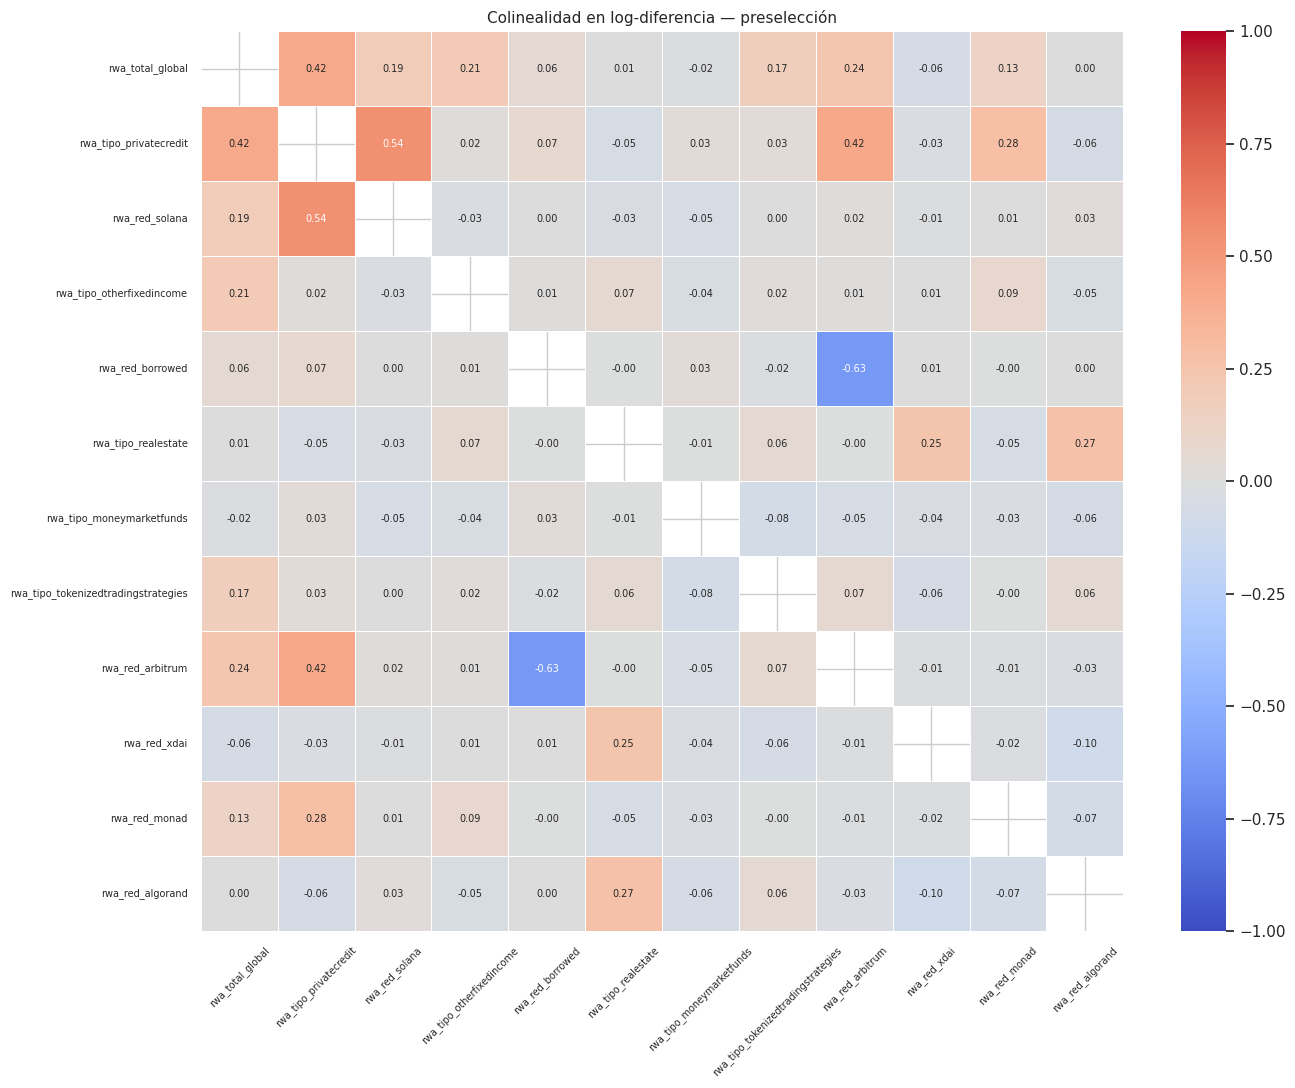


[RWA] === Preselección propuesta (a validar) ===
[RWA] fecha de extracción: 2026-11-21
[RWA] ventana: 2026-01-01 → 2026-08-08
[RWA] umbrales — TVL mín: 100,000,000 USD | colinealidad: |corr| log-dif > 0.85 | cobertura mín: 80%

[RWA] SELECCIONADAS (12):
  - rwa_total_global: representante de su cluster; eje=total:global; TVL=3,218,649,627 USD; historia=2040 días; cobertura ventana=100%
  - rwa_tipo_privatecredit: representante de su cluster; eje=tipo:Private Credit; TVL=1,055,858,470 USD; historia=1957 días; cobertura ventana=100%
  - rwa_red_solana: representante de su cluster; eje=red:Solana; TVL=521,852,779 USD; historia=1641 días; cobertura ventana=100%
  - rwa_tipo_otherfixedincome: representante de su cluster; eje=tipo:Other Fixed Income; TVL=469,493,345 USD; historia=1677 días; cobertura ventana=100%
  - rwa_red_borrowed: representante de su cluster; eje=red:borrowed; TVL=370,956,682 USD; historia=1641 días; cobertura ventana=100%
  - rwa_tipo_realestate: representante de su cl

In [ ]:
"""# Job 2 - Inventario y preselección de series RWA"""

print("# Job 2 - Inventario y preselección de series RWA")

# 1. Configuración
DEBUG: bool = True
SAVE_DATA: bool = True

# Límite de protocolos a descargar (None = todos los RWA).
# Solo para pruebas rápidas; en la corrida real dejar None.
LIMITE_PROTOCOLOS: int | None = None

# 2. Imports

import datetime
import os
import time
import warnings
from typing import Any

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

# CAMBIO H2-3 (Job 1.b): ver nota en Job 0 (mismo patrón).
# Lectura: dataset base validado (carpeta 'expansion')
BASE_DIR_XP: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
ARCHIVO_DIARIAS_XP: str = os.path.join(
    BASE_DIR_XP, "data", "processed", "series_diarias.csv"
)

# Escritura: reportes de la expansión
BASE_DIR_EXP: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_REPORTES: str = os.path.join(
    BASE_DIR_EXP, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_inventario_rwa"
)

TIMEOUT: int = 40
PAUSA: float = 1.0
VENTANA_INICIO: str = "2026-01-01"
HOY: str = datetime.date.today().isoformat()
FECHA_EXTRACCION: str = HOY

# CAMBIO I1-2 (Job 1.b): reintentos de get_json. No se agrega
# guardado de JSON crudo ni protocolos_sin_serie.csv en esta
# fase — ver nota de alcance en el cierre de F1 (colisión de
# nombre de archivo con Job 2, que escribe el mismo reporte).
MAX_REINTENTOS: int = 3

# --- Endpoints (validados en 00d) ---
LLAMA_BASE: str = "https://api.llama.fi"
LLAMA_PROTOCOLS: str = f"{LLAMA_BASE}/protocols"
LLAMA_PROTOCOL: str = f"{LLAMA_BASE}/protocol"
CATEGORIA_RWA: str = "RWA"

# ── Umbrales de decisión (ajustables y documentados) ─────────
# TVL mínimo para que una candidata sea considerada: por debajo
# de esto la serie es ruido estadístico, no señal.
UMBRAL_TVL_MIN: float = 100e6          # 100 M USD

# |corr| en log-dif por encima del cual dos candidatas se
# consideran redundantes (mismo cluster, una representante).
UMBRAL_COLINEAL: float = 0.85

# Cobertura mínima de la ventana 2026 para entrar al análisis
# de colinealidad (fracción de días de la grilla con dato).
COBERTURA_MIN: float = 0.80

# Tamaño objetivo de la preselección.
PRESEL_MIN: int = 8
PRESEL_MAX: int = 12

# Observaciones mínimas para que una correlación sea creíble.
N_MIN_CORR: int = 30

# Nivel protocolo×red: cuántos protocolos mayores se detallan.
N_PROTOCOLOS_DETALLE: int = 20

# Chains "sintéticas" de DeFiLlama a excluir del eje red: las
# claves de chainTvls que contienen "-" son agregados derivados
# (borrowed, staking, pool2), no redes.
MARCA_AGREGADO: str = "-"

# Nombre de la serie de contexto (total global).
COL_TOTAL: str = "rwa_total_global"

sns.set_theme(style="whitegrid", palette="muted")

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def congelar_snapshot(rutas: list[str], job: str) -> None:
    """
    Copia CSV ya guardados a DIR_SNAPSHOT y registra en
    manifest.json: archivo, filas, columnas, fechas mín/máx y
    SHA-256. Si el archivo ya estaba congelado con otro hash, se
    reemplaza y se avisa con [DEBUG][ALERTA].

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV escritos en esta corrida.
        job: Job productor (ej. "Job 1").
    """
    os.makedirs(DIR_SNAPSHOT, exist_ok=True)
    _manifest = leer_manifest()
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            print(
                f"[DEBUG][ALERTA] snapshot: no existe {_ruta}, "
                "no se congela"
            )
            continue
        try:
            _df = pd.read_csv(_ruta)
        except (pd.errors.EmptyDataError, ValueError, OSError) as e:
            print(f"[DEBUG][ALERTA] snapshot: no se pudo leer {_ruta}: {e}")
            _df = pd.DataFrame()
        _fecha_min: str | None = None
        _fecha_max: str | None = None
        if "fecha" in _df.columns:
            _fechas = pd.to_datetime(_df["fecha"], errors="coerce").dropna()
            if not _fechas.empty:
                _fecha_min = _fechas.min().date().isoformat()
                _fecha_max = _fechas.max().date().isoformat()
        _sha = sha256_archivo(_ruta)
        _previo = _manifest["archivos"].get(_nombre, {}).get("sha256")
        if _previo and _previo != _sha:
            print(
                f"[DEBUG][ALERTA] snapshot: {_nombre} reemplaza la "
                f"versión congelada ({_previo[:12]}... → {_sha[:12]}...)"
            )
        shutil.copy2(_ruta, os.path.join(DIR_SNAPSHOT, _nombre))
        _manifest["archivos"][_nombre] = {
            "job": job,
            "ruta_relativa": os.path.relpath(_ruta, BASE_DIR_SNAPSHOT),
            "filas": int(len(_df)),
            "columnas": [str(c) for c in _df.columns],
            "fecha_min": _fecha_min,
            "fecha_max": _fecha_max,
            "sha256": _sha,
            "congelado": datetime.datetime.now().isoformat(
                timespec="seconds"
            ),
        }
        print(
            f"[DEBUG] snapshot: congelado {_nombre} | {len(_df)} filas | "
            f"{_fecha_min} → {_fecha_max} | sha256 {_sha[:12]}..."
        )
    _tmp = ARCHIVO_MANIFEST + ".tmp"
    with open(_tmp, "w", encoding="utf-8") as _f:
        json.dump(_manifest, _f, indent=2, ensure_ascii=False)
    os.replace(_tmp, ARCHIVO_MANIFEST)


def restaurar_desde_snapshot(
    job: str, obligatorios: list[str]
) -> list[str]:
    """
    Modo snapshot: copia desde DIR_SNAPSHOT a su ruta original
    todos los CSV que el manifest atribuye a `job`, verificando
    antes el SHA-256. Aborta nombrando el archivo si falta en el
    manifest o en la carpeta, o si el hash no coincide.

    CAMBIO B1-1 (Bloque 1).

    Args:
        job: Job productor (ej. "Job 1").
        obligatorios: Rutas que deben estar sí o sí en el snapshot.

    Returns:
        Rutas restauradas.
    """
    _entradas = {
        _n: _e for _n, _e in leer_manifest()["archivos"].items()
        if _e.get("job") == job
    }
    for _ruta in obligatorios:
        if os.path.basename(_ruta) not in _entradas:
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: {os.path.basename(_ruta)} no "
                f"figura en {ARCHIVO_MANIFEST}. Correr el {job} con "
                "TESIS_MODO_DATOS=descarga para congelarlo."
            )
    if not _entradas:
        raise FileNotFoundError(
            f"[DEBUG][ERROR] {job}: ningún archivo del {job} en "
            f"{ARCHIVO_MANIFEST}."
        )
    _restaurados: list[str] = []
    for _nombre, _entrada in sorted(_entradas.items()):
        _origen = os.path.join(DIR_SNAPSHOT, _nombre)
        if not os.path.isfile(_origen):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta {_origen} en el snapshot."
            )
        _sha = sha256_archivo(_origen)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_nombre} no "
                f"coincide con el manifest ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...)."
            )
        _destino = os.path.join(BASE_DIR_SNAPSHOT, _entrada["ruta_relativa"])
        os.makedirs(os.path.dirname(_destino), exist_ok=True)
        shutil.copy2(_origen, _destino)
        _restaurados.append(_destino)
        print(
            f"[DEBUG] snapshot: restaurado {_nombre} → {_destino} "
            f"(sha256 {_sha[:12]}... OK)"
        )
    return _restaurados


"""# 4. Funciones"""


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> Any:
    """
    GET HTTP con reintentos y manejo explícito de errores.

    CAMBIO I1-2 (Job 1.b): antes devolvía None en silencio ante
    cualquier falla. Ahora reintenta hasta MAX_REINTENTOS veces
    con espera creciente y registra con [DEBUG] el estado HTTP
    (o tipo de error) de cada intento.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima por intento.

    Returns:
        JSON parseado, o None si los MAX_REINTENTOS intentos
        fallan.
    """
    # CAMBIO B1-2 (Bloque 1): en modo snapshot no hay red.
    if MODO_DATOS == "snapshot":
        raise RuntimeError(
            "[DEBUG][ERROR] MODO_DATOS=snapshot: llamada de red "
            f"bloqueada ({url[:55]})."
        )
    _error: str = "sin intentos"
    for _intento in range(1, MAX_REINTENTOS + 1):
        try:
            r = requests.get(url, params=params, timeout=timeout)
            if r.status_code == 200:
                try:
                    return r.json()
                except ValueError as e:
                    _error = f"JSON inválido: {e}"
                    if DEBUG:
                        print(
                            f"[DEBUG] intento {_intento}/"
                            f"{MAX_REINTENTOS} — {_error}: "
                            f"{url[:60]}"
                        )
            else:
                _error = f"HTTP {r.status_code}"
                if DEBUG:
                    print(
                        f"[DEBUG] intento {_intento}/"
                        f"{MAX_REINTENTOS} — {_error}: "
                        f"{url[:60]}"
                    )
        except requests.Timeout:
            _error = "timeout"
            if DEBUG:
                print(
                    f"[DEBUG] intento {_intento}/"
                    f"{MAX_REINTENTOS} — timeout: {url[:60]}"
                )
        except requests.RequestException as e:
            _error = f"request error: {type(e).__name__}"  # CAMBIO B1-2: sin URL/clave
            if DEBUG:
                print(
                    f"[DEBUG] intento {_intento}/"
                    f"{MAX_REINTENTOS} — {_error}: {url[:60]}"
                )
        if _intento < MAX_REINTENTOS:
            time.sleep(PAUSA * _intento)
    if DEBUG:
        print(
            f"[DEBUG][ALERTA] get_json agotó "
            f"{MAX_REINTENTOS} intentos ({_error}): {url[:60]}"
        )
    return None


def _a_fecha(valor: Any) -> str | None:
    """
    Convierte un epoch (segundos o ms) a fecha ISO UTC.

    Args:
        valor: Epoch numérico o cadena numérica.

    Returns:
        Fecha ISO (YYYY-MM-DD) o None si no se pudo interpretar.
    """
    try:
        segundos = float(valor)
    except (TypeError, ValueError):
        return None
    if segundos > 1e11:
        segundos = segundos / 1000.0
    try:
        return datetime.datetime.fromtimestamp(
            segundos, tz=datetime.timezone.utc
        ).date().isoformat()
    except (OverflowError, OSError, ValueError):
        return None


def _slug_col(texto: str) -> str:
    """
    Normaliza un nombre de chain o tag a sufijo de columna.

    Args:
        texto: Nombre original (ej. "Treasury Bills").

    Returns:
        Sufijo en snake_case alfanumérico (ej. "treasurybills").
    """
    limpio = "".join(
        c.lower() if c.isalnum() else " " for c in texto
    )
    return "".join(limpio.split())


def listar_protocolos_rwa() -> pd.DataFrame:
    """
    Lista los protocolos de categoría RWA en DeFiLlama.

    Returns:
        DataFrame con slug, name, tags, chains, n_chains y tvl,
        ordenado por TVL descendente. Vacío si el endpoint falla.
    """
    if DEBUG:
        print(
            f"[DEBUG] /protocols → categoría '{CATEGORIA_RWA}'"
        )
    data = get_json(LLAMA_PROTOCOLS)
    if not isinstance(data, list) or not data:
        return pd.DataFrame()
    filas: list[dict[str, Any]] = []
    vistos: set[str] = set()
    for proto in data:
        if not isinstance(proto, dict):
            continue
        if proto.get("category") != CATEGORIA_RWA:
            continue
        slug = str(proto.get("slug") or "")
        if not slug or slug in vistos:
            continue                  # dedupe defensivo
        vistos.add(slug)
        chains = [str(c) for c in (proto.get("chains") or [])]
        filas.append({
            "slug": slug,
            "name": str(proto.get("name") or slug),
            "tags": [str(t) for t in (proto.get("tags") or [])],
            "chains": chains,
            "n_chains": len(chains),
            "tvl_actual": float(proto.get("tvl") or 0.0),
        })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values("tvl_actual", ascending=False)
        df = df.reset_index(drop=True)
    return df


def descargar_series_protocolo(
    slug: str,
) -> dict[str, pd.Series]:
    """
    Descarga la serie histórica de TVL de un protocolo,
    desglosada por chain.

    Toma chainTvls[chain]["tvl"] (lista de {date,
    totalLiquidityUSD}) y excluye las claves derivadas. Si un
    día trae más de una observación, queda la última.

    Args:
        slug: Slug del protocolo en DeFiLlama.

    Returns:
        Dict chain → pd.Series (DatetimeIndex, float64).
    """
    data = get_json(f"{LLAMA_PROTOCOL}/{slug}")
    if not isinstance(data, dict):
        return {}
    chain_tvls = data.get("chainTvls")
    if not isinstance(chain_tvls, dict):
        return {}
    series: dict[str, pd.Series] = {}
    for chain, contenido in chain_tvls.items():
        nombre_chain = str(chain)
        if MARCA_AGREGADO in nombre_chain:
            continue
        if not isinstance(contenido, dict):
            continue
        observaciones = contenido.get("tvl")
        if not isinstance(observaciones, list):
            continue
        por_fecha: dict[str, float] = {}
        for obs in observaciones:
            if not isinstance(obs, dict):
                continue
            fecha = _a_fecha(obs.get("date"))
            valor = obs.get("totalLiquidityUSD")
            if fecha is None or valor is None:
                continue
            try:
                por_fecha[fecha] = float(valor)
            except (TypeError, ValueError):
                continue
        if not por_fecha:
            continue
        serie = pd.Series(por_fecha, dtype="float64")
        serie.index = pd.to_datetime(serie.index)
        series[nombre_chain] = serie.sort_index()
    return series


def _densificar(serie: pd.Series) -> pd.Series:
    """
    Lleva una serie a diaria continua dentro de SU rango
    observado, propagando con ffill. No extrapola.

    Args:
        serie: Serie con DatetimeIndex ordenado.

    Returns:
        Serie diaria entre su primera y última observación.
    """
    if serie.empty:
        return serie
    grilla = pd.date_range(
        start=serie.index.min(), end=serie.index.max(), freq="D"
    )
    return serie.reindex(grilla).ffill()


def agregar_series(componentes: list[pd.Series]) -> pd.Series:
    """
    Suma varias series de TVL en una serie agregada diaria.

    Cada componente se densifica dentro de su propio rango
    (ffill) y aporta 0 fuera de él: un protocolo que todavía no
    existía no tiene valor tokenizado. El agregado arranca el
    primer día con dato de algún componente; antes no existe
    (no se hace back-fill).

    Args:
        componentes: Series de TVL a sumar.

    Returns:
        Serie agregada diaria (float64). Vacía si no hay datos.
    """
    validos = [s for s in componentes if not s.empty]
    if not validos:
        return pd.Series(dtype="float64")
    inicio = min(s.index.min() for s in validos)
    fin = max(s.index.max() for s in validos)
    grilla = pd.date_range(start=inicio, end=fin, freq="D")
    total = pd.Series(0.0, index=grilla, dtype="float64")
    for serie in validos:
        densa = _densificar(serie).reindex(grilla).fillna(0.0)
        total = total.add(densa, fill_value=0.0)
    total.index.name = "fecha"
    return total.astype("float64")


def construir_candidatas(
    series_protocolos: dict[str, dict[str, pd.Series]],
    tags_por_slug: dict[str, list[str]],
) -> tuple[dict[str, pd.Series], pd.DataFrame]:
    """
    Construye TODAS las series agregadas candidatas: por red,
    por tipo de activo y total global.

    Args:
        series_protocolos: slug → {chain → serie de TVL}.
        tags_por_slug: slug → lista de tags (tipo de activo).

    Returns:
        (series, meta):
          series: nombre_columna → serie agregada.
          meta  : DataFrame con dimension, categoria y
                  n_protocolos de cada candidata.
    """
    series: dict[str, pd.Series] = {}
    meta: list[dict[str, Any]] = []

    # --- Eje RED: todas las chains con presencia RWA ---
    chains = sorted({
        chain
        for por_chain in series_protocolos.values()
        for chain in por_chain
    })
    for chain in chains:
        componentes = [
            por_chain[chain]
            for por_chain in series_protocolos.values()
            if chain in por_chain
        ]
        agregada = agregar_series(componentes)
        if agregada.empty:
            continue
        col = f"rwa_red_{_slug_col(chain)}"
        series[col] = agregada
        meta.append({
            "serie": col,
            "dimension": "red",
            "categoria": chain,
            "n_protocolos": len(componentes),
        })

    # --- Eje TIPO: todos los tags declarados ---
    tags = sorted({
        t
        for slug in series_protocolos
        for t in tags_por_slug.get(slug, [])
    })
    for tag in tags:
        componentes = [
            serie
            for slug, por_chain in series_protocolos.items()
            if tag in tags_por_slug.get(slug, [])
            for serie in por_chain.values()
        ]
        n_proto = len([
            slug for slug in series_protocolos
            if tag in tags_por_slug.get(slug, [])
        ])
        agregada = agregar_series(componentes)
        if agregada.empty:
            continue
        col = f"rwa_tipo_{_slug_col(tag)}"
        series[col] = agregada
        meta.append({
            "serie": col,
            "dimension": "tipo",
            "categoria": tag,
            "n_protocolos": n_proto,
        })

    # --- TOTAL global (contexto/control) ---
    componentes_total = [
        serie
        for por_chain in series_protocolos.values()
        for serie in por_chain.values()
    ]
    agregada_total = agregar_series(componentes_total)
    if not agregada_total.empty:
        series[COL_TOTAL] = agregada_total
        meta.append({
            "serie": COL_TOTAL,
            "dimension": "total",
            "categoria": "global",
            "n_protocolos": len(series_protocolos),
        })
    return series, pd.DataFrame(meta)


def construir_grilla(inicio: str, fin: str) -> pd.DatetimeIndex:
    """
    Grilla diaria continua (calendario, UTC).

    Args:
        inicio: Fecha ISO de inicio.
        fin: Fecha ISO de fin.

    Returns:
        DatetimeIndex con freq="D" y name="fecha".
    """
    return pd.date_range(
        start=inicio, end=fin, freq="D", name="fecha"
    )


def alinear_a_ventana(
    serie: pd.Series,
    grilla: pd.DatetimeIndex,
) -> pd.Series:
    """
    Alinea una serie a la grilla de la ventana con ffill.

    Sin interpolación y sin back-fill: si la serie nace después
    del inicio de la ventana, esos días quedan NaN.

    Args:
        serie: Serie de historia completa.
        grilla: Grilla diaria destino.

    Returns:
        Serie sobre la grilla (float64).
    """
    if serie.empty:
        return pd.Series(dtype="float64", index=grilla)
    inicio_ext = min(serie.index.min(), grilla.min())
    grilla_ext = pd.date_range(
        start=inicio_ext, end=grilla.max(), freq="D"
    )
    alineada = serie.reindex(grilla_ext).ffill().reindex(grilla)
    alineada.index.name = "fecha"
    return alineada.astype("float64")


def atributos_candidata(
    col: str,
    serie_full: pd.Series,
    serie_ventana: pd.Series,
    grilla: pd.DatetimeIndex,
) -> dict[str, Any]:
    """
    Calcula los atributos de inventario de una candidata.

    Args:
        col: Nombre de la serie.
        serie_full: Historia completa.
        serie_ventana: Serie alineada a la ventana.
        grilla: Grilla de la ventana.

    Returns:
        Dict con TVL actual, historia, cobertura y fechas.
    """
    con_dato = serie_ventana.dropna()
    cobertura = (
        len(con_dato) / len(grilla) if len(grilla) else 0.0
    )
    return {
        "serie": col,
        "tvl_actual": (
            float(serie_full.iloc[-1])
            if not serie_full.empty else 0.0
        ),
        "tvl_max": (
            float(serie_full.max())
            if not serie_full.empty else 0.0
        ),
        "min_fecha": (
            serie_full.index.min().date().isoformat()
            if not serie_full.empty else "s/d"
        ),
        "max_fecha": (
            serie_full.index.max().date().isoformat()
            if not serie_full.empty else "s/d"
        ),
        "n_dias_historia": int(len(serie_full)),
        "n_dias_ventana": int(len(con_dato)),
        "cobertura_ventana": round(float(cobertura), 4),
        "inicia_en_ventana": bool(
            not serie_full.empty
            and serie_full.index.min() > grilla.min()
        ),
        "fecha_extraccion": FECHA_EXTRACCION,
    }


def log_diferencias(df: pd.DataFrame) -> pd.DataFrame:
    """
    Log-diferencia de las columnas estrictamente positivas.

    Las columnas con ceros o negativos se omiten: no se fuerza
    el logaritmo ni se desplaza la serie (sería inventar dato).

    Args:
        df: Dataset de niveles.

    Returns:
        DataFrame de log-diferencias.
    """
    datos: dict[str, pd.Series] = {}
    for col in df.columns:
        s = df[col].dropna()
        if s.empty or not bool((s > 0).all()):
            if DEBUG:
                print(f"[DEBUG] {col}: no positiva — sin log_dif")
            continue
        datos[col] = np.log(df[col]).diff()
    return pd.DataFrame(datos, index=df.index)


def pares_colineales(
    corr: pd.DataFrame,
    umbral: float,
) -> pd.DataFrame:
    """
    Lista los pares de series con |corr| por encima del umbral.

    Args:
        corr: Matriz de correlación.
        umbral: Umbral de |corr|.

    Returns:
        DataFrame con serie_a, serie_b y corr, de mayor a menor.
    """
    filas: list[dict[str, Any]] = []
    cols = list(corr.columns)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            valor = corr.loc[a, b]
            if pd.isna(valor):
                continue
            if abs(float(valor)) > umbral:
                filas.append({
                    "serie_a": a,
                    "serie_b": b,
                    "corr": round(float(valor), 4),
                })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.reindex(
            df["corr"].abs().sort_values(ascending=False).index
        ).reset_index(drop=True)
    return df


def clusters_colinealidad(
    corr: pd.DataFrame,
    umbral: float,
) -> dict[str, int]:
    """
    Agrupa series en clusters de redundancia.

    Dos series quedan en el mismo cluster si |corr| > umbral;
    la relación se propaga transitivamente (union-find), de modo
    que un grupo redundante queda representado por un único id.

    Args:
        corr: Matriz de correlación en log-diferencia.
        umbral: Umbral de |corr|.

    Returns:
        Dict serie → id de cluster (int).
    """
    cols = list(corr.columns)
    padre: dict[str, str] = {c: c for c in cols}

    def buscar(x: str) -> str:
        while padre[x] != x:
            padre[x] = padre[padre[x]]
            x = padre[x]
        return x

    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            valor = corr.loc[a, b]
            if pd.isna(valor) or abs(float(valor)) <= umbral:
                continue
            ra, rb = buscar(a), buscar(b)
            if ra != rb:
                padre[ra] = rb

    raices = sorted({buscar(c) for c in cols})
    id_por_raiz = {r: i for i, r in enumerate(raices)}
    return {c: id_por_raiz[buscar(c)] for c in cols}


def elegir_representante(
    candidatas: pd.DataFrame,
) -> str:
    """
    Elige la representante de un cluster.

    Criterio: mayor TVL actual; a igualdad de TVL, mayor
    historia (más días de serie).

    Args:
        candidatas: Filas del inventario de un mismo cluster.

    Returns:
        Nombre de la serie representante.
    """
    ordenadas = candidatas.sort_values(
        ["tvl_actual", "n_dias_historia"], ascending=False
    )
    return str(ordenadas.iloc[0]["serie"])


def preseleccionar(
    inventario: pd.DataFrame,
    clusters: dict[str, int],
    presel_min: int = PRESEL_MIN,
    presel_max: int = PRESEL_MAX,
) -> pd.DataFrame:
    """
    Propone el subconjunto diverso y no redundante.

    Algoritmo:
      1. De cada cluster de colinealidad se conserva UNA
         representante (mayor TVL, desempate por historia); las
         demás quedan marcadas REDUNDANTE con su representante.
      2. Entre las representantes se alterna la selección entre
         el eje TIPO y el eje RED, tomando en cada turno la de
         mayor TVL disponible. Así el subconjunto cubre
         dinámicas distintas (refugio soberano, oro, crédito
         privado, equity) y varias redes, en vez de llenarse con
         las mayores de un solo eje.
      3. El total global entra primero como serie de contexto,
         salvo que haya quedado en el mismo cluster que una
         componente: en ese caso el paso 1 ya lo resolvió y no
         se duplica el anidamiento.
      4. El corte es presel_max; si hay menos representantes que
         presel_min se reporta el faltante.

    Args:
        inventario: Inventario filtrado (pasa tamaño+cobertura).
        clusters: Serie → id de cluster.
        presel_min: Tamaño mínimo deseado.
        presel_max: Tamaño máximo del subconjunto.

    Returns:
        DataFrame con estado ("SELECCIONADA"/"REDUNDANTE"/
        "NO_SELECCIONADA"), representada_por y justificacion.
    """
    base = inventario.copy()
    base["cluster"] = base["serie"].map(clusters)
    base["estado"] = "NO_SELECCIONADA"
    base["representada_por"] = ""
    base["justificacion"] = ""

    # 1. Representante por cluster
    representantes: list[str] = []
    for cid, grupo in base.groupby("cluster", dropna=False):
        rep = elegir_representante(grupo)
        representantes.append(rep)
        for _, fila in grupo.iterrows():
            nombre = str(fila["serie"])
            if nombre == rep:
                continue
            idx = index_serie(base, nombre)
            base.loc[idx, "estado"] = "REDUNDANTE"
            base.loc[idx, "representada_por"] = rep
            base.loc[idx, "justificacion"] = (
                f"|corr| log-dif > {UMBRAL_COLINEAL} con el "
                f"cluster {cid}; representada por {rep}"
            )

    # 2. Selección alternando ejes, por TVL descendente
    reps = base[base["serie"].isin(representantes)]
    pool_total = [
        s for s in reps.loc[
            reps["dimension"] == "total", "serie"
        ]
    ]
    def _pool(dim: str) -> list[str]:
        sub = reps[reps["dimension"] == dim]
        sub = sub.sort_values("tvl_actual", ascending=False)
        return [str(s) for s in sub["serie"]]

    pool_tipo = _pool("tipo")
    pool_red = _pool("red")
    seleccion: list[str] = []
    seleccion.extend(pool_total[:1])
    turno_tipo = True
    while len(seleccion) < presel_max and (pool_tipo or pool_red):
        pool = pool_tipo if turno_tipo else pool_red
        if not pool:
            pool = pool_red if turno_tipo else pool_tipo
        if not pool:
            break
        seleccion.append(pool.pop(0))
        turno_tipo = not turno_tipo

    # 3. Marcado y justificación
    for nombre in seleccion:
        idx = index_serie(base, nombre)
        fila = base.loc[idx]
        base.loc[idx, "estado"] = "SELECCIONADA"
        base.loc[idx, "justificacion"] = (
            f"representante de su cluster; eje="
            f"{fila['dimension']}:{fila['categoria']}; "
            f"TVL={fila['tvl_actual']:,.0f} USD; "
            f"historia={fila['n_dias_historia']} días; "
            f"cobertura ventana="
            f"{fila['cobertura_ventana'] * 100:.0f}%"
        )
    no_sel = (
        (base["estado"] == "NO_SELECCIONADA")
        & (base["serie"].isin(representantes))
    )
    base.loc[no_sel, "justificacion"] = (
        f"no redundante, pero fuera del corte de {presel_max} "
        "por menor TVL en su eje"
    )
    return base


def index_serie(df: pd.DataFrame, nombre: str) -> Any:
    """
    Devuelve el índice de la fila de una serie del inventario.

    Args:
        df: Inventario.
        nombre: Nombre de la serie.

    Returns:
        Índice de pandas de esa fila.
    """
    return df.index[df["serie"] == nombre][0]


def heatmap_colinealidad(
    corr: pd.DataFrame,
    titulo: str,
    fname: str,
) -> None:
    """
    Heatmap de la matriz de colinealidad.

    Args:
        corr: Matriz de correlación.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.
    """
    if corr.empty:
        if DEBUG:
            print(f"[DEBUG] {titulo}: matriz vacía")
        return
    lado = max(6.0, 0.9 * len(corr.columns) + 3.0)
    fig, ax = plt.subplots(figsize=(lado, lado * 0.8))
    mask = np.zeros_like(corr.values, dtype=bool)
    np.fill_diagonal(mask, True)
    sns.heatmap(
        corr, mask=mask, annot=True, fmt=".2f",
        cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax,
        annot_kws={"size": 7}, linewidths=0.4,
    )
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    plt.tight_layout()
    if SAVE_DATA:
        os.makedirs(DIR_FIGURAS, exist_ok=True)
        ruta = os.path.join(DIR_FIGURAS, fname)
        plt.savefig(ruta, dpi=150, bbox_inches="tight")
        if DEBUG:
            print(f"[DEBUG] figura: {ruta}")
    plt.show()
    plt.close()


"""# 5. Proceso"""

# CAMBIO B1-2 (Bloque 1): en modo snapshot no se consulta
# DeFiLlama: se restauran los reportes congelados y el Job termina.
if MODO_DATOS == "snapshot":
    restaurar_desde_snapshot("Job 2", [])
    print("[DEBUG] Job 2: MODO_DATOS=snapshot — 0 llamadas de red. Fin.")
    raise SystemExit(0)

# ── 5.0 Ventana de análisis (del dataset base de 'expansion') ─────
if DEBUG:
    print("\n[DEBUG] === 5.0 Ventana de análisis ===")

# CAMBIO E2E-02-01: validar la entrada antes de las llamadas a DeFiLlama.
# Si falta o está dañada, abortar con el nombre del archivo y el Job
# productor. No sustituir silenciosamente su ventana por VENTANA_INICIO-HOY.
if not os.path.isfile(ARCHIVO_DIARIAS_XP):
    raise FileNotFoundError(
        f"[DEBUG][ERROR] Job 2: falta {ARCHIVO_DIARIAS_XP}. "
        "Ejecutar Job 1 y verificar series_diarias.csv antes del Job 2."
    )
try:
    df_base = pd.read_csv(
        ARCHIVO_DIARIAS_XP,
        parse_dates=["fecha"],
        index_col="fecha",
    )
except (OSError, ValueError, TypeError, pd.errors.ParserError) as _exc:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 2: no se puede leer {ARCHIVO_DIARIAS_XP}. "
        f"Debe ser un CSV válido con columna 'fecha'. Detalle: {_exc}"
    ) from _exc

if df_base.empty:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 2: {ARCHIVO_DIARIAS_XP} está vacío. "
        "Revisar la salida del Job 1; no se consultó DeFiLlama."
    )
if (
    not isinstance(df_base.index, pd.DatetimeIndex)
    or df_base.index.isna().any()
):
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 2: columna 'fecha' inválida en "
        f"{ARCHIVO_DIARIAS_XP}. Se requieren fechas parseables "
        "sin valores nulos; no se consultó DeFiLlama."
    )

ventana_inicio: str = df_base.index.min().date().isoformat()
ventana_fin: str = df_base.index.max().date().isoformat()
if DEBUG:
    print(
        f"[DEBUG] dataset base: {df_base.shape} — "
        f"{ventana_inicio} → {ventana_fin}"
    )

grilla: pd.DatetimeIndex = construir_grilla(
    ventana_inicio, ventana_fin
)

# ── 5.1 PARTE 1: inventario de protocolos ────────────────────
if DEBUG:
    print("\n[DEBUG] === 5.1 PARTE 1: catálogo de protocolos ===")

protocolos: pd.DataFrame = listar_protocolos_rwa()
if protocolos.empty:
    raise RuntimeError(
        "No se pudo listar protocolos RWA en DeFiLlama: "
        "sin catálogo no hay inventario posible."
    )
if LIMITE_PROTOCOLOS is not None:
    protocolos = protocolos.head(LIMITE_PROTOCOLOS)

if DEBUG:
    print(f"[DEBUG] protocolos RWA: {len(protocolos)}")
    print(
        f"[DEBUG] TVL catálogo: "
        f"{protocolos['tvl_actual'].sum():,.0f} USD"
    )

series_protocolos: dict[str, dict[str, pd.Series]] = {}
for _, _fila in protocolos.iterrows():
    _slug = str(_fila["slug"])
    try:
        _series = descargar_series_protocolo(_slug)
    except Exception as _e:
        _series = {}
        if DEBUG:
            print(f"[DEBUG] error en {_slug}: {_e}")
    if _series:
        series_protocolos[_slug] = _series
    time.sleep(PAUSA)

if DEBUG:
    print(
        f"[DEBUG] protocolos con serie: "
        f"{len(series_protocolos)}/{len(protocolos)}"
    )

# Nivel PROTOCOLO: atributos de historia
filas_proto: list[dict[str, Any]] = []
for _, _fila in protocolos.iterrows():
    _slug = str(_fila["slug"])
    _por_chain = series_protocolos.get(_slug, {})
    _todas = list(_por_chain.values())
    _inicio = (
        min(s.index.min() for s in _todas) if _todas else None
    )
    _fin = (
        max(s.index.max() for s in _todas) if _todas else None
    )
    filas_proto.append({
        "slug": _slug,
        "name": str(_fila["name"]),
        "tags": ",".join(_fila["tags"]),
        "chains": ",".join(_fila["chains"]),
        "n_chains": int(_fila["n_chains"]),
        "tvl_actual": float(_fila["tvl_actual"]),
        "con_serie": bool(_todas),
        "min_fecha": (
            _inicio.date().isoformat() if _inicio else "s/d"
        ),
        "max_fecha": (
            _fin.date().isoformat() if _fin else "s/d"
        ),
        "n_dias_historia": (
            int((_fin - _inicio).days) + 1
            if _inicio is not None and _fin is not None else 0
        ),
        "fecha_extraccion": FECHA_EXTRACCION,
    })
df_protocolos: pd.DataFrame = pd.DataFrame(filas_proto)

# Nivel PROTOCOLO × RED (solo los mayores, para no inflar)
filas_pr: list[dict[str, Any]] = []
for _, _fila in df_protocolos.head(N_PROTOCOLOS_DETALLE).iterrows():
    _slug = str(_fila["slug"])
    for _chain, _serie in series_protocolos.get(_slug, {}).items():
        filas_pr.append({
            "slug": _slug,
            "name": _fila["name"],
            "chain": _chain,
            "tags": _fila["tags"],
            "tvl_ultimo": float(_serie.iloc[-1]),
            "min_fecha": _serie.index.min().date().isoformat(),
            "max_fecha": _serie.index.max().date().isoformat(),
            "n_obs": int(len(_serie)),
            "fecha_extraccion": FECHA_EXTRACCION,
        })
df_proto_red: pd.DataFrame = pd.DataFrame(filas_pr)

if DEBUG:
    print(f"[DEBUG] nivel protocolo: {df_protocolos.shape}")
    print(f"[DEBUG] nivel protocolo×red: {df_proto_red.shape}")

# ── 5.2 Series agregadas candidatas ──────────────────────────
if DEBUG:
    print("\n[DEBUG] === 5.2 Series candidatas ===")

tags_por_slug: dict[str, list[str]] = {
    str(f["slug"]): list(f["tags"])
    for _, f in protocolos.iterrows()
}

series_candidatas, df_meta = construir_candidatas(
    series_protocolos, tags_por_slug
)

if DEBUG:
    print(
        f"[DEBUG] candidatas construidas: "
        f"{len(series_candidatas)} "
        f"(red={int((df_meta['dimension'] == 'red').sum())}, "
        f"tipo={int((df_meta['dimension'] == 'tipo').sum())}, "
        f"total=1)"
    )

# Alineación a la ventana y atributos de inventario
series_ventana: dict[str, pd.Series] = {}
filas_inv: list[dict[str, Any]] = []
for _col, _serie in series_candidatas.items():
    _alineada = alinear_a_ventana(_serie, grilla)
    series_ventana[_col] = _alineada
    filas_inv.append(
        atributos_candidata(_col, _serie, _alineada, grilla)
    )

inventario: pd.DataFrame = pd.DataFrame(filas_inv)
inventario = inventario.merge(df_meta, on="serie", how="left")
inventario = inventario.sort_values(
    "tvl_actual", ascending=False
).reset_index(drop=True)

df_niveles: pd.DataFrame = pd.DataFrame(
    series_ventana, index=grilla
)

if DEBUG:
    _inv_cols = [
        "serie", "dimension", "categoria", "tvl_actual",
        "n_dias_historia", "cobertura_ventana", "min_fecha",
    ]
    print(inventario[_inv_cols].head(30).to_string(index=False))

# ── 5.3 PARTE 2: filtro por tamaño y cobertura ───────────────
if DEBUG:
    print("\n[DEBUG] === 5.3 PARTE 2: filtro tamaño/cobertura ===")

inventario["pasa_tamano"] = (
    inventario["tvl_actual"] >= UMBRAL_TVL_MIN
)
inventario["pasa_cobertura"] = (
    inventario["cobertura_ventana"] >= COBERTURA_MIN
)
inventario["motivo_descarte"] = ""
inventario.loc[~inventario["pasa_tamano"], "motivo_descarte"] = (
    f"TVL < {UMBRAL_TVL_MIN:,.0f} USD (ruido estadístico)"
)
_sin_cob = (
    inventario["pasa_tamano"] & ~inventario["pasa_cobertura"]
)
inventario.loc[_sin_cob, "motivo_descarte"] = (
    f"cobertura de ventana < {COBERTURA_MIN:.0%} "
    "(serie nace dentro de la ventana; no se rellena)"
)

candidatas_ok: list[str] = inventario.loc[
    inventario["pasa_tamano"] & inventario["pasa_cobertura"],
    "serie",
].tolist()

if DEBUG:
    print(
        f"[DEBUG] pasan tamaño: "
        f"{int(inventario['pasa_tamano'].sum())}/"
        f"{len(inventario)}"
    )
    print(
        f"[DEBUG] pasan tamaño+cobertura: {len(candidatas_ok)}"
    )
    _desc = inventario[inventario["motivo_descarte"] != ""]
    if not _desc.empty:
        print("[DEBUG] descartadas (primeras 20):")
        print(
            _desc[["serie", "tvl_actual", "motivo_descarte"]]
            .head(20).to_string(index=False)
        )

# ── 5.4 PARTE 3: colinealidad en log-diferencia ──────────────
if DEBUG:
    print("\n[DEBUG] === 5.4 PARTE 3: colinealidad log-dif ===")

corr_logdif: pd.DataFrame = pd.DataFrame()
df_pares: pd.DataFrame = pd.DataFrame()
clusters: dict[str, int] = {}
try:
    df_ld = log_diferencias(df_niveles[candidatas_ok])
    # Solo series con suficientes observaciones para correlar
    _validas = [
        c for c in df_ld.columns
        if df_ld[c].notna().sum() >= N_MIN_CORR
        and float(df_ld[c].std()) > 0
    ]
    _descartadas_n = [
        c for c in df_ld.columns if c not in _validas
    ]
    if DEBUG and _descartadas_n:
        print(
            f"[DEBUG] sin n suficiente para correlacionar "
            f"(<{N_MIN_CORR}): {_descartadas_n}"
        )
    corr_logdif = df_ld[_validas].corr(method="pearson")
    df_pares = pares_colineales(corr_logdif, UMBRAL_COLINEAL)
    clusters = clusters_colinealidad(
        corr_logdif, UMBRAL_COLINEAL
    )
    if DEBUG:
        print(
            f"[DEBUG] matriz log-dif: {corr_logdif.shape} | "
            f"pares |corr|>{UMBRAL_COLINEAL}: {len(df_pares)}"
        )
        if not df_pares.empty:
            print(df_pares.head(20).to_string(index=False))
        _n_clusters = len(set(clusters.values()))
        print(
            f"[DEBUG] clusters de redundancia: {_n_clusters} "
            f"sobre {len(clusters)} series"
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] PARTE 3 falló: {_exc}")

# ── 5.5 PARTE 4: preselección por diversidad ─────────────────
if DEBUG:
    print("\n[DEBUG] === 5.5 PARTE 4: preselección ===")

preseleccion: pd.DataFrame = pd.DataFrame()
try:
    inv_ok = inventario[
        inventario["serie"].isin(clusters.keys())
    ].reset_index(drop=True)
    preseleccion = preseleccionar(
        inv_ok, clusters, PRESEL_MIN, PRESEL_MAX
    )
    _sel = preseleccion[
        preseleccion["estado"] == "SELECCIONADA"
    ]["serie"].tolist()
    if len(_sel) < PRESEL_MIN and DEBUG:
        print(
            f"[DEBUG] AVISO: solo {len(_sel)} series no "
            f"redundantes disponibles (mínimo deseado "
            f"{PRESEL_MIN}): revisar UMBRAL_TVL_MIN o "
            "UMBRAL_COLINEAL"
        )
    if _sel and not corr_logdif.empty:
        heatmap_colinealidad(
            corr_logdif.loc[_sel, _sel],
            "Colinealidad en log-diferencia — preselección",
            "colinealidad_preseleccion_logdif.png",
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] PARTE 4 falló: {_exc}")

# ── 5.6 Reporte de decisión ──────────────────────────────────
print("\n[RWA] === Preselección propuesta (a validar) ===")
print(f"[RWA] fecha de extracción: {FECHA_EXTRACCION}")
print(f"[RWA] ventana: {ventana_inicio} → {ventana_fin}")
print(
    f"[RWA] umbrales — TVL mín: {UMBRAL_TVL_MIN:,.0f} USD | "
    f"colinealidad: |corr| log-dif > {UMBRAL_COLINEAL} | "
    f"cobertura mín: {COBERTURA_MIN:.0%}"
)
if preseleccion.empty:
    print("[RWA] sin preselección disponible")
else:
    _sel = preseleccion[preseleccion["estado"] == "SELECCIONADA"]
    _red = preseleccion[preseleccion["estado"] == "REDUNDANTE"]
    _no = preseleccion[
        preseleccion["estado"] == "NO_SELECCIONADA"
    ]
    print(f"\n[RWA] SELECCIONADAS ({len(_sel)}):")
    for _, _f in _sel.iterrows():
        print(f"  - {_f['serie']}: {_f['justificacion']}")
    print(f"\n[RWA] REDUNDANTES ({len(_red)}):")
    for _, _f in _red.iterrows():
        print(
            f"  - {_f['serie']} → representada por "
            f"{_f['representada_por']}"
        )
    if not _no.empty:
        print(f"\n[RWA] FUERA DEL CORTE ({len(_no)}):")
        for _, _f in _no.iterrows():
            print(f"  - {_f['serie']}: {_f['justificacion']}")
    _tipos = sorted(set(_sel.loc[
        _sel["dimension"] == "tipo", "categoria"
    ]))
    _redes = sorted(set(_sel.loc[
        _sel["dimension"] == "red", "categoria"
    ]))
    print(
        f"\n[RWA] diversidad — tipos: {_tipos or 'ninguno'}"
    )
    print(f"[RWA] diversidad — redes: {_redes or 'ninguna'}")
print(
    "\n[RWA] NOTA: los tags de tipo NO son exclusivos; las "
    "series por tipo no particionan el total global. El "
    "anidamiento se controla por correlación empírica en "
    "log-dif, no por aritmética de sumas."
)
print(
    "[RWA] Esta es una PROPUESTA: la decisión del set final "
    "queda a criterio del autor sobre este reporte."
)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)

    _guardados: list[str] = []

    if not inventario.empty:
        _ruta = os.path.join(DIR_REPORTES, "inventario_rwa.csv")
        inventario.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_protocolos.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "inventario_rwa_protocolos.csv"
        )
        df_protocolos.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_proto_red.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "inventario_rwa_proto_red.csv"
        )
        df_proto_red.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not corr_logdif.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "colinealidad_rwa_logdif.csv"
        )
        corr_logdif.to_csv(_ruta)
        _guardados.append(_ruta)

    if not df_pares.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "colinealidad_rwa_pares.csv"
        )
        df_pares.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not preseleccion.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "preseleccion_rwa.csv"
        )
        preseleccion.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if DEBUG:
        for _g in _guardados:
            print(f"[DEBUG] guardado: {_g}")
    congelar_snapshot(_guardados, "Job 2")  # CAMBIO B1-2
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")



# Job 3 - Adquisición de series RWA (tokenización por red y tipo)

In [ ]:
"""# Job 3 - Adquisición de series RWA (tokenización por red y tipo)"""

print("Job 3 - Adquisición de series RWA (tokenización por red y tipo)")

# 1. Configuración
DEBUG: bool = True
SAVE_DATA: bool = True

# Une las series RWA al dataset diario existente (left join).
UNIR_A_DATASET: bool = True
# Límite de protocolos a descargar (None = todos los RWA).
# Solo para pruebas rápidas; en la corrida real dejar None.
LIMITE_PROTOCOLOS: int | None = None

# 2. Imports

import datetime
import hashlib  # CAMBIO H3-3 (Job 2): huellas SHA-256
import json  # CAMBIO I1-3 (Job 2): guardado de JSON crudo
import os
import time
from typing import Any

import pandas as pd
import requests

from google.colab import drive
drive.mount('/content/drive')

# 3. Paths y Constantes

# CAMBIO H2-4 (Job 2): ver nota en Job 0 (mismo patrón).
# Lectura: dataset base validado (carpeta 'expansion')
BASE_DIR_XP: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED_XP: str = os.path.join(
    BASE_DIR_XP, "data", "processed"
)

# Escritura: todo lo nuevo va a la expansión
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(BASE_DIR, "outputs", "reportes")

ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED_XP, "series_diarias.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED_XP, "series_largas.csv"
)
ARCHIVO_RWA: str = os.path.join(
    DIR_PROCESSED, "series_rwa.csv"
)
ARCHIVO_RWA_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_rwa_largas.csv"
)
ARCHIVO_DIARIAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_COBERTURA: str = os.path.join(
    DIR_REPORTES, "cobertura_rwa.csv"
)
# CAMBIO H3-3 (Job 2): huellas SHA-256 de los CSV guardados.
ARCHIVO_HUELLAS: str = os.path.join(
    DIR_REPORTES, "huellas_datos.csv"
)
# CAMBIO I1-3 (Job 2): diagnóstico de la descarga por protocolo.
ARCHIVO_PROTOCOLOS_SIN_SERIE: str = os.path.join(
    DIR_REPORTES, "protocolos_sin_serie.csv"
)
ARCHIVO_RESUMEN_CATALOGO: str = os.path.join(
    DIR_REPORTES, "resumen_catalogo_rwa.csv"
)

TIMEOUT: int = 40
PAUSA: float = 1.0            # segundos entre requests
VENTANA_INICIO: str = "2026-01-01"
HOY: str = datetime.date.today().isoformat()
FECHA_EXTRACCION: str = HOY

# CAMBIO I1-3 (Job 2): reintentos de get_json y carpeta donde se
# congela cada respuesta cruda de DeFiLlama antes de procesarla.
MAX_REINTENTOS: int = 3
DIR_RAW: str = os.path.join(
    BASE_DIR, "data", "raw", FECHA_EXTRACCION
)
# Proporción mínima de protocolos RWA con serie descargable.
# Si la corrida queda por debajo, no se corta: se deja un aviso
# fuerte en [DEBUG] y en ARCHIVO_RESUMEN_CATALOGO.
MIN_PROP_PROTOCOLOS_CON_SERIE: float = 0.90

# --- Endpoints base (validados en 00d) ---
LLAMA_BASE: str = "https://api.llama.fi"
LLAMA_PROTOCOLS: str = f"{LLAMA_BASE}/protocols"
LLAMA_PROTOCOL: str = f"{LLAMA_BASE}/protocol"       # /{slug}

CATEGORIA_RWA: str = "RWA"

# GRUPO 1 — columna → chains DeFiLlama que la componen.
# "XRPL EVM" es la sidechain EVM de XRPL: se suma a Ripple por
# ser la misma red del modelo. Quitarla de la lista si se quiere
# el XRPL nativo puro.
REDES_OBJETIVO: dict[str, list[str]] = {
    "rwa_red_stellar": ["Stellar"],
    "rwa_red_ripple": ["Ripple", "XRPL EVM"],
    "rwa_red_algorand": ["Algorand"],
}

# GRUPO 2 — columna → tags DeFiLlama (nombres exactos del API).
TIPOS_OBJETIVO: dict[str, list[str]] = {
    "rwa_tipo_treasurybills": ["Treasury Bills"],
    "rwa_tipo_commodities": ["Commodities"],
    "rwa_tipo_privatecredit": ["Private Credit"],
    "rwa_tipo_stocksetfs": ["Stocks & ETFs"],
}

# GRUPO 3 — contexto.
COL_TOTAL: str = "rwa_total_global"

# Orden final de columnas del dataset RWA.
COLUMNAS_RWA: list[str] = (
    list(REDES_OBJETIVO) + list(TIPOS_OBJETIVO) + [COL_TOTAL]
)

# Sufijos de chainTvls que son agregados derivados, no chains
# reales (borrowed, staking, pool2, ...). Se excluyen.
MARCA_AGREGADO: str = "-"

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def congelar_snapshot(rutas: list[str], job: str) -> None:
    """
    Copia CSV ya guardados a DIR_SNAPSHOT y registra en
    manifest.json: archivo, filas, columnas, fechas mín/máx y
    SHA-256. Si el archivo ya estaba congelado con otro hash, se
    reemplaza y se avisa con [DEBUG][ALERTA].

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV escritos en esta corrida.
        job: Job productor (ej. "Job 1").
    """
    os.makedirs(DIR_SNAPSHOT, exist_ok=True)
    _manifest = leer_manifest()
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            print(
                f"[DEBUG][ALERTA] snapshot: no existe {_ruta}, "
                "no se congela"
            )
            continue
        try:
            _df = pd.read_csv(_ruta)
        except (pd.errors.EmptyDataError, ValueError, OSError) as e:
            print(f"[DEBUG][ALERTA] snapshot: no se pudo leer {_ruta}: {e}")
            _df = pd.DataFrame()
        _fecha_min: str | None = None
        _fecha_max: str | None = None
        if "fecha" in _df.columns:
            _fechas = pd.to_datetime(_df["fecha"], errors="coerce").dropna()
            if not _fechas.empty:
                _fecha_min = _fechas.min().date().isoformat()
                _fecha_max = _fechas.max().date().isoformat()
        _sha = sha256_archivo(_ruta)
        _previo = _manifest["archivos"].get(_nombre, {}).get("sha256")
        if _previo and _previo != _sha:
            print(
                f"[DEBUG][ALERTA] snapshot: {_nombre} reemplaza la "
                f"versión congelada ({_previo[:12]}... → {_sha[:12]}...)"
            )
        shutil.copy2(_ruta, os.path.join(DIR_SNAPSHOT, _nombre))
        _manifest["archivos"][_nombre] = {
            "job": job,
            "ruta_relativa": os.path.relpath(_ruta, BASE_DIR_SNAPSHOT),
            "filas": int(len(_df)),
            "columnas": [str(c) for c in _df.columns],
            "fecha_min": _fecha_min,
            "fecha_max": _fecha_max,
            "sha256": _sha,
            "congelado": datetime.datetime.now().isoformat(
                timespec="seconds"
            ),
        }
        print(
            f"[DEBUG] snapshot: congelado {_nombre} | {len(_df)} filas | "
            f"{_fecha_min} → {_fecha_max} | sha256 {_sha[:12]}..."
        )
    _tmp = ARCHIVO_MANIFEST + ".tmp"
    with open(_tmp, "w", encoding="utf-8") as _f:
        json.dump(_manifest, _f, indent=2, ensure_ascii=False)
    os.replace(_tmp, ARCHIVO_MANIFEST)


def restaurar_desde_snapshot(
    job: str, obligatorios: list[str]
) -> list[str]:
    """
    Modo snapshot: copia desde DIR_SNAPSHOT a su ruta original
    todos los CSV que el manifest atribuye a `job`, verificando
    antes el SHA-256. Aborta nombrando el archivo si falta en el
    manifest o en la carpeta, o si el hash no coincide.

    CAMBIO B1-1 (Bloque 1).

    Args:
        job: Job productor (ej. "Job 1").
        obligatorios: Rutas que deben estar sí o sí en el snapshot.

    Returns:
        Rutas restauradas.
    """
    _entradas = {
        _n: _e for _n, _e in leer_manifest()["archivos"].items()
        if _e.get("job") == job
    }
    for _ruta in obligatorios:
        if os.path.basename(_ruta) not in _entradas:
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: {os.path.basename(_ruta)} no "
                f"figura en {ARCHIVO_MANIFEST}. Correr el {job} con "
                "TESIS_MODO_DATOS=descarga para congelarlo."
            )
    if not _entradas:
        raise FileNotFoundError(
            f"[DEBUG][ERROR] {job}: ningún archivo del {job} en "
            f"{ARCHIVO_MANIFEST}."
        )
    _restaurados: list[str] = []
    for _nombre, _entrada in sorted(_entradas.items()):
        _origen = os.path.join(DIR_SNAPSHOT, _nombre)
        if not os.path.isfile(_origen):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta {_origen} en el snapshot."
            )
        _sha = sha256_archivo(_origen)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_nombre} no "
                f"coincide con el manifest ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...)."
            )
        _destino = os.path.join(BASE_DIR_SNAPSHOT, _entrada["ruta_relativa"])
        os.makedirs(os.path.dirname(_destino), exist_ok=True)
        shutil.copy2(_origen, _destino)
        _restaurados.append(_destino)
        print(
            f"[DEBUG] snapshot: restaurado {_nombre} → {_destino} "
            f"(sha256 {_sha[:12]}... OK)"
        )
    return _restaurados


"""# 4. Funciones"""


def registrar_huella(ruta: str, archivo_huellas: str) -> None:
    """
    Calcula el SHA-256 de un CSV ya guardado y agrega una fila
    al archivo de huellas de datos (no sobrescribe filas previas).

    CAMBIO H3-3 (Job 2).

    Args:
        ruta: Ruta del CSV ya guardado en disco.
        archivo_huellas: Ruta del CSV de huellas (se crea si no
            existe; si existe, se agrega una fila al final).
    """
    if not os.path.exists(ruta):
        if DEBUG:
            print(f"[DEBUG] huella: no existe {ruta}, se omite")
        return
    try:
        with open(ruta, "rb") as _f:
            _sha256 = hashlib.sha256(_f.read()).hexdigest()
    except OSError as e:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] huella: error leyendo "
                f"{ruta}: {e}"
            )
        return
    _fila = pd.DataFrame([{
        "archivo": os.path.basename(ruta),
        "sha256": _sha256,
        "fecha": datetime.date.today().isoformat(),
    }])
    _existe = os.path.exists(archivo_huellas)
    _fila.to_csv(
        archivo_huellas, mode="a", header=not _existe,
        index=False,
    )
    if DEBUG:
        print(
            f"[DEBUG] huella registrada: {ruta} → "
            f"{_sha256[:12]}..."
        )


def _guardar_json_crudo(data: Any, ruta: str) -> None:
    """
    Guarda una respuesta JSON cruda en disco antes de procesarla.

    CAMBIO I1-3 (Job 2).

    Args:
        data: Objeto ya parseado (dict/list) a serializar.
        ruta: Ruta completa del archivo .json de destino.
    """
    try:
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        with open(ruta, "w", encoding="utf-8") as _f:
            json.dump(data, _f)
    except OSError as e:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] no se pudo guardar crudo "
                f"{ruta}: {e}"
            )


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
    ruta_crudo: str | None = None,
) -> Any:
    """
    GET HTTP con reintentos y manejo explícito de errores.

    CAMBIO I1-3 (Job 2): antes devolvía None en silencio ante
    cualquier falla. Ahora reintenta hasta MAX_REINTENTOS veces
    con espera creciente, registra con [DEBUG] el estado HTTP (o
    tipo de error) de cada intento, y si se indica ruta_crudo
    guarda la respuesta cruda en disco antes de devolverla.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima por intento.
        ruta_crudo: Si se indica, ruta donde guardar el JSON
            crudo (antes de cualquier procesamiento posterior).

    Returns:
        Objeto Python (dict/list) parseado del JSON, o None si
        los MAX_REINTENTOS intentos fallan.
    """
    # CAMBIO B1-2 (Bloque 1): en modo snapshot no hay red.
    if MODO_DATOS == "snapshot":
        raise RuntimeError(
            "[DEBUG][ERROR] MODO_DATOS=snapshot: llamada de red "
            f"bloqueada ({url[:55]})."
        )
    _error: str = "sin intentos"
    for _intento in range(1, MAX_REINTENTOS + 1):
        try:
            r = requests.get(url, params=params, timeout=timeout)
            if r.status_code == 200:
                try:
                    data = r.json()
                except ValueError as e:
                    _error = f"JSON inválido: {e}"
                    if DEBUG:
                        print(
                            f"[DEBUG] intento {_intento}/"
                            f"{MAX_REINTENTOS} — {_error}: "
                            f"{url[:60]}"
                        )
                else:
                    if ruta_crudo:
                        _guardar_json_crudo(data, ruta_crudo)
                    return data
            else:
                _error = f"HTTP {r.status_code}"
                if DEBUG:
                    print(
                        f"[DEBUG] intento {_intento}/"
                        f"{MAX_REINTENTOS} — {_error}: "
                        f"{url[:60]}"
                    )
        except requests.Timeout:
            _error = "timeout"
            if DEBUG:
                print(
                    f"[DEBUG] intento {_intento}/"
                    f"{MAX_REINTENTOS} — timeout: {url[:60]}"
                )
        except requests.RequestException as e:
            _error = f"request error: {type(e).__name__}"  # CAMBIO B1-2: sin URL/clave
            if DEBUG:
                print(
                    f"[DEBUG] intento {_intento}/"
                    f"{MAX_REINTENTOS} — {_error}: {url[:60]}"
                )
        if _intento < MAX_REINTENTOS:
            time.sleep(PAUSA * _intento)
    if DEBUG:
        print(
            f"[DEBUG][ALERTA] get_json agotó "
            f"{MAX_REINTENTOS} intentos ({_error}): {url[:60]}"
        )
    return None


def _a_fecha(valor: Any) -> str | None:
    """
    Convierte un timestamp epoch (segundos o ms) a fecha ISO UTC.

    Args:
        valor: Epoch numérico o cadena numérica.

    Returns:
        Fecha ISO (YYYY-MM-DD) o None si no se pudo interpretar.
    """
    try:
        segundos = float(valor)
    except (TypeError, ValueError):
        return None
    if segundos > 1e11:           # epoch en milisegundos
        segundos = segundos / 1000.0
    try:
        return datetime.datetime.fromtimestamp(
            segundos, tz=datetime.timezone.utc
        ).date().isoformat()
    except (OverflowError, OSError, ValueError):
        return None


def listar_protocolos_rwa() -> pd.DataFrame:
    """
    Lista los protocolos de categoría RWA en DeFiLlama.

    Returns:
        DataFrame con columnas slug, name, tags (list[str]),
        chains (list[str]) y tvl, ordenado por TVL descendente.
        Vacío si el endpoint falla.
    """
    if DEBUG:
        print(
            f"[DEBUG] /protocols → categoría '{CATEGORIA_RWA}'"
        )
    # CAMBIO I1-3 (Job 2): se congela la respuesta cruda
    # antes de procesarla.
    _ruta_crudo = os.path.join(DIR_RAW, "protocols.json")
    data = get_json(LLAMA_PROTOCOLS, ruta_crudo=_ruta_crudo)
    if not isinstance(data, list) or not data:
        if DEBUG:
            print("[DEBUG] /protocols: respuesta vacía o inválida")
        return pd.DataFrame()
    filas: list[dict[str, Any]] = []
    vistos: set[str] = set()
    for proto in data:
        if not isinstance(proto, dict):
            continue
        if proto.get("category") != CATEGORIA_RWA:
            continue
        slug = str(proto.get("slug") or "")
        if not slug or slug in vistos:
            continue          # dedupe: no contar dos veces
        vistos.add(slug)
        filas.append({
            "slug": slug,
            "name": str(proto.get("name") or slug),
            "tags": [str(t) for t in (proto.get("tags") or [])],
            "chains": [
                str(c) for c in (proto.get("chains") or [])
            ],
            "tvl": float(proto.get("tvl") or 0.0),
        })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values("tvl", ascending=False)
        df = df.reset_index(drop=True)
    return df


def descargar_series_protocolo(
    slug: str,
) -> tuple[dict[str, pd.Series], str]:
    """
    Descarga la serie histórica de TVL de un protocolo,
    desglosada por chain.

    Toma chainTvls[chain]["tvl"], que es una lista de
    {date, totalLiquidityUSD}. Excluye las claves derivadas
    (las que contienen "-": borrowed, staking, pool2, ...).
    Si un día trae más de una observación, queda la última.

    CAMBIO I1-3 (Job 2): antes devolvía solo el dict de series;
    ahora también el motivo de la ausencia de serie, para poder
    diagnosticar la descarga por protocolo (protocolos_sin_serie.csv).

    Args:
        slug: Slug del protocolo en DeFiLlama.

    Returns:
        (series, motivo): dict chain → pd.Series (vacío si no
        hay datos) y motivo ("" si se obtuvo al menos una serie,
        o una de: "HTTP", "JSON sin chainTvls", "chainTvls sin
        clave 'tvl'", "todas las claves descartadas por contener
        '-'", "sin observaciones utilizables en 'tvl'").
    """
    _ruta_crudo = os.path.join(DIR_RAW, f"protocol_{slug}.json")
    data = get_json(
        f"{LLAMA_PROTOCOL}/{slug}", ruta_crudo=_ruta_crudo
    )
    if not isinstance(data, dict):
        return {}, "HTTP"
    chain_tvls = data.get("chainTvls")
    if not isinstance(chain_tvls, dict):
        return {}, "JSON sin chainTvls"
    series: dict[str, pd.Series] = {}
    _hubo_clave_no_agregada = False
    _hubo_clave_tvl = False
    for chain, contenido in chain_tvls.items():
        nombre_chain = str(chain)
        if MARCA_AGREGADO in nombre_chain:
            continue
        _hubo_clave_no_agregada = True
        if not isinstance(contenido, dict):
            continue
        observaciones = contenido.get("tvl")
        if not isinstance(observaciones, list):
            continue
        _hubo_clave_tvl = True
        por_fecha: dict[str, float] = {}
        for obs in observaciones:
            if not isinstance(obs, dict):
                continue
            fecha = _a_fecha(obs.get("date"))
            valor = obs.get("totalLiquidityUSD")
            if fecha is None or valor is None:
                continue
            try:
                por_fecha[fecha] = float(valor)
            except (TypeError, ValueError):
                continue
        if not por_fecha:
            continue
        serie = pd.Series(por_fecha, dtype=float)
        serie.index = pd.to_datetime(serie.index)
        series[nombre_chain] = serie.sort_index()
    if series:
        return series, ""
    if not _hubo_clave_no_agregada:
        return {}, "todas las claves descartadas por contener '-'"
    if not _hubo_clave_tvl:
        return {}, "chainTvls sin clave 'tvl'"
    return {}, "sin observaciones utilizables en 'tvl'"


def _densificar(serie: pd.Series) -> pd.Series:
    """
    Lleva una serie a frecuencia diaria continua dentro de su
    propio rango observado, propagando con ffill.

    NO extrapola fuera del rango observado: antes de la primera
    y después de la última observación la serie no existe (NaN).

    Args:
        serie: Serie con DatetimeIndex ordenado.

    Returns:
        Serie diaria continua entre su min y su max observados.
    """
    if serie.empty:
        return serie
    grilla_propia = pd.date_range(
        start=serie.index.min(), end=serie.index.max(), freq="D"
    )
    return serie.reindex(grilla_propia).ffill()


def agregar_series(
    componentes: list[pd.Series],
) -> tuple[pd.Series, pd.DatetimeIndex]:
    """
    Suma varias series de TVL (una por protocolo/chain) en una
    serie agregada diaria.

    Criterio de agregación:
      - Cada componente se densifica a diaria dentro de SU rango
        observado (ffill), sin extrapolar.
      - Fuera de ese rango el componente aporta 0: un protocolo
        que todavía no existía (o que dejó de reportar) no tiene
        valor tokenizado. Esto NO es relleno inventado.
      - El agregado empieza el primer día en que ALGÚN componente
        tiene observación; antes de esa fecha no existe (se deja
        fuera de la serie, sin back-fill).

    Args:
        componentes: Series de TVL a sumar.

    Returns:
        (serie_agregada, fechas_reales):
          serie_agregada : suma diaria desde el primer día con
                           datos hasta el último.
          fechas_reales  : fechas con observación DIRECTA de al
                           menos un componente (para la máscara
                           de ffill posterior).
    """
    validos = [s for s in componentes if not s.empty]
    if not validos:
        return pd.Series(dtype=float), pd.DatetimeIndex([])
    inicio = min(s.index.min() for s in validos)
    fin = max(s.index.max() for s in validos)
    grilla = pd.date_range(start=inicio, end=fin, freq="D")
    total = pd.Series(0.0, index=grilla)
    for serie in validos:
        densa = _densificar(serie)
        total = total.add(
            densa.reindex(grilla).fillna(0.0), fill_value=0.0
        )
    fechas_reales = pd.DatetimeIndex(
        sorted({fecha for s in validos for fecha in s.index})
    )
    total.index.name = "fecha"
    return total, fechas_reales


def registrar_serie(
    columna: str,
    componentes: list[pd.Series],
    n_protocolos: int,
    descripcion: str,
    destino_series: dict[str, pd.Series],
    destino_fechas: dict[str, pd.DatetimeIndex],
    destino_detalle: list[dict[str, Any]],
) -> None:
    """
    Agrega los componentes de una serie y la registra en los
    contenedores del proceso.

    Si la agregación no devuelve datos, la serie NO se registra
    (no se rellena con ceros) y queda anotada como fallida en el
    detalle.

    Args:
        columna: Nombre de la columna destino.
        componentes: Series de TVL a sumar.
        n_protocolos: Cuántos protocolos aportan a la serie.
        descripcion: Evidencia de cómo se construyó la serie.
        destino_series: Dict columna → serie agregada.
        destino_fechas: Dict columna → fechas con dato directo.
        destino_detalle: Lista de registros de detalle.
    """
    agregada, reales = agregar_series(componentes)
    if agregada.empty:
        if DEBUG:
            # CAMBIO H5-1 (Job 2)
            print(f"[DEBUG][ALERTA] {columna}: SIN DATOS — se omite")
        destino_detalle.append({
            "serie": columna,
            "n_protocolos": n_protocolos,
            "ok": False,
            "descripcion": descripcion,
            "min_fecha_origen": "s/d",
            "max_fecha_origen": "s/d",
            "fecha_extraccion": FECHA_EXTRACCION,
        })
        return
    destino_series[columna] = agregada
    destino_fechas[columna] = reales
    destino_detalle.append({
        "serie": columna,
        "n_protocolos": n_protocolos,
        "ok": True,
        "descripcion": descripcion,
        "min_fecha_origen": (
            agregada.index.min().date().isoformat()
        ),
        "max_fecha_origen": (
            agregada.index.max().date().isoformat()
        ),
        "fecha_extraccion": FECHA_EXTRACCION,
    })
    if DEBUG:
        print(
            f"[DEBUG] {columna}: {n_protocolos} protocolos, "
            f"{len(agregada)} días "
            f"({agregada.index.min().date()} → "
            f"{agregada.index.max().date()}), "
            f"último = {agregada.iloc[-1]:,.0f} USD"
        )


def construir_grilla(inicio: str, fin: str) -> pd.DatetimeIndex:
    """
    Construye un índice de fechas DIARIO continuo (calendario).

    Incluye fines de semana. Convención UTC.

    Args:
        inicio: Fecha de inicio ISO.
        fin: Fecha de fin ISO.

    Returns:
        DatetimeIndex con freq="D" y name="fecha".
    """
    return pd.date_range(
        start=inicio, end=fin, freq="D", name="fecha"
    )


def alinear_serie(
    serie_full: pd.Series,
    fechas_reales: pd.DatetimeIndex,
    grilla: pd.DatetimeIndex,
) -> tuple[pd.Series, pd.Series]:
    """
    Alinea una serie de historia completa a la grilla de la
    ventana de análisis usando ffill documentado.

    NO se interpola y NO se hace back-fill: si la serie empieza
    después del inicio de la ventana, los días previos quedan
    NaN (el activo no existía; rellenarlos sería inventar dato).

    Usa la historia previa a la ventana, si existe, para que el
    ffill funcione desde el primer día de la grilla.

    Args:
        serie_full: Serie con historia completa, DatetimeIndex.
        fechas_reales: Fechas con observación directa de origen.
        grilla: Grilla diaria destino (ventana de análisis).

    Returns:
        (serie_alineada, mascara_ffill):
          serie_alineada : valores sobre la grilla.
          mascara_ffill  : True donde el valor vino de ffill.
    """
    vacia = pd.Series(dtype=float, index=grilla)
    sin_mask = pd.Series(False, index=grilla, dtype=bool)
    if serie_full.empty:
        return vacia, sin_mask

    inicio_ext = min(serie_full.index.min(), grilla.min())
    grilla_ext = pd.date_range(
        start=inicio_ext, end=grilla.max(), freq="D"
    )
    s_ext = serie_full.reindex(grilla_ext).ffill()
    s_ventana = s_ext.reindex(grilla)
    s_ventana.index.name = "fecha"

    # Directo = la fecha de la grilla tiene observación de origen
    directo = pd.Series(
        grilla.isin(fechas_reales), index=grilla, dtype=bool
    )
    mascara_ffill: pd.Series = (~directo) & s_ventana.notna()
    return s_ventana, mascara_ffill


def calcular_cobertura(
    df: pd.DataFrame,
    mascaras: dict[str, pd.Series],
    fecha_extraccion: str,
) -> pd.DataFrame:
    """
    Calcula la cobertura de cada columna del dataset alineado.

    Métricas por columna:
      n_total  : días en la grilla.
      n_real   : observaciones directas (sin ffill).
      n_ffill  : días rellenados por ffill.
      n_nulo   : días sin valor (NaN, típicamente al inicio si
                 la serie nace después de VENTANA_INICIO).
      pct_ffill: porcentaje de días rellenados.

    Args:
        df: Dataset alineado a la grilla diaria.
        mascaras: Dict columna → máscara_ffill booleana.
        fecha_extraccion: Fecha de extracción (ISO).

    Returns:
        DataFrame con una fila por columna.
    """
    filas: list[dict[str, Any]] = []
    for col in df.columns:
        serie = df[col]
        mask = mascaras.get(
            col, pd.Series(False, index=df.index)
        )
        n_total = len(serie)
        n_nulo = int(serie.isna().sum())
        n_real = int((~mask & serie.notna()).sum())
        n_ffill = int(mask.sum())
        pct_ffill = (
            round(n_ffill / n_total * 100, 1)
            if n_total > 0 else 0.0
        )
        con_valor = serie.dropna()
        if len(con_valor) > 0:
            min_f = con_valor.index.min().date().isoformat()
            max_f = con_valor.index.max().date().isoformat()
        else:
            min_f, max_f = "s/d", "s/d"
        filas.append({
            "serie": col,
            "n_total": n_total,
            "n_real": n_real,
            "n_ffill": n_ffill,
            "n_nulo": n_nulo,
            "pct_ffill": pct_ffill,
            "min_fecha": min_f,
            "max_fecha": max_f,
            "fecha_extraccion": fecha_extraccion,
        })
    return pd.DataFrame(filas)


def leer_dataset(ruta: str) -> pd.DataFrame:
    """
    Lee un dataset existente indexado por "fecha".

    Args:
        ruta: Ruta del CSV.

    Returns:
        DataFrame con DatetimeIndex "fecha", o vacío si el
        archivo no existe o no se puede leer.
    """
    if not os.path.exists(ruta):
        if DEBUG:
            print(f"[DEBUG] no existe: {ruta}")
        return pd.DataFrame()
    try:
        df = pd.read_csv(ruta, index_col="fecha")
        df.index = pd.to_datetime(df.index)
        df.index.name = "fecha"
        return df
    except Exception as e:
        if DEBUG:
            print(f"[DEBUG] error leyendo {ruta}: {e}")
        return pd.DataFrame()


def unir_por_fecha(
    df_base: pd.DataFrame,
    df_nuevo: pd.DataFrame,
    como: str = "left",
) -> tuple[pd.DataFrame, list[str]]:
    """
    Une columnas nuevas a un dataset existente por índice fecha,
    sin tocar las columnas ya presentes.

    Las columnas que ya existen en df_base se OMITEN (no se
    sobrescribe el dataset validado) y se devuelven como
    conflictos para su reporte.

    Args:
        df_base: Dataset existente (índice fecha).
        df_nuevo: Columnas nuevas (índice fecha).
        como: Tipo de join ("left" para la grilla del base,
            "outer" para conservar toda la historia).

    Returns:
        (df_unido, columnas_omitidas).
    """
    conflictos = [
        c for c in df_nuevo.columns if c in df_base.columns
    ]
    aportadas = [
        c for c in df_nuevo.columns if c not in conflictos
    ]
    df_unido = df_base.join(df_nuevo[aportadas], how=como)
    df_unido.index.name = "fecha"
    return df_unido, conflictos


"""# 5. Proceso"""

# CAMBIO B1-2 (Bloque 1): en modo snapshot no se consulta
# DeFiLlama: se restauran las series congeladas y el Job termina.
if MODO_DATOS == "snapshot":
    restaurar_desde_snapshot(
        "Job 3", [ARCHIVO_DIARIAS_EXT, ARCHIVO_LARGAS_EXT]
    )
    print("[DEBUG] Job 3: MODO_DATOS=snapshot — 0 llamadas de red. Fin.")
    raise SystemExit(0)

# CAMBIO E2E-03-01: preflight del contrato de archivos del Job 3.
# Estas salidas se escriben en 5.b, ANTES del bloque "6. Save".
os.makedirs(DIR_REPORTES, exist_ok=True)

# El Job 1 produce ambas bases. Validar ANTES de descargar protocolos
# para no gastar llamadas externas ni reutilizar CSV ext de otra corrida.
df_diarias_base: pd.DataFrame = pd.DataFrame()
df_largas_base: pd.DataFrame = pd.DataFrame()
if UNIR_A_DATASET:
    for _ruta_base in (ARCHIVO_DIARIAS, ARCHIVO_LARGAS):
        if not os.path.isfile(_ruta_base):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] Job 3: falta {_ruta_base}. "
                "El Job 1 debe generar ese archivo antes del Job 3."
            )
    df_diarias_base = leer_dataset(ARCHIVO_DIARIAS)
    df_largas_base = leer_dataset(ARCHIVO_LARGAS)
    for _ruta_base, _df_base in (
        (ARCHIVO_DIARIAS, df_diarias_base),
        (ARCHIVO_LARGAS, df_largas_base),
    ):
        if _df_base.empty:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 3: entrada vacia o ilegible: "
                f"{_ruta_base}. Verificar salida del Job 1 "
                "(CSV con columna 'fecha' y datos)."
            )
        if _df_base.index.isna().any():
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 3: fechas nulas o invalidas "
                f"en {_ruta_base}. Revisar el Job 1."
            )

# ── 5.a Catálogo de protocolos RWA ────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.a Catálogo de protocolos RWA ===")
    print(f"[DEBUG] fecha de extracción: {FECHA_EXTRACCION}")

protocolos: pd.DataFrame = listar_protocolos_rwa()

if protocolos.empty:
    raise RuntimeError(
        "No se pudo listar protocolos RWA en DeFiLlama: "
        "sin catálogo no hay adquisición posible."
    )

if LIMITE_PROTOCOLOS is not None:
    protocolos = protocolos.head(LIMITE_PROTOCOLOS)

if DEBUG:
    print(f"[DEBUG] protocolos RWA: {len(protocolos)}")
    print(
        f"[DEBUG] TVL total catálogo: "
        f"{protocolos['tvl'].sum():,.0f} USD"
    )

# CAMBIO I1-3 (Job 2): conteo de protocolos RWA y TVL total del
# catálogo de esta corrida. Se escriben junto con el chequeo de
# umbral de 5.b, en una sola fila de resumen (ver más abajo).
_n_protocolos_rwa: int = len(protocolos)
_tvl_total_catalogo: float = float(protocolos["tvl"].sum())

# ── 5.b Descarga de series por protocolo (una pasada) ─────────────

if DEBUG:
    print("\n[DEBUG] === 5.b Descarga de series por protocolo ===")

# slug → {chain → serie}
series_protocolos: dict[str, dict[str, pd.Series]] = {}
log_descarga: list[dict[str, Any]] = []

for _, _fila in protocolos.iterrows():
    _slug = str(_fila["slug"])
    _nombre = str(_fila["name"])
    try:
        _series, _motivo = descargar_series_protocolo(_slug)
    except Exception as _e:
        _series, _motivo = {}, f"excepción: {_e}"
        if DEBUG:
            print(f"[DEBUG] error en {_slug}: {_e}")
    if _series:
        series_protocolos[_slug] = _series
    log_descarga.append({
        "slug": _slug,
        "name": _nombre,
        "ok": bool(_series),
        "n_chains": len(_series),
        "motivo": _motivo,  # CAMBIO I1-3 (Job 2)
        "tags": ",".join(_fila["tags"]),
        "fecha_extraccion": FECHA_EXTRACCION,
    })
    time.sleep(PAUSA)

df_log: pd.DataFrame = pd.DataFrame(log_descarga)

if DEBUG:
    _n_ok = int(df_log["ok"].sum())
    print(
        f"[DEBUG] protocolos con serie: {_n_ok}/{len(df_log)}"
    )
    _fallidos = df_log.loc[~df_log["ok"], "slug"].tolist()
    if _fallidos:
        print(
            f"[DEBUG] sin serie ({len(_fallidos)}): "
            f"{', '.join(_fallidos[:12])}"
        )

# CAMBIO I1-3 (Job 2): slugs sin serie y su motivo, a CSV.
_df_sin_serie = df_log.loc[
    ~df_log["ok"], ["slug", "name", "motivo", "fecha_extraccion"]
]
_df_sin_serie.to_csv(ARCHIVO_PROTOCOLOS_SIN_SERIE, index=False)
if DEBUG:
    print(f"[DEBUG] guardado: {ARCHIVO_PROTOCOLOS_SIN_SERIE}")

# CAMBIO I1-3 (Job 2): umbral de proporción con serie. No corta
# la ejecución — deja el aviso en [DEBUG][ALERTA] y en el
# resumen.
_prop_con_serie = (
    float(df_log["ok"].mean()) if len(df_log) > 0 else 0.0
)
_alerta_umbral = _prop_con_serie < MIN_PROP_PROTOCOLOS_CON_SERIE
if _alerta_umbral:
    print(
        f"[DEBUG][ALERTA] proporción de protocolos con serie "
        f"({_prop_con_serie:.1%}) por debajo del umbral "
        f"({MIN_PROP_PROTOCOLOS_CON_SERIE:.0%})"
    )

# CAMBIO I1-3 (Job 2): una fila de resumen por corrida, con el
# tamaño/TVL del catálogo y el resultado del chequeo de umbral.
_resumen_catalogo = pd.DataFrame([{
    "fecha_extraccion": FECHA_EXTRACCION,
    "n_protocolos_rwa": _n_protocolos_rwa,
    "tvl_total_catalogo_usd": _tvl_total_catalogo,
    "prop_protocolos_con_serie": _prop_con_serie,
    "umbral_min_prop_con_serie": MIN_PROP_PROTOCOLOS_CON_SERIE,
    "alerta_umbral": _alerta_umbral,
}])
_existe_resumen_catalogo = os.path.exists(ARCHIVO_RESUMEN_CATALOGO)
_resumen_catalogo.to_csv(
    ARCHIVO_RESUMEN_CATALOGO, mode="a",
    header=not _existe_resumen_catalogo, index=False,
)
if DEBUG:
    print(f"[DEBUG] guardado: {ARCHIVO_RESUMEN_CATALOGO}")

# ── 5.c Construcción de las 8 series ──────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.c Construcción de las 8 series ===")

# Mapa slug → tags, para la agregación por tipo de activo
tags_por_slug: dict[str, list[str]] = {
    str(f["slug"]): list(f["tags"])
    for _, f in protocolos.iterrows()
}

series_full: dict[str, pd.Series] = {}
fechas_reales: dict[str, pd.DatetimeIndex] = {}
detalle_series: list[dict[str, Any]] = []


# GRUPO 1 — por red
for _columna, _chains in REDES_OBJETIVO.items():
    try:
        _componentes: list[pd.Series] = []
        _slugs_red: set[str] = set()
        for _slug, _por_chain in series_protocolos.items():
            for _chain in _chains:
                _serie_chain = _por_chain.get(_chain)
                if _serie_chain is not None:
                    _componentes.append(_serie_chain)
                    _slugs_red.add(_slug)
        registrar_serie(
            _columna, _componentes, len(_slugs_red),
            f"suma de chainTvls[{'/'.join(_chains)}] "
            "de los protocolos categoría RWA",
            series_full, fechas_reales, detalle_series,
        )
    except Exception as _e:
        if DEBUG:
            print(f"[DEBUG] error construyendo {_columna}: {_e}")

# GRUPO 2 — por tipo de activo (todas las chains del protocolo)
for _columna, _tags in TIPOS_OBJETIVO.items():
    try:
        _componentes = []
        _slugs_tipo: set[str] = set()
        for _slug, _por_chain in series_protocolos.items():
            _tags_proto = tags_por_slug.get(_slug, [])
            if not any(t in _tags_proto for t in _tags):
                continue
            _slugs_tipo.add(_slug)
            _componentes.extend(_por_chain.values())
        registrar_serie(
            _columna, _componentes, len(_slugs_tipo),
            f"suma de TVL (todas las chains) de protocolos con "
            f"tag {'/'.join(_tags)}",
            series_full, fechas_reales, detalle_series,
        )
    except Exception as _e:
        if DEBUG:
            print(f"[DEBUG] error construyendo {_columna}: {_e}")

# GRUPO 3 — total global
try:
    _componentes = [
        _s for _por_chain in series_protocolos.values()
        for _s in _por_chain.values()
    ]
    registrar_serie(
        COL_TOTAL, _componentes, len(series_protocolos),
        "suma de TVL de todos los protocolos categoría RWA "
        "en todas sus chains",
        series_full, fechas_reales, detalle_series,
    )
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG] error construyendo {COL_TOTAL}: {_e}")

df_detalle: pd.DataFrame = pd.DataFrame(detalle_series)

# ── 5.d Alineación a la grilla diaria de la ventana ───────────────

if DEBUG:
    print("\n[DEBUG] === 5.d Alineación a grilla diaria ===")
    print(f"[DEBUG] ventana: {VENTANA_INICIO} → {HOY}")

grilla: pd.DatetimeIndex = construir_grilla(VENTANA_INICIO, HOY)
mascaras: dict[str, pd.Series] = {}
df_rwa: pd.DataFrame = pd.DataFrame(index=grilla)
df_rwa.index.name = "fecha"

for _columna in COLUMNAS_RWA:
    # CAMBIO H5-1 (Job 2): COLUMNAS_RWA es la lista declarada en
    # un único lugar de las series RWA esperadas (sección 3). Si
    # una de ellas no se puede construir, se marca con
    # [DEBUG][ALERTA] y se sigue sin ella (no se corta la
    # ejecución ni se rellena).
    _serie_full = series_full.get(_columna)
    if _serie_full is None:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {_columna}: sin datos de "
                "origen — columna OMITIDA (no se rellena)"
            )
        continue
    try:
        _alineada, _mask = alinear_serie(
            _serie_full, fechas_reales[_columna], grilla
        )
    except Exception as _e:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] error alineando {_columna}: "
                f"{_e}"
            )
        continue
    if _alineada.notna().sum() == 0:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {_columna}: sin valores "
                "dentro de la ventana — columna OMITIDA"
            )
        continue
    df_rwa[_columna] = _alineada
    mascaras[_columna] = _mask
    if DEBUG:
        _n_nulo = int(_alineada.isna().sum())
        print(
            f"[DEBUG] {_columna}: "
            f"{int((~_mask & _alineada.notna()).sum())} reales, "
            f"{int(_mask.sum())} ffill, {_n_nulo} NaN"
        )
        if _n_nulo > 0:
            _primer_valor = _alineada.dropna().index.min()
            print(
                f"[DEBUG]   ATENCIÓN: la serie nace el "
                f"{_primer_valor.date()}, después de "
                f"{VENTANA_INICIO}. Se dejan {_n_nulo} NaN al "
                "inicio (sin back-fill)."
            )

# ── 5.e Historia completa (series largas) ─────────────────────────

df_rwa_largas: pd.DataFrame = (
    pd.DataFrame(
        {c: series_full[c] for c in COLUMNAS_RWA
         if c in series_full}
    )
    if series_full else pd.DataFrame()
)
if not df_rwa_largas.empty:
    df_rwa_largas.index.name = "fecha"

if DEBUG:
    if df_rwa_largas.empty:
        print("\n[DEBUG] sin historia RWA para series largas")
    else:
        print(
            f"\n[DEBUG] series largas RWA: "
            f"{df_rwa_largas.shape} "
            f"({df_rwa_largas.index.min().date()} → "
            f"{df_rwa_largas.index.max().date()})"
        )

# ── 5.f Reporte de cobertura ──────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.f Cobertura de las series RWA ===")

cobertura: pd.DataFrame = calcular_cobertura(
    df_rwa, mascaras, FECHA_EXTRACCION
)

if DEBUG and not cobertura.empty:
    pd.set_option("display.max_colwidth", 30)
    pd.set_option("display.width", 130)
    _cob_cols = [
        "serie", "n_total", "n_real", "n_ffill", "n_nulo",
        "pct_ffill", "min_fecha", "max_fecha",
    ]
    print(cobertura[_cob_cols].to_string(index=False))

# ── 5.g Unión al dataset existente ────────────────────────────────

df_diarias_ext: pd.DataFrame = pd.DataFrame()
df_largas_ext: pd.DataFrame = pd.DataFrame()

if UNIR_A_DATASET:
    # CAMBIO E2E-03-01: si falta un lado RWA no se crea un CSV
    # incompleto ni se deja que otro Job consuma un ext antiguo.
    if df_rwa.empty or df_rwa_largas.empty:
        _rwa_faltantes = [
            _nombre for _nombre, _df in (
                ("series_rwa.csv", df_rwa),
                ("series_rwa_largas.csv", df_rwa_largas),
            ) if _df.empty
        ]
        raise RuntimeError(
            "[DEBUG][ERROR] Job 3: faltan datos RWA para "
            "generar series_diarias_ext.csv y series_largas_ext.csv: "
            f"{', '.join(_rwa_faltantes)}. "
            "No se reutilizan archivos ext de corridas anteriores."
        )
    if DEBUG:
        print("\n[DEBUG] === 5.g Unión al dataset existente ===")
    # CAMBIO E2E-03-01: base diaria leida y validada en preflight.
    if df_diarias_base.empty:
        if DEBUG:
            print(
                "[DEBUG] series_diarias.csv no disponible: no se "
                "genera series_diarias_ext.csv (no se inventa base)"
            )
    else:
        df_diarias_ext, _conflictos = unir_por_fecha(
            df_diarias_base, df_rwa, como="left"
        )
        if DEBUG:
            print(
                f"[DEBUG] base {df_diarias_base.shape} + RWA "
                f"{df_rwa.shape} → ext {df_diarias_ext.shape}"
            )
            if _conflictos:
                print(
                    "[DEBUG] columnas ya existentes NO "
                    f"sobrescritas: {_conflictos}"
                )
            _fuera = int(
                (~df_rwa.index.isin(df_diarias_base.index)).sum()
            )
            if _fuera:
                print(
                    f"[DEBUG] {_fuera} días de la grilla RWA "
                    "quedan fuera del índice del dataset base "
                    "(left join)"
                )

    # CAMBIO E2E-03-01: base larga leida y validada en preflight.
    if not df_largas_base.empty and not df_rwa_largas.empty:
        df_largas_ext, _conf_largas = unir_por_fecha(
            df_largas_base, df_rwa_largas, como="outer"
        )
        if DEBUG:
            print(
                f"[DEBUG] largas {df_largas_base.shape} + RWA "
                f"{df_rwa_largas.shape} → ext "
                f"{df_largas_ext.shape}"
            )
            if _conf_largas:
                print(
                    "[DEBUG] columnas largas NO sobrescritas: "
                    f"{_conf_largas}"
                )

    # CAMBIO E2E-03-01: validar la produccion de AMBOS ext.
    if df_diarias_ext.empty or df_largas_ext.empty:
        raise RuntimeError(
            "[DEBUG][ERROR] Job 3: una o ambas uniones quedaron "
            "vacias; no se pueden generar los CSV ext. "
            f"diarias={df_diarias_ext.shape}, "
            f"largas={df_largas_ext.shape}."
        )

# ── 5.h Resumen ───────────────────────────────────────────────────

print("\n[RWA] === Resumen de adquisición ===")
print(f"[RWA] fecha de extracción: {FECHA_EXTRACCION}")
print(f"[RWA] ventana: {VENTANA_INICIO} → {HOY}")
print(
    f"[RWA] series solicitadas: {len(COLUMNAS_RWA)} | "
    f"construidas: {len(df_rwa.columns)}"
)
_faltantes = [c for c in COLUMNAS_RWA if c not in df_rwa.columns]
if _faltantes:
    # CAMBIO H5-1 (Job 2): resumen final de series esperadas que
    # no se pudieron construir.
    print(
        f"[DEBUG][ALERTA] RWA OMITIDAS (sin dato, no "
        f"rellenadas): {_faltantes}"
    )
if not df_detalle.empty:
    for _, _fila_det in df_detalle.iterrows():
        print(
            f"[RWA] {_fila_det['serie']}: "
            f"{_fila_det['n_protocolos']} protocolos — "
            f"{_fila_det['descripcion']}"
        )
print(
    "[RWA] NOTA: adopción incipiente (RWA en Stellar ~ago-2025, "
    "en Ripple ~jun-2025): dinámica dominada por crecimiento "
    "estructural, no por respuesta a estrés."
)
print(
    "[RWA] NOTA: los tags de tipo no son exclusivos; las series "
    "por tipo no suman rwa_total_global."
)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)

    if not df_rwa.empty:
        df_rwa.to_csv(ARCHIVO_RWA)
        if DEBUG:
            print(f"\n[DEBUG] guardado: {ARCHIVO_RWA}")
        registrar_huella(ARCHIVO_RWA, ARCHIVO_HUELLAS)  # CAMBIO H3-3
        congelar_snapshot([ARCHIVO_RWA], "Job 3")  # CAMBIO B1-2
    elif DEBUG:
        print("\n[DEBUG] df_rwa vacío, no se guarda")

    if not df_rwa_largas.empty:
        df_rwa_largas.to_csv(ARCHIVO_RWA_LARGAS)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_RWA_LARGAS}")
        registrar_huella(
            ARCHIVO_RWA_LARGAS, ARCHIVO_HUELLAS
        )  # CAMBIO H3-3
        congelar_snapshot([ARCHIVO_RWA_LARGAS], "Job 3")  # CAMBIO B1-2

    if not df_diarias_ext.empty:
        df_diarias_ext.to_csv(ARCHIVO_DIARIAS_EXT)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_DIARIAS_EXT}")
        congelar_snapshot([ARCHIVO_DIARIAS_EXT], "Job 3")  # CAMBIO B1-2

    if not df_largas_ext.empty:
        df_largas_ext.to_csv(ARCHIVO_LARGAS_EXT)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_LARGAS_EXT}")
        congelar_snapshot([ARCHIVO_LARGAS_EXT], "Job 3")  # CAMBIO B1-2

    if not cobertura.empty:
        cobertura.to_csv(ARCHIVO_COBERTURA, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_COBERTURA}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")



Job 3 - Adquisición de series RWA (tokenización por red y tipo)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot

[DEBUG] === 5.a Catálogo de protocolos RWA ===
[DEBUG] fecha de extracción: 2026-11-21
[DEBUG] /protocols → categoría 'RWA'
[DEBUG] protocolos RWA: 190
[DEBUG] TVL total catálogo: 2,834,047,223 USD

[DEBUG] === 5.b Descarga de series por protocolo ===
[DEBUG] protocolos con serie: 116/190
[DEBUG] sin serie (74): tinlake, klimadao, toucan-protocol, ondo-yield-assets, aktionariat, matrixdock-stbt, openeden-tbill, backedfi, digift, circle-usyc, anzen-v1, dinari
[DEBUG] guardado: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/protocolos_sin_serie.csv
[DEBUG][ALERTA] proporción de protocolos con serie (61.1%) por debajo del umbral (90%)
[DEBUG] guardado: /content/drive/MyDrive/Tesis/expansion/outputs

In [1]:
"""# Job 3m - Series RWA desde el maestro append-only (sin DeFiLlama)"""

# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# CAMBIO J3M-1: parámetros fijados antes de mirar resultados.
# CORTE: fecha máxima del maestro que se usa (ISO). None = última
# fecha disponible en el maestro.
CORTE: str | None = None
# "incluir" | "excluir": "excluir" deja fuera de TODO agregado los
# protocolos con estado sin_serie_en_ultima_ejecucion.
PROTOCOLOS_INACTIVOS: str = "incluir"
# CAMBIO J3M-6: SOLO PARA VERIFICACIÓN (default False). True descarta
# además las filas con vintage > CORTE (lo que se conocía al CORTE),
# para comparar contra la ejecución de esa fecha. No usar en la
# corrida de producción.
VERIFICAR_VINTAGE_CORTE: bool = False

# 2. Imports

import datetime
import hashlib
import json
import os
from typing import Any

import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

# 3. Paths y Constantes

# CAMBIO J3M-1: mismas rutas de escritura que el Job 3.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(BASE_DIR, "outputs", "reportes")

# Entradas: maestro append-only (append_maestro_tvl.ipynb).
BASE_OUT: str = os.environ.get(
    "TESIS_OUT_DIR", "/content/drive/MyDrive/Tesis/outputs_y_data"
)
DIR_MAESTRO: str = os.path.join(BASE_OUT, "maestro")
ARCHIVO_MAESTRO: str = os.path.join(DIR_MAESTRO, "maestro_tvl_largo.csv")
ARCHIVO_ESTADO: str = os.path.join(DIR_MAESTRO, "estado_protocolos.csv")
ARCHIVO_MANIFEST_MAESTRO: str = os.path.join(DIR_MAESTRO, "manifest.json")

# Series que NO vienen de DeFiLlama (rwa_usdy_supply, macro, onchain):
# se toman como están de los ext de la ejecución más reciente.
RUTA_EXT_ULTIMA: str = os.environ.get(
    "TESIS_RUTA_EXT_ULTIMA",
    os.path.join(
        BASE_OUT, "ejecucion_4", "data", "processed",
        "series_largas_ext.csv",
    ),
)
# El ext diario se toma de la misma carpeta (el Job 3 lo arma sobre la
# grilla de series_diarias.csv, distinta de la de las largas).
RUTA_EXT_DIARIAS_ULTIMA: str = os.path.join(
    os.path.dirname(RUTA_EXT_ULTIMA), "series_diarias_ext.csv"
)

ARCHIVO_RWA: str = os.path.join(
    DIR_PROCESSED, "series_rwa.csv"
)
ARCHIVO_RWA_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_rwa_largas.csv"
)
ARCHIVO_DIARIAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_COBERTURA: str = os.path.join(
    DIR_REPORTES, "cobertura_rwa.csv"
)
ARCHIVO_HUELLAS: str = os.path.join(
    DIR_REPORTES, "huellas_datos.csv"
)

VENTANA_INICIO: str = "2026-01-01"
ESTADO_INACTIVO: str = "sin_serie_en_ultima_ejecucion"
UMBRAL_CAIDA: float = -0.10   # caída diaria del agregado a reportar
JOB_SNAPSHOT: str = "Job 3m"

# Mismas columnas, orden y criterios que el Job 3.
REDES_OBJETIVO: dict[str, list[str]] = {
    "rwa_red_stellar": ["Stellar"],
    "rwa_red_ripple": ["Ripple", "XRPL EVM"],
    "rwa_red_algorand": ["Algorand"],
}
TIPOS_OBJETIVO: dict[str, list[str]] = {
    "rwa_tipo_treasurybills": ["Treasury Bills"],
    "rwa_tipo_commodities": ["Commodities"],
    "rwa_tipo_privatecredit": ["Private Credit"],
    "rwa_tipo_stocksetfs": ["Stocks & ETFs"],
}
COL_TOTAL: str = "rwa_total_global"
COLUMNAS_RWA: list[str] = (
    list(REDES_OBJETIVO) + list(TIPOS_OBJETIVO) + [COL_TOTAL]
)

if PROTOCOLOS_INACTIVOS not in ("incluir", "excluir"):
    raise ValueError(
        f"[DEBUG][ERROR] PROTOCOLOS_INACTIVOS inválido: "
        f"{PROTOCOLOS_INACTIVOS!r} (usar 'incluir' o 'excluir')."
    )

# Se fija al leer el maestro (última vintage usada); la usan
# registrar_serie y calcular_cobertura, copiadas del Job 3.
FECHA_EXTRACCION: str = ""

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def congelar_snapshot(rutas: list[str], job: str) -> None:
    """
    Copia CSV ya guardados a DIR_SNAPSHOT y registra en
    manifest.json: archivo, filas, columnas, fechas mín/máx y
    SHA-256. Si el archivo ya estaba congelado con otro hash, se
    reemplaza y se avisa con [DEBUG][ALERTA].

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV escritos en esta corrida.
        job: Job productor (ej. "Job 1").
    """
    os.makedirs(DIR_SNAPSHOT, exist_ok=True)
    _manifest = leer_manifest()
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            print(
                f"[DEBUG][ALERTA] snapshot: no existe {_ruta}, "
                "no se congela"
            )
            continue
        try:
            _df = pd.read_csv(_ruta)
        except (pd.errors.EmptyDataError, ValueError, OSError) as e:
            print(f"[DEBUG][ALERTA] snapshot: no se pudo leer {_ruta}: {e}")
            _df = pd.DataFrame()
        _fecha_min: str | None = None
        _fecha_max: str | None = None
        if "fecha" in _df.columns:
            _fechas = pd.to_datetime(_df["fecha"], errors="coerce").dropna()
            if not _fechas.empty:
                _fecha_min = _fechas.min().date().isoformat()
                _fecha_max = _fechas.max().date().isoformat()
        _sha = sha256_archivo(_ruta)
        _previo = _manifest["archivos"].get(_nombre, {}).get("sha256")
        if _previo and _previo != _sha:
            print(
                f"[DEBUG][ALERTA] snapshot: {_nombre} reemplaza la "
                f"versión congelada ({_previo[:12]}... → {_sha[:12]}...)"
            )
        shutil.copy2(_ruta, os.path.join(DIR_SNAPSHOT, _nombre))
        _manifest["archivos"][_nombre] = {
            "job": job,
            "ruta_relativa": os.path.relpath(_ruta, BASE_DIR_SNAPSHOT),
            "filas": int(len(_df)),
            "columnas": [str(c) for c in _df.columns],
            "fecha_min": _fecha_min,
            "fecha_max": _fecha_max,
            "sha256": _sha,
            "congelado": datetime.datetime.now().isoformat(
                timespec="seconds"
            ),
        }
        print(
            f"[DEBUG] snapshot: congelado {_nombre} | {len(_df)} filas | "
            f"{_fecha_min} → {_fecha_max} | sha256 {_sha[:12]}..."
        )
    _tmp = ARCHIVO_MANIFEST + ".tmp"
    with open(_tmp, "w", encoding="utf-8") as _f:
        json.dump(_manifest, _f, indent=2, ensure_ascii=False)
    os.replace(_tmp, ARCHIVO_MANIFEST)


def restaurar_desde_snapshot(
    job: str, obligatorios: list[str]
) -> list[str]:
    """
    Modo snapshot: copia desde DIR_SNAPSHOT a su ruta original
    todos los CSV que el manifest atribuye a `job`, verificando
    antes el SHA-256. Aborta nombrando el archivo si falta en el
    manifest o en la carpeta, o si el hash no coincide.

    CAMBIO B1-1 (Bloque 1).

    Args:
        job: Job productor (ej. "Job 1").
        obligatorios: Rutas que deben estar sí o sí en el snapshot.

    Returns:
        Rutas restauradas.
    """
    _entradas = {
        _n: _e for _n, _e in leer_manifest()["archivos"].items()
        if _e.get("job") == job
    }
    for _ruta in obligatorios:
        if os.path.basename(_ruta) not in _entradas:
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: {os.path.basename(_ruta)} no "
                f"figura en {ARCHIVO_MANIFEST}. Correr el {job} con "
                "TESIS_MODO_DATOS=descarga para congelarlo."
            )
    if not _entradas:
        raise FileNotFoundError(
            f"[DEBUG][ERROR] {job}: ningún archivo del {job} en "
            f"{ARCHIVO_MANIFEST}."
        )
    _restaurados: list[str] = []
    for _nombre, _entrada in sorted(_entradas.items()):
        _origen = os.path.join(DIR_SNAPSHOT, _nombre)
        if not os.path.isfile(_origen):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta {_origen} en el snapshot."
            )
        _sha = sha256_archivo(_origen)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_nombre} no "
                f"coincide con el manifest ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...)."
            )
        _destino = os.path.join(BASE_DIR_SNAPSHOT, _entrada["ruta_relativa"])
        os.makedirs(os.path.dirname(_destino), exist_ok=True)
        shutil.copy2(_origen, _destino)
        _restaurados.append(_destino)
        print(
            f"[DEBUG] snapshot: restaurado {_nombre} → {_destino} "
            f"(sha256 {_sha[:12]}... OK)"
        )
    return _restaurados


"""# 4. Funciones"""


# ── CAMBIO J3M-2: lectura y verificación del maestro ─────────────


def verificar_maestro(rutas: list[str]) -> dict[str, str]:
    """
    Compara el SHA-256 de cada CSV del maestro con el registrado en
    maestro/manifest.json ("salidas"). Aborta con [DEBUG][ERROR] si
    falta el manifest o el archivo, o si el hash no coincide.

    CAMBIO J3M-2.

    Args:
        rutas: CSV del maestro a verificar.

    Returns:
        Dict nombre de archivo → SHA-256 verificado.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST_MAESTRO):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 3m: falta {ARCHIVO_MANIFEST_MAESTRO}."
        )
    try:
        with open(ARCHIVO_MANIFEST_MAESTRO, encoding="utf-8") as _f:
            _salidas = json.load(_f)["salidas"]
    except (OSError, ValueError, KeyError, TypeError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: manifest del maestro ilegible: "
            f"{ARCHIVO_MANIFEST_MAESTRO}: {e}"
        ) from e
    _hashes: dict[str, str] = {}
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] Job 3m: falta {_ruta}."
            )
        _esperado = (_salidas.get(_nombre) or {}).get("sha256")
        if not _esperado:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 3m: {_nombre} no figura en "
                f"{ARCHIVO_MANIFEST_MAESTRO}."
            )
        _sha = sha256_archivo(_ruta)
        if _sha != _esperado:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 3m: el hash de {_ruta} no coincide "
                f"con el manifest del maestro ({_sha[:12]}... vs "
                f"{_esperado[:12]}...). Regenerar el maestro."
            )
        print(
            f"[DEBUG] Job 3m: verificado {_nombre} | sha256 "
            f"{_sha[:12]}..."
        )
        _hashes[_nombre] = _sha
    return _hashes


def cargar_maestro(ruta: str) -> pd.DataFrame:
    """
    Lee maestro_tvl_largo.csv (id como str) y valida el esquema y
    la clave (id, chain, fecha) sin duplicados.

    CAMBIO J3M-2.

    Args:
        ruta: Ruta del maestro.

    Returns:
        DataFrame con id, slug, chain, fecha (datetime), tvl, vintage.
    """
    try:
        _m = pd.read_csv(
            ruta, dtype={"id": str, "slug": str, "chain": str,
                         "vintage": str},
        )
    except (OSError, ValueError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: maestro ilegible: {ruta}: {e}"
        ) from e
    _faltan = {"id", "slug", "chain", "fecha", "tvl", "vintage"} - set(
        _m.columns
    )
    if _faltan or _m.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: maestro vacío o sin columnas "
            f"{sorted(_faltan)}: {ruta}."
        )
    _m["fecha"] = pd.to_datetime(_m["fecha"], errors="coerce")
    _m["tvl"] = pd.to_numeric(_m["tvl"], errors="coerce")
    if _m["fecha"].isna().any() or _m["tvl"].isna().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: fechas o tvl inválidos en {ruta} "
            f"({int(_m['fecha'].isna().sum())} fechas, "
            f"{int(_m['tvl'].isna().sum())} tvl)."
        )
    _dup = int(_m.duplicated(["id", "chain", "fecha"]).sum())
    if _dup:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: {_dup} filas duplicadas "
            f"(id, chain, fecha) en {ruta}."
        )
    return _m


def cargar_estado(ruta: str) -> pd.DataFrame:
    """
    Lee estado_protocolos.csv (id como str) y valida sus columnas.

    CAMBIO J3M-2.

    Args:
        ruta: Ruta de estado_protocolos.csv.

    Returns:
        DataFrame indexado por id.
    """
    try:
        _e = pd.read_csv(ruta, dtype={"id": str})
    except (OSError, ValueError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: estado ilegible: {ruta}: {e}"
        ) from e
    _faltan = {"id", "slugs", "tags", "estado", "ultima_fecha"} - set(
        _e.columns
    )
    if _faltan or _e["id"].duplicated().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: {ruta} sin columnas "
            f"{sorted(_faltan)} o con id duplicados."
        )
    return _e.set_index("id")


def leer_ext(ruta: str) -> pd.DataFrame:
    """
    Lee un ext de una ejecución previa (índice fecha). A diferencia
    de leer_dataset del Job 3, aborta si falta o no se puede leer.

    CAMBIO J3M-3.

    Args:
        ruta: Ruta del CSV ext.

    Returns:
        DataFrame con DatetimeIndex "fecha".
    """
    if not os.path.isfile(ruta):
        raise FileNotFoundError(f"[DEBUG][ERROR] Job 3m: falta {ruta}.")
    try:
        _df = pd.read_csv(ruta, index_col="fecha")
        _df.index = pd.to_datetime(_df.index)
    except (OSError, ValueError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: no se puede leer {ruta}: {e}"
        ) from e
    if _df.empty or _df.index.isna().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: {ruta} vacío o con fechas nulas."
        )
    _df.index.name = "fecha"
    print(
        f"[DEBUG] Job 3m: {os.path.basename(ruta)} de la última "
        f"ejecución {_df.shape} | sha256 {sha256_archivo(ruta)[:12]}..."
    )
    return _df


def reportar_caidas(df: pd.DataFrame, umbral: float) -> None:
    """
    Imprime los días en que algún agregado cae más que `umbral`
    respecto del día anterior: suelen ser salidas de un protocolo
    de la fuente, no eventos económicos.

    CAMBIO J3M-4.

    Args:
        df: Series agregadas (historia completa).
        umbral: Variación diaria mínima a reportar (ej. -0.10).
    """
    print(f"\n[DEBUG] === Caídas diarias del agregado < {umbral:.0%} ===")
    print(
        "[DEBUG] (posible salida de un protocolo de la fuente, no "
        "evento económico)"
    )
    _hay = False
    for _col in df.columns:
        _s = df[_col]
        _var = _s / _s.shift(1) - 1.0
        _caidas = _var[_var < umbral]
        if _caidas.empty:
            continue
        _hay = True
        print(f"[DEBUG][ALERTA] {_col}: {len(_caidas)} día(s)")
        for _fecha, _v in _caidas.items():
            _prev = _s.shift(1).loc[_fecha]
            print(
                f"[DEBUG]   {_fecha.date()}: {_prev:,.0f} → "
                f"{_s.loc[_fecha]:,.0f} USD ({_v:+.1%})"
            )
    if not _hay:
        print("[DEBUG] ninguna")


def registrar_parametros_manifest(
    rutas: list[str], parametros: dict[str, Any],
) -> None:
    """
    Agrega a cada entrada del manifest del snapshot (ya congelada
    por congelar_snapshot) los parámetros del Job 3m.

    CAMBIO J3M-5.

    Args:
        rutas: CSV congelados en esta corrida.
        parametros: Parámetros a registrar.
    """
    _manifest = leer_manifest()
    for _ruta in rutas:
        _entrada = _manifest["archivos"].get(os.path.basename(_ruta))
        if _entrada is None:
            print(
                f"[DEBUG][ALERTA] {os.path.basename(_ruta)} no figura "
                "en el manifest: parámetros sin registrar"
            )
            continue
        _entrada["parametros_job3m"] = parametros
    _tmp = ARCHIVO_MANIFEST + ".tmp"
    with open(_tmp, "w", encoding="utf-8") as _f:
        json.dump(_manifest, _f, indent=2, ensure_ascii=False)
    os.replace(_tmp, ARCHIVO_MANIFEST)
    print(f"[DEBUG] manifest: parámetros del Job 3m registrados {parametros}")


# ── Funciones copiadas TEXTUALMENTE del Job 3 ───────────────────


def registrar_huella(ruta: str, archivo_huellas: str) -> None:
    """
    Calcula el SHA-256 de un CSV ya guardado y agrega una fila
    al archivo de huellas de datos (no sobrescribe filas previas).

    CAMBIO H3-3 (Job 2).

    Args:
        ruta: Ruta del CSV ya guardado en disco.
        archivo_huellas: Ruta del CSV de huellas (se crea si no
            existe; si existe, se agrega una fila al final).
    """
    if not os.path.exists(ruta):
        if DEBUG:
            print(f"[DEBUG] huella: no existe {ruta}, se omite")
        return
    try:
        with open(ruta, "rb") as _f:
            _sha256 = hashlib.sha256(_f.read()).hexdigest()
    except OSError as e:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] huella: error leyendo "
                f"{ruta}: {e}"
            )
        return
    _fila = pd.DataFrame([{
        "archivo": os.path.basename(ruta),
        "sha256": _sha256,
        "fecha": datetime.date.today().isoformat(),
    }])
    _existe = os.path.exists(archivo_huellas)
    _fila.to_csv(
        archivo_huellas, mode="a", header=not _existe,
        index=False,
    )
    if DEBUG:
        print(
            f"[DEBUG] huella registrada: {ruta} → "
            f"{_sha256[:12]}..."
        )


def _densificar(serie: pd.Series) -> pd.Series:
    """
    Lleva una serie a frecuencia diaria continua dentro de su
    propio rango observado, propagando con ffill.

    NO extrapola fuera del rango observado: antes de la primera
    y después de la última observación la serie no existe (NaN).

    Args:
        serie: Serie con DatetimeIndex ordenado.

    Returns:
        Serie diaria continua entre su min y su max observados.
    """
    if serie.empty:
        return serie
    grilla_propia = pd.date_range(
        start=serie.index.min(), end=serie.index.max(), freq="D"
    )
    return serie.reindex(grilla_propia).ffill()


def agregar_series(
    componentes: list[pd.Series],
) -> tuple[pd.Series, pd.DatetimeIndex]:
    """
    Suma varias series de TVL (una por protocolo/chain) en una
    serie agregada diaria.

    Criterio de agregación:
      - Cada componente se densifica a diaria dentro de SU rango
        observado (ffill), sin extrapolar.
      - Fuera de ese rango el componente aporta 0: un protocolo
        que todavía no existía (o que dejó de reportar) no tiene
        valor tokenizado. Esto NO es relleno inventado.
      - El agregado empieza el primer día en que ALGÚN componente
        tiene observación; antes de esa fecha no existe (se deja
        fuera de la serie, sin back-fill).

    Args:
        componentes: Series de TVL a sumar.

    Returns:
        (serie_agregada, fechas_reales):
          serie_agregada : suma diaria desde el primer día con
                           datos hasta el último.
          fechas_reales  : fechas con observación DIRECTA de al
                           menos un componente (para la máscara
                           de ffill posterior).
    """
    validos = [s for s in componentes if not s.empty]
    if not validos:
        return pd.Series(dtype=float), pd.DatetimeIndex([])
    inicio = min(s.index.min() for s in validos)
    fin = max(s.index.max() for s in validos)
    grilla = pd.date_range(start=inicio, end=fin, freq="D")
    total = pd.Series(0.0, index=grilla)
    for serie in validos:
        densa = _densificar(serie)
        total = total.add(
            densa.reindex(grilla).fillna(0.0), fill_value=0.0
        )
    fechas_reales = pd.DatetimeIndex(
        sorted({fecha for s in validos for fecha in s.index})
    )
    total.index.name = "fecha"
    return total, fechas_reales


def registrar_serie(
    columna: str,
    componentes: list[pd.Series],
    n_protocolos: int,
    descripcion: str,
    destino_series: dict[str, pd.Series],
    destino_fechas: dict[str, pd.DatetimeIndex],
    destino_detalle: list[dict[str, Any]],
) -> None:
    """
    Agrega los componentes de una serie y la registra en los
    contenedores del proceso.

    Si la agregación no devuelve datos, la serie NO se registra
    (no se rellena con ceros) y queda anotada como fallida en el
    detalle.

    Args:
        columna: Nombre de la columna destino.
        componentes: Series de TVL a sumar.
        n_protocolos: Cuántos protocolos aportan a la serie.
        descripcion: Evidencia de cómo se construyó la serie.
        destino_series: Dict columna → serie agregada.
        destino_fechas: Dict columna → fechas con dato directo.
        destino_detalle: Lista de registros de detalle.
    """
    agregada, reales = agregar_series(componentes)
    if agregada.empty:
        if DEBUG:
            # CAMBIO H5-1 (Job 2)
            print(f"[DEBUG][ALERTA] {columna}: SIN DATOS — se omite")
        destino_detalle.append({
            "serie": columna,
            "n_protocolos": n_protocolos,
            "ok": False,
            "descripcion": descripcion,
            "min_fecha_origen": "s/d",
            "max_fecha_origen": "s/d",
            "fecha_extraccion": FECHA_EXTRACCION,
        })
        return
    destino_series[columna] = agregada
    destino_fechas[columna] = reales
    destino_detalle.append({
        "serie": columna,
        "n_protocolos": n_protocolos,
        "ok": True,
        "descripcion": descripcion,
        "min_fecha_origen": (
            agregada.index.min().date().isoformat()
        ),
        "max_fecha_origen": (
            agregada.index.max().date().isoformat()
        ),
        "fecha_extraccion": FECHA_EXTRACCION,
    })
    if DEBUG:
        print(
            f"[DEBUG] {columna}: {n_protocolos} protocolos, "
            f"{len(agregada)} días "
            f"({agregada.index.min().date()} → "
            f"{agregada.index.max().date()}), "
            f"último = {agregada.iloc[-1]:,.0f} USD"
        )


def construir_grilla(inicio: str, fin: str) -> pd.DatetimeIndex:
    """
    Construye un índice de fechas DIARIO continuo (calendario).

    Incluye fines de semana. Convención UTC.

    Args:
        inicio: Fecha de inicio ISO.
        fin: Fecha de fin ISO.

    Returns:
        DatetimeIndex con freq="D" y name="fecha".
    """
    return pd.date_range(
        start=inicio, end=fin, freq="D", name="fecha"
    )


def alinear_serie(
    serie_full: pd.Series,
    fechas_reales: pd.DatetimeIndex,
    grilla: pd.DatetimeIndex,
) -> tuple[pd.Series, pd.Series]:
    """
    Alinea una serie de historia completa a la grilla de la
    ventana de análisis usando ffill documentado.

    NO se interpola y NO se hace back-fill: si la serie empieza
    después del inicio de la ventana, los días previos quedan
    NaN (el activo no existía; rellenarlos sería inventar dato).

    Usa la historia previa a la ventana, si existe, para que el
    ffill funcione desde el primer día de la grilla.

    Args:
        serie_full: Serie con historia completa, DatetimeIndex.
        fechas_reales: Fechas con observación directa de origen.
        grilla: Grilla diaria destino (ventana de análisis).

    Returns:
        (serie_alineada, mascara_ffill):
          serie_alineada : valores sobre la grilla.
          mascara_ffill  : True donde el valor vino de ffill.
    """
    vacia = pd.Series(dtype=float, index=grilla)
    sin_mask = pd.Series(False, index=grilla, dtype=bool)
    if serie_full.empty:
        return vacia, sin_mask

    inicio_ext = min(serie_full.index.min(), grilla.min())
    grilla_ext = pd.date_range(
        start=inicio_ext, end=grilla.max(), freq="D"
    )
    s_ext = serie_full.reindex(grilla_ext).ffill()
    s_ventana = s_ext.reindex(grilla)
    s_ventana.index.name = "fecha"

    # Directo = la fecha de la grilla tiene observación de origen
    directo = pd.Series(
        grilla.isin(fechas_reales), index=grilla, dtype=bool
    )
    mascara_ffill: pd.Series = (~directo) & s_ventana.notna()
    return s_ventana, mascara_ffill


def calcular_cobertura(
    df: pd.DataFrame,
    mascaras: dict[str, pd.Series],
    fecha_extraccion: str,
) -> pd.DataFrame:
    """
    Calcula la cobertura de cada columna del dataset alineado.

    Métricas por columna:
      n_total  : días en la grilla.
      n_real   : observaciones directas (sin ffill).
      n_ffill  : días rellenados por ffill.
      n_nulo   : días sin valor (NaN, típicamente al inicio si
                 la serie nace después de VENTANA_INICIO).
      pct_ffill: porcentaje de días rellenados.

    Args:
        df: Dataset alineado a la grilla diaria.
        mascaras: Dict columna → máscara_ffill booleana.
        fecha_extraccion: Fecha de extracción (ISO).

    Returns:
        DataFrame con una fila por columna.
    """
    filas: list[dict[str, Any]] = []
    for col in df.columns:
        serie = df[col]
        mask = mascaras.get(
            col, pd.Series(False, index=df.index)
        )
        n_total = len(serie)
        n_nulo = int(serie.isna().sum())
        n_real = int((~mask & serie.notna()).sum())
        n_ffill = int(mask.sum())
        pct_ffill = (
            round(n_ffill / n_total * 100, 1)
            if n_total > 0 else 0.0
        )
        con_valor = serie.dropna()
        if len(con_valor) > 0:
            min_f = con_valor.index.min().date().isoformat()
            max_f = con_valor.index.max().date().isoformat()
        else:
            min_f, max_f = "s/d", "s/d"
        filas.append({
            "serie": col,
            "n_total": n_total,
            "n_real": n_real,
            "n_ffill": n_ffill,
            "n_nulo": n_nulo,
            "pct_ffill": pct_ffill,
            "min_fecha": min_f,
            "max_fecha": max_f,
            "fecha_extraccion": fecha_extraccion,
        })
    return pd.DataFrame(filas)


def unir_por_fecha(
    df_base: pd.DataFrame,
    df_nuevo: pd.DataFrame,
    como: str = "left",
) -> tuple[pd.DataFrame, list[str]]:
    """
    Une columnas nuevas a un dataset existente por índice fecha,
    sin tocar las columnas ya presentes.

    Las columnas que ya existen en df_base se OMITEN (no se
    sobrescribe el dataset validado) y se devuelven como
    conflictos para su reporte.

    Args:
        df_base: Dataset existente (índice fecha).
        df_nuevo: Columnas nuevas (índice fecha).
        como: Tipo de join ("left" para la grilla del base,
            "outer" para conservar toda la historia).

    Returns:
        (df_unido, columnas_omitidas).
    """
    conflictos = [
        c for c in df_nuevo.columns if c in df_base.columns
    ]
    aportadas = [
        c for c in df_nuevo.columns if c not in conflictos
    ]
    df_unido = df_base.join(df_nuevo[aportadas], how=como)
    df_unido.index.name = "fecha"
    return df_unido, conflictos



"""# 5. Proceso"""

# ── 5.a Maestro verificado y filtrado ─────────────────────────────

print("\n[DEBUG] === 5.a Maestro append-only ===")
_hashes_maestro = verificar_maestro([ARCHIVO_MAESTRO, ARCHIVO_ESTADO])
maestro: pd.DataFrame = cargar_maestro(ARCHIVO_MAESTRO)
estado: pd.DataFrame = cargar_estado(ARCHIVO_ESTADO)

_sin_estado = sorted(set(maestro["id"]) - set(estado.index))
if _sin_estado:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 3m: ids del maestro sin fila en "
        f"estado_protocolos.csv: {_sin_estado[:10]}"
    )

_corte_ts = (
    pd.Timestamp(CORTE) if CORTE is not None else maestro["fecha"].max()
)
CORTE_USADO: str = _corte_ts.date().isoformat()
maestro = maestro[maestro["fecha"] <= _corte_ts]
if maestro.empty:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 3m: maestro sin filas con fecha <= "
        f"{CORTE_USADO}."
    )
FECHA_EXTRACCION = str(maestro["vintage"].max())
_origen_corte = "parámetro" if CORTE else "última fecha del maestro"
print(
    f"[DEBUG] CORTE={CORTE_USADO} ({_origen_corte}) | "
    f"PROTOCOLOS_INACTIVOS={PROTOCOLOS_INACTIVOS}"
)
print(
    "[DEBUG] vintages usadas (filas): "
    f"{maestro['vintage'].value_counts().sort_index().to_dict()}"
)
if (maestro["vintage"] > CORTE_USADO).any():
    print(
        "[DEBUG][ALERTA] hay filas con fecha <= CORTE extraídas después "
        "del CORTE (protocolos/chains que entraron a la fuente más "
        "tarde con historia previa): "
        f"{int((maestro['vintage'] > CORTE_USADO).sum())} filas"
    )
# CAMBIO J3M-6: filtro de verificación (ver VERIFICAR_VINTAGE_CORTE).
print(f"[DEBUG] VERIFICAR_VINTAGE_CORTE={VERIFICAR_VINTAGE_CORTE}")
if VERIFICAR_VINTAGE_CORTE:
    _n_desc = int((maestro["vintage"] > CORTE_USADO).sum())
    maestro = maestro[maestro["vintage"] <= CORTE_USADO]
    FECHA_EXTRACCION = str(maestro["vintage"].max())
    print(
        f"[DEBUG][ALERTA] MODO VERIFICACIÓN: se descartan {_n_desc} "
        f"filas con vintage > {CORTE_USADO}. No usar en producción."
    )

# Protocolos que salieron de la fuente.
_inactivos = estado[estado["estado"] == ESTADO_INACTIVO]
print(
    f"[DEBUG] protocolos que salieron de la fuente ({ESTADO_INACTIVO}): "
    f"{len(_inactivos)} → "
    f"{'EXCLUIDOS' if PROTOCOLOS_INACTIVOS == 'excluir' else 'incluidos'}"
    " en los agregados"
)
for _id, _f in _inactivos.iterrows():
    print(
        f"[DEBUG]   {_f['slugs']} (id {_id}, {_f['tags']}): último "
        f"dato {_f['ultima_fecha']}"
    )
if PROTOCOLOS_INACTIVOS == "excluir":
    maestro = maestro[~maestro["id"].isin(_inactivos.index)]

# (id, chain) → serie; tags del estado (mismos nombres del API).
series_id_chain: dict[tuple[str, str], pd.Series] = {
    (str(_id), str(_ch)): _g.set_index("fecha")["tvl"].sort_index()
    for (_id, _ch), _g in maestro.groupby(["id", "chain"])
}
tags_por_id: dict[str, list[str]] = {
    str(_id): (str(_t).split(",") if pd.notna(_t) and _t else [])
    for _id, _t in estado["tags"].items()
}
print(
    f"[DEBUG] {len(series_id_chain)} series (id, chain) de "
    f"{maestro['id'].nunique()} protocolos"
)

# ── 5.c Construcción de las series (misma lógica que el Job 3) ────

print("\n[DEBUG] === 5.c Construcción de las series ===")
series_full: dict[str, pd.Series] = {}
fechas_reales: dict[str, pd.DatetimeIndex] = {}
detalle_series: list[dict[str, Any]] = []

# GRUPO 1 — por red
for _columna, _chains in REDES_OBJETIVO.items():
    _claves = [k for k in series_id_chain if k[1] in _chains]
    registrar_serie(
        _columna, [series_id_chain[k] for k in _claves],
        len({k[0] for k in _claves}),
        f"suma de chainTvls[{'/'.join(_chains)}] de los protocolos "
        "RWA del maestro",
        series_full, fechas_reales, detalle_series,
    )

# GRUPO 2 — por tipo de activo (todas las chains del protocolo)
for _columna, _tags in TIPOS_OBJETIVO.items():
    _claves = [
        k for k in series_id_chain
        if any(t in tags_por_id.get(k[0], []) for t in _tags)
    ]
    registrar_serie(
        _columna, [series_id_chain[k] for k in _claves],
        len({k[0] for k in _claves}),
        f"suma de TVL (todas las chains) de protocolos con tag "
        f"{'/'.join(_tags)}",
        series_full, fechas_reales, detalle_series,
    )

# GRUPO 3 — total global
registrar_serie(
    COL_TOTAL, list(series_id_chain.values()),
    len({k[0] for k in series_id_chain}),
    "suma de TVL de todos los protocolos RWA del maestro en todas "
    "sus chains",
    series_full, fechas_reales, detalle_series,
)
df_detalle: pd.DataFrame = pd.DataFrame(detalle_series)

# ── 5.d Alineación a la grilla diaria de la ventana ───────────────

print(f"\n[DEBUG] === 5.d Alineación: {VENTANA_INICIO} → {CORTE_USADO} ===")
grilla: pd.DatetimeIndex = construir_grilla(VENTANA_INICIO, CORTE_USADO)
mascaras: dict[str, pd.Series] = {}
df_rwa: pd.DataFrame = pd.DataFrame(index=grilla)
df_rwa.index.name = "fecha"
for _columna in COLUMNAS_RWA:
    _serie_full = series_full.get(_columna)
    if _serie_full is None:
        print(
            f"[DEBUG][ALERTA] {_columna}: sin datos de origen — "
            "columna OMITIDA (no se rellena)"
        )
        continue
    _alineada, _mask = alinear_serie(
        _serie_full, fechas_reales[_columna], grilla
    )
    if _alineada.notna().sum() == 0:
        print(
            f"[DEBUG][ALERTA] {_columna}: sin valores dentro de la "
            "ventana — columna OMITIDA"
        )
        continue
    df_rwa[_columna] = _alineada
    mascaras[_columna] = _mask

# ── 5.e Historia completa (series largas) ─────────────────────────

df_rwa_largas: pd.DataFrame = pd.DataFrame(
    {c: series_full[c] for c in COLUMNAS_RWA if c in series_full}
)
if df_rwa.empty or df_rwa_largas.empty:
    raise RuntimeError(
        "[DEBUG][ERROR] Job 3m: sin series RWA construidas "
        f"(diarias {df_rwa.shape}, largas {df_rwa_largas.shape})."
    )
df_rwa_largas.index.name = "fecha"
print(
    f"[DEBUG] series largas RWA: {df_rwa_largas.shape} "
    f"({df_rwa_largas.index.min().date()} → "
    f"{df_rwa_largas.index.max().date()})"
)
reportar_caidas(df_rwa_largas, UMBRAL_CAIDA)  # CAMBIO J3M-4

# ── 5.f Cobertura ─────────────────────────────────────────────────

cobertura: pd.DataFrame = calcular_cobertura(
    df_rwa, mascaras, FECHA_EXTRACCION
)
print("\n[DEBUG] === 5.f Cobertura ===")
print(cobertura.to_string(index=False))

# ── 5.g Unión con las series no-DeFiLlama de la última ejecución ──

# CAMBIO J3M-3: las columnas que no son de DeFiLlama (todas las que
# no están en COLUMNAS_RWA) se toman como están; las RWA se
# reemplazan por las reconstruidas. Misma unión que el Job 3.
print("\n[DEBUG] === 5.g Unión con los ext de la última ejecución ===")
_base_largas = leer_ext(RUTA_EXT_ULTIMA)
_base_diarias = leer_ext(RUTA_EXT_DIARIAS_ULTIMA)
_base_largas = _base_largas.drop(
    columns=[c for c in COLUMNAS_RWA if c in _base_largas.columns]
)
_base_diarias = _base_diarias.drop(
    columns=[c for c in COLUMNAS_RWA if c in _base_diarias.columns]
)
print(
    f"[DEBUG] no-DeFiLlama (como están): largas "
    f"{list(_base_largas.columns)} | diarias {list(_base_diarias.columns)}"
)
df_diarias_ext, _ = unir_por_fecha(_base_diarias, df_rwa, como="left")
df_largas_ext, _ = unir_por_fecha(
    _base_largas, df_rwa_largas, como="outer"
)
if _base_largas.index.max() > _corte_ts:
    print(
        f"[DEBUG][ALERTA] las series no-DeFiLlama llegan a "
        f"{_base_largas.index.max().date()}, después del CORTE "
        f"{CORTE_USADO}: esas fechas quedan con RWA vacío (no se "
        "recortan: se toman como están)."
    )
print(
    f"[DEBUG] ext diarias {df_diarias_ext.shape} | ext largas "
    f"{df_largas_ext.shape}"
)

# ── 5.h Resumen ───────────────────────────────────────────────────

print("\n[RWA] === Resumen Job 3m (maestro) ===")
print(
    f"[RWA] CORTE={CORTE_USADO} | PROTOCOLOS_INACTIVOS="
    f"{PROTOCOLOS_INACTIVOS} | VERIFICAR_VINTAGE_CORTE="
    f"{VERIFICAR_VINTAGE_CORTE} | vintage máx usada={FECHA_EXTRACCION}"
)
print(
    f"[RWA] series solicitadas: {len(COLUMNAS_RWA)} | construidas: "
    f"{len(df_rwa.columns)}"
)
_faltantes = [c for c in COLUMNAS_RWA if c not in df_rwa.columns]
if _faltantes:
    print(f"[DEBUG][ALERTA] RWA OMITIDAS (sin dato): {_faltantes}")
for _, _fila_det in df_detalle.iterrows():
    print(
        f"[RWA] {_fila_det['serie']}: {_fila_det['n_protocolos']} "
        f"protocolos — {_fila_det['descripcion']}"
    )

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)
    _congelados: list[str] = []
    for _df, _ruta, _huella in (
        (df_rwa, ARCHIVO_RWA, True),
        (df_rwa_largas, ARCHIVO_RWA_LARGAS, True),
        (df_diarias_ext, ARCHIVO_DIARIAS_EXT, False),
        (df_largas_ext, ARCHIVO_LARGAS_EXT, False),
    ):
        _df.to_csv(_ruta)
        print(f"[DEBUG] guardado: {_ruta}")
        if _huella:
            registrar_huella(_ruta, ARCHIVO_HUELLAS)
        congelar_snapshot([_ruta], JOB_SNAPSHOT)
        _congelados.append(_ruta)
    cobertura.to_csv(ARCHIVO_COBERTURA, index=False)
    print(f"[DEBUG] guardado: {ARCHIVO_COBERTURA}")
    # CAMBIO J3M-5: parámetros usados, en el manifest del snapshot.
    registrar_parametros_manifest(_congelados, {
        "corte": CORTE_USADO,
        "protocolos_inactivos": PROTOCOLOS_INACTIVOS,
        "verificar_vintage_corte": VERIFICAR_VINTAGE_CORTE,
        "vintage_max": FECHA_EXTRACCION,
        "sha256_maestro": _hashes_maestro,
        "ext_ultima": RUTA_EXT_ULTIMA,
    })
else:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")


Mounted at /content/drive
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot

[DEBUG] === 5.a Maestro append-only ===
[DEBUG] Job 3m: verificado maestro_tvl_largo.csv | sha256 58f663f40e63...
[DEBUG] Job 3m: verificado estado_protocolos.csv | sha256 b4ac59b75bb2...
[DEBUG] CORTE=2026-11-21 (última fecha del maestro) | PROTOCOLOS_INACTIVOS=incluir
[DEBUG] vintages usadas (filas): {'2026-10-27': 180927, '2026-11-21': 5880}
[DEBUG] VERIFICAR_VINTAGE_CORTE=False
[DEBUG] protocolos que salieron de la fuente (sin_serie_en_ultima_ejecucion): 14 → incluidos en los agregados
[DEBUG]   uranium.io (id 6033, Commodities): último dato 2026-10-27
[DEBUG]   digital-gold (id 7302, Commodities): último dato 2026-10-27
[DEBUG]   maple-rwa (id 5853, Private Credit): último dato 2026-10-27
[DEBUG]   newsight (id 9199, Private Credit): último dato 2026-10-27
[DEBUG]   sygnum-fiusd-liquidity-fund (id 5182, Money Market Funds): último dato 2026-10-27
[DEBUG]   opentr

# Job 4 - Modelo Completo: Variables Macro + RWA ↔ Estrés Financiero

In [15]:
!cp -r "/content/drive/MyDrive/Tesis/outputs_y_data/ejecucion_3" "/content/drive/MyDrive/Tesis/prueba_oct"
import os
os.environ["TESIS_BASE_DIR"] = "/content/drive/MyDrive/Tesis/prueba_oct"
os.environ["TESIS_MODO_DATOS"] = "snapshot"

In [16]:
"""# Job 4 - Modelo Completo: Variables Macro + RWA ↔ Estrés Financiero"""
print("Job 4 - Modelo Completo: Variables Macro + RWA ↔ Estrés Financiero")

# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import contextlib
import datetime
import io
import os
import time
import warnings
from typing import Any

import joblib
import numpy as np
import pandas as pd
import requests
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import VAR  # CAMBIO I5-1 (Job 8)
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller  # CAMBIO I5-6 (Job 8)
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive
drive.mount('/content/drive')

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO H2-5 (Job 8): ver nota en Job 0 (mismo patrón).
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_LARGAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_completo.csv"
)
# CAMBIO I5-3 (Job 8): tabla de apoyo por rezago (fuera de BH).
ARCHIVO_GRANGER_REZAGO: str = os.path.join(
    DIR_REPORTES, "granger_por_rezago.csv"
)
# CAMBIO A4-1: copias descartadas de la familia (fuera de BH).
ARCHIVO_GRANGER_DUPLICADOS: str = os.path.join(
    DIR_REPORTES, "granger_duplicados_descartados.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_completo.csv"
)
ARCHIVO_TOP: str = os.path.join(
    DIR_REPORTES, "top_señales.csv"
)

# ── FRED ────────────────────────────────────────────────────

FRED_OBS: str = (
    "https://api.stlouisfed.org/fred/series/observations"
)
TIMEOUT: int = 30
PAUSA: float = 1.5
HISTORIA_INICIO: str = "2021-01-01"
HOY: str = datetime.date.today().isoformat()

# CAMBIO H1-1 (Job 8): se elimina la clave hardcodeada. Se lee
# de userdata/variable de entorno y se corta con error claro si
# no está configurada (antes quedaba un valor sustituto fijo).
try:
    from google.colab import userdata as _ud  # type: ignore
    FRED_API_KEY: str = _ud.get("FRED_API_KEY") or ""
except Exception:
    FRED_API_KEY = os.environ.get("FRED_API_KEY", "")
# CAMBIO B1-3 (Bloque 1): en modo snapshot no se descarga FRED,
# así que la clave no es obligatoria (MODO_DATOS se define después).
if not FRED_API_KEY and os.environ.get(
    "TESIS_MODO_DATOS", "descarga"
) != "snapshot":
    raise RuntimeError(
        "[DEBUG][ALERTA] FRED_API_KEY no configurada: definila "
        "en google.colab.userdata o en la variable de entorno "
        "FRED_API_KEY antes de correr este Job."
    )

# Series FRED a descargar: {series_id: nombre_columna}
FRED_SERIES: dict[str, str] = {
    "DFF": "macro_fed_funds",
    "SOFR": "macro_sofr",
    "DGS1MO": "macro_tsy_1m",
    "DGS3MO": "macro_tsy_3m",
    "DGS2": "macro_tsy_2y",
    "DGS10": "macro_tsy_10y",
    "T10Y2Y": "macro_spread_10y2y",
    "T10YIE": "macro_infl_exp_10y",
    "RRPONTSYD": "macro_rrp_overnight",
    "NFCI": "macro_nfci",
    "BAMLH0A0HYM2": "macro_spread_hy",
    "BAMLC0A0CM": "macro_spread_ig",
    "INDPRO": "macro_indpro",
    "UMCSENT": "macro_umcsent",
}

# ── Columnas existentes en series_largas_ext ────────────────

COL_USDY: str = "rwa_usdy_supply"
COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]
COLS_RWA_ALL: list[str] = [COL_USDY] + COLS_RWA

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# ── Transformaciones por columna ────────────────────────────
# "log_diff", "diff", "nivel"
TRANSFORM: dict[str, str] = {}

for _c in COLS_RWA_ALL:
    TRANSFORM[_c] = "log_diff"

TRANSFORM["macro_fed_funds"] = "diff"
TRANSFORM["macro_sofr"] = "diff"
TRANSFORM["macro_tsy_1m"] = "diff"
TRANSFORM["macro_tsy_3m"] = "diff"
TRANSFORM["macro_tsy_2y"] = "diff"
TRANSFORM["macro_tsy_10y"] = "diff"
TRANSFORM["macro_spread_10y2y"] = "diff"
TRANSFORM["macro_infl_exp_10y"] = "diff"
TRANSFORM["macro_rrp_overnight"] = "log_diff"
TRANSFORM["macro_nfci"] = "nivel"
TRANSFORM["macro_spread_hy"] = "diff"
TRANSFORM["macro_spread_ig"] = "diff"
TRANSFORM["macro_indpro"] = "log_diff"
TRANSFORM["macro_umcsent"] = "diff"
TRANSFORM[COL_CISS] = "diff"
TRANSFORM[COL_STLFSI] = "nivel"

# ── Features macro (para predecir RWA) ──────────────────────
COLS_MACRO_FEAT: list[str] = [
    "macro_fed_funds", "macro_sofr",
    "macro_tsy_1m", "macro_tsy_3m",
    "macro_tsy_2y", "macro_tsy_10y",
    "macro_spread_10y2y", "macro_infl_exp_10y",
    "macro_rrp_overnight", "macro_nfci",
    "macro_spread_hy", "macro_spread_ig",
    "macro_indpro", "macro_umcsent",
    COL_CISS, COL_STLFSI,
]

# CAMBIO C4-1 (Job 8): frecuencia nativa de cada columna macro.
# NFCI y STLFSI4 son semanales; INDPRO y UMCSENT son mensuales.
# Hoy se ffillean a diario y se tratan como si fueran diarias en
# todas las pistas, lo que en las que se diferencian (INDPRO,
# UMCSENT) produce casi todos ceros (el valor no cambia dentro
# del mes). Las columnas RWA/onchain no están acá: son diarias
# por construcción y frecuencia_admite_pista() las admite igual.
FRECUENCIA_NATIVA: dict[str, str] = {
    "macro_fed_funds": "D",
    "macro_sofr": "D",
    "macro_tsy_1m": "D",
    "macro_tsy_3m": "D",
    "macro_tsy_2y": "D",
    "macro_tsy_10y": "D",
    "macro_spread_10y2y": "D",
    "macro_infl_exp_10y": "D",
    "macro_rrp_overnight": "D",
    "macro_nfci": "W",
    "macro_spread_hy": "D",
    "macro_spread_ig": "D",
    "macro_indpro": "M",
    "macro_umcsent": "M",
    COL_CISS: "D",
    COL_STLFSI: "W",
}
_RANGO_FRECUENCIA: dict[str, int] = {"D": 0, "W": 1, "M": 2}
_PISTA_A_FRECUENCIA: dict[str, str] = {"A": "D", "B": "W", "M": "M"}

# Pista M (mensual): opcional, apagada por defecto. Única pista
# donde participan columnas de frecuencia nativa mensual.
INCLUIR_PISTA_MENSUAL: bool = False
LAGS_PISTA_M: int = 6

# CAMBIO I7-1 (Job 8): cola estancada (ver construir_dataset_unificado).
MAX_DIAS_ESTANCADO: int = 7
ARCHIVO_COLAS_ESTANCADAS: str = os.path.join(
    DIR_REPORTES, "colas_estancadas.csv"
)

# ── Granger ─────────────────────────────────────────────────
K_GRANGER_D: int = 14
K_GRANGER_S: int = 8
ALFA_BH: float = 0.05

# CAMBIO A4-1: regla de deduplicación fijada por diseño (sin mirar
# p-valores). El bloque "macro vs RWA" repite, con las direcciones
# en espejo, los tests del bloque "RWA vs estrés" para (pista A,
# CISS) y (pista B, STLFSI): misma transformación, mismo (y, x),
# mismo rezago BIC. Se conserva el bloque "RWA vs estrés" y se
# excluyen de la familia de BH solo estas (pista, macro). Los demás
# pares macro↔RWA, incluido (B, CISS), no son duplicados. (A,
# STLFSI) no existe: STLFSI es semanal y no entra a la pista A.
DUPLICADOS_MACRO_ESTRES: set[tuple[str, str]] = {
    ("A", COL_CISS), ("B", COL_STLFSI),
}
ETIQUETA_ESTRES: dict[str, str] = {
    COL_CISS: "ΔCISS", COL_STLFSI: "STLFSI",
}

# ── Modelo predictivo ──────────────────────────────────────
K_FEAT_A: int = 7
K_FEAT_B: int = 4
# CAMBIO H4 (documentación, sin cambio de comportamiento):
# Jobs 9/10 usan un único AR_LAGS_CONTROL=2 para ambas
# pistas, en vez de un valor por pista. No se unificó entre
# Jobs: el usuario confirmó dejarlo así y documentarlo.
AR_P_A: int = 3
AR_P_B: int = 2

# CAMBIO C3-1 (Job 8): grilla de Ridge (reemplaza ALPHAS).
# Lasso ya no usa grilla fija (alphas=None) — ver modelo_lasso.
RIDGE_ALPHAS: np.ndarray = np.logspace(-6, 3, 30)
UMBRAL_MEJORA_MATERIAL: float = 5.0
TOP_N_SEÑALES: int = 5

NOTA_RWA: str = (
    "RWA de adopción incipiente: log-dif dominada por "
    "crecimiento estructural, no por respuesta a estrés."
)

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def congelar_snapshot(rutas: list[str], job: str) -> None:
    """
    Copia CSV ya guardados a DIR_SNAPSHOT y registra en
    manifest.json: archivo, filas, columnas, fechas mín/máx y
    SHA-256. Si el archivo ya estaba congelado con otro hash, se
    reemplaza y se avisa con [DEBUG][ALERTA].

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV escritos en esta corrida.
        job: Job productor (ej. "Job 1").
    """
    os.makedirs(DIR_SNAPSHOT, exist_ok=True)
    _manifest = leer_manifest()
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            print(
                f"[DEBUG][ALERTA] snapshot: no existe {_ruta}, "
                "no se congela"
            )
            continue
        try:
            _df = pd.read_csv(_ruta)
        except (pd.errors.EmptyDataError, ValueError, OSError) as e:
            print(f"[DEBUG][ALERTA] snapshot: no se pudo leer {_ruta}: {e}")
            _df = pd.DataFrame()
        _fecha_min: str | None = None
        _fecha_max: str | None = None
        if "fecha" in _df.columns:
            _fechas = pd.to_datetime(_df["fecha"], errors="coerce").dropna()
            if not _fechas.empty:
                _fecha_min = _fechas.min().date().isoformat()
                _fecha_max = _fechas.max().date().isoformat()
        _sha = sha256_archivo(_ruta)
        _previo = _manifest["archivos"].get(_nombre, {}).get("sha256")
        if _previo and _previo != _sha:
            print(
                f"[DEBUG][ALERTA] snapshot: {_nombre} reemplaza la "
                f"versión congelada ({_previo[:12]}... → {_sha[:12]}...)"
            )
        shutil.copy2(_ruta, os.path.join(DIR_SNAPSHOT, _nombre))
        _manifest["archivos"][_nombre] = {
            "job": job,
            "ruta_relativa": os.path.relpath(_ruta, BASE_DIR_SNAPSHOT),
            "filas": int(len(_df)),
            "columnas": [str(c) for c in _df.columns],
            "fecha_min": _fecha_min,
            "fecha_max": _fecha_max,
            "sha256": _sha,
            "congelado": datetime.datetime.now().isoformat(
                timespec="seconds"
            ),
        }
        print(
            f"[DEBUG] snapshot: congelado {_nombre} | {len(_df)} filas | "
            f"{_fecha_min} → {_fecha_max} | sha256 {_sha[:12]}..."
        )
    _tmp = ARCHIVO_MANIFEST + ".tmp"
    with open(_tmp, "w", encoding="utf-8") as _f:
        json.dump(_manifest, _f, indent=2, ensure_ascii=False)
    os.replace(_tmp, ARCHIVO_MANIFEST)


def restaurar_desde_snapshot(
    job: str, obligatorios: list[str]
) -> list[str]:
    """
    Modo snapshot: copia desde DIR_SNAPSHOT a su ruta original
    todos los CSV que el manifest atribuye a `job`, verificando
    antes el SHA-256. Aborta nombrando el archivo si falta en el
    manifest o en la carpeta, o si el hash no coincide.

    CAMBIO B1-1 (Bloque 1).

    Args:
        job: Job productor (ej. "Job 1").
        obligatorios: Rutas que deben estar sí o sí en el snapshot.

    Returns:
        Rutas restauradas.
    """
    _entradas = {
        _n: _e for _n, _e in leer_manifest()["archivos"].items()
        if _e.get("job") == job
    }
    for _ruta in obligatorios:
        if os.path.basename(_ruta) not in _entradas:
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: {os.path.basename(_ruta)} no "
                f"figura en {ARCHIVO_MANIFEST}. Correr el {job} con "
                "TESIS_MODO_DATOS=descarga para congelarlo."
            )
    if not _entradas:
        raise FileNotFoundError(
            f"[DEBUG][ERROR] {job}: ningún archivo del {job} en "
            f"{ARCHIVO_MANIFEST}."
        )
    _restaurados: list[str] = []
    for _nombre, _entrada in sorted(_entradas.items()):
        _origen = os.path.join(DIR_SNAPSHOT, _nombre)
        if not os.path.isfile(_origen):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta {_origen} en el snapshot."
            )
        _sha = sha256_archivo(_origen)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_nombre} no "
                f"coincide con el manifest ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...)."
            )
        _destino = os.path.join(BASE_DIR_SNAPSHOT, _entrada["ruta_relativa"])
        os.makedirs(os.path.dirname(_destino), exist_ok=True)
        shutil.copy2(_origen, _destino)
        _restaurados.append(_destino)
        print(
            f"[DEBUG] snapshot: restaurado {_nombre} → {_destino} "
            f"(sha256 {_sha[:12]}... OK)"
        )
    return _restaurados


# ════════════════════════════════════════════════════════════
# 4. Funciones — Descarga FRED
# ════════════════════════════════════════════════════════════


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> Any:
    # CAMBIO B1-2 (Bloque 1): en modo snapshot no hay red.
    if MODO_DATOS == "snapshot":
        raise RuntimeError(
            "[DEBUG][ERROR] MODO_DATOS=snapshot: llamada de red "
            f"bloqueada ({url[:55]})."
        )
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 200:
            return r.json()
        if DEBUG:
            print(f"[DEBUG] HTTP {r.status_code}: {url[:55]}")
        return None
    except requests.Timeout:
        if DEBUG:
            print(f"[DEBUG] timeout: {url[:55]}")
        return None
    except requests.RequestException as e:
        if DEBUG:
            print(f"[DEBUG] request error: {type(e).__name__}")  # CAMBIO B1-2: sin URL/clave
        return None


def adquirir_fred(
    series_id: str,
    inicio: str = HISTORIA_INICIO,
) -> pd.DataFrame:
    if not FRED_API_KEY:
        if DEBUG:
            print("[DEBUG] FRED: FRED_API_KEY no configurada")
        return pd.DataFrame()

    params: dict[str, Any] = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": inicio,
    }
    data = get_json(FRED_OBS, params)
    if data is None:
        if DEBUG:
            print(f"[DEBUG] FRED {series_id}: request fallida")
        return pd.DataFrame()

    obs: list[dict] = data.get("observations", [])
    if not obs:
        if DEBUG:
            print(f"[DEBUG] FRED {series_id}: sin observaciones")
        return pd.DataFrame()

    filas: list[dict] = []
    for o in obs:
        val = o.get("value", ".")
        try:
            fval = float(val) if val not in (".", "") else None
        except (ValueError, TypeError):
            fval = None
        filas.append({
            "fecha": o.get("date", ""),
            "value": fval,
        })

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        n_ok = int(df["value"].notna().sum())
        print(
            f"[DEBUG] FRED {series_id}: {n_ok} obs "
            f"({df.index.min().date()} → "
            f"{df.index.max().date()})"
        )
    return df


def descargar_todas_fred() -> dict[str, pd.Series]:
    """
    Descarga todas las series FRED definidas en FRED_SERIES.
    Cada serie falla aislada; no tumba el resto.
    """
    resultado: dict[str, pd.Series] = {}
    for series_id, col_name in FRED_SERIES.items():
        try:
            df = adquirir_fred(series_id)
            if not df.empty and df["value"].notna().any():
                resultado[col_name] = df["value"].rename(
                    col_name
                )
                if DEBUG:
                    print(f"  → {col_name}: OK")
            else:
                if DEBUG:
                    print(f"  → {col_name}: sin datos")
        except Exception as exc:
            if DEBUG:
                print(
                    f"  → {col_name}: FALLÓ ({str(exc)[:50]})"
                )
        time.sleep(PAUSA)
    return resultado


def validar_fred_completo(series_fred: dict[str, pd.Series]) -> None:
    """CAMBIO E2E-04-01: no publicar series_completas parcial."""
    faltantes = [
        f"{serie_id} ({columna})"
        for serie_id, columna in FRED_SERIES.items()
        if columna not in series_fred
        or series_fred[columna].dropna().empty
    ]
    if faltantes:
        raise RuntimeError(
            "[DEBUG][ERROR] Job 4: descargas FRED incompletas: "
            + ", ".join(faltantes)
            + ". No se genera series_completas.csv en esta ejecucion."
        )


# ════════════════════════════════════════════════════════════
# 5. Funciones — Carga, unión y transformación
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def validar_entrada_largas_ext(ruta: str) -> pd.DataFrame:
    """CAMBIO E2E-04-01: validar salida del Job 3 antes de FRED."""
    if not os.path.isfile(ruta):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 4: falta {ruta}. "
            "Ejecutar el Job 3 para generar series_largas_ext.csv."
        )
    try:
        df = cargar_series(ruta)
    except (pd.errors.EmptyDataError, KeyError, ValueError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 4: entrada ilegible o sin "
            f"columna 'fecha': {ruta}. Revisar el Job 3."
        ) from exc
    if df.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 4: entrada vacia: {ruta}. "
            "Revisar la salida del Job 3."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 4: fechas invalidas en {ruta}. "
            "Revisar la salida del Job 3."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 4: fechas duplicadas en {ruta}. "
            "No se puede alinear a una grilla diaria."
        )
    return df


def detectar_cola_estancada(
    serie: pd.Series,
    max_dias: int = MAX_DIAS_ESTANCADO,
) -> pd.Series:
    """
    Detecta, al final de una serie diaria ya alineada, una cola
    de valor idéntico repetido por más de `max_dias` días
    consecutivos — típicamente producida por ffill cuando la
    fuente no se actualizó, no por un valor real estancado.

    CAMBIO I7-1 (Job 8).

    Args:
        serie: Serie diaria (puede tener NaN).
        max_dias: Días consecutivos repetidos para considerar
            la cola "estancada".

    Returns:
        Máscara booleana (mismo índice que `serie`): True en los
        días de la cola estancada detectada al final.
    """
    mascara = pd.Series(False, index=serie.index)
    valores = serie.to_numpy()
    n = len(valores)
    i = n - 1
    while i >= 0 and pd.isna(valores[i]):
        i -= 1
    if i < 0:
        return mascara
    ultimo = valores[i]
    j = i
    while j >= 0 and valores[j] == ultimo:
        j -= 1
    largo = i - j
    if largo > max_dias:
        mascara.iloc[j + 1:i + 1] = True
    return mascara


def construir_dataset_unificado(
    df_base: pd.DataFrame,
    series_fred: dict[str, pd.Series],
) -> pd.DataFrame:
    """
    Une series_largas_ext con las series FRED descargadas.
    Alinea a grilla diaria con ffill (sin interpolación).

    CAMBIO I7-1 (Job 8): el ffill de la grilla diaria se aplica
    a todas las columnas, incluidas las RWA. Si una columna RWA
    no se actualizó en la fuente, ffill repite su último valor
    real indefinidamente — una cola "estancada" que no es dato
    real. Se detecta y se vuelve a NaN (no se rellena), y se
    registra en ARCHIVO_COLAS_ESTANCADAS.
    """
    df = df_base.copy()

    for col_name, serie in series_fred.items():
        if col_name in df.columns:
            if DEBUG:
                print(
                    f"[DEBUG] {col_name} ya existe en base, "
                    "se sobreescribe con FRED"
                )
        df = df.join(
            serie.to_frame(col_name), how="outer"
        )

    df = df.asfreq("D")
    df = df.ffill()

    rwa_cols = [c for c in COLS_RWA_ALL if c in df.columns]
    if rwa_cols:
        mask_all_nan = df[rwa_cols].isna().all(axis=1)
        first_valid = (~mask_all_nan).idxmax()
        df = df.loc[first_valid:].copy()

    filas_colas: list[dict[str, Any]] = []
    for col in rwa_cols:
        mascara = detectar_cola_estancada(df[col])
        n_afectados = int(mascara.sum())
        if n_afectados > 0:
            df.loc[mascara, col] = np.nan
            if DEBUG:
                print(
                    f"[DEBUG] {col}: cola estancada de "
                    f"{n_afectados} días → vuelve a NaN "
                    "(no se rellena)"
                )
        filas_colas.append({
            "columna": col,
            "n_dias_estancados": n_afectados,
            "fecha_extraccion": HOY,
        })
    if filas_colas and SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        pd.DataFrame(filas_colas).to_csv(
            ARCHIVO_COLAS_ESTANCADAS, index=False
        )
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_COLAS_ESTANCADAS}")

    return df


def reportar_cobertura(df: pd.DataFrame) -> pd.DataFrame:
    filas: list[dict] = []
    for col in df.columns:
        serie = df[col]
        n_total = len(serie)
        n_nulo = int(serie.isna().sum())
        n_val = n_total - n_nulo
        fechas_val = serie.dropna()
        if len(fechas_val) > 0:
            min_f = fechas_val.index.min().date().isoformat()
            max_f = fechas_val.index.max().date().isoformat()
        else:
            min_f, max_f = "s/d", "s/d"
        filas.append({
            "columna": col,
            "n_total": n_total,
            "n_con_valor": n_val,
            "n_nulo": n_nulo,
            "pct_cobertura": round(
                n_val / n_total * 100, 1
            ) if n_total > 0 else 0.0,
            "min_fecha": min_f,
            "max_fecha": max_f,
        })
    return pd.DataFrame(filas)


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def transformar_columna(
    serie: pd.Series, tipo: str,
) -> pd.Series:
    if tipo == "log_diff":
        return _log_diff(serie)
    elif tipo == "diff":
        return serie.diff()
    elif tipo == "nivel":
        return serie.copy()
    else:
        return serie.diff()


def frecuencia_admite_pista(col: str, pista: str) -> bool:
    """
    True si la frecuencia nativa de `col` es igual o más fina
    que la de `pista` (A→diaria, B→semanal, M→mensual).

    CAMBIO C4-2 (Job 8). Las columnas que no están en
    FRECUENCIA_NATIVA (RWA/onchain) son diarias por construcción
    y siempre califican.

    Args:
        col: Nombre de la columna.
        pista: "A", "B" o "M".

    Returns:
        True si `col` puede participar de `pista`.
    """
    nativa = FRECUENCIA_NATIVA.get(col)
    if nativa is None:
        return True
    freq_pista = _PISTA_A_FRECUENCIA.get(pista, "D")
    return _RANGO_FRECUENCIA[nativa] <= _RANGO_FRECUENCIA[freq_pista]


def transformar_pista_a(
    df: pd.DataFrame,
    cols: list[str],
) -> dict[str, pd.Series]:
    """
    Pista A (diaria): transforma cada columna según TRANSFORM.

    CAMBIO C4-2 (Job 8): solo participan columnas con frecuencia
    nativa diaria (FRECUENCIA_NATIVA). NFCI, STLFSI4 (semanales)
    e INDPRO, UMCSENT (mensuales) quedan excluidas: antes se
    ffilleaban a diario y se diferenciaban a diario.
    """
    resultado: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        if not frecuencia_admite_pista(col, "A"):
            if DEBUG:
                print(
                    f"[DEBUG][ALERTA] Pista A: {col} excluida "
                    "(frecuencia nativa "
                    f"{FRECUENCIA_NATIVA.get(col)}, no diaria)"
                )
            continue
        tipo = TRANSFORM.get(col, "diff")
        s = transformar_columna(df[col], tipo).dropna()
        if len(s) > 10:
            resultado[col] = s
    return resultado


def transformar_pista_b(
    df: pd.DataFrame,
    cols: list[str],
) -> dict[str, pd.Series]:
    """
    Pista B (semanal): resample W.last() → transformar.

    CAMBIO C4-2 (Job 8): solo participan columnas con frecuencia
    nativa diaria o semanal. INDPRO y UMCSENT (mensuales) quedan
    excluidas de esta pista (ver Pista M / INCLUIR_PISTA_MENSUAL).
    NFCI y STLFSI4 entran con su valor semanal "last" (TRANSFORM
    ya las tiene como "nivel", sin diferenciar).
    """
    resultado: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        if not frecuencia_admite_pista(col, "B"):
            if DEBUG:
                print(
                    f"[DEBUG][ALERTA] Pista B: {col} excluida "
                    "(frecuencia nativa "
                    f"{FRECUENCIA_NATIVA.get(col)}, no semanal)"
                )
            continue
        serie_sem = df[col].resample("W").last()
        tipo = TRANSFORM.get(col, "diff")
        s = transformar_columna(serie_sem, tipo).dropna()
        if len(s) > 10:
            resultado[col] = s
    return resultado


def transformar_pista_m(
    df: pd.DataFrame,
    cols: list[str],
    n_lags: int = LAGS_PISTA_M,
) -> dict[str, pd.Series]:
    """
    Pista M (mensual, OPCIONAL): resample ME.last() →
    transformar → rezagos 1 a `n_lags`.

    CAMBIO C4-3 (Job 8): única pista donde participan columnas
    de frecuencia nativa mensual (INDPRO, UMCSENT). Apagada por
    defecto (INCLUIR_PISTA_MENSUAL=False) — ver nota de alcance
    sobre su integración al battery D1/D2 de PASO 4.

    Args:
        df: Dataset diario ya unificado.
        cols: Columnas candidatas.
        n_lags: Cantidad de rezagos a generar (1..n_lags).

    Returns:
        Dict {f"{col}_lag{k}": serie} con las series rezagadas.
    """
    resultado: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        if not frecuencia_admite_pista(col, "M"):
            continue
        serie_men = df[col].resample("ME").last()
        tipo = TRANSFORM.get(col, "diff")
        s = transformar_columna(serie_men, tipo).dropna()
        if len(s) <= 10:
            continue
        for k in range(1, n_lags + 1):
            s_lag = s.shift(k).dropna()
            if len(s_lag) > 10:
                resultado[f"{col}_lag{k}"] = s_lag
    return resultado


# ════════════════════════════════════════════════════════════
# 6. Funciones — Granger bidireccional
# ════════════════════════════════════════════════════════════


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def elegir_rezago_bic(
    serie_y: pd.Series,
    serie_x: pd.Series,
    max_lag: int,
) -> int:
    """
    Elige UN rezago (1..max_lag) por BIC (VAR.select_order).

    CAMBIO I5-1 (Job 8): reemplaza el criterio anterior de
    tratar cada rezago 1..max_lag como un test independiente.

    Returns:
        Rezago elegido (1..max_lag); 1 si falla o faltan datos.
    """
    data = pd.concat(
        [serie_y.rename("y"), serie_x.rename("x")], axis=1
    ).dropna()
    if len(data) < max_lag + 10:
        return 1
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sel = VAR(data).select_order(maxlags=max_lag)
        lag = int(sel.bic)
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] BIC falló, uso rezago 1: {exc}")
        return 1
    return max(1, min(lag, max_lag))


def verificar_estacionariedad(
    serie: pd.Series,
    etiqueta: str,
    alpha: float = ALFA_BH,
) -> bool:
    """
    ADF sobre una serie ya transformada; registra si NO es
    estacionaria (CAMBIO I5-6/I5-f).
    """
    sc = serie.dropna()
    if len(sc) < 15 or float(sc.std()) == 0:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {etiqueta}: no se pudo "
                f"verificar estacionariedad (n={len(sc)})"
            )
        return False
    try:
        _, pval, *_ = adfuller(sc, autolag="AIC")
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG][ALERTA] {etiqueta}: ADF falló: {exc}")
        return False
    estacionaria = float(pval) < alpha
    if not estacionaria and DEBUG:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: NO estacionaria tras "
            f"su transformación elegida (ADF p={pval:.4f})"
        )
    return estacionaria


def granger_par_bidir(
    serie_feat: pd.Series,
    serie_target: pd.Series,
    max_lag: int,
    nombre_feat: str,
    nombre_target: str,
    pista: str,
) -> tuple[list[dict], list[dict]]:
    """
    CAMBIO I5-1/I5-6: devuelve (filas_por_rezago, filas_familia).
    filas_por_rezago es la tabla de apoyo (1 fila/rezago, NO
    entra a BH). filas_familia tiene 1 fila por dirección, en el
    rezago elegido por BIC — esa es la familia de BH. Antes de
    elegir el rezago se verifica estacionariedad de x e y (I5-f).

    Direcciones (CAMBIO B3-5, solo documentación):
      · D1_feat→target: H0 "serie_feat NO Granger-causa a
        serie_target" (y=target, x=feat). Rechazarla = el
        feature anticipa al target.
      · D2_target→feat: la inversa (y=feat, x=target).
    Qué es feat y qué es target depende de la familia de pares
    armada en main(): RWA (feat) vs ΔCISS/STLFSI (target), y
    macro (feat) vs cada RWA (target). Por eso D1 NO significa
    siempre "RWA→estrés". Las etiquetas de Job 9
    (D1_rwa→estres / D2_estres→rwa) son otra convención.
    """
    filas: list[dict] = []
    familia: list[dict] = []

    pares = [
        ("D1_feat→target", serie_target, serie_feat),
        ("D2_target→feat", serie_feat, serie_target),
    ]

    for direccion, y, x in pares:
        data = pd.concat(
            [y.rename("y"), x.rename("x")], axis=1
        ).dropna()
        n_min = max_lag + 10
        fila_base = {
            "pista": pista,
            "serie_feat": nombre_feat,
            "serie_target": nombre_target,
            "direccion": direccion,
            "n": len(data),
            # CAMBIO C4-4 (Job 8): frecuencia nativa del feature,
            # para auditar qué pista le corresponde realmente.
            # "D" por defecto para columnas RWA/onchain (no están
            # en FRECUENCIA_NATIVA: son diarias por construcción).
            "frec_nativa_feat": FRECUENCIA_NATIVA.get(
                nombre_feat, "D"
            ),
        }
        if len(data) < n_min:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"n={len(data)}<{n_min}",
                }
                for k in range(1, max_lag + 1)
            ])
            familia.append({
                **fila_base, "lag": None, "pval_f": None,
                "nota": f"n={len(data)}<{n_min}",
            })
            continue

        verificar_estacionariedad(y, f"{pista}/{direccion}/y")
        verificar_estacionariedad(x, f"{pista}/{direccion}/x")

        try:
            resultado = _granger_raw(data[["y", "x"]], max_lag)
        except Exception as exc:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"error: {str(exc)[:60]}",
                }
                for k in range(1, max_lag + 1)
            ])
            familia.append({
                **fila_base, "lag": None, "pval_f": None,
                "nota": f"error: {str(exc)[:60]}",
            })
            continue

        for k in range(1, max_lag + 1):
            try:
                pval_f = float(resultado[k][0]["ssr_ftest"][1])
                pval_chi2 = float(
                    resultado[k][0]["ssr_chi2test"][1]
                )
            except Exception:
                filas.append({
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": "sin estadístico ssr",
                })
                continue
            filas.append({
                **fila_base,
                "lag": k,
                "pval_f": round(pval_f, 6),
                "pval_chi2": round(pval_chi2, 6),
                "nota": "",
            })

        # CAMBIO I5-1: UN rezago por BIC para la familia de BH.
        lag_elegido = elegir_rezago_bic(y, x, max_lag)
        fila_elegida = next(
            (
                f for f in filas
                if f["direccion"] == direccion
                and f["lag"] == lag_elegido
            ),
            None,
        )
        if fila_elegida is not None:
            familia.append(fila_elegida)
        else:
            familia.append({
                **fila_base, "lag": lag_elegido, "pval_f": None,
                "nota": "rezago elegido sin estadístico",
            })
    return filas, familia


def aplicar_bh_global(
    df: pd.DataFrame,
    col_p: str = "pval_f",
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    """
    CAMBIO I5-1: `df` ahora es la familia (1 fila por par ×
    dirección × pista, en su rezago elegido por BIC).
    """
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = (
        "global: 2 dir × 2 pistas × todos los pares "
        "(1 rezago por BIC)"
    )
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def marcar_duplicados_granger(
    df_dup: pd.DataFrame,
    df_familia: pd.DataFrame,
) -> pd.DataFrame:
    """
    Para cada copia descartada del bloque "macro vs RWA" busca su
    test original en el bloque "RWA vs estrés" (misma pista,
    feat/target invertidos, dirección en espejo) y agrega
    duplicado_de y copia_exacta (mismo n, lag y pval_f). Registra
    con [DEBUG][ALERTA] las copias sin original exacto.

    CAMBIO A4-1.

    Args:
        df_dup: Filas de familia descartadas (1 por dirección).
        df_familia: Familia deduplicada (sin BH todavía).

    Returns:
        df_dup con las dos columnas agregadas.
    """
    _cols = [
        "pista", "serie_feat", "serie_target", "direccion", "n",
        "frec_nativa_feat", "lag", "pval_f", "pval_chi2", "nota",
        "duplicado_de", "copia_exacta",
    ]
    if df_dup.empty:
        return pd.DataFrame(columns=_cols)
    _espejo = {
        "D1_feat→target": "D2_target→feat",
        "D2_target→feat": "D1_feat→target",
    }

    def _igual(a: Any, b: Any) -> bool:
        return (pd.isna(a) and pd.isna(b)) or a == b

    df_dup = df_dup.copy()
    _ref: list[str] = []
    _exacta: list[bool] = []
    for _, fila in df_dup.iterrows():
        _orig = df_familia[
            (df_familia["pista"] == fila["pista"])
            & (df_familia["serie_feat"] == fila["serie_target"])
            & (df_familia["serie_target"]
               == ETIQUETA_ESTRES.get(fila["serie_feat"]))
            & (df_familia["direccion"]
               == _espejo.get(fila["direccion"]))
        ] if not df_familia.empty else df_familia
        _etq = (
            f"{fila['pista']}/{fila['serie_feat']}→"
            f"{fila['serie_target']}/{fila['direccion']}"
        )
        if len(_orig) != 1:
            print(
                f"[DEBUG][ALERTA] copia {_etq}: {len(_orig)} originales "
                "en el bloque RWA vs estrés"
            )
            _ref.append("")
            _exacta.append(False)
            continue
        _o = _orig.iloc[0]
        _ok = all(_igual(fila[c], _o[c]) for c in ("n", "lag", "pval_f"))
        if not _ok:
            print(
                f"[DEBUG][ALERTA] copia {_etq}: n/lag/pval_f distintos "
                f"del original ({fila['pval_f']} vs {_o['pval_f']})"
            )
        _ref.append(
            f"{_o['pista']}/{_o['serie_feat']}→{_o['serie_target']}/"
            f"{_o['direccion']}"
        )
        _exacta.append(bool(_ok))
    df_dup["duplicado_de"] = _ref
    df_dup["copia_exacta"] = _exacta
    return df_dup.reindex(columns=_cols)


def lag_minimo_pval(df_granger: pd.DataFrame) -> pd.DataFrame:
    validos = df_granger[df_granger["pval_f"].notna()]
    if validos.empty:
        return pd.DataFrame()
    idx = validos.groupby(
        ["pista", "serie_feat", "serie_target", "direccion"]
    )["pval_f"].idxmin()
    return df_granger.loc[idx].copy()


def top_señales(
    df_granger: pd.DataFrame, n: int = TOP_N_SEÑALES,
) -> pd.DataFrame:
    """
    Los N pares con menor bh_q, aunque no sobrevivan el FDR.
    """
    df_opt = lag_minimo_pval(df_granger)
    if df_opt.empty:
        return pd.DataFrame()
    validos = df_opt[df_opt["bh_q"].notna()].copy()
    if validos.empty:
        return pd.DataFrame()
    return (
        validos
        .sort_values("bh_q")
        .head(n)
        .reset_index(drop=True)
    )


# ════════════════════════════════════════════════════════════
# 7. Funciones — Modelo predictivo
# ════════════════════════════════════════════════════════════


def construir_features_lag(
    df_x: pd.DataFrame, K: int,
) -> pd.DataFrame:
    partes: list[pd.DataFrame] = []
    for k in range(1, K + 1):
        shifted = df_x.shift(k)
        shifted.columns = [
            f"{c}_lag{k}" for c in shifted.columns
        ]
        partes.append(shifted)
    return pd.concat(partes, axis=1)


def split_temporal(
    X_lag: pd.DataFrame,
    ser_y: pd.Series,
    ratio_test: float = 0.2,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    combinado = pd.concat(
        [ser_y.rename("__y"), X_lag], axis=1
    ).dropna()
    n = len(combinado)
    n_test = max(2, int(n * ratio_test))
    n_train = n - n_test
    if n_train < 10:
        raise ValueError(
            f"Train demasiado pequeño: {n_train} obs"
        )
    y_all = combinado.pop("__y")
    X_all = combinado
    if DEBUG:
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X_all.shape[1]}"
        )
    return (
        X_all.iloc[:n_train],
        X_all.iloc[n_train:],
        y_all.iloc[:n_train],
        y_all.iloc[n_train:],
    )


def metricas_regresion(
    y_true: pd.Series,
    y_pred: pd.Series,
    nombre: str,
    pista: str,
    target: str,
    direccion: str,
) -> dict:
    yt = y_true.to_numpy(dtype=float)
    yp = y_pred.to_numpy(dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "pista": pista,
        "target": target,
        "direccion": direccion,
        "modelo": nombre,
    }
    if len(yt) == 0:
        return {
            **base, "n_test": 0, "n_train": 0,
            "n_features": 0,
            "rmse": None, "mae": None, "r2_oos": None,
        }
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "n_test": int(len(yt)),
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def baseline_persistencia(
    y_train: pd.Series, y_test: pd.Series,
) -> pd.Series:
    y_all = pd.concat([y_train, y_test])
    return y_all.shift(1).loc[y_test.index].rename("persistencia")


def ar_un_paso(
    y_train: pd.Series, y_test: pd.Series, p: int,
) -> pd.Series:
    """
    Pronóstico AR(p) a un paso con el valor REAL del período
    anterior (no el pronosticado) — CAMBIO C2-1.
    """
    res = AutoReg(y_train.to_numpy(), lags=p, trend="c").fit()
    c, phi = res.params[0], res.params[1:]
    y_all = np.r_[y_train.to_numpy(), y_test.to_numpy()]
    pred = [
        c + sum(phi[k] * y_all[t - 1 - k] for k in range(p))
        for t in range(len(y_train), len(y_all))
    ]
    return pd.Series(pred, index=y_test.index, name=f"ar{p}")


def modelo_ar(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    etiqueta: str,
) -> tuple[pd.Series, Any, bool]:
    """
    CAMBIO C1-1: sin old_names=False. CAMBIO C2-1: pronóstico a
    un paso (ar_un_paso), no dinámico. CAMBIO C1-3: sin fallback
    silencioso — si falla, [DEBUG][ALERTA], media como
    "ar_media" (nunca "ar{p}"), baseline_ok=False.
    """
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pred = ar_un_paso(y_train, y_test, p)
            res = AutoReg(
                y_train.to_numpy(), lags=p, trend="c"
            ).fit()
        return pred, res, True
    except Exception as exc:
        print(f"[DEBUG][ALERTA] AR({p}) {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(y_test),
                index=y_test.index, name="ar_media",
            ),
            None, False,
        )


def _cv_splits(n_train: int) -> int:
    return max(2, min(5, n_train // 15))


def _chequear_alpha_borde(
    alpha: float, grilla: np.ndarray, etiqueta: str,
) -> bool:
    """True si alpha quedó en el borde de la grilla (CAMBIO C3-3)."""
    grilla = np.asarray(grilla)
    en_borde = bool(
        np.isclose(alpha, grilla.min())
        or np.isclose(alpha, grilla.max())
    )
    if en_borde:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: alpha en el borde de "
            f"la grilla (alpha={alpha:.4g})"
        )
    return en_borde


def modelo_ridge(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler, bool]:
    """CAMBIO C3-1/C3-3/C3-4: RIDGE_ALPHAS, aviso de borde, std(y)."""
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    if DEBUG:
        print(
            f"[DEBUG] {etiqueta}: std(y_train)="
            f"{float(y_train.std()):.6g}"
        )
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = RidgeCV(alphas=RIDGE_ALPHAS, cv=cv)
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="ridge"
        )
        alpha_borde = _chequear_alpha_borde(
            model.alpha_, RIDGE_ALPHAS, f"Ridge {etiqueta}",
        )
        if DEBUG:
            print(
                f"[DEBUG] Ridge {etiqueta}: "
                f"alpha={model.alpha_:.4g}"
            )
        return pred, model, scaler, alpha_borde
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Ridge {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="ridge",
            ),
            None, scaler, False,
        )


def modelo_lasso(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler, bool]:
    """
    CAMBIO C3-2/C3-3/C3-4: alphas=None (n_alphas=100, eps=1e-3,
    max_iter=10000), aviso de borde, std(y).
    """
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    if DEBUG:
        print(
            f"[DEBUG] {etiqueta}: std(y_train)="
            f"{float(y_train.std()):.6g}"
        )
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = LassoCV(
                alphas=None, n_alphas=100, eps=1e-3,
                max_iter=10000, cv=cv,
            )
            model.fit(Xtr, y_train)
        alpha_borde = _chequear_alpha_borde(
            model.alpha_, model.alphas_, f"Lasso {etiqueta}",
        )
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="lasso"
        )
        if DEBUG:
            n_nz = int(np.sum(model.coef_ != 0))
            print(
                f"[DEBUG] Lasso {etiqueta}: "
                f"alpha={model.alpha_:.4g}, coef_nz={n_nz}"
                f"/{X_train.shape[1]}"
            )
        return pred, model, scaler, alpha_borde
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="lasso",
            ),
            None, scaler, False,
        )


def coeficientes_lasso(
    modelo: Any,
    columnas: list[str],
    pista: str,
    target: str,
    direccion: str,
) -> pd.DataFrame:
    if modelo is None or not hasattr(modelo, "coef_"):
        return pd.DataFrame()
    coefs = np.asarray(modelo.coef_, dtype=float)
    no_nulos = np.flatnonzero(coefs != 0)
    if no_nulos.size == 0:
        return pd.DataFrame()
    filas = [
        {
            "pista": pista,
            "target": target,
            "direccion": direccion,
            "feature": columnas[i],
            "coef": round(float(coefs[i]), 8),
        }
        for i in no_nulos
    ]
    df_coef = pd.DataFrame(filas)
    return df_coef.reindex(
        df_coef["coef"].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)


def correr_modelo_target(
    feat_dict: dict[str, pd.Series],
    y_series: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    target_name: str,
    direccion: str,
) -> dict:
    """
    Corre baselines + Ridge + Lasso para un target dado.
    feat_dict contiene las features transformadas.
    """
    cols_ok = [
        c for c in feat_dict
        if len(feat_dict[c]) > 10
    ]
    etiqueta = f"{pista}/{direccion}/{target_name}"

    if not cols_ok:
        if DEBUG:
            print(f"[DEBUG] {etiqueta}: sin features")
        return {
            "metricas": [], "coeficientes": pd.DataFrame(),
            "modelos": {},
        }

    df_x = pd.concat(
        [feat_dict[c].rename(c) for c in cols_ok], axis=1
    )
    X_lag = construir_features_lag(df_x, K)

    try:
        Xtr, Xts, ytr, yts = split_temporal(X_lag, y_series)
    except ValueError as exc:
        if DEBUG:
            print(f"[DEBUG] {etiqueta} split falló: {exc}")
        return {
            "metricas": [], "coeficientes": pd.DataFrame(),
            "modelos": {},
        }

    preds: dict[str, pd.Series] = {}
    preds["persistencia"] = baseline_persistencia(ytr, yts)
    pred_ar, _, ar_ok = modelo_ar(ytr, yts, ar_p, etiqueta)
    preds[pred_ar.name] = pred_ar  # CAMBIO C1-3
    pred_ridge, mdl_ridge, _, ridge_borde = modelo_ridge(
        Xtr, ytr, Xts, etiqueta
    )
    preds["ridge"] = pred_ridge
    pred_lasso, mdl_lasso, _, lasso_borde = modelo_lasso(
        Xtr, ytr, Xts, etiqueta
    )
    preds["lasso"] = pred_lasso

    metricas = [
        metricas_regresion(
            yts, serie, nombre, pista,
            target_name, direccion,
        )
        for nombre, serie in preds.items()
    ]
    _borde_por_modelo = {"ridge": ridge_borde, "lasso": lasso_borde}
    for m in metricas:
        m["n_train"] = int(len(ytr))
        m["n_features"] = int(Xtr.shape[1])
        m["baseline_ok"] = (
            ar_ok if m["modelo"] == pred_ar.name else True
        )
        m["alpha_en_borde"] = _borde_por_modelo.get(
            m["modelo"], False
        )

    df_coef = coeficientes_lasso(
        mdl_lasso, list(Xtr.columns),
        pista, target_name, direccion,
    )

    tag = (
        f"{pista.lower()}_{direccion.lower()}_"
        f"{target_name.replace('macro_', '').replace('rwa_', '')}"
    )[:60]
    modelos: dict[str, Any] = {}
    if mdl_ridge is not None:
        modelos[f"modelo_ridge_{tag}"] = mdl_ridge
    if mdl_lasso is not None:
        modelos[f"modelo_lasso_{tag}"] = mdl_lasso

    return {
        "metricas": metricas,
        "coeficientes": df_coef,
        "modelos": modelos,
    }


# ════════════════════════════════════════════════════════════
# 8. Funciones — Veredicto
# ════════════════════════════════════════════════════════════


def evaluar_corroboracion_direccion(
    direccion: str,
    df_granger: pd.DataFrame,
    df_met: pd.DataFrame,
    df_coefs: pd.DataFrame,
) -> dict:
    sub_g = df_granger[df_granger["direccion"] == direccion]
    sub_m = df_met[df_met["direccion"] == direccion]
    sub_c = (
        df_coefs[df_coefs["direccion"] == direccion]
        if not df_coefs.empty else pd.DataFrame()
    )

    c1 = not sub_c.empty

    n_sig = 0
    n_tests = 0
    if not sub_g.empty:
        pvals = pd.to_numeric(sub_g["pval_f"], errors="coerce")
        n_tests = int(pvals.notna().sum())
        n_sig = int(
            sub_g["bh_rechaza"].fillna(False).astype(bool).sum()
        )
    c2 = n_sig > 0

    mejora_max = 0.0
    mejor_modelo = "n/a"
    if not sub_m.empty:
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        if not ar_rows.empty and not feat_rows.empty:
            for (pista_val, tgt), grp_ar in ar_rows.groupby(
                ["pista", "target"]
            ):
                grp_ft = feat_rows[
                    (feat_rows["pista"] == pista_val)
                    & (feat_rows["target"] == tgt)
                ]
                if grp_ft.empty:
                    continue
                rmse_ar = float(grp_ar["rmse"].min())
                if rmse_ar <= 0:
                    continue
                for _, fila in grp_ft.iterrows():
                    rmse_f = float(fila["rmse"])
                    mejora = 100.0 * (rmse_ar - rmse_f) / rmse_ar
                    if mejora > mejora_max:
                        mejora_max = mejora
                        mejor_modelo = (
                            f"{fila['modelo']} "
                            f"({pista_val}/{tgt})"
                        )
    c3 = mejora_max >= UMBRAL_MEJORA_MATERIAL

    c4 = False
    if not sub_m.empty:
        pistas_con_mejora: set[str] = set()
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        for pista_val in sub_m["pista"].unique():
            ar_p = ar_rows[ar_rows["pista"] == pista_val]
            ft_p = feat_rows[feat_rows["pista"] == pista_val]
            if ar_p.empty or ft_p.empty:
                continue
            rmse_ar = float(ar_p["rmse"].min())
            rmse_best = float(ft_p["rmse"].min())
            if rmse_best < rmse_ar:
                pistas_con_mejora.add(pista_val)
        c4 = len(pistas_con_mejora) >= 2

    return {
        "direccion": direccion,
        "c1_lasso_retiene": c1,
        "c2_granger_fdr": c2,
        "c3_mejora_material": c3,
        "c4_ambas_pistas": c4,
        "n_sig_bh": n_sig,
        "n_tests": n_tests,
        "mejora_max_pct": round(mejora_max, 2),
        "mejor_modelo": mejor_modelo,
        "corroborada": bool(c1 and c2 and c3 and c4),
    }


def features_mas_retenidas(
    df_coefs: pd.DataFrame, n: int = 10,
) -> pd.DataFrame:
    """
    Features más frecuentemente retenidas por Lasso across
    todos los modelos.
    """
    if df_coefs.empty:
        return pd.DataFrame()
    conteo = (
        df_coefs.groupby("feature")
        .agg(
            veces_retenida=("coef", "size"),
            coef_medio_abs=("coef", lambda x: np.mean(np.abs(x))),
        )
        .sort_values("veces_retenida", ascending=False)
        .head(n)
        .reset_index()
    )
    conteo["coef_medio_abs"] = conteo["coef_medio_abs"].round(8)
    return conteo


# ════════════════════════════════════════════════════════════
# 9. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 18 — Modelo Completo: Macro + RWA ↔ Estrés"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    # CAMBIO E2E-04-01: validar el archivo del Job 3 ANTES de
    # las descargas FRED (evita consultas inutiles o un CSV viejo).
    df_base = validar_entrada_largas_ext(ARCHIVO_LARGAS_EXT)

    # CAMBIO B1-3 (Bloque 1): en modo snapshot los pasos 1-2 no
    # descargan FRED: series_completas.csv se restaura del snapshot
    # (hash verificado) y se lee de disco. Pasos 3+ sin cambios.
    if MODO_DATOS == "snapshot":
        print("\n[DEBUG] ══ PASOS 1-2: snapshot (sin descarga FRED) ══")
        restaurar_desde_snapshot("Job 4", [ARCHIVO_COMPLETAS])
        df = cargar_series(ARCHIVO_COMPLETAS)
        series_fred = {
            _col: df[_col] for _col in FRED_SERIES.values()
            if _col in df.columns
        }
        validar_fred_completo(series_fred)
    else:
        # ════════════════════════════════════════════════════════
        # PASO 1 — Descargar variables macro de FRED
        # ════════════════════════════════════════════════════════
        print("\n[DEBUG] ══ PASO 1: Descarga FRED ══")
        series_fred = descargar_todas_fred()
        validar_fred_completo(series_fred)  # CAMBIO E2E-04-01
        print(
            f"\n[DEBUG] Series FRED descargadas: "
            f"{len(series_fred)}/{len(FRED_SERIES)}"
        )

        # ════════════════════════════════════════════════════════
        # PASO 2 — Construir dataset unificado
        # ════════════════════════════════════════════════════════
        print("\n[DEBUG] ══ PASO 2: Dataset unificado ══")

        df = construir_dataset_unificado(df_base, series_fred)
        if df.empty:
            raise RuntimeError(
                "[DEBUG][ERROR] Job 4: dataset unificado vacio; "
                "no se escribe series_completas.csv."
            )

    print(
        f"[DEBUG] Dataset unificado: {df.shape} | "
        f"{df.index.min().date()} → {df.index.max().date()}"
    )

    cobertura = reportar_cobertura(df)
    if DEBUG:
        _cob_cols = [
            "columna", "n_con_valor", "n_nulo",
            "pct_cobertura", "min_fecha", "max_fecha",
        ]
        print("\n[DEBUG] Cobertura:")
        print(cobertura[_cob_cols].to_string(index=False))

    # CAMBIO B1-3: en modo snapshot el CSV ya es el congelado.
    if SAVE_DATA and MODO_DATOS == "descarga":
        os.makedirs(DIR_PROCESSED, exist_ok=True)
        df.index.name = "fecha"
        df.to_csv(ARCHIVO_COMPLETAS)
        if DEBUG:
            print(f"\n[DEBUG] guardado: {ARCHIVO_COMPLETAS}")
        congelar_snapshot([ARCHIVO_COMPLETAS], "Job 4")  # CAMBIO B1-3

    # ════════════════════════════════════════════════════════
    # PASO 3 — Transformaciones
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 3: Transformaciones ══")

    all_cols = (
        COLS_RWA_ALL + COLS_MACRO_FEAT
    )
    all_cols = list(dict.fromkeys(all_cols))

    feat_a = transformar_pista_a(df, all_cols)
    feat_b = transformar_pista_b(df, all_cols)

    # CAMBIO C4-3 (Job 8): Pista M (mensual), opcional. Si está
    # apagada, INDPRO/UMCSENT quedan fuera de las 3 pistas — ya
    # excluidas de A y B por frecuencia_admite_pista(), y no se
    # arma la M.
    if INCLUIR_PISTA_MENSUAL:
        feat_m = transformar_pista_m(df, all_cols)
        print(
            f"[DEBUG] Pista M: {len(feat_m)} features "
            f"(rezagos 1-{LAGS_PISTA_M})"
        )
    else:
        feat_m = {}
        print(
            "[DEBUG] Pista M desactivada "
            "(INCLUIR_PISTA_MENSUAL=False): macro_indpro y "
            "macro_umcsent no entran a ninguna prueba en esta "
            "corrida."
        )

    # Targets diarios
    y_ciss_a = df[COL_CISS].diff().dropna() if (
        COL_CISS in df.columns
    ) else pd.Series(dtype=float)

    # Target semanal
    y_stlfsi_b = pd.Series(dtype=float)
    if COL_STLFSI in df.columns:
        y_stlfsi_b = (
            df[COL_STLFSI].resample("W").last().dropna()
        )

    print(f"[DEBUG] Pista A: {len(feat_a)} features transformadas")
    print(f"[DEBUG] Pista B: {len(feat_b)} features transformadas")
    if not y_ciss_a.empty:
        print(f"[DEBUG] ΔCISS: {len(y_ciss_a)} obs diarias")
    if not y_stlfsi_b.empty:
        print(
            f"[DEBUG] STLFSI: {len(y_stlfsi_b)} obs semanales"
        )

    # ════════════════════════════════════════════════════════
    # PASO 4 — Modelos predictivos bidireccionales
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 4: Modelos predictivos ══")

    resultados: list[dict] = []
    modelos_guardar: dict[str, Any] = {}

    # ── D1: macro/RWA features → estrés ─────────────────────
    print("\n[DEBUG] ── D1: features → estrés ──")

    # Pista A: todas las features → ΔCISS
    if not y_ciss_a.empty:
        try:
            res = correr_modelo_target(
                feat_a, y_ciss_a, K_FEAT_A, AR_P_A,
                "A", "ΔCISS", "D1_feat→target",
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] D1 A/ΔCISS falló: {exc}")

    # Pista B: todas las features → STLFSI
    if not y_stlfsi_b.empty:
        try:
            res = correr_modelo_target(
                feat_b, y_stlfsi_b, K_FEAT_B, AR_P_B,
                "B", "STLFSI", "D1_feat→target",
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] D1 B/STLFSI falló: {exc}")

    # ── D2: estrés → cada RWA individual ────────────────────
    print("\n[DEBUG] ── D2: estrés → RWA ──")

    macro_feat_a = {
        c: feat_a[c] for c in COLS_MACRO_FEAT
        if c in feat_a
    }
    macro_feat_b = {
        c: feat_b[c] for c in COLS_MACRO_FEAT
        if c in feat_b
    }

    for rwa_col in COLS_RWA_ALL:
        # Pista A
        if rwa_col in feat_a and len(feat_a[rwa_col]) > 20:
            try:
                res = correr_modelo_target(
                    macro_feat_a, feat_a[rwa_col],
                    K_FEAT_A, AR_P_A,
                    "A", rwa_col, "D2_target→feat",
                )
                resultados.append(res)
                modelos_guardar.update(res["modelos"])
            except Exception as exc:
                if DEBUG:
                    print(
                        f"[DEBUG] D2 A/{rwa_col} falló: {exc}"
                    )

        # Pista B
        if rwa_col in feat_b and len(feat_b[rwa_col]) > 10:
            try:
                res = correr_modelo_target(
                    macro_feat_b, feat_b[rwa_col],
                    K_FEAT_B, AR_P_B,
                    "B", rwa_col, "D2_target→feat",
                )
                resultados.append(res)
                modelos_guardar.update(res["modelos"])
            except Exception as exc:
                if DEBUG:
                    print(
                        f"[DEBUG] D2 B/{rwa_col} falló: {exc}"
                    )

    # ── Consolidar métricas y coeficientes ──────────────────
    df_metricas = pd.DataFrame(
        [m for r in resultados for m in r["metricas"]]
    )
    # CAMBIO E2E-04-01: sin modelos evaluables, conservar el
    # esquema que necesita el reporte (sin inventar observaciones).
    if df_metricas.empty:
        df_metricas = pd.DataFrame(columns=[
            "direccion", "pista", "target", "modelo", "rmse",
        ])
        if DEBUG:
            print("[DEBUG][ALERTA] Job 4: sin metricas modelables")
    _coefs_list = [
        r["coeficientes"] for r in resultados
        if not r["coeficientes"].empty
    ]
    df_coefs = (
        pd.concat(_coefs_list, ignore_index=True)
        if _coefs_list else pd.DataFrame()
    )

    if not df_metricas.empty and DEBUG:
        print("\n[DEBUG] Métricas (resumen):")
        _cols_met = [
            "direccion", "pista", "target", "modelo",
            "n_train", "n_features", "n_test",
            "rmse", "r2_oos",
        ]
        _cols_met = [
            c for c in _cols_met if c in df_metricas.columns
        ]
        print(df_metricas[_cols_met].to_string(index=False))

    print("\n[DEBUG] Features retenidas por Lasso:")
    if df_coefs.empty:
        print(
            "  → Lasso descartó TODAS las features en todas "
            "las corridas."
        )
    else:
        print(df_coefs.to_string(index=False))
        print(
            f"\n  → {len(df_coefs)} features retenidas en "
            f"total across {len(resultados)} modelos"
        )

    df_top_feat = features_mas_retenidas(df_coefs)
    if not df_top_feat.empty:
        print("\n[DEBUG] Features más retenidas por Lasso:")
        print(df_top_feat.to_string(index=False))

    # ════════════════════════════════════════════════════════
    # PASO 5 — Granger bidireccional + FDR global
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 5: Granger bidireccional ══")

    # CAMBIO I5-1: dos acumuladores — filas_granger_rezago (toda
    # la tabla por rezago, apoyo, NO entra a BH) y
    # filas_granger (familia: 1 fila por par×dirección×pista,
    # en su rezago elegido por BIC — ver granger_par_bidir).
    filas_granger_rezago: list[dict] = []
    filas_granger: list[dict] = []

    def _acumular(rezago: list[dict], familia: list[dict]) -> None:
        filas_granger_rezago.extend(rezago)
        filas_granger.extend(familia)

    # RWA vs estrés (ambas pistas)
    rwa_feat_a = {
        c: feat_a[c] for c in COLS_RWA_ALL if c in feat_a
    }
    rwa_feat_b = {
        c: feat_b[c] for c in COLS_RWA_ALL if c in feat_b
    }

    # Pista A: cada RWA vs ΔCISS
    if not y_ciss_a.empty:
        for col, serie in rwa_feat_a.items():
            _acumular(*granger_par_bidir(
                serie, y_ciss_a, K_GRANGER_D,
                col, "ΔCISS", "A",
            ))

    # Pista B: cada RWA vs STLFSI
    if not y_stlfsi_b.empty:
        for col, serie in rwa_feat_b.items():
            _acumular(*granger_par_bidir(
                serie, y_stlfsi_b, K_GRANGER_S,
                col, "STLFSI", "B",
            ))

    # CAMBIO A4-1: copias del bloque "RWA vs estrés" que aparecen
    # en "macro vs RWA"; van a un CSV de apoyo, fuera de BH. La
    # tabla por rezago (apoyo, fuera de BH) no cambia.
    filas_granger_dup: list[dict] = []

    def _acumular_macro(
        pista: str, macro_col: str,
        rezago: list[dict], familia: list[dict],
    ) -> None:
        if (pista, macro_col) in DUPLICADOS_MACRO_ESTRES:
            filas_granger_rezago.extend(rezago)
            filas_granger_dup.extend(familia)
        else:
            _acumular(rezago, familia)

    # Macro features vs cada RWA (ambas pistas)
    for rwa_col in COLS_RWA_ALL:
        # Pista A
        if rwa_col in feat_a:
            for macro_col, macro_s in macro_feat_a.items():
                _acumular_macro("A", macro_col, *granger_par_bidir(
                    macro_s, feat_a[rwa_col], K_GRANGER_D,
                    macro_col, rwa_col, "A",
                ))
        # Pista B
        if rwa_col in feat_b:
            for macro_col, macro_s in macro_feat_b.items():
                _acumular_macro("B", macro_col, *granger_par_bidir(
                    macro_s, feat_b[rwa_col], K_GRANGER_S,
                    macro_col, rwa_col, "B",
                ))

    df_granger_rezago = pd.DataFrame(filas_granger_rezago)
    df_granger = pd.DataFrame(filas_granger)
    df_granger_dup = marcar_duplicados_granger(
        pd.DataFrame(filas_granger_dup), df_granger,
    )
    # CAMBIO A4-1: tests y sobrevivientes de BH antes (familia con
    # las copias, solo para informar) y después de deduplicar.
    _fam_antes = pd.concat(
        [df_granger, df_granger_dup.drop(
            columns=["duplicado_de", "copia_exacta"], errors="ignore",
        )],
        ignore_index=True,
    )
    _bh_antes = (
        aplicar_bh_global(_fam_antes) if not _fam_antes.empty
        else pd.DataFrame(columns=["pval_f", "bh_rechaza"])
    )
    if not df_granger.empty:
        df_granger = aplicar_bh_global(df_granger)
    else:
        # CAMBIO E2E-04-01: CSV legible incluso con cero pares.
        # Mismos nombres esperados por Jobs 10 y 11, cero filas.
        df_granger = pd.DataFrame(columns=[
            "pista", "serie_feat", "serie_target", "direccion",
            "n", "frec_nativa_feat", "lag", "pval_f",
            "pval_chi2", "nota", "bh_q", "bh_rechaza",
            "ambito_bh",
        ])
        if DEBUG:
            print("[DEBUG][ALERTA] Job 4: Granger sin pares evaluables")
    if df_granger_rezago.empty:
        df_granger_rezago = pd.DataFrame(columns=[
            "pista", "serie_feat", "serie_target", "direccion",
            "n", "frec_nativa_feat", "lag", "pval_f",
            "pval_chi2", "nota",
        ])

    _p = pd.to_numeric(
        df_granger["pval_f"], errors="coerce"
    ) if not df_granger.empty else pd.Series(dtype=float)
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    ) if not df_granger.empty else 0

    print(
        f"\n[DEBUG] Granger bidireccional — familia: "
        f"{n_tests_global} tests | p<{ALFA_BH} sin corregir: "
        f"{n_sig_crudo} | FDR GLOBAL: {n_sig_bh}"
    )
    # CAMBIO A4-1: antes/después de deduplicar.
    _n_antes = int(
        pd.to_numeric(_bh_antes["pval_f"], errors="coerce").notna().sum()
    )
    _s_antes = int(
        _bh_antes["bh_rechaza"].fillna(False).astype(bool).sum()
    )
    print(
        f"[DEBUG] Deduplicación Granger (CAMBIO A4-1): tests "
        f"{_n_antes} → {n_tests_global} | sobrevivientes BH "
        f"{_s_antes} → {n_sig_bh} | copias descartadas: "
        f"{len(df_granger_dup)} "
        f"({int(df_granger_dup['copia_exacta'].sum())} exactas)"
    )
    if (~df_granger_dup["copia_exacta"].astype(bool)).any():
        print(
            "[DEBUG][ALERTA] hay copias sin original exacto: revisar "
            f"{ARCHIVO_GRANGER_DUPLICADOS}"
        )
    # CAMBIO I5-4 (I5-d): distribución de rezagos elegidos.
    if not df_granger.empty and "lag" in df_granger.columns:
        _dist_lag = (
            df_granger["lag"].dropna().astype(int)
            .value_counts().sort_index()
        )
        if not _dist_lag.empty:
            print(
                "[DEBUG] Distribución de rezagos elegidos "
                f"(BIC): {_dist_lag.to_dict()}"
            )

    # CAMBIO I5-3: familia (BH) y tabla de apoyo por rezago.
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        # CAMBIO E2E-04-01: siempre publicar los encabezados;
        # un resultado vacio reemplaza a un CSV de otra corrida.
        df_granger.to_csv(ARCHIVO_GRANGER, index=False)
        df_granger_rezago.to_csv(
            ARCHIVO_GRANGER_REZAGO, index=False
        )
        # CAMBIO A4-1: copias descartadas (apoyo, fuera de BH).
        df_granger_dup.to_csv(ARCHIVO_GRANGER_DUPLICADOS, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_GRANGER}")
            print(f"[DEBUG] guardado: {ARCHIVO_GRANGER_REZAGO}")
            print(f"[DEBUG] guardado: {ARCHIVO_GRANGER_DUPLICADOS}")

    for dir_label in ["D1_feat→target", "D2_target→feat"]:
        if df_granger.empty:
            break
        sub = df_granger[df_granger["direccion"] == dir_label]
        _pv = pd.to_numeric(sub["pval_f"], errors="coerce")
        _nt = int(_pv.notna().sum())
        _nc = int((_pv < ALFA_BH).sum())
        _ns = int(
            sub["bh_rechaza"].fillna(False).astype(bool).sum()
        )
        print(
            f"[DEBUG]   {dir_label}: {_nt} tests | "
            f"p<0.05 crudo: {_nc} | FDR: {_ns}"
        )

    if n_sig_bh > 0:
        print("\n[DEBUG] Pares que sobreviven FDR global:")
        _sig = df_granger[df_granger["bh_rechaza"]]
        _cols_sig = [
            "pista", "serie_feat", "serie_target",
            "direccion", "lag", "pval_f", "bh_q", "n",
        ]
        _cols_sig = [
            c for c in _cols_sig if c in _sig.columns
        ]
        print(_sig[_cols_sig].to_string(index=False))

    # TOP señales
    df_top = top_señales(df_granger)
    if df_top.empty:
        # CAMBIO E2E-04-01: CSV con esquema y cero filas.
        df_top = pd.DataFrame(columns=df_granger.columns)
    if not df_top.empty:
        print(f"\n[DEBUG] TOP {TOP_N_SEÑALES} señales (menor bh_q):")
        _cols_top = [
            "pista", "serie_feat", "serie_target",
            "direccion", "lag", "pval_f", "bh_q",
            "bh_rechaza", "n",
        ]
        _cols_top = [
            c for c in _cols_top if c in df_top.columns
        ]
        print(df_top[_cols_top].to_string(index=False))

    # ════════════════════════════════════════════════════════
    # PASO 6 — Reporte final
    # ════════════════════════════════════════════════════════
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — MODELO COMPLETO "
        "(MACRO + RWA ↔ ESTRÉS)"
    )
    print("═" * 64)
    print(
        f"\nRango: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días)"
    )
    print(f"Columnas: {df.shape[1]}")
    print(
        f"Series FRED ({MODO_DATOS}): "  # CAMBIO B1-3
        f"{len(series_fred)}/{len(FRED_SERIES)}"
    )
    print(
        f"Granger: {n_tests_global} tests | "
        f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
        f"FDR GLOBAL: {n_sig_bh}"
    )

    for dir_label in ["D1_feat→target", "D2_target→feat"]:
        ev = evaluar_corroboracion_direccion(
            dir_label, df_granger, df_metricas, df_coefs,
        )
        print(f"\n{'─' * 64}")
        print(f"DIRECCIÓN: {dir_label}")
        print(f"{'─' * 64}")
        criterios = [
            (
                "C1  Lasso retiene ≥1 feature",
                ev["c1_lasso_retiene"],
            ),
            (
                f"C2  Granger sobrevive FDR global "
                f"({ev['n_sig_bh']}/{ev['n_tests']})",
                ev["c2_granger_fdr"],
            ),
            (
                f"C3  Mejora material ≥{UMBRAL_MEJORA_MATERIAL}% "
                f"({ev['mejora_max_pct']:.2f}%)",
                ev["c3_mejora_material"],
            ),
            (
                "C4  Consistente en ambas pistas",
                ev["c4_ambas_pistas"],
            ),
        ]
        for nombre_c, ok_c in criterios:
            print(f"  [{'SÍ' if ok_c else 'NO'}] {nombre_c}")

        if ev["corroborada"]:
            print(
                f"\n{dir_label}: hay evidencia de "
                "aporte predictivo corroborada."
            )

        else:
            print(
                f"\n{dir_label}: sin poder predictivo "
                "robusto."
            )

    # TOP señales aunque no sobrevivan FDR
    if not df_top.empty:
        print(f"\n{'─' * 64}")
        print(
            f"TOP {TOP_N_SEÑALES} INDICIOS (menor bh_q, "
            "aunque no sobrevivan FDR):"
        )
        print("─" * 64)
        for _, row in df_top.iterrows():
            sobrevive = "SÍ" if row.get(
                "bh_rechaza", False
            ) else "NO"
            print(
                f"  {row['serie_feat']} → {row['serie_target']} "
                f"({row['direccion']}, Pista {row['pista']}): "
                f"lag={row['lag']}, p={row['pval_f']:.6f}, "
                f"q={row['bh_q']:.6f}, FDR: {sobrevive}"
            )

    if not df_top_feat.empty:
        print(f"\n{'─' * 64}")
        print("FEATURES MÁS RETENIDAS POR LASSO:")
        print("─" * 64)
        print(df_top_feat.to_string(index=False))

    print(f"\n{'═' * 64}")
    print(f"{NOTA_RWA}")
    print(
        "Tendencias comunes (macro global) pueden generar "
        "correlación espuria en ambas direcciones."
    )
    print(
        "FDR global sobre un universo muy grande de tests: "
        "potencia baja para señales débiles reales."
    )
    print("═" * 64)

    # ════════════════════════════════════════════════════════
    # Guardar
    # ════════════════════════════════════════════════════════
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_MODELOS, exist_ok=True)

        guardados: list[str] = []

        # CAMBIO E2E-04-01: siempre escribir salidas CSV
        # actuales (encabezados + cero filas si no hay datos).
        df_granger.to_csv(ARCHIVO_GRANGER, index=False)
        guardados.append(ARCHIVO_GRANGER)

        df_metricas.to_csv(ARCHIVO_MET, index=False)
        guardados.append(ARCHIVO_MET)

        df_top.to_csv(ARCHIVO_TOP, index=False)
        guardados.append(ARCHIVO_TOP)

        for nombre, modelo in modelos_guardar.items():
            if modelo is None:
                continue
            ruta = os.path.join(
                DIR_MODELOS, f"{nombre}.joblib"
            )
            joblib.dump(modelo, ruta)
            guardados.append(ruta)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()



Job 4 - Modelo Completo: Variables Macro + RWA ↔ Estrés Financiero
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=snapshot | snapshot: /content/drive/MyDrive/Tesis/prueba_oct/data/snapshot

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 18 — Modelo Completo: Macro + RWA ↔ Estrés
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_largas_ext.csv: (2359, 10)

[DEBUG] ══ PASOS 1-2: snapshot (sin descarga FRED) ══
[DEBUG] snapshot: restaurado series_completas.csv → /content/drive/MyDrive/Tesis/prueba_oct/data/processed/series_completas.csv (sha256 7f5b2b178265... OK)
[DEBUG] series_completas.csv: (2015, 24)
[DEBUG] Dataset unificado: (2015, 24) | 2021-04-22 → 2026-10-27

[DEBUG] Cobertura:
               columna  n_con_valor  n_nulo  pct_cobertura  min_fecha  max_fecha
       rwa_usdy_supply          365    1650           18.1 2025-1

# Job 5 - EDA: Caracterización de las series RWA

Job 5 - EDA: Caracterización de las series RWA
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 5: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...
[DEBUG] Job 5: entrada verificada series_largas_ext.csv | 2384 filas | 2020-01-01 → 2026-11-21 | sha256 28e3d8e979f6...
[DEBUG] cargado: (2040, 24) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_completas.csv
[DEBUG] cargado: (2384, 10) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_largas_ext.csv
[DEBUG] dataset: (2040, 24)
[DEBUG] ventana: 2021-04-22 → 2026-11-21
[DEBUG] columnas finales presentes: 23/23

[DEBUG] === BLOQUE 1: descriptiva (23 series) ===
                 serie                                   etiqueta    n  n_nulo         media       desvio           min

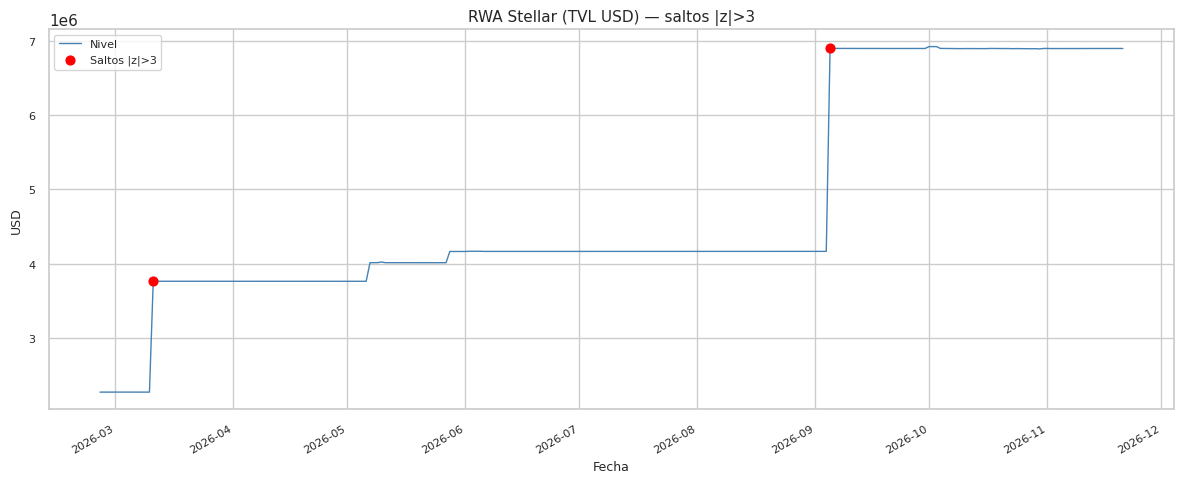

[DEBUG] rwa_red_stellar: 2 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_red_algorand.png


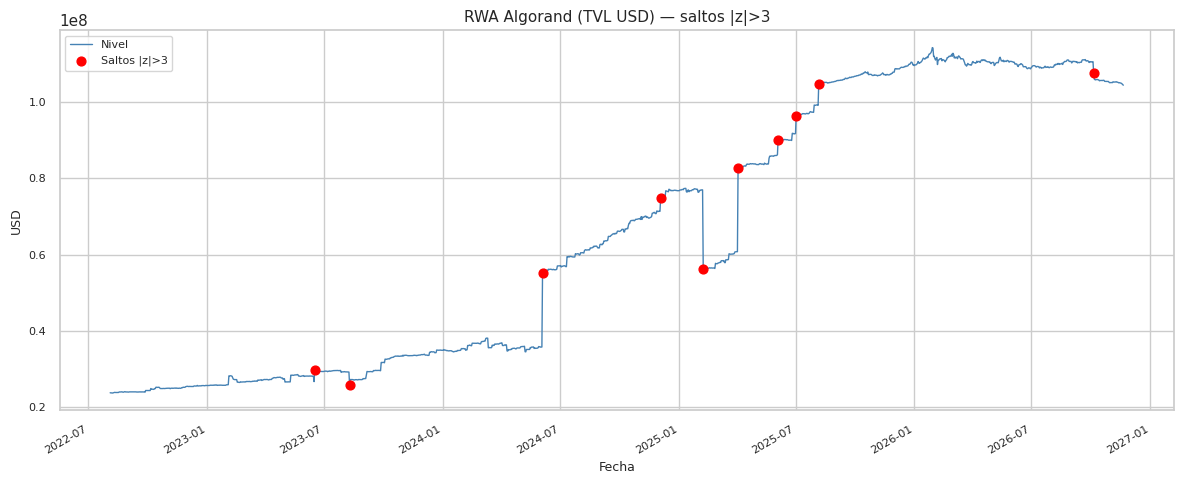

[DEBUG] rwa_red_algorand: 10 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_tipo_treasurybills.png


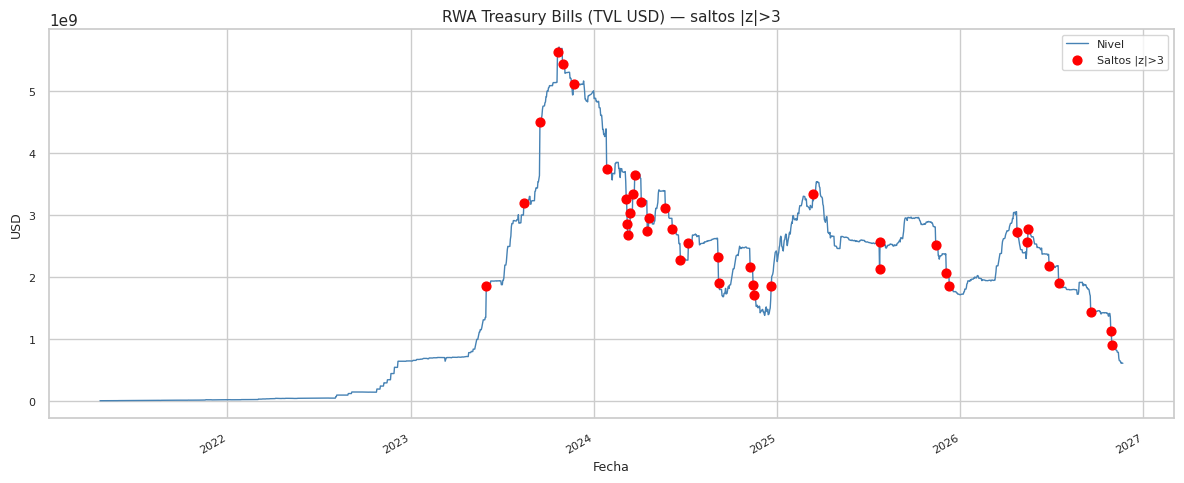

[DEBUG] rwa_tipo_treasurybills: 40 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_tipo_commodities.png


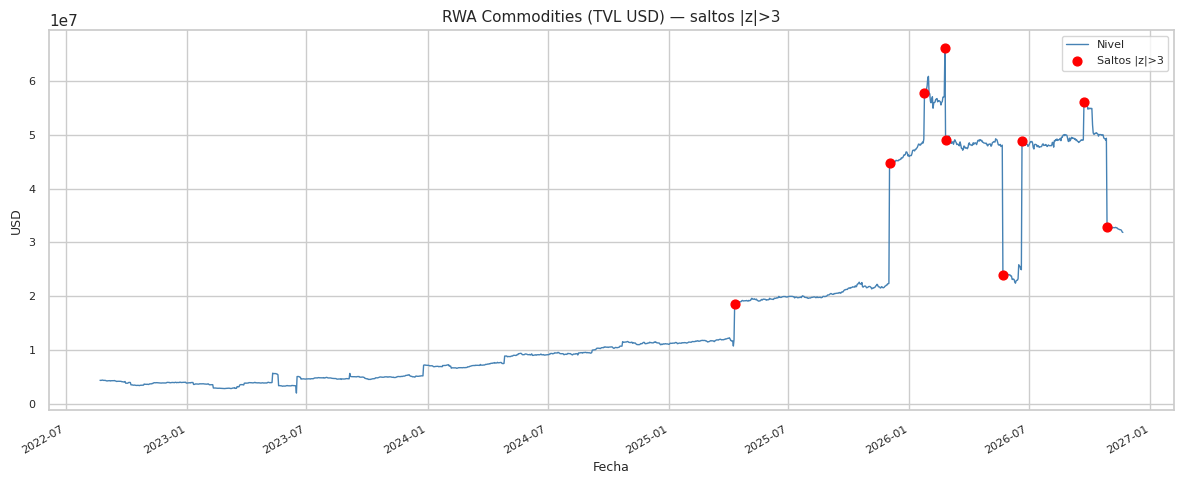

[DEBUG] rwa_tipo_commodities: 9 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_tipo_privatecredit.png


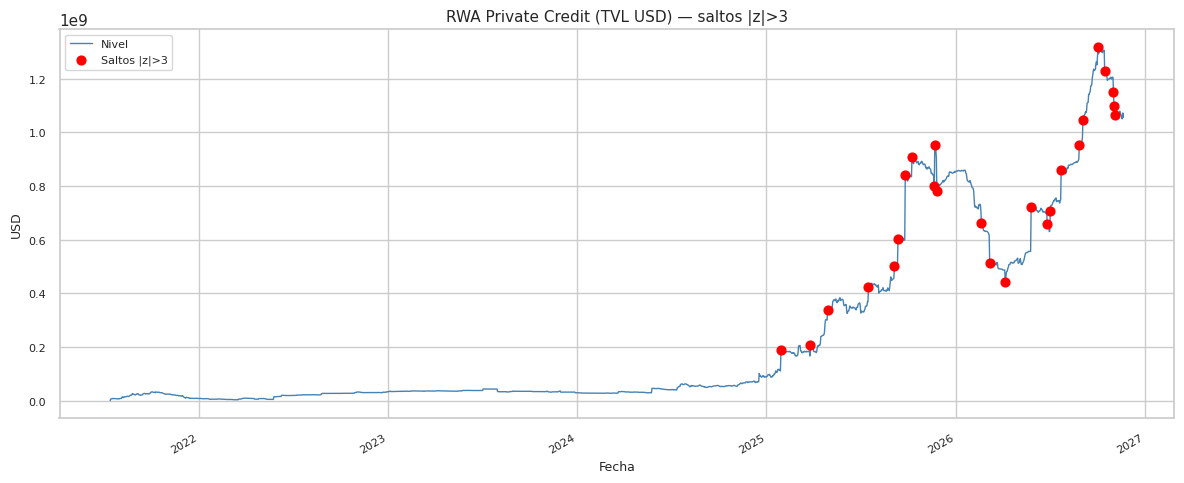

[DEBUG] rwa_tipo_privatecredit: 25 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_tipo_stocksetfs.png


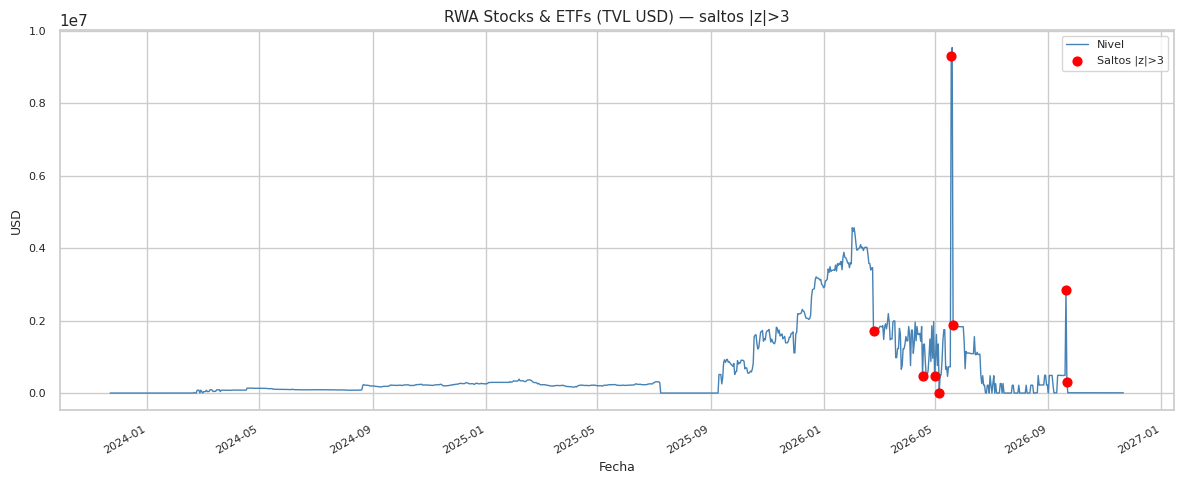

[DEBUG] rwa_tipo_stocksetfs: 8 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_total_global.png


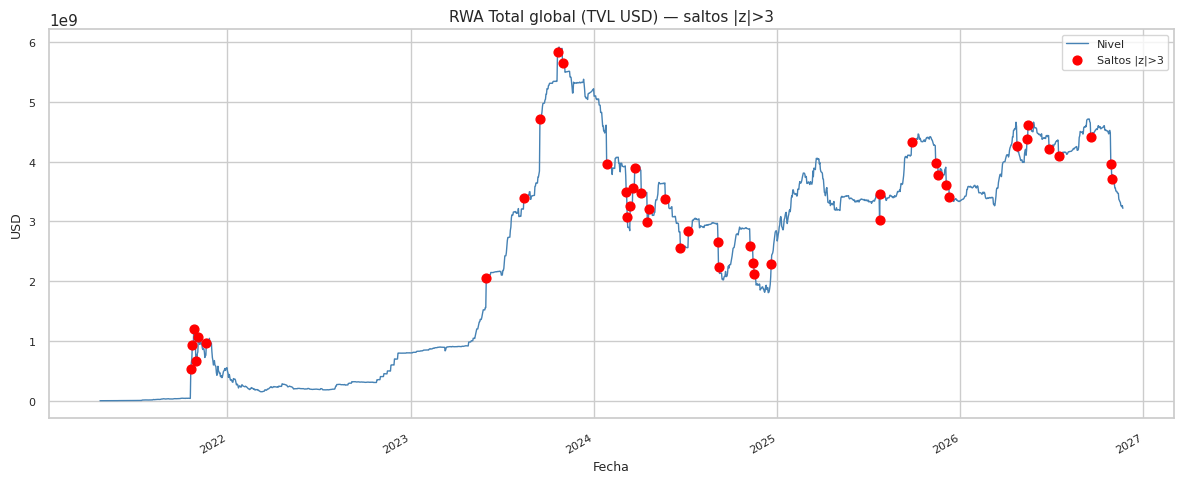

[DEBUG] rwa_total_global: 44 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_fed_funds.png


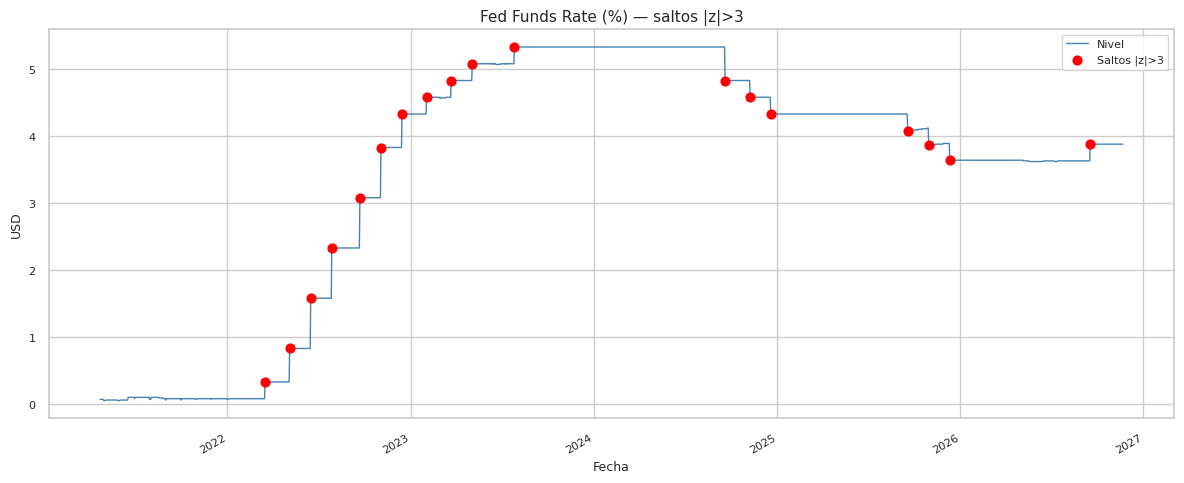

[DEBUG] macro_fed_funds: 18 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_sofr.png


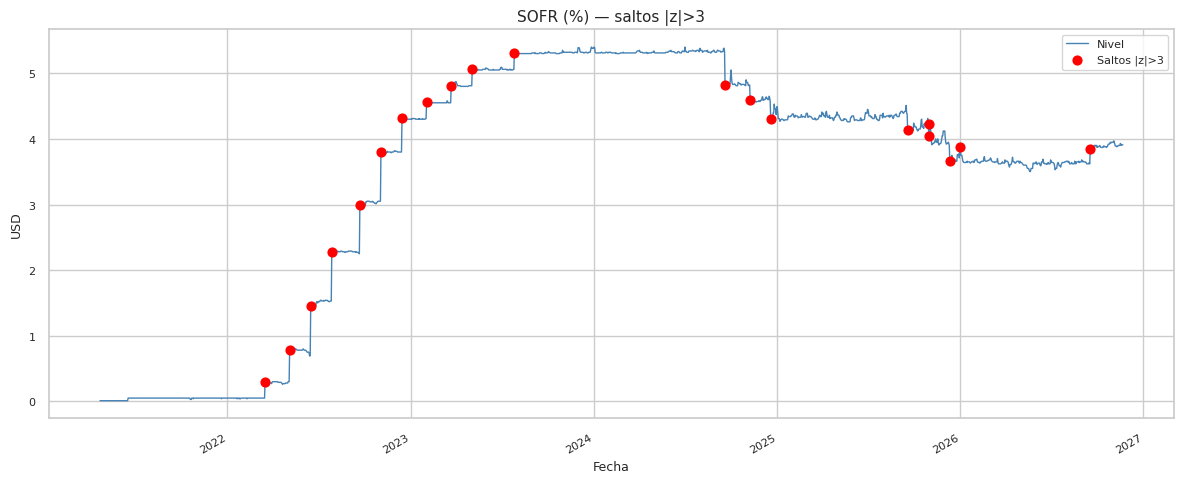

[DEBUG] macro_sofr: 20 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_tsy_1m.png


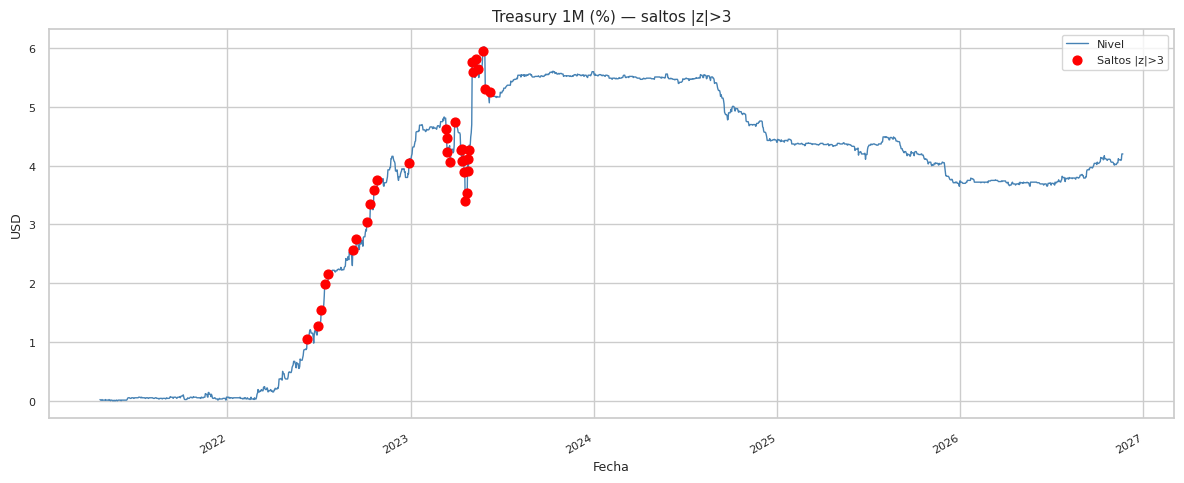

[DEBUG] macro_tsy_1m: 34 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_tsy_3m.png


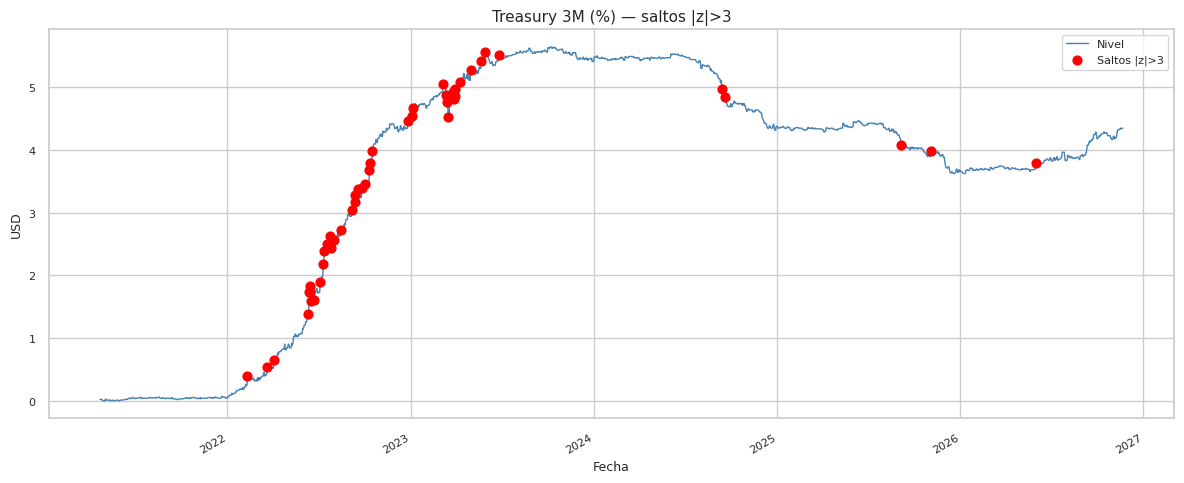

[DEBUG] macro_tsy_3m: 48 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_tsy_2y.png


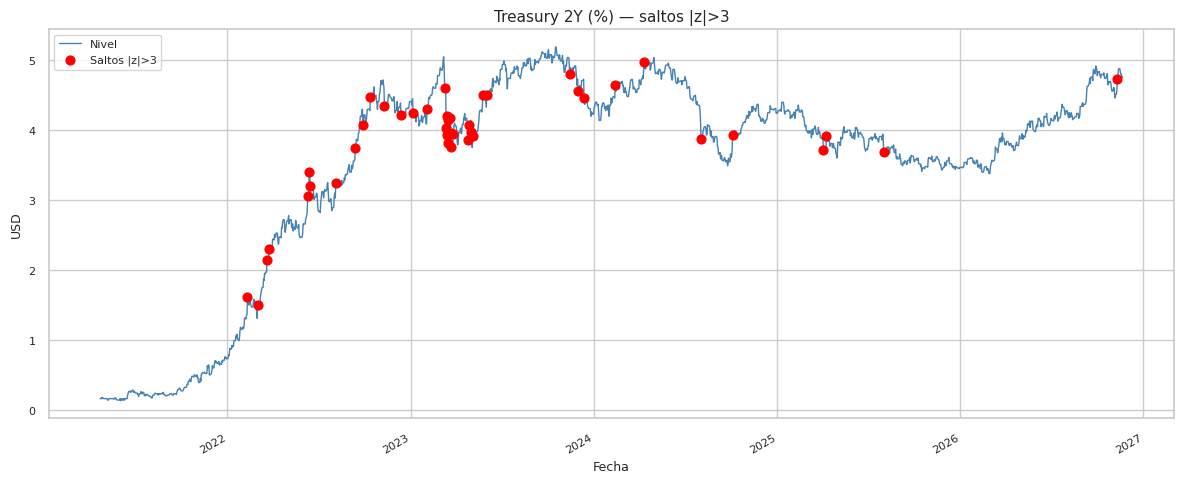

[DEBUG] macro_tsy_2y: 42 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_tsy_10y.png


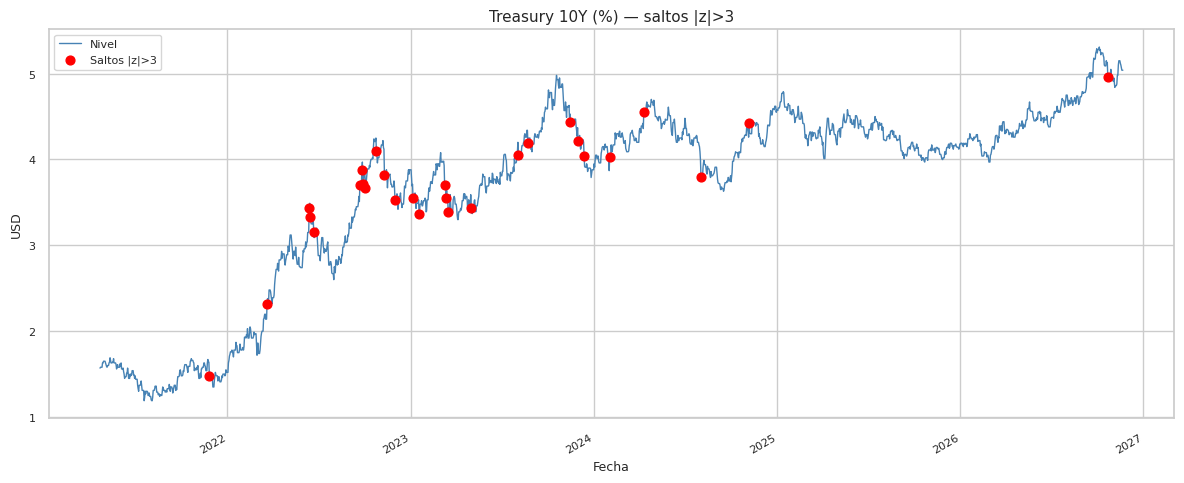

[DEBUG] macro_tsy_10y: 28 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_spread_10y2y.png


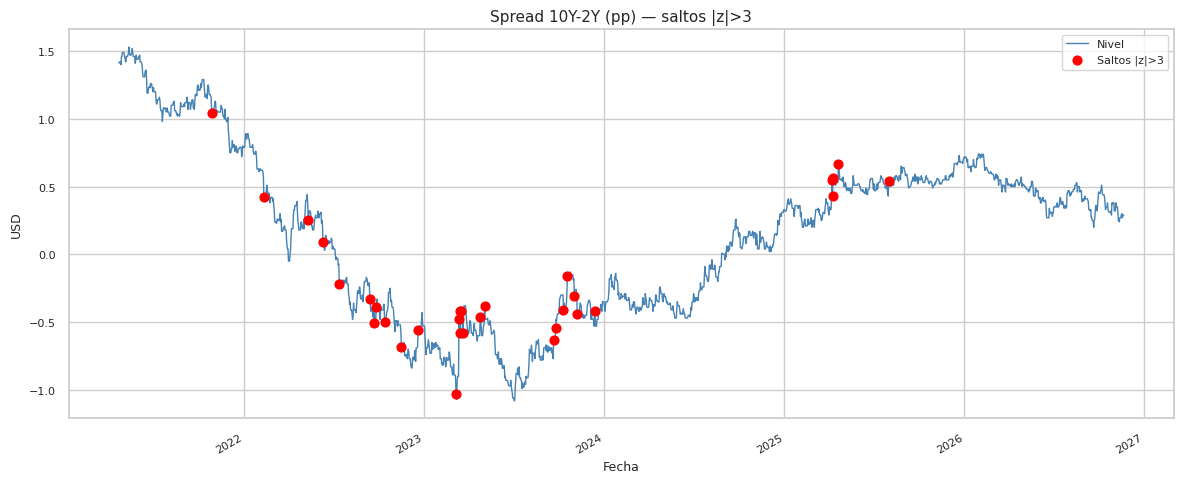

[DEBUG] macro_spread_10y2y: 31 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_infl_exp_10y.png


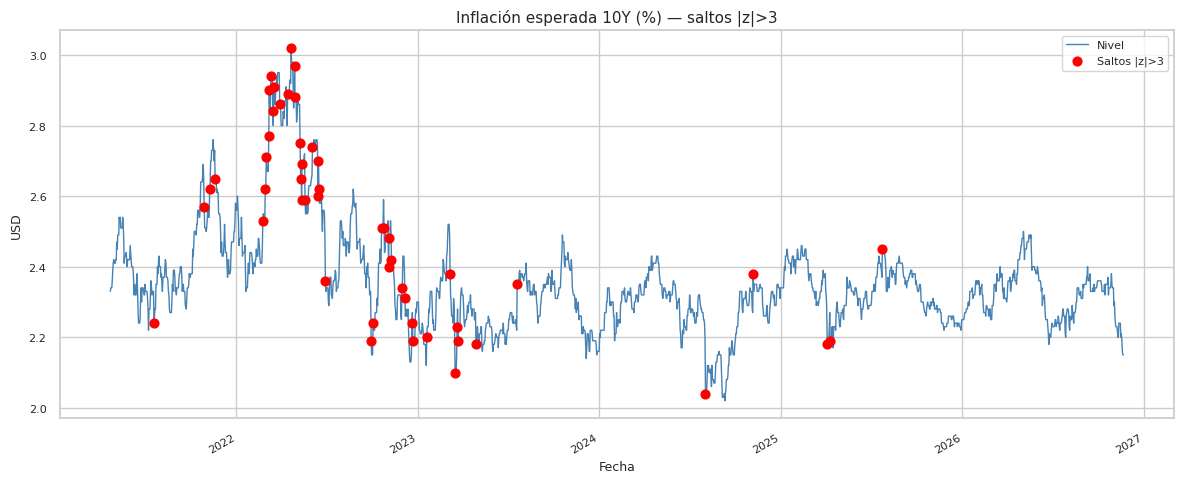

[DEBUG] macro_infl_exp_10y: 50 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_rrp_overnight.png


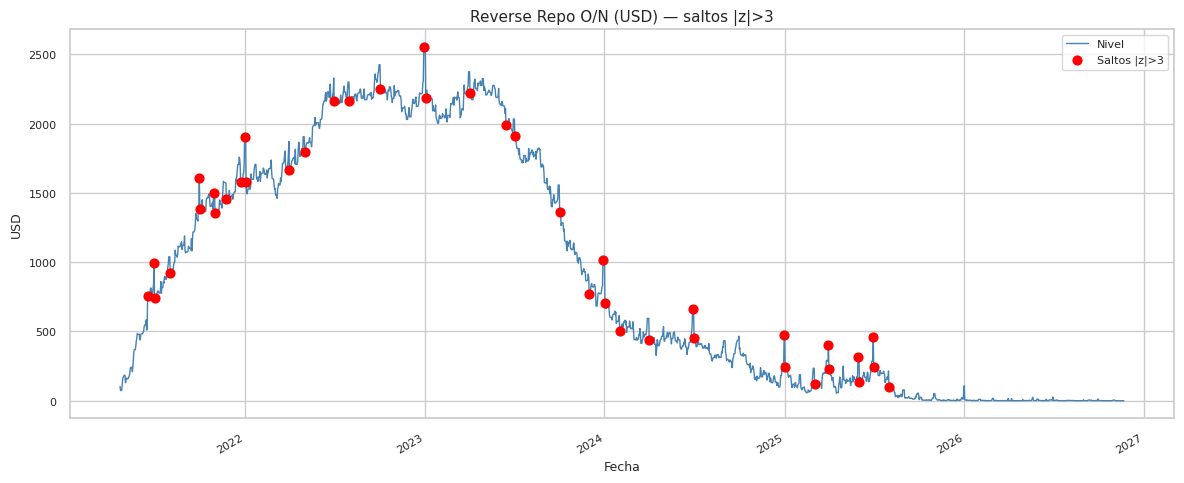

[DEBUG] macro_rrp_overnight: 40 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_nfci.png


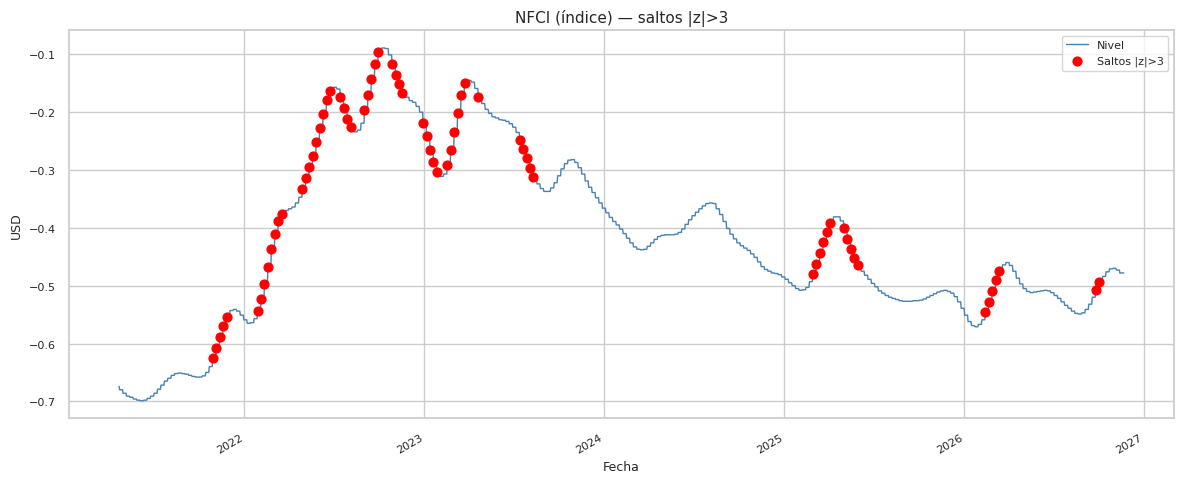

[DEBUG] macro_nfci: 70 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_spread_hy.png


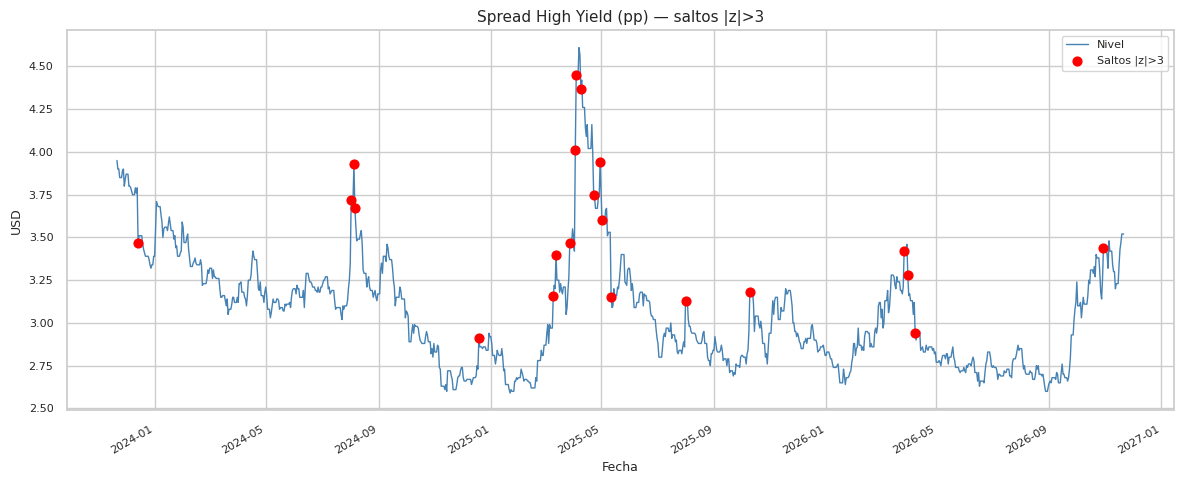

[DEBUG] macro_spread_hy: 21 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_spread_ig.png


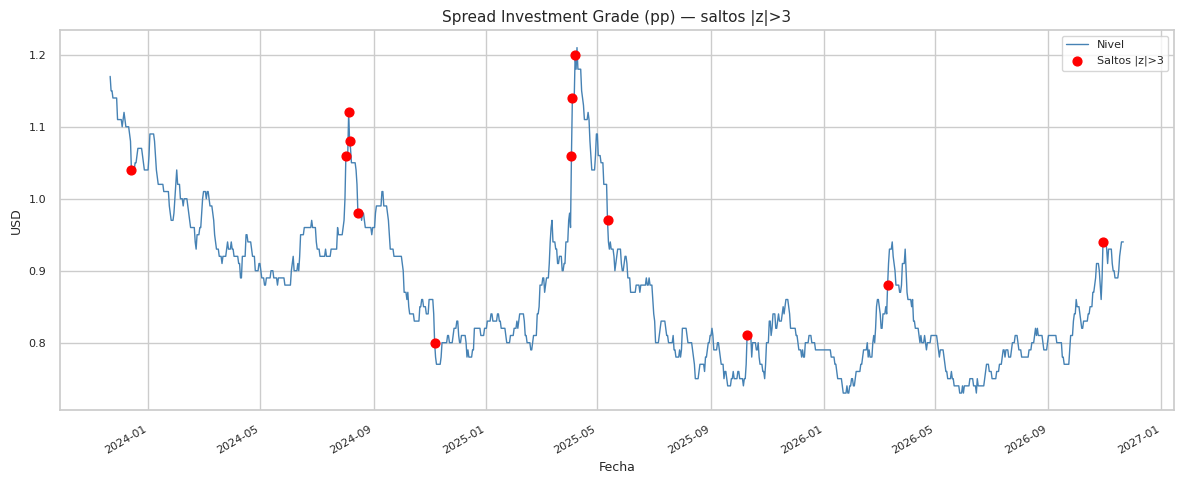

[DEBUG] macro_spread_ig: 13 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_indpro.png


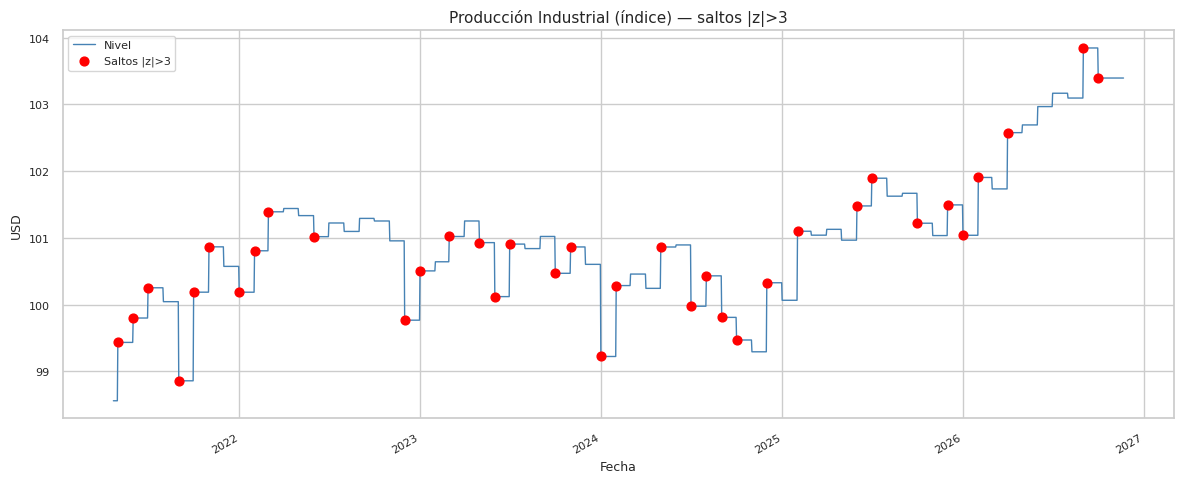

[DEBUG] macro_indpro: 36 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_umcsent.png


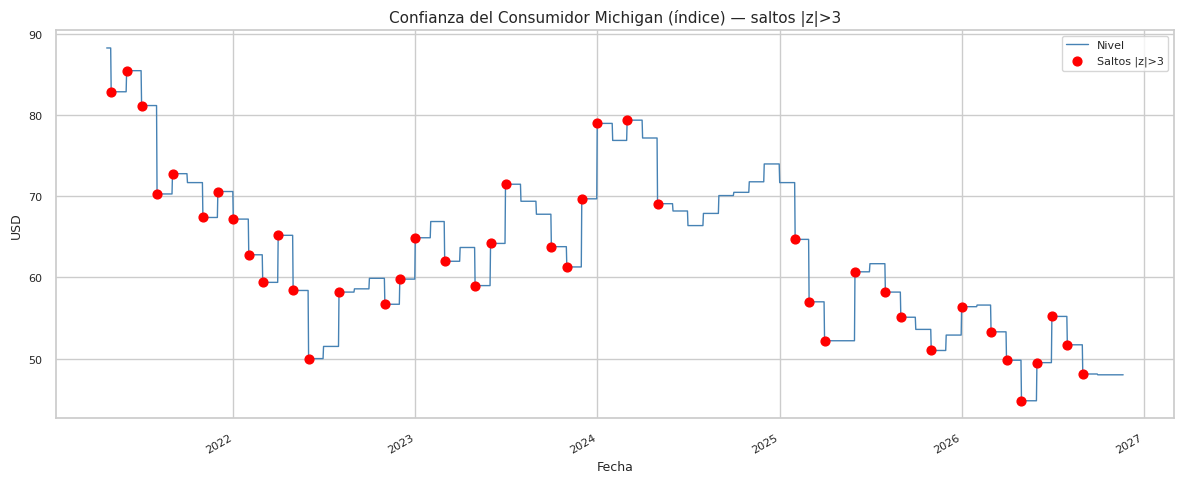

[DEBUG] macro_umcsent: 42 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_euro_ciss.png


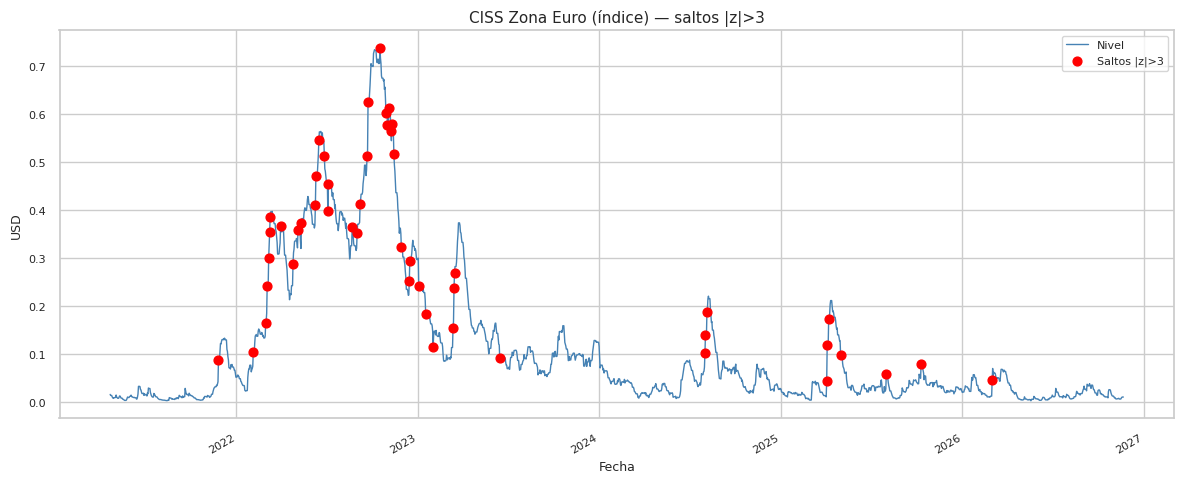

[DEBUG] macro_euro_ciss: 49 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_macro_eeuu_stlfsi.png


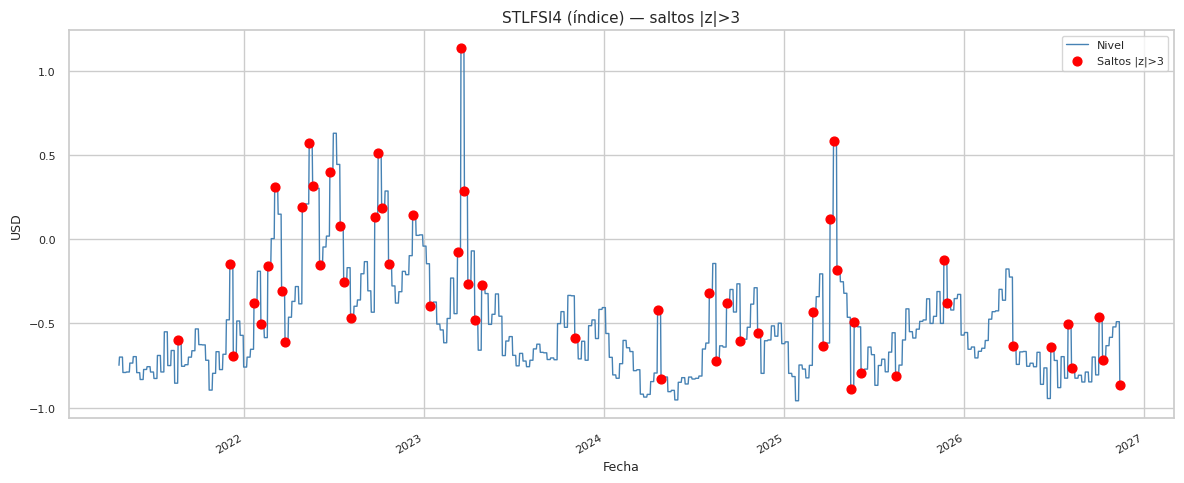

[DEBUG] macro_eeuu_stlfsi: 55 saltos
     fecha                  serie         valor    valor_prev     delta_abs    delta_pct    z_score
2021-08-20      macro_eeuu_stlfsi -6.009000e-01 -8.553000e-01  2.544000e-01   -29.743949   3.158084
2021-12-03      macro_eeuu_stlfsi -1.480000e-01 -4.789000e-01  3.309000e-01   -69.095845   4.107531
2021-12-10      macro_eeuu_stlfsi -6.955000e-01 -1.480000e-01 -5.475000e-01   369.932432  -6.794351
2022-01-21      macro_eeuu_stlfsi -3.765000e-01 -6.539000e-01  2.774000e-01   -42.422389   3.443538
2022-02-04      macro_eeuu_stlfsi -5.056000e-01 -1.904000e-01 -3.152000e-01   165.546218  -3.911260
2022-02-18      macro_eeuu_stlfsi -1.600000e-01 -5.846000e-01  4.246000e-01   -72.630859   5.270447
2022-03-04      macro_eeuu_stlfsi  3.112000e-01  3.600000e-03  3.076000e-01  8544.444444   3.818353
2022-03-18      macro_eeuu_stlfsi -3.096000e-01  1.488000e-01 -4.584000e-01  -308.064516  -5.688525
2022-03-25      macro_eeuu_stlfsi -6.081000e-01 -3.096000e-01 -

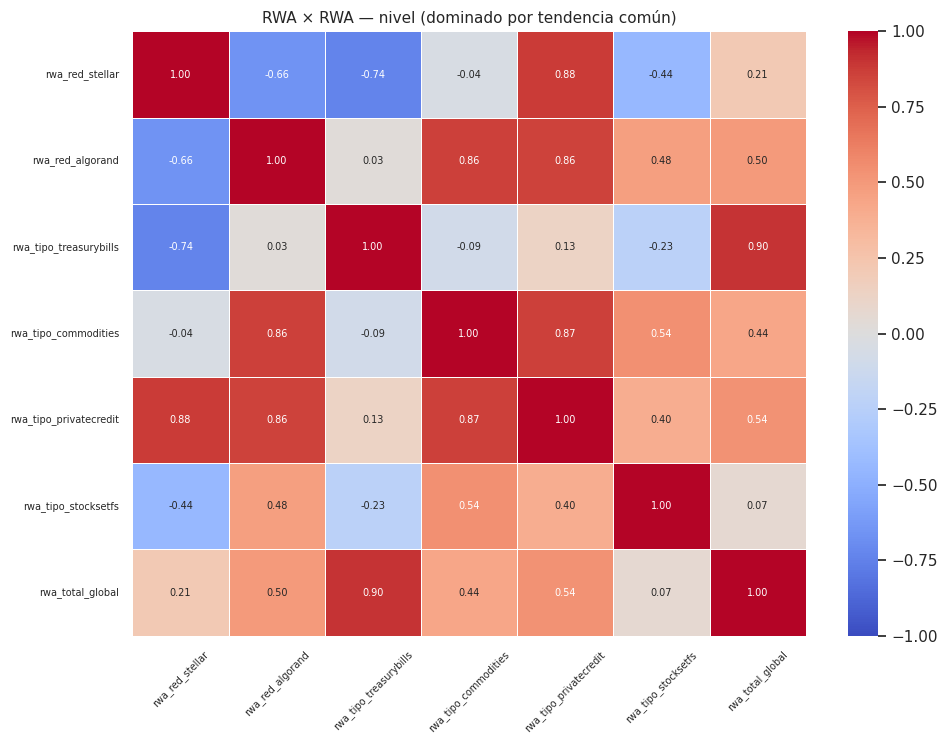

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/corr_rwa_logdif.png


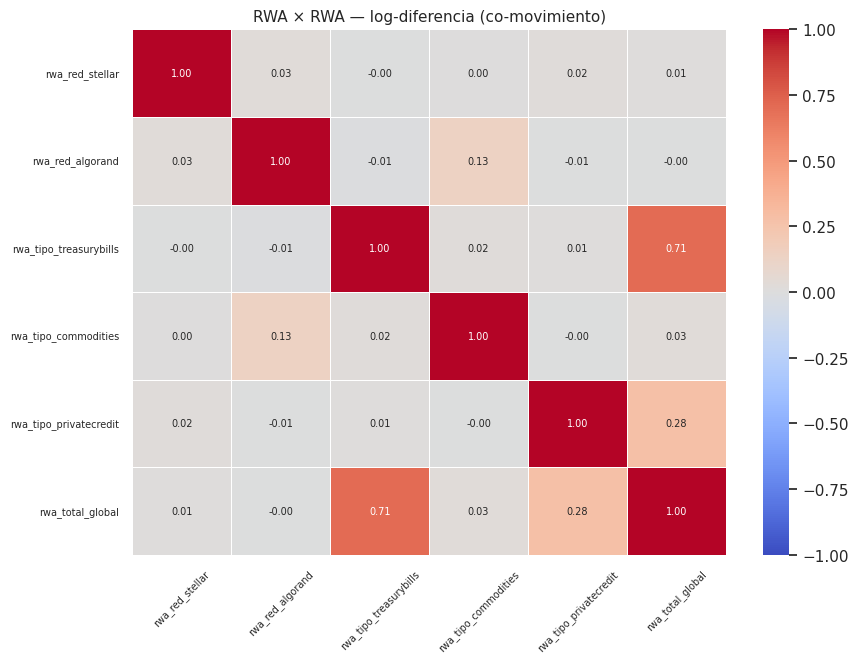

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/corr_rwa_macro_nivel.png


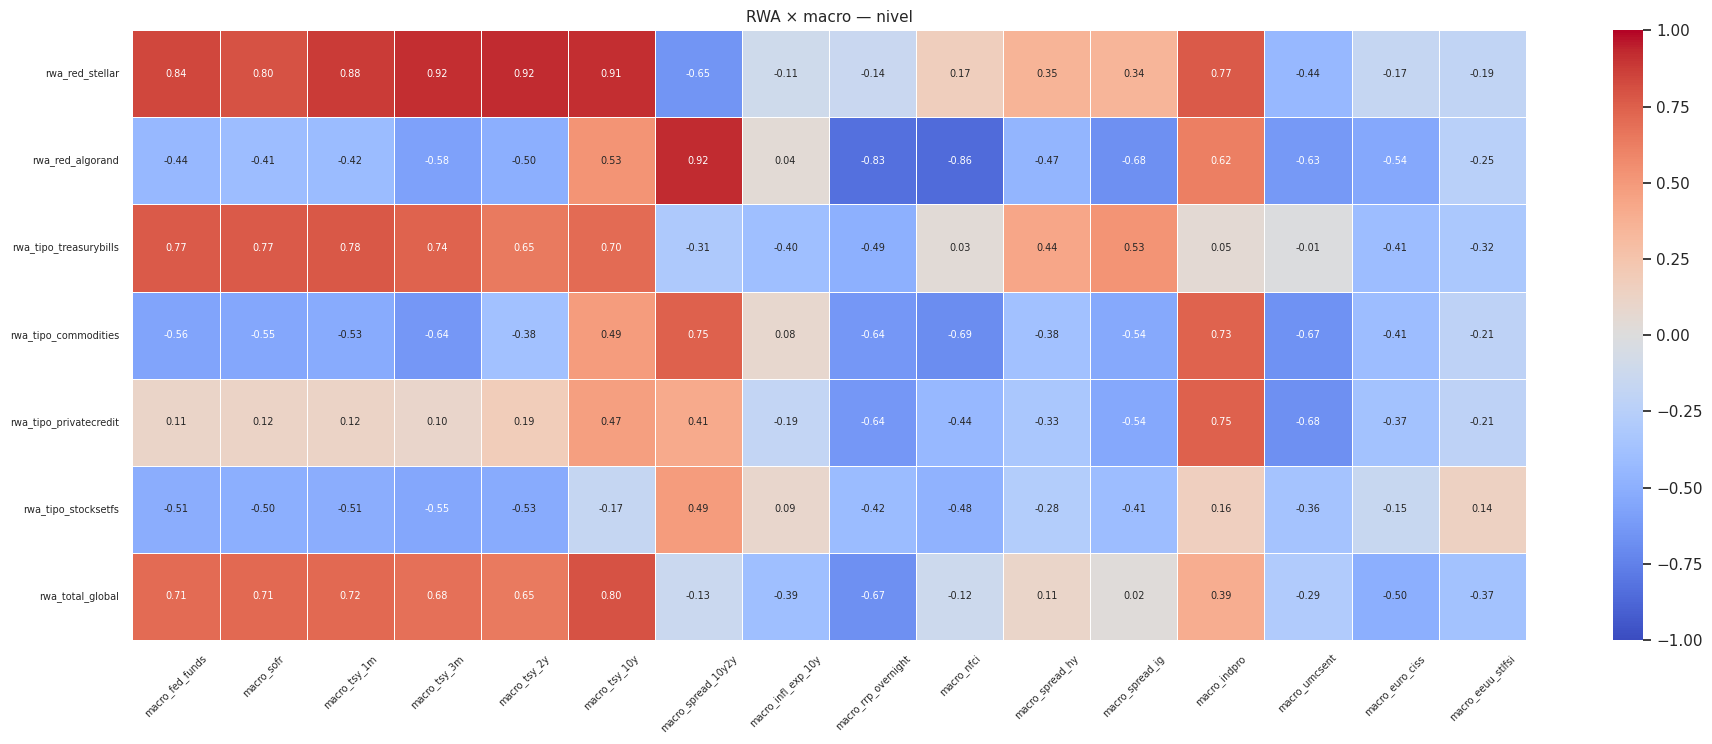

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/corr_rwa_macro_logdif.png


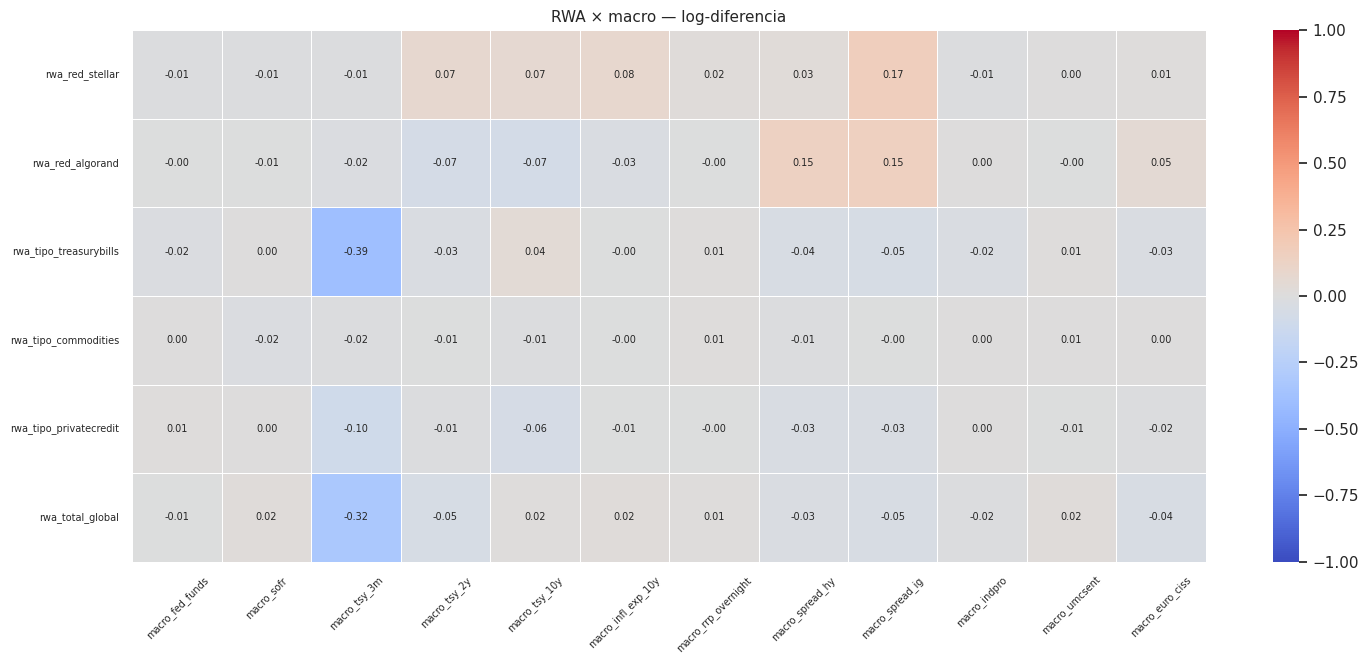

[DEBUG] correlaciones registradas: 269 pares
[DEBUG] pares de mayor |corr|:
      bloque  base                serie_a                serie_b   corr
rwa_vs_macro nivel       rwa_red_algorand     macro_spread_10y2y 0.9248
rwa_vs_macro nivel        rwa_red_stellar           macro_tsy_2y 0.9226
rwa_vs_macro nivel        rwa_red_stellar           macro_tsy_3m 0.9186
rwa_vs_macro nivel        rwa_red_stellar          macro_tsy_10y 0.9141
  rwa_vs_rwa nivel rwa_tipo_treasurybills       rwa_total_global 0.9032
  rwa_vs_rwa nivel       rwa_total_global rwa_tipo_treasurybills 0.9032
rwa_vs_macro nivel        rwa_red_stellar           macro_tsy_1m 0.8807
  rwa_vs_rwa nivel rwa_tipo_privatecredit        rwa_red_stellar 0.8784
  rwa_vs_rwa nivel        rwa_red_stellar rwa_tipo_privatecredit 0.8784
  rwa_vs_rwa nivel   rwa_tipo_commodities rwa_tipo_privatecredit 0.8661
  rwa_vs_rwa nivel rwa_tipo_privatecredit   rwa_tipo_commodities 0.8661
  rwa_vs_rwa nivel   rwa_tipo_commodities       rwa_red_algo

In [3]:
"""# Job 5 - EDA: Caracterización de las series RWA"""


print("Job 5 - EDA: Caracterización de las series RWA")

# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import os
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    from statsmodels.tsa.stattools import adfuller
    _HAS_STATSMODELS: bool = True
except ImportError:
    _HAS_STATSMODELS = False

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

# CAMBIO E2E-05-01: mismo destino configurable que Jobs 0-4.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_eda_rwa"
)

# CAMBIO I2-1: ARCHIVO_DIARIAS apunta al dataset final (23
# series + fecha) en vez de series_diarias_ext.csv (que no
# tiene las 14 series FRED). ARCHIVO_LARGAS se mantiene: es la
# única fuente "larga" disponible hoy (cubre STLFSI, CISS y las
# 7 RWA; las 14 FRED no tienen un archivo largo propio en el
# pipeline actual — ver nota de alcance en el cierre de F3).
ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)

# CAMBIO I2-1: constante única de columnas (reemplaza
# COLS_RWA_RED, COLS_RWA_TIPO, COL_RWA_TOTAL, COLS_ONCHAIN,
# COL_USDY y COLS_BLOQUE_ONCHAIN, que usaban nombres viejos
# —p.ej. "rwa_tipo_treasuries"— y bloques que ya no están en
# series_completas.csv —on-chain, USDY, Ripple—). Mismo
# contenido que COLUMNAS_RWA (Job 2, H5) + COLS_MACRO_FEAT
# (Job 8, H5).
COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]
COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"
COLS_MACRO: list[str] = [
    "macro_fed_funds", "macro_sofr",
    "macro_tsy_1m", "macro_tsy_3m",
    "macro_tsy_2y", "macro_tsy_10y",
    "macro_spread_10y2y", "macro_infl_exp_10y",
    "macro_rrp_overnight", "macro_nfci",
    "macro_spread_hy", "macro_spread_ig",
    "macro_indpro", "macro_umcsent",
    COL_CISS, COL_STLFSI,
]
COLUMNAS_FINALES: list[str] = COLS_RWA + COLS_MACRO

ETIQUETAS: dict[str, str] = {
    "rwa_red_stellar": "RWA Stellar (TVL USD)",
    "rwa_red_algorand": "RWA Algorand (TVL USD)",
    "rwa_tipo_treasurybills": "RWA Treasury Bills (TVL USD)",
    "rwa_tipo_commodities": "RWA Commodities (TVL USD)",
    "rwa_tipo_privatecredit": "RWA Private Credit (TVL USD)",
    "rwa_tipo_stocksetfs": "RWA Stocks & ETFs (TVL USD)",
    "rwa_total_global": "RWA Total global (TVL USD)",
    "macro_fed_funds": "Fed Funds Rate (%)",
    "macro_sofr": "SOFR (%)",
    "macro_tsy_1m": "Treasury 1M (%)",
    "macro_tsy_3m": "Treasury 3M (%)",
    "macro_tsy_2y": "Treasury 2Y (%)",
    "macro_tsy_10y": "Treasury 10Y (%)",
    "macro_spread_10y2y": "Spread 10Y-2Y (pp)",
    "macro_infl_exp_10y": "Inflación esperada 10Y (%)",
    "macro_rrp_overnight": "Reverse Repo O/N (USD)",
    "macro_nfci": "NFCI (índice)",
    "macro_spread_hy": "Spread High Yield (pp)",
    "macro_spread_ig": "Spread Investment Grade (pp)",
    "macro_indpro": "Producción Industrial (índice)",
    "macro_umcsent": "Confianza del Consumidor Michigan (índice)",
    "macro_euro_ciss": "CISS Zona Euro (índice)",
    "macro_eeuu_stlfsi": "STLFSI4 (índice)",
}

ADF_ALPHA: float = 0.05
UMBRAL_SALTO_Z: float = 3.0
N_MIN_ADF: int = 15          # mínimo de obs. para correr ADF
N_POTENCIA_ADF: int = 50     # bajo esto, potencia reducida

# Orden de preferencia de transformación. La log-diferencia va
# antes que la 1ª diferencia: en series de adopción con
# crecimiento multiplicativo, la tasa de crecimiento es la
# lectura económica correcta y estabiliza la varianza.
ORDEN_TRANSF: list[str] = ["nivel", "log_dif", "1a_dif"]

# CAMBIO I3-1: frecuencia nativa de cada columna macro (mismo
# contenido que Job 8/9/10, F2-C4). NFCI y STLFSI4 son semanales;
# INDPRO y UMCSENT son mensuales. Antes de diferenciar o correr
# ADF se resamplea a esta frecuencia (ver resamplear_a_nativa),
# para no repetir "casi todos ceros" dentro del propio ADF.
FRECUENCIA_NATIVA: dict[str, str] = {
    "macro_fed_funds": "D",
    "macro_sofr": "D",
    "macro_tsy_1m": "D",
    "macro_tsy_3m": "D",
    "macro_tsy_2y": "D",
    "macro_tsy_10y": "D",
    "macro_spread_10y2y": "D",
    "macro_infl_exp_10y": "D",
    "macro_rrp_overnight": "D",
    "macro_nfci": "W",
    "macro_spread_hy": "D",
    "macro_spread_ig": "D",
    "macro_indpro": "M",
    "macro_umcsent": "M",
    COL_CISS: "D",
    COL_STLFSI: "W",
}

# CAMBIO I3-2: copia de solo lectura de TRANSFORM (Job 8), para
# comparar contra la transformación elegida por ADF. No se
# modifica ni se usa para transformar nada en este Job — solo
# para el reporte de I3-d.
TRANSFORM_JOB8: dict[str, str] = {
    "rwa_usdy_supply": "log_diff",
    "rwa_red_stellar": "log_diff",
    "rwa_red_ripple": "log_diff",
    "rwa_red_algorand": "log_diff",
    "rwa_tipo_treasurybills": "log_diff",
    "rwa_tipo_commodities": "log_diff",
    "rwa_tipo_privatecredit": "log_diff",
    "rwa_tipo_stocksetfs": "log_diff",
    "rwa_total_global": "log_diff",
    "macro_fed_funds": "diff",
    "macro_sofr": "diff",
    "macro_tsy_1m": "diff",
    "macro_tsy_3m": "diff",
    "macro_tsy_2y": "diff",
    "macro_tsy_10y": "diff",
    "macro_spread_10y2y": "diff",
    "macro_infl_exp_10y": "diff",
    "macro_rrp_overnight": "log_diff",
    "macro_nfci": "nivel",
    "macro_spread_hy": "diff",
    "macro_spread_ig": "diff",
    "macro_indpro": "log_diff",
    "macro_umcsent": "diff",
    COL_CISS: "diff",
    COL_STLFSI: "nivel",
}
# Job 8 nombra "diff"/"log_diff"/"nivel"; este Job usa
# "1a_dif"/"log_dif"/"nivel" — mapeo solo para comparar (I3-d).
_MAPA_TRANSF_JOB8: dict[str, str] = {
    "diff": "1a_dif", "log_diff": "log_dif", "nivel": "nivel",
}

sns.set_theme(style="whitegrid", palette="muted")

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


"""# 4. Funciones"""


def cargar_series(ruta: str) -> pd.DataFrame:
    """
    Carga un CSV de series con índice fecha (DatetimeIndex).

    Args:
        ruta: Ruta del CSV.

    Returns:
        DataFrame indexado por fecha.
    """
    df = pd.read_csv(
        ruta, parse_dates=["fecha"], index_col="fecha"
    )
    if DEBUG:
        print(f"[DEBUG] cargado: {df.shape} — {ruta}")
    return df


def validar_entrada_eda(ruta: str, job_origen: str) -> pd.DataFrame:
    """CAMBIO E2E-05-01: validar archivo y fechas sin cambiar valores.

    Rechaza entradas ausentes, ilegibles, vacias, con fechas
    invalidas, duplicadas o desordenadas. No imputa ni ordena.
    """
    if not os.path.isfile(ruta):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 5: falta {ruta}. "
            f"Debe generarlo el {job_origen}."
        )
    try:
        df = cargar_series(ruta)
    except Exception as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 5: no se pudo leer {ruta} "
            f"(salida del {job_origen}); verificar CSV y columna 'fecha': {exc}"
        ) from exc
    if df.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 5: entrada vacia: {ruta} "
            f"(salida del {job_origen})."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 5: fechas invalidas en {ruta}. "
            f"Revisar {job_origen}."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 5: fechas duplicadas en {ruta}. "
            "No se puede procesar un indice temporal ambiguo."
        )
    if not df.index.is_monotonic_increasing:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 5: fechas desordenadas en {ruta}. "
            "Revisar la salida original; no se reordena automaticamente."
        )
    return df


def estadistica_descriptiva(
    df: pd.DataFrame,
    cols: list[str],
) -> pd.DataFrame:
    """
    Estadísticas básicas (n, media, std, min, max, CV, skew,
    cuartiles, atípicos IQR y % de observaciones repetidas).

    CAMBIO I2-2: agrega q25/q50/q75, el recuento de atípicos por
    la regla 1.5×IQR (valores fuera de [q25-1.5·IQR, q75+1.5·IQR])
    y "pct_repetido_ffill": el % de días cuyo valor es idéntico
    al del día anterior. Esto último es una PROXY de ffill, no la
    máscara real (acá no está disponible): un valor puede
    repetirse por una razón genuina y no solo por ffill, así que
    léase como cota superior de la cobertura rellenada.

    Args:
        df: Dataset con las series en columnas.
        cols: Columnas a describir.

    Returns:
        DataFrame con una fila por serie.
    """
    filas: list[dict] = []
    for col in cols:
        s = (
            df[col].dropna()
            if col in df.columns
            else pd.Series(dtype=float)
        )
        if s.empty:
            filas.append({"serie": col, "n": 0})
            continue
        media = float(s.mean())
        cv = s.std() / media if media != 0 else float("nan")
        q25 = float(s.quantile(0.25))
        q50 = float(s.quantile(0.50))
        q75 = float(s.quantile(0.75))
        iqr = q75 - q25
        lim_inf = q25 - 1.5 * iqr
        lim_sup = q75 + 1.5 * iqr
        n_atipicos = int(((s < lim_inf) | (s > lim_sup)).sum())
        serie_completa = (
            df[col] if col in df.columns else pd.Series(dtype=float)
        )
        n_repetido = int((serie_completa.diff() == 0).sum())
        pct_repetido = (
            round(n_repetido / len(serie_completa) * 100, 1)
            if len(serie_completa) > 0 else 0.0
        )
        filas.append({
            "serie": col,
            "etiqueta": ETIQUETAS.get(col, col),
            "n": int(s.notna().sum()),
            "n_nulo": int(df[col].isna().sum()),
            "media": round(media, 4),
            "desvio": round(float(s.std()), 4),
            "min": round(float(s.min()), 4),
            "max": round(float(s.max()), 4),
            "q25": round(q25, 4),
            "q50_mediana": round(q50, 4),
            "q75": round(q75, 4),
            "n_atipicos_iqr": n_atipicos,
            "cv": round(float(cv), 4),
            "skew": round(float(s.skew()), 4),
            "pct_repetido_ffill": pct_repetido,
            "min_fecha": s.index.min().date().isoformat(),
            "max_fecha": s.index.max().date().isoformat(),
        })
    return pd.DataFrame(filas)


def _guardar_fig(ruta: str) -> None:
    """Guarda la figura activa a disco si SAVE_DATA=True."""
    if SAVE_DATA:
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        plt.savefig(ruta, dpi=150, bbox_inches="tight")
        if DEBUG:
            print(f"[DEBUG] figura: {ruta}")


def plot_serie_simple(
    serie: pd.Series,
    titulo: str,
    fname: str,
) -> None:
    """
    Línea temporal simple para una serie.

    Args:
        serie: Serie con DatetimeIndex.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.
    """
    fig, ax = plt.subplots(figsize=(12, 4))
    serie.plot(ax=ax, lw=1.0, color="steelblue")
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Fecha", fontsize=9)
    ax.set_ylabel("USD", fontsize=9)
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()


def plot_tipos_comparado(
    df: pd.DataFrame,
    cols: list[str],
    fname: str = "rwa_tipos_comparado.png",
) -> None:
    """
    Compara en un mismo eje las series por tipo de activo, para
    ver magnitudes relativas.

    Dibuja dos paneles: escala lineal (magnitudes absolutas) y
    escala logarítmica (dinámica relativa, legible cuando los
    órdenes de magnitud difieren).

    Args:
        df: Dataset con las series.
        cols: Columnas de tipo de activo a comparar.
        fname: Nombre del archivo PNG.
    """
    presentes = [c for c in cols if c in df.columns]
    if not presentes:
        if DEBUG:
            print("[DEBUG] sin columnas de tipo para comparar")
        return
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    for col in presentes:
        etq = ETIQUETAS.get(col, col)
        df[col].plot(ax=axes[0], lw=1.1, label=etq)
        positivos = df[col].where(df[col] > 0)
        positivos.plot(ax=axes[1], lw=1.1, label=etq)
    axes[0].set_title(
        "RWA por tipo de activo — escala lineal (magnitudes)",
        fontsize=11,
    )
    axes[0].set_ylabel("USD", fontsize=9)
    axes[0].legend(fontsize=8)
    axes[1].set_yscale("log")
    axes[1].set_title(
        "RWA por tipo de activo — escala log (dinámica)",
        fontsize=11,
    )
    axes[1].set_ylabel("USD (log)", fontsize=9)
    axes[1].set_xlabel("Fecha", fontsize=9)
    axes[1].legend(fontsize=8)
    for ax in axes:
        ax.tick_params(labelsize=8)
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()


def _veredicto_adf(p: float) -> str:
    """Clasifica el resultado ADF según significancia."""
    if p < 0.01:
        return "estacionaria (p<0.01)"
    if p < 0.05:
        return "estacionaria (p<0.05)"
    if p < 0.10:
        return "borderline (p<0.10)"
    return "no estacionaria"


def resamplear_a_nativa(serie: pd.Series, col: str) -> pd.Series:
    """
    Resamplea una serie a su frecuencia nativa antes de
    diferenciarla o correr ADF.

    CAMBIO I3-1: regla de F2/C4. Sin esto, una serie
    semanal/mensual ffilleada a diario muestra "casi todos
    ceros" al diferenciarla a diario, y el ADF la declara
    estacionaria por el motivo equivocado (varianza casi nula,
    no reversión a la media real).

    Args:
        serie: Serie con DatetimeIndex (nivel, diaria).
        col: Nombre real de la columna (clave de
            FRECUENCIA_NATIVA). Las columnas RWA (no están en
            FRECUENCIA_NATIVA) son diarias y no se resamplean.

    Returns:
        Serie resampleada ("last") a su frecuencia nativa, o la
        misma serie si ya es diaria.
    """
    nativa = FRECUENCIA_NATIVA.get(col, "D")
    if nativa == "W":
        return serie.resample("W").last()
    if nativa == "M":
        return serie.resample("ME").last()
    return serie


def _adf_una(
    s: pd.Series,
    nombre: str,
    transf: str,
    fuente: str,
    serie_nivel: pd.Series | None = None,
) -> dict:
    """
    Corre ADF sobre una transformación concreta de la serie.

    CAMBIO I3-3: agrega n_nan_transf, n_ceros_nivel y
    n_atipicos_transf — diagnóstico automático de ceros/atípicos/
    NaN para poder explicar estadísticos ADF anómalos (ver caso
    rwa_tipo_privatecredit, I3-c) sin tener que inspeccionar cada
    serie a mano.

    Args:
        s: Serie ya transformada (y ya resampleada a su
            frecuencia nativa si corresponde).
        nombre: Nombre de la serie original.
        transf: "nivel" | "1a_dif" | "log_dif".
        fuente: "ventana" (grilla 2026) | "larga" (historia).
        serie_nivel: Serie de nivel (sin transformar, misma
            frecuencia) usada para contar ceros de origen.

    Returns:
        Dict con serie, fuente, transf, n, adf_stat, p_valor,
        veredicto, aviso de potencia y diagnóstico de
        ceros/atípicos/NaN.
    """
    sc = s.dropna()
    n_ceros_nivel = (
        int((serie_nivel.dropna() == 0).sum())
        if serie_nivel is not None else 0
    )
    base: dict = {
        "serie": nombre,
        "fuente": fuente,
        "transf": transf,
        "n": int(len(sc)),
        "n_nan_transf": int(s.isna().sum()),
        "n_ceros_nivel": n_ceros_nivel,
        "n_atipicos_transf": 0,
        "adf_stat": None,
        "p_valor": None,
        "veredicto": "n/a",
        "potencia": "",
    }
    if len(sc) < N_MIN_ADF:
        base["veredicto"] = f"n<{N_MIN_ADF} ({len(sc)})"
        return base
    if float(sc.std()) == 0:
        base["veredicto"] = "constante"
        return base
    q1, q3 = sc.quantile(0.25), sc.quantile(0.75)
    iqr = q3 - q1
    if iqr > 0:
        base["n_atipicos_transf"] = int(
            ((sc < q1 - 1.5 * iqr) | (sc > q3 + 1.5 * iqr)).sum()
        )
    try:
        stat, pval, _, nobs, *_ = adfuller(sc, autolag="AIC")
        base["adf_stat"] = round(float(stat), 4)
        base["p_valor"] = round(float(pval), 4)
        base["n"] = int(nobs)
        base["veredicto"] = _veredicto_adf(float(pval))
        base["potencia"] = (
            f"n<{N_POTENCIA_ADF}: potencia reducida"
            if int(nobs) < N_POTENCIA_ADF else "ok"
        )
    except Exception as exc:
        base["veredicto"] = f"error: {exc}"
    return base


def adf_serie(
    serie: pd.Series,
    nombre: str,
    fuente: str,
    col_real: str = "",
) -> list[dict]:
    """
    ADF en nivel, 1ª diferencia y log-diferencia.

    La log-diferencia solo se calcula si la serie es
    estrictamente positiva en todo su recorrido; si tiene ceros
    o negativos se registra "n/a" en lugar de forzar el cálculo.

    CAMBIO I3-1: antes de testear, la serie se resamplea a su
    frecuencia nativa (resamplear_a_nativa) si `col_real` es
    semanal/mensual (FRECUENCIA_NATIVA).

    Args:
        serie: Serie a testear (sin transformar).
        nombre: Nombre de la serie (etiqueta, para el reporte).
        fuente: "ventana" o "larga".
        col_real: Nombre real de la columna (clave de
            FRECUENCIA_NATIVA); si no se indica, se asume diaria.

    Returns:
        Lista de 3 dicts (uno por transformación).
    """
    if not _HAS_STATSMODELS:
        return [{
            "serie": nombre,
            "fuente": fuente,
            "transf": "—",
            "n": 0,
            "adf_stat": None,
            "p_valor": None,
            "veredicto": "statsmodels no disponible",
            "potencia": "",
        }]
    serie = resamplear_a_nativa(serie, col_real)
    resultados: list[dict] = []
    resultados.append(
        _adf_una(serie, nombre, "nivel", fuente, serie)
    )
    resultados.append(
        _adf_una(serie.diff(), nombre, "1a_dif", fuente, serie)
    )
    s_pos = serie.dropna()
    if not s_pos.empty and (s_pos > 0).all():
        log_dif = np.log(serie).diff()
        resultados.append(
            _adf_una(log_dif, nombre, "log_dif", fuente, serie)
        )
    else:
        resultados.append({
            "serie": nombre,
            "fuente": fuente,
            "transf": "log_dif",
            "n": 0,
            "adf_stat": None,
            "p_valor": None,
            "veredicto": "n/a (valores ≤ 0)",
            "potencia": "",
        })
    return resultados


def _es_estacionaria(fila: pd.Series) -> bool:
    """
    Indica si una fila de la tabla ADF pasa el umbral ADF_ALPHA.

    Args:
        fila: Fila con columna p_valor.

    Returns:
        True si p_valor < ADF_ALPHA.
    """
    pval = fila.get("p_valor")
    return pval is not None and not pd.isna(pval) and (
        float(pval) < ADF_ALPHA
    )


def elegir_transformacion(
    df_adf: pd.DataFrame,
    cols: list[str],
) -> pd.DataFrame:
    """
    Decide la transformación estacionaria de cada serie.

    Criterio:
      - Se prioriza la evidencia de la serie LARGA (más
        observaciones ⇒ más potencia del ADF). Si no hay serie
        larga para esa columna, se usa la ventana diaria.
      - Dentro de esa fuente se toma la primera transformación
        de ORDEN_TRANSF que resulte estacionaria a ADF_ALPHA:
        nivel → log_dif → 1a_dif. La log-diferencia precede a la
        1ª diferencia por ser la tasa de crecimiento, lectura
        económica correcta en series de adopción.
      - Si ninguna transformación resulta estacionaria, se
        registra "ninguna" y se deja anotado: la serie NO entra
        al modelo sin tratamiento adicional.

    Args:
        df_adf: Tabla ADF larga (serie, fuente, transf, p_valor).
        cols: Series a resolver.

    Returns:
        DataFrame con serie, fuente_decision, transf_elegida,
        p_valor, n, veredicto y nota.
    """
    filas: list[dict] = []
    for col in cols:
        etiqueta = ETIQUETAS.get(col, col)
        sub = df_adf[df_adf["serie"] == etiqueta]
        if sub.empty:
            filas.append({
                "serie": col,
                "etiqueta": etiqueta,
                "fuente_decision": "s/d",
                "transf_elegida": "s/d",
                "p_valor": None,
                "n": 0,
                "nota": "sin resultados ADF",
            })
            continue
        elegida: dict | None = None
        for fuente in ("larga", "ventana"):
            sub_f = sub[sub["fuente"] == fuente]
            if sub_f.empty:
                continue
            for transf in ORDEN_TRANSF:
                cand = sub_f[sub_f["transf"] == transf]
                if cand.empty:
                    continue
                fila_c = cand.iloc[0]
                if _es_estacionaria(fila_c):
                    elegida = {
                        "fuente_decision": fuente,
                        "transf_elegida": transf,
                        "p_valor": fila_c["p_valor"],
                        "n": fila_c["n"],
                        "nota": str(fila_c["potencia"]),
                    }
                    break
            if elegida is not None:
                break
        if elegida is None:
            filas.append({
                "serie": col,
                "etiqueta": etiqueta,
                "fuente_decision": "—",
                "transf_elegida": "ninguna",
                "p_valor": None,
                "n": 0,
                "nota": (
                    "ninguna transformación resultó estacionaria "
                    f"a alpha={ADF_ALPHA}: no usar sin "
                    "tratamiento adicional"
                ),
            })
            continue
        filas.append({
            "serie": col,
            "etiqueta": etiqueta,
            **elegida,
        })
    return pd.DataFrame(filas)


def construir_tabla_adf_ancha(
    df_adf: pd.DataFrame,
    df_transf: pd.DataFrame,
    cols: list[str],
) -> pd.DataFrame:
    """
    Pivotea los resultados ADF largos a una fila por serie, con
    las 3 transformaciones como columnas, usando la fuente
    elegida por elegir_transformacion() (serie larga si existe,
    ventana si no — CAMBIO I3-1/I3-b).

    También compara la transformación elegida por ADF contra
    TRANSFORM_JOB8 (CAMBIO I3-2/I3-d): no modifica TRANSFORM, solo
    reporta si coinciden.

    Args:
        df_adf: Tabla ADF larga (salida de adf_serie, con el
            diagnóstico de ceros/atípicos/NaN de I3-3).
        df_transf: Salida de elegir_transformacion().
        cols: Columnas (nombres reales) a incluir, una fila cada
            una.

    Returns:
        DataFrame con una fila por columna de `cols`.
    """
    filas: list[dict] = []
    for col in cols:
        etiqueta = ETIQUETAS.get(col, col)
        fila_transf = df_transf[df_transf["serie"] == col]
        fuente = (
            str(fila_transf.iloc[0]["fuente_decision"])
            if not fila_transf.empty else "—"
        )
        transf_elegida = (
            str(fila_transf.iloc[0]["transf_elegida"])
            if not fila_transf.empty else "s/d"
        )
        sub = df_adf[
            (df_adf["serie"] == etiqueta)
            & (df_adf["fuente"] == fuente)
        ]
        fila: dict = {
            "serie": col,
            "etiqueta": etiqueta,
            "fuente_decision": fuente,
            "transf_elegida": transf_elegida,
        }
        for transf in ("nivel", "1a_dif", "log_dif"):
            cand = sub[sub["transf"] == transf]
            if cand.empty:
                fila[f"adf_stat_{transf}"] = None
                fila[f"p_valor_{transf}"] = None
                fila[f"n_{transf}"] = None
                fila[f"veredicto_{transf}"] = "s/d"
                fila[f"n_ceros_nivel_{transf}"] = None
                fila[f"n_atipicos_{transf}"] = None
                fila[f"n_nan_{transf}"] = None
            else:
                r = cand.iloc[0]
                fila[f"adf_stat_{transf}"] = r["adf_stat"]
                fila[f"p_valor_{transf}"] = r["p_valor"]
                fila[f"n_{transf}"] = r["n"]
                fila[f"veredicto_{transf}"] = r["veredicto"]
                fila[f"n_ceros_nivel_{transf}"] = r.get(
                    "n_ceros_nivel"
                )
                fila[f"n_atipicos_{transf}"] = r.get(
                    "n_atipicos_transf"
                )
                fila[f"n_nan_{transf}"] = r.get("n_nan_transf")

        # CAMBIO I3-2/I3-d: comparación contra TRANSFORM (Job 8).
        transf_job8_raw = TRANSFORM_JOB8.get(col)
        transf_job8 = _MAPA_TRANSF_JOB8.get(
            transf_job8_raw, "s/d"
        )
        fila["transf_job8"] = transf_job8
        fila["coincide_job8"] = (
            transf_elegida == transf_job8
            if transf_elegida not in ("s/d", "ninguna", "—")
            else False
        )
        filas.append(fila)
    return pd.DataFrame(filas)


def detectar_saltos(
    serie: pd.Series,
    nombre: str,
    umbral_z: float = UMBRAL_SALTO_Z,
) -> pd.DataFrame:
    """
    Detecta variaciones diarias anómalas en una serie de TVL.

    Mismo criterio que la detección de saltos de USDY en la
    Fase 3: z sobre la variación diaria absoluta. Sirve para
    identificar mint/redención y altas de emisores.

    Trabaja ÚNICAMENTE sobre la Series numérica (diff /
    pct_change / z-score); la fecha queda como índice compartido
    y se convierte en columna al final con reset_index(). Así se
    evita la mezcla DateTime64/Float64 que dispara el error de
    dtype promotion en pandas >= 2.x.

    Args:
        serie: Serie de nivel con DatetimeIndex.
        nombre: Nombre de la serie (columna 'serie').
        umbral_z: Umbral de |z| para marcar salto.

    Returns:
        DataFrame con fecha, serie, valor, valor_prev,
        delta_abs, delta_pct, z_score. Vacío si no hay saltos.
    """
    # Serie numérica pura: sin fechas dentro de los cálculos
    s = pd.to_numeric(serie, errors="coerce").dropna()
    s = s.astype("float64")
    if len(s) < 3:
        return pd.DataFrame()
    delta = s.diff()                       # variación absoluta
    delta_pct = s.pct_change() * 100.0     # variación %
    media_d = float(delta.mean())
    std_d = float(delta.std())
    if std_d == 0 or pd.isna(std_d):
        return pd.DataFrame()
    z = (delta - media_d) / std_d
    mask = z.abs() > umbral_z
    if not bool(mask.any()):
        return pd.DataFrame()
    # Todas las columnas son float64 y comparten el DatetimeIndex
    df_sal = pd.DataFrame({
        "valor": s[mask].astype("float64"),
        "valor_prev": s.shift(1)[mask].astype("float64"),
        "delta_abs": delta[mask].astype("float64"),
        "delta_pct": delta_pct[mask].astype("float64"),
        "z_score": z[mask].astype("float64"),
    })
    df_sal.index = pd.DatetimeIndex(df_sal.index, name="fecha")
    # La fecha pasa a columna recién acá, ya fuera del cálculo
    df_sal = df_sal.reset_index()
    df_sal.insert(1, "serie", nombre)
    return df_sal


def umbral_texto(umbral: float) -> str:
    """Formatea el umbral de z para las leyendas."""
    return f"{umbral:.0f}"


def plot_serie_con_saltos(
    serie: pd.Series,
    saltos: pd.DataFrame,
    titulo: str,
    fname: str,
) -> None:
    """
    Trayectoria de una serie con los saltos destacados.

    Dibuja con arrays explícitos (index.to_numpy() y
    to_numpy(dtype="float64")) en lugar de Series.plot(): así
    matplotlib recibe fechas y valores por separado y no
    intenta promover DateTime64 contra Float64.

    Args:
        serie: Serie de nivel con DatetimeIndex.
        saltos: Salida de detectar_saltos para esa serie.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.
    """
    s = pd.to_numeric(serie, errors="coerce")
    fechas = s.index.to_numpy()
    valores = s.to_numpy(dtype="float64")

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        fechas, valores,
        color="steelblue", lw=1.0, label="Nivel",
    )
    if not saltos.empty and "valor" in saltos.columns:
        x_saltos = pd.to_datetime(saltos["fecha"]).to_numpy()
        y_saltos = saltos["valor"].to_numpy(dtype="float64")
        ax.scatter(
            x_saltos, y_saltos,
            color="red", zorder=5, s=40,
            label=f"Saltos |z|>{umbral_texto(UMBRAL_SALTO_Z)}",
        )
    ax.set_title(titulo, fontsize=11)
    ax.set_ylabel("USD", fontsize=9)
    ax.set_xlabel("Fecha", fontsize=9)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)
    fig.autofmt_xdate()
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()


def matriz_correlacion(
    df: pd.DataFrame,
    filas: list[str],
    columnas: list[str],
    titulo: str,
    fname: str,
) -> pd.DataFrame:
    """
    Correlación de Pearson entre dos bloques de series y su
    heatmap. Admite matriz cuadrada (filas == columnas) o
    rectangular (RWA × on-chain).

    Excluye series ausentes o de varianza cero. La correlación
    se calcula por pares (pairwise), sin descartar filas
    completas por un NaN aislado.

    Args:
        df: Dataset con las series.
        filas: Series del eje vertical.
        columnas: Series del eje horizontal.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.

    Returns:
        DataFrame de correlación (filas × columnas).
    """
    def _validas(cols: list[str]) -> list[str]:
        return [
            c for c in cols
            if c in df.columns
            and df[c].notna().sum() > 2
            and float(df[c].std()) > 0
        ]

    f_ok = _validas(filas)
    c_ok = _validas(columnas)
    if not f_ok or not c_ok:
        if DEBUG:
            print(f"[DEBUG] {titulo}: sin columnas válidas")
        return pd.DataFrame()
    corr_full = df[list(dict.fromkeys(f_ok + c_ok))].corr(
        method="pearson"
    )
    corr = corr_full.loc[f_ok, c_ok]
    ancho = max(6.0, 1.0 * len(c_ok) + 3.0)
    alto = max(4.0, 0.8 * len(f_ok) + 2.0)
    fig, ax = plt.subplots(figsize=(ancho, alto))
    sns.heatmap(
        corr, annot=True, fmt=".2f", cmap="coolwarm",
        center=0, vmin=-1, vmax=1, ax=ax,
        annot_kws={"size": 7}, linewidths=0.4,
    )
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()
    return corr


def corr_a_largo(
    corr: pd.DataFrame,
    bloque: str,
    base: str,
) -> pd.DataFrame:
    """
    Pasa una matriz de correlación a formato largo, para poder
    apilar bloques y bases distintas en un único CSV.

    Args:
        corr: Matriz de correlación.
        bloque: "rwa_vs_rwa" | "rwa_vs_onchain".
        base: "nivel" | "log_dif".

    Returns:
        DataFrame con bloque, base, serie_a, serie_b, corr.
    """
    if corr.empty:
        return pd.DataFrame()
    largo = (
        corr.stack()
        .rename("corr")
        .reset_index()
    )
    largo.columns = ["serie_a", "serie_b", "corr"]
    largo.insert(0, "base", base)
    largo.insert(0, "bloque", bloque)
    largo["corr"] = largo["corr"].round(4)
    return largo


def log_diferencias(
    df: pd.DataFrame,
    cols: list[str],
) -> pd.DataFrame:
    """
    Construye el DataFrame de log-diferencias de las columnas
    estrictamente positivas.

    Las columnas con ceros o negativos se omiten (no se fuerza
    el logaritmo ni se desplaza la serie: sería inventar dato).

    Args:
        df: Dataset de niveles.
        cols: Columnas a transformar.

    Returns:
        DataFrame de log-diferencias.
    """
    datos: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        s = df[col].dropna()
        if s.empty or not bool((s > 0).all()):
            if DEBUG:
                print(
                    f"[DEBUG] {col}: no positiva — sin log_dif"
                )
            continue
        datos[col] = np.log(df[col]).diff()
    return pd.DataFrame(datos, index=df.index)


"""# 5. Proceso"""

# CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
verificar_entradas_snapshot([ARCHIVO_DIARIAS, ARCHIVO_LARGAS], "Job 5")

# ── Carga de datos ──────────────────────────────────────────
# CAMBIO E2E-05-01: las dos entradas son productos de Jobs
# anteriores; se comprueban antes de calcular o guardar figuras.
df = validar_entrada_eda(ARCHIVO_DIARIAS, "Job 4")
df_lrg = validar_entrada_eda(ARCHIVO_LARGAS, "Job 3")

# CAMBIO I2-1: cols_finales_presentes reemplaza a
# cols_rwa_presentes/cols_onchain_presentes por separado —
# COLUMNAS_FINALES (23) es la única lista de columnas del Job.
cols_finales_presentes: list[str] = [
    c for c in COLUMNAS_FINALES if c in df.columns
]
cols_rwa_presentes: list[str] = [
    c for c in COLS_RWA if c in df.columns
]
cols_macro_presentes: list[str] = [
    c for c in COLS_MACRO if c in df.columns
]

# CAMBIO E2E-05-01: detectar un CSV con columnas de otro Job
# antes de producir reportes vacios que parezcan validos.
if not cols_rwa_presentes or not cols_macro_presentes:
    raise RuntimeError(
        "[DEBUG][ERROR] Job 5: series_completas.csv debe tener "
        "al menos una columna RWA y una macro; "
        f"RWA={len(cols_rwa_presentes)}, macro={len(cols_macro_presentes)}. "
        "Revisar la salida del Job 4."
    )

if DEBUG:
    print(f"[DEBUG] dataset: {df.shape}")
    print(
        f"[DEBUG] ventana: {df.index.min().date()} → "
        f"{df.index.max().date()}"
    )
    _faltan = [c for c in COLUMNAS_FINALES if c not in df.columns]
    print(
        f"[DEBUG] columnas finales presentes: "
        f"{len(cols_finales_presentes)}/{len(COLUMNAS_FINALES)}"
    )
    if _faltan:
        print(f"[DEBUG][ALERTA] AUSENTES: {_faltan}")

# CAMBIO E2E-05-01: si el CSV largo falta o es ilegible, el
# preflight ya detuvo el Job; no se publica un ADF parcial.
_cols_largas_disponibles = [
    c for c in (COLS_RWA + [COL_CISS, COL_STLFSI])
    if c in df_lrg.columns
]
if not _cols_largas_disponibles:
    raise RuntimeError(
        "[DEBUG][ERROR] Job 5: series_largas_ext.csv no contiene "
        "columnas RWA, CISS ni STLFSI; revisar la salida del Job 3."
    )

# ── Bloque 1: descriptiva ───────────────────────────────────
if DEBUG:
    print("\n[DEBUG] === BLOQUE 1: descriptiva (23 series) ===")
df_desc = pd.DataFrame()
try:
    df_desc = estadistica_descriptiva(df, COLUMNAS_FINALES)
    if DEBUG:
        print(df_desc.to_string(index=False))
        print(
            "[DEBUG] CV alto + skew alto = serie con nivel "
            "creciente, coherente con adopción incipiente "
            "(típico de las RWA; no esperado en macro)."
        )
except Exception as _exc:
    # CAMBIO E2E-05-01: no ocultar errores que dejen CSV parciales.
    raise RuntimeError(
        "[DEBUG][ERROR] Job 5: fallo el bloque 1 (descriptiva): "
        f"{_exc}"
    ) from _exc

# ── Bloque 2: series con saltos |z|>3 marcados ──────────────
# CAMBIO I2-3: se fusiona con el antiguo Bloque 4 (saltos). Una
# sola figura por serie, serie_<columna>.png, con los saltos
# |z|>3 ya marcados — no se guarda más una versión "simple" sin
# marcar por separado.
if DEBUG:
    print(
        "\n[DEBUG] === BLOQUE 2: series + saltos |z|>3 "
        "(serie_<col>.png) ==="
    )
df_saltos = pd.DataFrame()
try:
    _bloques_saltos: list[pd.DataFrame] = []
    for _col in cols_finales_presentes:
        try:
            _sal = detectar_saltos(
                df[_col], _col, UMBRAL_SALTO_Z
            )
        except Exception as _e:
            _sal = pd.DataFrame()
            if DEBUG:
                print(f"[DEBUG] saltos {_col}: {_e}")
        if not _sal.empty:
            _bloques_saltos.append(_sal)
        plot_serie_con_saltos(
            df[_col],
            _sal,
            f"{ETIQUETAS.get(_col, _col)} — saltos "
            f"|z|>{umbral_texto(UMBRAL_SALTO_Z)}",
            f"serie_{_col}.png",
        )
        if DEBUG:
            print(f"[DEBUG] {_col}: {len(_sal)} saltos")
    if _bloques_saltos:
        df_saltos = pd.concat(
            _bloques_saltos, ignore_index=True
        )
        df_saltos = df_saltos.sort_values(
            ["serie", "fecha"]
        ).reset_index(drop=True)
        if DEBUG:
            print(df_saltos.to_string(index=False))
            print(
                "[DEBUG] Los saltos son candidatos a eventos de "
                "mint/redención, alta de emisor o anuncios "
                "macro — NO necesariamente respuesta a estrés: "
                "verificar caso por caso."
            )
    elif DEBUG:
        print("[DEBUG] sin saltos por encima del umbral")
except Exception as _exc:
    # CAMBIO E2E-05-01: no ocultar errores que dejen CSV parciales.
    raise RuntimeError(
        "[DEBUG][ERROR] Job 5: fallo el bloque 2 (saltos): "
        f"{_exc}"
    ) from _exc

# ── Bloque 3: ADF (ventana + serie larga) ───────────────────
if DEBUG:
    print("\n[DEBUG] === BLOQUE 3: ADF y transformación ===")
df_adf = pd.DataFrame()
df_transf = pd.DataFrame()
df_adf_ancha = pd.DataFrame()
try:
    resultados_adf: list[dict] = []

    # 3.a Ventana diaria (n corto ⇒ poca potencia)
    for _col in cols_finales_presentes:
        _nombre = ETIQUETAS.get(_col, _col)
        try:
            resultados_adf.extend(
                adf_serie(
                    df[_col], _nombre, "ventana", col_real=_col,
                )
            )
        except Exception as _e:
            if DEBUG:
                print(f"[DEBUG] ADF ventana {_col}: {_e}")

    # 3.b Serie larga (más observaciones ⇒ más potencia). Solo
    # cubre STLFSI, CISS y las 7 RWA: las 14 FRED no tienen hoy
    # un archivo de historia larga propio en el pipeline (ver
    # nota de alcance).
    if df_lrg is not None:
        for _col in COLUMNAS_FINALES:
            if _col not in df_lrg.columns:
                if DEBUG:
                    print(
                        f"[DEBUG] {_col} sin historia larga: "
                        "solo ADF de ventana"
                    )
                continue
            _serie_lrg = df_lrg[_col].dropna()
            if _serie_lrg.empty:
                continue
            _nombre = ETIQUETAS.get(_col, _col)
            if DEBUG:
                print(
                    f"[DEBUG] {_col} larga: {len(_serie_lrg)} "
                    f"obs ({_serie_lrg.index.min().date()} → "
                    f"{_serie_lrg.index.max().date()})"
                )
            try:
                resultados_adf.extend(
                    adf_serie(
                        _serie_lrg, _nombre, "larga",
                        col_real=_col,
                    )
                )
            except Exception as _e:
                if DEBUG:
                    print(f"[DEBUG] ADF larga {_col}: {_e}")

    df_adf = pd.DataFrame(resultados_adf)
    if DEBUG and not df_adf.empty:
        _adf_cols = [
            "serie", "fuente", "transf", "n",
            "adf_stat", "p_valor", "veredicto", "potencia",
        ]
        print(df_adf[_adf_cols].to_string(index=False))

    # 3.c Transformación elegida por serie
    df_transf = elegir_transformacion(df_adf, COLUMNAS_FINALES)
    if DEBUG and not df_transf.empty:
        print("\n[DEBUG] Transformación elegida por serie:")
        print(df_transf.to_string(index=False))

    # 3.d CAMBIO I3-2/I3-b: tabla ancha (1 fila/serie, 3
    # transformaciones + comparación contra TRANSFORM de Job 8).
    df_adf_ancha = construir_tabla_adf_ancha(
        df_adf, df_transf, COLUMNAS_FINALES,
    )
    if DEBUG and not df_adf_ancha.empty:
        print("\n[DEBUG] Tabla ADF ancha (eda_adf.csv):")
        print(df_adf_ancha.to_string(index=False))
        _no_coincide = df_adf_ancha.loc[
            ~df_adf_ancha["coincide_job8"], "serie"
        ].tolist()
        if _no_coincide:
            print(
                "[DEBUG][ALERTA] series donde la transformación "
                "elegida por ADF no coincide con TRANSFORM "
                f"(Job 8): {_no_coincide}"
            )

except Exception as _exc:
    # CAMBIO E2E-05-01: no ocultar errores que dejen CSV parciales.
    raise RuntimeError(
        "[DEBUG][ERROR] Job 5: fallo el bloque 3 (ADF): "
        f"{_exc}"
    ) from _exc

# ── Bloques 4 y 5: correlaciones ────────────────────────────
# CAMBIO I2-4: se renumeran (el antiguo Bloque 4 de saltos pasó
# al Bloque 2); se saca on-chain y entra macro (COLS_MACRO).
if DEBUG:
    print("\n[DEBUG] === BLOQUES 4-5: correlaciones ===")
df_corr = pd.DataFrame()
try:
    _piezas_corr: list[pd.DataFrame] = []

    # Log-diferencias: lectura interpretable (sin tendencia)
    df_ld = log_diferencias(
        df, cols_rwa_presentes + cols_macro_presentes
    )
    _ld_rwa = [c for c in cols_rwa_presentes if c in df_ld]
    _ld_macro = [c for c in cols_macro_presentes if c in df_ld]

    # Bloque 4: RWA × RWA
    _corr_rwa_nivel = matriz_correlacion(
        df, cols_rwa_presentes, cols_rwa_presentes,
        "RWA × RWA — nivel (dominado por tendencia común)",
        "corr_rwa_nivel.png",
    )
    _piezas_corr.append(
        corr_a_largo(_corr_rwa_nivel, "rwa_vs_rwa", "nivel")
    )
    _corr_rwa_ld = matriz_correlacion(
        df_ld, _ld_rwa, _ld_rwa,
        "RWA × RWA — log-diferencia (co-movimiento)",
        "corr_rwa_logdif.png",
    )
    _piezas_corr.append(
        corr_a_largo(_corr_rwa_ld, "rwa_vs_rwa", "log_dif")
    )

    # Bloque 5: RWA × macro (16 series FRED/ECB; antes on-chain)
    _corr_mix_nivel = matriz_correlacion(
        df, cols_rwa_presentes, cols_macro_presentes,
        "RWA × macro — nivel",
        "corr_rwa_macro_nivel.png",
    )
    _piezas_corr.append(
        corr_a_largo(_corr_mix_nivel, "rwa_vs_macro", "nivel")
    )
    _corr_mix_ld = matriz_correlacion(
        df_ld, _ld_rwa, _ld_macro,
        "RWA × macro — log-diferencia",
        "corr_rwa_macro_logdif.png",
    )
    _piezas_corr.append(
        corr_a_largo(_corr_mix_ld, "rwa_vs_macro", "log_dif")
    )

    _piezas_corr = [p for p in _piezas_corr if not p.empty]
    if _piezas_corr:
        df_corr = pd.concat(_piezas_corr, ignore_index=True)
    if DEBUG and not df_corr.empty:
        print(
            "[DEBUG] correlaciones registradas: "
            f"{len(df_corr)} pares"
        )
        _fuera_diag = df_corr[
            df_corr["serie_a"] != df_corr["serie_b"]
        ]
        _top = _fuera_diag.reindex(
            _fuera_diag["corr"].abs().sort_values(
                ascending=False
            ).index
        ).head(12)
        print("[DEBUG] pares de mayor |corr|:")
        print(_top.to_string(index=False))
        print(
            "[DEBUG] RECORDATORIO: la correlación alta entre "
            "tipos y total es esperable por construcción (tags "
            "no exclusivos), no es un hallazgo."
        )
except Exception as _exc:
    # CAMBIO E2E-05-01: no ocultar errores que dejen CSV parciales.
    raise RuntimeError(
        "[DEBUG][ERROR] Job 5: fallo el bloque 4-5 (correlaciones): "
        f"{_exc}"
    ) from _exc

# ── Resumen: insumo para el modelo ──────────────────────────
print("\n[EDA] === Transformación por serie (insumo modelo) ===")
if df_transf.empty:
    print("[EDA] sin decisión de transformación disponible")
else:
    for _, _f in df_transf.iterrows():
        print(
            f"[EDA] {_f['serie']}: {_f['transf_elegida']} "
            f"(fuente={_f['fuente_decision']}, "
            f"p={_f['p_valor']}, n={_f['n']}) {_f['nota']}"
        )
    _sin_transf = df_transf[
        df_transf["transf_elegida"].isin(["ninguna", "s/d"])
    ]["serie"].tolist()
    if _sin_transf:
        print(
            f"[EDA][ALERTA] SIN transformación estacionaria: "
            f"{_sin_transf} — no usar sin tratamiento adicional."
        )
print(
    "[EDA] NOTA: en las RWA, la dinámica está dominada por "
    "adopción/crecimiento estructural, no por respuesta a "
    "estrés. Interpretar en consecuencia."
)
# CAMBIO I3-2/I3-d: no se modifica TRANSFORM (Job 8), solo se
# reporta el desacuerdo.
if not df_adf_ancha.empty:
    _desacuerdo = df_adf_ancha[~df_adf_ancha["coincide_job8"]]
    if not _desacuerdo.empty:
        print(
            "\n[EDA] Series donde TRANSFORM (Job 8) no coincide "
            "con la transformación elegida por ADF (no se "
            "modificó TRANSFORM):"
        )
        for _, _d in _desacuerdo.iterrows():
            print(
                f"[EDA]   {_d['serie']}: ADF eligió "
                f"'{_d['transf_elegida']}', TRANSFORM tiene "
                f"'{_d['transf_job8']}'"
            )

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)

    # CAMBIO E2E-05-01: contratos CSV explicitos para cero filas.
    # Con datos, se escribe el DataFrame ORIGINAL, sin modificar
    # columnas, orden ni calculos. Sin resultados, se escriben solo
    # encabezados para no dejar en Drive un CSV de otra corrida.
    _cols_desc = [
        "serie", "etiqueta", "n", "n_nulo", "media", "desvio",
        "min", "max", "q25", "q50_mediana", "q75",
        "n_atipicos_iqr", "cv", "skew", "pct_repetido_ffill",
        "min_fecha", "max_fecha",
    ]
    _cols_adf = [
        "serie", "etiqueta", "fuente_decision", "transf_elegida",
    ]
    for _transf in ("nivel", "1a_dif", "log_dif"):
        _cols_adf.extend([
            f"adf_stat_{_transf}", f"p_valor_{_transf}",
            f"n_{_transf}", f"veredicto_{_transf}",
            f"n_ceros_nivel_{_transf}", f"n_atipicos_{_transf}",
            f"n_nan_{_transf}",
        ])
    _cols_adf.extend(["transf_job8", "coincide_job8"])

    _salidas_eda = [
        ("eda_descriptiva.csv", df_desc, _cols_desc),
        ("eda_adf.csv", df_adf_ancha, _cols_adf),
        (
            "eda_rwa_saltos.csv", df_saltos,
            ["fecha", "serie", "valor", "valor_prev",
             "delta_abs", "delta_pct", "z_score"],
        ),
        (
            "eda_rwa_corr.csv", df_corr,
            ["bloque", "base", "serie_a", "serie_b", "corr"],
        ),
    ]
    for _nombre, _tabla, _columnas_vacias in _salidas_eda:
        _salida = (
            _tabla if not _tabla.empty
            else pd.DataFrame(columns=_columnas_vacias)
        )
        _ruta = os.path.join(DIR_REPORTES, _nombre)
        _salida.to_csv(_ruta, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {_ruta} ({len(_salida)} filas)")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")



# Job 6 - Relaciones temporales: RWA vs. estrés financiero

Job 6 - Relaciones temporales: RWA vs. estrés financiero
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 6: entrada verificada series_diarias_ext.csv | 220 filas | 2026-01-01 → 2026-08-08 | sha256 f82e5275cc4e...
[DEBUG] Job 6: entrada verificada series_largas_ext.csv | 2384 filas | 2020-01-01 → 2026-11-21 | sha256 28e3d8e979f6...
[DEBUG] cargado: (220, 19) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_diarias_ext.csv
[DEBUG] cargado: (2384, 10) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_largas_ext.csv
[DEBUG][ALERTA] Job 6: rwa_red_ripple sin datos en series_diarias_ext.csv: se quita de COLS_RWA (7 series RWA).

[DEBUG] ══ VENTANA DE ANÁLISIS ══
[DEBUG] sin recorte: ventana completa (220 filas)
[DEBUG] ventana de análisis: 2026-01-01 → 2026-08-08 (220 días, 19 colum

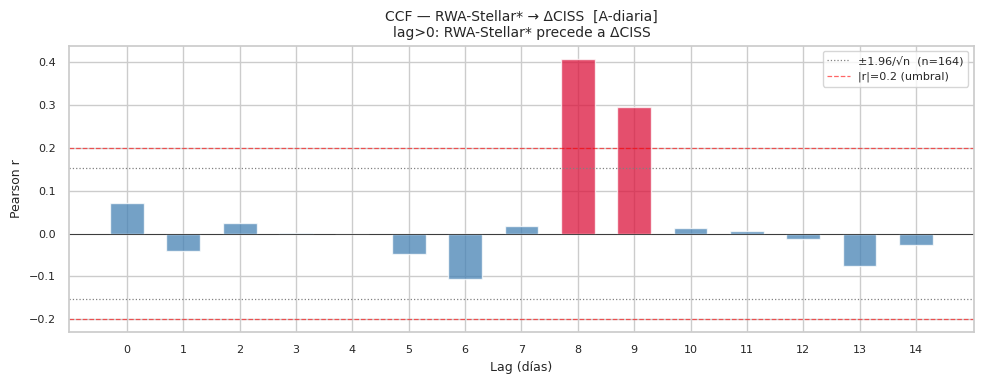

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_A_rwa_tipo_privatecredit.png


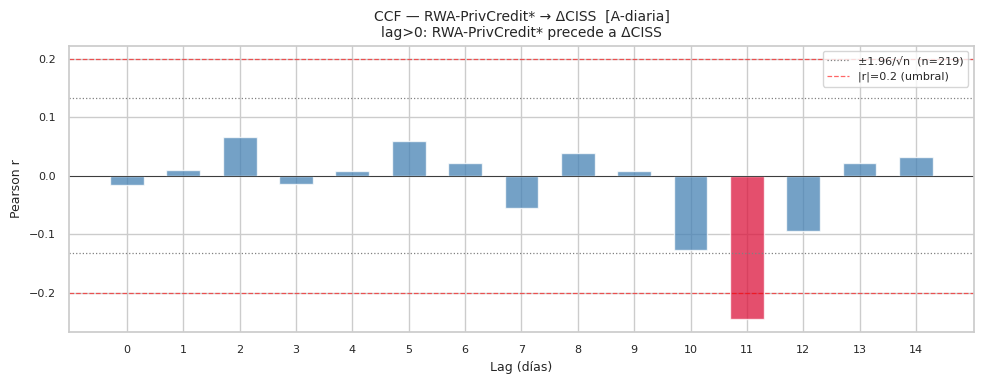

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_A_rwa_red_algorand.png


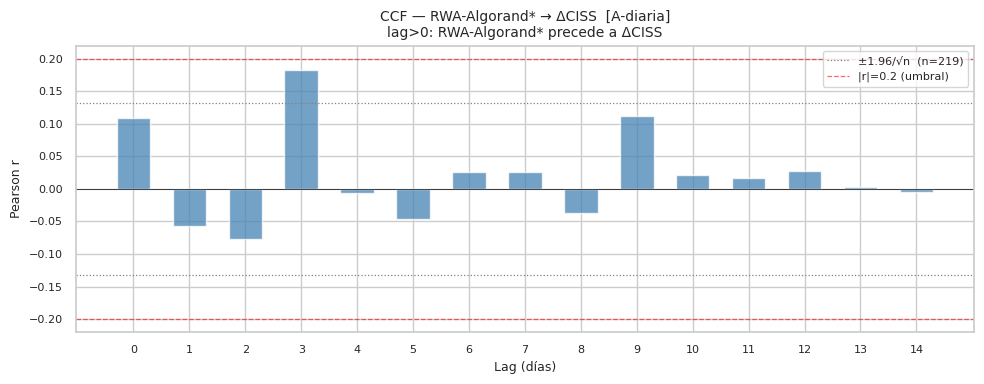

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_B_rwa_tipo_privatecredit.png


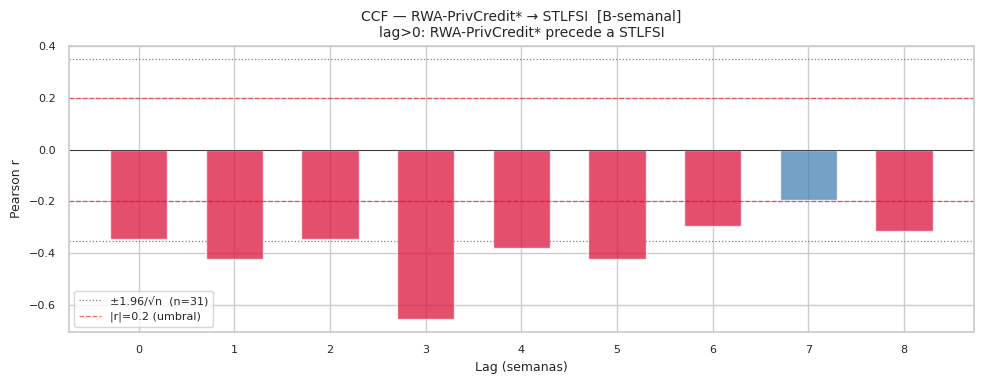

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_B_rwa_red_stellar.png


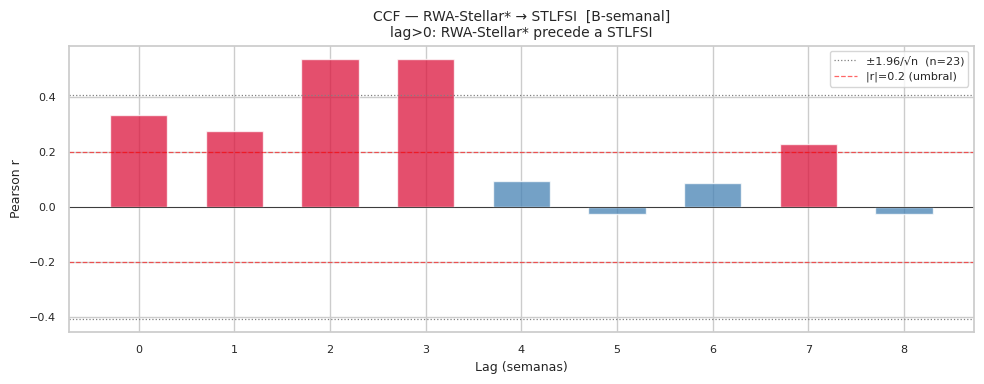

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_B_rwa_tipo_treasurybills.png


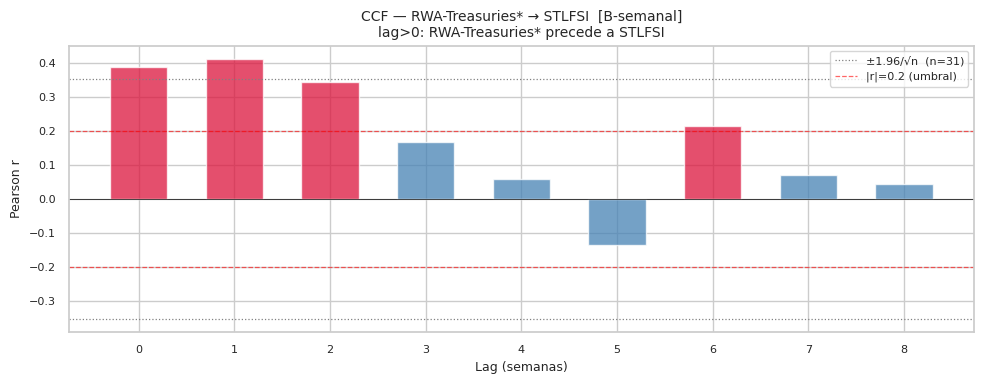


──────────────────────────────────────────────────────────────
RESUMEN — SEÑAL RWA → ESTRÉS
──────────────────────────────────────────────────────────────

Ventana analizada: 2026-01-01 → 2026-08-08 (sin recorte)

FDR (Benjamini-Hochberg) sobre el conjunto COMPLETO de tests — 2 pistas, todos los lags:
  168 tests totales | p<0.05 crudo: 12 | sobreviven BH global: 4

Pares PRECEDEN (lag>0, |r|>0.2, BH GLOBAL q<0.05): 3
    pista        etiqueta  macro  lag_optimo   r_max   bh_q   n
 A-diaria    RWA-Stellar*   CISS           8  0.4090 0.0000 156
 A-diaria RWA-PrivCredit*   CISS          11 -0.2446 0.0168 208
B-semanal RWA-PrivCredit* STLFSI           3 -0.6548 0.0112  28

Pares CONTEMPORÁNEOS (lag=0, |r|>0.2, p<0.05): 0
  → Ninguno contemporáneo.

INDICIOS NO CONFIRMADOS — dirección teórica previa (oro, treasuries), NO sobreviven el FDR global: 1
    pista        etiqueta  macro  lag_optimo  r_max  p_lag_opt   bh_q  n
B-semanal RWA-Treasuries* STLFSI           1 0.4121     0.0236 0.3965

In [4]:
"""# Job 6 - Relaciones temporales: RWA vs. estrés financiero"""


print("Job 6 - Relaciones temporales: RWA vs. estrés financiero")

# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

"""# 2. Imports"""

import os
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

# CAMBIO E2E-06-01: ruta configurable; conserva el destino original por defecto.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_relaciones_rwa"
)

ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)

# CAMBIO I4-1: se elimina el recorte fijo al 2026-07-31 (era un
# workaround puntual para un artefacto de DeFiLlama en Ripple
# que ya no se verifica) y el archivo cacheado
# series_diarias_ext_31jul.csv. FECHA_CORTE ahora es None por
# defecto: se usa la ventana completa del dataset. Si se
# completa con una fecha ISO, recortar_ventana() sigue
# recortando TODAS las columnas a la vez.
FECHA_CORTE: str | None = None

# ── Series RWA: set final de 8 (12_inventario_rwa) ───────────
# Todas son STOCKS (TVL en USD): en el resample semanal se toma
# last(), nunca sum() — sumar un stock contaría siete veces el
# mismo capital.
COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

K_DIARIO: int = 14      # lags máximos Pista A (días)
K_SEMANAL: int = 8      # lags máximos Pista B (semanas)
UMBRAL_R: float = 0.20  # piso exploratorio |r|
ALFA_BH: float = 0.05   # nivel FDR Benjamini-Hochberg
N_MIN_SEMANAS: int = 40  # bajo esto se avisa potencia baja

# Etiquetas cortas (* = caveat de adopción incipiente)
ETIQUETAS: dict[str, str] = {
    "rwa_red_stellar": "RWA-Stellar*",
    "rwa_red_ripple": "RWA-Ripple*",
    "rwa_red_algorand": "RWA-Algorand*",
    "rwa_tipo_treasurybills": "RWA-Treasuries*",
    "rwa_tipo_commodities": "RWA-Commodities*",
    "rwa_tipo_privatecredit": "RWA-PrivCredit*",
    "rwa_tipo_stocksetfs": "RWA-StocksETFs*",
    "rwa_total_global": "RWA-Total*",
}

# Series cuya relación con el estrés tiene dirección teórica
# previa (activo refugio): en un episodio de estrés se espera
# flujo HACIA oro y deuda soberana tokenizados. Se las reporta
# aparte para trazabilidad, marcadas como indicio NO confirmado
# cuando no sobreviven el FDR global.
SERIES_DIRECCION_TEORICA: list[str] = [
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
]

# Nota de adopción (se añade a todas las filas RWA de los CSVs)
NOTA_ADOPCION: str = (
    "RWA de adopción incipiente (2025-2026): dinámica dominada "
    "por crecimiento estructural, no por respuesta a estrés. "
    "Relación posiblemente por tendencia común; exploratorio."
)

sns.set_theme(style="whitegrid", palette="muted")

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


"""# 4. Funciones"""


def cargar_series(ruta: str) -> pd.DataFrame:
    """
    Carga un CSV de series con índice fecha (DatetimeIndex).

    Args:
        ruta: Ruta del CSV.

    Returns:
        DataFrame indexado por fecha.
    """
    df = pd.read_csv(
        ruta, parse_dates=["fecha"], index_col="fecha"
    )
    if DEBUG:
        print(f"[DEBUG] cargado: {df.shape} — {ruta}")
    return df


def validar_entrada_relaciones(ruta: str, job_origen: str) -> pd.DataFrame:
    """CAMBIO E2E-06-01: valida existencia, CSV y fechas, sin alterar valores.

    Cada entrada del Job 6 es una salida obligatoria del Job 3.
    No ordena, rellena, filtra, agrega ni sustituye datos.
    """
    if not os.path.isfile(ruta):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 6: falta {ruta}. "
            f"Debe generarlo el {job_origen}."
        )
    try:
        df = cargar_series(ruta)
    except Exception as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 6: no se pudo leer {ruta} "
            f"(salida del {job_origen}); revisar CSV y columna 'fecha': {exc}"
        ) from exc
    if df.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 6: entrada vacia: {ruta} "
            f"(salida del {job_origen})."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 6: fechas invalidas en {ruta}. "
            f"Revisar {job_origen}."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 6: fechas duplicadas en {ruta}. "
            "No se puede usar un indice temporal ambiguo."
        )
    if not df.index.is_monotonic_increasing:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 6: fechas desordenadas en {ruta}. "
            "No se reordena automaticamente."
        )
    return df


def recortar_ventana(
    df: pd.DataFrame,
    fecha_corte: str | None,
) -> pd.DataFrame:
    """
    Recorta el dataset a fecha <= fecha_corte, si se indica.

    El recorte se aplica a TODAS las columnas a la vez para que
    on-chain, macro y RWA cubran exactamente el mismo período.

    CAMBIO I4-1: si fecha_corte es None (default), no se recorta
    — se usa la ventana completa del dataset.

    Args:
        df: Dataset diario indexado por fecha.
        fecha_corte: Última fecha incluida (ISO), o None para no
            recortar.

    Returns:
        DataFrame recortado, o el mismo dataset si fecha_corte
        es None.
    """
    if fecha_corte is None:
        if DEBUG:
            print(f"[DEBUG] sin recorte: ventana completa ({len(df)} filas)")
        return df
    corte = pd.Timestamp(fecha_corte)
    recortado = df.loc[df.index <= corte].copy()
    recortado.index.name = "fecha"
    if DEBUG:
        n_fuera = len(df) - len(recortado)
        print(
            f"[DEBUG] recorte <= {fecha_corte}: "
            f"{len(df)} → {len(recortado)} filas "
            f"({n_fuera} descartadas)"
        )
    return recortado


def _log_diff(serie: pd.Series) -> pd.Series:
    """
    Log-diferencia segura: los valores <= 0 pasan a NaN antes
    del logaritmo, evitando -inf en el cálculo.

    Args:
        serie: Serie de nivel.

    Returns:
        Serie de log-diferencias.
    """
    return np.log(serie.where(serie > 0)).diff()


def _par_corr(
    x: pd.Series,
    y: pd.Series,
    lag: int,
    metodo: str = "pearson",
) -> tuple[float, float, int]:
    """
    Correlación de x adelantado `lag` períodos con y.

    lag>0: x[t-lag] correlaciona con y[t] → x precede a y.
    Alinea por índice (concat → dropna), así que funciona
    aunque x e y tengan ventanas distintas.

    Args:
        x: Serie explicativa (RWA transformada).
        y: Serie objetivo (índice de estrés transformado).
        lag: Desplazamiento en períodos.
        metodo: "pearson" o "spearman".

    Returns:
        (r, p, n). r y p son NaN si n < 10.
    """
    x_lead = x.shift(lag) if lag > 0 else x
    xy = pd.concat(
        [x_lead.rename("x"), y.rename("y")], axis=1
    ).dropna()
    n = len(xy)
    if n < 10:
        return float("nan"), float("nan"), n
    xi, yi = xy["x"].values, xy["y"].values
    try:
        if metodo == "pearson":
            r, p = pearsonr(xi, yi)
        else:
            r, p = spearmanr(xi, yi)
        return float(r), float(p), n
    except Exception:
        return float("nan"), float("nan"), n


def transformar_pista_a(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista A — diaria:
      · Las 8 RWA → log-diferencia diaria.
      · CISS → primera diferencia diaria.

    Args:
        df: Dataset diario ya recortado.

    Returns:
        (series_x, serie_y) con las RWA transformadas y ΔCISS.
    """
    series_x: dict[str, pd.Series] = {}
    for col in COLS_RWA:
        if col not in df.columns:
            if DEBUG:
                print(f"[DEBUG] A: {col} ausente — se omite")
            continue
        series_x[col] = _log_diff(df[col]).dropna()

    if COL_CISS not in df.columns:
        raise ValueError(f"{COL_CISS} no está en el dataset")
    serie_y = df[COL_CISS].diff().dropna()

    if DEBUG:
        for col, s in series_x.items():
            print(
                f"[DEBUG] A-x {ETIQUETAS.get(col, col)}: "
                f"{len(s)} obs"
            )
        print(f"[DEBUG] A-y ΔCISS: {len(serie_y)} obs")
    return series_x, serie_y


def transformar_pista_b(
    df: pd.DataFrame,
    df_lrg: pd.DataFrame | None,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista B — semanal:
      · Las 8 RWA → resample W last() (son stocks: el TVL de
        cierre de la semana) → log-diferencia.
      · STLFSI → nivel semanal nativo (de series_largas_ext si
        está disponible; si no, del dataset diario).

    Args:
        df: Dataset diario ya recortado.
        df_lrg: Dataset de series largas (o None).

    Returns:
        (series_x, serie_y) semanales.
    """
    series_x: dict[str, pd.Series] = {}
    for col in COLS_RWA:
        if col not in df.columns:
            continue
        series_x[col] = _log_diff(
            df[col].resample("W").last()
        ).dropna()

    if df_lrg is not None and COL_STLFSI in df_lrg.columns:
        fuente = df_lrg[COL_STLFSI]
        origen = "series_largas_ext"
    elif COL_STLFSI in df.columns:
        fuente = df[COL_STLFSI]
        origen = "series_diarias_ext (ffill)"
    else:
        raise ValueError(f"{COL_STLFSI} no disponible")
    # El recorte también aplica al target, para comparar el
    # mismo período en ambas pistas.
    # CAMBIO B2-2 (Bloque 2): con FECHA_CORTE=None, pd.Timestamp(None)
    # es NaT y la comparación daba todo False: Pista B quedaba con 0
    # semanas. Se recorta solo si hay fecha de corte (como en
    # recortar_ventana).
    if FECHA_CORTE is not None:
        fuente = fuente.loc[fuente.index <= pd.Timestamp(FECHA_CORTE)]
    stlfsi_sem = fuente.resample("W").last().dropna()

    if DEBUG:
        for col, s in series_x.items():
            print(
                f"[DEBUG] B-x {ETIQUETAS.get(col, col)}: "
                f"{len(s)} obs"
            )
        print(
            f"[DEBUG] B-y STLFSI (nivel sem., {origen}): "
            f"{len(stlfsi_sem)} obs"
        )
    return series_x, stlfsi_sem


def analizar_contemporaneo(
    series_x: dict[str, pd.Series],
    serie_y: pd.Series,
    nombre_macro: str,
    pista: str,
) -> pd.DataFrame:
    """
    Correlación contemporánea (lag=0): Pearson y Spearman para
    cada par (RWA, macro).

    Args:
        series_x: Series RWA transformadas.
        serie_y: Serie macro transformada.
        nombre_macro: Nombre del índice ("CISS"/"STLFSI").
        pista: Etiqueta de pista.

    Returns:
        DataFrame con una fila por par.
    """
    filas: list[dict] = []
    for col, sx in series_x.items():
        rp, pp, n = _par_corr(sx, serie_y, 0, "pearson")
        rs, ps, _ = _par_corr(sx, serie_y, 0, "spearman")
        filas.append({
            "pista": pista,
            "serie_x": col,
            "etiqueta": ETIQUETAS.get(col, col),
            "macro": nombre_macro,
            "n": n,
            "pearson_r": (
                round(rp, 4) if np.isfinite(rp) else None
            ),
            "pearson_p": (
                round(pp, 4) if np.isfinite(pp) else None
            ),
            "spearman_r": (
                round(rs, 4) if np.isfinite(rs) else None
            ),
            "spearman_p": (
                round(ps, 4) if np.isfinite(ps) else None
            ),
            "nota": NOTA_ADOPCION,
        })
    return pd.DataFrame(filas)


def analizar_lags(
    series_x: dict[str, pd.Series],
    serie_y: pd.Series,
    nombre_macro: str,
    K: int,
    pista: str,
) -> pd.DataFrame:
    """
    Correlación cruzada Pearson para lag k=0..K.

    En cada fila: serie_x[t-k] correlaciona con macro[t]; k>0
    significa que la RWA precede al índice de estrés.

    Args:
        series_x: Series RWA transformadas.
        serie_y: Serie macro transformada.
        nombre_macro: Nombre del índice.
        K: Lag máximo.
        pista: Etiqueta de pista.

    Returns:
        DataFrame con una fila por (serie, lag).
    """
    filas: list[dict] = []
    for col, sx in series_x.items():
        for k in range(K + 1):
            r, p, n = _par_corr(sx, serie_y, k, "pearson")
            filas.append({
                "pista": pista,
                "serie_x": col,
                "etiqueta": ETIQUETAS.get(col, col),
                "macro": nombre_macro,
                "lag": k,
                "n": n,
                "pearson_r": (
                    round(r, 4) if np.isfinite(r) else None
                ),
                "pearson_p": (
                    round(p, 4) if np.isfinite(p) else None
                ),
                "nota": NOTA_ADOPCION,
            })
    return pd.DataFrame(filas)


def lag_optimo_por_par(df_lags: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada (pista, serie_x, macro): el lag de máxima |r| y
    sus estadísticos asociados.

    IMPORTANTE: debe recibir la tabla de lags YA CONSOLIDADA y
    con el FDR global aplicado. Las columnas bh_q y bh_rechaza
    del lag elegido se arrastran tal cual, de modo que la
    significancia de cada par es siempre la del ajuste sobre el
    conjunto completo de tests, nunca la de un subconjunto.

    Args:
        df_lags: Tabla consolidada de correlaciones por lag,
            con bh_q / bh_rechaza globales.

    Returns:
        DataFrame con una fila por par.
    """
    filas: list[dict] = []
    grupos = df_lags.groupby(
        ["pista", "serie_x", "macro"], sort=False
    )
    for (pista, sx, macro), grp in grupos:
        grp_v = grp.dropna(subset=["pearson_r"])
        if grp_v.empty:
            continue
        idx_max = grp_v["pearson_r"].abs().idxmax()
        fila = grp_v.loc[idx_max]
        filas.append({
            "pista": pista,
            "serie_x": sx,
            "etiqueta": ETIQUETAS.get(sx, sx),
            "macro": macro,
            "lag_optimo": int(fila["lag"]),
            "r_max": round(float(fila["pearson_r"]), 4),
            "p_lag_opt": round(float(fila["pearson_p"]), 4),
            "n": int(fila["n"]),
            # BH global del lag elegido (no se recalcula)
            "bh_q": fila.get("bh_q", np.nan),
            "bh_rechaza": bool(fila.get("bh_rechaza", False)),
            "ambito_bh": str(fila.get("ambito_bh", "")),
            "nota": str(fila.get("nota", "")),
        })
    return pd.DataFrame(filas)


def aplicar_bh(
    df: pd.DataFrame,
    col_p: str,
    alfa: float = ALFA_BH,
    col_q: str = "bh_q",
    col_rechaza: str = "bh_rechaza",
) -> pd.DataFrame:
    """
    Corrección Benjamini-Hochberg (FDR) sobre col_p.

    Los nombres de las columnas de salida son parametrizables
    para poder guardar en la misma tabla el ajuste por pista y
    el ajuste global sobre todos los tests.

    Args:
        df: Tabla con p-values.
        col_p: Columna de p-values.
        alfa: Nivel de FDR.
        col_q: Nombre de la columna de q-valores.
        col_rechaza: Nombre de la columna booleana.

    Returns:
        Copia del DataFrame con las dos columnas añadidas.
    """
    df = df.copy().reset_index(drop=True)
    df[col_q] = np.nan
    df[col_rechaza] = False
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, col_q] = np.round(adj, 4)
    df.loc[validos, col_rechaza] = rechaza
    return df


def clasificar_precedencia(df_opt: pd.DataFrame) -> pd.DataFrame:
    """
    Clasifica cada par según su señal de precedencia.

    La significancia se lee SIEMPRE de bh_rechaza, que proviene
    del FDR aplicado sobre el conjunto completo de tests de
    ambas pistas. Un par no puede clasificarse como señal por
    haber sobrevivido un ajuste sobre un subconjunto.

    Clases:
      · 'precede (sig BH global)' — lag>0, |r|>umbral y
        sobrevive el FDR global.
      · 'contemporaneo (sig)'     — lag=0, |r|>umbral, p crudo
        <alfa. Sin BH: es una única comparación por par.
      · 'indicio no confirmado'   — lag>0, |r|>umbral, en una
        serie con dirección teórica previa, pero NO sobrevive
        el FDR global. Se reporta para trazabilidad; NO es
        señal.
      · 'precede (no sig)'        — lag>0, |r|>umbral, sin
        significancia ni dirección teórica previa.
      · 'no_sig'                  — el resto.

    Args:
        df_opt: Tabla de lags óptimos con el BH global
            arrastrado desde la tabla de lags consolidada.

    Returns:
        DataFrame con la columna 'precedencia'.
    """
    df = df_opt.copy()
    lag = df["lag_optimo"]
    r_abs = df["r_max"].abs()
    bh_ok = df["bh_rechaza"].fillna(False).astype(bool)
    p_raw = pd.to_numeric(df["p_lag_opt"], errors="coerce")
    teorica = df["serie_x"].isin(SERIES_DIRECCION_TEORICA)

    cond_pre_sig = (lag > 0) & (r_abs > UMBRAL_R) & bh_ok
    cond_cont = (
        (lag == 0) & (r_abs > UMBRAL_R) & (p_raw < ALFA_BH)
    )
    cond_pre_deb = (lag > 0) & (r_abs > UMBRAL_R) & ~bh_ok
    cond_indicio = cond_pre_deb & teorica

    estado = pd.Series("no_sig", index=df.index)
    estado.loc[cond_pre_deb] = "precede (no sig)"
    estado.loc[cond_indicio] = "indicio no confirmado"
    estado.loc[cond_cont] = "contemporaneo (sig)"
    estado.loc[cond_pre_sig] = "precede (sig BH global)"
    df["precedencia"] = estado
    return df


def _top_pares(
    df_opt: pd.DataFrame,
    series_dict: dict[str, pd.Series],
    n: int = 3,
) -> list[str]:
    """
    Series RWA con mayor |r_max| entre las que tienen datos.

    Args:
        df_opt: Tabla de lags óptimos.
        series_dict: Series disponibles de esa pista.
        n: Cuántas devolver.

    Returns:
        Lista de nombres de columna.
    """
    if df_opt.empty:
        return []
    sub = (
        df_opt[df_opt["serie_x"].isin(series_dict)]
        .dropna(subset=["r_max"])
        .sort_values(
            "r_max", key=lambda x: x.abs(), ascending=False
        )
    )
    return sub["serie_x"].head(n).tolist()


def plot_ccf(
    serie_x: pd.Series,
    serie_y: pd.Series,
    K: int,
    nombre_x: str,
    nombre_y: str,
    pista: str,
    ruta: str,
) -> None:
    """
    Correlograma cruzado: r(k) para k=0..K.

    k>0 → serie_x precede a serie_y. Bandas: ±1.96/√n
    (asintótica) y ±UMBRAL_R (referencia exploratoria).

    Args:
        serie_x: Serie RWA transformada.
        serie_y: Serie macro transformada.
        K: Lag máximo.
        nombre_x: Etiqueta de la RWA.
        nombre_y: Etiqueta del macro.
        pista: Etiqueta de pista (define la unidad del eje).
        ruta: Ruta del PNG.
    """
    lags = list(range(K + 1))
    corrs: list[float] = []
    n0 = 0
    for k in lags:
        r, _, n = _par_corr(serie_x, serie_y, k, "pearson")
        corrs.append(r if np.isfinite(r) else 0.0)
        if k == 0:
            n0 = n

    conf = 1.96 / np.sqrt(max(n0, 1))
    unidad = "días" if pista.startswith("A") else "semanas"

    fig, ax = plt.subplots(figsize=(10, 4))
    colores = [
        "crimson" if abs(c) > UMBRAL_R else "steelblue"
        for c in corrs
    ]
    ax.bar(lags, corrs, color=colores, alpha=0.75, width=0.6)
    ax.axhline(
        conf, color="grey", lw=0.9, ls=":",
        label=f"±1.96/√n  (n={n0})",
    )
    ax.axhline(-conf, color="grey", lw=0.9, ls=":")
    ax.axhline(
        UMBRAL_R, color="red", lw=0.9, ls="--", alpha=0.6,
        label=f"|r|={UMBRAL_R} (umbral)",
    )
    ax.axhline(
        -UMBRAL_R, color="red", lw=0.9, ls="--", alpha=0.6
    )
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(
        f"CCF — {nombre_x} → {nombre_y}  [{pista}]\n"
        f"lag>0: {nombre_x} precede a {nombre_y}",
        fontsize=10,
    )
    ax.set_xlabel(f"Lag ({unidad})", fontsize=9)
    ax.set_ylabel("Pearson r", fontsize=9)
    ax.set_xticks(lags)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    if SAVE_DATA:
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        plt.savefig(ruta, dpi=150, bbox_inches="tight")
        if DEBUG:
            print(f"[DEBUG] figura: {ruta}")
    plt.show()
    plt.close()


"""# 5. Proceso"""

# CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
verificar_entradas_snapshot([ARCHIVO_DIARIAS, ARCHIVO_LARGAS], "Job 6")

# ── Carga de datos ──────────────────────────────────────────
# CAMBIO E2E-06-01: las dos entradas las produce el Job 3.
# No se continua con una entrada larga ausente o ilegitima,
# porque el fallback silencioso puede alterar la fuente de STLFSI.
df_full = validar_entrada_relaciones(ARCHIVO_DIARIAS, "Job 3")
df_lrg = validar_entrada_relaciones(ARCHIVO_LARGAS, "Job 3")

# Contrato de columnas: Ripple y otras RWA pueden estar ausentes;
# no se crean ni imputan columnas. Los dos targets deben existir
# en alguna de las fuentes que el codigo original consulta.
if COL_CISS not in df_full.columns:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 6: falta {COL_CISS} en "
        f"{ARCHIVO_DIARIAS} (Job 3)."
    )
# CAMBIO B2-3 (Bloque 2): rwa_red_ripple sale de COLS_RWA si no
# existe en los datos (columna ausente o sin ningún valor). Se
# decide por existencia, no por resultados; se informa en el log.
_COL_RIPPLE = "rwa_red_ripple"
if _COL_RIPPLE in COLS_RWA and (
    _COL_RIPPLE not in df_full.columns or df_full[_COL_RIPPLE].notna().sum() == 0
):
    for _lista in (COLS_RWA,):
        if _COL_RIPPLE in _lista:
            _lista.remove(_COL_RIPPLE)
    print(
        f"[DEBUG][ALERTA] Job 6: {_COL_RIPPLE} sin datos en "
        f"{os.path.basename(ARCHIVO_DIARIAS)}: se quita de COLS_RWA "
        f"({len(COLS_RWA)} series RWA)."
    )
elif DEBUG:
    print(f"[DEBUG] Job 6: {_COL_RIPPLE} presente, queda en COLS_RWA")

if not any(col in df_full.columns for col in COLS_RWA):
    raise RuntimeError(
        "[DEBUG][ERROR] Job 6: series_diarias_ext.csv no tiene "
        "ninguna de las columnas RWA configuradas. Revisar Job 3."
    )
if COL_STLFSI not in df_lrg.columns and COL_STLFSI not in df_full.columns:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 6: falta {COL_STLFSI} en "
        "series_largas_ext.csv y series_diarias_ext.csv. Revisar Job 3."
    )

# CAMBIO I4-1: se elimina la verificación del artefacto de
# Ripple (ya no se recorta por defecto — FECHA_CORTE=None).
if DEBUG:
    print("\n[DEBUG] ══ VENTANA DE ANÁLISIS ══")

df: pd.DataFrame = recortar_ventana(df_full, FECHA_CORTE)

# CAMBIO E2E-06-01: evitar .date() sobre NaT con ventana vacia.
if df.empty:
    raise RuntimeError(
        "[DEBUG][ERROR] Job 6: la ventana de analisis quedo vacia "
        f"tras aplicar FECHA_CORTE={FECHA_CORTE!r}."
    )

if DEBUG:
    print(
        f"[DEBUG] ventana de análisis: "
        f"{df.index.min().date()} → {df.index.max().date()} "
        f"({len(df)} días, {df.shape[1]} columnas)"
    )

# Inicializar DataFrames por si una pista falla
df_cont_a = df_lags_a = df_opt_a = pd.DataFrame()
df_cont_b = df_lags_b = df_opt_b = pd.DataFrame()
sx_a: dict[str, pd.Series] = {}
sx_b: dict[str, pd.Series] = {}
sy_a: pd.Series = pd.Series(dtype=float)
sy_b: pd.Series = pd.Series(dtype=float)

# ── PISTA A: diaria — RWA log-dif vs ΔCISS ──────────────────
if DEBUG:
    print("\n[DEBUG] ══ PISTA A: DIARIA (RWA vs ΔCISS) ══")
try:
    sx_a, sy_a = transformar_pista_a(df)

    df_cont_a = analizar_contemporaneo(
        sx_a, sy_a, "CISS", "A-diaria"
    )
    df_lags_a = analizar_lags(
        sx_a, sy_a, "CISS", K_DIARIO, "A-diaria"
    )
    # El FDR NO se aplica acá: se aplica una sola vez, más
    # abajo, sobre las dos pistas juntas. Un ajuste por pista
    # sobreestimaría la significancia.
    if DEBUG:
        _cols = [
            "etiqueta", "n", "pearson_r", "pearson_p",
            "spearman_r", "spearman_p",
        ]
        print("\n[DEBUG] Contemporánea Pista A:")
        print(df_cont_a[_cols].to_string(index=False))
        print(
            f"[DEBUG] tests de lags Pista A: {len(df_lags_a)}"
        )
except Exception as _exc:
    # CAMBIO E2E-06-01: una falla de calculo no se presenta como
    # "sin señal" ni habilita CSV parciales.
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 6: fallo la Pista A: {_exc}"
    ) from _exc

# ── PISTA B: semanal — RWA log-dif sem. vs STLFSI ───────────
if DEBUG:
    print("\n[DEBUG] ══ PISTA B: SEMANAL (RWA vs STLFSI) ══")
try:
    sx_b, sy_b = transformar_pista_b(df, df_lrg)

    _n_sem = len(sy_b)
    if _n_sem < N_MIN_SEMANAS:
        print(
            f"[RWA] AVISO: Pista B con {_n_sem} semanas "
            f"(< {N_MIN_SEMANAS}) — potencia estadística baja; "
            "resultados orientativos únicamente."
        )

    df_cont_b = analizar_contemporaneo(
        sx_b, sy_b, "STLFSI", "B-semanal"
    )
    df_lags_b = analizar_lags(
        sx_b, sy_b, "STLFSI", K_SEMANAL, "B-semanal"
    )
    # Igual que en la Pista A: el FDR es global, no por pista.
    if DEBUG:
        _cols = [
            "etiqueta", "n", "pearson_r", "pearson_p",
            "spearman_r", "spearman_p",
        ]
        print("\n[DEBUG] Contemporánea Pista B:")
        print(df_cont_b[_cols].to_string(index=False))
        print(
            f"[DEBUG] tests de lags Pista B: {len(df_lags_b)}"
        )
except Exception as _exc:
    # CAMBIO E2E-06-01: no ocultar fallas en la Pista B.
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 6: fallo la Pista B: {_exc}"
    ) from _exc

# ── Tablas consolidadas y FDR GLOBAL (único ajuste) ─────────
# El universo de tests es: 8 RWA × 2 macro × (K+1) lags de cada
# pista. La corrección Benjamini-Hochberg se aplica UNA sola vez
# sobre ese conjunto completo. Aplicarla por pista (8 tests) o
# por par inflaría la significancia: con ~200 tests, varios
# p<0.05 aparecen por azar.
df_cont: pd.DataFrame = pd.concat(
    [df_cont_a, df_cont_b], ignore_index=True
)
if not df_cont.empty:
    df_cont = aplicar_bh(df_cont, "pearson_p")
    df_cont["ambito_bh"] = "contemporaneas (lag=0, 2 pistas)"

df_lags: pd.DataFrame = pd.concat(
    [df_lags_a, df_lags_b], ignore_index=True
)

n_tests_global: int = 0
n_sig_crudo: int = 0
n_sig_bh_global: int = 0

if not df_lags.empty:
    df_lags = aplicar_bh(df_lags, "pearson_p")
    df_lags["ambito_bh"] = (
        "global: 2 pistas × todos los lags"
    )
    _p = pd.to_numeric(df_lags["pearson_p"], errors="coerce")
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh_global = int(
        df_lags["bh_rechaza"].fillna(False).astype(bool).sum()
    )
    if DEBUG:
        print(
            f"\n[DEBUG] FDR GLOBAL — {n_tests_global} tests | "
            f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
            f"sobreviven BH: {n_sig_bh_global}"
        )

# Lag óptimo por par: arrastra el BH GLOBAL del lag elegido
df_opt: pd.DataFrame = pd.DataFrame()
if not df_lags.empty:
    df_opt = lag_optimo_por_par(df_lags)
    df_opt = clasificar_precedencia(df_opt)

df_opt_a = (
    df_opt[df_opt["pista"] == "A-diaria"]
    if not df_opt.empty else pd.DataFrame()
)
df_opt_b = (
    df_opt[df_opt["pista"] == "B-semanal"]
    if not df_opt.empty else pd.DataFrame()
)

if DEBUG and not df_opt.empty:
    _cols2 = [
        "pista", "etiqueta", "macro", "lag_optimo", "r_max",
        "p_lag_opt", "bh_q", "bh_rechaza", "precedencia",
    ]
    print("\n[DEBUG] Lag óptimo por par (BH global):")
    print(df_opt[_cols2].to_string(index=False))

# ── Figuras: CCF top-3 por pista ────────────────────────────
if DEBUG:
    print("\n[DEBUG] ══ FIGURAS CCF ══")

try:
    for _col in _top_pares(df_opt_a, sx_a, n=3):
        plot_ccf(
            sx_a[_col], sy_a, K_DIARIO,
            ETIQUETAS.get(_col, _col), "ΔCISS", "A-diaria",
            os.path.join(DIR_FIGURAS, f"ccf_A_{_col}.png"),
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] CCF Pista A falló: {_exc}")

try:
    for _col in _top_pares(df_opt_b, sx_b, n=3):
        plot_ccf(
            sx_b[_col], sy_b, K_SEMANAL,
            ETIQUETAS.get(_col, _col), "STLFSI", "B-semanal",
            os.path.join(DIR_FIGURAS, f"ccf_B_{_col}.png"),
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] CCF Pista B falló: {_exc}")

# ── RESUMEN — ¿las RWA entran al modelo? ────────────────────
print("\n" + "─" * 62)
print("RESUMEN — SEÑAL RWA → ESTRÉS")
print("─" * 62)
try:
    print(
        f"\nVentana analizada: {df.index.min().date()} → "
        f"{df.index.max().date()} "
        f"({'recorte en ' + FECHA_CORTE if FECHA_CORTE else 'sin recorte'})"
    )
    # Línea de comparaciones múltiples: es el dato que decide.
    print(
        f"\nFDR (Benjamini-Hochberg) sobre el conjunto COMPLETO "
        f"de tests — 2 pistas, todos los lags:"
    )
    print(
        f"  {n_tests_global} tests totales | "
        f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
        f"sobreviven BH global: {n_sig_bh_global}"
    )

    if df_opt.empty:
        print("  [!] Sin datos para resumir")
    else:
        _pre = df_opt[
            df_opt["precedencia"] == "precede (sig BH global)"
        ]
        _con = df_opt[
            df_opt["precedencia"] == "contemporaneo (sig)"
        ]
        _ind = df_opt[
            df_opt["precedencia"] == "indicio no confirmado"
        ]
        _deb = df_opt[
            df_opt["precedencia"] == "precede (no sig)"
        ]

        print(
            f"\nPares PRECEDEN (lag>0, |r|>{UMBRAL_R}, "
            f"BH GLOBAL q<{ALFA_BH}): {len(_pre)}"
        )
        if not _pre.empty:
            _c = [
                "pista", "etiqueta", "macro",
                "lag_optimo", "r_max", "bh_q", "n",
            ]
            print(_pre[_c].to_string(index=False))
        else:
            print(
                "  → Ninguno sobrevive la corrección global."
            )

        print(
            f"\nPares CONTEMPORÁNEOS (lag=0, |r|>{UMBRAL_R}, "
            f"p<{ALFA_BH}): {len(_con)}"
        )
        if not _con.empty:
            _c = [
                "pista", "etiqueta", "macro",
                "r_max", "p_lag_opt", "n",
            ]
            print(_con[_c].to_string(index=False))
        else:
            print("  → Ninguno contemporáneo.")

        # Trazabilidad: dirección teórica previa (refugio),
        # explícitamente NO presentados como señal.
        print(
            f"\nINDICIOS NO CONFIRMADOS — dirección teórica "
            f"previa (oro, treasuries), NO sobreviven el FDR "
            f"global: {len(_ind)}"
        )
        if not _ind.empty:
            _c = [
                "pista", "etiqueta", "macro", "lag_optimo",
                "r_max", "p_lag_opt", "bh_q", "n",
            ]
            print(_ind[_c].to_string(index=False))
            print(
                "  → Se registran para trazabilidad y para "
                "orientar el test de Granger. NO constituyen "
                "evidencia de señal."
            )
        else:
            print("  → Ninguno.")

        print(
            f"\nOtros pares con |r|>{UMBRAL_R} y lag>0, sin "
            f"significancia: {len(_deb)}"
        )
        if not _deb.empty:
            _c = [
                "pista", "etiqueta", "macro", "lag_optimo",
                "r_max", "p_lag_opt", "bh_q",
            ]
            print(_deb[_c].to_string(index=False))

        # ── VEREDICTO ───────────────────────────────────────
        # Se basa EXCLUSIVAMENTE en el FDR global. Si nada
        # sobrevive, no se afirma señal, por más que existan
        # pares con |r| alto o con dirección teórica esperada.
        # CAMBIO B3-1 (Bloque 3): cada frase sale de una condición
        # sobre las cifras. Antes: "Las RWA son candidatas" aunque
        # sobrevivieran 3/105 tests, la rama contemporánea era
        # inalcanzable y se afirmaba una comparación con las
        # on-chain que este Job no calcula.
        print("\n" + "─" * 62)
        _esperados_azar = n_tests_global * ALFA_BH
        if _pre.empty:
            print(
                "VEREDICTO: no hay precedencia RWA→estrés que "
                "sobreviva la corrección por comparaciones "
                "múltiples."
            )
            _frase_azar = (
                "en línea con lo esperable por azar"
                if n_sig_crudo <= _esperados_azar
                else "por encima de lo esperable por azar, pero "
                "ninguno sobrevive el FDR"
            )
            print(
                f"De {n_tests_global} tests, {n_sig_crudo} dan "
                f"p<{ALFA_BH} crudo (≈{_esperados_azar:.1f} "
                f"esperables por azar: {_frase_azar}) y "
                f"{n_sig_bh_global} sobreviven el FDR global."
            )
            if not _ind.empty:
                _etqs = ", ".join(sorted(set(_ind["etiqueta"])))
                print(
                    f"Los pares en dirección teórica ({_etqs}) "
                    "se reportan como INDICIOS NO CONFIRMADOS, a "
                    "validar con Granger; no como señal."
                )
            if not _con.empty:
                print(
                    f"Hay {len(_con)} par(es) con correlación "
                    "contemporánea significativa: aporte "
                    "descriptivo, no predictivo."
                )
        else:
            _etqs_pre = ", ".join(
                f"{_r.etiqueta}→{_r.macro} ({_r.pista})"
                for _r in _pre.itertuples()
            )
            _n_rwa_pre = _pre["etiqueta"].nunique()
            _n_rwa_tot = df_opt["etiqueta"].nunique()
            print(
                f"VEREDICTO: {len(_pre)} de {len(df_opt)} pares "
                f"({n_sig_bh_global} de {n_tests_global} tests) "
                "muestran precedencia RWA→estrés que sobrevive el "
                f"FDR GLOBAL: {_etqs_pre}."
            )
            print(
                f"Solo esas {_n_rwa_pre} de {_n_rwa_tot} series "
                "RWA son candidatas a entrar al modelo final; el "
                "resto no muestra precedencia."
            )
            print(
                "AVISO: el lag óptimo se eligió post-hoc → los "
                "p-values están sesgados a la baja. Confirmar "
                "con Granger multivariado antes de concluir."
            )
        print(
            "\nRECORDATORIO: series de adopción incipiente. Toda "
            "relación detectada puede reflejar tendencia común "
            "de crecimiento, no un mecanismo económico. "
            "Resultados EXPLORATORIOS."
        )
        print("─" * 62)
except Exception as _exc:
    print(f"  [DEBUG] Resumen falló: {_exc}")

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)

    # CAMBIO E2E-06-01: siempre publicar los CSV de ESTA corrida.
    # Una tabla sin filas se guarda con encabezados explicitos;
    # no se reciclan resultados anteriores ni se inventan datos.
    # Las tablas no vacias se guardan sin ninguna transformacion.
    _esquemas_vacios: list[tuple[str, pd.DataFrame, list[str]]] = [
        (
            "relaciones_rwa_contemporaneas.csv", df_cont,
            ["pista", "serie_x", "etiqueta", "macro", "n",
             "pearson_r", "pearson_p", "spearman_r", "spearman_p",
             "nota", "bh_q", "bh_rechaza", "ambito_bh"],
        ),
        (
            "relaciones_rwa_lags.csv", df_lags,
            ["pista", "serie_x", "etiqueta", "macro", "lag", "n",
             "pearson_r", "pearson_p", "nota", "bh_q",
             "bh_rechaza", "ambito_bh"],
        ),
        (
            "relaciones_rwa_lag_optimo.csv", df_opt,
            ["pista", "serie_x", "etiqueta", "macro", "lag_optimo",
             "r_max", "p_lag_opt", "n", "bh_q", "bh_rechaza",
             "ambito_bh", "nota", "precedencia"],
        ),
    ]
    for _nombre, _tabla, _columnas in _esquemas_vacios:
        _salida = _tabla if not _tabla.empty else pd.DataFrame(columns=_columnas)
        _ruta = os.path.join(DIR_REPORTES, _nombre)
        _salida.to_csv(_ruta, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {_ruta} ({len(_salida)} filas)")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")



# Job 7 - Modelos de Línea de Base FINAL (on-chain + RWA)

In [5]:
"""# Job 7 - Modelos de Línea de Base FINAL (on-chain + RWA)"""


print("Job 7 - Modelos de Línea de Base FINAL (on-chain + RWA)")

# 1. Configuración
DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import os
import warnings

import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.ar_model import AutoReg

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

# CAMBIO E2E-07-01: ruta configurable; valor predeterminado original.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_EXT: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_PRED: str = os.path.join(
    DIR_REPORTES, "predicciones_final.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_modelos_final.csv"
)
ARCHIVO_COEF: str = os.path.join(
    DIR_REPORTES, "coeficientes_lasso_final.csv"
)

# CAMBIO I4-2: se elimina el archivo cacheado
# series_diarias_ext_31jul.csv y el recorte fijo al 2026-07-31
# (artefacto de Ripple en DeFiLlama, ya no se verifica — ver
# Job 4). FECHA_CORTE=None usa la ventana completa; si se
# completa con una fecha ISO, recorta todas las columnas a la
# vez (ver cargar_dataset_ventana).
FECHA_CORTE: str | None = None

# ── Features ────────────────────────────────────────────────
COLS_FLUJO: list[str] = [
    "onchain_xlm_txcnt", "onchain_xlm_feetot",
    "onchain_xrp_txcnt", "onchain_xrp_feetot",
    "onchain_algo_txcnt", "onchain_algo_feetot",
]
COLS_STOCK: list[str] = [
    "onchain_xlm_adract",
    "onchain_xrp_adract",
    "onchain_algo_adract",
]
COLS_ONCHAIN: list[str] = COLS_FLUJO + COLS_STOCK
COL_USDY: str = "rwa_usdy_supply"

COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]

# Foco de interés: activo refugio (indicios NO confirmados)
COLS_RWA_FOCO: list[str] = [
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
]

# Bloque on-chain "histórico" = 9 métricas de red + USDY
COLS_BLOQUE_ONCHAIN: list[str] = COLS_ONCHAIN + [COL_USDY]
COLS_FEATURES: list[str] = COLS_BLOQUE_ONCHAIN + COLS_RWA

# Ablación: qué features entran en cada corrida
GRUPOS_FEATURES: dict[str, list[str]] = {
    "onchain": COLS_BLOQUE_ONCHAIN,
    "rwa": COLS_RWA,
    "todas": COLS_FEATURES,
}

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# Todas las RWA son STOCKS (TVL): resample semanal con last()
COLS_STOCK_SEMANAL: list[str] = (
    COLS_STOCK + [COL_USDY] + COLS_RWA
)

# Lags de features (K modesto por n corto)
K_FEAT_A: int = 7   # Pista A diaria
K_FEAT_B: int = 4   # Pista B semanal

# Tamaño del conjunto de test
N_TEST_DIAS: int = 56    # ~8 semanas
N_TEST_SEM: int = 8      # semanas

# Parámetros AR del target solo
# CAMBIO H4 (documentación, sin cambio de comportamiento):
# Jobs 9/10 usan un único AR_LAGS_CONTROL=2 para ambas
# pistas, en vez de un valor por pista. No se unificó entre
# Jobs: el usuario confirmó dejarlo así y documentarlo.
AR_P_A: int = 3
AR_P_B: int = 2

# Ventana de la media móvil baseline
VENTANA_MA_A: int = 7
VENTANA_MA_B: int = 4

# CAMBIO C3-1: grilla de Ridge (reemplaza a la lista ALPHAS
# fija de 6 valores, compartida antes con Lasso). Lasso ya no
# usa una grilla fija — ver modelo_lasso (alphas=None).
RIDGE_ALPHAS: np.ndarray = np.logspace(-6, 3, 30)

# Umbral de aviso: features por observación de entrenamiento
RATIO_PN_AVISO: float = 0.5

NOTA_RWA: str = (
    "RWA de adopción incipiente (2025-2026): log-dif refleja "
    "crecimiento estructural, no respuesta a estrés."
)

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


"""# 4. Funciones"""


def cargar_series(
    ruta: str,
    col_fecha: str = "fecha",
) -> pd.DataFrame:
    """
    Carga un CSV de series con índice datetime.

    Args:
        ruta: Ruta del CSV.
        col_fecha: Nombre de la columna de fecha.

    Returns:
        DataFrame indexado por fecha y ordenado.
    """
    df = pd.read_csv(ruta, parse_dates=[col_fecha])
    df = df.set_index(col_fecha).sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def cargar_dataset_ventana() -> pd.DataFrame:
    """
    Carga series_diarias_ext.csv y, si FECHA_CORTE está
    definido, lo recorta (aplicado a TODAS las columnas a la
    vez). Si FECHA_CORTE es None (default), usa la ventana
    completa.

    CAMBIO I4-2: reemplaza a cargar_dataset_recortado(), que
    dependía de un archivo cacheado (series_diarias_ext_31jul.csv)
    para un recorte fijo que ya no se aplica por defecto.

    Returns:
        DataFrame diario (completo o recortado).
    """
    df_ext = cargar_series(ARCHIVO_EXT)
    if FECHA_CORTE is None:
        if DEBUG:
            print(
                f"[DEBUG] sin recorte: ventana completa "
                f"({len(df_ext)} filas)"
            )
        return df_ext
    corte = pd.Timestamp(FECHA_CORTE)
    df_cortado = df_ext.loc[df_ext.index <= corte].copy()
    df_cortado.index.name = "fecha"
    if DEBUG:
        print(
            f"[DEBUG] recorte <= {FECHA_CORTE}: {len(df_ext)} → "
            f"{len(df_cortado)} filas"
        )
    return df_cortado


def validar_entrada_modelos(
    df: pd.DataFrame, ruta: str, job_origen: str,
) -> None:
    """CAMBIO E2E-07-01: validar contrato de CSV sin cambiar datos.

    La carga y el ordenamiento siguen a cargo de cargar_series.
    No transforma, imputa, filtra ni reordena observaciones.
    """
    if df.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 7: entrada sin datos: {ruta} "
            f"(productor: {job_origen})."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 7: fechas invalidas en {ruta} "
            f"(productor: {job_origen})."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 7: fechas duplicadas en {ruta} "
            f"(productor: {job_origen})."
        )


def es_muestra_insuficiente_modelos(exc: Exception) -> bool:
    """CAMBIO E2E-07-01: separar omision esperada de falla de codigo."""
    return (
        isinstance(exc, ValueError)
        and str(exc).startswith("Train demasiado pequeño:")
    )


def _log_diff(serie: pd.Series) -> pd.Series:
    """
    Log-diferencia segura: ln(x) solo donde x > 0.

    Args:
        serie: Serie de nivel.

    Returns:
        Serie de log-diferencias.
    """
    return np.log(serie.where(serie > 0)).diff()


def transformar_pista_a(
    df: pd.DataFrame,
    cols: list[str],
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Pista A (diaria):
      X → log-dif de las columnas pedidas.
      y → primera diferencia de CISS.

    Args:
        df: Dataset diario recortado.
        cols: Features a transformar.

    Returns:
        (df_x, ser_y) alineados, con NaN en las primeras filas.
    """
    partes: list[pd.Series] = []
    for col in cols:
        if col not in df.columns:
            if DEBUG:
                print(f"[DEBUG] col ausente Pista A: {col}")
            continue
        partes.append(_log_diff(df[col]).rename(col))
    if not partes:
        raise ValueError("Pista A sin features disponibles")
    df_x = pd.concat(partes, axis=1)

    if COL_CISS not in df.columns:
        raise KeyError(f"Target no encontrado: {COL_CISS}")
    ser_y = df[COL_CISS].diff().rename("delta_ciss")
    return df_x, ser_y


def transformar_pista_b(
    df: pd.DataFrame,
    df_lrg: pd.DataFrame,
    cols: list[str],
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Pista B (semanal):
      X → agregación semanal y log-dif. Los FLUJOS (txcnt,
          feetot) se suman; los STOCKS (adract, USDY y las 8
          RWA, que son TVL) se toman con last(): sumar un stock
          contaría siete veces el mismo capital.
      y → nivel STLFSI semanal (de series_largas_ext).

    Args:
        df: Dataset diario recortado.
        df_lrg: Dataset de series largas.
        cols: Features a transformar.

    Returns:
        (df_x, ser_y) en frecuencia semanal.
    """
    partes: list[pd.Series] = []
    for col in cols:
        if col not in df.columns:
            continue
        if col in COLS_FLUJO:
            serie_sem = df[col].resample("W").sum()
        elif col in COLS_STOCK_SEMANAL:
            serie_sem = df[col].resample("W").last()
        else:
            serie_sem = df[col].resample("W").mean()
        partes.append(_log_diff(serie_sem).rename(col))
    if not partes:
        raise ValueError("Pista B sin features disponibles")
    df_x = pd.concat(partes, axis=1)

    if COL_STLFSI in df_lrg.columns:
        fuente = df_lrg[COL_STLFSI]
    elif COL_STLFSI in df.columns:
        fuente = df[COL_STLFSI]
    else:
        raise KeyError(f"Target ausente: {COL_STLFSI}")
    # CAMBIO I4-2: el target se recorta a la misma ventana que
    # `df` (ya sea completa o cortada por FECHA_CORTE), en vez
    # de a un FECHA_CORTE que ahora puede ser None.
    fuente = fuente.loc[fuente.index <= df.index.max()]
    ser_y = (
        fuente.resample("W").last().dropna()
        .rename("stlfsi_nivel")
    )
    return df_x, ser_y


def construir_features_lag(
    df_x: pd.DataFrame,
    K: int,
) -> pd.DataFrame:
    """
    Crea features rezagadas lag 1..K.

    Cada columna 'c' en lag k pasa a 'c_lag{k}'. Las primeras K
    filas quedan NaN y se eliminan en el split.

    Args:
        df_x: Features contemporáneas.
        K: Lag máximo.

    Returns:
        DataFrame de features rezagadas.
    """
    partes: list[pd.DataFrame] = []
    for k in range(1, K + 1):
        shifted = df_x.shift(k)
        shifted.columns = [
            f"{c}_lag{k}" for c in shifted.columns
        ]
        partes.append(shifted)
    return pd.concat(partes, axis=1)


def split_temporal(
    X_lag: pd.DataFrame,
    ser_y: pd.Series,
    n_test: int,
) -> tuple[
    pd.DataFrame, pd.DataFrame, pd.Series, pd.Series
]:
    """
    División temporal: las últimas n_test observaciones son test.

    No hay barajado: el orden temporal se respeta, de modo que
    el modelo nunca ve el futuro durante el entrenamiento.

    Args:
        X_lag: Features rezagadas.
        ser_y: Target.
        n_test: Observaciones de test.

    Returns:
        (X_train, X_test, y_train, y_test).
    """
    combinado = pd.concat(
        [ser_y.rename("__y"), X_lag], axis=1
    ).dropna()
    n = len(combinado)
    if n - n_test < 10:
        raise ValueError(
            f"Train demasiado pequeño: {n - n_test} obs "
            f"(total={n}, n_test={n_test})"
        )
    y_all = combinado.pop("__y")
    X_all = combinado
    n_train = n - n_test
    if DEBUG:
        ratio = (
            X_all.shape[1] / n_train if n_train else float("inf")
        )
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X_all.shape[1]}, "
            f"p/n={ratio:.2f}"
        )
        if ratio > RATIO_PN_AVISO:
            print(
                f"[DEBUG] AVISO: {X_all.shape[1]} features "
                f"para {n_train} obs de train (p/n="
                f"{ratio:.2f}). La regularización es "
                "imprescindible; resultados orientativos."
            )
    return (
        X_all.iloc[:n_train],
        X_all.iloc[n_train:],
        y_all.iloc[:n_train],
        y_all.iloc[n_train:],
    )


def metricas_regresion(
    y_true: pd.Series,
    y_pred: pd.Series,
    nombre: str,
    pista: str,
    grupo: str,
) -> dict:
    """
    MSE, RMSE, MAE y R² OOS entre dos Series alineadas.

    R² OOS < 0 significa que el modelo predice peor que la media
    del test: es un resultado informativo, no un error.

    Args:
        y_true: Valores reales del test.
        y_pred: Predicciones.
        nombre: Nombre del modelo.
        pista: "A" o "B".
        grupo: Grupo de features usado.

    Returns:
        Dict de métricas.
    """
    yt = y_true.to_numpy(dtype=float)
    yp = y_pred.to_numpy(dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "pista": pista,
        "grupo_features": grupo,
        "modelo": nombre,
    }
    if len(yt) == 0:
        return {
            **base, "n_test": 0, "mse": None,
            "rmse": None, "mae": None, "r2_oos": None,
        }
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "n_test": int(len(yt)),
        "mse": round(mse, 8),
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def baseline_persistencia(
    y_train: pd.Series,
    y_test: pd.Series,
) -> pd.Series:
    """
    Persistencia: y_pred[t] = y_real[t-1].

    Args:
        y_train: Target de entrenamiento.
        y_test: Target de test.

    Returns:
        Serie de predicciones sobre el índice de test.
    """
    y_all = pd.concat([y_train, y_test])
    return (
        y_all.shift(1).loc[y_test.index].rename("persistencia")
    )


def baseline_media_movil(
    y_train: pd.Series,
    y_test: pd.Series,
    ventana: int,
) -> pd.Series:
    """
    Media móvil: y_pred[t] = media(y[t-ventana:t-1]).

    Args:
        y_train: Target de entrenamiento.
        y_test: Target de test.
        ventana: Tamaño de la ventana.

    Returns:
        Serie de predicciones sobre el índice de test.
    """
    y_all = pd.concat([y_train, y_test])
    return (
        y_all.rolling(ventana).mean().shift(1)
        .loc[y_test.index].rename(f"ma{ventana}")
    )


def ar_un_paso(
    y_train: pd.Series, y_test: pd.Series, p: int,
) -> pd.Series:
    """
    Pronóstico AR(p) a un paso, con el valor REAL del período
    anterior (no el pronosticado por el propio modelo).

    CAMBIO C2-1: reemplaza el pronóstico dinámico (predict()
    desde el final del entrenamiento hasta el final del test,
    que encadena sus propios pronósticos y acumula error).
    """
    res = AutoReg(y_train.to_numpy(), lags=p, trend="c").fit()
    c, phi = res.params[0], res.params[1:]
    y_all = np.r_[y_train.to_numpy(), y_test.to_numpy()]
    pred = [
        c + sum(phi[k] * y_all[t - 1 - k] for k in range(p))
        for t in range(len(y_train), len(y_all))
    ]
    return pd.Series(pred, index=y_test.index, name=f"ar{p}")


def modelo_ar(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    pista: str,
) -> tuple[pd.Series, object, bool]:
    """
    AR(p) del target solo, ajustado sobre y_train, pronóstico a
    un paso (ar_un_paso).

    Es el baseline que los modelos con features deben superar
    para poder afirmar que las señales aportan algo.

    CAMBIO C1-1: se quitó old_names=False (deprecado/eliminado
    según versión de statsmodels).
    CAMBIO C1-3: sin fallback silencioso — si el ajuste falla,
    se registra con [DEBUG][ALERTA] y se devuelve la media,
    nombrada "ar_media" (nunca "ar{p}"), con baseline_ok=False.

    Args:
        y_train: Target de entrenamiento.
        y_test: Target de test.
        p: Orden autorregresivo.
        pista: Etiqueta de pista.

    Returns:
        (predicciones, modelo, baseline_ok).
    """
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pred = ar_un_paso(y_train, y_test, p)
            res = AutoReg(
                y_train.to_numpy(), lags=p, trend="c"
            ).fit()
        if DEBUG:
            print(f"[DEBUG] AR({p}) Pista {pista} OK")
        return pred, res, True
    except Exception as exc:
        print(f"[DEBUG][ALERTA] AR({p}) Pista {pista} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(y_test),
                index=y_test.index, name="ar_media",
            ),
            None, False,
        )


def _cv_splits(n_train: int) -> int:
    """
    Número de splits para la CV temporal según el tamaño.

    Args:
        n_train: Observaciones de entrenamiento.

    Returns:
        Número de splits, entre 2 y 5.
    """
    return max(2, min(5, n_train // 15))


def _chequear_alpha_borde(
    alpha: float, grilla: np.ndarray, etiqueta: str,
) -> bool:
    """
    True si `alpha` es el primero o el último valor de `grilla`
    — la CV no encontró un óptimo interior.

    CAMBIO C3-3.
    """
    grilla = np.asarray(grilla)
    en_borde = bool(
        np.isclose(alpha, grilla.min())
        or np.isclose(alpha, grilla.max())
    )
    if en_borde:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: alpha en el borde de "
            f"la grilla (alpha={alpha:.4g})"
        )
    return en_borde


def modelo_ridge(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, object, StandardScaler, bool]:
    """
    Ridge con CV temporal (TimeSeriesSplit) y estandarización.

    CAMBIO C3-1: grilla RIDGE_ALPHAS = np.logspace(-6, 3, 30).
    CAMBIO C3-3: avisa si el alpha elegido queda en el borde.
    CAMBIO C3-4: reporta la desviación estándar de y (escala).

    Args:
        X_train: Features de entrenamiento.
        y_train: Target de entrenamiento.
        X_test: Features de test.
        etiqueta: Etiqueta para el log.

    Returns:
        (predicciones, modelo, scaler, alpha_en_borde).
    """
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    if DEBUG:
        print(
            f"[DEBUG] {etiqueta}: std(y_train)="
            f"{float(y_train.std()):.6g}"
        )
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = RidgeCV(alphas=RIDGE_ALPHAS, cv=cv)
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="ridge"
        )
        alpha_borde = _chequear_alpha_borde(
            model.alpha_, RIDGE_ALPHAS, f"Ridge {etiqueta}",
        )
        if DEBUG:
            print(
                f"[DEBUG] Ridge {etiqueta}: "
                f"alpha={model.alpha_:.4g}"
            )
        return pred, model, scaler, alpha_borde
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Ridge {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="ridge",
            ),
            None, scaler, False,
        )


def modelo_lasso(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, object, StandardScaler, bool]:
    """
    Lasso con CV temporal y estandarización.

    Es el test central del notebook: si Lasso lleva todos los
    coeficientes a cero, la selección de features concluye que
    ninguna señal —on-chain ni RWA— aporta información sobre el
    target más allá del ruido. Ese descarte es el hallazgo.

    CAMBIO C3-2: alphas=None, n_alphas=100, eps=1e-3,
    max_iter=10000 — el camino de penalizaciones se calcula
    sobre los datos (se quitó el filtro "a >= 0.1" de ALPHAS).
    CAMBIO C3-3: avisa si el alpha elegido queda en el borde.
    CAMBIO C3-4: reporta la desviación estándar de y (escala).

    Args:
        X_train: Features de entrenamiento.
        y_train: Target de entrenamiento.
        X_test: Features de test.
        etiqueta: Etiqueta para el log.

    Returns:
        (predicciones, modelo, scaler, alpha_en_borde).
    """
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    if DEBUG:
        print(
            f"[DEBUG] {etiqueta}: std(y_train)="
            f"{float(y_train.std()):.6g}"
        )
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = LassoCV(
                alphas=None, n_alphas=100, eps=1e-3,
                max_iter=10000, cv=cv,
            )
            model.fit(Xtr, y_train)
        alpha_borde = _chequear_alpha_borde(
            model.alpha_, model.alphas_, f"Lasso {etiqueta}",
        )
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="lasso"
        )
        if DEBUG:
            n_nz = int(np.sum(model.coef_ != 0))
            print(
                f"[DEBUG] Lasso {etiqueta}: "
                f"alpha={model.alpha_:.4g}, coef_nz={n_nz}"
                f"/{X_train.shape[1]}"
            )
        return pred, model, scaler, alpha_borde
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="lasso",
            ),
            None, scaler, False,
        )


def coeficientes_lasso(
    modelo: object,
    columnas: list[str],
    pista: str,
    grupo: str,
) -> pd.DataFrame:
    """
    Extrae los coeficientes no nulos de un Lasso ajustado.

    Args:
        modelo: LassoCV ajustado (o None).
        columnas: Nombres de las features.
        pista: Etiqueta de pista.
        grupo: Grupo de features.

    Returns:
        DataFrame con las features retenidas, ordenadas por
        |coef|. Vacío si el modelo descartó todas.
    """
    if modelo is None or not hasattr(modelo, "coef_"):
        return pd.DataFrame()
    coefs = np.asarray(modelo.coef_, dtype=float)
    no_nulos = np.flatnonzero(coefs != 0)
    if no_nulos.size == 0:
        return pd.DataFrame()
    filas = [
        {
            "pista": pista,
            "grupo_features": grupo,
            "feature": columnas[i],
            "coef": round(float(coefs[i]), 8),
            "bloque": (
                "rwa" if columnas[i].startswith("rwa_")
                else "onchain"
            ),
        }
        for i in no_nulos
    ]
    df_coef = pd.DataFrame(filas)
    return df_coef.reindex(
        df_coef["coef"].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)


def armar_predicciones(
    y_test: pd.Series,
    predicciones: dict[str, pd.Series],
    pista: str,
    grupo: str,
    target_nombre: str,
) -> pd.DataFrame:
    """
    Consolida las predicciones de una corrida en un DataFrame.

    Args:
        y_test: Target real del test.
        predicciones: Dict nombre_modelo → predicciones.
        pista: Etiqueta de pista.
        grupo: Grupo de features.
        target_nombre: Nombre del target.

    Returns:
        DataFrame largo con una fila por fecha.
    """
    datos = {"target_actual": y_test}
    datos.update(predicciones)
    df_pred = pd.DataFrame(datos)
    df_pred.index.name = "fecha"
    df_pred.insert(0, "pista", pista)
    df_pred.insert(1, "grupo_features", grupo)
    df_pred.insert(2, "target", target_nombre)
    return df_pred.reset_index()


def correr_pista(
    X_base: pd.DataFrame,
    ser_y: pd.Series,
    cols_grupo: list[str],
    K: int,
    n_test: int,
    ar_p: int,
    ventana_ma: int,
    pista: str,
    grupo: str,
    target_nombre: str,
) -> dict:
    """
    Corre baselines y modelos con features para un grupo.

    Los baselines (persistencia, media móvil, AR) dependen solo
    del target, así que son idénticos entre grupos: se calculan
    igual en cada uno para que la comparación sea directa dentro
    de la misma tabla.

    Args:
        X_base: Features contemporáneas de la pista.
        ser_y: Target.
        cols_grupo: Columnas del grupo de ablación.
        K: Lags de features.
        n_test: Tamaño del test.
        ar_p: Orden AR.
        ventana_ma: Ventana de la media móvil.
        pista: "A" o "B".
        grupo: Nombre del grupo.
        target_nombre: Nombre del target.

    Returns:
        Dict con métricas, predicciones, coeficientes y modelos.
    """
    cols_ok = [c for c in cols_grupo if c in X_base.columns]
    etiqueta = f"{pista}/{grupo}"
    if not cols_ok:
        raise ValueError(f"{etiqueta}: sin features")

    X_lag = construir_features_lag(X_base[cols_ok], K)
    Xtr, Xts, ytr, yts = split_temporal(X_lag, ser_y, n_test)

    preds: dict[str, pd.Series] = {}
    preds["persistencia"] = baseline_persistencia(ytr, yts)
    preds[f"ma{ventana_ma}"] = baseline_media_movil(
        ytr, yts, ventana_ma
    )
    pred_ar, mdl_ar, ar_ok = modelo_ar(ytr, yts, ar_p, etiqueta)
    # CAMBIO C1-3: la clave usa el nombre real de la serie
    # (ar{p} si el ajuste anduvo, "ar_media" si no), no un
    # f"ar{ar_p}" fijo que mentiría sobre qué modelo corrió.
    preds[pred_ar.name] = pred_ar
    pred_ridge, mdl_ridge, _, ridge_borde = modelo_ridge(
        Xtr, ytr, Xts, etiqueta
    )
    preds["ridge"] = pred_ridge
    pred_lasso, mdl_lasso, _, lasso_borde = modelo_lasso(
        Xtr, ytr, Xts, etiqueta
    )
    preds["lasso"] = pred_lasso

    metricas = [
        metricas_regresion(yts, serie, nombre, pista, grupo)
        for nombre, serie in preds.items()
    ]
    # CAMBIO C3-3: alpha_en_borde por fila (solo aplica a
    # ridge/lasso; el resto no usa alpha de regularización).
    _borde_por_modelo = {"ridge": ridge_borde, "lasso": lasso_borde}
    for fila in metricas:
        fila["n_train"] = int(len(ytr))
        fila["n_features"] = int(Xtr.shape[1])
        fila["nota"] = NOTA_RWA if grupo != "onchain" else ""
        # CAMBIO C1-3: baseline_ok solo es relevante para la
        # fila del AR; el resto no depende de ese ajuste.
        fila["baseline_ok"] = (
            ar_ok if fila["modelo"] == pred_ar.name else True
        )
        fila["alpha_en_borde"] = _borde_por_modelo.get(
            fila["modelo"], False
        )

    return {
        "metricas": metricas,
        "predicciones": armar_predicciones(
            yts, preds, pista, grupo, target_nombre
        ),
        "coeficientes": coeficientes_lasso(
            mdl_lasso, list(Xtr.columns), pista, grupo
        ),
        "modelos": {
            f"modelo_ar_{pista.lower()}_{grupo}": mdl_ar,
            f"modelo_ridge_{pista.lower()}_{grupo}": mdl_ridge,
            f"modelo_lasso_{pista.lower()}_{grupo}": mdl_lasso,
        },
    }


"""# 5. Proceso"""

# CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
verificar_entradas_snapshot([ARCHIVO_EXT, ARCHIVO_LARGAS], "Job 7")

print(
    "\n[LÍNEA DE BASE] Re-ejecución final (on-chain + RWA).\n"
    "[LÍNEA DE BASE] Es el punto cero: no se busca un predictor "
    "que funcione, se documenta el poder predictivo real.\n"
    "[LÍNEA DE BASE] Un resultado nulo o débil es válido."
)

# ── Carga de datos ──────────────────────────────────────────
# CAMBIO E2E-07-01: dos archivos obligatorios del Job 3.
# No se reemplazan por archivos anteriores ni datos sinteticos.
for _ruta in (ARCHIVO_EXT, ARCHIVO_LARGAS):
    if not os.path.isfile(_ruta):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 7: falta {_ruta}. "
            "Debe generarlo el Job 3."
        )
try:
    df = cargar_dataset_ventana()
    df_lrg = cargar_series(ARCHIVO_LARGAS)
except Exception as _exc:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 7: error leyendo archivos "
        f"de Job 3: {_exc}"
    ) from _exc

validar_entrada_modelos(df, ARCHIVO_EXT, "Job 3")
validar_entrada_modelos(df_lrg, ARCHIVO_LARGAS, "Job 3")
if COL_CISS not in df.columns:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 7: falta {COL_CISS} en {ARCHIVO_EXT}. "
        "El target diario es obligatorio."
    )
if COL_STLFSI not in df_lrg.columns and COL_STLFSI not in df.columns:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 7: falta {COL_STLFSI} "
        f"en {ARCHIVO_LARGAS} y {ARCHIVO_EXT}."
    )
# CAMBIO B2-3 (Bloque 2): rwa_red_ripple sale de COLS_RWA si no
# existe en los datos (columna ausente o sin ningún valor). Se
# decide por existencia, no por resultados; se informa en el log.
_COL_RIPPLE = "rwa_red_ripple"
if _COL_RIPPLE in COLS_RWA and (
    _COL_RIPPLE not in df.columns or df[_COL_RIPPLE].notna().sum() == 0
):
    for _lista in (COLS_RWA, COLS_FEATURES, COLS_STOCK_SEMANAL):
        if _COL_RIPPLE in _lista:
            _lista.remove(_COL_RIPPLE)
    print(
        f"[DEBUG][ALERTA] Job 7: {_COL_RIPPLE} sin datos en "
        f"{os.path.basename(ARCHIVO_EXT)}: se quita de COLS_RWA "
        f"({len(COLS_RWA)} series RWA)."
    )
elif DEBUG:
    print(f"[DEBUG] Job 7: {_COL_RIPPLE} presente, queda en COLS_RWA")

if not any(c in df.columns for c in COLS_FEATURES):
    raise RuntimeError(
        "[DEBUG][ERROR] Job 7: ninguna feature configurada "
        f"esta presente en {ARCHIVO_EXT}."
    )

if DEBUG:
    print(
        f"[DEBUG] ventana: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días, "
        f"{df.shape[1]} columnas)"
    )
    _falta = [c for c in COLS_FEATURES if c not in df.columns]
    if _falta:
        print(f"[DEBUG] features AUSENTES: {_falta}")
    _foco = [c for c in COLS_RWA_FOCO if c in df.columns]
    print(
        f"[DEBUG] foco RWA (refugio, indicios no "
        f"confirmados): {_foco}"
    )

# CAMBIO B2-4 (Bloque 2): la línea de base on-chain queda en la
# ventana 2026 de series_diarias_ext (on-chain diario solo existe
# ahí) y se declara en el reporte. No se compara con la ventana
# larga de los Jobs 9-14.
VENTANA_INICIO_REPORTE: str = str(df.index.min().date())
VENTANA_FIN_REPORTE: str = str(df.index.max().date())
NOTA_VENTANA_REPORTE: str = (
    "ventana 2026 on-chain (series_diarias_ext); no comparable "
    "con la ventana larga de Jobs 9-14"
)
if df.index.min().year != 2026 or df.index.max().year != 2026:
    print(
        f"[DEBUG][ALERTA] Job 7: la ventana "
        f"{VENTANA_INICIO_REPORTE} → {VENTANA_FIN_REPORTE} no es "
        "2026; revisar series_diarias_ext."
    )
print(
    f"[DEBUG] Job 7: ventana declarada {VENTANA_INICIO_REPORTE} → "
    f"{VENTANA_FIN_REPORTE} ({NOTA_VENTANA_REPORTE})"
)

resultados: list[dict] = []
modelos_guardar: dict[str, object] = {}

# ── PISTA A: ΔCISS (diaria) ─────────────────────────────────
print("\n[DEBUG] ── PISTA A: ΔCISS diaria ──")
try:
    X_a, y_a = transformar_pista_a(df, COLS_FEATURES)
    for _grupo, _cols in GRUPOS_FEATURES.items():
        try:
            _res = correr_pista(
                X_a, y_a, _cols, K_FEAT_A, N_TEST_DIAS,
                AR_P_A, VENTANA_MA_A, "A", _grupo,
                "delta_ciss",
            )
            resultados.append(_res)
            modelos_guardar.update(_res["modelos"])
        except Exception as _e:
            # CAMBIO E2E-07-01: la muestra insuficiente sigue
            # sin modelarse; otras excepciones no se silencian.
            if not es_muestra_insuficiente_modelos(_e):
                raise RuntimeError(
                    f"[DEBUG][ERROR] Job 7: fallo A/{_grupo}: {_e}"
                ) from _e
            if DEBUG:
                print(f"[DEBUG][ALERTA] Pista A/{_grupo} no evaluable: {_e}")
except Exception as _exc_a:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 7: fallo la Pista A: {_exc_a}"
    ) from _exc_a

# ── PISTA B: STLFSI semanal ─────────────────────────────────
print("\n[DEBUG] ── PISTA B: STLFSI semanal ──")
try:
    X_b, y_b = transformar_pista_b(df, df_lrg, COLS_FEATURES)
    print(
        f"[DEBUG] Pista B: {len(y_b)} semanas de target. "
        "Train muy corto: alta varianza, resultados "
        "orientativos."
    )
    for _grupo, _cols in GRUPOS_FEATURES.items():
        try:
            _res = correr_pista(
                X_b, y_b, _cols, K_FEAT_B, N_TEST_SEM,
                AR_P_B, VENTANA_MA_B, "B", _grupo,
                "stlfsi_nivel",
            )
            resultados.append(_res)
            modelos_guardar.update(_res["modelos"])
        except Exception as _e:
            # CAMBIO E2E-07-01: no evaluable por n_train sigue
            # excluido, pero errores inesperados detienen el Job.
            if not es_muestra_insuficiente_modelos(_e):
                raise RuntimeError(
                    f"[DEBUG][ERROR] Job 7: fallo B/{_grupo}: {_e}"
                ) from _e
            if DEBUG:
                print(f"[DEBUG][ALERTA] Pista B/{_grupo} no evaluable: {_e}")
except Exception as _exc_b:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 7: fallo la Pista B: {_exc_b}"
    ) from _exc_b

# ── Consolidación ───────────────────────────────────────────
# CAMBIO E2E-07-01: una corrida sin modelos evaluables no puede
# mostrarse como "Lasso descarto todo" ni darse por exitosa.
if not resultados:
    raise RuntimeError(
        "[DEBUG][ERROR] Job 7: ninguna pista/grupo produjo "
        "metricas evaluables. No se guardan resultados de esta corrida."
    )

df_metricas: pd.DataFrame = pd.DataFrame(
    [m for r in resultados for m in r["metricas"]]
)
df_pred_all: pd.DataFrame = (
    pd.concat(
        [r["predicciones"] for r in resultados],
        ignore_index=True,
    )
    if resultados else pd.DataFrame()
)
_coefs = [
    r["coeficientes"] for r in resultados
    if not r["coeficientes"].empty
]
df_coefs: pd.DataFrame = (
    pd.concat(_coefs, ignore_index=True)
    if _coefs else pd.DataFrame()
)

# ── Tabla comparativa y lectura ─────────────────────────────
if not df_metricas.empty:
    print("\n[LÍNEA DE BASE] Métricas por pista y grupo:")
    _cols_met = [
        "pista", "grupo_features", "modelo", "n_train",
        "n_features", "n_test", "rmse", "mae", "r2_oos",
    ]
    print(df_metricas[_cols_met].to_string(index=False))
    print(
        "\n[LÍNEA DE BASE] Lectura: R² OOS < 0 significa que el "
        "modelo predice peor que la media del test. Con este n "
        "es un resultado esperable, no un error de cómputo."
    )

    # ¿Algún modelo con features supera a los baselines?
    for _pista in ["A", "B"]:
        _sub = df_metricas[df_metricas["pista"] == _pista]
        if _sub.empty:
            continue
        _base = _sub[
            _sub["modelo"].str.startswith(("persistencia", "ar"))
        ]
        if _base.empty or _base["rmse"].isna().all():
            continue
        _rmse_base = float(_base["rmse"].min())
        _mejor_base = str(
            _base.loc[_base["rmse"].idxmin(), "modelo"]
        )
        _con_feat = _sub[
            _sub["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        _superan = _con_feat[_con_feat["rmse"] < _rmse_base]
        print(
            f"\n[LÍNEA DE BASE] Pista {_pista} — mejor baseline "
            f"sin features: {_mejor_base} (RMSE={_rmse_base:.6g})"
        )
        if _superan.empty:
            print(
                "  → Ningún modelo con features supera al "
                "baseline. Las señales no aportan poder "
                "predictivo en esta ventana."
            )
        else:
            for _, _f in _superan.iterrows():
                print(
                    f"  → {_f['modelo']} ({_f['grupo_features']})"
                    f" RMSE={_f['rmse']:.6g} < baseline. "
                    "Diferencia marginal puede ser ruido: "
                    "confirmar en 16_validacion_final."
                )

# ── Qué retuvo el Lasso (el test central) ───────────────────
print("\n[LÍNEA DE BASE] Features retenidas por Lasso:")
if df_coefs.empty:
    print(
        "  → Lasso descartó TODAS las features en todas las "
        "corridas (todos los coeficientes a cero), incluidas "
        "las 8 RWA. La selección concluye que ninguna señal "
        "aporta información sobre el target más allá del ruido. "
        "ESE DESCARTE ES EL HALLAZGO."
    )
else:
    print(df_coefs.to_string(index=False))
    _rwa_ret = df_coefs[df_coefs["bloque"] == "rwa"]
    print(
        f"  → features retenidas: {len(df_coefs)} "
        f"({len(_rwa_ret)} del bloque RWA)"
    )
    _foco_ret = df_coefs[
        df_coefs["feature"].str.startswith(
            tuple(COLS_RWA_FOCO)
        )
    ]
    if not _foco_ret.empty:
        print(
            "  → incluye features del foco de refugio "
            "(treasurybills/commodities): candidatas a "
            "confirmar en Granger, NO señal confirmada."
        )
print(f"\n[LÍNEA DE BASE] {NOTA_RWA}")
_nota_ventana = (
    f"recortada a {FECHA_CORTE}"
    if FECHA_CORTE is not None else "completa (sin recorte)"
)
print(
    f"[LÍNEA DE BASE] Limitaciones: ventana {_nota_ventana} "
    f"{VENTANA_INICIO_REPORTE} → {VENTANA_FIN_REPORTE} "  # CAMBIO B2-4
    f"({NOTA_VENTANA_REPORTE}), "
    "test de 56 días / 8 semanas, p/n alto y lag post-hoc en "
    "fases previas."
)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_MODELOS, exist_ok=True)

    _guardados: list[str] = []
    df_metricas["ventana_inicio"] = VENTANA_INICIO_REPORTE  # CAMBIO B2-4
    df_metricas["ventana_fin"] = VENTANA_FIN_REPORTE
    df_metricas["ventana_nota"] = NOTA_VENTANA_REPORTE

    # CAMBIO I4-2: ya no se cachea un dataset recortado aparte.

    # CAMBIO E2E-07-01: publicar todos los CSV de ESTA corrida.
    # Coeficientes vacios = cero filas (no "archivo ausente").
    # No se altera ninguna tabla que ya contiene registros.
    _salidas_csv: list[tuple[str, pd.DataFrame, list[str]]] = [
        (
            ARCHIVO_PRED, df_pred_all,
            ["fecha", "pista", "grupo_features", "target",
             "target_actual", "persistencia", "ridge", "lasso"],
        ),
        (
            ARCHIVO_MET, df_metricas,
            ["pista", "grupo_features", "modelo", "n_test",
             "mse", "rmse", "mae", "r2_oos", "n_train",
             "n_features", "nota", "baseline_ok", "alpha_en_borde",
             "ventana_inicio", "ventana_fin", "ventana_nota"],
        ),
        (
            ARCHIVO_COEF, df_coefs,
            ["pista", "grupo_features", "feature", "coef", "bloque"],
        ),
    ]
    for _ruta, _tabla, _columnas in _salidas_csv:
        _salida = _tabla if not _tabla.empty else pd.DataFrame(columns=_columnas)
        _salida.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    for _nombre, _modelo in modelos_guardar.items():
        if _modelo is None:
            continue
        _ruta = os.path.join(DIR_MODELOS, f"{_nombre}.joblib")
        joblib.dump(_modelo, _ruta)
        _guardados.append(_ruta)

    if DEBUG:
        for _g in _guardados:
            print(f"[DEBUG] guardado: {_g}")
elif DEBUG:
    print(
        "\n[DEBUG] SAVE_DATA=False — predicciones, métricas y "
        "modelos solo en memoria"
    )



Job 7 - Modelos de Línea de Base FINAL (on-chain + RWA)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 7: entrada verificada series_diarias_ext.csv | 220 filas | 2026-01-01 → 2026-08-08 | sha256 f82e5275cc4e...
[DEBUG] Job 7: entrada verificada series_largas_ext.csv | 2384 filas | 2020-01-01 → 2026-11-21 | sha256 28e3d8e979f6...

[LÍNEA DE BASE] Re-ejecución final (on-chain + RWA).
[LÍNEA DE BASE] Es el punto cero: no se busca un predictor que funcione, se documenta el poder predictivo real.
[LÍNEA DE BASE] Un resultado nulo o débil es válido.
[DEBUG] series_diarias_ext.csv: (220, 19)
[DEBUG] sin recorte: ventana completa (220 filas)
[DEBUG] series_largas_ext.csv: (2384, 10)
[DEBUG][ALERTA] Job 7: rwa_red_ripple sin datos en series_diarias_ext.csv: se quita de COLS_RWA (7 series RWA).
[DEBUG] ventana: 

# Job 8 - Validación y Reporte de Línea de Base FINAL



In [6]:
"""# Job 8 - Validación y Reporte de Línea de Base FINAL"""

print("Job 8 - Validación y Reporte de Línea de Base FINAL")

# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import contextlib
import io
import os
import warnings

import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR  # CAMBIO I5-1 (Job 6)
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller  # CAMBIO I5-6 (Job 6)
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

# CAMBIO E2E-08-01: igual ruta predeterminada, configurable por entorno.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)

ARCHIVO_EXT: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_PRED: str = os.path.join(
    DIR_REPORTES, "predicciones_final.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_modelos_final.csv"
)
ARCHIVO_COEF: str = os.path.join(
    DIR_REPORTES, "coeficientes_lasso_final.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_final.csv"
)
# CAMBIO E2E-08-01: tabla propia del Job 8, sin pisar al Job 4.
# Sigue fuera de la familia BH (misma tabla y mismos valores).
ARCHIVO_GRANGER_REZAGO: str = os.path.join(
    DIR_REPORTES, "granger_final_por_rezago.csv"
)
ARCHIVO_CONF: str = os.path.join(
    DIR_REPORTES, "granger_final_confirmacion.csv"
)
ARCHIVO_BT: str = os.path.join(
    DIR_REPORTES, "backtesting_final.csv"
)
ARCHIVO_EVENTOS: str = os.path.join(
    DIR_REPORTES, "eventos_estres_final.csv"
)
ARCHIVO_REPORTE: str = os.path.join(
    DIR_REPORTES, "reporte_linea_base_final.csv"
)

# CAMBIO I4-3: se elimina series_diarias_ext_31jul.csv y el
# recorte fijo al 2026-07-31 (ver Job 4/5). FECHA_CORTE=None usa
# la ventana completa.
FECHA_CORTE: str | None = None

# ── Features ────────────────────────────────────────────────
COLS_FLUJO: list[str] = [
    "onchain_xlm_txcnt", "onchain_xlm_feetot",
    "onchain_xrp_txcnt", "onchain_xrp_feetot",
    "onchain_algo_txcnt", "onchain_algo_feetot",
]
COLS_STOCK: list[str] = [
    "onchain_xlm_adract",
    "onchain_xrp_adract",
    "onchain_algo_adract",
]
COLS_ONCHAIN: list[str] = COLS_FLUJO + COLS_STOCK
COL_USDY: str = "rwa_usdy_supply"

COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]
COLS_FEATURES: list[str] = (
    COLS_ONCHAIN + [COL_USDY] + COLS_RWA
)

# Todas las RWA y USDY son stocks: resample semanal con last()
COLS_STOCK_SEMANAL: list[str] = (
    COLS_STOCK + [COL_USDY] + COLS_RWA
)

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# Confirmación específica: indicios de 14_relaciones_rwa
# (activo refugio). Se testean para CONFIRMAR O REFUTAR.
CONFIRMACIONES: list[tuple[str, str]] = [
    ("rwa_tipo_treasurybills", "B"),
    ("rwa_tipo_commodities", "B"),
]

# Lags de Granger
K_GRANGER_D: int = 14   # Pista A diaria
K_GRANGER_S: int = 6    # Pista B semanal

ALFA_BH: float = 0.05
PERCENTIL_EVENTO: int = 80

# Bajo estos umbrales se advierte potencia/estabilidad
N_MIN_EVENTOS: int = 10
N_MIN_SEMANAS: int = 40

# Mejora mínima sobre el baseline (%) para considerarla algo
# más que ruido de un test corto. Por debajo de esto, la
# diferencia de RMSE no es distinguible de la variabilidad
# muestral con 56 días / 8 semanas de test.
UMBRAL_MEJORA_MATERIAL: float = 5.0

NOTA_RWA: str = (
    "RWA de adopción incipiente (2025-2026): dinámica dominada "
    "por crecimiento estructural, no por respuesta a estrés."
)

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


"""# 4. Funciones"""


def cargar_series(
    ruta: str,
    col_fecha: str = "fecha",
) -> pd.DataFrame:
    """
    Carga un CSV de series con índice datetime.

    Args:
        ruta: Ruta del CSV.
        col_fecha: Nombre de la columna de fecha.

    Returns:
        DataFrame indexado por fecha y ordenado.
    """
    df = pd.read_csv(ruta, parse_dates=[col_fecha])
    df = df.set_index(col_fecha).sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def cargar_dataset_ventana() -> pd.DataFrame:
    """
    Carga series_diarias_ext.csv y, si FECHA_CORTE está
    definido, lo recorta (aplicado a todas las columnas a la
    vez). Si FECHA_CORTE es None (default), usa la ventana
    completa.

    CAMBIO I4-3: reemplaza a cargar_dataset_recortado(), que
    dependía de series_diarias_ext_31jul.csv.

    Returns:
        DataFrame diario (completo o recortado).
    """
    df_ext = cargar_series(ARCHIVO_EXT)
    if FECHA_CORTE is None:
        if DEBUG:
            print(
                f"[DEBUG] sin recorte: ventana completa "
                f"({len(df_ext)} filas)"
            )
        return df_ext
    if DEBUG:
        print(f"[DEBUG] se recorta ext a <= {FECHA_CORTE}")
    corte = pd.Timestamp(FECHA_CORTE)
    df_cortado = df_ext.loc[df_ext.index <= corte].copy()
    df_cortado.index.name = "fecha"
    return df_cortado


def validar_entrada_series_job8(
    df: pd.DataFrame, ruta: str, job_productor: str,
) -> None:
    """CAMBIO E2E-08-01: validar entrada sin modificar observaciones."""
    if df.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 8: serie sin registros: {ruta} "
            f"(productor: {job_productor})."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 8: fechas invalidas en {ruta} "
            f"(productor: {job_productor})."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 8: fechas duplicadas en {ruta} "
            f"(productor: {job_productor})."
        )


def leer_csv_job8(
    ruta: str,
    columnas_obligatorias: list[str],
    job_productor: str,
    permitir_vacio: bool = False,
    parse_dates: list[str] | None = None,
) -> pd.DataFrame:
    """CAMBIO E2E-08-01: diferenciar archivo ausente de cero filas.

    CSV con solo encabezados es valido EXCLUSIVAMENTE si permitir_vacio.
    No intenta reconstruir ni recuperar datos de ejecuciones previas.
    """
    if not os.path.isfile(ruta):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 8: falta {ruta} "
            f"(productor: Job {job_productor})."
        )
    try:
        tabla = pd.read_csv(ruta, parse_dates=parse_dates)
    except (OSError, ValueError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 8: CSV ilegible: {ruta} "
            f"(productor: Job {job_productor}): {exc}"
        ) from exc
    faltantes = [c for c in columnas_obligatorias if c not in tabla.columns]
    if faltantes:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 8: columnas faltantes {faltantes} "
            f"en {ruta} (productor: Job {job_productor})."
        )
    if tabla.empty and not permitir_vacio:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 8: CSV sin observaciones: {ruta} "
            f"(productor: Job {job_productor})."
        )
    if parse_dates is not None and not tabla.empty:
        for columna in parse_dates:
            fechas = pd.to_datetime(tabla[columna], errors="coerce")
            if fechas.isna().any():
                raise RuntimeError(
                    f"[DEBUG][ERROR] Job 8: fechas invalidas "
                    f"en {ruta}, columna {columna}."
                )
    return tabla


def _log_diff(serie: pd.Series) -> pd.Series:
    """
    Log-diferencia segura: ln(x) solo donde x > 0.

    Args:
        serie: Serie de nivel.

    Returns:
        Serie de log-diferencias.
    """
    return np.log(serie.where(serie > 0)).diff()


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    """
    Llama a grangercausalitytests de forma compatible y SILENTE.

    Dos problemas de la función de statsmodels que se resuelven
    acá:
      · `verbose` fue deprecado y luego eliminado según la
        versión, así que se prueba primero la firma nueva.
      · En statsmodels 0.14 la firma nueva IMPRIME el detalle de
        cada test por stdout. Con ~36 pares × hasta 14 lags eso
        inunda el log y tapa el reporte. Se redirige stdout a un
        buffer descartable: los p-values se leen del dict que
        devuelve, no de lo impreso.

    Args:
        data: DataFrame con columnas ["y", "x"].
        max_lag: Lag máximo.

    Returns:
        Dict de resultados de statsmodels.
    """
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def elegir_rezago_bic(
    serie_y: pd.Series,
    serie_x: pd.Series,
    max_lag: int,
) -> int:
    """
    Elige UN rezago (1..max_lag) por BIC (VAR.select_order).

    CAMBIO I5-1 (Job 6): reemplaza el criterio anterior de
    tratar cada rezago 1..max_lag como un test independiente.

    Returns:
        Rezago elegido (1..max_lag); 1 si falla o faltan datos.
    """
    data = pd.concat(
        [serie_y.rename("y"), serie_x.rename("x")], axis=1
    ).dropna()
    if len(data) < max_lag + 10:
        return 1
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sel = VAR(data).select_order(maxlags=max_lag)
        lag = int(sel.bic)
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] BIC falló, uso rezago 1: {exc}")
        return 1
    return max(1, min(lag, max_lag))


def verificar_estacionariedad(
    serie: pd.Series,
    etiqueta: str,
    alpha: float = ALFA_BH,
) -> bool:
    """
    ADF sobre una serie ya transformada; registra si NO es
    estacionaria (CAMBIO I5-6/I5-f).
    """
    sc = serie.dropna()
    if len(sc) < 15 or float(sc.std()) == 0:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {etiqueta}: no se pudo "
                f"verificar estacionariedad (n={len(sc)})"
            )
        return False
    try:
        _, pval, *_ = adfuller(sc, autolag="AIC")
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG][ALERTA] {etiqueta}: ADF falló: {exc}")
        return False
    estacionaria = float(pval) < alpha
    if not estacionaria and DEBUG:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: NO estacionaria tras "
            f"su transformación elegida (ADF p={pval:.4f})"
        )
    return estacionaria


def granger_par(
    y: pd.Series,
    x: pd.Series,
    max_lag: int,
    nombre_x: str,
    nombre_y: str,
    pista: str,
) -> tuple[list[dict], dict]:
    """
    Test de Granger: ¿x ayuda a predecir y más allá de y_{t-k}?

    ESTADÍSTICO DE DECISIÓN: el test F (ssr_ftest), NO el chi².
    El chi² es asintótico y sobre-rechaza de forma severa con
    muestras chicas: verificado sobre 1200 tests de ruido puro
    independiente con n=30 y maxlag=6 (el tamaño de la Pista B),
    el chi² rechaza el 25.4% de las veces bajo la hipótesis nula
    —debería ser 5%— y 157 de esos tests sobreviven incluso la
    corrección BH. El test F, con corrección de muestra finita,
    rechaza el 6.0% y ninguno sobrevive BH. Corregir por FDR no
    arregla p-values inválidos de origen: por eso la decisión se
    toma con F. El p del chi² se guarda igual, como columna de
    trazabilidad y para comparar con la Fase 6 original.

    Un p bajo NO implica causalidad económica.

    Args:
        y: Target transformado.
        x: Feature transformada.
        max_lag: Lag máximo.
        nombre_x: Nombre de la feature.
        nombre_y: Nombre del target.
        pista: "A" o "B".

    CAMBIO I5-1/I5-6: devuelve (filas_por_rezago, fila_familia).
    filas_por_rezago es la tabla de apoyo (1 fila/lag, NO entra
    a BH). fila_familia es 1 sola fila, en el rezago elegido por
    BIC (elegir_rezago_bic) — esa es la que entra a BH. Antes de
    elegir el rezago se verifica estacionariedad de x e y
    (I5-f).

    Returns:
        (filas_por_rezago, fila_familia).
    """
    data = pd.concat(
        [y.rename("y"), x.rename("x")], axis=1
    ).dropna()
    n_min = max_lag + 10
    fila_base = {
        "pista": pista,
        "serie_x": nombre_x,
        "bloque": (
            "rwa" if nombre_x.startswith("rwa_") else "onchain"
        ),
        "target": nombre_y,
        "n": len(data),
    }
    if len(data) < n_min:
        filas = [
            {
                **fila_base, "lag": k,
                "pval_f": None, "pval_chi2": None,
                "nota": f"n={len(data)}<{n_min} insuficiente",
            }
            for k in range(1, max_lag + 1)
        ]
        return filas, {
            **fila_base, "lag": None, "pval_f": None,
            "nota": f"n={len(data)}<{n_min} insuficiente",
        }

    verificar_estacionariedad(y, f"{pista}/{nombre_y}/y")
    verificar_estacionariedad(x, f"{pista}/{nombre_x}/x")

    try:
        resultado = _granger_raw(data[["y", "x"]], max_lag)
    except Exception as exc:
        filas = [
            {
                **fila_base, "lag": k,
                "pval_f": None, "pval_chi2": None,
                "nota": f"error: {str(exc)[:60]}",
            }
            for k in range(1, max_lag + 1)
        ]
        return filas, {
            **fila_base, "lag": None, "pval_f": None,
            "nota": f"error: {str(exc)[:60]}",
        }
    filas: list[dict] = []
    for k in range(1, max_lag + 1):
        try:
            pval_f = float(resultado[k][0]["ssr_ftest"][1])
            pval_chi2 = float(
                resultado[k][0]["ssr_chi2test"][1]
            )
        except Exception:
            filas.append({
                **fila_base, "lag": k,
                "pval_f": None, "pval_chi2": None,
                "nota": "sin estadístico ssr",
            })
            continue
        filas.append({
            **fila_base,
            "lag": k,
            "pval_f": round(pval_f, 6),
            "pval_chi2": round(pval_chi2, 6),
            "nota": (
                NOTA_RWA
                if fila_base["bloque"] == "rwa" else ""
            ),
        })

    # CAMBIO I5-1: UN rezago por BIC para la familia de BH.
    lag_elegido = elegir_rezago_bic(y, x, max_lag)
    fila_elegida = next(
        (f for f in filas if f["lag"] == lag_elegido), None,
    )
    if fila_elegida is None:
        fila_elegida = {
            **fila_base, "lag": lag_elegido, "pval_f": None,
            "nota": "rezago elegido sin estadístico",
        }
    return filas, fila_elegida


def series_pista_a(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Series transformadas de la Pista A (diaria).

    Args:
        df: Dataset diario recortado.

    Returns:
        (features log-dif, ΔCISS).
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_FEATURES:
        if col in df.columns:
            x[col] = _log_diff(df[col]).dropna()
    y = df[COL_CISS].diff().dropna()
    return x, y


def series_pista_b(
    df: pd.DataFrame,
    df_lrg: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Series transformadas de la Pista B (semanal).

    Flujos → sum semanal; stocks (adract, USDY, RWA) → last().

    Args:
        df: Dataset diario recortado.
        df_lrg: Dataset de series largas.

    Returns:
        (features log-dif semanales, STLFSI nivel semanal).
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_FEATURES:
        if col not in df.columns:
            continue
        if col in COLS_FLUJO:
            serie_sem = df[col].resample("W").sum()
        elif col in COLS_STOCK_SEMANAL:
            serie_sem = df[col].resample("W").last()
        else:
            serie_sem = df[col].resample("W").mean()
        x[col] = _log_diff(serie_sem).dropna()

    if COL_STLFSI in df_lrg.columns:
        fuente = df_lrg[COL_STLFSI]
    elif COL_STLFSI in df.columns:
        fuente = df[COL_STLFSI]
    else:
        return x, pd.Series(dtype=float)
    # CAMBIO I4-3: recorta a la ventana real de `df`, no a un
    # FECHA_CORTE que ahora puede ser None.
    fuente = fuente.loc[fuente.index <= df.index.max()]
    return x, fuente.resample("W").last().dropna()


def tabla_granger(
    x_a: dict[str, pd.Series],
    y_a: pd.Series,
    x_b: dict[str, pd.Series],
    y_b: pd.Series,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Corre Granger para todos los pares de ambas pistas.

    CAMBIO I5-1: devuelve (df_por_rezago, df_familia) en vez de
    una sola tabla — ver granger_par.

    Args:
        x_a: Features diarias.
        y_a: ΔCISS.
        x_b: Features semanales.
        y_b: STLFSI nivel semanal.

    Returns:
        (df_por_rezago, df_familia).
    """
    filas: list[dict] = []
    familia: list[dict] = []
    for col, serie in x_a.items():
        _f, _fam = granger_par(
            y_a, serie, K_GRANGER_D, col, "ΔCISS", "A"
        )
        filas.extend(_f)
        familia.append(_fam)
    if not y_b.empty:
        for col, serie in x_b.items():
            _f, _fam = granger_par(
                y_b, serie, K_GRANGER_S, col, "STLFSI", "B"
            )
            filas.extend(_f)
            familia.append(_fam)
    elif DEBUG:
        print("[DEBUG] Pista B sin target: Granger omitido")
    return pd.DataFrame(filas), pd.DataFrame(familia)


def aplicar_bh_global(
    df: pd.DataFrame,
    col_p: str = "pval_f",
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    """
    Corrección Benjamini-Hochberg sobre el conjunto COMPLETO.

    Se aplica una sola vez sobre todos los p-values de la tabla
    (ambas pistas, todos los lags, todas las features). Un
    ajuste por subconjunto sobreestimaría la significancia.
    Las filas sin p-value quedan como no significativas.

    Corrige sobre pval_f (test F), no sobre el chi²: ver
    granger_par para por qué el chi² no es admisible con este n.

    Args:
        df: Tabla de resultados de Granger.
        col_p: Columna de p-values.
        alfa: Nivel de FDR.

    Returns:
        DataFrame con bh_q, bh_rechaza y ambito_bh.
    """
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    # CAMBIO I5-1: ya no incluye lags — 1 rezago por BIC.
    df["ambito_bh"] = "global: 2 pistas × features (1 rezago por BIC)"
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def lag_minimo_pval(df_granger: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada par, el lag de menor p-value (el caso más
    favorable), con su q global arrastrado.

    Args:
        df_granger: Tabla de Granger con BH global aplicado.

    Returns:
        DataFrame con una fila por par.
    """
    validos = df_granger[df_granger["pval_f"].notna()]
    if validos.empty:
        return pd.DataFrame()
    idx = validos.groupby(
        ["pista", "serie_x", "target"]
    )["pval_f"].idxmin()
    return df_granger.loc[idx].copy()


def tabla_confirmacion(
    df_granger: pd.DataFrame,
) -> pd.DataFrame:
    """
    Extrae los pares bajo confirmación específica.

    Son los indicios en dirección teórica de 14_relaciones_rwa
    (treasurybills y commodities → STLFSI). El objetivo es
    confirmarlos o refutarlos con Granger + FDR global.

    Args:
        df_granger: Tabla de Granger con BH global.

    Returns:
        DataFrame con una fila por par confirmado/refutado.
    """
    filas: list[dict] = []
    for serie_x, pista in CONFIRMACIONES:
        sub = df_granger[
            (df_granger["serie_x"] == serie_x)
            & (df_granger["pista"] == pista)
            & (df_granger["pval_f"].notna())
        ]
        if sub.empty:
            filas.append({
                "serie_x": serie_x,
                "pista": pista,
                "lag_mejor": None,
                "pval_min_f": None,
                "pval_min_chi2": None,
                "bh_q": None,
                "sobrevive_fdr_global": False,
                "veredicto": "sin resultados de Granger",
            })
            continue
        fila = sub.loc[sub["pval_f"].idxmin()]
        sobrevive = bool(fila["bh_rechaza"])
        filas.append({
            "serie_x": serie_x,
            "pista": pista,
            "target": str(fila["target"]),
            "lag_mejor": int(fila["lag"]),
            "pval_min_f": float(fila["pval_f"]),
            "pval_min_chi2": float(fila["pval_chi2"]),
            "bh_q": (
                float(fila["bh_q"])
                if pd.notna(fila["bh_q"]) else None
            ),
            "n": int(fila["n"]),
            "sobrevive_fdr_global": sobrevive,
            "veredicto": (
                "CONFIRMADO: resiste Granger + FDR global"
                if sobrevive else
                "REFUTADO: el indicio no resiste Granger con "
                "FDR global; era compatible con azar"
            ),
        })
    return pd.DataFrame(filas)


def comparar_backtesting(
    df_met: pd.DataFrame | None,
) -> pd.DataFrame:
    """
    Compara los modelos con features contra los baselines.

    Para cada (pista, grupo de features) toma el mejor baseline
    sin features (persistencia / media móvil / AR) y calcula
    cuánto mejora —o empeora— cada modelo con features.

    Args:
        df_met: Métricas de 15_modelado_final, o None.

    Returns:
        DataFrame con la comparación; vacío si no hay métricas.
    """
    if df_met is None or df_met.empty:
        return pd.DataFrame()
    es_baseline = df_met["modelo"].str.startswith(
        ("persistencia", "ma", "ar")
    )
    filas: list[dict] = []
    for (pista, grupo), sub in df_met.groupby(
        ["pista", "grupo_features"], sort=False
    ):
        base = sub[
            es_baseline.reindex(sub.index, fill_value=False)
        ].dropna(subset=["rmse"])
        if base.empty:
            continue
        idx_base = base["rmse"].idxmin()
        rmse_base = float(base.loc[idx_base, "rmse"])
        nombre_base = str(base.loc[idx_base, "modelo"])
        con_feat = sub[
            sub["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        for _, fila in con_feat.iterrows():
            rmse = float(fila["rmse"])
            mejora_pct = (
                100.0 * (rmse_base - rmse) / rmse_base
                if rmse_base > 0 else float("nan")
            )
            filas.append({
                "pista": pista,
                "grupo_features": grupo,
                "modelo": str(fila["modelo"]),
                "rmse": rmse,
                "mae": fila.get("mae"),
                "r2_oos": fila.get("r2_oos"),
                "baseline": nombre_base,
                "rmse_baseline": rmse_base,
                "mejora_pct_vs_baseline": round(mejora_pct, 2),
                "mejora": bool(rmse < rmse_base),
                "n_test": fila.get("n_test"),
            })
    return pd.DataFrame(filas)


def metricas_clasificacion(
    y_true_bin: np.ndarray,
    y_pred_bin: np.ndarray,
) -> dict:
    """
    Matriz de confusión y métricas de clasificación binaria.

    Args:
        y_true_bin: Verdad binaria (1 = evento de estrés).
        y_pred_bin: Predicción binaria.

    Returns:
        Dict con tp, fp, fn, tn, precision, recall y f1.
    """
    tp = int(np.sum((y_true_bin == 1) & (y_pred_bin == 1)))
    fp = int(np.sum((y_true_bin == 0) & (y_pred_bin == 1)))
    fn = int(np.sum((y_true_bin == 1) & (y_pred_bin == 0)))
    tn = int(np.sum((y_true_bin == 0) & (y_pred_bin == 0)))
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (
        2 * prec * rec / (prec + rec)
        if (prec + rec) > 0 else 0.0
    )
    return {
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "precision": round(prec, 4),
        "recall": round(rec, 4),
        "f1": round(f1, 4),
    }


def evaluar_eventos(
    df_pred: pd.DataFrame,
) -> pd.DataFrame:
    """
    Clasificación de eventos de estrés (target > percentil 80).

    El umbral se calcula sobre el target real del test de cada
    corrida. Se reporta el número de eventos: con pocos, las
    métricas son inestables y así queda registrado.

    Args:
        df_pred: Predicciones de 15_modelado_final.

    Returns:
        DataFrame con una fila por (pista, grupo, modelo).
    """
    filas: list[dict] = []
    modelos = [
        c for c in df_pred.columns
        if c not in (
            "fecha", "pista", "grupo_features", "target",
            "target_actual",
        )
    ]
    for (pista, grupo), sub in df_pred.groupby(
        ["pista", "grupo_features"], sort=False
    ):
        reales = pd.to_numeric(
            sub["target_actual"], errors="coerce"
        ).dropna()
        if reales.empty:
            continue
        umbral = float(
            np.nanpercentile(reales.to_numpy(), PERCENTIL_EVENTO)
        )
        y_bin = (reales.to_numpy() > umbral).astype(int)
        n_eventos = int(y_bin.sum())
        for modelo in modelos:
            pred = pd.to_numeric(
                sub[modelo], errors="coerce"
            ).reindex(reales.index)
            if pred.isna().all():
                continue
            pred_bin = (
                pred.fillna(-np.inf).to_numpy() > umbral
            ).astype(int)
            filas.append({
                "pista": pista,
                "grupo_features": grupo,
                "modelo": modelo,
                "percentil": PERCENTIL_EVENTO,
                "umbral": round(umbral, 8),
                "n_test": int(len(y_bin)),
                "n_eventos": n_eventos,
                **metricas_clasificacion(y_bin, pred_bin),
                "aviso": (
                    f"solo {n_eventos} eventos: métricas "
                    "inestables"
                    if n_eventos < N_MIN_EVENTOS else ""
                ),
            })
    return pd.DataFrame(filas)


def evaluar_corroboracion(
    n_sig_bh: int,
    n_tests: int,
    df_bt: pd.DataFrame,
    df_coefs: pd.DataFrame | None,
    df_conf: pd.DataFrame,
) -> dict:
    """
    Decide si una mejora sobre el baseline constituye evidencia.

    Una mejora de RMSE en un solo modelo, en una sola pista y
    con margen chico NO es señal: con 56 días de test, esa
    diferencia entra dentro de la variabilidad muestral, y un
    modelo con más features siempre puede ajustar ruido. Para
    que cuente como evidencia de poder predictivo debe estar
    CORROBORADA por criterios independientes:

      C1 selección  — Lasso retiene al menos una feature. Si la
        regularización las descarta todas, el propio
        procedimiento de selección concluye que no hay señal.
      C2 Granger    — al menos un test sobrevive el FDR global.
        Es el control de precedencia, independiente del ajuste.
      C3 replicación— la mejora aparece en AMBAS pistas para el
        mismo modelo. Si se invierte en la otra, es específica
        de una muestra, no una relación.
      C4 margen     — la mejora supera UMBRAL_MEJORA_MATERIAL.
        Un margen menor no se distingue del ruido.

    Solo se afirma evidencia si se cumplen los cuatro. Si hay
    mejora pero falla alguno, la conclusión es sobreajuste de
    ruido, no señal.

    Args:
        n_sig_bh: Tests de Granger que sobreviven el FDR global.
        n_tests: Total de tests de Granger corridos.
        df_bt: Comparación de backtesting contra baseline.
        df_coefs: Coeficientes retenidos por Lasso (o None).
        df_conf: Tabla de confirmación de los indicios refugio.

    Returns:
        Dict con los criterios, la mejor mejora observada y el
        diagnóstico agregado.
    """
    mejoras = (
        df_bt[df_bt["mejora"]].copy()
        if not df_bt.empty else pd.DataFrame()
    )
    hay_mejora = not mejoras.empty

    mejor: dict = {}
    if hay_mejora:
        idx = mejoras["mejora_pct_vs_baseline"].idxmax()
        fila = mejoras.loc[idx]
        mejor = {
            "modelo": str(fila["modelo"]),
            "pista": str(fila["pista"]),
            "grupo": str(fila["grupo_features"]),
            "margen_pct": float(
                fila["mejora_pct_vs_baseline"]
            ),
        }
        # Comportamiento del mismo modelo en la otra pista
        otra = df_bt[
            (df_bt["modelo"] == mejor["modelo"])
            & (df_bt["pista"] != mejor["pista"])
        ]
        if not otra.empty:
            mejor["otra_pista"] = str(otra.iloc[0]["pista"])
            mejor["otra_pista_margen_pct"] = float(
                otra["mejora_pct_vs_baseline"].max()
            )
            mejor["otra_pista_mejora"] = bool(
                otra["mejora"].any()
            )

    # C1 — ¿Lasso retuvo alguna feature?
    c_lasso = df_coefs is not None and not df_coefs.empty
    # C2 — ¿Granger sobrevive el FDR global?
    c_granger = n_sig_bh > 0
    # C3 — ¿la mejora se replica en ambas pistas?
    c_replica = False
    if not mejoras.empty:
        por_modelo = mejoras.groupby("modelo")["pista"].nunique()
        c_replica = bool((por_modelo >= 2).any())
    # C4 — ¿el margen es material?
    c_margen = bool(
        hay_mejora
        and mejor.get("margen_pct", 0.0)
        >= UMBRAL_MEJORA_MATERIAL
    )

    conf_ok = (
        bool(df_conf["sobrevive_fdr_global"].any())
        if not df_conf.empty else False
    )

    return {
        "hay_mejora": hay_mejora,
        "mejor": mejor,
        "c1_lasso_retiene": c_lasso,
        "c2_granger_fdr": c_granger,
        "c3_replica_pistas": c_replica,
        "c4_margen_material": c_margen,
        "corroborada": bool(
            hay_mejora
            and c_lasso and c_granger
            and c_replica and c_margen
        ),
        "confirmacion_refugio": conf_ok,
        "n_sig_bh": int(n_sig_bh),
        "n_tests": int(n_tests),
    }


def reporte_consolidado(
    df_granger: pd.DataFrame,
    df_bt: pd.DataFrame,
) -> pd.DataFrame:
    """
    Reporte final por pista: mejor modelo, mejora sobre
    baseline y veredicto de Granger con FDR global.

    Args:
        df_granger: Tabla de Granger con BH global.
        df_bt: Comparación de backtesting.

    Returns:
        DataFrame con una fila por pista.
    """
    filas: list[dict] = []
    for pista, target in [("A", "ΔCISS"), ("B", "STLFSI")]:
        sub_g = (
            df_granger[df_granger["pista"] == pista]
            if not df_granger.empty else pd.DataFrame()
        )
        n_tests = (
            int(sub_g["pval_f"].notna().sum())
            if not sub_g.empty else 0
        )
        sig = (
            sub_g[sub_g["bh_rechaza"]]
            if not sub_g.empty else pd.DataFrame()
        )
        pares_sig = (
            sorted(set(sig["serie_x"]))
            if not sig.empty else []
        )

        sub_b = (
            df_bt[df_bt["pista"] == pista]
            if not df_bt.empty else pd.DataFrame()
        )
        mejor_modelo = "n/a"
        mejor_rmse = None
        mejor_r2 = None
        mejora_alguna = False
        if not sub_b.empty:
            idx = sub_b["rmse"].idxmin()
            mejor_modelo = (
                f"{sub_b.loc[idx, 'modelo']}"
                f" ({sub_b.loc[idx, 'grupo_features']})"
            )
            mejor_rmse = float(sub_b.loc[idx, "rmse"])
            mejor_r2 = sub_b.loc[idx, "r2_oos"]
            mejora_alguna = bool(sub_b["mejora"].any())

        if pares_sig:
            conclusion = (
                f"{len(sig)} test(s) Granger sobreviven el FDR "
                f"global: {pares_sig}. Interpretar con cautela: "
                "n corto y lag post-hoc sesgan los p-values."
            )
        elif n_tests == 0:
            conclusion = "Sin tests de Granger disponibles."
        else:
            conclusion = (
                f"Ninguno de los {n_tests} tests de Granger "
                "sobrevive el FDR global: no hay precedencia "
                "estadísticamente sostenible."
            )
        if not sub_b.empty and not mejora_alguna:
            conclusion += (
                " Ningún modelo con features supera al baseline "
                "sin features."
            )

        filas.append({
            "pista": pista,
            "target": target,
            "n_tests_granger": n_tests,
            "n_granger_sig_fdr_global": (
                int(len(sig)) if not sig.empty else 0
            ),
            "features_sig": str(pares_sig),
            "mejor_modelo_rmse": mejor_modelo,
            "mejor_rmse": mejor_rmse,
            "mejor_r2_oos": mejor_r2,
            "mejora_sobre_baseline": mejora_alguna,
            "conclusion": conclusion,
        })
    return pd.DataFrame(filas)


"""# 5. Proceso"""

# CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
verificar_entradas_snapshot([ARCHIVO_EXT, ARCHIVO_LARGAS], "Job 8")

print(
    "\n[LÍNEA DE BASE] Validación final (on-chain + RWA).\n"
    "[LÍNEA DE BASE] Punto cero: se documenta el poder "
    "predictivo real, no se vende señal inexistente."
)

# ── Carga de datos ──────────────────────────────────────────
# CAMBIO E2E-08-01: todas las entradas obligatorias se comprueban
# antes de Granger; falta de archivo != resultado estadistico nulo.
for _ruta in (ARCHIVO_EXT, ARCHIVO_LARGAS):
    if not os.path.isfile(_ruta):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 8: falta {_ruta}. "
            "Debe generarlo el Job 3."
        )
try:
    df = cargar_dataset_ventana()
    df_lrg = cargar_series(ARCHIVO_LARGAS)
except Exception as _exc:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: error leyendo series del Job 3: {_exc}"
    ) from _exc
validar_entrada_series_job8(df, ARCHIVO_EXT, "Job 3")
validar_entrada_series_job8(df_lrg, ARCHIVO_LARGAS, "Job 3")
if COL_CISS not in df.columns:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: falta {COL_CISS} en {ARCHIVO_EXT}."
    )
if COL_STLFSI not in df_lrg.columns and COL_STLFSI not in df.columns:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: falta {COL_STLFSI} en ambas "
        "fuentes del Job 3."
    )
if not any(c in df.columns for c in COLS_FEATURES):
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: faltan todas las features "
        f"configuradas en {ARCHIVO_EXT}."
    )

# Salidas del Job 7: metricas/predicciones obligatorias; la tabla
# de Lasso puede tener cero filas, pero debe existir con encabezados.
df_met: pd.DataFrame = leer_csv_job8(
    ARCHIVO_MET,
    ["pista", "grupo_features", "modelo", "rmse", "mae", "r2_oos", "n_test"],
    job_productor="7",
)
df_coefs: pd.DataFrame = leer_csv_job8(
    ARCHIVO_COEF,
    ["pista", "grupo_features", "feature", "coef", "bloque"],
    job_productor="7", permitir_vacio=True,
)
_df_pred: pd.DataFrame = leer_csv_job8(
    ARCHIVO_PRED,
    ["fecha", "pista", "grupo_features", "target", "target_actual",
     "persistencia", "ridge", "lasso"],
    job_productor="7", parse_dates=["fecha"],
)
if DEBUG:
    print(
        "[DEBUG] Job 8: entradas validadas "
        "(series Job 3, metricas/predicciones/coeficientes Job 7)"
    )

if DEBUG:
    print(
        f"[DEBUG] ventana: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días)"
    )

# CAMBIO B2-4 (Bloque 2): la línea de base on-chain queda en la
# ventana 2026 de series_diarias_ext (on-chain diario solo existe
# ahí) y se declara en el reporte. No se compara con la ventana
# larga de los Jobs 9-14.
VENTANA_INICIO_REPORTE: str = str(df.index.min().date())
VENTANA_FIN_REPORTE: str = str(df.index.max().date())
NOTA_VENTANA_REPORTE: str = (
    "ventana 2026 on-chain (series_diarias_ext); no comparable "
    "con la ventana larga de Jobs 9-14"
)
if df.index.min().year != 2026 or df.index.max().year != 2026:
    print(
        f"[DEBUG][ALERTA] Job 8: la ventana "
        f"{VENTANA_INICIO_REPORTE} → {VENTANA_FIN_REPORTE} no es "
        "2026; revisar series_diarias_ext."
    )
print(
    f"[DEBUG] Job 8: ventana declarada {VENTANA_INICIO_REPORTE} → "
    f"{VENTANA_FIN_REPORTE} ({NOTA_VENTANA_REPORTE})"
)

# ── Parte 1: Granger con FDR GLOBAL ─────────────────────────
print("\n[DEBUG] ── Parte 1: Granger + FDR global ──")
df_granger: pd.DataFrame = pd.DataFrame()
df_granger_rezago: pd.DataFrame = pd.DataFrame()
df_granger_opt: pd.DataFrame = pd.DataFrame()
n_tests_global: int = 0
n_sig_crudo: int = 0
n_sig_bh: int = 0
try:
    _x_a, _y_a = series_pista_a(df)
    _x_b, _y_b = series_pista_b(df, df_lrg)
    if len(_y_b) < N_MIN_SEMANAS:
        print(
            f"[LÍNEA DE BASE] AVISO: Pista B con {len(_y_b)} "
            f"semanas (< {N_MIN_SEMANAS}): potencia muy baja."
        )
    # CAMBIO I5-1: tabla_granger devuelve (por_rezago, familia).
    df_granger_rezago, df_granger = tabla_granger(
        _x_a, _y_a, _x_b, _y_b
    )
    # CAMBIO E2E-08-01: una familia vacia tiene estructura, no p-valores.
    # Se conserva intacto aplicar_bh_global() y el universo de tests.
    if df_granger.empty:
        df_granger = pd.DataFrame(columns=[
            "pista", "serie_x", "bloque", "target", "n", "lag",
            "pval_f", "pval_chi2", "nota",
        ])
    df_granger = aplicar_bh_global(df_granger)

    _p = pd.to_numeric(df_granger["pval_f"], errors="coerce")
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    )
    print(
        f"\n[LÍNEA DE BASE] Granger (test F, ssr_ftest) — "
        f"familia: {n_tests_global} tests | p<{ALFA_BH} sin "
        f"corregir: {n_sig_crudo} | sobreviven FDR GLOBAL: "
        f"{n_sig_bh}"
    )
    # CAMBIO I5-4 (I5-d): distribución de rezagos elegidos.
    if "lag" in df_granger.columns:
        _dist_lag = (
            df_granger["lag"].dropna().astype(int)
            .value_counts().sort_index()
        )
        if not _dist_lag.empty:
            print(
                "[DEBUG] Distribución de rezagos elegidos "
                f"(BIC): {_dist_lag.to_dict()}"
            )
    df_granger_opt = df_granger

    # CAMBIO E2E-08-01: guardar ambos CSV al final con el resto
    # de reportes, evitando publicar resultados a mitad del Job.

    if n_sig_bh == 0:
        print(
            "  → Ningún par Granger-causa al target tras la "
            "corrección global."
        )
    else:
        _cols_sig = [
            "pista", "serie_x", "bloque", "target",
            "lag", "pval_f", "pval_chi2", "bh_q", "n",
        ]
        print(
            df_granger[df_granger["bh_rechaza"]][_cols_sig]
            .to_string(index=False)
        )
except Exception as _exc_gr:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: fallo Granger: {_exc_gr}"
    ) from _exc_gr

# ── Parte 2: confirmación treasurybills / commodities ───────
print(
    "\n[DEBUG] ── Parte 2: confirmación de indicios "
    "(refugio) ──"
)
df_conf: pd.DataFrame = pd.DataFrame()
try:
    if df_granger.empty:
        print("[DEBUG] sin tabla de Granger: se omite")
    else:
        df_conf = tabla_confirmacion(df_granger)
        print(
            "[LÍNEA DE BASE] Indicios de 14_relaciones_rwa "
            "(dirección teórica de activo refugio), puestos a "
            "prueba con Granger + FDR global:"
        )
        for _, _f in df_conf.iterrows():
            print(
                f"  - {_f['serie_x']} → "
                f"{_f.get('target', 'STLFSI')}: "
                f"lag={_f['lag_mejor']}, "
                f"p_F={_f['pval_min_f']}, "
                f"q_global={_f['bh_q']} → {_f['veredicto']}"
            )
except Exception as _exc_cf:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: fallo confirmacion: {_exc_cf}"
    ) from _exc_cf

# ── Parte 3: backtesting ────────────────────────────────────
print("\n[DEBUG] ── Parte 3: backtesting ──")
df_bt: pd.DataFrame = pd.DataFrame()
# CAMBIO E2E-08-01: cero filas de coeficientes = Lasso no retuvo
# features; un archivo ausente o corrupto ya aborto al cargar.
print(f"[LÍNEA DE BASE] Lasso retuvo {len(df_coefs)} feature(s):")
if not df_coefs.empty:
    print(df_coefs.to_string(index=False))

try:
    if DEBUG:
        print(f"[DEBUG] métricas cargadas: {df_met.shape}")
    df_bt = comparar_backtesting(df_met)
    if df_bt.empty:
        print(
            "[DEBUG] sin comparación posible "
            "(faltan baselines o modelos con features)"
        )
    else:
        _cols_bt = [
            "pista", "grupo_features", "modelo", "rmse",
            "r2_oos", "baseline", "rmse_baseline",
            "mejora_pct_vs_baseline", "mejora",
        ]
        print(
            "\n[LÍNEA DE BASE] ¿Mejoran los modelos con "
            "features sobre el baseline sin features?"
        )
        print(df_bt[_cols_bt].to_string(index=False))
        if not df_bt["mejora"].any():
            print(
                "  → NINGÚN modelo con features (on-chain, "
                "RWA ni ambas) supera al baseline."
            )
except Exception as _exc_bt:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: fallo backtesting: {_exc_bt}"
    ) from _exc_bt

# ── Parte 4: eventos de estrés ──────────────────────────────
print("\n[DEBUG] ── Parte 4: eventos de estrés ──")
df_eventos: pd.DataFrame = pd.DataFrame()
try:
    df_eventos = evaluar_eventos(_df_pred)
    if df_eventos.empty:
        print("[DEBUG] sin eventos evaluables")
    else:
        _cols_ev = [
            "pista", "grupo_features", "modelo",
            "n_test", "n_eventos", "tp", "fp", "fn", "tn",
            "precision", "recall", "f1",
        ]
        print(
            f"\n[LÍNEA DE BASE] Eventos de estrés "
            f"(target > p{PERCENTIL_EVENTO}):"
        )
        print(df_eventos[_cols_ev].to_string(index=False))
        _n_ev = sorted(set(df_eventos["n_eventos"]))
        print(
            f"[LÍNEA DE BASE] nº de eventos por corrida: "
            f"{_n_ev} — con tan pocos, precision/recall/F1 "
            "son inestables y no soportan conclusiones."
        )
except Exception as _exc_ev:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: fallo eventos: {_exc_ev}"
    ) from _exc_ev

# ── Parte 5: reporte consolidado y veredicto ────────────────
print("\n[DEBUG] ── Parte 5: reporte final ──")
df_reporte: pd.DataFrame = pd.DataFrame()
try:
    df_reporte = reporte_consolidado(df_granger, df_bt)
    df_reporte["ventana_inicio"] = VENTANA_INICIO_REPORTE  # CAMBIO B2-4
    df_reporte["ventana_fin"] = VENTANA_FIN_REPORTE
    df_reporte["ventana_nota"] = NOTA_VENTANA_REPORTE
    print("\n" + "─" * 64)
    print("REPORTE FINAL — LÍNEA DE BASE (on-chain + RWA)")
    print("─" * 64)
    _nota_ventana = (
        f"recorte en {FECHA_CORTE}"
        if FECHA_CORTE is not None else "sin recorte"
    )
    print(
        f"\nVentana: {df.index.min().date()} → "
        f"{df.index.max().date()} ({_nota_ventana}; "
        f"{NOTA_VENTANA_REPORTE})"  # CAMBIO B2-4
    )
    print(
        f"Granger (test F): {n_tests_global} tests | "
        f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
        f"sobreviven FDR GLOBAL: {n_sig_bh}"
    )
    for _, _fila in df_reporte.iterrows():
        print(
            f"\n  Pista {_fila['pista']} ({_fila['target']}):"
        )
        print(
            f"    Mejor modelo con features: "
            f"{_fila['mejor_modelo_rmse']} | "
            f"RMSE={_fila['mejor_rmse']} | "
            f"R² OOS={_fila['mejor_r2_oos']}"
        )
        print(
            f"    ¿Mejora sobre baseline?: "
            f"{_fila['mejora_sobre_baseline']}"
        )
        print(
            f"    Granger sig. (FDR global): "
            f"{_fila['n_granger_sig_fdr_global']}"
        )
        print(f"    {_fila['conclusion']}")

    # ── VEREDICTO ───────────────────────────────────────────
    # Una mejora de RMSE NO alcanza por sí sola: debe estar
    # corroborada por selección (Lasso), control de precedencia
    # (Granger + FDR global), replicación entre pistas y margen
    # material. Ver evaluar_corroboracion.
    _ev = evaluar_corroboracion(
        n_sig_bh, n_tests_global, df_bt, df_coefs, df_conf
    )

    print("\n" + "─" * 64)
    print("CORROBORACIÓN DE LA EVIDENCIA")
    print("─" * 64)
    _criterios = [
        (
            "C1  Lasso retiene alguna feature",
            _ev["c1_lasso_retiene"],
            (
                f"{len(df_coefs)} retenidas"
                if df_coefs is not None and not df_coefs.empty
                else "Lasso descartó TODAS las features"
            ),
        ),
        (
            "C2  Granger sobrevive FDR global",
            _ev["c2_granger_fdr"],
            f"{n_sig_bh}/{n_tests_global} tests",
        ),
        (
            "C3  La mejora se replica en ambas pistas",
            _ev["c3_replica_pistas"],
            (
                "el mismo modelo mejora en A y en B"
                if _ev["c3_replica_pistas"]
                else "la mejora aparece en una sola pista"
            ),
        ),
        (
            "C4  Margen material "
            f"(>= {UMBRAL_MEJORA_MATERIAL}%)",
            _ev["c4_margen_material"],
            (
                f"mejor margen: "
                f"{_ev['mejor'].get('margen_pct', 0.0):.2f}%"
                if _ev["hay_mejora"] else "sin mejoras"
            ),
        ),
    ]
    for _nombre_c, _ok_c, _detalle_c in _criterios:
        print(
            f"  [{'SÍ' if _ok_c else 'NO'}] {_nombre_c}: "
            f"{_detalle_c}"
        )

    print("\n" + "─" * 64)
    if _ev["corroborada"]:
        _m = _ev["mejor"]
        print(
            "VEREDICTO: hay evidencia de aporte predictivo que "
            "supera el control aplicado."
        )
        print(
            f"La mejora ({_m['modelo']}, Pista {_m['pista']}, "
            f"grupo {_m['grupo']}, {_m['margen_pct']:.2f}%) está "
            "corroborada por los cuatro criterios: Lasso la "
            "retiene, Granger la respalda tras FDR global, se "
            "replica entre pistas y el margen es material."
        )
        print(
            "CAUTELA: n corto, ventana única y lag post-hoc en "
            "fases previas sesgan A FAVOR de encontrar señal. "
            "No se afirma causalidad económica."
        )
    elif _ev["hay_mejora"]:
        # Hay mejora pero no corrobora: sobreajuste de ruido.
        _m = _ev["mejor"]
        _fallos: list[str] = []
        if not _ev["c1_lasso_retiene"]:
            _fallos.append("no es retenida por Lasso")
        if not _ev["c2_granger_fdr"]:
            _fallos.append(
                "no supera el control de Granger "
                f"({n_sig_bh}/{n_tests_global} tras FDR global)"
            )
        if not _ev["c3_replica_pistas"]:
            _otra = _m.get("otra_pista")
            if _otra is not None:
                _pct_otra = _m.get(
                    "otra_pista_margen_pct", float("nan")
                )
                _fallos.append(
                    f"se invierte en la Pista {_otra} "
                    f"({_pct_otra:.2f}%)"
                )
            else:
                _fallos.append(
                    "no se replica en la otra pista"
                )
        if not _ev["c4_margen_material"]:
            _fallos.append(
                f"el margen ({_m['margen_pct']:.2f}%) está por "
                f"debajo de {UMBRAL_MEJORA_MATERIAL}% y no se "
                "distingue del ruido"
            )
        print(
            "VEREDICTO: no hay evidencia de poder predictivo "
            "robusto."
        )
        print(
            f"La única mejora ({_m['modelo']}, Pista "
            f"{_m['pista']}, grupo {_m['grupo']}, margen "
            f"{_m['margen_pct']:.2f}%) " + ", ".join(_fallos)
            + ", por lo que se atribuye a SOBREAJUSTE DE RUIDO "
            "y no a señal."
        )
        print("Punto 0 confirmado.")
    else:
        print(
            "VEREDICTO: ninguna señal —on-chain ni RWA— aporta "
            "poder predictivo sobre el estrés financiero tras "
            "el control riguroso."
        )
        print(
            f"De {n_tests_global} tests de Granger, "
            f"{n_sig_crudo} dan p<{ALFA_BH} crudo y {n_sig_bh} "
            "sobreviven el FDR global; y ningún modelo con "
            "features supera al baseline del target solo."
        )
        print("Punto 0 confirmado.")

    if not df_conf.empty and not _ev["confirmacion_refugio"]:
        print(
            "Los indicios de refugio (treasurybills, "
            "commodities) quedan REFUTADOS: no resisten Granger "
            "con corrección global."
        )
    print(
        "Este resultado acota con rigor lo que las señales "
        "on-chain y RWA pueden y no pueden decir sobre el "
        "estrés financiero en esta ventana: es el hallazgo de "
        "la línea de base, y es científicamente válido."
    )
    print(
        f"\n{NOTA_RWA}\n"
        "Limitaciones: ventana única recortada, ~30 semanas en "
        "Pista B, pocos eventos de estrés en el test y "
        "selección post-hoc en fases previas."
    )
    print("─" * 64)
except Exception as _exc_rep:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 8: fallo reporte: {_exc_rep}"
    ) from _exc_rep

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)
    # CAMBIO E2E-08-01: mismo CSV para tablas con registros;
    # los resultados vacios se publican con encabezados y 0 filas.
    # Un resultado vacio no deja vigente el CSV de la corrida anterior.
    _salidas_csv: list[tuple[str, pd.DataFrame, list[str]]] = [
        (
            ARCHIVO_GRANGER, df_granger,
            ["pista", "serie_x", "bloque", "target", "n", "lag",
             "pval_f", "pval_chi2", "nota", "bh_q", "bh_rechaza",
             "ambito_bh"],
        ),
        (
            ARCHIVO_GRANGER_REZAGO, df_granger_rezago,
            ["pista", "serie_x", "bloque", "target", "n", "lag",
             "pval_f", "pval_chi2", "nota"],
        ),
        (
            ARCHIVO_CONF, df_conf,
            ["serie_x", "pista", "target", "lag_mejor", "pval_min_f",
             "pval_min_chi2", "bh_q", "n", "sobrevive_fdr_global",
             "veredicto"],
        ),
        (
            ARCHIVO_BT, df_bt,
            ["pista", "grupo_features", "modelo", "rmse", "mae", "r2_oos",
             "baseline", "rmse_baseline", "mejora_pct_vs_baseline",
             "mejora", "n_test"],
        ),
        (
            ARCHIVO_EVENTOS, df_eventos,
            ["pista", "grupo_features", "modelo", "percentil", "umbral",
             "n_test", "n_eventos", "tp", "fp", "fn", "tn",
             "precision", "recall", "f1", "aviso"],
        ),
        (
            ARCHIVO_REPORTE, df_reporte,
            ["pista", "target", "n_tests_granger",
             "n_granger_sig_fdr_global", "features_sig", "mejor_modelo_rmse",
             "mejor_rmse", "mejor_r2_oos", "mejora_sobre_baseline",
             "conclusion", "ventana_inicio", "ventana_fin", "ventana_nota"],
        ),
    ]
    for _ruta, _tabla, _encabezados in _salidas_csv:
        _actual = _tabla if not _tabla.empty else pd.DataFrame(columns=_encabezados)
        _actual.to_csv(_ruta, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {_ruta} ({len(_actual)} filas)")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — reportes solo en memoria")



Job 8 - Validación y Reporte de Línea de Base FINAL
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 8: entrada verificada series_diarias_ext.csv | 220 filas | 2026-01-01 → 2026-08-08 | sha256 f82e5275cc4e...
[DEBUG] Job 8: entrada verificada series_largas_ext.csv | 2384 filas | 2020-01-01 → 2026-11-21 | sha256 28e3d8e979f6...

[LÍNEA DE BASE] Validación final (on-chain + RWA).
[LÍNEA DE BASE] Punto cero: se documenta el poder predictivo real, no se vende señal inexistente.
[DEBUG] series_diarias_ext.csv: (220, 19)
[DEBUG] sin recorte: ventana completa (220 filas)
[DEBUG] series_largas_ext.csv: (2384, 10)
[DEBUG] Job 8: entradas validadas (series Job 3, metricas/predicciones/coeficientes Job 7)
[DEBUG] ventana: 2026-01-01 → 2026-08-08 (220 días)
[DEBUG] Job 8: ventana declarada 2026-01-01 → 2026-08-08 (v

# Job 9 - Modelo Bidireccional: RWA ↔ Estrés Financiero

In [7]:
"""# Job 9 - Modelo Bidireccional: RWA ↔ Estrés Financiero"""


print("Job 9 - Modelo Bidireccional: RWA ↔ Estrés Financiero")

# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import contextlib
import io
import os
import warnings
from typing import Any

import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import VAR  # CAMBIO I5-1 (Job 7)
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller  # CAMBIO I5-6 (Job 7)
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive
drive.mount("/content/drive")

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

"""# 3. Paths y Constantes"""

# CAMBIO E2E-09-01: ruta coherente con los Jobs 0-8; mismo valor por defecto.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)

DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_bidireccional.csv"
)
# CAMBIO E2E-09-01: tabla de apoyo propia del Job 9 (fuera de BH).
# Evita pisar granger_por_rezago.csv del Job 4 y la tabla del Job 8.
ARCHIVO_GRANGER_REZAGO: str = os.path.join(
    DIR_REPORTES, "granger_bidireccional_por_rezago.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_bidireccional.csv"
)

# ── Features RWA ────────────────────────────────────────────
COL_USDY: str = "rwa_usdy_supply"

COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]

COLS_RWA_ALL: list[str] = [COL_USDY] + COLS_RWA

# ── Targets ─────────────────────────────────────────────────
COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# ── Granger ─────────────────────────────────────────────────
K_GRANGER_D: int = 14   # Pista A diaria
K_GRANGER_S: int = 8    # Pista B semanal

ALFA_BH: float = 0.05

# ── Modelo predictivo ──────────────────────────────────────
K_FEAT_A: int = 7    # Lags de features diarios
K_FEAT_B: int = 4    # Lags de features semanales
N_CV_SPLITS: int = 5

# CAMBIO H4 (documentación, sin cambio de comportamiento):
# Jobs 9/10 usan un único AR_LAGS_CONTROL=2 para ambas
# pistas, en vez de un valor por pista. No se unificó entre
# Jobs: el usuario confirmó dejarlo así y documentarlo.
AR_P_A: int = 3
AR_P_B: int = 2

# CAMBIO C3-1 (Job 7): grilla de Ridge (reemplaza ALPHAS).
# Lasso ya no usa grilla fija (alphas=None) — ver modelo_lasso.
RIDGE_ALPHAS: np.ndarray = np.logspace(-6, 3, 30)

UMBRAL_MEJORA_MATERIAL: float = 5.0
# CAMBIO B3-4 (Bloque 3): n mínimo del test para evaluar la
# "mejora material". Valor confirmado por el autor (2026-10-27)
# antes de correr; no se ajusta mirando resultados. Debajo de este n la
# mejora se marca "no evaluable" y no cuenta para corroborar.
MIN_N_TEST: int = 30
NO_EVALUABLE: str = "no evaluable"

NOTA_RWA: str = (
    "RWA de adopción incipiente: log-dif dominada por "
    "crecimiento estructural, no por respuesta a estrés."
)

# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


# ════════════════════════════════════════════════════════════
# 4. Funciones — Carga y transformación
# ════════════════════════════════════════════════════════════


def validar_entrada_job9(df: pd.DataFrame, ruta: str) -> None:
    """CAMBIO E2E-09-01: contrato de entrada sin alterar el DataFrame.

    Requiere CISS y al menos una RWA observada. STLFSI sigue siendo
    opcional, al igual que Ripple, tal como en el Job original.
    """
    if df.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 9: CSV sin observaciones: {ruta} "
            "(productor: Job 3)."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 9: fechas invalidas en {ruta} "
            "(productor: Job 3)."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 9: fechas duplicadas en {ruta} "
            "(productor: Job 3)."
        )
    if COL_CISS not in df.columns:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 9: falta columna obligatoria "
            f"{COL_CISS} en {ruta} (productor: Job 3)."
        )
    if df[COL_CISS].notna().sum() == 0:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 9: {COL_CISS} no tiene datos "
            f"en {ruta} (productor: Job 3)."
        )
    rwa_disponibles = [col for col in COLS_RWA_ALL if col in df.columns]
    if not rwa_disponibles or not df[rwa_disponibles].notna().any().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 9: no hay series RWA con datos "
            f"en {ruta} (productor: Job 3)."
        )
    if COL_STLFSI not in df.columns and DEBUG:
        print(
            f"[DEBUG][ALERTA] Job 9: {COL_STLFSI} ausente "
            "(Pista B sin target; se omite como en el original)."
        )


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def preparar_datos(
    df_raw: pd.DataFrame,
) -> pd.DataFrame:
    """
    Alinea a grilla diaria, recorta filas pre-RWA y aplica
    ffill (sin interpolar).
    """
    df = df_raw.asfreq("D")
    df = df.ffill()

    rwa_present = [c for c in COLS_RWA_ALL if c in df.columns]
    if rwa_present:
        mask_all_nan = df[rwa_present].isna().all(axis=1)
        first_valid = (~mask_all_nan).idxmax()
        df = df.loc[first_valid:].copy()
        if DEBUG:
            print(
                f"[DEBUG] recorte pre-RWA: desde "
                f"{first_valid.date()}, {len(df)} días"
            )
    return df


def series_pista_a(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista A (diaria): features RWA log-dif, target ΔCISS.
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_RWA_ALL:
        if col in df.columns:
            x[col] = _log_diff(df[col]).dropna()
    y = df[COL_CISS].diff().dropna()
    return x, y


def series_pista_b(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista B (semanal): RWA W.last() → log-dif, STLFSI nivel
    W.last().
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_RWA_ALL:
        if col not in df.columns:
            continue
        serie_sem = df[col].resample("W").last()
        x[col] = _log_diff(serie_sem).dropna()

    y = pd.Series(dtype=float)
    if COL_STLFSI in df.columns:
        y = df[COL_STLFSI].resample("W").last().dropna()
    return x, y


# ════════════════════════════════════════════════════════════
# 5. Funciones — Granger bidireccional
# ════════════════════════════════════════════════════════════


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def elegir_rezago_bic(
    serie_y: pd.Series,
    serie_x: pd.Series,
    max_lag: int,
) -> int:
    """
    Elige UN rezago (1..max_lag) por BIC, ajustando un VAR(p)
    sobre [y, x] con VAR.select_order.

    CAMBIO I5-1: reemplaza el criterio anterior de tratar cada
    rezago 1..max_lag como un test independiente. BIC penaliza
    más la complejidad que AIC, así que para N chico (pista
    semanal) tiende a elegir rezagos más bajos.

    Args:
        serie_y: Serie y (target).
        serie_x: Serie x (feature).
        max_lag: Rezago máximo a considerar.

    Returns:
        Rezago elegido (1..max_lag). Si no hay datos
        suficientes o VAR falla, devuelve 1 (y lo registra con
        [DEBUG]).
    """
    data = pd.concat(
        [serie_y.rename("y"), serie_x.rename("x")], axis=1
    ).dropna()
    if len(data) < max_lag + 10:
        return 1
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sel = VAR(data).select_order(maxlags=max_lag)
        lag = int(sel.bic)
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] BIC falló, uso rezago 1: {exc}")
        return 1
    return max(1, min(lag, max_lag))


def verificar_estacionariedad(
    serie: pd.Series,
    etiqueta: str,
    alpha: float = ALFA_BH,
) -> bool:
    """
    Corre ADF sobre una serie ya transformada (la que entra al
    test de Granger) y registra si NO resultó estacionaria.

    CAMBIO I5-6 (I5-f): antes de cada test se asume que la
    transformación de series_pista_a/series_pista_b (log-dif /
    nivel) ya es estacionaria; esto lo verifica en vez de darlo
    por sentado.

    Args:
        serie: Serie ya transformada.
        etiqueta: Nombre descriptivo para el log.
        alpha: Nivel de significancia ADF.

    Returns:
        True si es estacionaria (p<alpha); False si no, o si no
        se pudo calcular (muy pocos datos).
    """
    sc = serie.dropna()
    if len(sc) < 15 or float(sc.std()) == 0:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {etiqueta}: no se pudo "
                f"verificar estacionariedad (n={len(sc)})"
            )
        return False
    try:
        _, pval, *_ = adfuller(sc, autolag="AIC")
    except Exception as exc:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {etiqueta}: ADF falló: {exc}"
            )
        return False
    estacionaria = float(pval) < alpha
    if not estacionaria and DEBUG:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: NO estacionaria tras "
            f"su transformación elegida (ADF p={pval:.4f})"
        )
    return estacionaria


def granger_par_bidir(
    serie_rwa: pd.Series,
    serie_estres: pd.Series,
    max_lag: int,
    nombre_rwa: str,
    nombre_estres: str,
    pista: str,
) -> tuple[list[dict], list[dict]]:
    """
    Granger bidireccional para un par (RWA, estrés).

    D1: RWA → estrés (x=RWA rezagada predice y=estrés).
    D2: estrés → RWA (x=estrés rezagado predice y=RWA).

    CAMBIO I5-1/I5-6: ahora devuelve (filas_por_rezago,
    filas_familia). filas_por_rezago es la tabla de apoyo de
    siempre (1 fila por rezago 1..max_lag, NO entra a BH).
    filas_familia tiene 1 fila por dirección, en el rezago
    elegido por BIC (elegir_rezago_bic) — esa es la familia que
    entra a Benjamini-Hochberg una sola vez. Antes de elegir el
    rezago se verifica que x e y (ya transformadas) sean
    estacionarias (I5-f); si no lo son, se registra pero el test
    se corre igual (no se corta la ejecución).
    """
    filas: list[dict] = []
    familia: list[dict] = []

    pares = [
        ("D1_rwa→estres", serie_estres, serie_rwa),
        ("D2_estres→rwa", serie_rwa, serie_estres),
    ]

    for direccion, y, x in pares:
        data = pd.concat(
            [y.rename("y"), x.rename("x")], axis=1
        ).dropna()
        n_min = max_lag + 10
        fila_base = {
            "pista": pista,
            "serie_rwa": nombre_rwa,
            "serie_estres": nombre_estres,
            "direccion": direccion,
            "n": len(data),
        }
        if len(data) < n_min:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"n={len(data)}<{n_min} insuficiente",
                }
                for k in range(1, max_lag + 1)
            ])
            familia.append({
                **fila_base, "lag": None, "pval_f": None,
                "nota": f"n={len(data)}<{n_min} insuficiente",
            })
            continue

        verificar_estacionariedad(y, f"{pista}/{direccion}/y")
        verificar_estacionariedad(x, f"{pista}/{direccion}/x")

        try:
            resultado = _granger_raw(data[["y", "x"]], max_lag)
        except Exception as exc:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"error: {str(exc)[:60]}",
                }
                for k in range(1, max_lag + 1)
            ])
            familia.append({
                **fila_base, "lag": None, "pval_f": None,
                "nota": f"error: {str(exc)[:60]}",
            })
            continue

        for k in range(1, max_lag + 1):
            try:
                pval_f = float(resultado[k][0]["ssr_ftest"][1])
                pval_chi2 = float(
                    resultado[k][0]["ssr_chi2test"][1]
                )
            except Exception:
                filas.append({
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": "sin estadístico ssr",
                })
                continue
            filas.append({
                **fila_base,
                "lag": k,
                "pval_f": round(pval_f, 6),
                "pval_chi2": round(pval_chi2, 6),
                "nota": "",
            })

        # CAMBIO I5-1: UN rezago por BIC para la familia de BH.
        lag_elegido = elegir_rezago_bic(y, x, max_lag)
        fila_elegida = next(
            (
                f for f in filas
                if f["direccion"] == direccion
                and f["lag"] == lag_elegido
            ),
            None,
        )
        if fila_elegida is not None:
            familia.append(fila_elegida)
        else:
            familia.append({
                **fila_base, "lag": lag_elegido, "pval_f": None,
                "nota": "rezago elegido sin estadístico",
            })
    return filas, familia


def tabla_granger_bidir(
    x_a: dict[str, pd.Series],
    y_a: pd.Series,
    x_b: dict[str, pd.Series],
    y_b: pd.Series,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    CAMBIO I5-1: devuelve (df_por_rezago, df_familia) en vez de
    una sola tabla — ver granger_par_bidir.
    """
    filas: list[dict] = []
    familia: list[dict] = []
    for col, serie in x_a.items():
        _f, _fam = granger_par_bidir(
            serie, y_a, K_GRANGER_D, col, "ΔCISS", "A"
        )
        filas.extend(_f)
        familia.extend(_fam)
    if not y_b.empty:
        for col, serie in x_b.items():
            _f, _fam = granger_par_bidir(
                serie, y_b, K_GRANGER_S, col, "STLFSI", "B"
            )
            filas.extend(_f)
            familia.extend(_fam)
    return pd.DataFrame(filas), pd.DataFrame(familia)


def aplicar_bh_global(
    df: pd.DataFrame,
    col_p: str = "pval_f",
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    """
    CAMBIO I5-1: `df` ahora es la familia (1 fila por par ×
    dirección × pista, en su rezago elegido por BIC) — ya no
    incluye los rezagos descartados.
    """
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = (
        "global: 2 direcciones × 2 pistas × features "
        "(1 rezago por BIC)"
    )
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def lag_minimo_pval(df_granger: pd.DataFrame) -> pd.DataFrame:
    validos = df_granger[df_granger["pval_f"].notna()]
    if validos.empty:
        return pd.DataFrame()
    idx = validos.groupby(
        ["pista", "serie_rwa", "serie_estres", "direccion"]
    )["pval_f"].idxmin()
    return df_granger.loc[idx].copy()


# ════════════════════════════════════════════════════════════
# 6. Funciones — Modelo predictivo bidireccional
# ════════════════════════════════════════════════════════════


def construir_features_lag(
    df_x: pd.DataFrame, K: int,
) -> pd.DataFrame:
    partes: list[pd.DataFrame] = []
    for k in range(1, K + 1):
        shifted = df_x.shift(k)
        shifted.columns = [
            f"{c}_lag{k}" for c in shifted.columns
        ]
        partes.append(shifted)
    return pd.concat(partes, axis=1)


def split_temporal(
    X_lag: pd.DataFrame,
    ser_y: pd.Series,
    ratio_test: float = 0.2,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    combinado = pd.concat(
        [ser_y.rename("__y"), X_lag], axis=1
    ).dropna()
    n = len(combinado)
    n_test = max(2, int(n * ratio_test))
    n_train = n - n_test
    if n_train < 10:
        raise ValueError(
            f"Train demasiado pequeño: {n_train} obs"
        )
    y_all = combinado.pop("__y")
    X_all = combinado
    if DEBUG:
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X_all.shape[1]}"
        )
    return (
        X_all.iloc[:n_train],
        X_all.iloc[n_train:],
        y_all.iloc[:n_train],
        y_all.iloc[n_train:],
    )


def metricas_regresion(
    y_true: pd.Series,
    y_pred: pd.Series,
    nombre: str,
    pista: str,
    direccion: str,
) -> dict:
    yt = y_true.to_numpy(dtype=float)
    yp = y_pred.to_numpy(dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "pista": pista,
        "direccion": direccion,
        "modelo": nombre,
    }
    if len(yt) == 0:
        return {
            **base, "n_test": 0, "rmse": None,
            "mae": None, "r2_oos": None,
        }
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "n_test": int(len(yt)),
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def baseline_persistencia(
    y_train: pd.Series, y_test: pd.Series,
) -> pd.Series:
    y_all = pd.concat([y_train, y_test])
    return (
        y_all.shift(1).loc[y_test.index].rename("persistencia")
    )


def ar_un_paso(
    y_train: pd.Series, y_test: pd.Series, p: int,
) -> pd.Series:
    """
    Pronóstico AR(p) a un paso con el valor REAL del período
    anterior (no el pronosticado) — CAMBIO C2-1.
    """
    res = AutoReg(y_train.to_numpy(), lags=p, trend="c").fit()
    c, phi = res.params[0], res.params[1:]
    y_all = np.r_[y_train.to_numpy(), y_test.to_numpy()]
    pred = [
        c + sum(phi[k] * y_all[t - 1 - k] for k in range(p))
        for t in range(len(y_train), len(y_all))
    ]
    return pd.Series(pred, index=y_test.index, name=f"ar{p}")


def modelo_ar(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    etiqueta: str,
) -> tuple[pd.Series, Any, bool]:
    """
    CAMBIO C1-1: sin old_names=False. CAMBIO C2-1: pronóstico a
    un paso (ar_un_paso), no dinámico. CAMBIO C1-3: sin fallback
    silencioso — si falla, [DEBUG][ALERTA], media como
    "ar_media" (nunca "ar{p}"), baseline_ok=False.
    """
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pred = ar_un_paso(y_train, y_test, p)
            res = AutoReg(
                y_train.to_numpy(), lags=p, trend="c"
            ).fit()
        if DEBUG:
            print(f"[DEBUG] AR({p}) {etiqueta} OK")
        return pred, res, True
    except Exception as exc:
        print(f"[DEBUG][ALERTA] AR({p}) {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(y_test),
                index=y_test.index, name="ar_media",
            ),
            None, False,
        )


def _cv_splits(n_train: int) -> int:
    return max(2, min(N_CV_SPLITS, n_train // 15))


def _chequear_alpha_borde(
    alpha: float, grilla: np.ndarray, etiqueta: str,
) -> bool:
    """True si alpha quedó en el borde de la grilla (CAMBIO C3-3)."""
    grilla = np.asarray(grilla)
    en_borde = bool(
        np.isclose(alpha, grilla.min())
        or np.isclose(alpha, grilla.max())
    )
    if en_borde:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: alpha en el borde de "
            f"la grilla (alpha={alpha:.4g})"
        )
    return en_borde


def modelo_ridge(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler, bool]:
    """CAMBIO C3-1/C3-3/C3-4: RIDGE_ALPHAS, aviso de borde, std(y)."""
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    if DEBUG:
        print(
            f"[DEBUG] {etiqueta}: std(y_train)="
            f"{float(y_train.std()):.6g}"
        )
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = RidgeCV(alphas=RIDGE_ALPHAS, cv=cv)
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="ridge"
        )
        alpha_borde = _chequear_alpha_borde(
            model.alpha_, RIDGE_ALPHAS, f"Ridge {etiqueta}",
        )
        if DEBUG:
            print(
                f"[DEBUG] Ridge {etiqueta}: "
                f"alpha={model.alpha_:.4g}"
            )
        return pred, model, scaler, alpha_borde
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Ridge {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="ridge",
            ),
            None, scaler, False,
        )


def modelo_lasso(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler, bool]:
    """
    CAMBIO C3-2/C3-3/C3-4: alphas=None (n_alphas=100, eps=1e-3,
    max_iter=10000), aviso de borde, std(y).
    """
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    if DEBUG:
        print(
            f"[DEBUG] {etiqueta}: std(y_train)="
            f"{float(y_train.std()):.6g}"
        )
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = LassoCV(
                alphas=None, n_alphas=100, eps=1e-3,
                max_iter=10000, cv=cv,
            )
            model.fit(Xtr, y_train)
        alpha_borde = _chequear_alpha_borde(
            model.alpha_, model.alphas_, f"Lasso {etiqueta}",
        )
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="lasso"
        )
        if DEBUG:
            n_nz = int(np.sum(model.coef_ != 0))
            print(
                f"[DEBUG] Lasso {etiqueta}: "
                f"alpha={model.alpha_:.4g}, coef_nz={n_nz}"
                f"/{X_train.shape[1]}"
            )
        return pred, model, scaler, alpha_borde
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="lasso",
            ),
            None, scaler, False,
        )


def coeficientes_lasso(
    modelo: Any,
    columnas: list[str],
    pista: str,
    direccion: str,
) -> pd.DataFrame:
    if modelo is None or not hasattr(modelo, "coef_"):
        return pd.DataFrame()
    coefs = np.asarray(modelo.coef_, dtype=float)
    no_nulos = np.flatnonzero(coefs != 0)
    if no_nulos.size == 0:
        return pd.DataFrame()
    filas = [
        {
            "pista": pista,
            "direccion": direccion,
            "feature": columnas[i],
            "coef": round(float(coefs[i]), 8),
        }
        for i in no_nulos
    ]
    df_coef = pd.DataFrame(filas)
    return df_coef.reindex(
        df_coef["coef"].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)


def correr_direccion(
    x_dict: dict[str, pd.Series],
    y_series: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    direccion: str,
    target_nombre: str,
) -> dict:
    """
    Corre baselines y modelos para UNA dirección en UNA pista.

    En D1 (RWA→estrés): X = RWA rezagadas, y = estrés.
    En D2 (estrés→RWA): X = estrés rezagado, y = cada RWA
    individual. Se corre un modelo por cada RWA como target
    y se reporta el mejor.
    """
    if direccion.startswith("D1"):
        return _correr_d1(
            x_dict, y_series, K, ar_p, pista, direccion,
            target_nombre,
        )
    else:
        return _correr_d2(
            x_dict, y_series, K, ar_p, pista, direccion,
        )


def _correr_d1(
    x_dict: dict[str, pd.Series],
    y_series: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    direccion: str,
    target_nombre: str,
) -> dict:
    """
    D1 — modo CONJUNTO: todas las RWA a la vez como features →
    un target de estrés. El n efectivo es la intersección tras
    rezagar TODAS las features juntas (hoy ≈166 en pista diaria,
    ≈19 en semanal) — mucho menor que el mínimo entre series
    individuales (ver n_a_min_series/n_b_min_series en main()).
    Para el n por serie individual, ver _correr_d1_individual.
    """
    cols_ok = list(x_dict.keys())
    if not cols_ok:
        raise ValueError(f"{pista}/{direccion}: sin features")

    df_x = pd.concat(
        [s.rename(n) for n, s in x_dict.items()], axis=1
    )
    X_lag = construir_features_lag(df_x, K)
    etiqueta = f"{pista}/{direccion}"
    if DEBUG:
        # CAMBIO I5-5 (I5-e): n real usado por el modelo
        # conjunto, para no confundirlo con el mínimo por serie.
        print(
            f"[DEBUG] {etiqueta} (conjunto, {len(cols_ok)} "
            f"features): n_conjunto={len(X_lag)}"
        )

    try:
        Xtr, Xts, ytr, yts = split_temporal(X_lag, y_series)
    except ValueError as exc:
        if DEBUG:
            print(f"[DEBUG] {etiqueta} split falló: {exc}")
        return {"metricas": [], "coeficientes": pd.DataFrame(),
                "modelos": {}}

    preds: dict[str, pd.Series] = {}
    preds["persistencia"] = baseline_persistencia(ytr, yts)
    pred_ar, _, ar_ok = modelo_ar(ytr, yts, ar_p, etiqueta)
    preds[pred_ar.name] = pred_ar  # CAMBIO C1-3
    pred_ridge, mdl_ridge, _, ridge_borde = modelo_ridge(
        Xtr, ytr, Xts, etiqueta
    )
    preds["ridge"] = pred_ridge
    pred_lasso, mdl_lasso, _, lasso_borde = modelo_lasso(
        Xtr, ytr, Xts, etiqueta
    )
    preds["lasso"] = pred_lasso

    metricas = [
        metricas_regresion(yts, serie, nombre, pista, direccion)
        for nombre, serie in preds.items()
    ]
    _borde_por_modelo = {"ridge": ridge_borde, "lasso": lasso_borde}
    for m in metricas:
        m["n_train"] = int(len(ytr))
        m["n_features"] = int(Xtr.shape[1])
        m["target"] = target_nombre
        m["modo"] = "conjunto"  # CAMBIO I5-5
        m["baseline_ok"] = (
            ar_ok if m["modelo"] == pred_ar.name else True
        )
        m["alpha_en_borde"] = _borde_por_modelo.get(
            m["modelo"], False
        )

    df_coef = coeficientes_lasso(
        mdl_lasso, list(Xtr.columns), pista, direccion,
    )

    return {
        "metricas": metricas,
        "coeficientes": df_coef,
        "modelos": {
            f"modelo_ridge_{pista.lower()}_{direccion.lower()}":
                mdl_ridge,
            f"modelo_lasso_{pista.lower()}_{direccion.lower()}":
                mdl_lasso,
        },
    }


def _correr_d1_individual(
    x_dict: dict[str, pd.Series],
    y_series: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    direccion: str,
    target_nombre: str,
) -> dict:
    """
    D1 — modo INDIVIDUAL (CAMBIO I5-5/I5-e): una RWA a la vez
    como feature → el mismo target de estrés. Cada serie corre
    con SU propio n (no la intersección de las 8 RWA), lo que
    evita perder la mayoría de las observaciones por culpa de la
    RWA con menos historia.

    Returns:
        Dict con "metricas" (una fila por modelo × feature,
        modo="individual") y "modelos" (ridge/lasso por feature).
    """
    metricas_todas: list[dict] = []
    modelos: dict[str, Any] = {}
    for nombre, serie in x_dict.items():
        etiqueta = f"{pista}/{direccion}/individual/{nombre}"
        X_lag = construir_features_lag(serie.to_frame(nombre), K)
        if DEBUG:
            print(
                f"[DEBUG] {etiqueta}: n_individual={len(X_lag)}"
            )
        try:
            Xtr, Xts, ytr, yts = split_temporal(X_lag, y_series)
        except ValueError as exc:
            if DEBUG:
                print(f"[DEBUG] {etiqueta} split falló: {exc}")
            continue

        preds: dict[str, pd.Series] = {}
        preds["persistencia"] = baseline_persistencia(ytr, yts)
        pred_ar, _, ar_ok = modelo_ar(ytr, yts, ar_p, etiqueta)
        preds[pred_ar.name] = pred_ar  # CAMBIO C1-3
        pred_ridge, mdl_ridge, _, ridge_borde = modelo_ridge(
            Xtr, ytr, Xts, etiqueta
        )
        preds["ridge"] = pred_ridge
        pred_lasso, mdl_lasso, _, lasso_borde = modelo_lasso(
            Xtr, ytr, Xts, etiqueta
        )
        preds["lasso"] = pred_lasso

        _borde_por_modelo = {
            "ridge": ridge_borde, "lasso": lasso_borde,
        }
        for modelo_nombre, serie_pred in preds.items():
            m = metricas_regresion(
                yts, serie_pred, modelo_nombre, pista, direccion,
            )
            m["n_train"] = int(len(ytr))
            m["n_features"] = int(Xtr.shape[1])
            m["target"] = target_nombre
            m["modo"] = "individual"
            m["feature_individual"] = nombre
            m["baseline_ok"] = (
                ar_ok if modelo_nombre == pred_ar.name else True
            )
            m["alpha_en_borde"] = _borde_por_modelo.get(
                modelo_nombre, False
            )
            metricas_todas.append(m)

        tag = f"{pista.lower()}_{direccion.lower()}_{nombre}"
        if mdl_ridge is not None:
            modelos[f"modelo_ridge_{tag}"] = mdl_ridge
        if mdl_lasso is not None:
            modelos[f"modelo_lasso_{tag}"] = mdl_lasso

    return {
        "metricas": metricas_todas,
        "coeficientes": pd.DataFrame(),
        "modelos": modelos,
    }


def _correr_d2(
    x_dict_rwa: dict[str, pd.Series],
    y_estres: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    direccion: str,
) -> dict:
    """
    D2: estrés como feature → cada RWA individual como target.

    Se corre un modelo por cada variable RWA y se consolidan
    las métricas. Se reporta el mejor resultado.
    """
    all_metricas: list[dict] = []
    all_coefs: list[pd.DataFrame] = []
    all_modelos: dict[str, Any] = {}

    df_estres = y_estres.to_frame("estres")
    X_lag = construir_features_lag(df_estres, K)

    for nombre_rwa, serie_rwa in x_dict_rwa.items():
        etiqueta = f"{pista}/{direccion}/{nombre_rwa}"
        try:
            Xtr, Xts, ytr, yts = split_temporal(
                X_lag, serie_rwa
            )
        except ValueError as exc:
            if DEBUG:
                print(f"[DEBUG] {etiqueta} skip: {exc}")
            continue

        preds: dict[str, pd.Series] = {}
        preds["persistencia"] = baseline_persistencia(ytr, yts)
        pred_ar, _, ar_ok = modelo_ar(ytr, yts, ar_p, etiqueta)
        preds[pred_ar.name] = pred_ar  # CAMBIO C1-3
        pred_ridge, mdl_ridge, _, ridge_borde = modelo_ridge(
            Xtr, ytr, Xts, etiqueta
        )
        preds["ridge"] = pred_ridge
        pred_lasso, mdl_lasso, _, lasso_borde = modelo_lasso(
            Xtr, ytr, Xts, etiqueta
        )
        preds["lasso"] = pred_lasso

        metricas = [
            metricas_regresion(
                yts, serie, nombre, pista, direccion,
            )
            for nombre, serie in preds.items()
        ]
        _borde_por_modelo = {
            "ridge": ridge_borde, "lasso": lasso_borde,
        }
        for m in metricas:
            m["n_train"] = int(len(ytr))
            m["n_features"] = int(Xtr.shape[1])
            m["target"] = nombre_rwa
            m["baseline_ok"] = (
                ar_ok if m["modelo"] == pred_ar.name else True
            )
            m["alpha_en_borde"] = _borde_por_modelo.get(
                m["modelo"], False
            )

        all_metricas.extend(metricas)

        df_coef = coeficientes_lasso(
            mdl_lasso, list(Xtr.columns), pista, direccion,
        )
        if not df_coef.empty:
            df_coef["target"] = nombre_rwa
            all_coefs.append(df_coef)

        sfx = nombre_rwa.replace("rwa_", "")
        tag = f"{pista.lower()}_{direccion.lower()}_{sfx}"
        if mdl_ridge is not None:
            all_modelos[f"modelo_ridge_{tag}"] = mdl_ridge
        if mdl_lasso is not None:
            all_modelos[f"modelo_lasso_{tag}"] = mdl_lasso

    df_coef_all = (
        pd.concat(all_coefs, ignore_index=True)
        if all_coefs else pd.DataFrame()
    )

    return {
        "metricas": all_metricas,
        "coeficientes": df_coef_all,
        "modelos": all_modelos,
    }


# ════════════════════════════════════════════════════════════
# 7. Funciones — Veredicto
# ════════════════════════════════════════════════════════════


def evaluar_corroboracion_direccion(
    direccion: str,
    df_granger: pd.DataFrame,
    df_met: pd.DataFrame,
    df_coefs: pd.DataFrame,
) -> dict:
    """
    Evalúa los 4 criterios de corroboración para UNA dirección.

    C1: Lasso retiene ≥1 feature.
    C2: ≥1 par sobrevive FDR global.
    C3: mejora ≥UMBRAL_MEJORA_MATERIAL% RMSE vs AR, solo con
        n_test ≥ MIN_N_TEST; si ningún modelo llega, C3 es
        "no evaluable" y la dirección no se corrobora (B3-4).
    C4: resultado consistente en ambas pistas.
    """
    sub_g = df_granger[df_granger["direccion"] == direccion]
    sub_m = df_met[df_met["direccion"] == direccion]
    sub_c = (
        df_coefs[df_coefs["direccion"] == direccion]
        if not df_coefs.empty else pd.DataFrame()
    )

    # C1
    c1 = not sub_c.empty

    # C2
    n_sig = 0
    n_tests = 0
    if not sub_g.empty:
        pvals = pd.to_numeric(sub_g["pval_f"], errors="coerce")
        n_tests = int(pvals.notna().sum())
        n_sig = int(
            sub_g["bh_rechaza"].fillna(False).astype(bool).sum()
        )
    c2 = n_sig > 0

    # C3
    mejora_max = 0.0
    mejor_modelo = "n/a"
    r2_mejor: float | None = None
    n_eval_c3 = 0
    if not sub_m.empty:
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        # CAMBIO B3-4: solo modelos con n_test >= MIN_N_TEST.
        _chicos = feat_rows[feat_rows["n_test"] < MIN_N_TEST]
        if not _chicos.empty:
            print(
                f"[DEBUG][ALERTA] Job 9 {direccion}: {len(_chicos)} "
                f"modelo(s) con n_test < MIN_N_TEST={MIN_N_TEST} "
                "(mejora material no evaluable): "
                f"{sorted(set(_chicos['pista']))}"
            )
        feat_rows = feat_rows[feat_rows["n_test"] >= MIN_N_TEST]
        n_eval_c3 = len(feat_rows)
        if not ar_rows.empty and not feat_rows.empty:
            for pista_val in sub_m["pista"].unique():
                ar_p = ar_rows[ar_rows["pista"] == pista_val]
                ft_p = feat_rows[feat_rows["pista"] == pista_val]
                if ar_p.empty or ft_p.empty:
                    continue
                rmse_ar = float(ar_p["rmse"].min())
                if rmse_ar <= 0:
                    continue
                for _, fila in ft_p.iterrows():
                    rmse_f = float(fila["rmse"])
                    mejora = 100.0 * (rmse_ar - rmse_f) / rmse_ar
                    if mejora > mejora_max:
                        mejora_max = mejora
                        mejor_modelo = str(fila["modelo"])
                        r2_mejor = (
                            float(fila["r2_oos"])
                            if pd.notna(fila.get("r2_oos")) else None
                        )
    c3: bool | str = (
        NO_EVALUABLE if n_eval_c3 == 0
        else mejora_max >= UMBRAL_MEJORA_MATERIAL
    )

    # C4
    c4 = False
    if not sub_m.empty:
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        mejora_por_pista: dict[str, bool] = {}
        for pista_val in sub_m["pista"].unique():
            ar_p = ar_rows[ar_rows["pista"] == pista_val]
            ft_p = feat_rows[feat_rows["pista"] == pista_val]
            if ar_p.empty or ft_p.empty:
                mejora_por_pista[pista_val] = False
                continue
            rmse_ar = float(ar_p["rmse"].min())
            rmse_best = float(ft_p["rmse"].min())
            mejora_por_pista[pista_val] = rmse_best < rmse_ar
        c4 = all(mejora_por_pista.values()) and len(
            mejora_por_pista
        ) >= 2

    return {
        "direccion": direccion,
        "c1_lasso_retiene": c1,
        "c2_granger_fdr": c2,
        "c3_mejora_material": c3,
        "c4_ambas_pistas": c4,
        "n_sig_bh": n_sig,
        "n_tests": n_tests,
        "mejora_max_pct": round(mejora_max, 2),
        "mejor_modelo": mejor_modelo,
        "r2_mejor": r2_mejor,  # CAMBIO B3-1
        "corroborada": bool(c1 and c2 and c3 is True and c4),
    }


# ════════════════════════════════════════════════════════════
# 8. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    # CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
    verificar_entradas_snapshot([ARCHIVO_LARGAS], "Job 9")

    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 17 — Modelo Bidireccional: RWA ↔ Estrés "
        "Financiero"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    # ── Carga ───────────────────────────────────────────────
    # CAMBIO E2E-09-01: entrada del Job 3 obligatoria y validada.
    if not os.path.isfile(ARCHIVO_LARGAS):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 9: falta {ARCHIVO_LARGAS}. "
            "Debe producirlo el Job 3."
        )
    try:
        df_raw = cargar_series(ARCHIVO_LARGAS)
    except (OSError, ValueError, KeyError, TypeError,
            pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 9: no se pudo leer "
            f"{ARCHIVO_LARGAS} (productor: Job 3): {exc}"
        ) from exc
    validar_entrada_job9(df_raw, ARCHIVO_LARGAS)
    df = preparar_datos(df_raw)
    if df.empty:
        raise RuntimeError(
            "[DEBUG][ERROR] Job 9: preparar_datos() produjo "
            "cero observaciones."
        )

    print(
        f"[DEBUG] rango: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días)"
    )

    # ── Transformaciones ────────────────────────────────────
    print("\n[DEBUG] ── Preparación Pista A (diaria) ──")
    x_a, y_a = series_pista_a(df)
    # CAMBIO I5-5 (I5-e): esto es el MÍNIMO entre series
    # individuales, no el n que efectivamente usa el modelo
    # conjunto de D1 (ese n sale de la intersección tras
    # construir_features_lag — ver _correr_d1 / n_conjunto_*).
    n_a_min_series = min(
        len(y_a),
        min(len(s) for s in x_a.values()) if x_a else 0,
    )
    print(
        f"[DEBUG] Pista A: n mínimo entre series ≈ "
        f"{n_a_min_series} (NO es el n usado en los tests — "
        "ver n_conjunto_a más abajo)"
    )

    print("\n[DEBUG] ── Preparación Pista B (semanal) ──")
    x_b, y_b = series_pista_b(df)
    n_b_min_series = min(
        len(y_b),
        min(len(s) for s in x_b.values()) if x_b else 0,
    )
    print(
        f"[DEBUG] Pista B: n mínimo entre series ≈ "
        f"{n_b_min_series} (NO es el n usado en los tests — "
        "ver n_conjunto_b más abajo)"
    )

    # ════════════════════════════════════════════════════════
    # BLOQUE 1 — Granger bidireccional
    # ════════════════════════════════════════════════════════
    print(
        "\n[DEBUG] ══ BLOQUE 1: Granger bidireccional + "
        "FDR global ══"
    )
    # CAMBIO I5-1: tabla_granger_bidir devuelve (por_rezago,
    # familia). por_rezago es apoyo (granger_bidireccional_por_rezago.csv, no
    # entra a BH); familia (1 fila por par×dirección×pista, en
    # su rezago elegido por BIC) es la que se corrige con BH.
    df_granger_rezago, df_granger = tabla_granger_bidir(
        x_a, y_a, x_b, y_b
    )
    # CAMBIO E2E-09-01: familia vacia = 0 tests, no KeyError en BH.
    if df_granger.empty:
        df_granger = pd.DataFrame(columns=[
            "pista", "serie_rwa", "serie_estres", "direccion",
            "n", "lag", "pval_f", "pval_chi2", "nota",
        ])
    df_granger = aplicar_bh_global(df_granger)

    _p = pd.to_numeric(df_granger["pval_f"], errors="coerce")
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    )
    print(
        f"\n[DEBUG] Granger bidireccional (test F) — familia: "
        f"{n_tests_global} tests | p<{ALFA_BH} sin corregir: "
        f"{n_sig_crudo} | sobreviven FDR GLOBAL: {n_sig_bh}"
    )
    # CAMBIO I5-4 (I5-d): distribución de rezagos elegidos.
    if "lag" in df_granger.columns:
        _dist_lag = (
            df_granger["lag"].dropna().astype(int)
            .value_counts().sort_index()
        )
        if not _dist_lag.empty:
            print(
                "[DEBUG] Distribución de rezagos elegidos "
                f"(BIC): {_dist_lag.to_dict()}"
            )

    df_granger_opt = df_granger
    if not df_granger_opt.empty:
        _cols_show = [
            "pista", "serie_rwa", "serie_estres", "direccion",
            "lag", "pval_f", "bh_q", "bh_rechaza", "n",
        ]
        _cols_show = [
            c for c in _cols_show if c in df_granger_opt.columns
        ]
        print("\n[DEBUG] Rezago elegido por par y dirección:")
        print(df_granger_opt[_cols_show].to_string(index=False))

    if n_sig_bh > 0:
        print("\n[DEBUG] Pares que sobreviven FDR global:")
        _sig = df_granger[df_granger["bh_rechaza"]]
        _cols_sig = [
            "pista", "serie_rwa", "direccion",
            "lag", "pval_f", "bh_q", "n",
        ]
        _cols_sig = [
            c for c in _cols_sig if c in _sig.columns
        ]
        print(_sig[_cols_sig].to_string(index=False))
    else:
        print(
            "\n[DEBUG] → Ningún par sobrevive el FDR global "
            "en ninguna dirección."
        )

    # Por dirección
    for dir_label in ["D1_rwa→estres", "D2_estres→rwa"]:
        sub = df_granger[df_granger["direccion"] == dir_label]
        _pv = pd.to_numeric(sub["pval_f"], errors="coerce")
        _nt = int(_pv.notna().sum())
        _nc = int((_pv < ALFA_BH).sum())
        _ns = int(
            sub["bh_rechaza"].fillna(False).astype(bool).sum()
        )
        print(
            f"[DEBUG]   {dir_label}: {_nt} tests | "
            f"p<0.05 crudo: {_nc} | FDR: {_ns}"
        )

    # ════════════════════════════════════════════════════════
    # BLOQUE 2 — Modelos predictivos bidireccionales
    # ════════════════════════════════════════════════════════
    print(
        "\n[DEBUG] ══ BLOQUE 2: Modelos predictivos "
        "bidireccionales ══"
    )

    resultados: list[dict] = []
    modelos_guardar: dict[str, Any] = {}

    # D1: RWA → estrés
    print("\n[DEBUG] ── D1: RWA → estrés ──")
    for pista, x_dict, y_ser, K, ar_p, target_n in [
        ("A", x_a, y_a, K_FEAT_A, AR_P_A, "ΔCISS"),
        ("B", x_b, y_b, K_FEAT_B, AR_P_B, "STLFSI"),
    ]:
        if y_ser.empty:
            if DEBUG:
                print(f"[DEBUG] Pista {pista} D1: sin target")
            continue
        # CAMBIO E2E-09-01: pista sin features -> no evaluable.
        if not x_dict:
            if DEBUG:
                print(f"[DEBUG][ALERTA] Job 9: Pista {pista} D1 sin RWA")
            continue
        try:
            res = correr_direccion(
                x_dict, y_ser, K, ar_p, pista,
                "D1_rwa→estres", target_n,
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
            # CAMBIO I5-5 (I5-e): modo por serie individual,
            # además del modelo conjunto (no lo reemplaza).
            res_ind = _correr_d1_individual(
                x_dict, y_ser, K, ar_p, pista,
                "D1_rwa→estres", target_n,
            )
            resultados.append(res_ind)
            modelos_guardar.update(res_ind["modelos"])
        except Exception as exc:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 9: fallo inesperado "
                f"en D1 Pista {pista}: {exc}"
            ) from exc

    # D2: estrés → RWA
    print("\n[DEBUG] ── D2: estrés → RWA ──")
    for pista, x_dict, y_ser, K, ar_p in [
        ("A", x_a, y_a, K_FEAT_A, AR_P_A),
        ("B", x_b, y_b, K_FEAT_B, AR_P_B),
    ]:
        if y_ser.empty:
            if DEBUG:
                print(f"[DEBUG] Pista {pista} D2: sin target")
            continue
        # CAMBIO E2E-09-01: pista sin features -> no evaluable.
        if not x_dict:
            if DEBUG:
                print(f"[DEBUG][ALERTA] Job 9: Pista {pista} D2 sin RWA")
            continue
        try:
            res = correr_direccion(
                x_dict, y_ser, K, ar_p, pista,
                "D2_estres→rwa", "",
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 9: fallo inesperado "
                f"en D2 Pista {pista}: {exc}"
            ) from exc

    # ── Consolidar métricas y coeficientes ──────────────────
    df_metricas = pd.DataFrame(
        [m for r in resultados for m in r["metricas"]]
    )
    # CAMBIO E2E-09-01: sin modelos evaluables -> CSV header-only.
    if df_metricas.empty:
        df_metricas = pd.DataFrame(columns=[
            "pista", "direccion", "modelo", "n_test", "rmse",
            "mae", "r2_oos", "n_train", "n_features", "target",
            "modo", "baseline_ok", "alpha_en_borde",
            "feature_individual",
        ])
        print(
            "[DEBUG][ALERTA] Job 9: no hubo modelos evaluables; "
            "no interpretar como resultado predictivo negativo."
        )
    _coefs = [
        r["coeficientes"] for r in resultados
        if not r["coeficientes"].empty
    ]
    df_coefs = (
        pd.concat(_coefs, ignore_index=True)
        if _coefs else pd.DataFrame()
    )

    if not df_metricas.empty:
        print("\n[DEBUG] Métricas por dirección y pista:")
        _cols_met = [
            "direccion", "pista", "modelo", "target",
            "n_train", "n_features", "n_test",
            "rmse", "mae", "r2_oos",
        ]
        _cols_met = [
            c for c in _cols_met if c in df_metricas.columns
        ]
        print(df_metricas[_cols_met].to_string(index=False))

    print("\n[DEBUG] Features retenidas por Lasso:")
    if df_coefs.empty:
        if df_metricas.empty:
            print("  → Lasso no evaluable: no se ajustaron modelos.")
        else:
            print(
                "  → Lasso no retuvo features en las corridas "
                "evaluables (o fallaron ajustes individuales)."
            )
    else:
        print(df_coefs.to_string(index=False))

    # ════════════════════════════════════════════════════════
    # REPORTE FINAL
    # ════════════════════════════════════════════════════════
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — MODELO BIDIRECCIONAL "
        "(RWA ↔ ESTRÉS FINANCIERO)"
    )
    print("═" * 64)
    print(
        f"\nRango: {df.index.min().date()} → "
        f"{df.index.max().date()}"
    )
    print(
        f"Pista A: n mínimo entre series ≈ {n_a_min_series} "
        "diario | "
        f"Pista B: n mínimo entre series ≈ {n_b_min_series} "
        "semanal (el n real de D1 conjunto es menor — ver "
        "[DEBUG] n_conjunto arriba)"
    )
    print(
        f"Granger bidireccional (test F): "
        f"{n_tests_global} tests | p<{ALFA_BH} crudo: "
        f"{n_sig_crudo} | FDR GLOBAL: {n_sig_bh}"
    )

    for dir_label in ["D1_rwa→estres", "D2_estres→rwa"]:
        ev = evaluar_corroboracion_direccion(
            dir_label, df_granger, df_metricas, df_coefs,
        )
        print(f"\n{'─' * 64}")
        print(f"DIRECCIÓN: {dir_label}")
        print(f"{'─' * 64}")
        criterios = [
            (
                "C1  Lasso retiene ≥1 feature",
                ev["c1_lasso_retiene"],
            ),
            (
                f"C2  Granger sobrevive FDR global "
                f"({ev['n_sig_bh']}/{ev['n_tests']})",
                ev["c2_granger_fdr"],
            ),
            (
                f"C3  Mejora material ≥{UMBRAL_MEJORA_MATERIAL}% "
                + (  # CAMBIO B3-4
                    f"(n_test < {MIN_N_TEST})"
                    if ev["c3_mejora_material"] == NO_EVALUABLE
                    else f"({ev['mejora_max_pct']:.2f}%)"
                ),
                ev["c3_mejora_material"],
            ),
            (
                "C4  Consistente en ambas pistas",
                ev["c4_ambas_pistas"],
            ),
        ]
        for nombre_c, ok_c in criterios:
            _marca = (
                "N/E" if ok_c == NO_EVALUABLE  # CAMBIO B3-4
                else ("SÍ" if ok_c else "NO")
            )
            print(f"  [{_marca}] {nombre_c}")

        # CAMBIO B3-1 (Bloque 3): el texto sale de los criterios y
        # del R² OOS del mejor modelo, no de una frase fija.
        _r2 = ev["r2_mejor"]
        if ev["corroborada"] and _r2 is not None and _r2 > 0:
            print(
                f"\nVEREDICTO {dir_label}: hay evidencia de "
                "aporte predictivo corroborada por los 4 "
                f"criterios (mejor modelo {ev['mejor_modelo']}, "
                f"R² OOS={_r2:.3f})."
            )
            print(
                "CAUTELA: historia larga incluye tendencias "
                "comunes (macro global), adopción incipiente "
                "de RWA y posible correlación espuria. "
                "No se afirma causalidad económica."
            )
        elif ev["corroborada"]:
            print(
                f"\nVEREDICTO {dir_label}: los 4 criterios se "
                f"cumplen, pero el mejor modelo ({ev['mejor_modelo']}) "
                f"tiene R² OOS={_r2} (≤ 0 o no disponible): mejora "
                "relativa al AR, sin poder predictivo frente a la "
                "media del test."
            )
        else:
            _fallan = [
                nombre_c.split()[0] for nombre_c, ok_c in criterios
                if ok_c is not True
            ]
            _extra = (
                f" (C3 no evaluable: n_test < {MIN_N_TEST})"
                if ev["c3_mejora_material"] == NO_EVALUABLE else ""
            )
            print(
                f"\nVEREDICTO {dir_label}: sin poder predictivo "
                f"robusto en esta dirección; no se cumple "
                f"{', '.join(_fallan)}{_extra}."
            )

    print(f"\n{'═' * 64}")
    print(f"{NOTA_RWA}")
    print(
        "Tendencias comunes (macro global) pueden generar "
        "correlación espuria en ambas direcciones."
    )
    print("═" * 64)

    # ════════════════════════════════════════════════════════
    # Guardar
    # ════════════════════════════════════════════════════════
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_MODELOS, exist_ok=True)

        guardados: list[str] = []

        # CAMBIO E2E-09-01: 0 filas -> CSV con encabezados.
        # Las tablas pobladas se guardan exactamente como antes.
        _tablas_salida: list[tuple[str, pd.DataFrame, list[str]]] = [
            (
                ARCHIVO_GRANGER, df_granger,
                ["pista", "serie_rwa", "serie_estres", "direccion",
                 "n", "lag", "pval_f", "pval_chi2", "nota",
                 "bh_q", "bh_rechaza", "ambito_bh"],
            ),
            (
                ARCHIVO_GRANGER_REZAGO, df_granger_rezago,
                ["pista", "serie_rwa", "serie_estres", "direccion",
                 "n", "lag", "pval_f", "pval_chi2", "nota"],
            ),
            (
                ARCHIVO_MET, df_metricas,
                ["pista", "direccion", "modelo", "n_test", "rmse",
                 "mae", "r2_oos", "n_train", "n_features", "target",
                 "modo", "baseline_ok", "alpha_en_borde",
                 "feature_individual"],
            ),
        ]
        for ruta, tabla, encabezados in _tablas_salida:
            actual = tabla if not tabla.empty else pd.DataFrame(columns=encabezados)
            actual.to_csv(ruta, index=False)
            guardados.append(ruta)

        for nombre, modelo in modelos_guardar.items():
            if modelo is None:
                continue
            ruta = os.path.join(DIR_MODELOS, f"{nombre}.joblib")
            joblib.dump(modelo, ruta)
            guardados.append(ruta)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()



Job 9 - Modelo Bidireccional: RWA ↔ Estrés Financiero
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 9: entrada verificada series_largas_ext.csv | 2384 filas | 2020-01-01 → 2026-11-21 | sha256 28e3d8e979f6...

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 17 — Modelo Bidireccional: RWA ↔ Estrés Financiero
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_largas_ext.csv: (2384, 10)
[DEBUG] recorte pre-RWA: desde 2021-04-22, 2040 días
[DEBUG] rango: 2021-04-22 → 2026-11-21 (2040 días)

[DEBUG] ── Preparación Pista A (diaria) ──
[DEBUG] Pista A: n mínimo entre series ≈ 269 (NO es el n usado en los tests — ver n_conjunto_a más abajo)

[DEBUG] ── Preparación Pista B (semanal) ──
[DEBUG] Pista B: n mínimo entre series ≈ 38 (NO es el n usado en los 

# Job 10 - Modelos No Lineales sobre Pares Validados por Granger


In [8]:
"""# Job 10 - Modelos No Lineales sobre Pares Validados por Granger"""


print("Job 10 - Modelos No Lineales sobre Pares Validados por Granger")

# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
import warnings
from typing import Any

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import LassoCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.ar_model import AutoReg

from google.colab import drive

drive.mount("/content/drive")

try:
    from xgboost import XGBRegressor
    _HAS_XGB = True
except ImportError:
    _HAS_XGB = False

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO E2E-10-01: ruta configurable, misma ruta por defecto.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_completo.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_nolineal.csv"
)
ARCHIVO_FI: str = os.path.join(
    DIR_REPORTES, "feature_importance_rf.csv"
)

# ── Transformaciones (mismas que notebook 18) ───────────────
TRANSFORM: dict[str, str] = {
    "rwa_usdy_supply": "log_diff",
    "rwa_red_stellar": "log_diff",
    "rwa_red_ripple": "log_diff",
    "rwa_red_algorand": "log_diff",
    "rwa_tipo_treasurybills": "log_diff",
    "rwa_tipo_commodities": "log_diff",
    "rwa_tipo_privatecredit": "log_diff",
    "rwa_tipo_stocksetfs": "log_diff",
    "rwa_total_global": "log_diff",
    "macro_fed_funds": "diff",
    "macro_sofr": "diff",
    "macro_tsy_1m": "diff",
    "macro_tsy_3m": "diff",
    "macro_tsy_2y": "diff",
    "macro_tsy_10y": "diff",
    "macro_spread_10y2y": "diff",
    "macro_infl_exp_10y": "diff",
    "macro_rrp_overnight": "log_diff",
    "macro_nfci": "nivel",
    "macro_spread_hy": "diff",
    "macro_spread_ig": "diff",
    "macro_indpro": "log_diff",
    "macro_umcsent": "diff",
    "macro_euro_ciss": "diff",
    "macro_eeuu_stlfsi": "nivel",
}

# CAMBIO B2-1 (Bloque 2): Job 4 escribe en granger_completo.csv el
# target de estrés diario con su etiqueta ("ΔCISS"), no con el
# nombre de columna de series_completas.csv, y el par se salteaba
# como "ausente". Se traduce la etiqueta a su columna solo para leer
# los datos; la transformación es la misma de Job 4 (TRANSFORM
# "diff" en pista A: y_ciss_a = df[COL_CISS].diff().dropna()).
# En los reportes el target conserva la etiqueta de Job 4.
# CAMBIO B2-5: idem "STLFSI" (pista B: W.last() en nivel, igual que
# y_stlfsi_b de Job 4).
COLUMNA_DE_ETIQUETA: dict[str, str] = {
    "ΔCISS": "macro_euro_ciss",
    "STLFSI": "macro_eeuu_stlfsi",
}

# CAMBIO C4-5 (Job 9): frecuencia nativa de cada columna macro
# (ver nota completa en Job 8). Los pares que llegan acá ya
# vienen pre-filtrados por Granger (Job 8/4), pero se valida de
# nuevo por si un par de pista incompatible se coló.
FRECUENCIA_NATIVA: dict[str, str] = {
    "macro_fed_funds": "D",
    "macro_sofr": "D",
    "macro_tsy_1m": "D",
    "macro_tsy_3m": "D",
    "macro_tsy_2y": "D",
    "macro_tsy_10y": "D",
    "macro_spread_10y2y": "D",
    "macro_infl_exp_10y": "D",
    "macro_rrp_overnight": "D",
    "macro_nfci": "W",
    "macro_spread_hy": "D",
    "macro_spread_ig": "D",
    "macro_indpro": "M",
    "macro_umcsent": "M",
    "macro_euro_ciss": "D",
    "macro_eeuu_stlfsi": "W",
}
_RANGO_FRECUENCIA: dict[str, int] = {"D": 0, "W": 1, "M": 2}
_PISTA_A_FRECUENCIA: dict[str, str] = {"A": "D", "B": "W", "M": "M"}


def frecuencia_admite_pista(col: str, pista: str) -> bool:
    """
    True si la frecuencia nativa de `col` es igual o más fina
    que la de `pista` (A→diaria, B→semanal, M→mensual).

    CAMBIO C4-5 (Job 9). Columnas no RWA/onchain fuera de
    FRECUENCIA_NATIVA se consideran diarias (siempre califican).
    """
    nativa = FRECUENCIA_NATIVA.get(col)
    if nativa is None:
        return True
    freq_pista = _PISTA_A_FRECUENCIA.get(pista, "D")
    return _RANGO_FRECUENCIA[nativa] <= _RANGO_FRECUENCIA[freq_pista]


# ── Modelo ──────────────────────────────────────────────────
N_CV_SPLITS: int = 5
# CAMBIO H4 (documentación, sin cambio de comportamiento):
# acá se usa el mismo orden AR para pista diaria y semanal.
# Jobs 5/7/8 usan AR_P_A=3 (diaria) / AR_P_B=2 (semanal) en vez
# de un valor único. Son decisiones tomadas en fases distintas
# del proyecto y no se unificaron — el usuario confirmó dejarlo
# así y documentarlo en vez de cambiar el comportamiento.
AR_LAGS_CONTROL: int = 2
RATIO_TEST: float = 0.2
UMBRAL_MEJORA: float = 5.0
# CAMBIO B3-4 (Bloque 3): n mínimo del test para evaluar la
# "mejora material". Valor confirmado por el autor (2026-10-27)
# antes de correr; no se ajusta mirando resultados. Debajo de este n la
# mejora se marca "no evaluable" y el par no entra a la
# convergencia.
MIN_N_TEST: int = 30
NO_EVALUABLE: str = "no evaluable"

RF_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 5,
    "random_state": 42,
    "n_jobs": -1,
}

XGB_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.05,
    "random_state": 42,
}

# CAMBIO C3-2: LASSO_ALPHAS ya no se usa (LassoCV con
# alphas=None calcula su propio camino) — ver entrenar_lasso.


# CAMBIO E2E-10-01: esquemas de salida estables para resultados vacios.
# Las columnas replican las emitidas por metricas() y feature_importance_rf().
COLUMNAS_METRICAS_NL: list[str] = [
    "par", "pista", "direccion", "modelo", "n_train", "n_test",
    "n_features", "frec_nativa_feat", "baseline_ok", "alpha_en_borde",
    "rmse", "mae", "r2_oos", "mejora_vs_ar_pct",
    "mejora_material",  # CAMBIO B3-4
]
COLUMNAS_IMPORTANCIA_RF: list[str] = [
    "par", "pista", "direccion", "feature", "importance",
]


# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


# ════════════════════════════════════════════════════════════
# 4. Funciones — Carga y selección de pares
# ════════════════════════════════════════════════════════════


def validar_series_job10(df: pd.DataFrame, ruta: str) -> None:
    """Validacion estructural de series_completas sin modificar sus valores."""
    if df.empty or not len(df.columns):
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: serie vacia: {ruta} "
            "(productor: Job 4)."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: fechas invalidas en {ruta} "
            "(productor: Job 4)."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: fechas duplicadas en {ruta} "
            "(productor: Job 4)."
        )


def validar_granger_job10(df: pd.DataFrame, ruta: str) -> None:
    """Chequea contrato del Job 4; admite cero pruebas con encabezados.

    No cambia la familia FDR ni el filtro de pares. Solo impide que
    CSV faltantes o mal formados se lean como 'cero significativos'.
    """
    obligatorias = [
        "serie_feat", "serie_target", "direccion", "pista", "lag",
        "bh_rechaza", "bh_q",
    ]
    faltantes = [c for c in obligatorias if c not in df.columns]
    if faltantes:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: faltan columnas {faltantes} "
            f"en {ruta} (productor: Job 4)."
        )
    if df.empty:
        return  # Granger sin tests evaluables: resultado valido con 0 filas.

    # read_csv infiere bool para las columnas True/False normales del Job 4.
    if df["bh_rechaza"].isna().any() or not df["bh_rechaza"].map(
        lambda v: isinstance(v, (bool, np.bool_))
    ).all():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: bh_rechaza invalido en {ruta}. "
            "Se requieren valores booleanos True/False."
        )

    sig = df.loc[df["bh_rechaza"] == True]
    if sig.empty:
        return
    if sig[["serie_feat", "serie_target", "direccion", "pista"]].isna().any().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: par significativo sin identificadores "
            f"en {ruta}."
        )
    lags = pd.to_numeric(sig["lag"], errors="coerce")
    q = pd.to_numeric(sig["bh_q"], errors="coerce")
    if (
        lags.isna().any() or not np.isfinite(lags).all()
        or (lags < 1).any() or (lags != np.floor(lags)).any()
        or q.isna().any() or not np.isfinite(q).all()
    ):
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: lag o bh_q invalido en "
            f"pares significativos de {ruta}."
        )


def guardar_tablas_job10(
    df_metricas: pd.DataFrame, df_fi: pd.DataFrame,
) -> list[str]:
    """Actualiza ambos CSV incluso si hay cero resultados.

    No elimina modelos .joblib previos ni modifica valores presentes.
    """
    os.makedirs(DIR_REPORTES, exist_ok=True)
    for tabla, columnas, ruta in (
        (df_metricas, COLUMNAS_METRICAS_NL, ARCHIVO_MET),
        (df_fi, COLUMNAS_IMPORTANCIA_RF, ARCHIVO_FI),
    ):
        actual = tabla if not tabla.empty else pd.DataFrame(columns=columnas)
        actual.to_csv(ruta, index=False)
    return [ARCHIVO_MET, ARCHIVO_FI]


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def cargar_pares_validados(ruta: str) -> pd.DataFrame:
    """
    Carga granger_completo.csv, filtra bh_rechaza == True,
    y se queda con el lag de menor bh_q por par.
    """
    df = pd.read_csv(ruta)
    validar_granger_job10(df, ruta)  # CAMBIO E2E-10-01
    if DEBUG:
        print(
            f"[DEBUG] granger_completo: {len(df)} filas, "
            f"{df['bh_rechaza'].sum()} sobreviven FDR"
        )

    sig = df[df["bh_rechaza"] == True].copy()
    if sig.empty:
        return pd.DataFrame()

    idx = sig.groupby(
        ["serie_feat", "serie_target", "direccion", "pista"]
    )["bh_q"].idxmin()
    pares = sig.loc[idx].reset_index(drop=True)

    if DEBUG:
        print(f"[DEBUG] {len(pares)} pares validados:")
        _cols = [
            "serie_feat", "serie_target", "direccion",
            "pista", "lag", "pval_f", "bh_q",
        ]
        _cols = [c for c in _cols if c in pares.columns]
        print(pares[_cols].to_string(index=False))

    return pares


# ════════════════════════════════════════════════════════════
# 5. Funciones — Transformación y features
# ════════════════════════════════════════════════════════════


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def transformar(serie: pd.Series, col: str) -> pd.Series:
    tipo = TRANSFORM.get(col, "diff")
    if tipo == "log_diff":
        return _log_diff(serie)
    elif tipo == "diff":
        return serie.diff()
    elif tipo == "nivel":
        return serie.copy()
    return serie.diff()


def n_alineado_par(
    df: pd.DataFrame, feat_col: str, target_col: str, pista: str,
) -> int:
    """
    n del par (feature, target) transformado y alineado, calculado
    como en granger_par_bidir de Job 4 (pista B: W.last() antes de
    transformar), para comparar con la columna "n" de
    granger_completo.csv.

    CAMBIO B2-1 (Bloque 2); CAMBIO B2-5: pista B.

    Args:
        df: series_completas.csv indexado por fecha.
        feat_col: Columna del feature.
        target_col: Columna (o etiqueta de Job 4) del target.
        pista: "A" (diaria) o "B" (semanal).

    Returns:
        Cantidad de fechas con feature y target válidos.
    """
    target_col = COLUMNA_DE_ETIQUETA.get(target_col, target_col)
    s_feat = df[feat_col]
    s_target = df[target_col]
    if pista == "B":
        s_feat = s_feat.resample("W").last()
        s_target = s_target.resample("W").last()
    s_feat = transformar(s_feat, feat_col).dropna()
    s_target = transformar(s_target, target_col).dropna()
    return len(pd.concat([s_target, s_feat], axis=1).dropna())


def informar_n_vs_job4(
    df: pd.DataFrame, feat_col: str, target_col: str,
    pista: str, n_job4: int | None, etiqueta: str,
) -> None:
    """
    Para targets traducidos (ΔCISS, STLFSI), compara el n alineado
    con el n que informó Job 4 y avisa con [DEBUG][ALERTA] si difiere.

    CAMBIO B2-1 (Bloque 2); CAMBIO B2-5: pista B.
    """
    if target_col not in COLUMNA_DE_ETIQUETA or pista not in ("A", "B"):
        return
    _n = n_alineado_par(df, feat_col, target_col, pista)
    if n_job4 is None:
        print(f"[DEBUG] {etiqueta}: n alineado={_n} (Job 4: sin n)")
    elif _n != n_job4:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: n alineado={_n} distinto "
            f"del n de Job 4={n_job4}"
        )
    else:
        print(f"[DEBUG] {etiqueta}: n alineado={_n} = n de Job 4 OK")


def construir_features_par(
    df: pd.DataFrame,
    feat_col: str,
    target_col: str,
    lag_optimo: int,
    pista: str,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Construye X e y para un par validado.

    X = [feature_lag1 .. feature_lag{lag_optimo},
         target_lag1, target_lag2] (control AR).
    y = target en t.

    Pista B: resample a W.last() antes de transformar.
    """
    target_col = COLUMNA_DE_ETIQUETA.get(target_col, target_col)  # B2-1
    if pista == "B":
        s_feat = df[feat_col].resample("W").last()
        s_target = df[target_col].resample("W").last()
    else:
        s_feat = df[feat_col].copy()
        s_target = df[target_col].copy()

    s_feat_t = transformar(s_feat, feat_col).dropna()
    s_target_t = transformar(s_target, target_col).dropna()

    partes: list[pd.Series] = []
    for k in range(1, lag_optimo + 1):
        partes.append(
            s_feat_t.shift(k).rename(f"{feat_col}_lag{k}")
        )
    for k in range(1, AR_LAGS_CONTROL + 1):
        partes.append(
            s_target_t.shift(k).rename(f"{target_col}_lag{k}")
        )

    df_x = pd.concat(partes, axis=1)
    combinado = pd.concat(
        [s_target_t.rename("__y"), df_x], axis=1
    ).dropna()

    y = combinado.pop("__y")
    X = combinado
    return X, y


# ════════════════════════════════════════════════════════════
# 6. Funciones — Modelos
# ════════════════════════════════════════════════════════════


def split_temporal(
    X: pd.DataFrame,
    y: pd.Series,
    ratio_test: float = RATIO_TEST,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    n = len(X)
    n_test = max(2, int(n * ratio_test))
    n_train = n - n_test
    if n_train < 10:
        raise ValueError(f"Train demasiado pequeño: {n_train}")
    if DEBUG:
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X.shape[1]}"
        )
    return (
        X.iloc[:n_train], X.iloc[n_train:],
        y.iloc[:n_train], y.iloc[n_train:],
    )


def metricas(
    y_true: pd.Series,
    y_pred: np.ndarray,
    nombre: str,
    par_tag: str,
    pista: str,
    direccion: str,
    n_train: int,
    n_features: int,
    feat_col: str = "",
    baseline_ok: bool = True,
    alpha_en_borde: bool = False,
) -> dict:
    yt = y_true.to_numpy(dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "par": par_tag,
        "pista": pista,
        "direccion": direccion,
        "modelo": nombre,
        "n_train": n_train,
        "n_test": len(yt),
        "n_features": n_features,
        # CAMBIO C4-6 (Job 9): frecuencia nativa del feature,
        # para auditar.
        "frec_nativa_feat": FRECUENCIA_NATIVA.get(feat_col, "D"),
        # CAMBIO C1-3/C3-3 (Job 9).
        "baseline_ok": baseline_ok,
        "alpha_en_borde": alpha_en_borde,
    }
    if len(yt) == 0:
        return {**base, "rmse": None, "mae": None, "r2_oos": None}
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def ar_un_paso(
    y_train: pd.Series, y_test: pd.Series, p: int,
) -> pd.Series:
    """
    Pronóstico AR(p) a un paso con el valor REAL del período
    anterior (no el pronosticado) — CAMBIO C2-1.
    """
    res = AutoReg(y_train.to_numpy(), lags=p, trend="c").fit()
    c, phi = res.params[0], res.params[1:]
    y_all = np.r_[y_train.to_numpy(), y_test.to_numpy()]
    pred = [
        c + sum(phi[k] * y_all[t - 1 - k] for k in range(p))
        for t in range(len(y_train), len(y_all))
    ]
    return pd.Series(pred, index=y_test.index, name=f"ar{p}")


def modelo_ar_baseline(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    etiqueta: str,
) -> tuple[pd.Series, bool]:
    """
    CAMBIO C1-1: sin old_names=False. CAMBIO C2-1: pronóstico a
    un paso (ar_un_paso), no dinámico. CAMBIO C1-3: sin fallback
    silencioso — si falla, [DEBUG][ALERTA], media como
    "ar_media" (nunca "ar{p}"), baseline_ok=False.

    Returns:
        (predicciones, baseline_ok).
    """
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pred = ar_un_paso(y_train, y_test, p)
        return pred, True
    except Exception as exc:
        print(f"[DEBUG][ALERTA] AR({p}) {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(y_test),
                index=y_test.index, name="ar_media",
            ),
            False,
        )


def _cv_splits(n_train: int) -> int:
    return max(2, min(N_CV_SPLITS, n_train // 15))


def entrenar_rf(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    Xts: np.ndarray,
    etiqueta: str,
) -> tuple[np.ndarray, Any]:
    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(Xtr, ytr)
    pred = model.predict(Xts)
    if DEBUG:
        print(f"[DEBUG] RF {etiqueta}: OK")
    return pred, model


def entrenar_xgb(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    Xts: np.ndarray,
    etiqueta: str,
) -> tuple[np.ndarray, Any]:
    if _HAS_XGB:
        model = XGBRegressor(**XGB_PARAMS)
    else:
        model = GradientBoostingRegressor(
            n_estimators=XGB_PARAMS["n_estimators"],
            max_depth=XGB_PARAMS["max_depth"],
            learning_rate=XGB_PARAMS["learning_rate"],
            random_state=XGB_PARAMS["random_state"],
        )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(Xtr, ytr)
    pred = model.predict(Xts)
    tag = "XGB" if _HAS_XGB else "GBR"
    if DEBUG:
        print(f"[DEBUG] {tag} {etiqueta}: OK")
    return pred, model


def _chequear_alpha_borde(
    alpha: float, grilla: np.ndarray, etiqueta: str,
) -> bool:
    """True si alpha quedó en el borde de la grilla (CAMBIO C3-3)."""
    grilla = np.asarray(grilla)
    en_borde = bool(
        np.isclose(alpha, grilla.min())
        or np.isclose(alpha, grilla.max())
    )
    if en_borde:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: alpha en el borde de "
            f"la grilla (alpha={alpha:.4g})"
        )
    return en_borde


def entrenar_lasso(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    Xts: np.ndarray,
    n_train: int,
    etiqueta: str,
) -> tuple[np.ndarray, Any, bool]:
    """
    CAMBIO C3-2/C3-3/C3-4: alphas=None (n_alphas=100, eps=1e-3,
    max_iter=10000; reemplaza LASSO_ALPHAS fijo), aviso de
    borde, std(y).
    """
    cv = TimeSeriesSplit(n_splits=_cv_splits(n_train))
    if DEBUG:
        print(f"[DEBUG] {etiqueta}: std(y_train)={float(np.std(ytr)):.6g}")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = LassoCV(
            alphas=None, n_alphas=100, eps=1e-3,
            max_iter=10000, cv=cv,
        )
        model.fit(Xtr, ytr)
    alpha_borde = _chequear_alpha_borde(
        model.alpha_, model.alphas_, f"Lasso {etiqueta}",
    )
    pred = model.predict(Xts)
    if DEBUG:
        n_nz = int(np.sum(model.coef_ != 0))
        print(
            f"[DEBUG] Lasso {etiqueta}: "
            f"alpha={model.alpha_:.4g}, "
            f"coef_nz={n_nz}/{Xtr.shape[1]}"
        )
    return pred, model, alpha_borde


def feature_importance_rf(
    model: RandomForestRegressor,
    columnas: list[str],
    par_tag: str,
    pista: str,
    direccion: str,
) -> pd.DataFrame:
    imp = model.feature_importances_
    filas = [
        {
            "par": par_tag,
            "pista": pista,
            "direccion": direccion,
            "feature": columnas[i],
            "importance": round(float(imp[i]), 6),
        }
        for i in range(len(columnas))
        if imp[i] > 0.01
    ]
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values(
            "importance", ascending=False
        ).reset_index(drop=True)
    return df


# ════════════════════════════════════════════════════════════
# 7. Función — Pipeline por par
# ════════════════════════════════════════════════════════════


def correr_par(
    df: pd.DataFrame,
    feat_col: str,
    target_col: str,
    lag_optimo: int,
    pista: str,
    direccion: str,
    n_job4: int | None = None,
) -> dict:
    """
    Pipeline completo para un par validado:
    construir features → split → AR baseline → RF → XGB → Lasso.
    """
    par_tag = f"{feat_col}→{target_col}"
    etiqueta = f"{pista}/{direccion}/{par_tag}"
    # CAMBIO B2-1: columna real del target (ΔCISS → macro_euro_ciss).
    col_target = COLUMNA_DE_ETIQUETA.get(target_col, target_col)

    if feat_col not in df.columns:
        if DEBUG:
            print(f"[DEBUG] {etiqueta}: {feat_col} ausente")
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }
    if col_target not in df.columns:
        if DEBUG:
            print(f"[DEBUG] {etiqueta}: {col_target} ausente")
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    # CAMBIO C4-5 (Job 9): no correr un par en una pista más
    # fina que la frecuencia nativa de alguna de sus 2 series
    # (ej. macro_indpro en pista A o B).
    if not frecuencia_admite_pista(feat_col, pista):
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {etiqueta}: {feat_col} tiene "
                f"frecuencia nativa "
                f"{FRECUENCIA_NATIVA.get(feat_col)}, incompatible "
                f"con pista {pista} — skip"
            )
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }
    if not frecuencia_admite_pista(col_target, pista):
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {etiqueta}: {col_target} tiene "
                f"frecuencia nativa "
                f"{FRECUENCIA_NATIVA.get(col_target)}, "
                f"incompatible con pista {pista} — skip"
            )
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    informar_n_vs_job4(  # CAMBIO B2-1
        df, feat_col, target_col, pista, n_job4, etiqueta,
    )
    try:
        X, y = construir_features_par(
            df, feat_col, target_col, lag_optimo, pista,
        )
    except Exception as exc:
        # CAMBIO E2E-10-01: un error de codigo/datos no es 'no evaluable'.
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: fallo generando features "
            f"para {etiqueta}: {exc}"
        ) from exc

    if len(X) < 20:
        if DEBUG:
            print(
                f"[DEBUG] {etiqueta}: n={len(X)} < 20, skip"
            )
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    if DEBUG:
        print(
            f"\n[DEBUG] ── Par: {par_tag} | Pista {pista} | "
            f"{direccion} | n={len(X)} ──"
        )

    try:
        Xtr, Xts, ytr, yts = split_temporal(X, y)
    except ValueError as exc:
        if DEBUG:
            print(f"[DEBUG] {etiqueta} split: {exc}")
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    columnas = list(X.columns)
    n_train = len(Xtr)
    n_feat = Xtr.shape[1]

    scaler = StandardScaler()
    Xtr_sc = scaler.fit_transform(Xtr)
    Xts_sc = scaler.transform(Xts)

    all_metricas: list[dict] = []
    all_modelos: dict[str, Any] = {}

    # AR baseline
    ar_p = AR_LAGS_CONTROL
    pred_ar, ar_ok = modelo_ar_baseline(ytr, yts, ar_p, etiqueta)
    all_metricas.append(
        metricas(
            yts, pred_ar.values, pred_ar.name,  # CAMBIO C1-3
            par_tag, pista, direccion, n_train, 0,
            feat_col=feat_col, baseline_ok=ar_ok,
        )
    )

    # Random Forest
    try:
        pred_rf, mdl_rf = entrenar_rf(
            Xtr_sc, ytr.values, Xts_sc, etiqueta,
        )
        all_metricas.append(
            metricas(
                yts, pred_rf, "random_forest",
                par_tag, pista, direccion, n_train, n_feat,
                feat_col=feat_col,
            )
        )
        tag = _par_tag_short(par_tag, pista, direccion)
        all_modelos[f"modelo_rf_{tag}"] = mdl_rf
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] RF {etiqueta} falló: {exc}")
        mdl_rf = None

    # XGBoost / GradientBoosting
    try:
        pred_xgb, mdl_xgb = entrenar_xgb(
            Xtr_sc, ytr.values, Xts_sc, etiqueta,
        )
        xgb_name = "xgboost" if _HAS_XGB else "gradient_boost"
        all_metricas.append(
            metricas(
                yts, pred_xgb, xgb_name,
                par_tag, pista, direccion, n_train, n_feat,
                feat_col=feat_col,
            )
        )
        tag = _par_tag_short(par_tag, pista, direccion)
        all_modelos[f"modelo_xgb_{tag}"] = mdl_xgb
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] XGB {etiqueta} falló: {exc}")

    # Lasso
    try:
        pred_lasso, mdl_lasso, lasso_borde = entrenar_lasso(
            Xtr_sc, ytr.values, Xts_sc, n_train, etiqueta,
        )
        all_metricas.append(
            metricas(
                yts, pred_lasso, "lasso",
                par_tag, pista, direccion, n_train, n_feat,
                feat_col=feat_col, alpha_en_borde=lasso_borde,
            )
        )
        tag = _par_tag_short(par_tag, pista, direccion)
        all_modelos[f"modelo_lasso_{tag}"] = mdl_lasso
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")

    # Feature importance RF
    df_fi = pd.DataFrame()
    if mdl_rf is not None:
        df_fi = feature_importance_rf(
            mdl_rf, columnas, par_tag, pista, direccion,
        )

    return {
        "metricas": all_metricas,
        "fi": df_fi,
        "modelos": all_modelos,
    }


def _par_tag_short(
    par_tag: str, pista: str, direccion: str,
) -> str:
    clean = (
        par_tag
        .replace("macro_", "")
        .replace("rwa_", "")
        .replace("→", "_")
        .replace("tipo_", "")
        .replace("red_", "")
    )
    d = "d1" if "D1" in direccion else "d2"
    return f"{pista.lower()}_{d}_{clean}"[:60]


# ════════════════════════════════════════════════════════════
# 8. Funciones — Reporte
# ════════════════════════════════════════════════════════════


def es_verdadero(valor: object) -> bool:
    """
    True solo para un booleano verdadero (Python o numpy); False
    para NO_EVALUABLE, NaN o None. CAMBIO B3-4 (Bloque 3).
    """
    return (
        not isinstance(valor, str) and valor is not None
        and bool(pd.notna(valor)) and bool(valor)
    )


def calcular_mejora_vs_ar(df_met: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada par, calcula mejora % RMSE de cada modelo vs AR.
    """
    df = df_met.copy()
    df["mejora_vs_ar_pct"] = np.nan

    for par in df["par"].unique():
        sub = df[df["par"] == par]
        ar_rows = sub[sub["modelo"].str.startswith("ar")]
        if ar_rows.empty or ar_rows["rmse"].isna().all():
            continue
        rmse_ar = float(ar_rows["rmse"].min())
        if rmse_ar <= 0:
            continue
        mask_par = df["par"] == par
        for idx in df[mask_par].index:
            rmse_m = df.loc[idx, "rmse"]
            if pd.notna(rmse_m):
                mejora = 100.0 * (rmse_ar - rmse_m) / rmse_ar
                df.loc[idx, "mejora_vs_ar_pct"] = round(
                    mejora, 2
                )

    # CAMBIO B3-4 (Bloque 3): mejora material solo con
    # n_test >= MIN_N_TEST; si no, "no evaluable" (y se registra).
    df["mejora_material"] = [
        NO_EVALUABLE if pd.isna(_nt) or _nt < MIN_N_TEST
        else bool(pd.notna(_m) and _m >= UMBRAL_MEJORA)
        for _nt, _m in zip(df["n_test"], df["mejora_vs_ar_pct"])
    ]
    _no_eval = df[
        (df["mejora_material"] == NO_EVALUABLE)
        & ~df["modelo"].str.startswith("ar")
    ]
    if not _no_eval.empty:
        print(
            f"[DEBUG][ALERTA] Job 10: {len(_no_eval)} modelo(s) con "
            f"n_test < MIN_N_TEST={MIN_N_TEST}: mejora material "
            f"no evaluable en {sorted(set(_no_eval['par']))}"
        )
    return df


# ════════════════════════════════════════════════════════════
# 9. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    # CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
    verificar_entradas_snapshot([ARCHIVO_COMPLETAS], "Job 10")

    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 19 — Modelos No Lineales sobre Pares "
        "Validados"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    if _HAS_XGB:
        print("[DEBUG] xgboost disponible")
    else:
        print(
            "[DEBUG] xgboost no disponible, "
            "usando GradientBoostingRegressor"
        )

    # ── Cargar datos ────────────────────────────────────────
    # CAMBIO E2E-10-01: los dos insumos los produce el Job 4.
    for ruta in (ARCHIVO_COMPLETAS, ARCHIVO_GRANGER):
        if not os.path.isfile(ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] Job 10: falta {ruta}. "
                "Debe producirlo el Job 4."
            )
    try:
        df = cargar_series(ARCHIVO_COMPLETAS)
    except (OSError, ValueError, KeyError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: no se puede leer "
            f"{ARCHIVO_COMPLETAS} (Job 4): {exc}"
        ) from exc
    validar_series_job10(df, ARCHIVO_COMPLETAS)
    try:
        pares = cargar_pares_validados(ARCHIVO_GRANGER)
    except (OSError, ValueError, KeyError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 10: no se puede leer "
            f"{ARCHIVO_GRANGER} (Job 4): {exc}"
        ) from exc

    if pares.empty:
        print(
            "\n[DEBUG][ALERTA] Job 10: ningun par sobrevivio "
            "FDR global; no hay pares modelables."
        )
        if SAVE_DATA:
            guardados = guardar_tablas_job10(pd.DataFrame(), pd.DataFrame())
            if DEBUG:
                print("[DEBUG] Job 10: CSV sin filas (resultado vacio):")
                for ruta in guardados:
                    print(f"  {ruta}")
        return

    # ── Correr modelos por par ──────────────────────────────
    print(
        f"\n[DEBUG] ══ Modelado no lineal: "
        f"{len(pares)} pares ══"
    )

    resultados: list[dict] = []
    modelos_guardar: dict[str, Any] = {}

    for _, row in pares.iterrows():
        feat_col = str(row["serie_feat"])
        target_col = str(row["serie_target"])
        lag_opt = int(row["lag"])
        pista = str(row["pista"])
        direccion = str(row["direccion"])

        try:
            res = correr_par(
                df, feat_col, target_col, lag_opt,
                pista, direccion,
                n_job4=(  # CAMBIO B2-1
                    int(row["n"])
                    if "n" in row and pd.notna(row["n"]) else None
                ),
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            # CAMBIO E2E-10-01: no publicar un analisis parcial
            # como si el par hubiese sido evaluado sin problemas.
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 10: error inesperado "
                f"en par {feat_col}→{target_col}, "
                f"pista={pista}, direccion={direccion}: {exc}"
            ) from exc

    # ── Consolidar ──────────────────────────────────────────
    df_metricas = pd.DataFrame(
        [m for r in resultados for m in r["metricas"]]
    )
    _fi_list = [
        r["fi"] for r in resultados if not r["fi"].empty
    ]
    df_fi = (
        pd.concat(_fi_list, ignore_index=True)
        if _fi_list else pd.DataFrame()
    )

    if df_metricas.empty:
        print(
            "\n[DEBUG][ALERTA] Job 10: ningun par resulto modelable; "
            "no hay metricas que evaluar."
        )
        if SAVE_DATA:
            guardados = guardar_tablas_job10(df_metricas, df_fi)
            if DEBUG:
                print("[DEBUG] Job 10: CSV sin filas (resultado vacio):")
                for ruta in guardados:
                    print(f"  {ruta}")
        return

    df_metricas = calcular_mejora_vs_ar(df_metricas)

    # ── Reporte ─────────────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — MODELOS NO LINEALES "
        "SOBRE PARES VALIDADOS"
    )
    print("═" * 64)

    _cols_met = [
        "par", "pista", "direccion", "modelo",
        "n_train", "n_test", "rmse", "r2_oos",
        "mejora_vs_ar_pct",
    ]
    _cols_met = [
        c for c in _cols_met if c in df_metricas.columns
    ]
    print("\n[DEBUG] Tabla de métricas completa:")
    print(df_metricas[_cols_met].to_string(index=False))

    # TOP pares con mejora material
    feat_models = df_metricas[
        df_metricas["modelo"].isin([
            "random_forest", "xgboost", "gradient_boost",
            "lasso",
        ])
    ].dropna(subset=["mejora_vs_ar_pct"])
    # CAMBIO B3-4: solo modelos con n_test >= MIN_N_TEST.
    mejora_material = feat_models[
        feat_models["mejora_material"].apply(es_verdadero)
    ]

    print(f"\n{'─' * 64}")
    if not mejora_material.empty:
        print(
            f"PARES CON MEJORA MATERIAL (≥{UMBRAL_MEJORA}% "
            f"RMSE vs AR, n_test ≥ {MIN_N_TEST}):"
        )
        print("─" * 64)
        print(
            mejora_material[_cols_met].to_string(index=False)
        )
    else:
        print(
            "Ningún modelo evaluable (n_test ≥ "
            f"{MIN_N_TEST}) supera al AR baseline en "
            f"{UMBRAL_MEJORA}% de RMSE o más."
        )

    # Feature importance RF
    if not df_fi.empty:
        print(f"\n{'─' * 64}")
        print("FEATURE IMPORTANCE (Random Forest, top por par):")
        print("─" * 64)
        print(df_fi.to_string(index=False))

    # VEREDICTO: ¿no lineal agrega sobre lineal?
    print(f"\n{'═' * 64}")
    print("VEREDICTO")
    print("═" * 64)

    nl_models = ["random_forest", "xgboost", "gradient_boost"]
    nl_rows = df_metricas[
        df_metricas["modelo"].isin(nl_models)
    ].dropna(subset=["r2_oos"])
    lasso_rows = df_metricas[
        df_metricas["modelo"] == "lasso"
    ].dropna(subset=["r2_oos"])

    # CAMBIO B3-2 (Bloque 3): cada frase sale de una condición
    # sobre las cifras. Antes se afirmaba "aportan poder
    # predictivo" o "la relación lineal captura la estructura"
    # aunque el R² OOS fuera negativo.
    pares_nl_mejor: list[tuple[str, float, float]] = []
    n_comparables = 0
    for par in df_metricas["par"].unique():
        nl_par = nl_rows[nl_rows["par"] == par]
        ls_par = lasso_rows[lasso_rows["par"] == par]
        if nl_par.empty or ls_par.empty:
            continue
        n_comparables += 1
        best_nl_r2 = float(nl_par["r2_oos"].max())
        best_ls_r2 = float(ls_par["r2_oos"].max())
        if best_nl_r2 > best_ls_r2:
            pares_nl_mejor.append((par, best_nl_r2, best_ls_r2))

    if pares_nl_mejor:
        print(
            "El modelo no lineal supera al Lasso en R² OOS "
            f"en {len(pares_nl_mejor)} de {n_comparables} par(es):"
        )
        for p, r2_nl, r2_ls in pares_nl_mejor:
            _nota = (
                "" if r2_nl > 0
                else " — ambos R² ≤ 0: ninguno supera a la media "
                "del test"
            )
            print(
                f"  - {p}: R² NL={r2_nl:.3f} vs Lasso={r2_ls:.3f}"
                f"{_nota}"
            )
        print(
            "\nCAUTELA: con pocas features y n limitado, "
            "la mejora no lineal puede ser sobreajuste. "
            "Estos son indicios, no confirmación."
        )
    else:
        print(
            "Ningún modelo no lineal supera al Lasso en "
            f"R² OOS ({n_comparables} par(es) comparables)."
        )
        if not lasso_rows.empty and float(lasso_rows["r2_oos"].max()) > 0:
            print(
                "El Lasso tiene R² OOS > 0 en al menos un par: "
                "no hay evidencia de no linealidad explotable."
            )
        else:
            print(
                "Tampoco el Lasso logra R² OOS > 0: ningún modelo "
                "supera a la media del test; no se afirma "
                "estructura predictiva lineal ni no lineal."
            )

    # Mejora sobre AR (solo modelos evaluables, n_test ≥ MIN_N_TEST)
    _mm_r2_pos = mejora_material[mejora_material["r2_oos"] > 0]
    _mm_r2_neg = mejora_material[~(mejora_material["r2_oos"] > 0)]
    if not _mm_r2_pos.empty:
        print(
            f"\n{len(_mm_r2_pos)} modelo(s) superan al AR en "
            f"≥{UMBRAL_MEJORA}% RMSE con R² OOS > 0 "
            f"({', '.join(sorted(set(_mm_r2_pos['par'])))}): en "
            "esos pares las features validadas por Granger "
            "aportan poder predictivo fuera de muestra."
        )
    if not _mm_r2_neg.empty:
        print(
            f"\n{len(_mm_r2_neg)} modelo(s) superan al AR en "
            f"≥{UMBRAL_MEJORA}% RMSE pero con R² OOS ≤ 0 "
            f"({', '.join(sorted(set(_mm_r2_neg['par'])))}): "
            "mejora relativa al AR, sin poder predictivo frente "
            "a la media del test."
        )
    if mejora_material.empty:
        print(
            "\nNingún modelo evaluable supera al AR en "
            f"{UMBRAL_MEJORA}% RMSE o más."
        )
    _n_no_eval = int(
        (feat_models["mejora_material"] == NO_EVALUABLE).sum()
    )
    if _n_no_eval:
        print(
            f"{_n_no_eval} modelo(s) con n_test < {MIN_N_TEST}: "
            "mejora no evaluable (no cuentan arriba)."
        )

    print(
        "\nPrecedencia estadística (Granger + FDR global) "
        "validada en el notebook 18. No se afirma causalidad "
        "económica."
    )
    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_MODELOS, exist_ok=True)

        # CAMBIO E2E-10-01: sobreescribir ambos CSV de esta corrida.
        # Con datos conserva .to_csv(index=False) sobre el mismo DataFrame.
        guardados: list[str] = guardar_tablas_job10(df_metricas, df_fi)

        for nombre, modelo in modelos_guardar.items():
            if modelo is None:
                continue
            ruta = os.path.join(
                DIR_MODELOS, f"{nombre}.joblib"
            )
            joblib.dump(modelo, ruta)
            guardados.append(ruta)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()



Job 10 - Modelos No Lineales sobre Pares Validados por Granger
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 10: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 19 — Modelos No Lineales sobre Pares Validados
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] xgboost disponible
[DEBUG] series_completas.csv: (2040, 24)
[DEBUG] granger_completo: 416 filas, 2 sobreviven FDR
[DEBUG] 2 pares validados:
      serie_feat    serie_target      direccion pista  lag   pval_f     bh_q
 macro_fed_funds rwa_red_stellar D2_target→feat     B    2 0.000051 0.021216
rwa_red_algorand           ΔCISS D1_feat→target     A    1 0.000139 0.028912

[DEBUG] ══ Modelado no l

# Job 11 - Validación Walk-Forward de Pares Convergentes

In [9]:
"""# Job 11 - Validación Walk-Forward de Pares Convergentes"""
print("Job 11 - Validación Walk-Forward ")
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
import warnings
from typing import Any

import numpy as np
import pandas as pd
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.ar_model import AutoReg

from google.colab import drive

drive.mount("/content/drive")

try:
    from xgboost import XGBRegressor
    _HAS_XGB = True
except ImportError:
    _HAS_XGB = False

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO E2E-11-01: directorio configurable, mismo predeterminado.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_completo.csv"
)
ARCHIVO_MET_NL: str = os.path.join(
    DIR_REPORTES, "metricas_nolineal.csv"
)
ARCHIVO_WF_MET: str = os.path.join(
    DIR_REPORTES, "walkforward_metricas.csv"
)
ARCHIVO_WF_PRED: str = os.path.join(
    DIR_REPORTES, "walkforward_predicciones.csv"
)
ARCHIVO_CONV: str = os.path.join(
    DIR_REPORTES, "convergencia_niveles.csv"
)
# CAMBIO C11-1: hashes de las entradas de esta corrida (también con
# cero pares), para que Job 15 verifique la tabla.
ARCHIVO_CONV_META: str = os.path.join(
    DIR_REPORTES, "convergencia_niveles_meta.json"
)

# CAMBIO C5-1/C5-2/C5-3 (Job 10): PARES ya no se escribe a
# mano — se construye desde granger_completo.csv (Job 4) más
# abajo, con construir_pares_desde_granger(). Ver esa función
# para el criterio completo.
MIN_OBS_PAR: int = 100
MAX_PARES_WF: int = 20
ARCHIVO_PARES_WF: str = os.path.join(
    DIR_REPORTES, "walkforward_pares.csv"
)

# ── Transformaciones (mismas que notebooks 18/19) ──────────

TRANSFORM: dict[str, str] = {
    "rwa_usdy_supply": "log_diff",
    "rwa_red_stellar": "log_diff",
    "rwa_red_ripple": "log_diff",
    "rwa_red_algorand": "log_diff",
    "rwa_tipo_treasurybills": "log_diff",
    "rwa_tipo_commodities": "log_diff",
    "rwa_tipo_privatecredit": "log_diff",
    "rwa_tipo_stocksetfs": "log_diff",
    "rwa_total_global": "log_diff",
    "macro_fed_funds": "diff",
    "macro_sofr": "diff",
    "macro_tsy_1m": "diff",
    "macro_tsy_3m": "diff",
    "macro_tsy_2y": "diff",
    "macro_tsy_10y": "diff",
    "macro_spread_10y2y": "diff",
    "macro_infl_exp_10y": "diff",
    "macro_rrp_overnight": "log_diff",
    "macro_nfci": "nivel",
    "macro_spread_hy": "diff",
    "macro_spread_ig": "diff",
    "macro_indpro": "log_diff",
    "macro_umcsent": "diff",
    "macro_euro_ciss": "diff",
    "macro_eeuu_stlfsi": "nivel",
}

# CAMBIO B2-1 (Bloque 2): Job 4 escribe en granger_completo.csv el
# target de estrés diario con su etiqueta ("ΔCISS"), no con el
# nombre de columna de series_completas.csv, y el par se salteaba
# como "ausente". Se traduce la etiqueta a su columna solo para leer
# los datos; la transformación es la misma de Job 4 (TRANSFORM
# "diff" en pista A: y_ciss_a = df[COL_CISS].diff().dropna()).
# En los reportes el target conserva la etiqueta de Job 4.
# CAMBIO B2-5: idem "STLFSI" (pista B: W.last() en nivel, igual que
# y_stlfsi_b de Job 4).
COLUMNA_DE_ETIQUETA: dict[str, str] = {
    "ΔCISS": "macro_euro_ciss",
    "STLFSI": "macro_eeuu_stlfsi",
}

# CAMBIO C4-7 (Job 10): frecuencia nativa de cada columna macro
# (ver nota completa en Job 8). PARES tiene 3 pares con una
# feature de pista incompatible (macro_indpro×2 y macro_umcsent
# en pista "A", mensuales diferenciados a diario → casi todos
# ceros; macro_nfci en pista "A", semanal) — se detectan y se
# saltean en el walk-forward, no se borran de PARES.
FRECUENCIA_NATIVA: dict[str, str] = {
    "macro_fed_funds": "D",
    "macro_sofr": "D",
    "macro_tsy_1m": "D",
    "macro_tsy_3m": "D",
    "macro_tsy_2y": "D",
    "macro_tsy_10y": "D",
    "macro_spread_10y2y": "D",
    "macro_infl_exp_10y": "D",
    "macro_rrp_overnight": "D",
    "macro_nfci": "W",
    "macro_spread_hy": "D",
    "macro_spread_ig": "D",
    "macro_indpro": "M",
    "macro_umcsent": "M",
    "macro_euro_ciss": "D",
    "macro_eeuu_stlfsi": "W",
}
_RANGO_FRECUENCIA: dict[str, int] = {"D": 0, "W": 1, "M": 2}
_PISTA_A_FRECUENCIA: dict[str, str] = {"A": "D", "B": "W", "M": "M"}


def frecuencia_admite_pista(col: str, pista: str) -> bool:
    """
    True si la frecuencia nativa de `col` es igual o más fina
    que la de `pista` (A→diaria, B→semanal, M→mensual).

    CAMBIO C4-7 (Job 10). Columnas no RWA/onchain fuera de
    FRECUENCIA_NATIVA se consideran diarias (siempre califican).
    """
    nativa = FRECUENCIA_NATIVA.get(col)
    if nativa is None:
        return True
    freq_pista = _PISTA_A_FRECUENCIA.get(pista, "D")
    return _RANGO_FRECUENCIA[nativa] <= _RANGO_FRECUENCIA[freq_pista]


# ── Walk-forward ────────────────────────────────────────────
RATIO_TRAIN_INICIAL: float = 0.60
# CAMBIO H4 (documentación, sin cambio de comportamiento):
# mismo orden AR para ambas pistas acá. Jobs 5/7/8 usan
# AR_P_A=3 (diaria) / AR_P_B=2 (semanal) — valor distinto por
# pista. No se unificó entre Jobs: el usuario confirmó dejarlo
# así y documentarlo.
AR_LAGS_CONTROL: int = 2
UMBRAL_MEJORA: float = 5.0
# CAMBIO B3-4 (Bloque 3): n mínimo del test para evaluar la
# "mejora material". Valor confirmado por el autor (2026-10-27)
# antes de correr; no se ajusta mirando resultados. Debajo de este n la
# mejora se marca "no evaluable" y el par no entra a la
# convergencia.
MIN_N_TEST: int = 30
NO_EVALUABLE: str = "no evaluable"

RF_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 5,
    "random_state": 42,
    "n_jobs": -1,
}

XGB_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.05,
    "random_state": 42,
}

# CAMBIO H4 (documentación, sin cambio de comportamiento):
# acá Ridge usa un alpha fijo, sin CV, a diferencia de Jobs
# 5/7/8 (RidgeCV con grilla RIDGE_ALPHAS). Es a propósito: el
# walk-forward re-ajusta el modelo en cada paso (cientos de
# pasos por par); correr una CV interna en cada paso sería
# mucho más lento. El usuario confirmó dejarlo fijo y
# documentarlo en vez de cambiar el comportamiento.
RIDGE_ALPHA: float = 100.0

# CAMBIO E2E-11-01: contratos de salida (solo se aplican con 0 filas).
# Un DataFrame con registros sigue escribiendose exactamente como antes.
COLUMNAS_WF_MET: list[str] = [
    "par", "pista", "modelo", "n_wf", "rmse", "mae", "r2_oos",
    "frec_nativa_feat", "mejora_vs_ar_pct",
]
COLUMNAS_WF_PRED: list[str] = [
    "fecha", "par", "pista", "real", f"ar{AR_LAGS_CONTROL}",
    "ridge", "random_forest",
    "xgboost" if _HAS_XGB else "gradient_boost",
]
COLUMNAS_CONVERGENCIA: list[str] = [
    "par", "pista", "lag",
    "n2_rmse", "n2_mejora_pct", "n2_mejora_material",
    "n1_bh_q", "n1_pval_f", "n1_sobrevive",
    "n3_best_r2", "n3_best_modelo", "n3_mejora_pct",
    "n3_mejora_material", "n4_best_rmse", "n4_best_r2",
    "n4_best_modelo", "n4_n_wf", "n4_mejora_pct",
    "n4_supera_ar", "n4_mejora_material", "n4_r2_negativo",
    "converge_laxo", "converge_4_niveles",
    "n2_n_test", "n3_n_test", "convergencia_evaluable",  # CAMBIO B3-4
]


# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


# ════════════════════════════════════════════════════════════
# 4. Funciones — Carga y transformación
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


# CAMBIO E2E-11-01: validaciones de entradas y escritura consistente.
def validar_series_job11(df: pd.DataFrame, ruta: str) -> None:
    """Valida forma y eje temporal; no modifica fechas ni valores."""
    if df.empty or len(df.columns) == 0:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: {ruta} sin series validas "
            "(productor: Job 4)."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: fechas invalidas en {ruta} "
            "(productor: Job 4)."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: fechas duplicadas en {ruta} "
            "(productor: Job 4)."
        )


def validar_granger_job11(df: pd.DataFrame, ruta: str) -> None:
    """Valida el contrato del Job 4 sin cambiar el filtro D1/FDR/n."""
    requeridas = {
        "pista", "serie_feat", "serie_target", "direccion", "n",
        "lag", "bh_q", "bh_rechaza", "pval_f",
    }
    faltantes = sorted(requeridas - set(df.columns))
    if faltantes:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: columnas {faltantes} ausentes "
            f"en {ruta} (productor: Job 4)."
        )
    if df.empty:
        return  # Cero tests evaluables es una tabla valida, no archivo ausente.
    if df["bh_rechaza"].isna().any() or not df["bh_rechaza"].map(
        lambda v: isinstance(v, (bool, np.bool_))
    ).all():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: bh_rechaza invalido en {ruta}; "
            "se esperan valores booleanos True/False."
        )
    sig = df.loc[df["bh_rechaza"] == True]  # noqa: E712
    if sig.empty:
        return
    if sig[["serie_feat", "serie_target", "pista", "direccion"]].isna().any().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: identificador ausente en "
            f"prueba significativa de {ruta}."
        )
    for col in ("n", "lag", "bh_q", "pval_f"):
        numeros = pd.to_numeric(sig[col], errors="coerce")
        if numeros.isna().any() or not np.isfinite(numeros).all():
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 11: {col} invalido en "
                f"pruebas significativas de {ruta}."
            )
    for col in ("n", "lag"):
        numeros = pd.to_numeric(sig[col], errors="coerce")
        if (numeros < 1).any() or (numeros != np.floor(numeros)).any():
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 11: {col} debe ser entero "
                f"positivo en {ruta}."
            )


def validar_metricas_nl_job11(df: pd.DataFrame, ruta: str) -> None:
    """Admite un CSV de Job 10 con encabezados y cero modelos."""
    requeridas = {"par", "pista", "modelo", "rmse", "r2_oos"}
    faltantes = sorted(requeridas - set(df.columns))
    if faltantes:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: columnas {faltantes} ausentes "
            f"en {ruta} (productor: Job 10)."
        )
    if df.empty:
        return
    if df[["par", "pista", "modelo"]].isna().any().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 11: identificadores ausentes en "
            f"{ruta} (productor: Job 10)."
        )
    for col in ("rmse", "r2_oos"):
        reales = df[col].dropna()
        if pd.to_numeric(reales, errors="coerce").isna().any():
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 11: {col} no numerico "
                f"en {ruta} (productor: Job 10)."
            )


def cargar_y_validar_entradas_job11() -> pd.DataFrame:
    """Falla al inicio si una salida de Job 4/10 falta o esta mal formada."""
    dependencias = (
        (ARCHIVO_COMPLETAS, "Job 4"),
        (ARCHIVO_GRANGER, "Job 4"),
        (ARCHIVO_MET_NL, "Job 10"),
    )
    for ruta, productor in dependencias:
        if not os.path.isfile(ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] Job 11: falta {ruta}. "
                f"Debe generarlo el {productor}."
            )
    for ruta, lector, validador in (
        (ARCHIVO_COMPLETAS, cargar_series, validar_series_job11),
        (ARCHIVO_GRANGER, pd.read_csv, validar_granger_job11),
        (ARCHIVO_MET_NL, pd.read_csv, validar_metricas_nl_job11),
    ):
        try:
            datos = lector(ruta)
        except (OSError, ValueError, KeyError, UnicodeError,
                pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 11: no se puede leer "
                f"{ruta}: {exc}"
            ) from exc
        validador(datos, ruta)
        if ruta == ARCHIVO_COMPLETAS:
            df_completas = datos
    return df_completas


def guardar_tablas_job11(
    df_met: pd.DataFrame, df_pred: pd.DataFrame,
    df_conv: pd.DataFrame, sha_completas: str, sha_granger: str,
) -> list[str]:
    """Publica las 3 salidas; con 0 filas conserva un esquema legible.

    CAMBIO C11-1: escribe además convergencia_niveles_meta.json con
    el SHA-256 de series_completas.csv y granger_completo.csv que
    consumió esta corrida, también cuando la tabla queda con cero
    pares.
    """
    os.makedirs(DIR_REPORTES, exist_ok=True)
    for tabla, columnas, ruta in (
        (df_met, COLUMNAS_WF_MET, ARCHIVO_WF_MET),
        (df_pred, COLUMNAS_WF_PRED, ARCHIVO_WF_PRED),
        (df_conv, COLUMNAS_CONVERGENCIA, ARCHIVO_CONV),
    ):
        actual = tabla if not tabla.empty else pd.DataFrame(columns=columnas)
        actual.to_csv(ruta, index=False)
    with open(ARCHIVO_CONV_META, "w", encoding="utf-8") as _f:
        json.dump({
            "archivo": os.path.basename(ARCHIVO_CONV),
            "n_pares": int(len(df_conv)),
            "sha256_series_completas": sha_completas,
            "sha256_granger_completo": sha_granger,
            "fecha_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        }, _f, ensure_ascii=False, indent=2)
    return [ARCHIVO_WF_MET, ARCHIVO_WF_PRED, ARCHIVO_CONV, ARCHIVO_CONV_META]


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def transformar(serie: pd.Series, col: str) -> pd.Series:
    tipo = TRANSFORM.get(col, "diff")
    if tipo == "log_diff":
        return _log_diff(serie)
    elif tipo == "diff":
        return serie.diff()
    elif tipo == "nivel":
        return serie.copy()
    return serie.diff()


def n_alineado_par(
    df: pd.DataFrame, feat_col: str, target_col: str, pista: str,
) -> int:
    """
    n del par (feature, target) transformado y alineado, calculado
    como en granger_par_bidir de Job 4 (pista B: W.last() antes de
    transformar), para comparar con la columna "n" de
    granger_completo.csv.

    CAMBIO B2-1 (Bloque 2); CAMBIO B2-5: pista B.

    Args:
        df: series_completas.csv indexado por fecha.
        feat_col: Columna del feature.
        target_col: Columna (o etiqueta de Job 4) del target.
        pista: "A" (diaria) o "B" (semanal).

    Returns:
        Cantidad de fechas con feature y target válidos.
    """
    target_col = COLUMNA_DE_ETIQUETA.get(target_col, target_col)
    s_feat = df[feat_col]
    s_target = df[target_col]
    if pista == "B":
        s_feat = s_feat.resample("W").last()
        s_target = s_target.resample("W").last()
    s_feat = transformar(s_feat, feat_col).dropna()
    s_target = transformar(s_target, target_col).dropna()
    return len(pd.concat([s_target, s_feat], axis=1).dropna())


def informar_n_vs_job4(
    df: pd.DataFrame, feat_col: str, target_col: str,
    pista: str, n_job4: int | None, etiqueta: str,
) -> None:
    """
    Para targets traducidos (ΔCISS, STLFSI), compara el n alineado
    con el n que informó Job 4 y avisa con [DEBUG][ALERTA] si difiere.

    CAMBIO B2-1 (Bloque 2); CAMBIO B2-5: pista B.
    """
    if target_col not in COLUMNA_DE_ETIQUETA or pista not in ("A", "B"):
        return
    _n = n_alineado_par(df, feat_col, target_col, pista)
    if n_job4 is None:
        print(f"[DEBUG] {etiqueta}: n alineado={_n} (Job 4: sin n)")
    elif _n != n_job4:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: n alineado={_n} distinto "
            f"del n de Job 4={n_job4}"
        )
    else:
        print(f"[DEBUG] {etiqueta}: n alineado={_n} = n de Job 4 OK")


def construir_xy_par(
    df: pd.DataFrame,
    feat_col: str,
    target_col: str,
    lag_optimo: int,
    pista: str,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Construye X e y para un par. Misma lógica que notebook 19:
    X = [feature_lag1..lag_optimo, target_lag1, target_lag2].
    y = target en t.
    """
    target_col = COLUMNA_DE_ETIQUETA.get(target_col, target_col)  # B2-1
    if pista == "B":
        s_feat = df[feat_col].resample("W").last()
        s_target = df[target_col].resample("W").last()
    else:
        s_feat = df[feat_col].copy()
        s_target = df[target_col].copy()

    s_feat_t = transformar(s_feat, feat_col).dropna()
    s_target_t = transformar(s_target, target_col).dropna()

    partes: list[pd.Series] = []
    for k in range(1, lag_optimo + 1):
        partes.append(
            s_feat_t.shift(k).rename(f"{feat_col}_lag{k}")
        )
    for k in range(1, AR_LAGS_CONTROL + 1):
        partes.append(
            s_target_t.shift(k).rename(f"{target_col}_lag{k}")
        )

    df_x = pd.concat(partes, axis=1)
    combinado = pd.concat(
        [s_target_t.rename("__y"), df_x], axis=1
    ).dropna()

    y = combinado.pop("__y")
    X = combinado
    return X, y


def construir_pares_desde_granger(
    ruta_granger: str,
    min_obs: int = MIN_OBS_PAR,
    max_pares: int = MAX_PARES_WF,
) -> list[dict[str, Any]]:
    """
    Construye la lista de pares a correr en walk-forward a
    partir de granger_completo.csv (Job 4), en vez de escribirla
    a mano.

    CAMBIO C5-1: toma los pares con bh_rechaza == True en la
    dirección "D1_feat→target" (feat Granger-causa target — la
    dirección relevante acá: macro/RWA → RWA), con al menos
    `min_obs` observaciones en el test. El rezago usado es el
    mismo que eligió BIC en Job 4 (columna "lag", ya corregido
    en F4) — construir_xy_par lo recibe tal cual, sin volver a
    elegirlo (CAMBIO C5-4).

    Direcciones de granger_completo.csv (CAMBIO B3-5, solo
    documentación; el filtro no cambia):
      · D1_feat→target: serie_feat Granger-causa a serie_target
        (el feature anticipa al target). Es la única que se usa.
      · D2_target→feat: la inversa; se descarta acá.
    feat/target dependen de la familia de Job 4: macro→RWA o
    RWA→ΔCISS/STLFSI. "macro/RWA → RWA" arriba describe solo la
    primera familia; con la segunda, D1 es RWA→estrés.

    CAMBIO C5-2: si sobreviven más de `max_pares`, se ordena por
    bh_q ascendente (más significativo primero) y se usan solo
    los primeros; se registra cuántos quedan afuera.

    CAMBIO C5-3: guarda la lista de pares usada y el criterio en
    ARCHIVO_PARES_WF (walkforward_pares.csv).

    Args:
        ruta_granger: Ruta de granger_completo.csv.
        min_obs: Mínimo de observaciones del test de Granger
            para considerar el par.
        max_pares: Máximo de pares a correr en walk-forward.

    Returns:
        Lista de dicts {feat, target, lag, pista}, mismo formato
        que el PARES escrito a mano que reemplaza.
    """
    if not os.path.exists(ruta_granger):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 11: falta {ruta_granger}. "
            "Debe producirlo el Job 4 (granger_completo.csv)."
        )
    df_g = pd.read_csv(ruta_granger)

    requeridas = {
        "pista", "serie_feat", "serie_target", "direccion",
        "n", "lag", "bh_q", "bh_rechaza",
    }
    faltantes = requeridas - set(df_g.columns)
    if faltantes:
        raise KeyError(
            f"granger_completo.csv no tiene las columnas "
            f"{sorted(faltantes)} — verificar salida del Job 4 "
            "(granger_completo.csv)."
        )

    _es_d1 = df_g["direccion"] == "D1_feat→target"
    _sobrevive_bh = df_g["bh_rechaza"] == True  # noqa: E712

    cand = df_g[
        _sobrevive_bh & _es_d1
        & (df_g["n"] >= min_obs)
        & df_g["lag"].notna()
    ].copy()

    n_descartados_obs = int(
        (_sobrevive_bh & _es_d1 & (df_g["n"] < min_obs)).sum()
    )
    if DEBUG:
        print(
            f"[DEBUG] PARES desde Granger: {len(cand)} "
            f"candidatos (bh_rechaza=True, D1_feat→target, "
            f"n>={min_obs})"
        )
        if n_descartados_obs:
            print(
                f"[DEBUG][ALERTA] {n_descartados_obs} pares "
                f"sobreviven BH pero con n<{min_obs}: "
                "descartados por datos insuficientes"
            )

    cand = cand.sort_values("bh_q", ascending=True)
    n_total = len(cand)
    if n_total > max_pares:
        cand_usados = cand.head(max_pares).copy()
        n_afuera = n_total - max_pares
        print(
            f"[DEBUG][ALERTA] {n_total} pares sobreviven BH por "
            f"encima de MAX_PARES_WF={max_pares}: se usan los "
            f"{max_pares} de menor bh_q, quedan {n_afuera} "
            "afuera."
        )
    else:
        cand_usados = cand
        n_afuera = 0

    pares: list[dict[str, Any]] = [
        {
            "feat": str(fila["serie_feat"]),
            "target": str(fila["serie_target"]),
            "lag": int(fila["lag"]),
            "pista": str(fila["pista"]),
            "n": int(fila["n"]) if pd.notna(fila["n"]) else None,  # B2-1
        }
        for _, fila in cand_usados.iterrows()
    ]

    # CAMBIO E2E-11-01: emitir CSV con encabezados incluso con 0 pares.
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        _cols_guardar = [
            c for c in (
                "pista", "serie_feat", "serie_target",
                "direccion", "lag", "n", "bh_q",
            )
            if c in cand_usados.columns
        ]
        _df_guardar = cand_usados[_cols_guardar].copy()
        _df_guardar["criterio"] = (
            f"bh_rechaza=True, direccion=D1_feat→target, "
            f"n>={min_obs}, top {max_pares} por bh_q ascendente "
            f"({n_afuera} descartados por exceder MAX_PARES_WF, "
            f"{n_descartados_obs} descartados por n<{min_obs})"
        )
        _df_guardar.to_csv(ARCHIVO_PARES_WF, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_PARES_WF}")

    return pares



# ════════════════════════════════════════════════════════════
# 5. Funciones — Walk-forward
# ════════════════════════════════════════════════════════════


def ar_un_paso(
    y_train: pd.Series, y_test: pd.Series, p: int,
) -> pd.Series:
    """
    Pronóstico AR(p) a un paso con el valor REAL del período
    anterior (no el pronosticado) — CAMBIO C2-1. En el walk-
    forward de este Job, y_test tiene un solo punto, así que es
    matemáticamente equivalente al predict() dinámico de antes
    (no hay pasos intermedios para encadenar); se unifica con el
    mismo helper que el resto de los Jobs de todos modos.
    """
    res = AutoReg(y_train.to_numpy(), lags=p, trend="c").fit()
    c, phi = res.params[0], res.params[1:]
    y_all = np.r_[y_train.to_numpy(), y_test.to_numpy()]
    pred = [
        c + sum(phi[k] * y_all[t - 1 - k] for k in range(p))
        for t in range(len(y_train), len(y_all))
    ]
    return pd.Series(pred, index=y_test.index, name=f"ar{p}")


def _fit_predict_ar(
    y_train: pd.Series, y_test: pd.Series, p: int,
) -> tuple[float, bool]:
    """
    Ajusta AR(p) sobre y_train y devuelve la predicción a un
    paso (ar_un_paso) para el siguiente punto real (y_test).

    CAMBIO C1-1: sin old_names=False.
    CAMBIO C1-3/C1-d: sin fallback silencioso — si falla, se
    registra con [DEBUG][ALERTA] y se devuelve (media, False).
    walkforward_par cuenta las fallas y las reporta al final.
    """
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pred = ar_un_paso(y_train, y_test, p)
        return float(pred.iloc[0]), True
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG][ALERTA] AR({p}) falló: {exc}")
        return float(y_train.mean()), False


def _fit_predict_ridge(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    x_new: np.ndarray,
) -> float:
    model = Ridge(alpha=RIDGE_ALPHA)
    model.fit(Xtr, ytr)
    return float(model.predict(x_new.reshape(1, -1))[0])


def _fit_predict_rf(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    x_new: np.ndarray,
) -> float:
    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(Xtr, ytr)
    return float(model.predict(x_new.reshape(1, -1))[0])


def _fit_predict_xgb(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    x_new: np.ndarray,
) -> float:
    if _HAS_XGB:
        model = XGBRegressor(**XGB_PARAMS)
    else:
        model = GradientBoostingRegressor(
            n_estimators=XGB_PARAMS["n_estimators"],
            max_depth=XGB_PARAMS["max_depth"],
            learning_rate=XGB_PARAMS["learning_rate"],
            random_state=XGB_PARAMS["random_state"],
        )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(Xtr, ytr)
    return float(model.predict(x_new.reshape(1, -1))[0])


def walkforward_par(
    X: pd.DataFrame,
    y: pd.Series,
    par_tag: str,
    pista: str,
    feat_col: str = "",
) -> tuple[pd.DataFrame, dict]:
    """
    Walk-forward expandente para un par.

    Entrena con los primeros K obs, predice K+1, avanza 1 paso.
    Ventana inicial: 60% de la serie.

    Args:
        feat_col: Nombre de la feature, solo para registrar su
            frecuencia nativa en las métricas (CAMBIO C4-7).

    Returns:
        (df_predicciones, dict_metricas)
    """
    n = len(X)
    n_init = max(20, int(n * RATIO_TRAIN_INICIAL))

    if n_init >= n - 1:
        raise ValueError(
            f"Serie demasiado corta: n={n}, init={n_init}"
        )

    n_wf = n - n_init
    if DEBUG:
        print(
            f"[DEBUG] WF {par_tag}: n={n}, init={n_init}, "
            f"pasos={n_wf}"
        )

    fechas: list = []
    reales: list[float] = []
    pred_ar: list[float] = []
    pred_ridge: list[float] = []
    pred_rf: list[float] = []
    pred_xgb: list[float] = []
    n_fallas_ar = 0  # CAMBIO C1-d

    X_arr = X.values
    y_arr = y.values
    y_series = y.copy()

    scaler = StandardScaler()

    for t in range(n_init, n):
        Xtr_raw = X_arr[:t]
        ytr = y_arr[:t]
        x_new_raw = X_arr[t]
        y_real = float(y_arr[t])

        scaler.fit(Xtr_raw)
        Xtr = scaler.transform(Xtr_raw)
        x_new = scaler.transform(
            x_new_raw.reshape(1, -1)
        ).flatten()

        fechas.append(y.index[t])
        reales.append(y_real)

        # AR baseline
        _pred_ar_t, _ar_ok_t = _fit_predict_ar(
            y_series.iloc[:t], y_series.iloc[t:t + 1],
            AR_LAGS_CONTROL,
        )
        pred_ar.append(_pred_ar_t)
        if not _ar_ok_t:
            n_fallas_ar += 1  # CAMBIO C1-d

        # Ridge
        try:
            pred_ridge.append(
                _fit_predict_ridge(Xtr, ytr, x_new)
            )
        except Exception:
            pred_ridge.append(float(ytr.mean()))

        # Random Forest
        try:
            pred_rf.append(
                _fit_predict_rf(Xtr, ytr, x_new)
            )
        except Exception:
            pred_rf.append(float(ytr.mean()))

        # XGBoost / GradientBoosting
        try:
            pred_xgb.append(
                _fit_predict_xgb(Xtr, ytr, x_new)
            )
        except Exception:
            pred_xgb.append(float(ytr.mean()))

    xgb_label = "xgboost" if _HAS_XGB else "gradient_boost"

    df_pred = pd.DataFrame({
        "fecha": fechas,
        "par": par_tag,
        "pista": pista,
        "real": reales,
        f"ar{AR_LAGS_CONTROL}": pred_ar,
        "ridge": pred_ridge,
        "random_forest": pred_rf,
        xgb_label: pred_xgb,
    })

    # Métricas acumuladas
    modelos = [
        f"ar{AR_LAGS_CONTROL}", "ridge",
        "random_forest", xgb_label,
    ]
    metricas_dict: list[dict] = []
    y_real_arr = np.array(reales)

    for modelo in modelos:
        y_pred_arr = np.array(df_pred[modelo].tolist())
        mask = ~(np.isnan(y_real_arr) | np.isnan(y_pred_arr))
        yt = y_real_arr[mask]
        yp = y_pred_arr[mask]
        # CAMBIO C4-7 (Job 10): frecuencia nativa del feature,
        # para auditar.
        _frec_nativa = FRECUENCIA_NATIVA.get(feat_col, "D")
        if len(yt) == 0:
            metricas_dict.append({
                "par": par_tag, "pista": pista,
                "modelo": modelo, "n_wf": 0,
                "rmse": None, "mae": None, "r2_oos": None,
                "frec_nativa_feat": _frec_nativa,
            })
            continue
        err = yt - yp
        mse = float(np.mean(err ** 2))
        ss_tot = float(np.sum((yt - yt.mean()) ** 2))
        r2 = (
            1.0 - float(np.sum(err ** 2)) / ss_tot
            if ss_tot > 1e-12 else float("nan")
        )
        metricas_dict.append({
            "par": par_tag,
            "pista": pista,
            "modelo": modelo,
            "n_wf": int(len(yt)),
            "rmse": round(float(np.sqrt(mse)), 8),
            "mae": round(float(np.mean(np.abs(err))), 8),
            "r2_oos": round(r2, 4),
            "frec_nativa_feat": _frec_nativa,
        })

    # CAMBIO C1-d: reporta las fallas de AR de este par.
    if DEBUG and n_fallas_ar > 0:
        print(
            f"[DEBUG] WF {par_tag}: AR falló en {n_fallas_ar}/"
            f"{n_wf} pasos (fallback a la media)"
        )

    return df_pred, {
        "metricas": metricas_dict, "n_fallas_ar": n_fallas_ar,
    }


# ════════════════════════════════════════════════════════════
# 6. Funciones — Convergencia de niveles
# ════════════════════════════════════════════════════════════


def cargar_nivel1(ruta_granger: str) -> pd.DataFrame:
    """Carga los mejores p-values de Granger por par."""
    if not os.path.exists(ruta_granger):
        return pd.DataFrame()
    df = pd.read_csv(ruta_granger)
    sig = df[df["bh_rechaza"] == True].copy()
    if sig.empty:
        return pd.DataFrame()
    idx = sig.groupby(
        ["serie_feat", "serie_target", "pista"]
    )["bh_q"].idxmin()
    return sig.loc[idx][
        ["serie_feat", "serie_target", "pista",
         "lag", "pval_f", "bh_q"]
    ].reset_index(drop=True)


def cargar_nivel3(ruta_met_nl: str) -> pd.DataFrame:
    """Carga métricas del notebook 19."""
    if not os.path.exists(ruta_met_nl):
        return pd.DataFrame()
    return pd.read_csv(ruta_met_nl)


def es_verdadero(valor: object) -> bool:
    """
    True solo para un booleano verdadero (Python o numpy); False
    para NO_EVALUABLE, NaN o None. CAMBIO B3-4 (Bloque 3).
    """
    return (
        not isinstance(valor, str) and valor is not None
        and bool(pd.notna(valor)) and bool(valor)
    )


def evaluar_mejora_material(
    mejora_pct: float | None, n_test: int | None, etiqueta: str,
) -> bool | str:
    """
    Mejora material (≥UMBRAL_MEJORA % RMSE vs AR) solo si el test
    tiene al menos MIN_N_TEST observaciones; si no, devuelve
    NO_EVALUABLE y lo registra con [DEBUG][ALERTA].

    CAMBIO B3-4 (Bloque 3).

    Args:
        mejora_pct: Mejora % de RMSE vs AR (o None).
        n_test: Observaciones del test (o None).
        etiqueta: Nivel y par, para el log.

    Returns:
        True/False, o NO_EVALUABLE.
    """
    if n_test is None or pd.isna(n_test) or n_test < MIN_N_TEST:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: n_test={n_test} < "
            f"MIN_N_TEST={MIN_N_TEST} → mejora material no evaluable"
        )
        return NO_EVALUABLE
    return bool(mejora_pct is not None and mejora_pct >= UMBRAL_MEJORA)


def evaluar_nivel2_lineal(
    df: pd.DataFrame,
    pares_config: list[dict[str, Any]],
) -> pd.DataFrame:
    """
    Nivel 2 (CAMBIO I6-2): modelo lineal (Ridge) por par, para
    poder comparar su mejora de RMSE contra el AR con el mismo
    criterio que los niveles 3 y 4.

    No existe hoy una fuente de Ridge por-par en el pipeline: el
    Ridge de Job 8 se ajusta con TODAS las features juntas (un
    modelo conjunto por pista/target, no uno por par), así que
    no es comparable 1 a 1 con Granger/no-lineal/walk-forward
    para este par específico. Por eso se calcula acá, con un
    único split train/test simple (no walk-forward, para no
    duplicar el costo de nivel 4) sobre el mismo X/y que usan
    los demás niveles (construir_xy_par).

    Args:
        df: Dataset diario completo.
        pares_config: Lista de pares (feat, target, lag, pista).

    Returns:
        DataFrame con par, pista, n2_rmse, n2_rmse_ar,
        n2_mejora_pct, n2_mejora_material.
    """
    filas: list[dict[str, Any]] = []
    for par in pares_config:
        feat, target = par["feat"], par["target"]
        pista, lag = par["pista"], par["lag"]
        par_tag = f"{feat}→{target}"
        fila: dict[str, Any] = {"par": par_tag, "pista": pista}
        try:
            X, y = construir_xy_par(df, feat, target, lag, pista)
            if len(X) < 30:
                fila.update({
                    "n2_rmse": None, "n2_rmse_ar": None,
                    "n2_mejora_pct": None,
                    "n2_mejora_material": False,
                })
                filas.append(fila)
                continue

            n_test = max(5, int(len(X) * 0.2))
            Xtr, Xts = X.iloc[:-n_test], X.iloc[-n_test:]
            ytr, yts = y.iloc[:-n_test], y.iloc[-n_test:]

            scaler = StandardScaler()
            Xtr_sc = scaler.fit_transform(Xtr)
            Xts_sc = scaler.transform(Xts)
            modelo = Ridge(alpha=RIDGE_ALPHA)
            modelo.fit(Xtr_sc, ytr)
            pred_ridge = modelo.predict(Xts_sc)

            pred_ar_s = ar_un_paso(ytr, yts, AR_LAGS_CONTROL)

            yt = yts.to_numpy(dtype=float)
            rmse_ridge = float(np.sqrt(np.mean(
                (yt - pred_ridge) ** 2
            )))
            rmse_ar = float(np.sqrt(np.mean(
                (yt - pred_ar_s.to_numpy(dtype=float)) ** 2
            )))
            mejora_pct = (
                round(100.0 * (rmse_ar - rmse_ridge) / rmse_ar, 2)
                if rmse_ar > 0 else None
            )
            fila.update({
                "n2_rmse": round(rmse_ridge, 8),
                "n2_rmse_ar": round(rmse_ar, 8),
                "n2_mejora_pct": mejora_pct,
                "n2_n_test": int(n_test),  # CAMBIO B3-4
                "n2_mejora_material": evaluar_mejora_material(
                    mejora_pct, n_test, f"nivel2 {par_tag}",
                ),
            })
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] nivel2 {par_tag}: {exc}")
            fila.update({
                "n2_rmse": None, "n2_rmse_ar": None,
                "n2_mejora_pct": None,
                "n2_mejora_material": False,
            })
        filas.append(fila)
    return pd.DataFrame(filas)


def tabla_convergencia(
    pares_config: list[dict[str, Any]],
    df_nivel1: pd.DataFrame,
    df_nivel2: pd.DataFrame,
    df_nivel3: pd.DataFrame,
    df_wf_met: pd.DataFrame,
) -> pd.DataFrame:
    """
    Tabla de convergencia de los 4 niveles por par.

    CAMBIO I6-1/I6-2: converge_4_niveles ahora exige los 4
    niveles (antes solo exigía Granger + que el walk-forward
    superase al AR en CUALQUIER margen, sin nivel 2 ni umbral en
    nivel 3). Se conserva la definición vieja como
    "converge_laxo" para comparar (CAMBIO I6-3).
    """
    filas: list[dict] = []

    for par in pares_config:
        feat = par["feat"]
        target = par["target"]
        pista = par["pista"]
        lag = par["lag"]
        par_tag = f"{feat}→{target}"

        fila: dict[str, Any] = {
            "par": par_tag,
            "pista": pista,
            "lag": lag,
        }

        # Nivel 2: modelo lineal (Ridge) — CAMBIO I6-2.
        if not df_nivel2.empty:
            n2 = df_nivel2[
                (df_nivel2["par"] == par_tag)
                & (df_nivel2["pista"] == pista)
            ]
            if not n2.empty:
                fila["n2_rmse"] = n2.iloc[0].get("n2_rmse")
                fila["n2_mejora_pct"] = n2.iloc[0].get(
                    "n2_mejora_pct"
                )
                # CAMBIO B3-4: conserva NO_EVALUABLE (no forzar bool).
                fila["n2_mejora_material"] = n2.iloc[0].get(
                    "n2_mejora_material", False
                )
                fila["n2_n_test"] = n2.iloc[0].get("n2_n_test")
            else:
                fila["n2_rmse"] = None
                fila["n2_mejora_pct"] = None
                fila["n2_mejora_material"] = False
        else:
            fila["n2_rmse"] = None
            fila["n2_mejora_pct"] = None
            fila["n2_mejora_material"] = False

        # Nivel 1: Granger
        if not df_nivel1.empty:
            n1 = df_nivel1[
                (df_nivel1["serie_feat"] == feat)
                & (df_nivel1["serie_target"] == target)
                & (df_nivel1["pista"] == pista)
            ]
            if not n1.empty:
                fila["n1_bh_q"] = float(n1.iloc[0]["bh_q"])
                fila["n1_pval_f"] = float(n1.iloc[0]["pval_f"])
                fila["n1_sobrevive"] = True
            else:
                fila["n1_bh_q"] = None
                fila["n1_pval_f"] = None
                fila["n1_sobrevive"] = False
        else:
            fila["n1_bh_q"] = None
            fila["n1_pval_f"] = None
            fila["n1_sobrevive"] = False

        # Nivel 3: modelo no lineal
        if not df_nivel3.empty:
            n3 = df_nivel3[
                (df_nivel3["par"] == par_tag)
                & (df_nivel3["pista"] == pista)
            ]
            if not n3.empty:
                nl_models = n3[
                    n3["modelo"].isin([
                        "random_forest", "xgboost",
                        "gradient_boost",
                    ])
                ].dropna(subset=["r2_oos"])
                ar_models = n3[
                    n3["modelo"].str.startswith("ar")
                ].dropna(subset=["rmse"])

                # CAMBIO B3-4: n del test de Job 10 (nivel 3).
                fila["n3_n_test"] = (
                    int(nl_models["n_test"].min())
                    if not nl_models.empty
                    and "n_test" in nl_models.columns
                    and nl_models["n_test"].notna().any()
                    else None
                )
                if not nl_models.empty:
                    fila["n3_best_r2"] = float(
                        nl_models["r2_oos"].max()
                    )
                    fila["n3_best_modelo"] = str(
                        nl_models.loc[
                            nl_models["r2_oos"].idxmax(),
                            "modelo",
                        ]
                    )
                else:
                    fila["n3_best_r2"] = None
                    fila["n3_best_modelo"] = "n/a"

                if (
                    not ar_models.empty
                    and not nl_models.empty
                ):
                    rmse_ar = float(ar_models["rmse"].min())
                    rmse_nl = float(nl_models["rmse"].min())
                    if rmse_ar > 0:
                        fila["n3_mejora_pct"] = round(
                            100.0 * (rmse_ar - rmse_nl)
                            / rmse_ar, 2,
                        )
                    else:
                        fila["n3_mejora_pct"] = None
                else:
                    fila["n3_mejora_pct"] = None
            else:
                fila["n3_best_r2"] = None
                fila["n3_best_modelo"] = "n/a"
                fila["n3_mejora_pct"] = None
        else:
            fila["n3_best_r2"] = None
            fila["n3_best_modelo"] = "n/a"
            fila["n3_mejora_pct"] = None

        # CAMBIO I6-1: bandera de umbral para nivel 3 (antes solo
        # se guardaba el %, sin exigir UMBRAL_MEJORA).
        # CAMBIO B3-4: además exige n_test >= MIN_N_TEST.
        fila["n3_mejora_material"] = (
            evaluar_mejora_material(
                fila["n3_mejora_pct"], fila.get("n3_n_test"),
                f"nivel3 {par_tag}",
            )
            if fila.get("n3_mejora_pct") is not None else False
        )

        # Nivel 4: walk-forward
        if not df_wf_met.empty:
            n4 = df_wf_met[
                (df_wf_met["par"] == par_tag)
                & (df_wf_met["pista"] == pista)
            ]
            if not n4.empty:
                feat_models = n4[
                    ~n4["modelo"].str.startswith("ar")
                ].dropna(subset=["rmse"])
                ar_models = n4[
                    n4["modelo"].str.startswith("ar")
                ].dropna(subset=["rmse"])

                if not feat_models.empty:
                    best_idx = feat_models["rmse"].idxmin()
                    fila["n4_best_rmse"] = float(
                        feat_models.loc[best_idx, "rmse"]
                    )
                    fila["n4_best_r2"] = (
                        float(feat_models.loc[best_idx, "r2_oos"])
                        if pd.notna(
                            feat_models.loc[best_idx, "r2_oos"]
                        ) else None
                    )
                    fila["n4_best_modelo"] = str(
                        feat_models.loc[best_idx, "modelo"]
                    )
                    fila["n4_n_wf"] = int(
                        feat_models.loc[best_idx, "n_wf"]
                    )
                else:
                    fila["n4_best_rmse"] = None
                    fila["n4_best_r2"] = None
                    fila["n4_best_modelo"] = "n/a"
                    fila["n4_n_wf"] = 0

                if not ar_models.empty and not feat_models.empty:
                    rmse_ar = float(ar_models["rmse"].min())
                    rmse_best = float(feat_models["rmse"].min())
                    if rmse_ar > 0:
                        mejora = (
                            100.0 * (rmse_ar - rmse_best)
                            / rmse_ar
                        )
                        fila["n4_mejora_pct"] = round(mejora, 2)
                        fila["n4_supera_ar"] = mejora > 0
                        # CAMBIO B3-4: n del WF = n_wf.
                        fila["n4_mejora_material"] = (
                            evaluar_mejora_material(
                                mejora, fila.get("n4_n_wf"),
                                f"nivel4 {par_tag}",
                            )
                        )
                    else:
                        fila["n4_mejora_pct"] = None
                        fila["n4_supera_ar"] = False
                        fila["n4_mejora_material"] = False
                else:
                    fila["n4_mejora_pct"] = None
                    fila["n4_supera_ar"] = False
                    fila["n4_mejora_material"] = False
            else:
                fila["n4_best_rmse"] = None
                fila["n4_best_r2"] = None
                fila["n4_best_modelo"] = "n/a"
                fila["n4_n_wf"] = 0
                fila["n4_mejora_pct"] = None
                fila["n4_supera_ar"] = False
                fila["n4_mejora_material"] = False
        else:
            fila["n4_best_rmse"] = None
            fila["n4_best_r2"] = None
            fila["n4_best_modelo"] = "n/a"
            fila["n4_n_wf"] = 0
            fila["n4_mejora_pct"] = None
            fila["n4_supera_ar"] = False
            fila["n4_mejora_material"] = False

        # CAMBIO I6-4: marca de R² OOS negativo en walk-forward
        # (el modelo predice peor que la media del propio test).
        fila["n4_r2_negativo"] = bool(
            fila.get("n4_best_r2") is not None
            and fila["n4_best_r2"] < 0
        )

        # CAMBIO I6-3: se conserva la definición vieja para
        # comparar ("converge_laxo" — solo exigía Granger + que
        # el walk-forward superara al AR en CUALQUIER margen).
        fila["converge_laxo"] = bool(
            fila.get("n1_sobrevive", False)
            and fila.get("n4_supera_ar", False)
        )

        # CAMBIO I6-1: convergencia real — exige los 4 niveles
        # con el mismo criterio de margen (UMBRAL_MEJORA) en
        # todos, no solo "supera en algo" en walk-forward.
        # CAMBIO B3-4: un nivel "no evaluable" saca al par de la
        # convergencia (no cuenta como converge ni como no converge).
        _niveles = [
            fila.get(k, False) for k in (
                "n2_mejora_material", "n3_mejora_material",
                "n4_mejora_material",
            )
        ]
        fila["convergencia_evaluable"] = not any(
            isinstance(_v, str) and _v == NO_EVALUABLE for _v in _niveles
        )
        fila["converge_4_niveles"] = bool(
            fila["convergencia_evaluable"]
            and fila.get("n1_sobrevive", False)
            and all(es_verdadero(_v) for _v in _niveles)
        )

        filas.append(fila)

    return pd.DataFrame(filas)


# CAMBIO E2E-11-01: PARES se calcula dentro de main(), luego de
# validar las 3 entradas. No se lee Drive al definir el modulo.


# ════════════════════════════════════════════════════════════
# 7. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    # CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
    verificar_entradas_snapshot([ARCHIVO_COMPLETAS], "Job 11")

    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 20 — Validación Walk-Forward de Pares "
        "Convergentes"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    if _HAS_XGB:
        print("[DEBUG] xgboost disponible")
    else:
        print(
            "[DEBUG] xgboost no disponible, "
            "usando GradientBoostingRegressor"
        )

    # ── Cargar y validar entradas ─────────────────────────
    # CAMBIO E2E-11-01: no consumir resultados ausentes o incompletos.
    # Granger y series los genera Job 4; metricas_nolineal Job 10.
    df = cargar_y_validar_entradas_job11()
    # CAMBIO C11-1: hash de las entradas que consume esta corrida.
    _sha_completas = sha256_archivo(ARCHIVO_COMPLETAS)
    _sha_granger = sha256_archivo(ARCHIVO_GRANGER)
    print(
        f"[DEBUG] Job 11: sha256 series_completas={_sha_completas[:12]}"
        f"... | granger_completo={_sha_granger[:12]}..."
    )
    PARES: list[dict[str, Any]] = construir_pares_desde_granger(
        ARCHIVO_GRANGER
    )

    # ── Walk-forward por par ────────────────────────────────
    print(
        f"\n[DEBUG] ══ Walk-forward: {len(PARES)} pares ══"
    )

    all_pred: list[pd.DataFrame] = []
    all_met: list[dict] = []
    n_fallas_ar_total = 0  # CAMBIO C1-d

    for par in PARES:
        feat_col = par["feat"]
        target_col = par["target"]
        lag_opt = par["lag"]
        pista = par["pista"]
        par_tag = f"{feat_col}→{target_col}"
        # CAMBIO B2-1: columna real del target (ΔCISS → macro_euro_ciss).
        col_target = COLUMNA_DE_ETIQUETA.get(target_col, target_col)

        if feat_col not in df.columns:
            if DEBUG:
                print(
                    f"[DEBUG] {par_tag}: {feat_col} ausente, "
                    "skip"
                )
            continue
        if col_target not in df.columns:
            if DEBUG:
                print(
                    f"[DEBUG] {par_tag}: {col_target} ausente, "
                    "skip"
                )
            continue

        # CAMBIO C4-7 (Job 10): no correr un par en una pista
        # más fina que la frecuencia nativa de alguna de sus 2
        # series (ej. macro_indpro/macro_umcsent/macro_nfci en
        # pista "A").
        if not frecuencia_admite_pista(feat_col, pista):
            if DEBUG:
                print(
                    f"[DEBUG][ALERTA] {par_tag}: {feat_col} "
                    f"tiene frecuencia nativa "
                    f"{FRECUENCIA_NATIVA.get(feat_col)}, "
                    f"incompatible con pista {pista} — skip"
                )
            continue
        if not frecuencia_admite_pista(col_target, pista):
            if DEBUG:
                print(
                    f"[DEBUG][ALERTA] {par_tag}: {col_target} "
                    f"tiene frecuencia nativa "
                    f"{FRECUENCIA_NATIVA.get(col_target)}, "
                    f"incompatible con pista {pista} — skip"
                )
            continue

        informar_n_vs_job4(  # CAMBIO B2-1
            df, feat_col, target_col, pista, par.get("n"), par_tag,
        )
        try:
            X, y = construir_xy_par(
                df, feat_col, target_col, lag_opt, pista,
            )
        except Exception as exc:
            # CAMBIO E2E-11-01: no publicar resultados parciales.
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 11: error de features "
                f"en {par_tag}, pista={pista}: {exc}"
            ) from exc

        if len(X) < 30:
            if DEBUG:
                print(
                    f"[DEBUG] {par_tag}: n={len(X)} < 30, skip"
                )
            continue

        try:
            df_pred, res = walkforward_par(
                X, y, par_tag, pista, feat_col=feat_col,
            )
            all_pred.append(df_pred)
            all_met.extend(res["metricas"])
            n_fallas_ar_total += res.get("n_fallas_ar", 0)
        except Exception as exc:
            # CAMBIO E2E-11-01: distinguir excepcion de un par no evaluable.
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 11: fallo walk-forward "
                f"para {par_tag}, pista={pista}: {exc}"
            ) from exc

    # CAMBIO C1-d: total de fallas de AR en toda la corrida.
    if DEBUG:
        print(
            f"\n[DEBUG] AR: {n_fallas_ar_total} fallas totales "
            "(fallback a la media) en todos los pares/pasos."
        )

    # ── Consolidar ──────────────────────────────────────────
    df_wf_met = pd.DataFrame(all_met)
    df_wf_pred = (
        pd.concat(all_pred, ignore_index=True)
        if all_pred else pd.DataFrame()
    )

    if df_wf_met.empty:
        print("\n[DEBUG][ALERTA] Job 11: sin resultados de walk-forward.")
        # CAMBIO E2E-11-01: sobrescribir los tres CSV antiguos con 0 filas.
        if SAVE_DATA:
            rutas = guardar_tablas_job11(
                pd.DataFrame(), pd.DataFrame(), pd.DataFrame(),
                _sha_completas, _sha_granger,  # CAMBIO C11-1
            )
            if DEBUG:
                print(f"[DEBUG] Job 11: {len(rutas)} CSV vacios actualizados")
        # CAMBIO B6-1: la DECISIÓN se movió a Job 15.
        return

    # Agregar mejora vs AR
    df_wf_met["mejora_vs_ar_pct"] = np.nan
    for par_tag in df_wf_met["par"].unique():
        sub = df_wf_met[df_wf_met["par"] == par_tag]
        ar_row = sub[
            sub["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        if ar_row.empty:
            continue
        rmse_ar = float(ar_row["rmse"].min())
        if rmse_ar <= 0:
            continue
        mask = df_wf_met["par"] == par_tag
        for idx in df_wf_met[mask].index:
            rmse_m = df_wf_met.loc[idx, "rmse"]
            if pd.notna(rmse_m):
                df_wf_met.loc[idx, "mejora_vs_ar_pct"] = round(
                    100.0 * (rmse_ar - rmse_m) / rmse_ar, 2,
                )

    # ── Convergencia de niveles ─────────────────────────────
    print("\n[DEBUG] ══ Convergencia de niveles ══")

    df_nivel1 = cargar_nivel1(ARCHIVO_GRANGER)
    # CAMBIO I6-2: nivel 2 (modelo lineal) se calcula acá mismo.
    df_nivel2 = evaluar_nivel2_lineal(df, PARES)
    df_nivel3 = cargar_nivel3(ARCHIVO_MET_NL)

    df_conv = tabla_convergencia(
        PARES, df_nivel1, df_nivel2, df_nivel3, df_wf_met,
    )

    # ── Reporte ─────────────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — VALIDACIÓN WALK-FORWARD"
    )
    print("═" * 64)

    print("\n[DEBUG] Métricas walk-forward por par:")
    _cols_met = [
        "par", "pista", "modelo", "n_wf",
        "rmse", "r2_oos", "mejora_vs_ar_pct",
    ]
    _cols_met = [
        c for c in _cols_met if c in df_wf_met.columns
    ]
    print(df_wf_met[_cols_met].to_string(index=False))

    # Pares con mejora material en WF
    feat_wf = df_wf_met[
        ~df_wf_met["modelo"].str.startswith("ar")
    ].dropna(subset=["mejora_vs_ar_pct"])
    # CAMBIO B3-4: solo modelos con n_wf >= MIN_N_TEST.
    mejora_material = feat_wf[
        (feat_wf["mejora_vs_ar_pct"] >= UMBRAL_MEJORA)
        & (feat_wf["n_wf"] >= MIN_N_TEST)
    ]

    print(f"\n{'─' * 64}")
    if not mejora_material.empty:
        print(
            f"PARES CON MEJORA MATERIAL EN WALK-FORWARD "
            f"(>{UMBRAL_MEJORA}% RMSE vs AR):"
        )
        print("─" * 64)
        print(mejora_material[_cols_met].to_string(index=False))
    else:
        print(
            "Ningún modelo supera al AR en más de "
            f"{UMBRAL_MEJORA}% en walk-forward."
        )

    # Tabla de convergencia
    print(f"\n{'═' * 64}")
    print("CONVERGENCIA DE LOS 4 NIVELES DE EVIDENCIA")
    print("═" * 64)

    _cols_conv = [
        "par", "pista", "lag",
        "n1_bh_q", "n1_sobrevive",
        "n2_mejora_pct", "n2_mejora_material",
        "n3_best_r2", "n3_mejora_pct", "n3_mejora_material",
        "n4_best_r2", "n4_r2_negativo",
        "n4_mejora_pct", "n4_supera_ar", "n4_mejora_material",
        "converge_4_niveles", "converge_laxo",
        "convergencia_evaluable",
    ]
    _cols_conv = [
        c for c in _cols_conv if c in df_conv.columns
    ]
    print(df_conv[_cols_conv].to_string(index=False))

    # CAMBIO I6-1/I6-3: se muestran las dos definiciones para
    # poder comparar — converge_4_niveles (nueva, exige los 4
    # niveles con UMBRAL_MEJORA) y converge_laxo (vieja, solo
    # Granger + superar al AR en cualquier margen en WF).
    n_converge = int(df_conv["converge_4_niveles"].sum())
    n_converge_laxo = int(df_conv["converge_laxo"].sum())
    # CAMBIO B3-4: pares fuera de la convergencia por n_test chico.
    _evaluable = df_conv["convergencia_evaluable"].astype(bool)
    n_no_eval = int((~_evaluable).sum())
    if n_no_eval:
        print(
            f"\n[DEBUG][ALERTA] {n_no_eval}/{len(PARES)} par(es) con "
            f"algún nivel de n_test < MIN_N_TEST={MIN_N_TEST}: "
            "convergencia no evaluable, quedan fuera del conteo: "
            f"{list(df_conv.loc[~_evaluable, 'par'])}"
        )
    print(
        f"\n{n_converge}/{len(PARES)} pares convergen en los "
        "4 niveles de evidencia (criterio estricto: Granger + "
        f"mejora ≥{UMBRAL_MEJORA}% en los 3 niveles de modelo)."
    )
    print(
        f"{n_converge_laxo}/{len(PARES)} pares convergen bajo "
        "el criterio viejo (converge_laxo: Granger + supera al "
        "AR en walk-forward en cualquier margen, sin nivel 2 ni "
        "umbral en nivel 3)."
    )
    if n_converge_laxo > n_converge:
        # CAMBIO B3-4: separar los que dejan de converger por n chico.
        _laxo_sin_estricto = (
            df_conv["converge_laxo"].astype(bool)
            & ~df_conv["converge_4_niveles"].astype(bool)
        )
        _por_n = int((_laxo_sin_estricto & ~_evaluable).sum())
        _por_mejora = int((_laxo_sin_estricto & _evaluable).sum())
        print(
            f"[DEBUG][ALERTA] {n_converge_laxo - n_converge} "
            "par(es) que convergían bajo el criterio viejo ya "
            f"no convergen bajo el nuevo: {_por_mejora} por mejora "
            "no material o ausente en algún nivel, "
            f"{_por_n} por n_test < {MIN_N_TEST} (no evaluables)."
        )

    # VEREDICTO
    print(f"\n{'═' * 64}")
    print("VEREDICTO FINAL")
    print("═" * 64)

    if n_converge > 0:
        pares_ok = df_conv[df_conv["converge_4_niveles"]]
        print(
            f"{n_converge} par(es) superan los 4 niveles "
            "de validación:"
        )
        for _, row in pares_ok.iterrows():
            print(
                f"  - {row['par']} (Pista {row['pista']}, "
                f"lag {row['lag']}): "
                f"Granger q={row.get('n1_bh_q', 'n/a')}, "
                f"WF mejora={row.get('n4_mejora_pct', 'n/a')}%"
            )
        # CAMBIO B3-1 (Bloque 3): el texto sale de las cifras.
        # Antes afirmaba "la variable macro anticipa al RWA" aunque
        # el feature fuera RWA o el R² del walk-forward fuera < 0.
        _r2_neg = pares_ok[pares_ok["n4_r2_negativo"].astype(bool)]
        print(
            "\nEstos pares muestran precedencia temporal "
            "(el feature anticipa al target) validada por "
            "Granger + FDR global, modelo lineal, modelo no "
            "lineal y walk-forward expandente."
        )
        if not _r2_neg.empty:
            print(
                f"De ellos, {len(_r2_neg)} tienen R² OOS < 0 en "
                f"walk-forward ({', '.join(_r2_neg['par'])}): "
                "superan al AR pero no a la media del test."
            )
        print(
            "\nCAUTELA: precedencia temporal ≠ causalidad "
            "económica. Tendencias comunes (política monetaria "
            "global), adopción incipiente de RWA y ffill de "
            "series mensuales pueden inflar la señal. Los "
            "resultados son hallazgos de línea de base, no "
            "predicciones operativas."
        )
    else:
        print(
            f"Ningún par evaluable ({len(PARES) - n_no_eval} de "
            f"{len(PARES)}) converge en los 4 niveles."
        )

    # Pares que no convergen (solo evaluables), con el nivel que falla
    no_conv = df_conv[~df_conv["converge_4_niveles"] & _evaluable]
    if not no_conv.empty:
        print(f"\n{len(no_conv)} par(es) evaluables no convergen:")
        for _, row in no_conv.iterrows():
            _fallan = [
                _nombre for _nombre, _col in (
                    ("Granger", "n1_sobrevive"),
                    ("lineal", "n2_mejora_material"),
                    ("no lineal", "n3_mejora_material"),
                    ("walk-forward", "n4_mejora_material"),
                ) if not es_verdadero(row.get(_col))
            ]
            mejora = row.get("n4_mejora_pct")
            mejora_str = (
                f"{mejora:.2f}%" if pd.notna(mejora) else "n/a"
            )
            print(
                f"  - {row['par']} (Pista {row['pista']}): falla "
                f"{', '.join(_fallan)}; WF mejora={mejora_str}"
            )

    # CAMBIO B6-1: la DECISIÓN se movió a Job 15.

    print(f"\n{'═' * 64}")
    print(
        "RWA de adopción incipiente: log-dif dominada por "
        "crecimiento estructural, no por respuesta a estrés."
    )
    print(
        "No se afirma causalidad económica; "  # CAMBIO B3-1
        + (
            f"{n_converge} par(es) con precedencia estadística "
            "validada en 4 niveles."
            if n_converge > 0
            else "ningún par queda validado en los 4 niveles."
        )
    )
    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)

        # CAMBIO E2E-11-01: CSV actuales, incluso si no hay filas.
        guardados: list[str] = guardar_tablas_job11(
            df_wf_met, df_wf_pred, df_conv,
            _sha_completas, _sha_granger,  # CAMBIO C11-1
        )

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()



Job 11 - Validación Walk-Forward 
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 11: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 20 — Validación Walk-Forward de Pares Convergentes
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] xgboost disponible
[DEBUG] series_completas.csv: (2040, 24)
[DEBUG] Job 11: sha256 series_completas=0d3de627f6f1... | granger_completo=bddfe973136d...
[DEBUG] PARES desde Granger: 1 candidatos (bh_rechaza=True, D1_feat→target, n>=100)
[DEBUG] guardado: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/walkforward_pares.csv

[DEBUG] ══ Walk-forward: 1 pares ══
[DEBUG] rwa_red_algorand→ΔCISS: n alineado=1570 = n de

# Job 12 - RWA vs. Activo Tradicional: ¿Seguidor, Simultáneo o Adelantado?


In [10]:
"""# Job 12 - RWA vs. Activo Tradicional: ¿Seguidor, Simultáneo o Adelantado?"""
print("Job 12 - RWA vs. Activo Tradicional:")
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import contextlib
import io
import os
import warnings
from typing import Any

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive
drive.mount("/content/drive")

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO E2E-12-01: misma ruta predeterminada, configurable por entorno.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_XCORR: str = os.path.join(
    DIR_REPORTES, "rwa_vs_tradicional.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_rwa_tradicional.csv"
)

# Pares a comparar: (tradicional, tokenizado, etiqueta)
PARES: list[tuple[str, str, str]] = [
    (
        "macro_tsy_1m",
        "rwa_tipo_treasurybills",
        "DGS1MO vs treasurybills",
    ),
    (
        "macro_tsy_3m",
        "rwa_tipo_treasurybills",
        "DGS3MO vs treasurybills",
    ),
    (
        "macro_tsy_1m",
        "rwa_usdy_supply",
        "DGS1MO vs USDY",
    ),
]

MAX_LAG: int = 14
ALFA_BH: float = 0.05

# CAMBIO E2E-12-01: esquemas explicitos para salidas sin pruebas evaluables.
COLUMNAS_XCORR: list[str] = [
    "par", "lag", "n", "correlacion", "pvalue", "interpretacion",
]
COLUMNAS_GRANGER: list[str] = [
    "par", "serie_x", "serie_y", "direccion", "n", "lag",
    "pval_f", "nota", "bh_q", "bh_rechaza", "ambito_bh",
]


# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


# CAMBIO E2E-12-01: validacion estructural sin imputar ni modificar datos.
def validar_entrada_job12(df: pd.DataFrame, ruta: str) -> None:
    """Comprueba el contrato de series_completas.csv (productor: Job 4)."""
    if df.empty or len(df.columns) == 0:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 12: {ruta} sin observaciones o series "
            "(productor: Job 4)."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 12: fechas invalidas en {ruta} "
            "(productor: Job 4)."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 12: fechas duplicadas en {ruta} "
            "(productor: Job 4)."
        )
    if not df.columns.is_unique:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 12: columnas duplicadas en {ruta} "
            "(productor: Job 4)."
        )
    # Las columnas ausentes siguen omitiendose por par, tal como en el original.
    # Solo verificamos las que existen y van a ser usadas en log-diff.
    requeridas = {nombre for trad, rwa, _ in PARES for nombre in (trad, rwa)}
    for columna in sorted(requeridas.intersection(df.columns)):
        if not pd.api.types.is_numeric_dtype(df[columna]):
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 12: columna '{columna}' no numerica "
                f"en {ruta} (productor: Job 4)."
            )


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def correlacion_cruzada(
    s_trad: pd.Series,
    s_rwa: pd.Series,
    max_lag: int,
    etiqueta: str,
) -> pd.DataFrame:
    """
    Correlación cruzada entre tradicional y tokenizado.

    Lag negativo: el tradicional adelanta al tokenizado.
    Lag cero: simultáneos.
    Lag positivo: el tokenizado adelanta al tradicional.

    CAMBIO B12-1: antes el rezago se aplicaba con iloc sobre
    series de índices distintos y luego se reindexaba por fecha,
    así que todos los lags comparaban las mismas fechas. Ahora
    ambas series se alinean en un índice diario común (rango
    completo, sin imputar: los huecos quedan NaN) y el rezago se
    aplica con shift(lag) sobre ese índice; la correlación usa
    solo los pares sin NaN.

    Convención efectiva: corr(trad[t], rwa[t - lag]), es decir
    rwa.shift(lag). Con lag = -k (k > 0) se compara trad[t] con
    rwa[t + k]: el tradicional se mueve k días antes
    ("tradicional adelanta"), que es la etiqueta de siempre. La
    fórmula anterior de esta docstring, corr(trad[t],
    rwa[t + lag]), tenía el signo opuesto a sus etiquetas.
    """
    filas: list[dict] = []

    # CAMBIO B12-1: índice diario común; shift(lag) = lag días.
    _idx = s_trad.index.union(s_rwa.index)
    if len(_idx) > 0:
        _idx = pd.date_range(_idx.min(), _idx.max(), freq="D")
    x_al = s_trad.reindex(_idx)
    y_al = s_rwa.reindex(_idx)

    for lag in range(-max_lag, max_lag + 1):
        xv = x_al
        yv = y_al.shift(lag)
        idx_ok = xv.index[xv.notna().values & yv.notna().values]
        if len(idx_ok) < 10:
            filas.append({
                "par": etiqueta,
                "lag": lag,
                "n": len(idx_ok),
                "correlacion": None,
                "pvalue": None,
                "interpretacion": "n insuficiente",
            })
            continue

        r, p = stats.pearsonr(
            xv.reindex(idx_ok).values,
            yv.reindex(idx_ok).values,
        )

        if lag < 0:
            interp = "tradicional adelanta"
        elif lag > 0:
            interp = "tokenizado adelanta"
        else:
            interp = "simultáneo"

        filas.append({
            "par": etiqueta,
            "lag": lag,
            "n": len(idx_ok),
            "correlacion": round(float(r), 6),
            "pvalue": round(float(p), 6),
            "interpretacion": interp,
        })

    return pd.DataFrame(filas)


# CAMBIO B12-2: prueba sintética de la convención de rezagos.
def probar_correlacion_cruzada(k: int = 5, max_lag: int = MAX_LAG) -> None:
    """
    Prueba sintética de correlacion_cruzada: una serie de ruido
    y su copia desplazada k días (con distinto inicio, como las
    series reales) deben dar el máximo |corr| en el lag y signo
    esperados:
      · rwa[t] = trad[t - k] (el tradicional adelanta) → lag -k;
      · trad[t] = rwa[t - k] (el tokenizado adelanta)  → lag +k.
    Aborta con [DEBUG][ERROR] si alguno falla.

    Args:
        k: Desplazamiento en días (1 <= k <= max_lag).
        max_lag: Rezago máximo, igual que en el análisis.
    """
    _rng = np.random.default_rng(12)
    _idx = pd.date_range("2024-01-01", periods=400, freq="D", tz="UTC")
    _base = pd.Series(_rng.normal(size=len(_idx)), index=_idx)
    _seguidora = _base.shift(k).iloc[30:]  # empieza más tarde
    for _nombre, _trad, _rwa, _esperado in (
        ("tradicional adelanta", _base, _seguidora, -k),
        ("tokenizado adelanta", _seguidora, _base, k),
    ):
        _xc = correlacion_cruzada(_trad, _rwa, max_lag, "prueba")
        _val = _xc[_xc["correlacion"].notna()]
        _fila = _val.loc[_val["correlacion"].abs().idxmax()]
        if int(_fila["lag"]) != _esperado or _fila["correlacion"] < 0.99:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 12: prueba de correlación cruzada "
                f"({_nombre}) falló: máximo en lag={int(_fila['lag'])}, "
                f"r={_fila['correlacion']:.4f}; esperado lag={_esperado}"
                ", r≈1."
            )
        print(
            f"[DEBUG] Prueba correlación cruzada OK ({_nombre}): "
            f"máximo en lag={int(_fila['lag'])}, "
            f"r={_fila['correlacion']:.4f} ({_fila['interpretacion']})"
        )


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def granger_bidir(
    s_trad: pd.Series,
    s_rwa: pd.Series,
    max_lag: int,
    nombre_trad: str,
    nombre_rwa: str,
    etiqueta: str,
) -> list[dict]:
    """
    Granger bidireccional:
      D1: tradicional → tokenizado (trad rezagado predice rwa).
      D2: tokenizado → tradicional (rwa rezagado predice trad).
    """
    filas: list[dict] = []

    direcciones = [
        ("trad→token", s_rwa, s_trad, nombre_trad, nombre_rwa),
        ("token→trad", s_trad, s_rwa, nombre_rwa, nombre_trad),
    ]

    for dir_label, y, x, x_name, y_name in direcciones:
        data = pd.concat(
            [y.rename("y"), x.rename("x")], axis=1
        ).dropna()
        n_min = max_lag + 10
        fila_base = {
            "par": etiqueta,
            "serie_x": x_name,
            "serie_y": y_name,
            "direccion": dir_label,
            "n": len(data),
        }

        if len(data) < n_min:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None,
                    "nota": f"n={len(data)}<{n_min}",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        try:
            resultado = _granger_raw(data[["y", "x"]], max_lag)
        except Exception as exc:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None,
                    "nota": f"error: {str(exc)[:60]}",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        for k in range(1, max_lag + 1):
            try:
                pval_f = float(resultado[k][0]["ssr_ftest"][1])
            except Exception:
                filas.append({
                    **fila_base, "lag": k,
                    "pval_f": None,
                    "nota": "sin estadístico",
                })
                continue
            filas.append({
                **fila_base, "lag": k,
                "pval_f": round(pval_f, 6),
                "nota": "",
            })

    return filas


def aplicar_bh_global(
    df: pd.DataFrame,
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = (
        "global: 2 dir × todos los pares × lags"
    )
    pvals = pd.to_numeric(df["pval_f"], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def diagnosticar_escenario(
    df_xcorr_par: pd.DataFrame,
    df_granger_par: pd.DataFrame,
    etiqueta: str,
) -> dict:
    """
    Determina el escenario (A, B o C) para un par.

    A) Seguidor lento: tradicional Granger-causa tokenizado,
       correlación máxima en lag negativo.
    B) Simultáneo: máxima correlación en lag 0, sin Granger
       significativo en ninguna dirección.
    C) Adelantado: tokenizado Granger-causa tradicional,
       correlación máxima en lag positivo.
    """
    resultado: dict[str, Any] = {"par": etiqueta}

    # Correlación cruzada
    validos = df_xcorr_par[
        df_xcorr_par["correlacion"].notna()
    ]
    if validos.empty:
        resultado["escenario"] = "indeterminado"
        resultado["razon"] = "sin correlaciones válidas"
        return resultado

    idx_max = validos["correlacion"].abs().idxmax()
    lag_max = int(validos.loc[idx_max, "lag"])
    corr_max = float(validos.loc[idx_max, "correlacion"])
    resultado["lag_max_corr"] = lag_max
    resultado["corr_max"] = round(corr_max, 6)

    # Granger
    sig_trad_token = pd.DataFrame()
    sig_token_trad = pd.DataFrame()
    if not df_granger_par.empty:
        sig = df_granger_par[
            df_granger_par["bh_rechaza"] == True
        ]
        sig_trad_token = sig[
            sig["direccion"] == "trad→token"
        ]
        sig_token_trad = sig[
            sig["direccion"] == "token→trad"
        ]

    resultado["granger_trad_token"] = len(sig_trad_token) > 0
    resultado["granger_token_trad"] = len(sig_token_trad) > 0

    if not sig_trad_token.empty:
        best = sig_trad_token.loc[
            sig_trad_token["bh_q"].idxmin()
        ]
        resultado["granger_trad_token_lag"] = int(best["lag"])
        resultado["granger_trad_token_q"] = float(best["bh_q"])

    if not sig_token_trad.empty:
        best = sig_token_trad.loc[
            sig_token_trad["bh_q"].idxmin()
        ]
        resultado["granger_token_trad_lag"] = int(best["lag"])
        resultado["granger_token_trad_q"] = float(best["bh_q"])

    # Diagnóstico
    g_tt = resultado["granger_trad_token"]
    g_tk = resultado["granger_token_trad"]

    if g_tt and not g_tk:
        resultado["escenario"] = "A"
        resultado["descripcion"] = (
            "SEGUIDOR LENTO: el tradicional Granger-causa al "
            "tokenizado. El RWA sigue al Treasury con rezago."
        )
    elif g_tk and not g_tt:
        resultado["escenario"] = "C"
        resultado["descripcion"] = (
            "ADELANTADO: el tokenizado Granger-causa al "
            "tradicional. El RWA se mueve antes que el "
            "Treasury."
        )
    elif g_tt and g_tk:
        resultado["escenario"] = "bidireccional"
        resultado["descripcion"] = (
            "BIDIRECCIONAL: ambas direcciones son "
            "significativas. Retroalimentación mutua o "
            "factor común."
        )
    elif lag_max == 0:
        resultado["escenario"] = "B"
        resultado["descripcion"] = (
            "SIMULTÁNEO: sin Granger significativo, máxima "
            "correlación en lag 0. Mismo activo, distinto "
            "envase."
        )
    elif lag_max < 0:
        resultado["escenario"] = "A (débil)"
        resultado["descripcion"] = (
            "SEGUIDOR LENTO (débil): Granger no significativo "
            "pero máxima correlación con el tradicional "
            "adelantando. Sin validación formal."
        )
    elif lag_max > 0:
        resultado["escenario"] = "C (débil)"
        resultado["descripcion"] = (
            "ADELANTADO (débil): Granger no significativo "
            "pero máxima correlación con el tokenizado "
            "adelantando. Sin validación formal."
        )
    else:
        resultado["escenario"] = "B"
        resultado["descripcion"] = (
            "SIMULTÁNEO: sin evidencia clara de precedencia."
        )

    # Salvedades
    resultado["salvedades"] = (
        "Mercado RWA chico y de adopción incipiente "
        "(2025-2026). Treasury yield es un mercado profundo "
        "y líquido; RWA TVL refleja entradas/salidas netas "
        "de un mercado naciente."  # CAMBIO B3-3: muestra real en el veredicto
    )

    return resultado


# ════════════════════════════════════════════════════════════
# 5. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    # CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
    verificar_entradas_snapshot([ARCHIVO_COMPLETAS], "Job 12")
    probar_correlacion_cruzada()  # CAMBIO B12-2

    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] Job 12 — RWA vs. Activo Tradicional"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    # CAMBIO E2E-12-01: verificar entrada antes del analisis.
    if not os.path.isfile(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 12: falta {ARCHIVO_COMPLETAS}. "
            "Debe producirlo el Job 4 (series_completas.csv)."
        )
    try:
        df = cargar_series(ARCHIVO_COMPLETAS)
    except (OSError, ValueError, KeyError, UnicodeError,
            pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 12: no se puede leer "
            f"{ARCHIVO_COMPLETAS}: {exc}"
        ) from exc
    validar_entrada_job12(df, ARCHIVO_COMPLETAS)

    all_xcorr: list[pd.DataFrame] = []
    all_granger: list[dict] = []
    diagnosticos: list[dict] = []

    for col_trad, col_rwa, etiqueta in PARES:
        print(f"\n[DEBUG] ── {etiqueta} ──")

        if col_trad not in df.columns:
            if DEBUG:
                print(f"[DEBUG] {col_trad} ausente, skip")
            continue
        if col_rwa not in df.columns:
            if DEBUG:
                print(f"[DEBUG] {col_rwa} ausente, skip")
            continue

        s_trad = _log_diff(df[col_trad]).dropna()
        s_rwa = _log_diff(df[col_rwa]).dropna()

        if DEBUG:
            print(
                f"[DEBUG] {col_trad}: {len(s_trad)} obs | "
                f"{col_rwa}: {len(s_rwa)} obs"
            )

        # 1. Correlación cruzada
        df_xcorr = correlacion_cruzada(
            s_trad, s_rwa, MAX_LAG, etiqueta,
        )
        all_xcorr.append(df_xcorr)

        validos = df_xcorr[df_xcorr["correlacion"].notna()]
        if not validos.empty:
            idx_max = validos["correlacion"].abs().idxmax()
            print(
                f"[DEBUG] Máx |corr|: lag="
                f"{validos.loc[idx_max, 'lag']}, "
                f"r={validos.loc[idx_max, 'correlacion']:.4f}, "
                f"p={validos.loc[idx_max, 'pvalue']:.4f} "
                f"({validos.loc[idx_max, 'interpretacion']})"
            )
            corr_0 = validos[validos["lag"] == 0]
            if not corr_0.empty:
                print(
                    f"[DEBUG] Corr lag=0: "
                    f"r={corr_0.iloc[0]['correlacion']:.4f}, "
                    f"p={corr_0.iloc[0]['pvalue']:.4f}"
                )

        # 2. Granger bidireccional
        filas_g = granger_bidir(
            s_trad, s_rwa, MAX_LAG,
            col_trad, col_rwa, etiqueta,
        )
        all_granger.extend(filas_g)

    # CAMBIO E2E-12-01: sin pares, tablas vacias con esquema explicito.
    # Con pares, se ejecutan exactamente las mismas operaciones originales.
    if not all_xcorr:
        print("[DEBUG][ALERTA] Job 12: ningun par tiene ambas columnas; "
              "el analisis no es evaluable.")
    df_granger = (
        pd.DataFrame(all_granger)
        if all_granger else pd.DataFrame(columns=COLUMNAS_GRANGER)
    )
    if not df_granger.empty:
        df_granger = aplicar_bh_global(df_granger)

    df_xcorr_all = (
        pd.concat(all_xcorr, ignore_index=True)
        if all_xcorr else pd.DataFrame(columns=COLUMNAS_XCORR)
    )

    # Resumen Granger
    _p = pd.to_numeric(
        df_granger["pval_f"], errors="coerce"
    ) if not df_granger.empty else pd.Series(dtype=float)
    n_tests = int(_p.notna().sum())
    n_crudo = int((_p < ALFA_BH).sum())
    n_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    ) if not df_granger.empty else 0

    print(
        f"\n[DEBUG] Granger bidireccional: {n_tests} tests | "
        f"p<{ALFA_BH} crudo: {n_crudo} | FDR GLOBAL: {n_bh}"
    )

    if n_bh > 0:
        _sig = df_granger[df_granger["bh_rechaza"]]
        _cols = [
            "par", "direccion", "lag",
            "pval_f", "bh_q", "n",
        ]
        _cols = [c for c in _cols if c in _sig.columns]
        print("[DEBUG] Pares significativos:")
        print(_sig[_cols].to_string(index=False))

    # Diagnóstico por par
    for _, _, etiqueta in PARES:
        # CAMBIO E2E-12-01: el DataFrame vacio conserva sus columnas.
        xcorr_par = df_xcorr_all[df_xcorr_all["par"] == etiqueta]
        granger_par = df_granger[df_granger["par"] == etiqueta]
        diag = diagnosticar_escenario(
            xcorr_par, granger_par, etiqueta,
        )
        diagnosticos.append(diag)

    # ── Reporte final ───────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — RWA vs. ACTIVO TRADICIONAL"
    )
    print("═" * 64)

    for diag in diagnosticos:
        print(f"\n{'─' * 64}")
        print(f"PAR: {diag['par']}")
        print(f"{'─' * 64}")
        print(
            f"  Escenario: {diag.get('escenario', '?')}"
        )
        print(
            f"  {diag.get('descripcion', '')}"
        )
        lag_mc = diag.get("lag_max_corr")
        corr_mc = diag.get("corr_max")
        if lag_mc is not None:
            print(
                f"  Correlación cruzada: máx |r| en lag="
                f"{lag_mc} (r={corr_mc})"
            )
        if diag.get("granger_trad_token"):
            print(
                f"  Granger trad→token: lag="
                f"{diag.get('granger_trad_token_lag')}, "
                f"q={diag.get('granger_trad_token_q')}"
            )
        if diag.get("granger_token_trad"):
            print(
                f"  Granger token→trad: lag="
                f"{diag.get('granger_token_trad_lag')}, "
                f"q={diag.get('granger_token_trad_q')}"
            )
        print(f"  {diag.get('salvedades', '')}")

    # Veredicto consolidado
    print(f"\n{'═' * 64}")
    print("VEREDICTO CONSOLIDADO")
    print("═" * 64)

    escenarios = {
        d["par"]: d.get("escenario", "?")
        for d in diagnosticos
    }
    for par, esc in escenarios.items():
        print(f"  {par}: Escenario {esc}")

    # CAMBIO B3-3 (Bloque 3): el veredicto sale del conteo de
    # escenarios. Antes "A" en "A (débil)" bastaba para declarar
    # "Escenario A dominante" aunque 2 de 3 pares fueran
    # bidireccionales, y la muestra "2021-2026" era texto fijo.
    _conteo = pd.Series(
        list(escenarios.values()), dtype=object
    ).value_counts()
    _validos = _conteo.drop("indeterminado", errors="ignore")
    _n_eval = int(_validos.sum())
    _cols_rwa = [c for _, c, _ in PARES if c in df.columns]
    _inicios = [
        df[c].first_valid_index() for c in _cols_rwa
        if df[c].first_valid_index() is not None
    ]
    _muestra = (
        f"{min(_inicios).date()} → {df.index.max().date()}"
        if _inicios else "sin datos RWA"
    )
    TEXTO_ESCENARIO: dict[str, str] = {
        "A": "el tradicional Granger-causa al tokenizado: el RWA "
             "sigue al tradicional con rezago.",
        "A (débil)": "máxima correlación con el tradicional "
                     "adelantando, sin Granger significativo.",
        "B": "movimiento simultáneo o sin precedencia detectable.",
        "C": "el tokenizado Granger-causa al tradicional.",
        "C (débil)": "máxima correlación con el tokenizado "
                     "adelantando, sin Granger significativo.",
        "bidireccional": "ambas direcciones de Granger son "
                         "significativas: retroalimentación o "
                         "factor común.",
    }

    # CAMBIO E2E-12-01: no declarar B si no se pudo evaluar ningun par.
    if not all_xcorr or _n_eval == 0:
        print("\n[DEBUG][ALERTA] Job 12: veredicto no evaluable "
              "(no se proceso ningun par).")
    else:
        print(
            f"\nEscenarios ({_n_eval} pares evaluables de "
            f"{len(escenarios)}): "
            + ", ".join(f"{k}={v}" for k, v in _validos.items())
            + f" | muestra RWA: {_muestra}"
        )
        _n_c = int(_validos.get("C", 0))
        if _n_c > 0:
            print(
                f"\nEVIDENCIA DE ESCENARIO C (validada por Granger) "
                f"en {_n_c} de {_n_eval} pares."
            )
            print(
                "SALVEDADES IMPORTANTES: mercado RWA chico y de "
                "adopción incipiente, Treasury es un mercado "
                f"profundo y líquido, muestra RWA {_muestra}, no "
                "se afirma causalidad — la precedencia temporal "
                "puede reflejar flujos de capital hacia/desde "
                "protocolos DeFi que responden a las mismas señales "
                "macro con distinto timing, no necesariamente que "
                "el token 'causa' movimientos en el Treasury."
            )
        _k_top = int(_validos.max())
        _tops = list(_validos[_validos == _k_top].index)
        if len(_tops) == 1 and _k_top > _n_eval / 2:
            print(
                f"\nEscenario {_tops[0]} dominante ({_k_top} de "
                f"{_n_eval} pares): "
                f"{TEXTO_ESCENARIO.get(_tops[0], '')}"
            )
        else:
            print(
                f"\nSin escenario dominante: ninguno reúne más de "
                f"la mitad de los {_n_eval} pares evaluables."
            )

    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        guardados: list[str] = []

        # CAMBIO E2E-12-01: no dejar archivos antiguos cuando hay 0 pares.
        # Con registros, el formato CSV es identico al original.
        df_xcorr_all.to_csv(ARCHIVO_XCORR, index=False)
        guardados.append(ARCHIVO_XCORR)

        df_granger.to_csv(ARCHIVO_GRANGER, index=False)
        guardados.append(ARCHIVO_GRANGER)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()



Job 12 - RWA vs. Activo Tradicional:
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 12: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...
[DEBUG] Prueba correlación cruzada OK (tradicional adelanta): máximo en lag=-5, r=1.0000 (tradicional adelanta)
[DEBUG] Prueba correlación cruzada OK (tokenizado adelanta): máximo en lag=5, r=1.0000 (tokenizado adelanta)

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] Job 12 — RWA vs. Activo Tradicional
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_completas.csv: (2040, 24)

[DEBUG] ── DGS1MO vs treasurybills ──
[DEBUG] macro_tsy_1m: 2024 obs | rwa_tipo_treasurybills: 2039 obs
[DEBUG] Máx |corr|: lag=-1, r=0.1416, p=0.0000 (tradicional adelanta)
[DEBU

# Job 13 - Curva de Dilución: Rendimiento Efectivo de USDY vs. Timing de Entrada

In [11]:
"""# Job 13 - Curva de Dilución: Rendimiento Efectivo de USDY vs. Timing de Entrada"""
print("Job 13 - Curva de Dilución")

# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO E2E-13-01: misma ruta predeterminada, configurable por entorno.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_walkforward"
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_DILUCION: str = os.path.join(
    DIR_REPORTES, "curva_dilucion.csv"
)
ARCHIVO_PNG: str = os.path.join(
    DIR_FIGURAS, "curva_dilucion.png"
)

COL_TSY: str = "macro_tsy_1m"
COL_TVL: str = "rwa_usdy_supply"

CAPITAL: float = 1_000_000.0
VENTANA_DIAS: int = 50         # 7 semanas ≈ 49 días + día 0
DIAS_ENTRADA: list[int] = [0, 7, 14, 21, 28, 35, 42, 49]
MA_VENTANA: int = 30           # Media móvil para detectar señal
UMBRAL_SIGMA: float = 1.0      # Desvíos sobre la MA
COOLDOWN_EVENTOS: int = 14     # Días entre eventos

# CAMBIO E2E-13-01: esquema de salida solo si no hay curva evaluable.
COLUMNAS_CURVA: list[str] = [
    "dia_entrada", "n_eventos", "ganancia_media_usd",
    "ganancia_std_usd", "ganancia_p25_usd", "ganancia_p75_usd",
]


# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


# CAMBIO E2E-13-01: validar solo el contrato de entrada del Job 4.
def validar_entrada_job13(df: pd.DataFrame, ruta: str) -> None:
    """Valida fechas y tipos que usan los calculos, sin cambiar valores."""
    if df.empty or len(df.columns) == 0:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 13: {ruta} sin registros o columnas "
            "(productor: Job 4)."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 13: fechas invalidas en {ruta} "
            "(productor: Job 4)."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 13: fechas duplicadas en {ruta} "
            "(productor: Job 4)."
        )
    if not df.columns.is_unique:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 13: columnas duplicadas en {ruta} "
            "(productor: Job 4)."
        )
    for columna in (COL_TSY, COL_TVL):
        if columna not in df.columns:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 13: columna '{columna}' ausente "
                f"en {ruta} (productor: Job 4)."
            )
        if not pd.api.types.is_numeric_dtype(df[columna]):
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 13: columna '{columna}' no "
                f"numerica en {ruta} (productor: Job 4)."
            )


def detectar_eventos(
    tsy: pd.Series,
    ma_ventana: int = MA_VENTANA,
    umbral_sigma: float = UMBRAL_SIGMA,
    cooldown: int = COOLDOWN_EVENTOS,
) -> list[int]:
    """
    Detecta eventos de señal: días donde el nivel de
    macro_tsy_1m supera su media móvil en más de umbral_sigma
    desvíos (nivel > MA + umbral_sigma·σ). CAMBIO D14-1 (solo
    documentación): no exige que la tasa esté subiendo.

    Aplica cooldown para no contar el mismo shock dos veces.

    Returns:
        Lista de posiciones (iloc) de los eventos.
    """
    ma = tsy.rolling(ma_ventana).mean()
    std = tsy.rolling(ma_ventana).std()

    diff = tsy - ma
    umbral = umbral_sigma * std

    candidatos = diff > umbral
    candidatos = candidatos.fillna(False)

    eventos: list[int] = []
    ultimo: int = -cooldown - 1

    for i in range(ma_ventana, len(tsy)):
        if candidatos.iloc[i] and (i - ultimo) > cooldown:
            eventos.append(i)
            ultimo = i

    return eventos


def ganancia_acumulada_desde(
    tasa_anual: np.ndarray,
    tvl: np.ndarray,
    inicio: int,
    ventana: int,
    capital: float,
) -> tuple[float | None, str]:
    """
    Ganancia acumulada en USD de invertir capital desde
    posición inicio durante ventana días.

    Fórmula:
        ganancia_base_diaria(t) = capital × (tasa_anual(t) / 100 / 365)
        factor_dilucion(t)      = TVL(inicio) / TVL(t)
        ganancia = Σ ganancia_base_diaria(t) × factor_dilucion(t)

    CAMBIO I6-d: devuelve también el motivo del descarte ("" si
    hay ganancia), para poder contabilizar POR QUÉ se pierde un
    día de entrada: "ventana incompleta" (el evento+ventana se
    pasa del final de la serie) o "TVL día 0 inválido" (NaN o
    ≤0 justo en el día de entrada).

    Returns:
        (ganancia, motivo). Ganancia es None si motivo != "".
    """
    fin = inicio + ventana
    if fin > len(tasa_anual):
        return None, "ventana incompleta"

    tvl_dia0 = tvl[inicio]
    if np.isnan(tvl_dia0) or tvl_dia0 <= 0:
        return None, "TVL día 0 inválido"

    ganancia = 0.0
    for t in range(inicio, fin):
        ta = tasa_anual[t]
        tv = tvl[t]
        if np.isnan(ta) or np.isnan(tv) or tv <= 0:
            continue
        base_diaria = capital * (ta / 100.0 / 365.0)
        factor_dilucion = tvl_dia0 / tv
        ganancia += base_diaria * factor_dilucion

    return ganancia, ""


def simular_evento(
    tasa_anual: np.ndarray,
    tvl: np.ndarray,
    pos_evento: int,
    dias_entrada: list[int],
    ventana: int,
    capital: float,
) -> tuple[dict[int, float | None], dict[int, str]]:
    """
    Para un evento, calcula la ganancia acumulada por cada
    día de entrada relativo al evento.

    CAMBIO I6-d: devuelve también el motivo de descarte por día
    de entrada ("" si hubo ganancia), para poder reportar por
    qué se pierde cada (evento, día de entrada).

    Returns:
        (resultados, motivos).
    """
    resultados: dict[int, float | None] = {}
    motivos: dict[int, str] = {}
    for d in dias_entrada:
        pos_inicio = pos_evento + d
        if pos_inicio < 0 or pos_inicio >= len(tasa_anual):
            resultados[d] = None
            motivos[d] = "día de entrada fuera de rango"
            continue
        ganancia, motivo = ganancia_acumulada_desde(
            tasa_anual, tvl, pos_inicio, ventana, capital,
        )
        resultados[d] = ganancia
        motivos[d] = motivo
    return resultados, motivos


def curva_dilucion_promedio(
    eventos_ganancias: list[dict[int, float | None]],
    dias_entrada: list[int],
) -> pd.DataFrame:
    """
    Calcula la curva de dilución promedio across todos los
    eventos.
    """
    filas: list[dict] = []

    for d in dias_entrada:
        valores = [
            eg[d] for eg in eventos_ganancias
            if eg.get(d) is not None
        ]
        if not valores:
            filas.append({
                "dia_entrada": d,
                "n_eventos": 0,
                "ganancia_media_usd": None,
                "ganancia_std_usd": None,
                "ganancia_p25_usd": None,
                "ganancia_p75_usd": None,
            })
            continue

        arr = np.array(valores)
        filas.append({
            "dia_entrada": d,
            "n_eventos": len(arr),
            "ganancia_media_usd": round(float(np.mean(arr)), 2),
            "ganancia_std_usd": round(float(np.std(arr)), 2),
            "ganancia_p25_usd": round(
                float(np.percentile(arr, 25)), 2,
            ),
            "ganancia_p75_usd": round(
                float(np.percentile(arr, 75)), 2,
            ),
        })

    return pd.DataFrame(filas)


def ganancia_diferencial(
    df_curva: pd.DataFrame,
) -> dict[str, Any]:
    """
    Calcula la ventaja media de entrar en día 0 vs día 49.
    """
    row_0 = df_curva[df_curva["dia_entrada"] == 0]
    row_49 = df_curva[df_curva["dia_entrada"] == 49]

    if row_0.empty or row_49.empty:
        return {"diferencial_media_usd": None}

    g0 = row_0.iloc[0]["ganancia_media_usd"]
    g49 = row_49.iloc[0]["ganancia_media_usd"]

    if g0 is None or g49 is None:
        return {"diferencial_media_usd": None}

    return {
        "ganancia_dia0_usd": g0,
        "ganancia_dia49_usd": g49,
        "diferencial_media_usd": round(g0 - g49, 2),
        "diferencial_pct": round(
            100.0 * (g0 - g49) / abs(g49), 2,
        ) if abs(g49) > 0.01 else None,
    }


def graficar_curva(
    df_curva: pd.DataFrame,
    ruta_png: str,
) -> None:
    """
    Grafica la curva de dilución con banda ±1 desvío.
    """
    validos = df_curva[
        df_curva["ganancia_media_usd"].notna()
    ].copy()
    if validos.empty:
        if DEBUG:
            print("[DEBUG] Sin datos para graficar")
        return

    x = validos["dia_entrada"].values
    y = validos["ganancia_media_usd"].values
    std = validos["ganancia_std_usd"].fillna(0).values

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(
        x, y, "o-", color="#2563eb", linewidth=2,
        markersize=8, label="Ganancia media",
    )
    ax.fill_between(
        x, y - std, y + std,
        alpha=0.2, color="#2563eb",
        label="±1 desvío",
    )
    ax.set_xlabel(
        "Día de entrada (relativo al evento de señal)",
        fontsize=12,
    )
    ax.set_ylabel(
        "Ganancia acumulada (USD por $1M invertido)",
        fontsize=12,
    )
    ax.set_title(
        "Curva de Dilución: Rendimiento Efectivo USDY\n"
        "según timing de entrada post-señal",
        fontsize=14,
    )
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

    ax.annotate(
        "Proxy: DGS1MO (tasa Treasury 1 mes)\n"
        "No es recomendación de inversión",
        xy=(0.02, 0.02),
        xycoords="axes fraction",
        fontsize=8,
        color="gray",
        style="italic",
    )

    fig.tight_layout()
    fig.savefig(ruta_png, dpi=150, bbox_inches="tight")
    plt.close(fig)
    if DEBUG:
        print(f"[DEBUG] Gráfico guardado: {ruta_png}")


# CAMBIO E2E-13-01: salidas honestas para una corrida NO EVALUABLE.
def guardar_sin_curva_job13(motivo: str) -> None:
    """Sobrescribe las dos salidas con un estado no evaluable, sin datos."""
    if not SAVE_DATA:
        if DEBUG:
            print("[DEBUG] SAVE_DATA=False — nada guardado")
        return

    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)
    pd.DataFrame(columns=COLUMNAS_CURVA).to_csv(
        ARCHIVO_DILUCION, index=False,
    )
    # Un PNG anterior podria aparentar ser la curva de esta corrida.
    # No se grafica ninguna observacion: el mensaje es explicito.
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.axis("off")
    ax.text(
        0.5, 0.55, "CURVA DE DILUCION — NO EVALUABLE",
        ha="center", va="center", fontsize=16,
        transform=ax.transAxes,
    )
    ax.text(
        0.5, 0.43, motivo,
        ha="center", va="center", fontsize=11,
        transform=ax.transAxes,
    )
    fig.savefig(ARCHIVO_PNG, dpi=150, bbox_inches="tight")
    plt.close(fig)
    if DEBUG:
        print(f"[DEBUG][ALERTA] Job 13: {motivo}")
        print(f"[DEBUG] Salidas actualizadas (sin resultados): "
              f"{ARCHIVO_DILUCION}; {ARCHIVO_PNG}")


# ════════════════════════════════════════════════════════════
# 5. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    # CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
    verificar_entradas_snapshot([ARCHIVO_COMPLETAS], "Job 13")

    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] Job 13 — Curva de Dilución: USDY vs. Timing"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    # CAMBIO E2E-13-01: productor real Job 4; validacion anticipada.
    if not os.path.isfile(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 13: falta {ARCHIVO_COMPLETAS}. "
            "Debe producirlo el Job 4 (series_completas.csv)."
        )
    try:
        df = cargar_series(ARCHIVO_COMPLETAS)
    except (OSError, ValueError, KeyError, UnicodeError,
            pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 13: no se puede leer "
            f"{ARCHIVO_COMPLETAS}: {exc}"
        ) from exc
    validar_entrada_job13(df, ARCHIVO_COMPLETAS)

    # Alinear y limpiar
    tsy = df[COL_TSY].copy()
    tvl = df[COL_TVL].copy()

    mask_valid = tsy.notna() & tvl.notna() & (tvl > 0)
    n_valid = int(mask_valid.sum())
    if DEBUG:
        print(
            f"[DEBUG] {COL_TSY}: {tsy.notna().sum()} obs | "
            f"{COL_TVL}: {tvl.notna().sum()} obs | "
            f"ambos válidos: {n_valid}"
        )

    # DGS1MO viene en porcentaje anual — pasar tal cual;
    # la conversión a diaria se hace dentro de ganancia_acumulada_desde
    tasa_anual = tsy.values
    tvl_arr = tvl.values

    # Detectar eventos
    eventos = detectar_eventos(tsy)
    if DEBUG:
        print(f"[DEBUG] Eventos detectados: {len(eventos)}")
        for i, pos in enumerate(eventos):
            print(
                f"  evento {i+1}: {tsy.index[pos].date()} "
                f"(pos={pos}, tsy={tsy.iloc[pos]:.4f}%)"
            )

    if not eventos:
        print(
            "\n[DEBUG] Sin eventos de señal. "
            "No se puede calcular la curva."
        )
        # CAMBIO E2E-13-01: no dejar resultados antiguos vigentes.
        guardar_sin_curva_job13("No se detectaron eventos de senal.")
        return

    # Simular ganancia por evento y día de entrada
    eventos_ganancias: list[dict[int, float | None]] = []
    eventos_validos: int = 0
    # CAMBIO I6-d: conteo de descartes por motivo, para día 0
    # (la condición que decide si el evento entra a la curva) y
    # para el resto de los días de entrada (acumulan aparte,
    # cada uno puede fallar sin invalidar el evento entero).
    motivos_dia0: dict[str, int] = {}
    motivos_otros_dias: dict[str, int] = {}

    for pos in eventos:
        resultado, motivos = simular_evento(
            tasa_anual, tvl_arr, pos,
            DIAS_ENTRADA, VENTANA_DIAS, CAPITAL,
        )
        if resultado.get(0) is not None:
            eventos_ganancias.append(resultado)
            eventos_validos += 1
        else:
            motivo_0 = motivos.get(0, "motivo desconocido")
            motivos_dia0[motivo_0] = (
                motivos_dia0.get(motivo_0, 0) + 1
            )
            if DEBUG:
                print(
                    f"[DEBUG] Evento en pos={pos} descartado: "
                    f"{motivo_0}"
                )
        for d, motivo in motivos.items():
            if d != 0 and motivo:
                motivos_otros_dias[motivo] = (
                    motivos_otros_dias.get(motivo, 0) + 1
                )

    if DEBUG:
        print(
            f"[DEBUG] Eventos con datos completos: "
            f"{eventos_validos}/{len(eventos)}"
        )
        if motivos_dia0:
            print(
                "[DEBUG] Eventos descartados por motivo "
                f"(día 0): {motivos_dia0}"
            )
        if motivos_otros_dias:
            print(
                "[DEBUG] Días de entrada ≠0 descartados por "
                f"motivo (no invalidan el evento): "
                f"{motivos_otros_dias}"
            )

    if not eventos_ganancias:
        print("[DEBUG] Sin eventos simulables.")
        # CAMBIO E2E-13-01: curva sin datos, no reutilizar grafico viejo.
        guardar_sin_curva_job13(
            "No hay eventos con ventana y TVL inicial validos."
        )
        return

    # Curva de dilución promedio
    df_curva = curva_dilucion_promedio(
        eventos_ganancias, DIAS_ENTRADA,
    )

    # Ganancia diferencial
    dif = ganancia_diferencial(df_curva)

    # ── Reporte ─────────────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "CURVA DE DILUCIÓN — RENDIMIENTO EFECTIVO USDY"
    )
    print("═" * 64)

    print(f"\nCapital simulado: ${CAPITAL:,.0f}")
    print(f"Ventana post-señal: {VENTANA_DIAS} días (7 semanas)")
    print(f"Eventos de señal: {eventos_validos}")
    print(
        f"Proxy de rendimiento: {COL_TSY} (DGS1MO, "
        "tasa anual Treasury 1 mes)"
    )

    print(f"\n{'─' * 64}")
    print(
        "Ganancia acumulada por día de entrada "
        f"(USD por ${CAPITAL/1e6:.0f}M):"
    )
    print("─" * 64)
    print(df_curva.to_string(index=False))

    print(f"\n{'─' * 64}")
    print("GANANCIA DIFERENCIAL (día 0 vs día 49):")
    print("─" * 64)
    if dif.get("diferencial_media_usd") is not None:
        print(
            f"  Ganancia día 0:  ${dif['ganancia_dia0_usd']:,.2f}"
        )
        print(
            f"  Ganancia día 49: ${dif['ganancia_dia49_usd']:,.2f}"
        )
        print(
            f"  Ventaja de entrar en día 0: "
            f"${dif['diferencial_media_usd']:,.2f}"
        )
        if dif.get("diferencial_pct") is not None:
            print(
                f"  Ventaja relativa: "
                f"{dif['diferencial_pct']:.1f}%"
            )
    else:
        print("  Datos insuficientes para calcular.")

    print(f"\n{'═' * 64}")
    print("SALVEDADES:")
    print(
        "  - Rendimiento proxy: DGS1MO (tasa Treasury 1 mes). "
        "El APY real de USDY puede diferir por fees y "
        "estructura del protocolo."
    )
    print(
        "  - La fracción capital/TVL es una simplificación: "
        "asume que el rendimiento se distribuye pro-rata "
        "entre todo el TVL."
    )
    print(
        "  - Mercado USDY de adopción incipiente (2025-2026): "
        "pocos eventos, alta varianza."
    )
    print(
        "  - NO es recomendación de inversión."
    )
    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_FIGURAS, exist_ok=True)

        guardados: list[str] = []

        if not df_curva.empty:
            df_curva.to_csv(ARCHIVO_DILUCION, index=False)
            guardados.append(ARCHIVO_DILUCION)

        graficar_curva(df_curva, ARCHIVO_PNG)
        guardados.append(ARCHIVO_PNG)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()



Job 13 - Curva de Dilución
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 13: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] Job 13 — Curva de Dilución: USDY vs. Timing
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_completas.csv: (2040, 24)
[DEBUG] macro_tsy_1m: 2040 obs | rwa_usdy_supply: 365 obs | ambos válidos: 365
[DEBUG] Eventos detectados: 65
  evento 1: 2021-06-15 (pos=54, tsy=0.0200%)
  evento 2: 2021-06-30 (pos=69, tsy=0.0500%)
  evento 3: 2021-09-02 (pos=133, tsy=0.0500%)
  evento 4: 2021-09-17 (pos=148, tsy=0.0600%)
  evento 5: 2021-10-02 (pos=163, tsy=0.0800%)
  evento 6: 2021-11-18 (pos=210, tsy=0.1200%)
  evento 7: 2021-12

# Job 14 - Event Study: Señales de Tasa → TVL de Tokenized Treasuries


In [12]:
"""# Job 14 - Event Study: Señales de Tasa → TVL de Tokenized Treasuries"""
print("Job 14 - Event Study: Señales de Tasa ")
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO E2E-14-01: ruta configurable, sin cambiar el valor predeterminado.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes",
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_walkforward",
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv",
)
ARCHIVO_CSV: str = os.path.join(
    DIR_REPORTES, "event_study.csv",
)
ARCHIVO_PNG: str = os.path.join(
    DIR_FIGURAS, "event_study_top3.png",
)
# CAMBIO B4-2 (Bloque 4): resumen de una fila (% condicional, %
# base) que lee la regla de decisión de Job 15 (CAMBIO B6-1;
# CAMBIO D14-2: antes decía Job 11).
ARCHIVO_RESUMEN: str = os.path.join(
    DIR_REPORTES, "event_study_resumen.csv",
)

COLS_SIGNAL: list[str] = [
    "macro_sofr",
    "macro_fed_funds",
    "macro_tsy_3m",
]
COL_TVL: str = "rwa_tipo_treasurybills"

VENTANA_DIAS: int = 49
MA_VENTANA: int = 30
UMBRAL_SIGMA: float = 1.0
COOLDOWN_EVENTOS: int = 14

# CAMBIO E2E-14-01: mismo esquema que el CSV original cuando hay eventos.
COLUMNAS_EVENT_STUDY: list[str] = [
    "variable_signal", "fecha_evento", "tasa_valor", "tvl_inicio",
    "tvl_fin", "delta_usd", "delta_pct",
]


# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


# CAMBIO E2E-14-01: contrato de entrada del Job 4, sin cambiar datos.
def validar_entrada_job14(df: pd.DataFrame, ruta: str) -> None:
    """Comprueba fechas y columnas requeridas para el Event Study."""
    if df.empty or len(df.columns) == 0:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 14: {ruta} sin registros o series "
            "(productor: Job 4)."
        )
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 14: fechas invalidas en {ruta} "
            "(productor: Job 4)."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 14: fechas duplicadas en {ruta} "
            "(productor: Job 4)."
        )
    if not df.columns.is_unique:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 14: columnas duplicadas en {ruta} "
            "(productor: Job 4)."
        )
    for columna in COLS_SIGNAL + [COL_TVL]:
        if columna not in df.columns:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 14: columna '{columna}' ausente "
                f"en {ruta} (productor: Job 4)."
            )
        if not pd.api.types.is_numeric_dtype(df[columna]):
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 14: columna '{columna}' no "
                f"numerica en {ruta} (productor: Job 4)."
            )


# CAMBIO E2E-14-01: no reutilizar salidas de una corrida anterior.
def guardar_resumen_job14(
    pct_condicional: float | None,
    pct_base: float | None,
    n_eventos: int,
    n_ventanas_base: int,
    motivo: str = "",
    n_positivos: int = 0,
) -> None:
    """
    Guarda event_study_resumen.csv: % condicional (eventos con
    ΔTVL > 0), % base (todas las ventanas) y el SHA-256 de
    series_completas.csv, para que Job 15 verifique que el resumen
    corresponde a los mismos datos.

    CAMBIO B4-2 (Bloque 4).

    Args:
        pct_condicional: % de eventos con ΔTVL > 0 (o None).
        pct_base: % de ventanas con TVL creciente (o None).
        n_eventos: Cantidad de eventos.
        n_ventanas_base: Ventanas usadas en la tasa base.
        motivo: Por qué no es evaluable, si corresponde.
        n_positivos: Eventos con ΔTVL > 0 (para el test
            binomial de Job 15).
    """
    if not SAVE_DATA:
        return
    os.makedirs(DIR_REPORTES, exist_ok=True)
    pd.DataFrame([{
        "pct_condicional": pct_condicional,
        "pct_base": pct_base,
        "diferencia_pp": (
            round(pct_condicional - pct_base, 2)
            if pct_condicional is not None and pct_base is not None
            else None
        ),
        "n_eventos": n_eventos,
        "n_positivos": n_positivos,
        "n_ventanas_base": n_ventanas_base,
        "ventana_dias": VENTANA_DIAS,
        "sha256_series_completas": sha256_archivo(ARCHIVO_COMPLETAS),
        "motivo_no_evaluable": motivo,
    }]).to_csv(ARCHIVO_RESUMEN, index=False)
    print(f"[DEBUG] resumen para la regla de decisión: {ARCHIVO_RESUMEN}")


def guardar_sin_eventos_job14(motivo: str) -> None:
    """Publica artefactos vacios explicitos; no fabrica eventos."""
    print(f"[DEBUG][ALERTA] Job 14: NO EVALUABLE: {motivo}")
    if not SAVE_DATA:
        if DEBUG:
            print("[DEBUG] SAVE_DATA=False - no se guardan archivos")
        return

    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)
    pd.DataFrame(columns=COLUMNAS_EVENT_STUDY).to_csv(
        ARCHIVO_CSV, index=False
    )
    guardar_resumen_job14(None, None, 0, 0, motivo)  # CAMBIO B4-2
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.axis("off")
    ax.text(
        0.5, 0.58, "EVENT STUDY - NO EVALUABLE",
        ha="center", va="center", fontsize=16, weight="bold",
        transform=ax.transAxes,
    )
    ax.text(
        0.5, 0.44, motivo,
        ha="center", va="center", fontsize=11,
        transform=ax.transAxes,
    )
    fig.savefig(ARCHIVO_PNG, dpi=150, bbox_inches="tight")
    plt.close(fig)
    if DEBUG:
        print(f"[DEBUG] Job 14: CSV vacio guardado: {ARCHIVO_CSV}")
        print(f"[DEBUG] Job 14: grafico NO EVALUABLE: {ARCHIVO_PNG}")


def detectar_eventos(
    serie: pd.Series,
    ma_ventana: int = MA_VENTANA,
    umbral_sigma: float = UMBRAL_SIGMA,
    cooldown: int = COOLDOWN_EVENTOS,
) -> list[int]:
    """
    Detecta episodios de NIVEL ELEVADO de la señal: días donde
    el nivel de la serie supera su media móvil de `ma_ventana`
    días en más de `umbral_sigma` desvíos (`serie - ma >
    umbral_sigma * std`); con los valores por defecto, nivel >
    MA(30) + 1σ.

    CAMBIO I6-c: el criterio es unilateral y a propósito — solo
    cuentan niveles POR ENCIMA de la banda, no por debajo ni en
    cualquier dirección. CAMBIO D14-1 (solo documentación):
    `diff` es la distancia del nivel a su media móvil, no la
    primera diferencia de la serie; el detector no exige que la
    tasa esté subiendo ese día. Para niveles por debajo de la
    banda haría falta un detector simétrico aparte (no lo agrega
    esta función).

    `cooldown` evita contar el mismo shock de corto plazo dos
    veces (un pico que dura varios días no genera N eventos
    pegados), pero NO garantiza que las ventanas de evaluación
    de 49 días de dos eventos consecutivos no se solapen — para
    eso ver eliminar_eventos_solapados() (CAMBIO I6-b).
    """
    ma = serie.rolling(ma_ventana).mean()
    std = serie.rolling(ma_ventana).std()

    diff = serie - ma
    umbral = umbral_sigma * std

    candidatos = diff > umbral
    candidatos = candidatos.fillna(False)

    eventos: list[int] = []
    ultimo: int = -cooldown - 1

    for i in range(ma_ventana, len(serie)):
        if candidatos.iloc[i] and (i - ultimo) > cooldown:
            eventos.append(i)
            ultimo = i

    return eventos


def eliminar_eventos_solapados(
    eventos: list[int],
    ventana: int = VENTANA_DIAS,
) -> tuple[list[int], int]:
    """
    Descarta eventos cuya ventana de evaluación de `ventana`
    días se solaparía con la del evento anterior YA CONSERVADO
    de la misma variable (voraz: conserva el primero
    cronológicamente de cada grupo solapado).

    CAMBIO I6-b: antes solo se aplicaba COOLDOWN_EVENTOS (14
    días) al detectar — menor que VENTANA_DIAS (49), así que dos
    eventos podían quedar separados por 15-48 días, con ventanas
    de evaluación que se pisan entre sí (no son observaciones
    independientes del mismo fenómeno).

    Args:
        eventos: Posiciones (índices enteros) de eventos de UNA
            variable, ya ordenadas ascendentemente.
        ventana: Días mínimos entre dos eventos conservados.

    Returns:
        (eventos_sin_solape, n_descartados).
    """
    if not eventos:
        return [], 0
    conservados = [eventos[0]]
    for pos in eventos[1:]:
        if pos - conservados[-1] >= ventana:
            conservados.append(pos)
    n_descartados = len(eventos) - len(conservados)
    return conservados, n_descartados


def tasa_base_tvl_creciente(
    df: pd.DataFrame,
    col_tvl: str = COL_TVL,
    ventana: int = VENTANA_DIAS,
) -> dict[str, Any]:
    """
    Tasa base (CAMBIO I6-a): porcentaje de TODAS las ventanas de
    `ventana` días del dataset (sin condicionar a ninguna señal)
    en las que el TVL es mayor al final que al principio.

    Sirve de contraste con la tasa condicional (tras un evento
    de señal, en resumen_por_variable): si ambas tasas son
    parecidas, el TVL crece la mayor parte del tiempo de
    cualquier forma (adopción estructural) y el evento de señal
    no aporta información adicional sobre la probabilidad de
    crecimiento.

    Args:
        df: Dataset diario.
        col_tvl: Columna de TVL a evaluar.
        ventana: Largo de la ventana, en días (mismo criterio
            que las ventanas condicionales).

    Returns:
        Dict con n_ventanas, n_crecientes, pct_creciente.
    """
    tvl = df[col_tvl]
    n = len(tvl)
    if n <= ventana:
        return {
            "n_ventanas": 0, "n_crecientes": 0,
            "pct_creciente": None,
        }
    n_total = 0
    n_crecientes = 0
    for pos in range(n - ventana):
        v0 = tvl.iloc[pos]
        v1 = tvl.iloc[pos + ventana]
        if pd.isna(v0) or pd.isna(v1) or v0 <= 0:
            continue
        n_total += 1
        if v1 > v0:
            n_crecientes += 1
    pct = (
        round(100.0 * n_crecientes / n_total, 1)
        if n_total > 0 else None
    )
    return {
        "n_ventanas": n_total,
        "n_crecientes": n_crecientes,
        "pct_creciente": pct,
    }


def evaluar_eventos(
    df: pd.DataFrame,
    col_signal: str,
    eventos: list[int],
    ventana: int = VENTANA_DIAS,
) -> pd.DataFrame:
    """
    Para cada evento, calcula la variación de TVL entre el día
    del evento y ventana días después.

    Descarta eventos sin historia posterior completa.
    """
    tvl = df[COL_TVL]
    signal = df[col_signal]
    idx = df.index

    filas: list[dict] = []

    for pos in eventos:
        pos_fin = pos + ventana
        if pos_fin >= len(df):
            continue

        tvl_inicio = tvl.iloc[pos]
        tvl_fin = tvl.iloc[pos_fin]
        tasa_valor = signal.iloc[pos]

        if (
            pd.isna(tvl_inicio)
            or pd.isna(tvl_fin)
            or pd.isna(tasa_valor)
            or tvl_inicio <= 0
        ):
            continue

        delta_usd = tvl_fin - tvl_inicio
        delta_pct = 100.0 * delta_usd / tvl_inicio

        filas.append({
            "variable_signal": col_signal,
            "fecha_evento": idx[pos],
            "tasa_valor": round(float(tasa_valor), 4),
            "tvl_inicio": round(float(tvl_inicio), 2),
            "tvl_fin": round(float(tvl_fin), 2),
            "delta_usd": round(float(delta_usd), 2),
            "delta_pct": round(float(delta_pct), 2),
            "pos_evento": pos,
        })

    return pd.DataFrame(filas)


def resumen_por_variable(
    df_eventos: pd.DataFrame,
) -> pd.DataFrame:
    """
    Calcula media, desvío y % de eventos positivos por variable.
    """
    filas: list[dict] = []

    for var, grp in df_eventos.groupby("variable_signal"):
        n = len(grp)
        media = grp["delta_pct"].mean()
        std = grp["delta_pct"].std()
        pct_positivo = 100.0 * (grp["delta_pct"] > 0).sum() / n

        filas.append({
            "variable_signal": var,
            "n_eventos": n,
            "delta_pct_media": round(float(media), 2),
            "delta_pct_std": round(float(std), 2),
            "pct_eventos_positivos": round(float(pct_positivo), 1),
        })

    return pd.DataFrame(filas)


def top_bottom(
    df_eventos: pd.DataFrame,
    n: int = 3,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Devuelve los n mejores y n peores ejemplos por delta_pct.
    """
    ordenado = df_eventos.sort_values(
        "delta_pct", ascending=False,
    )
    top = ordenado.head(n).copy()
    bottom = ordenado.tail(n).copy()
    return top, bottom


def graficar_top3(
    df: pd.DataFrame,
    top3: pd.DataFrame,
    ruta_png: str,
    ventana: int = VENTANA_DIAS,
) -> None:
    """
    Grafica la trayectoria del TVL de treasurybills en los
    49 días post-señal para los 3 mejores ejemplos.
    """
    tvl = df[COL_TVL]

    fig, ax = plt.subplots(figsize=(12, 6))
    colores = ["#2563eb", "#dc2626", "#16a34a"]

    for i, (_, row) in enumerate(top3.iterrows()):
        pos = int(row["pos_evento"])
        pos_fin = pos + ventana + 1
        if pos_fin > len(tvl):
            continue

        segmento = tvl.iloc[pos:pos_fin].values
        if len(segmento) == 0:
            continue

        normalizado = 100.0 * segmento / segmento[0]
        dias = list(range(len(normalizado)))

        fecha_str = str(row["fecha_evento"].date())
        label = (
            f"{fecha_str} "
            f"({row['variable_signal'].replace('macro_', '')}, "
            f"Δ={row['delta_pct']:+.1f}%)"
        )

        ax.plot(
            dias, normalizado,
            color=colores[i % len(colores)],
            linewidth=2,
            marker="o",
            markersize=3,
            label=label,
        )

    ax.axhline(
        100, color="gray", linestyle="--",
        linewidth=1, alpha=0.5,
    )
    ax.set_xlabel(
        "Días desde el evento de señal", fontsize=12,
    )
    ax.set_ylabel(
        "TVL treasurybills (base 100 = día del evento)",
        fontsize=12,
    )
    ax.set_title(
        "Event Study: TVL de Tokenized Treasuries\n"
        "post-señal de tasa (3 mejores ejemplos)",
        fontsize=14,
    )
    ax.legend(fontsize=9, loc="best")
    ax.grid(True, alpha=0.3)

    ax.annotate(
        # CAMBIO D14-1: el detector es de nivel, no de subida.
        "Señal: nivel > MA(30) + 1σ en SOFR / Fed Funds / TSY_3M\n"
        "No es recomendación de inversión",
        xy=(0.02, 0.02),
        xycoords="axes fraction",
        fontsize=8,
        color="gray",
        style="italic",
    )

    fig.tight_layout()
    fig.savefig(ruta_png, dpi=150, bbox_inches="tight")
    plt.close(fig)
    if DEBUG:
        print(f"[DEBUG] Gráfico guardado: {ruta_png}")


# ════════════════════════════════════════════════════════════
# 5. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    # CAMBIO B1-4 (Bloque 1): hash de las entradas vs. manifest.
    verificar_entradas_snapshot([ARCHIVO_COMPLETAS], "Job 14")

    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] Job 14 — Event Study: Señales de Tasa → TVL "
        "Treasuries"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    # CAMBIO E2E-14-01: validar productor y esquema antes del Event Study.
    if not os.path.isfile(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 14: falta {ARCHIVO_COMPLETAS}. "
            "Debe producirlo el Job 4 (series_completas.csv)."
        )
    try:
        df = cargar_series(ARCHIVO_COMPLETAS)
    except (OSError, ValueError, KeyError, TypeError, UnicodeError,
            pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 14: no se puede leer "
            f"{ARCHIVO_COMPLETAS}: {exc}"
        ) from exc
    validar_entrada_job14(df, ARCHIVO_COMPLETAS)

    # ── Detectar y evaluar eventos por variable ────────────
    todos_eventos: list[pd.DataFrame] = []

    for col_signal in COLS_SIGNAL:
        serie = df[col_signal].copy()
        n_validos = int(serie.notna().sum())
        if DEBUG:
            print(
                f"\n[DEBUG] {col_signal}: {n_validos} obs válidas"
            )

        eventos = detectar_eventos(serie)
        if DEBUG:
            print(
                f"[DEBUG]   Eventos detectados: {len(eventos)}"
            )

        # CAMBIO I6-b: se descartan eventos solapados (ventanas
        # de evaluación que se pisan entre sí).
        eventos, n_solapados = eliminar_eventos_solapados(
            eventos
        )
        if DEBUG:
            print(
                f"[DEBUG]   Eventos sin solape: {len(eventos)} "
                f"({n_solapados} descartados por solape "
                f"<{VENTANA_DIAS}d con el evento anterior)"
            )

        if not eventos:
            print(f"[DEBUG]   Sin eventos para {col_signal}")
            continue

        df_ev = evaluar_eventos(df, col_signal, eventos)
        if DEBUG:
            print(
                f"[DEBUG]   Eventos con 49 días completos: "
                f"{len(df_ev)}"
            )

        if not df_ev.empty:
            todos_eventos.append(df_ev)

    if not todos_eventos:
        # CAMBIO E2E-14-01: actualizar ambas salidas, no dejar las viejas.
        guardar_sin_eventos_job14(
            "No hubo eventos con ventana post-senal completa y TVL valido."
        )
        return

    df_all = pd.concat(todos_eventos, ignore_index=True)
    if DEBUG:
        print(f"\n[DEBUG] Total eventos evaluados: {len(df_all)}")

    # ── Resumen por variable ───────────────────────────────
    df_resumen = resumen_por_variable(df_all)

    print("\n" + "═" * 64)
    print("RESUMEN POR VARIABLE DE SEÑAL")
    print("═" * 64)
    for _, row in df_resumen.iterrows():
        print(
            f"\n  {row['variable_signal']}:"
        )
        print(
            f"    N eventos:       {row['n_eventos']}"
        )
        print(
            f"    ΔTVL media:      {row['delta_pct_media']:+.2f}% "
            f"(σ = {row['delta_pct_std']:.2f}%)"
        )
        print(
            f"    % con ΔTVL > 0:  {row['pct_eventos_positivos']:.1f}%"
        )

    # ── Resumen global ─────────────────────────────────────
    media_global = df_all["delta_pct"].mean()
    std_global = df_all["delta_pct"].std()
    pct_positivo_global = (
        100.0 * (df_all["delta_pct"] > 0).sum() / len(df_all)
    )

    print("\n" + "═" * 64)
    print("RESUMEN GLOBAL (todos los eventos)")
    print("═" * 64)
    print(
        f"  Total eventos:     {len(df_all)}"
    )
    print(
        f"  ΔTVL media:        {media_global:+.2f}% "
        f"(σ = {std_global:.2f}%)"
    )
    print(
        f"  % con ΔTVL > 0:   {pct_positivo_global:.1f}%"
    )

    # CAMBIO I6-a: tasa base, sin condicionar a ninguna señal,
    # para poder juzgar si el % condicional de arriba es o no
    # distinto del comportamiento "de fondo" del TVL.
    base = tasa_base_tvl_creciente(df)
    if base["pct_creciente"] is not None:
        print(
            f"  % base (sin señal, todas las ventanas de "
            f"{VENTANA_DIAS}d): {base['pct_creciente']:.1f}% "
            f"({base['n_crecientes']}/{base['n_ventanas']} "
            "ventanas con TVL creciente)"
        )
        _diff_base = pct_positivo_global - base["pct_creciente"]
        print(
            f"  Diferencia condicional − base: {_diff_base:+.1f} "
            "puntos porcentuales"
        )
    else:
        print(
            "  % base: no se pudo calcular (serie muy corta)."
        )

    print(
        f"\n  → {'Sí' if pct_positivo_global > 50 else 'No'}, "
        f"en la mayoría de los eventos "
        f"({'sí' if pct_positivo_global > 50 else 'no'} "
        f"se cumplió la señal): "
        f"{pct_positivo_global:.1f}% de los eventos "
        f"tuvieron ΔTVL positivo en 7 semanas."
    )

    # ── Top 3 y Bottom 3 ──────────────────────────────────
    top3, bottom3 = top_bottom(df_all, n=3)

    print("\n" + "═" * 64)
    print("TOP 3 MEJORES EJEMPLOS (mayor ΔTVL %)")
    print("═" * 64)
    for _, row in top3.iterrows():
        print(
            f"  {row['fecha_evento'].date()} "
            f"| {row['variable_signal']:20s} "
            f"| tasa={row['tasa_valor']:.4f} "
            f"| TVL: {row['tvl_inicio']:,.0f} → "
            f"{row['tvl_fin']:,.0f} "
            f"| Δ={row['delta_pct']:+.2f}%"
        )

    print("\n" + "═" * 64)
    print("BOTTOM 3 PEORES EJEMPLOS (menor ΔTVL %)")
    print("═" * 64)
    for _, row in bottom3.iterrows():
        print(
            f"  {row['fecha_evento'].date()} "
            f"| {row['variable_signal']:20s} "
            f"| tasa={row['tasa_valor']:.4f} "
            f"| TVL: {row['tvl_inicio']:,.0f} → "
            f"{row['tvl_fin']:,.0f} "
            f"| Δ={row['delta_pct']:+.2f}%"
        )

    # ── Guardar resultados ─────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_FIGURAS, exist_ok=True)

        # CAMBIO E2E-14-01: mismo orden de columnas del original.
        df_all[COLUMNAS_EVENT_STUDY].to_csv(ARCHIVO_CSV, index=False)
        print(f"\n[DEBUG] CSV guardado: {ARCHIVO_CSV}")
        guardar_resumen_job14(  # CAMBIO B4-2
            round(float(pct_positivo_global), 2),
            base["pct_creciente"], int(len(df_all)),
            int(base["n_ventanas"]),
            "" if base["pct_creciente"] is not None
            else "tasa base no calculable (serie corta)",
            n_positivos=int((df_all["delta_pct"] > 0).sum()),
        )

        graficar_top3(df, top3, ARCHIVO_PNG)

    print("\n[DEBUG] Job 14 completado.\n")


if __name__ == "__main__":
    main()

Job 14 - Event Study: Señales de Tasa 
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 14: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] Job 14 — Event Study: Señales de Tasa → TVL Treasuries
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_completas.csv: (2040, 24)

[DEBUG] macro_sofr: 2040 obs válidas
[DEBUG]   Eventos detectados: 65
[DEBUG]   Eventos sin solape: 28 (37 descartados por solape <49d con el evento anterior)
[DEBUG]   Eventos con 49 días completos: 27

[DEBUG] macro_fed_funds: 2040 obs válidas
[DEBUG]   Eventos detectados: 16
[DEBUG]   Eventos sin solape: 12 (4 descartados por solape <49d con el evento anterior)
[DEBUG]   Ev

# Job 15 - Decisión de la Hipótesis

In [13]:
"""# Job 15 - Decisión de la Hipótesis"""
print("Job 15 - Decisión de la Hipótesis")

# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
from typing import Any

import pandas as pd

from google.colab import drive

drive.mount("/content/drive")

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO B6-1: la DECISIÓN vivía en Job 11, que corre antes que
# Job 14 y no encontraba event_study_resumen.csv ("no decidible").
# Este Job corre al final: lee convergencia_niveles.csv (Job 11) y
# event_study_resumen.csv (Job 14). Regla y lógica sin cambios.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
# Salida de Job 11 (pares que convergen en los 4 niveles).
ARCHIVO_CONV: str = os.path.join(
    DIR_REPORTES, "convergencia_niveles.csv"
)
# CAMBIO C15-2: hashes que registró Job 11 al escribir la tabla, y
# Granger del Job 4 que consumió Job 11 (se compara su hash).
ARCHIVO_CONV_META: str = os.path.join(
    DIR_REPORTES, "convergencia_niveles_meta.json"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_completo.csv"
)

NO_EVALUABLE: str = "no evaluable"

# ── CAMBIO B4-1 (Bloque 4): REGLA DE DECISIÓN DE LA HIPÓTESIS ──
# CAMBIO B6-1: movida sin cambios desde Job 11.
# La completa el autor ANTES de la corrida final y NO se modifica
# después de ver el resultado. Mientras falte un valor, la
# conclusión es "no decidible" (no se elige un umbral a posteriori).
#   Precedencia: al menos REGLA_MIN_PARES_CONVERGEN par(es)
#                convergen en los 4 niveles (converge_4_niveles).
#   Utilidad:    el % condicional del event study (Job 14) supera
#                a la tasa base según un test binomial unilateral
#                (H0: p = p_base; H1: p > p_base) con
#                p-valor < REGLA_ALFA_BINOMIAL. Sin umbral fijo en
#                puntos porcentuales.
# Fijada por el autor el 2026-10-27.
REGLA_MIN_PARES_CONVERGEN: int | None = 1         # [N]
REGLA_ALFA_BINOMIAL: float | None = 0.05          # [X]: test binomial
REGLA_FECHA_FIJADA: str | None = "2026-10-27"

# Resumen que escribe Job 14 (correr job_11 y job_14 antes).
ARCHIVO_EVENT_RESUMEN: str = os.path.join(
    DIR_REPORTES, "event_study_resumen.csv"
)
ARCHIVO_DECISION: str = os.path.join(
    DIR_REPORTES, "decision_hipotesis.csv"
)


# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )

# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


def verificar_meta_convergencia(n_filas: int) -> None:
    """
    Lee convergencia_niveles_meta.json (Job 11) y compara sus
    hashes con el SHA-256 actual de series_completas.csv y
    granger_completo.csv. Imprime ambos y aborta con
    [DEBUG][ERROR] si el meta falta, es ilegible, le falta una
    clave, su n_pares no coincide con la tabla o un hash no
    coincide.

    CAMBIO C15-2.

    Args:
        n_filas: Filas leídas de convergencia_niveles.csv.
    """
    if not os.path.isfile(ARCHIVO_CONV_META):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 15: falta {ARCHIVO_CONV_META} "
            "(re-correr Job 11)."
        )
    try:
        with open(ARCHIVO_CONV_META, encoding="utf-8") as _f:
            _meta = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_CONV_META} ilegible: {e}"
        ) from e
    _claves = ("n_pares", "sha256_series_completas",
               "sha256_granger_completo")
    if not isinstance(_meta, dict) or any(
        _c not in _meta for _c in _claves
    ):
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_CONV_META} no tiene "
            f"{', '.join(_claves)} (re-correr Job 11)."
        )
    if _meta["n_pares"] != n_filas:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_CONV_META} registra "
            f"{_meta['n_pares']} pares y {ARCHIVO_CONV} tiene {n_filas} "
            "(re-correr Job 11)."
        )
    for _clave, _ruta in (
        ("sha256_series_completas", ARCHIVO_COMPLETAS),
        ("sha256_granger_completo", ARCHIVO_GRANGER),
    ):
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] Job 15: falta {_ruta} para verificar "
                f"{_clave}."
            )
        _registrado = str(_meta[_clave])
        _actual = sha256_archivo(_ruta)
        print(
            f"[DEBUG] Job 15: {_clave}: registrado {_registrado[:12]}"
            f"... | actual {os.path.basename(_ruta)} {_actual[:12]}..."
        )
        if _registrado != _actual:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 15: {ARCHIVO_CONV} es de otra "
                f"corrida: {_clave} no coincide con {_ruta} (re-correr "
                "Job 11 con las entradas actuales)."
            )


def contar_pares_convergen() -> int:
    """
    Cuenta los pares con converge_4_niveles verdadero en
    convergencia_niveles.csv (Job 11).

    CAMBIO B6-1. CAMBIO C15-1: si el archivo falta, es ilegible
    (incluido vacío sin encabezados) o no tiene
    converge_4_niveles, aborta con RuntimeError ([DEBUG][ERROR])
    nombrando el archivo; antes devolvía 0 y la decisión seguía.
    CAMBIO C15-2: verifica convergencia_niveles_meta.json. Una
    tabla con encabezados y cero filas, con meta válido, es un
    resultado legítimo (0 pares) y se decide normalmente.

    Returns:
        Pares que convergen en los 4 niveles.
    """
    if not os.path.isfile(ARCHIVO_CONV):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 15: falta {ARCHIVO_CONV} (correr "
            "job_11 antes)."
        )
    try:
        _conv = pd.read_csv(ARCHIVO_CONV)
    except pd.errors.EmptyDataError as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_CONV} ilegible: vacío "
            "sin encabezados."
        ) from e
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_CONV} ilegible: {e}"
        ) from e
    if "converge_4_niveles" not in _conv.columns:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_CONV} no tiene la "
            "columna converge_4_niveles."
        )
    verificar_meta_convergencia(len(_conv))
    # Tras el CSV puede llegar como bool o como texto "True"/"False".
    _n = int(
        _conv["converge_4_niveles"].astype(str).str.strip()
        .str.lower().eq("true").sum()
    )
    print(
        f"[DEBUG] Job 15: {_n} de {len(_conv)} par(es) con "
        "converge_4_niveles = True"
    )
    return _n


def leer_utilidad_job14() -> tuple[dict[str, Any] | None, str]:
    """
    Lee de event_study_resumen.csv (Job 14) los eventos totales,
    los eventos con ΔTVL > 0 y la tasa base. Devuelve (None,
    motivo) solo si Job 14 se declaró no evaluable.

    CAMBIO B4-1 (Bloque 4). CAMBIO B6-1: movida desde Job 11.
    CAMBIO C15-3: si el resumen falta, es ilegible o corresponde a
    otro series_completas.csv, aborta (antes devolvía (None,
    motivo) y se emitía una decisión "no decidible" con insumos de
    otra corrida). Imprime los hashes comparados.

    Returns:
        ({n_eventos, n_positivos, pct_condicional, pct_base} o
        None, detalle para el reporte).
    """
    if not os.path.isfile(ARCHIVO_EVENT_RESUMEN):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 15: falta {ARCHIVO_EVENT_RESUMEN} "
            "(correr job_14 antes)."
        )
    try:
        _res = pd.read_csv(ARCHIVO_EVENT_RESUMEN).iloc[0]
    except (OSError, ValueError, IndexError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_EVENT_RESUMEN} "
            f"ilegible: {e}"
        ) from e
    _sha_reg = str(_res.get("sha256_series_completas"))
    _sha_act = sha256_archivo(ARCHIVO_COMPLETAS)
    print(
        f"[DEBUG] Job 15: sha256_series_completas del resumen de Job 14: "
        f"registrado {_sha_reg[:12]}... | actual {_sha_act[:12]}..."
    )
    if _sha_reg != _sha_act:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 15: {ARCHIVO_EVENT_RESUMEN} es de otro "
            "series_completas.csv (re-correr Job 14)."
        )
    if (
        pd.isna(_res.get("pct_base"))
        or pd.isna(_res.get("n_positivos"))
        or not _res.get("n_eventos")
    ):
        return None, (
            "Job 14 no evaluable: "
            f"{_res.get('motivo_no_evaluable', '') or 'sin eventos/base'}"
        )
    _datos = {
        "n_eventos": int(_res["n_eventos"]),
        "n_positivos": int(_res["n_positivos"]),
        "pct_condicional": float(_res["pct_condicional"]),
        "pct_base": float(_res["pct_base"]),
    }
    return _datos, (
        f"{_datos['n_positivos']}/{_datos['n_eventos']} eventos con "
        f"ΔTVL > 0 = {_datos['pct_condicional']:.1f}% vs base "
        f"{_datos['pct_base']:.1f}%"
    )


def decidir_hipotesis(n_converge: int) -> dict[str, Any]:
    """
    Aplica la regla fijada de antemano e imprime el bloque
    DECISIÓN: cada condición con su valor y SÍ/NO, y la conclusión
    (sustentada / parcial / no sustentada). Si falta un umbral o
    un dato, la conclusión es "no decidible".

    Utilidad: test binomial unilateral (scipy.stats.binomtest,
    alternative="greater") de n_positivos sobre n_eventos contra
    p = pct_base / 100. Supuestos: eventos independientes y tasa
    base conocida (en realidad es estimada y las ventanas se
    solapan) — se declara como limitación.

    CAMBIO B4-1 (Bloque 4). CAMBIO B6-1: movida desde Job 11.

    Args:
        n_converge: Pares con converge_4_niveles == True.

    Returns:
        Dict con valores, cumplimiento y conclusión.
    """
    from scipy.stats import binomtest

    _datos, _detalle_util = leer_utilidad_job14()
    _pval: float | None = None
    if _datos is not None:
        _pval = float(binomtest(
            _datos["n_positivos"], _datos["n_eventos"],
            _datos["pct_base"] / 100.0, alternative="greater",
        ).pvalue)

    if REGLA_MIN_PARES_CONVERGEN is None:
        _prec: bool | str = NO_EVALUABLE
    else:
        _prec = n_converge >= REGLA_MIN_PARES_CONVERGEN
    if REGLA_ALFA_BINOMIAL is None or _pval is None:
        _util: bool | str = NO_EVALUABLE
    else:
        _util = _pval < REGLA_ALFA_BINOMIAL

    def _txt(v: bool | str) -> str:
        return "N/E" if isinstance(v, str) else ("SÍ" if v else "NO")

    _faltan = [
        _n for _n, _v in (
            ("N", REGLA_MIN_PARES_CONVERGEN),
            ("alfa binomial", REGLA_ALFA_BINOMIAL),
            ("fecha", REGLA_FECHA_FIJADA),
        ) if _v is None
    ]
    if isinstance(_prec, str) or isinstance(_util, str):
        _concl = "no decidible"
    elif _prec and _util:
        _concl = "sustentada"
    elif _prec or _util:
        _concl = "parcial"
    else:
        _concl = "no sustentada"

    print(f"\n{'═' * 64}")
    print("DECISIÓN — HIPÓTESIS (regla fijada antes de la corrida)")
    print("═" * 64)
    if _faltan:
        print(
            f"[DEBUG][ALERTA] Regla incompleta: falta {', '.join(_faltan)}"
            " en REGLA_* (Job 15). Se completa ANTES de correr."
        )
    else:
        print(f"Regla fijada el {REGLA_FECHA_FIJADA}.")
    print(
        f"  [{_txt(_prec)}] Precedencia: {n_converge} par(es) "
        "convergen en los 4 niveles | umbral: ≥ "
        f"{REGLA_MIN_PARES_CONVERGEN}"
    )
    print(
        f"  [{_txt(_util)}] Utilidad: {_detalle_util} | test binomial "
        "unilateral (p > p_base): p-valor = "
        + (f"{_pval:.4f}" if _pval is not None else "n/d")
        + f" | umbral: < {REGLA_ALFA_BINOMIAL}"
    )
    print(f"  CONCLUSIÓN: hipótesis {_concl.upper()}")
    print(
        "  Limitación: el test binomial supone eventos independientes "
        "y tasa base conocida; las ventanas se solapan y la base es "
        "estimada."
    )
    print("═" * 64)

    _decision = {
        "regla_fecha": REGLA_FECHA_FIJADA,
        "umbral_min_pares": REGLA_MIN_PARES_CONVERGEN,
        "alfa_binomial": REGLA_ALFA_BINOMIAL,
        "n_pares_convergen": n_converge,
        "precedencia_cumple": _txt(_prec),
        "utilidad_n_eventos": _datos["n_eventos"] if _datos else None,
        "utilidad_n_positivos": _datos["n_positivos"] if _datos else None,
        "utilidad_pct_base": _datos["pct_base"] if _datos else None,
        "utilidad_pvalor": _pval,
        "utilidad_detalle": _detalle_util,
        "utilidad_cumple": _txt(_util),
        "conclusion": _concl,
    }
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        pd.DataFrame([_decision]).to_csv(ARCHIVO_DECISION, index=False)
        print(f"[DEBUG] decisión guardada: {ARCHIVO_DECISION}")
    return _decision


# ════════════════════════════════════════════════════════════
# 5. Proceso
# ════════════════════════════════════════════════════════════


def main() -> None:
    """Cuenta pares convergentes y aplica la regla de decisión."""
    verificar_entradas_snapshot([ARCHIVO_COMPLETAS], "Job 15")
    n_converge = contar_pares_convergen()
    # Save: decidir_hipotesis guarda decision_hipotesis.csv.
    decidir_hipotesis(n_converge)


if __name__ == "__main__":
    main()


Job 15 - Decisión de la Hipótesis
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 15: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...
[DEBUG] Job 15: sha256_series_completas: registrado 0d3de627f6f1... | actual series_completas.csv 0d3de627f6f1...
[DEBUG] Job 15: sha256_granger_completo: registrado bddfe973136d... | actual granger_completo.csv bddfe973136d...
[DEBUG] Job 15: 0 de 1 par(es) con converge_4_niveles = True
[DEBUG] Job 15: sha256_series_completas del resumen de Job 14: registrado 0d3de627f6f1... | actual 0d3de627f6f1...

════════════════════════════════════════════════════════════════
DECISIÓN — HIPÓTESIS (regla fijada antes de la corrida)
════════════════════════════════════════════════════════════════
Regla fijada el 2026-10-27.
  [NO

# Job 16 - Episodios por régimen de tasas

In [14]:
"""# Job 16 - Episodios por régimen de tasas, permutación
y sensibilidad (exploratorio)"""
print("Job 16 - Episodios por régimen de tasas, permutación y sensibilidad ")

# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
import traceback
from datetime import datetime, timezone
from typing import Any, Callable

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest

from google.colab import drive
drive.mount('/content/drive')

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

# CAMBIO E2E-14-01: ruta configurable, sin cambiar el valor predeterminado.
BASE_DIR: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes",
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_walkforward",
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv",
)
# CAMBIO B4-2 (Bloque 4): resumen de una fila (% condicional, %
# base) que lee la regla de decisión de Job 15 (CAMBIO B6-1;
# CAMBIO D14-2: antes decía Job 11).
ARCHIVO_RESUMEN: str = os.path.join(
    DIR_REPORTES, "event_study_resumen.csv",
)

COLS_SIGNAL: list[str] = [
    "macro_sofr",
    "macro_fed_funds",
    "macro_tsy_3m",
]
COL_TVL: str = "rwa_tipo_treasurybills"

VENTANA_DIAS: int = 49
MA_VENTANA: int = 30
UMBRAL_SIGMA: float = 1.0
COOLDOWN_EVENTOS: int = 14


# ── CAMBIO B1-1 (Bloque 1): congelamiento de datos ─────────────
# MODO_DATOS="descarga" (default): los Jobs 1-4 descargan y, al
# guardar, copian sus CSV a DIR_SNAPSHOT y actualizan manifest.json.
# MODO_DATOS="snapshot": los Jobs 1-3 y los pasos 1-2 del Job 4 no
# descargan; restauran los CSV desde el snapshot verificando SHA-256.
# Los Jobs 5-14 verifican el hash de sus entradas en ambos modos.
# Bloque compartido: mismo texto en los Jobs 1-14.
import hashlib
import json
import shutil

MODO_DATOS: str = os.environ.get("TESIS_MODO_DATOS", "descarga")
if MODO_DATOS not in ("descarga", "snapshot"):
    raise ValueError(
        f"[DEBUG][ERROR] TESIS_MODO_DATOS inválido: {MODO_DATOS!r} "
        "(usar 'descarga' o 'snapshot')."
    )
BASE_DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_BASE_DIR", "/content/drive/MyDrive/Tesis/expansion"
)
DIR_SNAPSHOT: str = os.environ.get(
    "TESIS_DIR_SNAPSHOT",
    os.path.join(BASE_DIR_SNAPSHOT, "data", "snapshot"),
)
ARCHIVO_MANIFEST: str = os.path.join(DIR_SNAPSHOT, "manifest.json")
print(f"[DEBUG] MODO_DATOS={MODO_DATOS} | snapshot: {DIR_SNAPSHOT}")


def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()


def leer_manifest() -> dict:
    """
    Lee manifest.json del snapshot ({"archivos": {}} si no existe).

    CAMBIO B1-1 (Bloque 1).

    Returns:
        Manifest como dict, con clave "archivos" por nombre de CSV.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST):
        return {"archivos": {}}
    try:
        with open(ARCHIVO_MANIFEST, encoding="utf-8") as _f:
            _manifest = json.load(_f)
    except (OSError, ValueError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] manifest ilegible: {ARCHIVO_MANIFEST}: {e}"
        ) from e
    _manifest.setdefault("archivos", {})
    return _manifest


def verificar_entradas_snapshot(rutas: list[str], job: str) -> None:
    """
    Compara el SHA-256 de cada entrada con manifest.json. Aborta
    nombrando el archivo si falta o si el hash no coincide. Si el
    archivo no figura en el manifest: aborta en modo snapshot y
    avisa con [DEBUG][ALERTA] en modo descarga.

    CAMBIO B1-1 (Bloque 1).

    Args:
        rutas: CSV de entrada del Job.
        job: Job que verifica (ej. "Job 5").
    """
    _archivos = leer_manifest()["archivos"]
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] {job}: falta la entrada {_ruta}."
            )
        _entrada = _archivos.get(_nombre)
        if _entrada is None:
            _msg = f"{job}: {_nombre} no figura en {ARCHIVO_MANIFEST}"
            if MODO_DATOS == "snapshot":
                raise RuntimeError(f"[DEBUG][ERROR] {_msg}.")
            print(f"[DEBUG][ALERTA] {_msg}: entrada sin verificar.")
            continue
        _sha = sha256_archivo(_ruta)
        if _sha != _entrada.get("sha256"):
            raise RuntimeError(
                f"[DEBUG][ERROR] {job}: el hash de {_ruta} no coincide "
                f"con el snapshot ({_sha[:12]}... vs "
                f"{str(_entrada.get('sha256'))[:12]}...). Re-ejecutar "
                f"el {_entrada.get('job')} o restaurar el snapshot."
            )
        print(
            f"[DEBUG] {job}: entrada verificada {_nombre} | "
            f"{_entrada.get('filas')} filas | {_entrada.get('fecha_min')} "
            f"→ {_entrada.get('fecha_max')} | sha256 {_sha[:12]}..."
        )


# ── CAMBIO J16-0: constantes y salidas del Job 16 ──────────────
# Constantes FIJADAS EL 2026-11-21, ANTES DE CORRER este Job y de
# ver sus resultados. NO se ajustan después de ver la salida.
REGIMEN_SERIE: str = "macro_fed_funds"
REGIMEN_VENTANA_DIAS: int = 90
REGIMEN_UMBRAL_PP: float = 0.25
MIN_EVENTOS_REGIMEN: int = 10
N_PERM: int = 10000
N_PERM_GRID: int = 2000
SEMILLA: int = 42
GRID_MA: tuple[int, ...] = (20, 30, 60)
GRID_SIGMA: tuple[float, ...] = (0.5, 1.0, 1.5)
CONSTANTES_FECHA_FIJADA: str = "2026-11-21"

REGIMENES: tuple[str, ...] = ("suba", "baja", "estable", "sin_dato")
NO_EVALUABLE: str = "no evaluable"
EVALUADO: str = "evaluado"

# Referencia esperada de la corrida final del Job 14 (solo se
# imprime para comparar; no condiciona nada).
REF_JOB14_N_EVENTOS: int = 63
REF_JOB14_N_POSITIVOS: int = 44
REF_JOB14_N_CRECIENTES: int = 1243
REF_JOB14_N_VENTANAS: int = 1966
REF_JOB14_P_BINOMIAL: float = 0.1681

# Salidas propias. Este Job NO escribe event_study.csv,
# event_study_resumen.csv ni decision_hipotesis.csv: solo LEE
# event_study_resumen.csv para comprobar la reproducción.
ARCHIVO_POR_ANIO: str = os.path.join(
    DIR_REPORTES, "episodios_por_anio.csv",
)
ARCHIVO_REGIMENES: str = os.path.join(
    DIR_REPORTES, "regimenes_episodios.csv",
)
ARCHIVO_REGIMENES_SENAL: str = os.path.join(
    DIR_REPORTES, "regimenes_episodios_por_senal.csv",
)
ARCHIVO_PNG_REGIMENES: str = os.path.join(
    DIR_FIGURAS, "regimenes_episodios.png",
)
ARCHIVO_PERMUTACION: str = os.path.join(
    DIR_REPORTES, "permutacion_episodios.csv",
)
ARCHIVO_SIN_TENDENCIA: str = os.path.join(
    DIR_REPORTES, "episodios_sin_tendencia.csv",
)
ARCHIVO_SENSIBILIDAD: str = os.path.join(
    DIR_REPORTES, "sensibilidad_detector.csv",
)
ARCHIVO_RESUMEN_J16: str = os.path.join(
    DIR_REPORTES, "resumen_job16.csv",
)

_PROHIBIDAS: set[str] = {
    "event_study.csv", "event_study_resumen.csv",
    "decision_hipotesis.csv",
}
_SALIDAS_J16: list[str] = [
    ARCHIVO_POR_ANIO, ARCHIVO_REGIMENES, ARCHIVO_REGIMENES_SENAL,
    ARCHIVO_PNG_REGIMENES, ARCHIVO_PERMUTACION, ARCHIVO_SIN_TENDENCIA,
    ARCHIVO_SENSIBILIDAD, ARCHIVO_RESUMEN_J16,
]
if any(os.path.basename(_r) in _PROHIBIDAS for _r in _SALIDAS_J16):
    raise RuntimeError(
        "[DEBUG][ERROR] Job 16: una salida pisa un archivo del Job "
        "14/15."
    )

# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


# ── Funciones copiadas TEXTUALMENTE del Job 14 ─────────────────


def detectar_eventos(
    serie: pd.Series,
    ma_ventana: int = MA_VENTANA,
    umbral_sigma: float = UMBRAL_SIGMA,
    cooldown: int = COOLDOWN_EVENTOS,
) -> list[int]:
    """
    Detecta episodios de NIVEL ELEVADO de la señal: días donde
    el nivel de la serie supera su media móvil de `ma_ventana`
    días en más de `umbral_sigma` desvíos (`serie - ma >
    umbral_sigma * std`); con los valores por defecto, nivel >
    MA(30) + 1σ.

    CAMBIO I6-c: el criterio es unilateral y a propósito — solo
    cuentan niveles POR ENCIMA de la banda, no por debajo ni en
    cualquier dirección. CAMBIO D14-1 (solo documentación):
    `diff` es la distancia del nivel a su media móvil, no la
    primera diferencia de la serie; el detector no exige que la
    tasa esté subiendo ese día. Para niveles por debajo de la
    banda haría falta un detector simétrico aparte (no lo agrega
    esta función).

    `cooldown` evita contar el mismo shock de corto plazo dos
    veces (un pico que dura varios días no genera N eventos
    pegados), pero NO garantiza que las ventanas de evaluación
    de 49 días de dos eventos consecutivos no se solapen — para
    eso ver eliminar_eventos_solapados() (CAMBIO I6-b).
    """
    ma = serie.rolling(ma_ventana).mean()
    std = serie.rolling(ma_ventana).std()

    diff = serie - ma
    umbral = umbral_sigma * std

    candidatos = diff > umbral
    candidatos = candidatos.fillna(False)

    eventos: list[int] = []
    ultimo: int = -cooldown - 1

    for i in range(ma_ventana, len(serie)):
        if candidatos.iloc[i] and (i - ultimo) > cooldown:
            eventos.append(i)
            ultimo = i

    return eventos


def eliminar_eventos_solapados(
    eventos: list[int],
    ventana: int = VENTANA_DIAS,
) -> tuple[list[int], int]:
    """
    Descarta eventos cuya ventana de evaluación de `ventana`
    días se solaparía con la del evento anterior YA CONSERVADO
    de la misma variable (voraz: conserva el primero
    cronológicamente de cada grupo solapado).

    CAMBIO I6-b: antes solo se aplicaba COOLDOWN_EVENTOS (14
    días) al detectar — menor que VENTANA_DIAS (49), así que dos
    eventos podían quedar separados por 15-48 días, con ventanas
    de evaluación que se pisan entre sí (no son observaciones
    independientes del mismo fenómeno).

    Args:
        eventos: Posiciones (índices enteros) de eventos de UNA
            variable, ya ordenadas ascendentemente.
        ventana: Días mínimos entre dos eventos conservados.

    Returns:
        (eventos_sin_solape, n_descartados).
    """
    if not eventos:
        return [], 0
    conservados = [eventos[0]]
    for pos in eventos[1:]:
        if pos - conservados[-1] >= ventana:
            conservados.append(pos)
    n_descartados = len(eventos) - len(conservados)
    return conservados, n_descartados


def tasa_base_tvl_creciente(
    df: pd.DataFrame,
    col_tvl: str = COL_TVL,
    ventana: int = VENTANA_DIAS,
) -> dict[str, Any]:
    """
    Tasa base (CAMBIO I6-a): porcentaje de TODAS las ventanas de
    `ventana` días del dataset (sin condicionar a ninguna señal)
    en las que el TVL es mayor al final que al principio.

    Sirve de contraste con la tasa condicional (tras un evento
    de señal, en resumen_por_variable): si ambas tasas son
    parecidas, el TVL crece la mayor parte del tiempo de
    cualquier forma (adopción estructural) y el evento de señal
    no aporta información adicional sobre la probabilidad de
    crecimiento.

    Args:
        df: Dataset diario.
        col_tvl: Columna de TVL a evaluar.
        ventana: Largo de la ventana, en días (mismo criterio
            que las ventanas condicionales).

    Returns:
        Dict con n_ventanas, n_crecientes, pct_creciente.
    """
    tvl = df[col_tvl]
    n = len(tvl)
    if n <= ventana:
        return {
            "n_ventanas": 0, "n_crecientes": 0,
            "pct_creciente": None,
        }
    n_total = 0
    n_crecientes = 0
    for pos in range(n - ventana):
        v0 = tvl.iloc[pos]
        v1 = tvl.iloc[pos + ventana]
        if pd.isna(v0) or pd.isna(v1) or v0 <= 0:
            continue
        n_total += 1
        if v1 > v0:
            n_crecientes += 1
    pct = (
        round(100.0 * n_crecientes / n_total, 1)
        if n_total > 0 else None
    )
    return {
        "n_ventanas": n_total,
        "n_crecientes": n_crecientes,
        "pct_creciente": pct,
    }


def evaluar_eventos(
    df: pd.DataFrame,
    col_signal: str,
    eventos: list[int],
    ventana: int = VENTANA_DIAS,
) -> pd.DataFrame:
    """
    Para cada evento, calcula la variación de TVL entre el día
    del evento y ventana días después.

    Descarta eventos sin historia posterior completa.
    """
    tvl = df[COL_TVL]
    signal = df[col_signal]
    idx = df.index

    filas: list[dict] = []

    for pos in eventos:
        pos_fin = pos + ventana
        if pos_fin >= len(df):
            continue

        tvl_inicio = tvl.iloc[pos]
        tvl_fin = tvl.iloc[pos_fin]
        tasa_valor = signal.iloc[pos]

        if (
            pd.isna(tvl_inicio)
            or pd.isna(tvl_fin)
            or pd.isna(tasa_valor)
            or tvl_inicio <= 0
        ):
            continue

        delta_usd = tvl_fin - tvl_inicio
        delta_pct = 100.0 * delta_usd / tvl_inicio

        filas.append({
            "variable_signal": col_signal,
            "fecha_evento": idx[pos],
            "tasa_valor": round(float(tasa_valor), 4),
            "tvl_inicio": round(float(tvl_inicio), 2),
            "tvl_fin": round(float(tvl_fin), 2),
            "delta_usd": round(float(delta_usd), 2),
            "delta_pct": round(float(delta_pct), 2),
            "pos_evento": pos,
        })

    return pd.DataFrame(filas)


# ── CAMBIO J16-0: utilidades comunes ───────────────────────────


def cargar_series_job16(ruta: str) -> pd.DataFrame:
    """
    Carga series_completas.csv con índice "fecha" ordenado y
    valida las columnas que usa el Job 16.

    CAMBIO J16-0.

    Args:
        ruta: Ruta de series_completas.csv.

    Returns:
        DataFrame diario indexado por fecha.
    """
    try:
        df = pd.read_csv(ruta, parse_dates=["fecha"])
    except (OSError, ValueError, KeyError, TypeError, UnicodeError,
            pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 16: no se puede leer {ruta}: {exc}"
        ) from exc
    df = df.set_index("fecha").sort_index()
    if df.empty:
        raise RuntimeError(f"[DEBUG][ERROR] Job 16: {ruta} vacío.")
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 16: fechas inválidas en {ruta}."
        )
    if df.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 16: fechas duplicadas en {ruta}."
        )
    _requeridas = list(dict.fromkeys(
        COLS_SIGNAL + [COL_TVL, REGIMEN_SERIE]
    ))
    for _col in _requeridas:
        if _col not in df.columns:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 16: falta la columna '{_col}' "
                f"en {ruta} (productor: Job 4)."
            )
        if not pd.api.types.is_numeric_dtype(df[_col]):
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 16: columna '{_col}' no numérica "
                f"en {ruta}."
            )
    if DEBUG:
        print(
            f"[DEBUG] {os.path.basename(ruta)}: {df.shape} | "
            f"{df.index.min()} → {df.index.max()}"
        )
    return df


def porcentaje(n_pos: int, n: int, decimales: int = 1) -> float | None:
    """
    Porcentaje redondeado de n_pos sobre n.

    CAMBIO J16-0.

    Args:
        n_pos: Casos favorables.
        n: Total de casos.
        decimales: Decimales del redondeo.

    Returns:
        Porcentaje, o None si n == 0.
    """
    if n <= 0:
        return None
    return round(100.0 * n_pos / n, decimales)


def p_valor_binomial(k: int, n: int, pct_base: float) -> float:
    """
    Test binomial unilateral (H1: p > p_base), con el mismo
    criterio que Job 15: p_base = pct_base / 100, usando el
    porcentaje redondeado a 1 decimal que publica la tasa base.

    CAMBIO J16-0.

    Args:
        k: Eventos favorables.
        n: Eventos totales.
        pct_base: Tasa base en %.

    Returns:
        p-valor.
    """
    return float(binomtest(
        int(k), int(n), float(pct_base) / 100.0,
        alternative="greater",
    ).pvalue)


def fila_test_binomial(
    n_eventos: int,
    n_positivos: int,
    base: dict[str, Any],
    min_eventos: int = 1,
) -> dict[str, Any]:
    """
    Arma los campos de una fila con % positivo, tasa base,
    diferencia y test binomial. Si hay menos de `min_eventos`
    eventos, 0 eventos o no hay ventanas base, la fila queda
    "no evaluable" con el motivo y NO se calcula el test.

    CAMBIO J16-0.

    Args:
        n_eventos: Eventos evaluados.
        n_positivos: Eventos con resultado favorable.
        base: Dict con n_ventanas, n_crecientes, pct_creciente.
        min_eventos: Mínimo de eventos para calcular el test.

    Returns:
        Dict con los campos de la fila.
    """
    _pct = porcentaje(n_positivos, n_eventos)
    _pct_base = base.get("pct_creciente")
    _fila: dict[str, Any] = {
        "n_eventos": int(n_eventos),
        "n_positivos": int(n_positivos),
        "pct_positivo": _pct,
        "base_n_ventanas": int(base.get("n_ventanas", 0)),
        "base_n_crecientes": int(base.get("n_crecientes", 0)),
        "base_pct": _pct_base,
        "diferencia_pp": (
            round(_pct - _pct_base, 1)
            if _pct is not None and _pct_base is not None else None
        ),
        "p_valor_binomial": None,
        "estado": NO_EVALUABLE,
        "motivo_no_evaluable": "",
    }
    if n_eventos == 0:
        _fila["motivo_no_evaluable"] = "0 eventos"
    elif n_eventos < min_eventos:
        _fila["motivo_no_evaluable"] = (
            f"{n_eventos} eventos < mínimo {min_eventos}"
        )
    elif _pct_base is None or base.get("n_ventanas", 0) == 0:
        _fila["motivo_no_evaluable"] = "sin ventanas base"
    else:
        _fila["p_valor_binomial"] = round(
            p_valor_binomial(n_positivos, n_eventos, _pct_base), 6
        )
        _fila["estado"] = EVALUADO
    return _fila


def ejecutar_aislado(
    nombre: str,
    funcion: Callable[..., Any],
    *args: Any,
    **kwargs: Any,
) -> tuple[Any, str]:
    """
    Ejecuta un bloque de análisis de forma aislada. Si falla,
    registra [DEBUG][ERROR] con el motivo (y el traceback si
    DEBUG) y devuelve (None, motivo) para que el llamador deje
    la fila "no evaluable". No devuelve valores sustitutos.

    CAMBIO J16-0.

    Args:
        nombre: Nombre del bloque (para el log).
        funcion: Función del bloque.
        *args: Argumentos posicionales.
        **kwargs: Argumentos con nombre.

    Returns:
        (resultado o None, motivo del error o "").
    """
    try:
        return funcion(*args, **kwargs), ""
    except Exception as exc:  # se registra y se marca no evaluable
        _motivo = f"error en {nombre}: {type(exc).__name__}: {exc}"
        print(f"[DEBUG][ERROR] {_motivo}")
        if DEBUG:
            traceback.print_exc()
        return None, _motivo


def fila_no_evaluable(bloque: str, motivo: str) -> pd.DataFrame:
    """
    Tabla de una fila "no evaluable" para un bloque que falló.

    CAMBIO J16-0.

    Args:
        bloque: Nombre del bloque.
        motivo: Motivo del error.

    Returns:
        DataFrame de una fila.
    """
    return pd.DataFrame([{
        "bloque": bloque,
        "estado": NO_EVALUABLE,
        "motivo_no_evaluable": motivo,
    }])


def guardar_csv(df_tabla: pd.DataFrame, ruta: str) -> None:
    """
    Guarda una tabla del Job 16 si SAVE_DATA.

    CAMBIO J16-0.

    Args:
        df_tabla: Tabla a guardar.
        ruta: Ruta destino (nunca una salida del Job 14/15).
    """
    if not SAVE_DATA:
        return
    if os.path.basename(ruta) in _PROHIBIDAS:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 16: intento de escribir {ruta}."
        )
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    df_tabla.to_csv(ruta, index=False)
    print(f"[DEBUG] CSV guardado: {ruta}")


def imprimir_tabla(titulo: str, df_tabla: pd.DataFrame) -> None:
    """
    Imprime una tabla con encabezado.

    CAMBIO J16-0.

    Args:
        titulo: Título de la sección.
        df_tabla: Tabla a imprimir.
    """
    print("\n" + "═" * 64)
    print(titulo)
    print("═" * 64)
    if df_tabla is None or df_tabla.empty:
        print("  (sin filas)")
        return
    with pd.option_context(
        "display.width", 250, "display.max_columns", 50,
        "display.max_rows", 200,
    ):
        print(df_tabla.to_string(index=False))


# ── CAMBIO J16-1: reproducción del Job 14 ──────────────────────


def reproducir_job14(df: pd.DataFrame) -> dict[str, Any]:
    """
    Recalcula los eventos del Job 14 con las funciones copiadas
    (por señal: detectar, eliminar solapados, evaluar; concatenar)
    y la tasa base global. Si existe event_study_resumen.csv y su
    sha256_series_completas coincide con el de series_completas.csv,
    lo compara campo por campo con lo recalculado.

    CAMBIO J16-1.

    Args:
        df: Dataset diario.

    Returns:
        Dict con df_eventos, posiciones (sin solape, por señal),
        conteos, base, resumen, comparación y "reproduce".
    """
    _posiciones: dict[str, list[int]] = {}
    _conteos: list[dict[str, Any]] = []
    _todos: list[pd.DataFrame] = []
    for col_signal in COLS_SIGNAL:
        serie = df[col_signal].copy()
        eventos = detectar_eventos(serie)
        _n_det = len(eventos)
        eventos, n_solapados = eliminar_eventos_solapados(eventos)
        _posiciones[col_signal] = list(eventos)
        df_ev = (
            evaluar_eventos(df, col_signal, eventos)
            if eventos else pd.DataFrame()
        )
        _conteos.append({
            "variable_signal": col_signal,
            "n_detectados": _n_det,
            "n_sin_solape": len(eventos),
            "n_evaluados": len(df_ev),
        })
        if DEBUG:
            print(
                f"[DEBUG] {col_signal}: detectados {_n_det} | sin "
                f"solape {len(eventos)} ({n_solapados} descartados) | "
                f"evaluados {len(df_ev)}"
            )
        if not df_ev.empty:
            _todos.append(df_ev)

    if not _todos:
        raise RuntimeError(
            "sin eventos con ventana post-señal completa y TVL válido"
        )
    df_all = pd.concat(_todos, ignore_index=True)
    base = tasa_base_tvl_creciente(df)

    _n = int(len(df_all))
    _n_pos = int((df_all["delta_pct"] > 0).sum())
    _pct_cond = round(float(100.0 * _n_pos / _n), 2)
    _resumen: dict[str, Any] = {
        "pct_condicional": _pct_cond,
        "pct_base": base["pct_creciente"],
        "diferencia_pp": (
            round(_pct_cond - base["pct_creciente"], 2)
            if base["pct_creciente"] is not None else None
        ),
        "n_eventos": _n,
        "n_positivos": _n_pos,
        "n_ventanas_base": int(base["n_ventanas"]),
        "ventana_dias": VENTANA_DIAS,
    }
    _p_bin = (
        p_valor_binomial(_n_pos, _n, base["pct_creciente"])
        if base["pct_creciente"] is not None else None
    )

    print(
        f"[DEBUG] Recalculado: n_eventos={_n} | n_positivos={_n_pos} "
        f"| pct_condicional={_pct_cond:.2f}% | tasa base "
        f"{base['pct_creciente']}% ({base['n_crecientes']}/"
        f"{base['n_ventanas']})"
    )
    _ref_ok = (
        _n == REF_JOB14_N_EVENTOS
        and _n_pos == REF_JOB14_N_POSITIVOS
        and base["n_crecientes"] == REF_JOB14_N_CRECIENTES
        and base["n_ventanas"] == REF_JOB14_N_VENTANAS
    )
    print(
        f"[DEBUG] Referencia corrida final ({REF_JOB14_N_EVENTOS} ev, "
        f"{REF_JOB14_N_POSITIVOS} pos, {REF_JOB14_N_CRECIENTES}/"
        f"{REF_JOB14_N_VENTANAS}): {'coincide' if _ref_ok else 'NO coincide'}"
    )
    if not _ref_ok:
        print(
            "[DEBUG][ALERTA] Lo recalculado no coincide con la "
            "referencia esperada de la corrida final."
        )

    # Comparación con event_study_resumen.csv (solo lectura).
    _comparacion: list[dict[str, Any]] = []
    _reproduce: str
    _res: pd.Series | None = None
    if not os.path.isfile(ARCHIVO_RESUMEN):
        _reproduce = "no verificable: falta event_study_resumen.csv"
        print(f"[DEBUG][ALERTA] {_reproduce}")
    else:
        try:
            _res = pd.read_csv(ARCHIVO_RESUMEN).iloc[0]
        except (OSError, ValueError, IndexError,
                pd.errors.EmptyDataError) as exc:
            print(
                f"[DEBUG][ERROR] event_study_resumen.csv ilegible: {exc}"
            )
        _reproduce = "no verificable: event_study_resumen.csv ilegible"
    if _res is not None:
        _sha = sha256_archivo(ARCHIVO_COMPLETAS)
        if _res.get("sha256_series_completas") != _sha:
            _reproduce = (
                "no verificable: event_study_resumen.csv es de otro "
                "series_completas.csv"
            )
            print(f"[DEBUG][ALERTA] {_reproduce}")
        else:
            for _campo, _valor in _resumen.items():
                _leido = _res.get(_campo)
                if _valor is None or pd.isna(_leido):
                    _igual = _valor is None and pd.isna(_leido)
                else:
                    _igual = abs(float(_leido) - float(_valor)) <= 1e-9
                _comparacion.append({
                    "campo": _campo, "job14": _leido,
                    "recalculado": _valor,
                    "reproduce": "SÍ" if _igual else "NO",
                })
                print(
                    f"[DEBUG]   {_campo:16s} Job 14={_leido} | "
                    f"recalculado={_valor} → "
                    f"{'SÍ' if _igual else 'NO'}"
                )
            _todo = all(_c["reproduce"] == "SÍ" for _c in _comparacion)
            _reproduce = "SÍ" if _todo else "NO"
            if not _todo:
                print(
                    "[DEBUG][ALERTA] Lo recalculado no reproduce "
                    "event_study_resumen.csv (se sigue)."
                )
    print(f"REPRODUCE JOB 14: {_reproduce}")

    return {
        "df_eventos": df_all,
        "posiciones": _posiciones,
        "conteos": pd.DataFrame(_conteos),
        "base": base,
        "resumen": _resumen,
        "p_binomial": _p_bin,
        "comparacion": pd.DataFrame(_comparacion),
        "reproduce": _reproduce,
    }


# ── CAMBIO J16-2: episodios por año ────────────────────────────


def episodios_por_anio(
    df: pd.DataFrame,
    df_eventos: pd.DataFrame,
) -> pd.DataFrame:
    """
    Cantidad de eventos, positivos (ΔTVL > 0) y % positivos por
    año y señal, más una fila "total" por año. Incluye todos los
    años del dataset aunque no tengan eventos.

    CAMBIO J16-2.

    Args:
        df: Dataset diario (define los años).
        df_eventos: Eventos evaluados (Bloque 0).

    Returns:
        Tabla anio x variable_signal.
    """
    _anios = pd.DatetimeIndex(df_eventos["fecha_evento"]).year
    _ev = df_eventos.assign(anio=_anios)
    filas: list[dict[str, Any]] = []
    for anio in sorted(set(df.index.year)):
        _grupo = _ev[_ev["anio"] == anio]
        for senal in COLS_SIGNAL + ["total"]:
            _g = (
                _grupo if senal == "total"
                else _grupo[_grupo["variable_signal"] == senal]
            )
            _n = int(len(_g))
            _n_pos = int((_g["delta_pct"] > 0).sum())
            filas.append({
                "anio": int(anio),
                "variable_signal": senal,
                "n_eventos": _n,
                "n_positivos": _n_pos,
                "pct_positivo": porcentaje(_n_pos, _n),
            })
    _tabla = pd.DataFrame(filas)
    _total = int(_tabla.loc[
        _tabla["variable_signal"] == "total", "n_eventos"
    ].sum())
    if _total != len(df_eventos):
        raise RuntimeError(
            f"la suma por año ({_total}) no coincide con los eventos "
            f"({len(df_eventos)})"
        )
    return _tabla


# ── CAMBIO J16-3: régimen de tasas ─────────────────────────────


def calcular_regimen(
    serie: pd.Series,
    ventana: int = REGIMEN_VENTANA_DIAS,
    umbral_pp: float = REGIMEN_UMBRAL_PP,
) -> pd.Series:
    """
    Régimen de tasas en cada día t, usando solo información hasta
    t (sin mirar adelante):
        delta = serie[t] - serie[t - ventana]   (por posición)
        "suba"     si delta >  +umbral_pp
        "baja"     si delta <  -umbral_pp
        "estable"  en otro caso
        "sin_dato" los primeros `ventana` días o si delta es NaN.

    Aclaración conceptual: el episodio sigue siendo de "nivel
    elevado" (detector del Job 14, sin cambios: la tasa queda más
    de UMBRAL_SIGMA desvíos sobre su media móvil). El régimen NO
    define el episodio: solo clasifica el contexto de tendencia de
    la tasa en el que ocurre. Un evento en régimen "baja" es un
    episodio de nivel elevado que ocurre mientras la tasa viene
    bajando en los últimos `ventana` días.

    CAMBIO J16-3.

    Args:
        serie: Serie diaria continua de la tasa.
        ventana: Días hacia atrás para medir la tendencia.
        umbral_pp: Umbral en puntos porcentuales.

    Returns:
        Serie de etiquetas con el mismo índice.
    """
    _delta = serie - serie.shift(ventana)
    _reg = pd.Series("estable", index=serie.index, dtype=object)
    _reg[_delta > umbral_pp] = "suba"
    _reg[_delta < -umbral_pp] = "baja"
    _reg[_delta.isna()] = "sin_dato"
    _reg.iloc[:ventana] = "sin_dato"
    return _reg


def tasa_base_condicionada(
    df: pd.DataFrame,
    mascara_inicio: np.ndarray,
    col_tvl: str = COL_TVL,
    ventana: int = VENTANA_DIAS,
) -> dict[str, Any]:
    """
    Tasa base restringida a las ventanas de `ventana` días que
    EMPIEZAN en un día con mascara_inicio True. Mismo criterio que
    tasa_base_tvl_creciente: TVL inicial > 0 y final válido.

    CAMBIO J16-3.

    Args:
        df: Dataset diario.
        mascara_inicio: Booleano por posición (largo len(df)).
        col_tvl: Columna de TVL.
        ventana: Largo de la ventana.

    Returns:
        Dict con n_ventanas, n_crecientes, pct_creciente.
    """
    tvl = df[col_tvl].to_numpy(dtype=float)
    n = len(tvl)
    n_total = 0
    n_crecientes = 0
    for pos in range(max(n - ventana, 0)):
        if not mascara_inicio[pos]:
            continue
        v0 = tvl[pos]
        v1 = tvl[pos + ventana]
        if np.isnan(v0) or np.isnan(v1) or v0 <= 0:
            continue
        n_total += 1
        if v1 > v0:
            n_crecientes += 1
    return {
        "n_ventanas": n_total,
        "n_crecientes": n_crecientes,
        "pct_creciente": porcentaje(n_crecientes, n_total),
    }


def tablas_regimen(
    df: pd.DataFrame,
    df_eventos: pd.DataFrame,
    regimen: pd.Series,
    base_global: dict[str, Any],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Por régimen (suba, baja, estable, sin_dato): días en el
    régimen, eventos evaluados (total y por señal, con el régimen
    del día del evento), positivos, %, tasa base condicionada al
    régimen y test binomial unilateral contra esa base. Con menos
    de MIN_EVENTOS_REGIMEN eventos, 0 eventos o sin ventanas base,
    la fila es "no evaluable". Siempre hay una fila por régimen.

    CAMBIO J16-3.

    Args:
        df: Dataset diario.
        df_eventos: Eventos evaluados (Bloque 0).
        regimen: Etiqueta de régimen por día.
        base_global: Tasa base global (para el control de suma).

    Returns:
        (tabla por régimen y total, tabla régimen x señal).
    """
    _reg_arr = regimen.to_numpy()
    _ev = df_eventos.assign(
        regimen=_reg_arr[df_eventos["pos_evento"].to_numpy(dtype=int)]
    )
    filas_total: list[dict[str, Any]] = []
    filas_senal: list[dict[str, Any]] = []
    _suma_ventanas = 0
    for reg in REGIMENES:
        _mask = _reg_arr == reg
        _base = tasa_base_condicionada(df, _mask)
        _suma_ventanas += _base["n_ventanas"]
        _g = _ev[_ev["regimen"] == reg]
        _fila: dict[str, Any] = {
            "regimen": reg,
            "variable_signal": "total",
            "dias_regimen": int(_mask.sum()),
        }
        for senal in COLS_SIGNAL:
            _fila[f"n_eventos_{senal}"] = int(
                (_g["variable_signal"] == senal).sum()
            )
        _fila.update(fila_test_binomial(
            len(_g), int((_g["delta_pct"] > 0).sum()), _base,
            MIN_EVENTOS_REGIMEN,
        ))
        filas_total.append(_fila)
        for senal in COLS_SIGNAL:
            _gs = _g[_g["variable_signal"] == senal]
            _fs: dict[str, Any] = {
                "regimen": reg,
                "variable_signal": senal,
                "dias_regimen": int(_mask.sum()),
            }
            _fs.update(fila_test_binomial(
                len(_gs), int((_gs["delta_pct"] > 0).sum()), _base,
                MIN_EVENTOS_REGIMEN,
            ))
            filas_senal.append(_fs)

    _tot = pd.DataFrame(filas_total)
    if int(_tot["n_eventos"].sum()) != len(df_eventos):
        raise RuntimeError("la suma de eventos por régimen no cierra")
    if _suma_ventanas != base_global["n_ventanas"]:
        print(
            f"[DEBUG][ALERTA] ventanas base por régimen "
            f"({_suma_ventanas}) ≠ base global "
            f"({base_global['n_ventanas']})"
        )
    for _f in filas_total:
        if _f["estado"] == NO_EVALUABLE:
            print(
                f"[DEBUG][ALERTA] régimen {_f['regimen']}: no evaluable "
                f"({_f['motivo_no_evaluable']})"
            )
    return _tot, pd.DataFrame(filas_senal)


def graficar_regimenes(
    df: pd.DataFrame,
    regimen: pd.Series,
    df_eventos: pd.DataFrame,
    ruta_png: str,
) -> None:
    """
    Grafica REGIMEN_SERIE con el fondo sombreado por régimen y
    los eventos marcados (forma por señal; verde si ΔTVL > 0,
    rojo si no).

    CAMBIO J16-3.

    Args:
        df: Dataset diario.
        regimen: Etiqueta de régimen por día.
        df_eventos: Eventos evaluados.
        ruta_png: Ruta de la figura.
    """
    _colores_reg = {
        "suba": "#fca5a5", "baja": "#93c5fd",
        "estable": "#e5e7eb", "sin_dato": "#fde68a",
    }
    _marcas = {COLS_SIGNAL[0]: "o", COLS_SIGNAL[1]: "s",
               COLS_SIGNAL[2]: "^"}
    serie = df[REGIMEN_SERIE]
    idx = df.index
    fig, ax = plt.subplots(figsize=(14, 6))

    # Tramos contiguos del mismo régimen.
    _reg = regimen.to_numpy()
    _ini = 0
    for i in range(1, len(_reg) + 1):
        if i == len(_reg) or _reg[i] != _reg[_ini]:
            _fin = idx[i] if i < len(_reg) else idx[-1]
            ax.axvspan(
                idx[_ini], _fin, color=_colores_reg[_reg[_ini]],
                alpha=0.5, linewidth=0,
            )
            _ini = i

    ax.plot(idx, serie.to_numpy(), color="#111827", linewidth=1.2,
            label=REGIMEN_SERIE)
    for senal in COLS_SIGNAL:
        _g = df_eventos[df_eventos["variable_signal"] == senal]
        if _g.empty:
            continue
        _pos = _g["pos_evento"].to_numpy(dtype=int)
        ax.scatter(
            idx[_pos], serie.to_numpy()[_pos],
            marker=_marcas.get(senal, "o"),
            c=np.where(_g["delta_pct"] > 0, "#16a34a", "#dc2626"),
            edgecolors="black", linewidths=0.5, s=45, zorder=3,
            label=f"evento {senal.replace('macro_', '')}",
        )
    for reg in REGIMENES:
        ax.fill_between([], [], color=_colores_reg[reg], alpha=0.5,
                        label=f"régimen {reg}")
    ax.set_title(
        f"{REGIMEN_SERIE}: régimen de tendencia "
        f"(Δ{REGIMEN_VENTANA_DIAS}d, umbral ±{REGIMEN_UMBRAL_PP} pp) "
        "y episodios de nivel elevado\n(verde: ΔTVL 49d > 0; "
        "rojo: ΔTVL 49d ≤ 0) — exploratorio",
        fontsize=12,
    )
    ax.set_ylabel(f"{REGIMEN_SERIE} (%)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="best", ncol=2)
    fig.tight_layout()
    os.makedirs(os.path.dirname(ruta_png), exist_ok=True)
    fig.savefig(ruta_png, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"[DEBUG] Gráfico guardado: {ruta_png}")


# ── CAMBIO J16-4: permutación circular por bloques ─────────────


def evaluar_conjunto(
    df: pd.DataFrame,
    posiciones: dict[str, list[int]],
) -> dict[str, pd.DataFrame]:
    """
    Por señal: ordena las posiciones, aplica
    eliminar_eventos_solapados y evaluar_eventos (descarta
    ventanas incompletas). Mismo camino para lo observado y para
    cada permutación.

    CAMBIO J16-4.

    Args:
        df: Dataset diario.
        posiciones: Posiciones de eventos por señal.

    Returns:
        Eventos evaluados por señal (DataFrame vacío si no hay).
    """
    _salida: dict[str, pd.DataFrame] = {}
    for senal, _pos in posiciones.items():
        _sin_solape, _ = eliminar_eventos_solapados(sorted(_pos))
        _salida[senal] = (
            evaluar_eventos(df, senal, _sin_solape)
            if _sin_solape else pd.DataFrame()
        )
    return _salida


def agrupar(eventos: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """
    Concatena los eventos de todas las señales.

    CAMBIO J16-4.

    Args:
        eventos: Eventos evaluados por señal.

    Returns:
        DataFrame agrupado (vacío si no hay eventos).
    """
    _no_vacios = [_e for _e in eventos.values() if not _e.empty]
    if not _no_vacios:
        return pd.DataFrame()
    return pd.concat(_no_vacios, ignore_index=True)


def est_pct_positivo(ev: pd.DataFrame) -> float | None:
    """
    Estadístico principal: % de eventos con ΔTVL > 0.

    CAMBIO J16-4.

    Args:
        ev: Eventos evaluados.

    Returns:
        Porcentaje sin redondear, o None si no hay eventos.
    """
    if ev.empty:
        return None
    return 100.0 * float((ev["delta_pct"] > 0).sum()) / len(ev)


def est_mediana_delta(ev: pd.DataFrame) -> float | None:
    """
    Estadístico secundario: mediana de delta_pct.

    CAMBIO J16-4.

    Args:
        ev: Eventos evaluados.

    Returns:
        Mediana, o None si no hay eventos.
    """
    if ev.empty:
        return None
    return float(ev["delta_pct"].median())


def permutacion_circular(
    df: pd.DataFrame,
    posiciones: dict[str, list[int]],
    estadisticos: dict[str, Callable[[pd.DataFrame], float | None]],
    n_perm: int,
    semilla: int = SEMILLA,
    por_senal: bool = True,
) -> dict[str, dict[str, np.ndarray]]:
    """
    Distribución nula por rotación circular. H0: el momento de
    los episodios no tiene relación con la trayectoria del TVL.
    En cada permutación se elige k en 1..n-1 y se rotan las
    posiciones de TODAS las señales con el mismo k ((pos + k) mod
    n): se preserva el solape entre señales y la autocorrelación
    del TVL. Luego se ordena, se eliminan solapados y se evalúa
    igual que en lo observado. Una permutación es válida para un
    grupo/estadístico si este queda definido (≥ 1 evento).

    Usa un generador propio, np.random.default_rng(semilla), para
    que cada bloque sea reproducible por sí solo.

    CAMBIO J16-4.

    Args:
        df: Dataset diario.
        posiciones: Posiciones observadas (sin solape) por señal.
        estadisticos: Nombre → función del DataFrame de eventos.
        n_perm: Permutaciones pedidas.
        semilla: Semilla del generador.
        por_senal: Si también calcula por señal.

    Returns:
        {grupo: {estadístico: valores nulos válidos}}.
    """
    rng = np.random.default_rng(semilla)
    n = len(df)
    _grupos = ["agrupado"] + (list(posiciones) if por_senal else [])
    _nulos: dict[str, dict[str, list[float]]] = {
        _g: {_e: [] for _e in estadisticos} for _g in _grupos
    }
    for _i in range(n_perm):
        k = int(rng.integers(1, n))
        _rot = {
            _s: [(_p + k) % n for _p in _pos]
            for _s, _pos in posiciones.items()
        }
        _evs = evaluar_conjunto(df, _rot)
        _conj = {"agrupado": agrupar(_evs)}
        if por_senal:
            _conj.update(_evs)
        for _g in _grupos:
            for _e, _f in estadisticos.items():
                _v = _f(_conj[_g])
                if _v is not None:
                    _nulos[_g][_e].append(_v)
        if DEBUG and (_i + 1) % 2000 == 0:
            print(f"[DEBUG]   permutaciones: {_i + 1}/{n_perm}")
    return {
        _g: {_e: np.asarray(_v, dtype=float) for _e, _v in _d.items()}
        for _g, _d in _nulos.items()
    }


def resumir_nula(
    observado: float | None,
    nula: np.ndarray,
    n_perm: int,
) -> dict[str, Any]:
    """
    Resume la distribución nula y el p-valor unilateral
    (1 + #(perm >= obs)) / (1 + N_válidas).

    CAMBIO J16-4.

    Args:
        observado: Estadístico observado.
        nula: Valores nulos válidos.
        n_perm: Permutaciones pedidas.

    Returns:
        Dict con observado, media, p5, p50, p95, p-valor y N.
    """
    _fila: dict[str, Any] = {
        "observado": (
            round(observado, 4) if observado is not None else None
        ),
        "media_nula": None, "p5_nula": None, "p50_nula": None,
        "p95_nula": None, "p_valor_perm": None,
        "n_perm_pedidas": int(n_perm),
        "n_perm_validas": int(len(nula)),
        "estado": NO_EVALUABLE, "motivo_no_evaluable": "",
    }
    if observado is None:
        _fila["motivo_no_evaluable"] = "0 eventos observados"
        return _fila
    if len(nula) == 0:
        _fila["motivo_no_evaluable"] = "0 permutaciones válidas"
        return _fila
    _p5, _p50, _p95 = np.percentile(nula, [5, 50, 95])
    _fila.update({
        "media_nula": round(float(nula.mean()), 4),
        "p5_nula": round(float(_p5), 4),
        "p50_nula": round(float(_p50), 4),
        "p95_nula": round(float(_p95), 4),
        "p_valor_perm": round(
            (1 + int((nula >= observado).sum())) / (1 + len(nula)), 6
        ),
        "estado": EVALUADO,
    })
    return _fila


def bloque_permutacion(
    df: pd.DataFrame,
    posiciones: dict[str, list[int]],
    base: dict[str, Any],
) -> pd.DataFrame:
    """
    Permutación circular por bloques (reemplaza al binomial, que
    supone eventos independientes). Estadístico principal: % de
    eventos con ΔTVL > 0; secundario: mediana de delta_pct. Para
    el agrupado y por señal; al lado, el p-valor binomial contra
    la base global (para el agrupado es el del Job 14 / Job 15).

    CAMBIO J16-4.

    Args:
        df: Dataset diario.
        posiciones: Posiciones observadas (sin solape) por señal.
        base: Tasa base global.

    Returns:
        Tabla grupo x estadístico.
    """
    _estad = {
        "pct_positivo": est_pct_positivo,
        "mediana_delta_pct": est_mediana_delta,
    }
    _obs_evs = evaluar_conjunto(df, posiciones)
    _obs = {"agrupado": agrupar(_obs_evs), **_obs_evs}
    _nulos = permutacion_circular(df, posiciones, _estad, N_PERM)
    filas: list[dict[str, Any]] = []
    for _g, _d in _nulos.items():
        _ev = _obs[_g]
        for _e, _nula in _d.items():
            _fila: dict[str, Any] = {
                "grupo": _g, "estadistico": _e,
                "n_eventos_obs": int(len(_ev)),
            }
            _fila.update(resumir_nula(_estad[_e](_ev), _nula, N_PERM))
            _fila["p_valor_binomial"] = None
            if (
                _e == "pct_positivo" and not _ev.empty
                and base["pct_creciente"] is not None
            ):
                _fila["p_valor_binomial"] = round(p_valor_binomial(
                    int((_ev["delta_pct"] > 0).sum()), len(_ev),
                    base["pct_creciente"],
                ), 6)
            filas.append(_fila)
    return pd.DataFrame(filas)


# ── CAMBIO J16-5: referencia sin tendencia ─────────────────────


def calcular_aceleracion(
    tvl: np.ndarray,
    posiciones: list[int] | np.ndarray | range,
    ventana: int = VENTANA_DIAS,
) -> np.ndarray:
    """
    Para cada pos con pos >= ventana, pos + ventana < n y TVL > 0
    (y no NaN) en pos - ventana, pos y pos + ventana:
        ret_post = ln(TVL[pos + ventana] / TVL[pos])
        ret_pre  = ln(TVL[pos] / TVL[pos - ventana])
        aceleracion = ret_post - ret_pre
    Las posiciones que no cumplen se descartan.

    CAMBIO J16-5.

    Args:
        tvl: Serie de TVL como array.
        posiciones: Posiciones a evaluar.
        ventana: Largo de la ventana.

    Returns:
        Array de aceleraciones válidas.
    """
    n = len(tvl)
    _acel: list[float] = []
    for pos in posiciones:
        pos = int(pos)
        if pos < ventana or pos + ventana >= n:
            continue
        v_pre, v0, v1 = tvl[pos - ventana], tvl[pos], tvl[pos + ventana]
        if (
            np.isnan(v_pre) or np.isnan(v0) or np.isnan(v1)
            or v_pre <= 0 or v0 <= 0 or v1 <= 0
        ):
            continue
        _acel.append(np.log(v1 / v0) - np.log(v0 / v_pre))
    return np.asarray(_acel, dtype=float)


def bloque_sin_tendencia(
    df: pd.DataFrame,
    posiciones: dict[str, list[int]],
    df_eventos: pd.DataFrame,
) -> pd.DataFrame:
    """
    Referencia sin tendencia: como el TVL crece casi siempre, se
    compara la ACELERACIÓN (retorno log post menos retorno log
    pre, ventanas de VENTANA_DIAS) tras los eventos contra la de
    todas las ventanas válidas. Acierto si aceleracion > 0.
    Reporta % acierto, base, diferencia, binomial unilateral y
    permutación circular (estadístico = % de aciertos, N_PERM).

    CAMBIO J16-5.

    Args:
        df: Dataset diario.
        posiciones: Posiciones observadas (sin solape) por señal.
        df_eventos: Eventos evaluados (Bloque 0).

    Returns:
        Tabla de una fila (agrupado).
    """
    tvl = df[COL_TVL].to_numpy(dtype=float)
    _acel_base = calcular_aceleracion(tvl, range(len(tvl)))
    _base = {
        "n_ventanas": int(len(_acel_base)),
        "n_crecientes": int((_acel_base > 0).sum()),
        "pct_creciente": porcentaje(
            int((_acel_base > 0).sum()), len(_acel_base)
        ),
    }
    _acel_obs = calcular_aceleracion(
        tvl, df_eventos["pos_evento"].to_numpy(dtype=int)
    )
    _fila: dict[str, Any] = {"grupo": "agrupado"}
    _fila.update(fila_test_binomial(
        len(_acel_obs), int((_acel_obs > 0).sum()), _base,
    ))
    _fila["n_eventos_descartados"] = int(len(df_eventos) - len(_acel_obs))

    def _est_aciertos(ev: pd.DataFrame) -> float | None:
        if ev.empty:
            return None
        _a = calcular_aceleracion(
            tvl, ev["pos_evento"].to_numpy(dtype=int)
        )
        if len(_a) == 0:
            return None
        return 100.0 * float((_a > 0).sum()) / len(_a)

    _nulos = permutacion_circular(
        df, posiciones, {"pct_aciertos": _est_aciertos}, N_PERM,
        por_senal=False,
    )
    _obs = (
        100.0 * float((_acel_obs > 0).sum()) / len(_acel_obs)
        if len(_acel_obs) > 0 else None
    )
    _perm = resumir_nula(_obs, _nulos["agrupado"]["pct_aciertos"], N_PERM)
    for _c in ("media_nula", "p5_nula", "p50_nula", "p95_nula",
               "p_valor_perm", "n_perm_pedidas", "n_perm_validas"):
        _fila[_c] = _perm[_c]
    if _perm["estado"] == NO_EVALUABLE and _fila["estado"] == EVALUADO:
        _fila["motivo_no_evaluable"] = (
            f"permutación: {_perm['motivo_no_evaluable']}"
        )
    _fila = {
        ("pct_acierto" if _k == "pct_positivo"
         else "n_aciertos" if _k == "n_positivos" else _k): _v
        for _k, _v in _fila.items()
    }
    return pd.DataFrame([_fila])


# ── CAMBIO J16-6: sensibilidad del detector ────────────────────


def fila_sensibilidad(
    df: pd.DataFrame,
    ma: int,
    sigma: float,
    base: dict[str, Any],
) -> dict[str, Any]:
    """
    Una combinación (MA, sigma) de la grilla, con VENTANA_DIAS y
    COOLDOWN_EVENTOS fijos: eventos detectados, sin solape,
    evaluados, positivos, % positivo, base global, diferencia,
    binomial y permutación circular con N_PERM_GRID.

    CAMBIO J16-6.

    Args:
        df: Dataset diario.
        ma: Ventana de la media móvil.
        sigma: Umbral en desvíos.
        base: Tasa base global.

    Returns:
        Dict con la fila.
    """
    _n_det = 0
    _posiciones: dict[str, list[int]] = {}
    for col_signal in COLS_SIGNAL:
        _ev = detectar_eventos(
            df[col_signal].copy(), ma_ventana=ma, umbral_sigma=sigma,
            cooldown=COOLDOWN_EVENTOS,
        )
        _n_det += len(_ev)
        _posiciones[col_signal], _ = eliminar_eventos_solapados(
            _ev, VENTANA_DIAS
        )
    _agr = agrupar(evaluar_conjunto(df, _posiciones))
    _n = int(len(_agr))
    _n_pos = int((_agr["delta_pct"] > 0).sum()) if _n else 0
    _fila: dict[str, Any] = {
        "ma_ventana": ma, "umbral_sigma": sigma,
        "es_baseline": bool(ma == MA_VENTANA and sigma == UMBRAL_SIGMA),
        "n_detectados": _n_det,
        "n_sin_solape": int(sum(len(_p) for _p in _posiciones.values())),
    }
    _fila.update(fila_test_binomial(_n, _n_pos, base))
    _fila["n_evaluados"] = _fila.pop("n_eventos")
    _perm = resumir_nula(
        est_pct_positivo(_agr),
        permutacion_circular(
            df, _posiciones, {"pct_positivo": est_pct_positivo},
            N_PERM_GRID, por_senal=False,
        )["agrupado"]["pct_positivo"],
        N_PERM_GRID,
    )
    _fila["p_valor_perm"] = _perm["p_valor_perm"]
    _fila["n_perm_pedidas"] = _perm["n_perm_pedidas"]
    _fila["n_perm_validas"] = _perm["n_perm_validas"]
    if _perm["estado"] == NO_EVALUABLE and _fila["estado"] == EVALUADO:
        _fila["motivo_no_evaluable"] = (
            f"permutación: {_perm['motivo_no_evaluable']}"
        )
    return _fila


def bloque_sensibilidad(
    df: pd.DataFrame,
    base: dict[str, Any],
    resumen_b0: dict[str, Any] | None,
) -> pd.DataFrame:
    """
    Sensibilidad del detector en la grilla GRID_MA x GRID_SIGMA.

    Es un análisis POSTERIOR al resultado del Job 14: se hace
    después de conocer la decisión y NO la modifica. Sirve solo
    para ver si la conclusión depende de la elección (MA=30,
    sigma=1.0). Cada combinación falla de forma aislada.

    CAMBIO J16-6.

    Args:
        df: Dataset diario.
        base: Tasa base global.
        resumen_b0: Resumen del Bloque 0 (para chequear baseline).

    Returns:
        Tabla de 9 filas.
    """
    filas: list[dict[str, Any]] = []
    for ma in GRID_MA:
        for sigma in GRID_SIGMA:
            if DEBUG:
                print(f"[DEBUG] grilla MA={ma}, sigma={sigma}")
            _fila, _motivo = ejecutar_aislado(
                f"sensibilidad MA={ma} sigma={sigma}",
                fila_sensibilidad, df, ma, sigma, base,
            )
            if _fila is None:
                _fila = {
                    "ma_ventana": ma, "umbral_sigma": sigma,
                    "es_baseline": bool(
                        ma == MA_VENTANA and sigma == UMBRAL_SIGMA
                    ),
                    "estado": NO_EVALUABLE,
                    "motivo_no_evaluable": _motivo,
                }
            filas.append(_fila)
    _tabla = pd.DataFrame(filas)
    _bl = _tabla[_tabla["es_baseline"]]
    if resumen_b0 is not None and not _bl.empty:
        _ok = (
            _bl.iloc[0].get("n_evaluados") == resumen_b0["n_eventos"]
            and _bl.iloc[0].get("n_positivos")
            == resumen_b0["n_positivos"]
        )
        print(
            f"[DEBUG] baseline (MA={MA_VENTANA}, sigma={UMBRAL_SIGMA}) "
            f"reproduce Bloque 0: {'SÍ' if _ok else 'NO'}"
        )
        if not _ok:
            print("[DEBUG][ALERTA] la baseline de la grilla no reproduce.")
    return _tabla


# ── CAMBIO J16-7: resumen del Job 16 ───────────────────────────


def contar_comparaciones(tablas: dict[str, pd.DataFrame]) -> int:
    """
    Cantidad de comparaciones exploratorias: filas con estado
    "evaluado" (con test calculado) sumadas en todas las tablas.

    CAMBIO J16-7.

    Args:
        tablas: Nombre → tabla.

    Returns:
        Cantidad de filas con test.
    """
    _total = 0
    for _nombre, _t in tablas.items():
        if _t is None or "estado" not in _t.columns:
            continue
        _n = int((_t["estado"] == EVALUADO).sum())
        print(f"[DEBUG]   filas con test en {_nombre}: {_n}")
        _total += _n
    return _total


def guardar_resumen_job16(
    reproduce: str,
    n_comparaciones: int,
    bloques_error: list[str],
) -> None:
    """
    Guarda resumen_job16.csv: fecha de corrida, SHA-256 de
    series_completas.csv, constantes usadas y "REPRODUCE JOB 14".

    CAMBIO J16-7.

    Args:
        reproduce: Resultado de la reproducción del Job 14.
        n_comparaciones: Filas con test.
        bloques_error: Bloques que fallaron.
    """
    guardar_csv(pd.DataFrame([{
        "fecha_corrida": datetime.now(timezone.utc).isoformat(),
        "sha256_series_completas": sha256_archivo(ARCHIVO_COMPLETAS),
        "constantes_fecha_fijada": CONSTANTES_FECHA_FIJADA,
        "cols_signal": "|".join(COLS_SIGNAL),
        "col_tvl": COL_TVL,
        "ventana_dias": VENTANA_DIAS,
        "ma_ventana": MA_VENTANA,
        "umbral_sigma": UMBRAL_SIGMA,
        "cooldown_eventos": COOLDOWN_EVENTOS,
        "regimen_serie": REGIMEN_SERIE,
        "regimen_ventana_dias": REGIMEN_VENTANA_DIAS,
        "regimen_umbral_pp": REGIMEN_UMBRAL_PP,
        "min_eventos_regimen": MIN_EVENTOS_REGIMEN,
        "n_perm": N_PERM,
        "n_perm_grid": N_PERM_GRID,
        "semilla": SEMILLA,
        "grid_ma": "|".join(str(_m) for _m in GRID_MA),
        "grid_sigma": "|".join(str(_s) for _s in GRID_SIGMA),
        "reproduce_job14": reproduce,
        "n_comparaciones_exploratorias": n_comparaciones,
        "bloques_con_error": "|".join(bloques_error),
        "nota": "EXPLORATORIO: no modifica la decisión (Job 15)",
    }]), ARCHIVO_RESUMEN_J16)


# ════════════════════════════════════════════════════════════
# 5. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    """Corre los bloques J16-1..6 aislados y el resumen final."""
    # CAMBIO J16-0: hash de la entrada vs. manifest.
    verificar_entradas_snapshot([ARCHIVO_COMPLETAS], "Job 16")

    print("\n[DEBUG] " + "═" * 56)
    print(
        "[DEBUG] Job 16 — Episodios por régimen, permutación y "
        "sensibilidad (EXPLORATORIO)"
    )
    print("[DEBUG] " + "═" * 56)

    df = cargar_series_job16(ARCHIVO_COMPLETAS)
    _errores: list[str] = []
    _tablas: dict[str, pd.DataFrame] = {}

    # ── Bloque 0 (CAMBIO J16-1) ────────────────────────────
    print("\n[DEBUG] ── Bloque 0: reproducción del Job 14 ──")
    b0, _mot = ejecutar_aislado("Bloque 0", reproducir_job14, df)
    if b0 is None:
        _errores.append("Bloque 0")
        _reproduce = f"{NO_EVALUABLE}: {_mot}"
        _df_ev = None
        _base = None
        _pos = None
    else:
        _reproduce = b0["reproduce"]
        _df_ev = b0["df_eventos"]
        _base = b0["base"]
        _pos = b0["posiciones"]

    def _requiere_b0() -> None:
        if b0 is None:
            raise RuntimeError("sin eventos del Bloque 0")

    # ── Bloque 1 (CAMBIO J16-2) ────────────────────────────
    print("\n[DEBUG] ── Bloque 1: episodios por año ──")

    def _b1() -> pd.DataFrame:
        _requiere_b0()
        return episodios_por_anio(df, _df_ev)

    t_anio, _mot = ejecutar_aislado("Bloque 1", _b1)
    if t_anio is None:
        _errores.append("Bloque 1")
        t_anio = fila_no_evaluable("Bloque 1", _mot)
    guardar_csv(t_anio, ARCHIVO_POR_ANIO)

    # ── Bloque 2 (CAMBIO J16-3) ────────────────────────────
    print("\n[DEBUG] ── Bloque 2: régimen de tasas ──")
    regimen, _mot_reg = ejecutar_aislado(
        "Bloque 2 (régimen)", calcular_regimen, df[REGIMEN_SERIE]
    )

    def _b2() -> tuple[pd.DataFrame, pd.DataFrame]:
        _requiere_b0()
        if regimen is None:
            raise RuntimeError(_mot_reg)
        return tablas_regimen(df, _df_ev, regimen, _base)

    _res_b2, _mot = ejecutar_aislado("Bloque 2", _b2)
    if _res_b2 is None:
        _errores.append("Bloque 2")
        t_reg = fila_no_evaluable("Bloque 2", _mot)
        t_reg_senal = fila_no_evaluable("Bloque 2", _mot)
    else:
        t_reg, t_reg_senal = _res_b2
    guardar_csv(t_reg, ARCHIVO_REGIMENES)
    guardar_csv(t_reg_senal, ARCHIVO_REGIMENES_SENAL)
    if SAVE_DATA and b0 is not None and regimen is not None:
        _fig, _mot = ejecutar_aislado(
            "Bloque 2 (figura)", graficar_regimenes, df, regimen,
            _df_ev, ARCHIVO_PNG_REGIMENES,
        )
        if _mot:
            _errores.append("Bloque 2 (figura)")

    # ── Bloque 3 (CAMBIO J16-4) ────────────────────────────
    print(f"\n[DEBUG] ── Bloque 3: permutación circular ({N_PERM}) ──")

    def _b3() -> pd.DataFrame:
        _requiere_b0()
        return bloque_permutacion(df, _pos, _base)

    t_perm, _mot = ejecutar_aislado("Bloque 3", _b3)
    if t_perm is None:
        _errores.append("Bloque 3")
        t_perm = fila_no_evaluable("Bloque 3", _mot)
    guardar_csv(t_perm, ARCHIVO_PERMUTACION)

    # ── Bloque 4 (CAMBIO J16-5) ────────────────────────────
    print("\n[DEBUG] ── Bloque 4: referencia sin tendencia ──")

    def _b4() -> pd.DataFrame:
        _requiere_b0()
        return bloque_sin_tendencia(df, _pos, _df_ev)

    t_sint, _mot = ejecutar_aislado("Bloque 4", _b4)
    if t_sint is None:
        _errores.append("Bloque 4")
        t_sint = fila_no_evaluable("Bloque 4", _mot)
    guardar_csv(t_sint, ARCHIVO_SIN_TENDENCIA)

    # ── Bloque 5 (CAMBIO J16-6) ────────────────────────────
    print("\n[DEBUG] ── Bloque 5: sensibilidad del detector ──")

    def _b5() -> pd.DataFrame:
        if _base is None:
            raise RuntimeError("sin tasa base del Bloque 0")
        return bloque_sensibilidad(
            df, _base, b0["resumen"] if b0 is not None else None
        )

    t_sens, _mot = ejecutar_aislado("Bloque 5", _b5)
    if t_sens is None:
        _errores.append("Bloque 5")
        t_sens = fila_no_evaluable("Bloque 5", _mot)
    guardar_csv(t_sens, ARCHIVO_SENSIBILIDAD)

    # ── Salida final (CAMBIO J16-7) ────────────────────────
    print("\n" + "═" * 64)
    print("JOB 16 — SALIDA FINAL (EXPLORATORIO)")
    print("═" * 64)
    if b0 is not None:
        _r = b0["resumen"]
        print(
            f"Reproducción Job 14: n_eventos={_r['n_eventos']} | "
            f"n_positivos={_r['n_positivos']} | pct_condicional="
            f"{_r['pct_condicional']:.2f}% | base={_base['pct_creciente']}"
            f"% ({_base['n_crecientes']}/{_base['n_ventanas']})"
        )
        imprimir_tabla("Conteos por señal (Bloque 0)", b0["conteos"])
        if not b0["comparacion"].empty:
            imprimir_tabla(
                "Comparación campo por campo con event_study_resumen.csv",
                b0["comparacion"],
            )
    print(f"REPRODUCE JOB 14: {_reproduce}")

    imprimir_tabla("EPISODIOS POR AÑO (Bloque 1)", t_anio)
    imprimir_tabla(
        "RÉGIMEN DE TASAS — total (Bloque 2; el régimen clasifica el "
        "contexto, no define el episodio)", t_reg,
    )
    imprimir_tabla("RÉGIMEN DE TASAS — por señal (Bloque 2)", t_reg_senal)
    imprimir_tabla("PERMUTACIÓN CIRCULAR (Bloque 3)", t_perm)
    _p_job14 = b0["p_binomial"] if b0 is not None else None
    _p_perm = None
    if "grupo" in t_perm.columns:
        _sel = t_perm[
            (t_perm["grupo"] == "agrupado")
            & (t_perm["estadistico"] == "pct_positivo")
        ]
        if not _sel.empty:
            _p_perm = _sel.iloc[0]["p_valor_perm"]
    print(
        "  Agrupado, % ΔTVL > 0: p-valor permutación = "
        f"{_p_perm} | p-valor binomial Job 14/15 = "
        + (f"{_p_job14:.4f}" if _p_job14 is not None else "n/d")
        + f" (esperado {REF_JOB14_P_BINOMIAL})"
    )
    imprimir_tabla("REFERENCIA SIN TENDENCIA (Bloque 4)", t_sint)
    imprimir_tabla(
        "SENSIBILIDAD DEL DETECTOR (Bloque 5; análisis posterior)",
        t_sens,
    )

    print("\n[DEBUG] Conteo de comparaciones:")
    n_comp = contar_comparaciones({
        "regimenes_episodios": t_reg,
        "regimenes_episodios_por_senal": t_reg_senal,
        "permutacion_episodios": t_perm,
        "episodios_sin_tendencia": t_sint,
        "sensibilidad_detector": t_sens,
    })
    if _errores:
        print(
            f"[DEBUG][ERROR] bloques con error: {', '.join(_errores)}"
        )
    print(f"\nCantidad de comparaciones exploratorias: {n_comp}")
    print("EXPLORATORIO: no modifica la decisión de la hipótesis (Job 15)")

    _, _mot = ejecutar_aislado(
        "resumen_job16", guardar_resumen_job16, _reproduce, n_comp,
        _errores,
    )
    print("\n[DEBUG] Job 16 completado.\n")


if __name__ == "__main__":
    main()


Job 16 - Episodios por régimen de tasas, permutación y sensibilidad 
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] MODO_DATOS=descarga | snapshot: /content/drive/MyDrive/Tesis/expansion/data/snapshot
[DEBUG] Job 16: entrada verificada series_completas.csv | 2040 filas | 2021-04-22 → 2026-11-21 | sha256 0d3de627f6f1...

[DEBUG] ════════════════════════════════════════════════════════
[DEBUG] Job 16 — Episodios por régimen, permutación y sensibilidad (EXPLORATORIO)
[DEBUG] ════════════════════════════════════════════════════════
[DEBUG] series_completas.csv: (2040, 24) | 2021-04-22 00:00:00 → 2026-11-21 00:00:00

[DEBUG] ── Bloque 0: reproducción del Job 14 ──
[DEBUG] macro_sofr: detectados 65 | sin solape 28 (37 descartados) | evaluados 27
[DEBUG] macro_fed_funds: detectados 16 | sin solape 12 (4 descartados) | evaluados 12
[DEBUG] macro_tsy_3m: detectados 73 | sin solape 27 (46 descartados) | eva

# Job 17 - Robustez: Treasury Bills con canasta fija de protocolos

In [17]:
"""# Job 17 - Robustez: Treasury Bills con canasta fija de protocolos"""
print("Job 17 - Robustez: Treasury Bills con canasta fija de protocolos")
# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# CAMBIO J17-1: parámetros fijados antes de mirar resultados.
# CORTES: una corrida por corte (fecha máxima del maestro, ISO).
# None = todo el maestro (última fecha disponible).
CORTES: list[str | None] = ["2026-10-27", None]
# CAMBIO J17-7: FECHAS_INICIO, primer día que la canasta debe cubrir.
# Una ventana por inicio; en cada una la TB original se recorta a la
# misma ventana [inicio, corte] (mismo n y período que la canasta).
# Se corre cada inicio con cada corte de CORTES.
FECHAS_INICIO: list[str] = ["2024-01-01", "2024-07-01", "2025-01-01"]
# Fracción mínima de [inicio, CORTE] que la serie (id, chain),
# densificada como en el Job 3, debe cubrir. 1.0 = sin hueco de
# inicio ni de fin.
MIN_COBERTURA: float = 1.0

# 2. Imports

import contextlib
import datetime
import hashlib
import io
import json
import os
import warnings
from typing import Any

import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive
drive.mount('/content/drive')

# 3. Paths y Constantes

# Entradas: mismas rutas que el Job 3m.
BASE_OUT: str = os.environ.get(
    "TESIS_OUT_DIR", "/content/drive/MyDrive/Tesis/outputs_y_data"
)
DIR_MAESTRO: str = os.path.join(BASE_OUT, "maestro")
ARCHIVO_MAESTRO: str = os.path.join(DIR_MAESTRO, "maestro_tvl_largo.csv")
ARCHIVO_ESTADO: str = os.path.join(DIR_MAESTRO, "estado_protocolos.csv")
ARCHIVO_MANIFEST_MAESTRO: str = os.path.join(DIR_MAESTRO, "manifest.json")
RUTA_EXT_ULTIMA: str = os.environ.get(
    "TESIS_RUTA_EXT_ULTIMA",
    os.path.join(
        BASE_OUT, "ejecucion_4", "data", "processed",
        "series_largas_ext.csv",
    ),
)
# CAMBIO J17-2: macro_fed_funds NO está en series_largas_ext.csv (el
# Job 4 la baja de FRED y la guarda en series_completas.csv, que es
# el dataset sobre el que corre la Pista B). Se lee de ese archivo,
# en la misma carpeta que RUTA_EXT_ULTIMA. Si falta, se aborta.
RUTA_MACRO: str = os.path.join(
    os.path.dirname(RUTA_EXT_ULTIMA), "series_completas.csv"
)
COL_FED_FUNDS: str = "macro_fed_funds"

# Salidas (nunca en data/snapshot).
DIR_ROBUSTEZ: str = os.path.join(BASE_OUT, "outputs", "robustez")
ARCHIVO_SERIES: str = os.path.join(DIR_ROBUSTEZ, "canasta_fija_series.csv")
ARCHIVO_RESULTADOS: str = os.path.join(
    DIR_ROBUSTEZ, "canasta_fija_granger.csv"
)
ARCHIVO_PROTOCOLOS: str = os.path.join(
    DIR_ROBUSTEZ, "canasta_fija_protocolos.csv"
)
ARCHIVO_MANIFEST_SALIDA: str = os.path.join(
    DIR_ROBUSTEZ, "canasta_fija_manifest.json"
)

ESTADO_INACTIVO: str = "sin_serie_en_ultima_ejecucion"
TAG_TB: str = "Treasury Bills"
COL_TB: str = "rwa_tipo_treasurybills"
COL_CANASTA: str = "rwa_tipo_treasurybills_canasta"
ETIQUETA_SERIE: dict[str, str] = {
    COL_TB: "TB original", COL_CANASTA: "canasta",
}

# Mismos parámetros que la Pista B del Job 4.
K_GRANGER_S: int = 8
ALFA_BH: float = 0.05
MAX_DIAS_ESTANCADO: int = 7
TRANSFORM: dict[str, str] = {
    COL_FED_FUNDS: "diff",
    COL_TB: "log_diff",
    COL_CANASTA: "log_diff",
}
FRECUENCIA_NATIVA: dict[str, str] = {COL_FED_FUNDS: "D"}
_RANGO_FRECUENCIA: dict[str, int] = {"D": 0, "W": 1, "M": 2}
_PISTA_A_FRECUENCIA: dict[str, str] = {"A": "D", "B": "W", "M": "M"}
AMBITO_BH: str = (
    "familia de 2 tests por ventana (inicio × corte) y dirección: TB "
    "original recortada a la ventana y canasta (1 rezago por BIC)"
)

if not 0.0 < MIN_COBERTURA <= 1.0:
    raise ValueError(
        f"[DEBUG][ERROR] Job 17: MIN_COBERTURA inválido: "
        f"{MIN_COBERTURA!r} (usar 0 < x <= 1)."
    )

# 4. Funciones

# ── Copias idénticas del Job 3m (lectura y agregación) ────────────

def sha256_archivo(ruta: str) -> str:
    """
    SHA-256 de un archivo, leído por bloques.

    CAMBIO B1-1 (Bloque 1).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Hash hexadecimal.
    """
    _h = hashlib.sha256()
    with open(ruta, "rb") as _f:
        for _bloque in iter(lambda: _f.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()

def verificar_maestro(rutas: list[str]) -> dict[str, str]:
    """
    Compara el SHA-256 de cada CSV del maestro con el registrado en
    maestro/manifest.json ("salidas"). Aborta con [DEBUG][ERROR] si
    falta el manifest o el archivo, o si el hash no coincide.

    CAMBIO J3M-2.

    Args:
        rutas: CSV del maestro a verificar.

    Returns:
        Dict nombre de archivo → SHA-256 verificado.
    """
    if not os.path.isfile(ARCHIVO_MANIFEST_MAESTRO):
        raise FileNotFoundError(
            f"[DEBUG][ERROR] Job 3m: falta {ARCHIVO_MANIFEST_MAESTRO}."
        )
    try:
        with open(ARCHIVO_MANIFEST_MAESTRO, encoding="utf-8") as _f:
            _salidas = json.load(_f)["salidas"]
    except (OSError, ValueError, KeyError, TypeError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: manifest del maestro ilegible: "
            f"{ARCHIVO_MANIFEST_MAESTRO}: {e}"
        ) from e
    _hashes: dict[str, str] = {}
    for _ruta in rutas:
        _nombre = os.path.basename(_ruta)
        if not os.path.isfile(_ruta):
            raise FileNotFoundError(
                f"[DEBUG][ERROR] Job 3m: falta {_ruta}."
            )
        _esperado = (_salidas.get(_nombre) or {}).get("sha256")
        if not _esperado:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 3m: {_nombre} no figura en "
                f"{ARCHIVO_MANIFEST_MAESTRO}."
            )
        _sha = sha256_archivo(_ruta)
        if _sha != _esperado:
            raise RuntimeError(
                f"[DEBUG][ERROR] Job 3m: el hash de {_ruta} no coincide "
                f"con el manifest del maestro ({_sha[:12]}... vs "
                f"{_esperado[:12]}...). Regenerar el maestro."
            )
        print(
            f"[DEBUG] Job 3m: verificado {_nombre} | sha256 "
            f"{_sha[:12]}..."
        )
        _hashes[_nombre] = _sha
    return _hashes

def cargar_maestro(ruta: str) -> pd.DataFrame:
    """
    Lee maestro_tvl_largo.csv (id como str) y valida el esquema y
    la clave (id, chain, fecha) sin duplicados.

    CAMBIO J3M-2.

    Args:
        ruta: Ruta del maestro.

    Returns:
        DataFrame con id, slug, chain, fecha (datetime), tvl, vintage.
    """
    try:
        _m = pd.read_csv(
            ruta, dtype={"id": str, "slug": str, "chain": str,
                         "vintage": str},
        )
    except (OSError, ValueError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: maestro ilegible: {ruta}: {e}"
        ) from e
    _faltan = {"id", "slug", "chain", "fecha", "tvl", "vintage"} - set(
        _m.columns
    )
    if _faltan or _m.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: maestro vacío o sin columnas "
            f"{sorted(_faltan)}: {ruta}."
        )
    _m["fecha"] = pd.to_datetime(_m["fecha"], errors="coerce")
    _m["tvl"] = pd.to_numeric(_m["tvl"], errors="coerce")
    if _m["fecha"].isna().any() or _m["tvl"].isna().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: fechas o tvl inválidos en {ruta} "
            f"({int(_m['fecha'].isna().sum())} fechas, "
            f"{int(_m['tvl'].isna().sum())} tvl)."
        )
    _dup = int(_m.duplicated(["id", "chain", "fecha"]).sum())
    if _dup:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: {_dup} filas duplicadas "
            f"(id, chain, fecha) en {ruta}."
        )
    return _m

def cargar_estado(ruta: str) -> pd.DataFrame:
    """
    Lee estado_protocolos.csv (id como str) y valida sus columnas.

    CAMBIO J3M-2.

    Args:
        ruta: Ruta de estado_protocolos.csv.

    Returns:
        DataFrame indexado por id.
    """
    try:
        _e = pd.read_csv(ruta, dtype={"id": str})
    except (OSError, ValueError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: estado ilegible: {ruta}: {e}"
        ) from e
    _faltan = {"id", "slugs", "tags", "estado", "ultima_fecha"} - set(
        _e.columns
    )
    if _faltan or _e["id"].duplicated().any():
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 3m: {ruta} sin columnas "
            f"{sorted(_faltan)} o con id duplicados."
        )
    return _e.set_index("id")

def _densificar(serie: pd.Series) -> pd.Series:
    """
    Lleva una serie a frecuencia diaria continua dentro de su
    propio rango observado, propagando con ffill.

    NO extrapola fuera del rango observado: antes de la primera
    y después de la última observación la serie no existe (NaN).

    Args:
        serie: Serie con DatetimeIndex ordenado.

    Returns:
        Serie diaria continua entre su min y su max observados.
    """
    if serie.empty:
        return serie
    grilla_propia = pd.date_range(
        start=serie.index.min(), end=serie.index.max(), freq="D"
    )
    return serie.reindex(grilla_propia).ffill()

def agregar_series(
    componentes: list[pd.Series],
) -> tuple[pd.Series, pd.DatetimeIndex]:
    """
    Suma varias series de TVL (una por protocolo/chain) en una
    serie agregada diaria.

    Criterio de agregación:
      - Cada componente se densifica a diaria dentro de SU rango
        observado (ffill), sin extrapolar.
      - Fuera de ese rango el componente aporta 0: un protocolo
        que todavía no existía (o que dejó de reportar) no tiene
        valor tokenizado. Esto NO es relleno inventado.
      - El agregado empieza el primer día en que ALGÚN componente
        tiene observación; antes de esa fecha no existe (se deja
        fuera de la serie, sin back-fill).

    Args:
        componentes: Series de TVL a sumar.

    Returns:
        (serie_agregada, fechas_reales):
          serie_agregada : suma diaria desde el primer día con
                           datos hasta el último.
          fechas_reales  : fechas con observación DIRECTA de al
                           menos un componente (para la máscara
                           de ffill posterior).
    """
    validos = [s for s in componentes if not s.empty]
    if not validos:
        return pd.Series(dtype=float), pd.DatetimeIndex([])
    inicio = min(s.index.min() for s in validos)
    fin = max(s.index.max() for s in validos)
    grilla = pd.date_range(start=inicio, end=fin, freq="D")
    total = pd.Series(0.0, index=grilla)
    for serie in validos:
        densa = _densificar(serie)
        total = total.add(
            densa.reindex(grilla).fillna(0.0), fill_value=0.0
        )
    fechas_reales = pd.DatetimeIndex(
        sorted({fecha for s in validos for fecha in s.index})
    )
    total.index.name = "fecha"
    return total, fechas_reales

# ── Copias idénticas del Job 4 (Pista B y Granger) ────────────────

def detectar_cola_estancada(
    serie: pd.Series,
    max_dias: int = MAX_DIAS_ESTANCADO,
) -> pd.Series:
    """
    Detecta, al final de una serie diaria ya alineada, una cola
    de valor idéntico repetido por más de `max_dias` días
    consecutivos — típicamente producida por ffill cuando la
    fuente no se actualizó, no por un valor real estancado.

    CAMBIO I7-1 (Job 8).

    Args:
        serie: Serie diaria (puede tener NaN).
        max_dias: Días consecutivos repetidos para considerar
            la cola "estancada".

    Returns:
        Máscara booleana (mismo índice que `serie`): True en los
        días de la cola estancada detectada al final.
    """
    mascara = pd.Series(False, index=serie.index)
    valores = serie.to_numpy()
    n = len(valores)
    i = n - 1
    while i >= 0 and pd.isna(valores[i]):
        i -= 1
    if i < 0:
        return mascara
    ultimo = valores[i]
    j = i
    while j >= 0 and valores[j] == ultimo:
        j -= 1
    largo = i - j
    if largo > max_dias:
        mascara.iloc[j + 1:i + 1] = True
    return mascara

def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()

def transformar_columna(
    serie: pd.Series, tipo: str,
) -> pd.Series:
    if tipo == "log_diff":
        return _log_diff(serie)
    elif tipo == "diff":
        return serie.diff()
    elif tipo == "nivel":
        return serie.copy()
    else:
        return serie.diff()

def frecuencia_admite_pista(col: str, pista: str) -> bool:
    """
    True si la frecuencia nativa de `col` es igual o más fina
    que la de `pista` (A→diaria, B→semanal, M→mensual).

    CAMBIO C4-2 (Job 8). Las columnas que no están en
    FRECUENCIA_NATIVA (RWA/onchain) son diarias por construcción
    y siempre califican.

    Args:
        col: Nombre de la columna.
        pista: "A", "B" o "M".

    Returns:
        True si `col` puede participar de `pista`.
    """
    nativa = FRECUENCIA_NATIVA.get(col)
    if nativa is None:
        return True
    freq_pista = _PISTA_A_FRECUENCIA.get(pista, "D")
    return _RANGO_FRECUENCIA[nativa] <= _RANGO_FRECUENCIA[freq_pista]

def transformar_pista_b(
    df: pd.DataFrame,
    cols: list[str],
) -> dict[str, pd.Series]:
    """
    Pista B (semanal): resample W.last() → transformar.

    CAMBIO C4-2 (Job 8): solo participan columnas con frecuencia
    nativa diaria o semanal. INDPRO y UMCSENT (mensuales) quedan
    excluidas de esta pista (ver Pista M / INCLUIR_PISTA_MENSUAL).
    NFCI y STLFSI4 entran con su valor semanal "last" (TRANSFORM
    ya las tiene como "nivel", sin diferenciar).
    """
    resultado: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        if not frecuencia_admite_pista(col, "B"):
            if DEBUG:
                print(
                    f"[DEBUG][ALERTA] Pista B: {col} excluida "
                    "(frecuencia nativa "
                    f"{FRECUENCIA_NATIVA.get(col)}, no semanal)"
                )
            continue
        serie_sem = df[col].resample("W").last()
        tipo = TRANSFORM.get(col, "diff")
        s = transformar_columna(serie_sem, tipo).dropna()
        if len(s) > 10:
            resultado[col] = s
    return resultado

def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )

def elegir_rezago_bic(
    serie_y: pd.Series,
    serie_x: pd.Series,
    max_lag: int,
) -> int:
    """
    Elige UN rezago (1..max_lag) por BIC (VAR.select_order).

    CAMBIO I5-1 (Job 8): reemplaza el criterio anterior de
    tratar cada rezago 1..max_lag como un test independiente.

    Returns:
        Rezago elegido (1..max_lag); 1 si falla o faltan datos.
    """
    data = pd.concat(
        [serie_y.rename("y"), serie_x.rename("x")], axis=1
    ).dropna()
    if len(data) < max_lag + 10:
        return 1
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sel = VAR(data).select_order(maxlags=max_lag)
        lag = int(sel.bic)
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] BIC falló, uso rezago 1: {exc}")
        return 1
    return max(1, min(lag, max_lag))

def verificar_estacionariedad(
    serie: pd.Series,
    etiqueta: str,
    alpha: float = ALFA_BH,
) -> bool:
    """
    ADF sobre una serie ya transformada; registra si NO es
    estacionaria (CAMBIO I5-6/I5-f).
    """
    sc = serie.dropna()
    if len(sc) < 15 or float(sc.std()) == 0:
        if DEBUG:
            print(
                f"[DEBUG][ALERTA] {etiqueta}: no se pudo "
                f"verificar estacionariedad (n={len(sc)})"
            )
        return False
    try:
        _, pval, *_ = adfuller(sc, autolag="AIC")
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG][ALERTA] {etiqueta}: ADF falló: {exc}")
        return False
    estacionaria = float(pval) < alpha
    if not estacionaria and DEBUG:
        print(
            f"[DEBUG][ALERTA] {etiqueta}: NO estacionaria tras "
            f"su transformación elegida (ADF p={pval:.4f})"
        )
    return estacionaria

def granger_par_bidir(
    serie_feat: pd.Series,
    serie_target: pd.Series,
    max_lag: int,
    nombre_feat: str,
    nombre_target: str,
    pista: str,
) -> tuple[list[dict], list[dict]]:
    """
    CAMBIO I5-1/I5-6: devuelve (filas_por_rezago, filas_familia).
    filas_por_rezago es la tabla de apoyo (1 fila/rezago, NO
    entra a BH). filas_familia tiene 1 fila por dirección, en el
    rezago elegido por BIC — esa es la familia de BH. Antes de
    elegir el rezago se verifica estacionariedad de x e y (I5-f).

    Direcciones (CAMBIO B3-5, solo documentación):
      · D1_feat→target: H0 "serie_feat NO Granger-causa a
        serie_target" (y=target, x=feat). Rechazarla = el
        feature anticipa al target.
      · D2_target→feat: la inversa (y=feat, x=target).
    Qué es feat y qué es target depende de la familia de pares
    armada en main(): RWA (feat) vs ΔCISS/STLFSI (target), y
    macro (feat) vs cada RWA (target). Por eso D1 NO significa
    siempre "RWA→estrés". Las etiquetas de Job 9
    (D1_rwa→estres / D2_estres→rwa) son otra convención.
    """
    filas: list[dict] = []
    familia: list[dict] = []

    pares = [
        ("D1_feat→target", serie_target, serie_feat),
        ("D2_target→feat", serie_feat, serie_target),
    ]

    for direccion, y, x in pares:
        data = pd.concat(
            [y.rename("y"), x.rename("x")], axis=1
        ).dropna()
        n_min = max_lag + 10
        fila_base = {
            "pista": pista,
            "serie_feat": nombre_feat,
            "serie_target": nombre_target,
            "direccion": direccion,
            "n": len(data),
            # CAMBIO C4-4 (Job 8): frecuencia nativa del feature,
            # para auditar qué pista le corresponde realmente.
            # "D" por defecto para columnas RWA/onchain (no están
            # en FRECUENCIA_NATIVA: son diarias por construcción).
            "frec_nativa_feat": FRECUENCIA_NATIVA.get(
                nombre_feat, "D"
            ),
        }
        if len(data) < n_min:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"n={len(data)}<{n_min}",
                }
                for k in range(1, max_lag + 1)
            ])
            familia.append({
                **fila_base, "lag": None, "pval_f": None,
                "nota": f"n={len(data)}<{n_min}",
            })
            continue

        verificar_estacionariedad(y, f"{pista}/{direccion}/y")
        verificar_estacionariedad(x, f"{pista}/{direccion}/x")

        try:
            resultado = _granger_raw(data[["y", "x"]], max_lag)
        except Exception as exc:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"error: {str(exc)[:60]}",
                }
                for k in range(1, max_lag + 1)
            ])
            familia.append({
                **fila_base, "lag": None, "pval_f": None,
                "nota": f"error: {str(exc)[:60]}",
            })
            continue

        for k in range(1, max_lag + 1):
            try:
                pval_f = float(resultado[k][0]["ssr_ftest"][1])
                pval_chi2 = float(
                    resultado[k][0]["ssr_chi2test"][1]
                )
            except Exception:
                filas.append({
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": "sin estadístico ssr",
                })
                continue
            filas.append({
                **fila_base,
                "lag": k,
                "pval_f": round(pval_f, 6),
                "pval_chi2": round(pval_chi2, 6),
                "nota": "",
            })

        # CAMBIO I5-1: UN rezago por BIC para la familia de BH.
        lag_elegido = elegir_rezago_bic(y, x, max_lag)
        fila_elegida = next(
            (
                f for f in filas
                if f["direccion"] == direccion
                and f["lag"] == lag_elegido
            ),
            None,
        )
        if fila_elegida is not None:
            familia.append(fila_elegida)
        else:
            familia.append({
                **fila_base, "lag": lag_elegido, "pval_f": None,
                "nota": "rezago elegido sin estadístico",
            })
    return filas, familia

def aplicar_bh_global(
    df: pd.DataFrame,
    col_p: str = "pval_f",
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    """
    CAMBIO I5-1: `df` ahora es la familia (1 fila por par ×
    dirección × pista, en su rezago elegido por BIC).
    """
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = (
        "global: 2 dir × 2 pistas × todos los pares "
        "(1 rezago por BIC)"
    )
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df

# ── Funciones propias del Job 17 ──────────────────────────────────


def leer_fed_funds(ruta: str) -> pd.Series:
    """
    Lee macro_fed_funds de series_completas.csv (CAMBIO J17-2).
    Aborta con [DEBUG][ERROR] si falta el archivo o la columna.

    Args:
        ruta: Ruta de series_completas.csv.

    Returns:
        Serie diaria de fed_funds (sin NaN).
    """
    if not os.path.isfile(ruta):
        raise FileNotFoundError(f"[DEBUG][ERROR] Job 17: falta {ruta}.")
    try:
        _df = pd.read_csv(ruta, index_col="fecha")
        _df.index = pd.to_datetime(_df.index)
    except (OSError, ValueError, pd.errors.ParserError,
            pd.errors.EmptyDataError) as e:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 17: no se puede leer {ruta}: {e}"
        ) from e
    if COL_FED_FUNDS not in _df.columns:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 17: {ruta} sin columna {COL_FED_FUNDS}."
        )
    _s = pd.to_numeric(_df[COL_FED_FUNDS], errors="coerce").dropna()
    if _s.empty or _s.index.has_duplicates:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 17: {COL_FED_FUNDS} vacía o con fechas "
            f"duplicadas en {ruta}."
        )
    _s = _s.sort_index()
    _s.index.name = "fecha"
    print(
        f"[DEBUG] Job 17: {COL_FED_FUNDS} de {os.path.basename(ruta)}: "
        f"{len(_s)} obs ({_s.index.min().date()} → "
        f"{_s.index.max().date()}) | sha256 {sha256_archivo(ruta)[:12]}..."
    )
    return _s


def evaluar_canasta(
    series_tb: dict[tuple[str, str], pd.Series],
    estado: pd.DataFrame,
    inicio: pd.Timestamp,
    fin: pd.Timestamp,
    min_cobertura: float,
) -> pd.DataFrame:
    """
    Decide qué series (id, chain) con tag Treasury Bills entran a la
    canasta fija. Entra si: el protocolo no salió de la fuente, su
    primera observación es <= inicio y su serie densificada (Job 3:
    ffill dentro de su propio rango) cubre al menos `min_cobertura`
    de [inicio, fin]. Con 1.0: sin hueco de inicio ni de fin.

    CAMBIO J17-3.

    Args:
        series_tb: (id, chain) → serie de TVL (hasta el corte).
        estado: estado_protocolos indexado por id.
        inicio: Primer día que la canasta debe cubrir.
        fin: Último día (corte).
        min_cobertura: Fracción mínima cubierta.

    Returns:
        Una fila por (id, chain) con en_canasta y motivo.
    """
    _dias = pd.date_range(inicio, fin, freq="D")
    _filas: list[dict[str, Any]] = []
    for (_id, _ch), _s in sorted(series_tb.items()):
        _primera, _ultima = _s.index.min(), _s.index.max()
        _cubiertos = int(((_dias >= _primera) & (_dias <= _ultima)).sum())
        _cobertura = _cubiertos / len(_dias)
        _en_rango = _s[(_s.index >= inicio) & (_s.index <= fin)]
        _est = str(estado.loc[_id, "estado"])
        if _est == ESTADO_INACTIVO:
            _motivo = "salió de la fuente"
        elif _primera > inicio:
            _motivo = "entró después del inicio"
        elif _cobertura < min_cobertura:
            _motivo = "no cubre hasta el corte"
        else:
            _motivo = ""
        _filas.append({
            "id": _id,
            "slug": str(estado.loc[_id, "slugs"]),
            "chain": _ch,
            "estado": _est,
            "primera_fecha": _primera.date().isoformat(),
            "ultima_fecha": _ultima.date().isoformat(),
            "cobertura": round(_cobertura, 6),
            "dias_sin_obs_directa": _cubiertos - len(_en_rango),
            "en_canasta": _motivo == "",
            "motivo_exclusion": _motivo,
        })
    return pd.DataFrame(_filas)


def preparar_dataset(
    tb: pd.Series,
    canasta: pd.Series,
    fed_funds: pd.Series,
    fin: pd.Timestamp,
) -> pd.DataFrame:
    """
    Arma el dataset diario como el paso 2 del Job 4: grilla diaria,
    ffill, recorte al primer día con RWA y cola estancada de las RWA
    a NaN. Además recorta al corte y NO extiende fed_funds más allá
    de su última observación (sin sustituto: queda NaN y se avisa).

    CAMBIO J17-4.

    Returns:
        DataFrame diario con COL_TB, COL_CANASTA y COL_FED_FUNDS.
    """
    _df = pd.DataFrame({COL_TB: tb, COL_CANASTA: canasta})
    _df = _df.join(fed_funds.to_frame(COL_FED_FUNDS), how="outer")
    _df = _df.asfreq("D").ffill()
    _df = _df.loc[:fin]
    _ult_ff = fed_funds.index.max()
    if _ult_ff < fin:
        _df.loc[_df.index > _ult_ff, COL_FED_FUNDS] = np.nan
        print(
            f"[DEBUG][ALERTA] {COL_FED_FUNDS} termina "
            f"{_ult_ff.date()}, antes del corte {fin.date()}: después "
            "queda NaN (no se rellena); esas semanas no entran al test."
        )
    _rwa = [COL_TB, COL_CANASTA]
    _hay = ~_df[_rwa].isna().all(axis=1)
    _df = _df.loc[_hay.idxmax():].copy()
    for _col in _rwa:
        _mask = detectar_cola_estancada(_df[_col])
        if int(_mask.sum()):
            _df.loc[_mask, _col] = np.nan
            print(
                f"[DEBUG] {_col}: cola estancada de {int(_mask.sum())} "
                "días → vuelve a NaN (no se rellena)"
            )
    _df.index.name = "fecha"
    return _df


def correr_corte(
    corte: str | None,
    inicio: str,
    maestro: pd.DataFrame,
    estado: pd.DataFrame,
    tags_por_id: dict[str, list[str]],
    fed_funds: pd.Series,
) -> tuple[pd.DataFrame, pd.DataFrame, list[dict[str, Any]]]:
    """
    Una corrida (ventana [inicio, corte]): TB original y canasta, y
    Granger Pista B fed_funds ↔ cada una. El dataset diario se arma
    completo; solo para el Granger se recortan TB original, canasta y
    fed_funds a [inicio, corte] sobre la grilla diaria, antes de pasar
    a semanal y transformar (mismo período y n en ambas series).

    CAMBIO J17-5 / J17-7 / J17-8.

    Returns:
        (dataset diario completo con columna en_ventana, evaluación
        de la canasta, filas Granger).
    """
    _fin = pd.Timestamp(corte) if corte else maestro["fecha"].max()
    _inicio = pd.Timestamp(inicio)
    _corrida = (
        f"inicio_{_inicio.date()}_"
        + (f"corte_{_fin.date()}" if corte else f"todo_maestro_{_fin.date()}")
    )
    print(f"\n[DEBUG] ═══ Corrida {_corrida} ═══")
    _m = maestro[maestro["fecha"] <= _fin]
    _ids_tb = {i for i, t in tags_por_id.items() if TAG_TB in t}
    _m = _m[_m["id"].isin(_ids_tb)]
    if _m.empty:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 17: sin filas Treasury Bills con fecha "
            f"<= {_fin.date()}."
        )
    _tardias = int((_m["vintage"] > _fin.date().isoformat()).sum())
    if _tardias:
        print(
            f"[DEBUG][ALERTA] {_tardias} filas TB con fecha <= corte "
            "extraídas después del corte (se usan, como en el Job 3m)"
        )
    _series: dict[tuple[str, str], pd.Series] = {
        (str(_id), str(_ch)): _g.set_index("fecha")["tvl"].sort_index()
        for (_id, _ch), _g in _m.groupby(["id", "chain"])
    }
    _tb, _ = agregar_series(list(_series.values()))
    if _inicio < _tb.index.min() or _inicio > _fin:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 17: inicio {_inicio.date()} fuera de la "
            f"serie TB original ({_tb.index.min().date()} → "
            f"{_fin.date()})."
        )
    print(
        f"[DEBUG] TB original: {_m['id'].nunique()} protocolos, "
        f"{len(_series)} series (id, chain) | ventana "
        f"{_inicio.date()} → {_fin.date()}"
    )
    _eval = evaluar_canasta(_series, estado, _inicio, _fin, MIN_COBERTURA)
    _eval.insert(0, "corrida", _corrida)
    _sel = _eval[_eval["en_canasta"]]
    _claves = list(zip(_sel["id"], _sel["chain"]))
    print(
        f"[DEBUG] canasta: {_sel['id'].nunique()} protocolos, "
        f"{len(_claves)} series (id, chain)"
    )
    for _id, _g in _sel.groupby("id"):
        print(
            f"[DEBUG]   {_g['slug'].iloc[0]} (id {_id}): "
            f"{', '.join(_g['chain'])}"
        )
    _motivos = _eval.loc[~_eval["en_canasta"], "motivo_exclusion"]
    print(
        f"[DEBUG] excluidas por motivo: {_motivos.value_counts().to_dict()}"
    )

    _filas: list[dict[str, Any]] = []
    _base = {
        "corrida": _corrida,
        "corte": _fin.date().isoformat(),
        "fecha_inicio_canasta": _inicio.date().isoformat(),
    }
    if not _claves:
        print(
            f"[DEBUG][ERROR] Job 17: canasta vacía en {_corrida}; la "
            "canasta no se testea (filas con nota, sin p-valor)."
        )
        _canasta = pd.Series(dtype=float)
    else:
        _canasta, _ = agregar_series([_series[k] for k in _claves])
        _fechas = [
            _inicio, _inicio + (_fin - _inicio) / 2, _fin,
        ]
        for _nombre, _f in zip(("inicio", "mitad", "fin"), _fechas):
            _f = _f.normalize()
            _pct = _canasta.get(_f, np.nan) / _tb.get(_f, np.nan)
            print(
                f"[DEBUG] % del TVL TB en la canasta ({_nombre} "
                f"{_f.date()}): {_pct:.1%} "
                f"({_canasta.get(_f, np.nan):,.0f} de "
                f"{_tb.get(_f, np.nan):,.0f} USD)"
            )
            _base[f"pct_tvl_tb_{_nombre}"] = round(float(_pct), 6)

    # CAMBIO J17-8: dataset completo; el recorte a la ventana es solo
    # para el Granger (las 3 columnas, en diario, antes de W.last).
    _df = preparar_dataset(_tb, _canasta, fed_funds, _fin)
    _ventana = _df.loc[_inicio:_fin]
    _feat_b = transformar_pista_b(
        _ventana, [COL_FED_FUNDS, COL_TB, COL_CANASTA]
    )
    if COL_FED_FUNDS not in _feat_b:
        raise RuntimeError(
            f"[DEBUG][ERROR] Job 17: {COL_FED_FUNDS} sin datos semanales "
            f"en {_corrida}."
        )
    _n_prot = {COL_TB: _m["id"].nunique(), COL_CANASTA: _sel["id"].nunique()}
    for _col in (COL_TB, COL_CANASTA):
        _extra = {
            **_base, "serie": ETIQUETA_SERIE[_col],
            "n_protocolos": int(_n_prot[_col]),
        }
        if _col not in _feat_b:
            print(
                f"[DEBUG][ERROR] Job 17: {_col} sin datos semanales en "
                f"{_corrida}; no se testea."
            )
            for _dir in ("D1_feat→target", "D2_target→feat"):
                _filas.append({
                    **_extra, "pista": "B", "serie_feat": COL_FED_FUNDS,
                    "serie_target": _col, "direccion": _dir,
                    "lag": None, "pval_f": None,
                    "nota": "sin datos semanales",
                })
            continue
        _, _familia = granger_par_bidir(
            _feat_b[COL_FED_FUNDS], _feat_b[_col], K_GRANGER_S,
            COL_FED_FUNDS, _col, "B",
        )
        _filas.extend({**_extra, **_f} for _f in _familia)
        print(
            f"[DEBUG] n semanal {ETIQUETA_SERIE[_col]}: "
            + " | ".join(f"{_f['direccion']} n={_f['n']}" for _f in _familia)
        )
    _df.insert(0, "corrida", _corrida)
    _df["en_ventana"] = (_df.index >= _inicio) & (_df.index <= _fin)
    return _df, _eval, _filas


def aplicar_bh_por_familia(df: pd.DataFrame) -> pd.DataFrame:
    """
    BH dentro de cada familia de 2 tests (corrida × dirección: TB
    original y canasta), con aplicar_bh_global del Job 4.

    CAMBIO J17-6.
    """
    _partes = [
        aplicar_bh_global(_g)
        for _, _g in df.groupby(["corrida", "direccion"], sort=False)
    ]
    _out = pd.concat(_partes, ignore_index=True)
    _out["ambito_bh"] = AMBITO_BH
    return _out


# 5. Proceso

print("\n[DEBUG] === Job 17: canasta fija Treasury Bills ===")
print(
    f"[DEBUG] CORTES={CORTES} | FECHAS_INICIO={FECHAS_INICIO} | "
    f"MIN_COBERTURA={MIN_COBERTURA}"
)
_hashes_maestro = verificar_maestro([ARCHIVO_MAESTRO, ARCHIVO_ESTADO])
maestro: pd.DataFrame = cargar_maestro(ARCHIVO_MAESTRO)
estado: pd.DataFrame = cargar_estado(ARCHIVO_ESTADO)
_sin_estado = sorted(set(maestro["id"]) - set(estado.index))
if _sin_estado:
    raise RuntimeError(
        f"[DEBUG][ERROR] Job 17: ids del maestro sin fila en "
        f"estado_protocolos.csv: {_sin_estado[:10]}"
    )
tags_por_id: dict[str, list[str]] = {
    str(_id): (str(_t).split(",") if pd.notna(_t) and _t else [])
    for _id, _t in estado["tags"].items()
}
fed_funds: pd.Series = leer_fed_funds(RUTA_MACRO)
_sha_macro = sha256_archivo(RUTA_MACRO)

_datasets: list[pd.DataFrame] = []
_evaluaciones: list[pd.DataFrame] = []
_filas_granger: list[dict[str, Any]] = []
for _ini in FECHAS_INICIO:
    for _corte in CORTES:
        _d, _e, _f = correr_corte(
            _corte, _ini, maestro, estado, tags_por_id, fed_funds
        )
        _datasets.append(_d)
        _evaluaciones.append(_e)
        _filas_granger.extend(_f)

df_series: pd.DataFrame = pd.concat(_datasets)
df_protocolos: pd.DataFrame = pd.concat(_evaluaciones, ignore_index=True)
df_granger: pd.DataFrame = aplicar_bh_por_familia(
    pd.DataFrame(_filas_granger)
)

# CAMBIO J17-8: resumen por inicio y tabla comparativa.
print("\n[RWA] === Canasta por FECHA_INICIO ===")
for _ini, _gi in df_granger.groupby("fecha_inicio_canasta"):
    for _corte_i, _gc in _gi.groupby("corte"):
        _c = _gc[_gc["serie"] == "canasta"]
        _pct = [
            _c[f"pct_tvl_tb_{_k}"].iloc[0]
            if f"pct_tvl_tb_{_k}" in _c and len(_c) else np.nan
            for _k in ("inicio", "mitad", "fin")
        ]
        print(
            f"[RWA] inicio {_ini} | corte {_corte_i}: "
            f"{_c['n_protocolos'].iloc[0]} protocolos | % TVL TB "
            f"inicio {_pct[0]:.1%}, mitad {_pct[1]:.1%}, corte "
            f"{_pct[2]:.1%} | n semanal {sorted(set(_gc['n']))}"
        )

print(f"\n[RWA] === Granger Pista B: {COL_FED_FUNDS} ↔ Treasury Bills ===")
print(
    "[RWA] D1 = fed_funds → serie TB; D2 = serie TB → fed_funds | "
    f"q (BH): {AMBITO_BH}"
)


def _p_lag(r: pd.Series) -> str:
    if pd.isna(r.get("pval_f")):
        return f"s/d ({r.get('nota', '')})"
    return f"{r['pval_f']:.4f} ({int(r['lag'])})"


_tabla: list[dict[str, Any]] = []
for (_ini, _serie, _corte_i), _g in df_granger.groupby(
    ["fecha_inicio_canasta", "serie", "corte"], sort=False
):
    _g = _g.set_index("direccion")
    _d1 = _g.loc["D1_feat→target"]
    _d2 = _g.loc["D2_target→feat"]
    _n = (
        f"{_d1['n']}" if _d1["n"] == _d2["n"]
        else f"{_d1['n']}/{_d2['n']}"
    )
    _tabla.append({
        "serie": _serie, "inicio": _ini, "corte": _corte_i,
        "protocolos": _d1["n_protocolos"], "n": _n,
        "D1 p (lag)": _p_lag(_d1), "D1 q": _d1["bh_q"],
        "D2 p (lag)": _p_lag(_d2), "D2 q": _d2["bh_q"],
    })
df_tabla: pd.DataFrame = pd.DataFrame(_tabla).sort_values(
    ["inicio", "serie", "corte"], key=lambda s: s.replace(
        {"TB original": "0", "canasta": "1"}
    ),
)
print(df_tabla.to_string(index=False))

# 6. Save

if SAVE_DATA:
    os.makedirs(DIR_ROBUSTEZ, exist_ok=True)
    df_series.to_csv(ARCHIVO_SERIES)
    df_granger.to_csv(ARCHIVO_RESULTADOS, index=False)
    df_protocolos.to_csv(ARCHIVO_PROTOCOLOS, index=False)
    _salidas = {
        os.path.basename(_r): {"sha256": sha256_archivo(_r)}
        for _r in (ARCHIVO_SERIES, ARCHIVO_RESULTADOS, ARCHIVO_PROTOCOLOS)
    }
    _manifest = {
        "job": "Job 17",
        "fecha_utc": datetime.datetime.now(
            datetime.timezone.utc
        ).isoformat(timespec="seconds"),
        "parametros": {
            "cortes": CORTES,
            "fechas_inicio": FECHAS_INICIO,
            "min_cobertura": MIN_COBERTURA,
            "k_granger_s": K_GRANGER_S,
            "alfa_bh": ALFA_BH,
            "transform": TRANSFORM,
            "ambito_bh": AMBITO_BH,
        },
        "entradas": {
            "maestro": _hashes_maestro,
            os.path.basename(RUTA_MACRO): {
                "ruta": RUTA_MACRO, "sha256": _sha_macro,
            },
        },
        "salidas": _salidas,
    }
    with open(ARCHIVO_MANIFEST_SALIDA, "w", encoding="utf-8") as _fm:
        json.dump(_manifest, _fm, ensure_ascii=False, indent=2)
    for _r in (ARCHIVO_SERIES, ARCHIVO_RESULTADOS, ARCHIVO_PROTOCOLOS,
               ARCHIVO_MANIFEST_SALIDA):
        print(f"[DEBUG] guardado: {_r}")
else:
    print("\n[DEBUG] SAVE_DATA=False — resultados solo en memoria")


Job 17 - Robustez: Treasury Bills con canasta fija de protocolos
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] === Job 17: canasta fija Treasury Bills ===
[DEBUG] CORTES=['2026-10-27', None] | FECHAS_INICIO=['2024-01-01', '2024-07-01', '2025-01-01'] | MIN_COBERTURA=1.0
[DEBUG] Job 3m: verificado maestro_tvl_largo.csv | sha256 58f663f40e63...
[DEBUG] Job 3m: verificado estado_protocolos.csv | sha256 b4ac59b75bb2...
[DEBUG] Job 17: macro_fed_funds de series_completas.csv: 2040 obs (2021-04-22 → 2026-11-21) | sha256 7448a3f7b353...

[DEBUG] ═══ Corrida inicio_2024-01-01_corte_2026-10-27 ═══
[DEBUG] TB original: 27 protocolos, 56 series (id, chain) | ventana 2024-01-01 → 2026-10-27
[DEBUG] canasta: 8 protocolos, 17 series (id, chain)
[DEBUG]   elyfi (id 1459): Binance, Ethereum, Klaytn, borrowed, staking
[DEBUG]   tprotocol-v1 (id 2923): Ethereum
[DEBUG]   stusdt (id 3193): Ethereum, Tron
[DEBUG]   